In [1]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np

from sklearn.decomposition import PCA

import sys
import warnings # Suppress certain annoying warnings
# sys.path.append('/content/drive/MyDrive/neuro_research/BCI/code/')
from importlib import reload

import networks
import net_helpers
import bci_analysis

# 0 Red, 1 blue, 2 green, 3 purple, 4 orange, 5 teal, 6 gray, 7 pink, 8 yellow
c_vals = ['#e53e3e', '#3182ce', '#38a169', '#805ad5','#dd6b20', '#319795', '#718096', '#d53f8c', '#d69e2e',]
c_vals_l = ['#feb2b2', '#90cdf4', '#9ae6b4', '#d6bcfa', '#fbd38d', '#81e6d9', '#e2e8f0', '#fbb6ce', '#faf089',]
c_vals_d = ['#9b2c2c', '#2c5282', '#276749', '#553c9a', '#9c4221', '#285e61', '#2d3748', '#97266d', '#975a16',]

c_vals_p = {
    'pre_start': '#33b983',
    'post_start_nopre': '#1077f3',
    'pre_reward': '#0050ae',
    'post_reward': '#bf8cfc',
    'cn': '#f98517',
    'direct': '#e83328',
    'indirect': '#f98517',
}
c_vals_pl = { 
    'pre_start': '#A7D9C1',
    'post_start_nopre': '#92B9F3',
    'pre_reward': '#87A6D2',
    'post_reward': '#DAC6F9',
    'cn': '#F2C392',
    'direct': '#E69C96',
    'indirect': '#F2C392',
}

c_vals_pd = { # 35% darkened
    'pre_start': '#217855',
    'post_start_nopre': '#084da0',
    'pre_reward': '#003471',
    'post_reward': '#7506f8',
    'cn': '#ac5604',
    'direct': '#a01911',
    'indirect': '#ac5604',
}

def participation_ratio_vector(C, axis=None):
    """Computes the participation ratio of a vector of variances."""
    return np.sum(C, axis=axis) ** 2 / np.sum(C*C, axis=axis)

def add_regression_line(x, y, ax=None, color='red', zorder=0, linestyle='solid', catch_nans=True):

    if catch_nans:
        nonnan_mask = ~np.isnan(x) * ~np.isnan(y)
        x = np.array(x)[nonnan_mask]
        y = np.array(y)[nonnan_mask]

    slope, intercept, rvalue, pvalue, _ = linregress(x, y)
    x_plot = np.linspace(np.min(x), np.max(x), 10)
    y_plot = slope * x_plot + intercept
    label = 'p {:.2e}, $r^2$: {:.2e}'.format(pvalue, rvalue**2)
    if ax is not None:
        ax.plot(x_plot, y_plot, color=color, zorder=zorder, linestyle=linestyle, label=label)

    return slope, intercept, rvalue

def add_bin_plot(x, y, bins=None, n_bins=10, mode='equal_spaced', ax=None, perc_range=(0, 100), yerr_mode='sem', verbose=False, 
                 nan_mask=False, error_draw_mode='errorbar', error_color=None, **scatter_kwargs):
    """
    Bin plot function. 
    
    INPUTS:
    - bins: uses these bins to make data, otherwise generates from data directly
    - n_bins: number of bins to make if generating
    - mode: equal_spaced OR equal_sized
      -  equal_spaced: equal spaced bins, unequal number in each bin
      -  equal_sized: equal sized bins, uneven size of bins
    - perc_range: percentile range of bins, can eliminate outliers
      - (0, 100): will include all points
    - yerr_mode: sem, std
    - error_draw_mode: errorbar, fill_between
    
    """
    
    assert x.shape == y.shape
    size = x.shape[0] # Number of points
    
    if nan_mask:
        nonnan_mask = ~np.isnan(x) * ~np.isnan(y)
        x = np.array(x)[nonnan_mask]
        y = np.array(y)[nonnan_mask]
    
    x_data_sort_idxs = np.argsort(x)
    x_data = x[x_data_sort_idxs]
    y_data = y[x_data_sort_idxs]
    
    if bins is None: # If bins were not passed, generate them
        if mode == 'equal_spaced':
            top_perc = (1 + 1e-5) * np.percentile(x, perc_range[1]) # +1e-5 ensures this is inclusive of top percentile
            bins = np.linspace(np.percentile(x, perc_range[0]), top_perc, n_bins+1) # +1 so includes end point        
        elif mode == 'equal_sized':
            bin_percentiles = np.linspace(perc_range[0], perc_range[1], n_bins+1) # +1 so includes end point
            bins = np.array([np.percentile(x, bin_percentile) for bin_percentile in bin_percentiles])
            bins[-1] = (1 + 1e-5) * bins[-1] # +1e-5 ensures this is inclusive of top percentile
        else:
            raise NotImplementedError('Mode {} not recognized.'.format(mode))
    else:
        n_bins = bins.shape[0] - 1
        
#     bin_x = [[] for _ in range(n_bins)]
#     bin_y = [[] for _ in range(n_bins)]

#     for idx, (x, y) in enumerate(zip(x_data, y_data)):
        

#         bin_x[bin_idxs[idx]].append(x)
#         bin_y[bin_idxs[idx]].append(y)

    bin_x_means = np.zeros((n_bins,))
    bin_x_stds = np.zeros((n_bins,))
    bin_y_means = np.zeros((n_bins,))
    bin_y_stds = np.zeros((n_bins,))
    bin_counts = np.zeros((n_bins,), dtype=np.int32)

    # for bin_idx in range(n_bins):
    #     bin_x_means[bin_idx] = np.mean(bin_x[bin_idx])
    #     bin_x_stds[bin_idx] = np.std(bin_x[bin_idx]) / np.sqrt(len(bin_x[bin_idx]))
    #     bin_y_means[bin_idx] = np.mean(bin_y[bin_idx])
    #     bin_y_stds[bin_idx] = np.std(bin_y[bin_idx]) / np.sqrt(len(bin_y[bin_idx]))
        
    for bin_idx in range(n_bins):
        bin_x_means[bin_idx] = np.mean(x[np.logical_and(x>=bins[bin_idx], x<bins[bin_idx+1])])
        bin_x_stds[bin_idx] = np.std(x[np.logical_and(x>=bins[bin_idx], x<bins[bin_idx+1])])
        bin_y_means[bin_idx] = np.mean(y[np.logical_and(x>=bins[bin_idx], x<bins[bin_idx+1])])
        bin_y_stds[bin_idx] = np.std(y[np.logical_and(x>=bins[bin_idx], x<bins[bin_idx+1])])
        bin_counts[bin_idx] = np.sum(np.logical_and(x>=bins[bin_idx], x<bins[bin_idx+1]))
    
    if verbose:
        print('Bin seps:', bins)
        print('Number per bin: (total: {})'.format(np.sum(bin_counts)))
        for bin_idx in range(n_bins):
            print('  Bin {}: {}'.format(bin_idx, bin_counts[bin_idx]))
    
    if yerr_mode is None:
        yerr = None
    elif yerr_mode == 'sem':
        yerr = bin_y_stds / np.sqrt(bin_counts)
    elif yerr_mode == 'std':
        yerr = bin_y_stds
    else:
        print('yerr_mode {} not recognized'.format(yerr_mode))
    
    if error_draw_mode == 'errorbar':
        ax.errorbar(bin_x_means, bin_y_means, yerr=yerr, **scatter_kwargs)
    elif error_draw_mode == 'fill_between':
        ax.plot(bin_x_means, bin_y_means, **scatter_kwargs)
        if error_color == None:
            error_color = 'k'
        ax.fill_between(bin_x_means, bin_y_means+yerr, bin_y_means-yerr, linewidth=0., color=error_color, alpha=0.3)

def build_scan_val_string(scan_val):
    """
    Creates unique idetnifier for each scan_val, note this assumes the name of the 
    particular scan that has been run already distingiushes them.
    """
    scan_val_str = ''
    if scan_val is None:
        scan_val_str += 'no_scan_val'
    elif type(scan_val) in (tuple, np.ndarray,): # 2d scans
        if len(scan_val) == 2:
            if type(scan_val[0]) in (float, np.float64,):
                scan_val_str += '{:.1e}_{:.1e}'.format(scan_val[0], scan_val[1])
            elif type(scan_val[0]) in (str, np.str_, np.int32,): # This can sometimes lead to long strings when a float has been convereted into a string
                scan_val_str += '{}_{}'.format(scan_val[0], scan_val[1])
            else:
                NotImplementedError('scan_val type {} not recognized'.format(type(scan_val[0])))
        else:
            raise NotImplementedError('Scan vals beyond length 2 not yet implemented')
    elif type(scan_val) in (float, np.float64,):
        scan_val_str += '{:.1e}'.format(scan_val)
    elif type(scan_val) in (str, int, np.int32,):
        scan_val_str += '{}'.format(scan_val)
    else:
        raise NotImplementedError('scan_val type {} not recognized'.format(type(scan_val)))
        
    return scan_val_str
        
# def add_bin_plot(x, y, n_bins, ax=None, color='red', zorder=0, add_label=True, alpha=1.0):
#     x_data_sort_idxs = np.argsort(x)
#     x_data = x[x_data_sort_idxs]
#     y_data = y[x_data_sort_idxs]

#     assert x_data.shape == y_data.shape

#     size = x_data.shape[0]

#     sep = (size / float(n_bins)) * (np.arange(n_bins) + 1)
#     bin_idxs = sep.searchsorted(np.arange(size))

#     bin_x = [[] for _ in range(n_bins)]
#     bin_y = [[] for _ in range(n_bins)]

#     for idx, (x, y) in enumerate(zip(x_data, y_data)):
#         bin_x[bin_idxs[idx]].append(x)
#         bin_y[bin_idxs[idx]].append(y)

#     bin_x_means = np.zeros((n_bins,))
#     bin_x_stds = np.zeros((n_bins,))
#     bin_y_means = np.zeros((n_bins,))
#     bin_y_stds = np.zeros((n_bins,))

#     for bin_idx in range(n_bins):
#         bin_x_means[bin_idx] = np.mean(bin_x[bin_idx])
#         bin_x_stds[bin_idx] = np.std(bin_x[bin_idx]) / np.sqrt(len(bin_x[bin_idx]))
#         bin_y_means[bin_idx] = np.mean(bin_y[bin_idx])
#         bin_y_stds[bin_idx] = np.std(bin_y[bin_idx]) / np.sqrt(len(bin_y[bin_idx]))


#     ax.errorbar(bin_x_means, bin_y_means, yerr=bin_y_stds, color=color, zorder=zorder, marker='.', alpha=alpha)


In [26]:
reload(networks)
reload(net_helpers)
reload(bci_analysis)
if 'BCIGym' in globals():
    reload(BCIGym)

### Supporting Code

#### Reward/fluorescence/etc functions

Various functions used throughout code base:
*   get_reward
    *   get_reward_masked
        *   trapezoid_reward
        *   quadratic_reward
        *   abs_reward
    *   center_out_reward
    *   center_out_distance
*   accumulate_decay
*   custom_corrcoef
*   fluorescence_init
*   fluorescence_convolution
*   set_to_toy_bci_defaults


In [17]:
from scipy.stats import linregress
from sklearn.linear_model import LinearRegression
from scipy.signal import fftconvolve

from net_helpers import get_stimulus
from net_helpers import accumulate_decay

def get_reward(activity, task_params, bci_masks=None, task=None, seq_idx=None):
    """
    Generic reward function that either uses built in task reward function for
    tasks that have a corresponding class OR various types of reward functions
    below for tasks that do not have a corresponding class.
    
    Takes in relevant activity of network, computes BCI relevant activity, then
    returns reward function.

    INPUT:
    - activity.shape: (n_neurons)
    - bci_masks.shape: (n_bci_mask, n_neurons)
    
    OUTPUT:
    
    """

    if task is None:
        if bci_masks is None:
            return get_reward_masked(activity, task_params)
            # return 0.1 * get_reward_masked(activity, task_params)  + 0.9 * np.random.normal(0., task_params['task_scale'])
        else:
            raise NotImplementedError('Reward from explicit cn idxs is depricated.')
    else:
        return task.get_reward(activity, task_params, seq_idx)

def get_reward_masked(activity, task_params):
    """
    Wrapper for various reward function for tasks that do not have a corresponding
    class. Passes in reward-relevant neural activity, applies BCI masks, and 
    returns reward

    INPUTS:
    - activity.shape: (n_neurons)
    - task_params:
        - bci_masks.shape: (n_bci_masks, n_neurons)
        - activity_subtract.shape: (n_neurons)

    How this scales with various mask normalizations:

    - Two-hot (1, 1) means individual activities need only be half as big to
    yield same bci_activity. Correlations will be smaller, but will need to
    move a comparitively smaller distance for same activity, so roughly the
    same length of training.
    - Two-hot (1/2, 1/2) means individual activities need to be same size as they
    would be for a one-hot to yield same bci_activity. Correlation will be smaller,
    and will need to move the same distance, so longer training.

    """
    bci_activity = get_bci_activity(activity, task_params)

    threshold = task_params['threshold']
    width = task_params['width']

    if task_params['reward_structure'] in ('trapezoid',):

        if bci_activity.shape[0] != 1:
            raise NotImplementedError('Only implemented for a single BCI mask.')
        bci_mask_idx = 0
        bci_activity = bci_activity[bci_mask_idx]

        if task_params['normalize_reward']: # Normalizes size of rewards to size of BCI activity during stabilization
            if task_params['task_type'] not in ('simple_bci',):
                raise NotImplementedError('Check that normalization makes sense for this task!')

            task_scale = task_params['task_scale']
            reward_scale = task_params['reward_scale']

            return trapezoid_reward(bci_activity, threshold, width, reward_scale, task_scale)
        else: # Normal unscaled reward, redundant but just ensures unscaled is used
            return trapezoid_reward(bci_activity, threshold, width)
    elif task_params['reward_structure'] in ('quadratic', 'abs',):

        if bci_activity.shape[0] != 1:
            raise NotImplementedError('Only implemented for a single BCI mask.')
        bci_mask_idx = 0
        bci_activity = bci_activity[bci_mask_idx]

        if task_params['normalize_reward']: # Normalizes size of rewards to size of BCI activity during stabilization
            if task_params['task_type'] not in ('simple_bci',):
                raise NotImplementedError('Check that normalization makes sense for this task!')

            task_scale = task_params['task_scale']
            reward_scale = task_params['reward_scale']
            
            if task_params['reward_structure'] in ('quadratic',):
                return quadratic_reward(bci_activity, threshold, width, reward_scale, task_scale)
            elif task_params['reward_structure'] in ('abs',):
                return abs_reward(bci_activity, threshold, width, reward_scale, task_scale)
        else: # Normal unscaled reward, redundant but just ensures unscaled is used
            if task_params['reward_structure'] in ('quadratic',):
                return quadratic_reward(bci_activity, threshold)
            elif task_params['reward_structure'] in ('abs',):
                return abs_reward(bci_activity, threshold)
    else:
        raise NotImplementedError('Reward stucture {} not implemented.'.format(task_params['reward_structure']))

def trapezoid_reward(activity, target, width, reward_scale=None, task_scale=None):
    """
    Trapezoidal shaped reward function, that is at maximum between target and target+width
    and then linearly interpolates outside of this range.
    
    INPUTS:
    - activity: scalar, activity to compare to target
    - target: scalar, minimum activity needed to get maximum reward
    - width: scalar, width of maximum reward band
    - reward_scale: Important for normalizing the size of the reward relative to baseline BCI activities.
        Generally this is set to the median BCI activity during stabilization. Effectively normalizes
        the neural distance the BCI task needs to move by how big the BCI activity is to begin with.
    - task_scale: when reward_scale is used to noramlize the size of reward, this is used to normalize 
        the size of rewards such that they are comparable to when reward_scale isn't used. Since task_scale
        controls the size of activity fluctuations, this renormalizes how big rewards are to activity
        fluctuation sizes
    """

    assert np.prod(activity.shape) == 1 # Activity must be a scalar quantity

    if reward_scale is not None:
        if activity < target: # activity at reward_scale = -1/2 * task_params['task_scale'] reward
            return  -1/2 * np.abs(activity - target) / (target - reward_scale) * task_scale
        elif activity > target + width: # activity one reward_scale away from boundary = -1/2 * task_params['task_scale'] reward
            return  -1/2 * np.abs(activity - (target + width)) / (target - reward_scale) * task_scale
        else:
            return 0.
    else: # Normal unscaled reward
        if activity < target:
            return  -1 * np.abs(activity - target)
        elif activity > target + width:
            return  -1 * np.abs(activity - (target + width))
        else:
            return 0.

def quadratic_reward(activity, target, width=None, reward_scale=None, task_scale=None):
    """
    Quadratic shaped reward function, penalizing activity quadratically away from
    target value.

    Activity/target/reward_scale must be the same shape.
    Doesn't use width, just include for same function call.
    """

    assert activity.shape == target.shape

    if reward_scale is not None:
        return  -1/2 * np.sum((target - activity)**2) / np.sum(reward_scale**2) * task_scale
    else:
        return -1/2 * np.sum((target - activity)**2)

def abs_reward(activity, target, width=None, reward_scale=None, task_scale=None):
    """
    Absolute value shaped reward function. Similar to trapezoidal one above
    but with no width.

    Activity/target/reward_scale must be the same shape.
    Doesn't use width, just include for same function call.
    """

    assert activity.shape == target.shape
    if reward_scale is not None:
        assert activity.shape == reward_scale.shape

    if reward_scale is not None:
        return -1 * np.abs(target - activity) / reward_scale
    else:
        return -1 * np.abs(target - activity)

def center_out_reward(activity, target, width=None, reward_scale=None, task_scale=None):
    """
    Special reward for the center-out task. Very similar to quadratic reward
    but doesn't penalize BCI activity that is LARGER than the target (equiv.
    to moving to the target faster). Essentially implements quadratic reward
    for any activity whose dot product with the target is smaller than 1.
    (Concretely, this measures the shortest euclidean distance to ray starting
    at the target and stretching to infinity along the center-out direction.)

    Activity/target/reward_scale must be the same shape.
    Doesn't use width, just include for same function call.
    """

    assert activity.shape == target.shape
    assert activity.shape == reward_scale.shape

    if reward_scale is not None:
        # Targets are assumed to be unit length, so this will only be >1 if beyond target
        activity_target_dot = np.dot(activity, target)
        if activity_target_dot <= 1: # Just quadratic reward
            return  -1/2 * np.sum((target - activity)**2) / np.sum(reward_scale**2) * task_scale
        else: # Subtracts out portion of activity parallel to target
            perp_activity = activity - activity_target_dot * target
            return  -1/2 * np.sum(perp_activity**2) / np.sum(reward_scale**2) * task_scale
    else:
        raise NotImplementedError()
        return -1 * np.sum((target - activity)**2)

def center_out_distance(activity, target, width=None, reward_scale=None, task_scale=None):
    """
    Special reward for the center-out task. Very similar to quadratic reward
    but doesn't penalize BCI activity that is LARGER than the target (equiv.
    to moving to the target faster). Essentially implements quadratic reward
    for any activity whose dot product with the target is smaller than 1.
    (Concretely, this measures the shortest euclidean distance to ray starting
    at the target and stretching to infinity along the center-out direction.)

    Activity/target/reward_scale must be the same shape.
    Doesn't use width, just include for same function call.
    """

    assert activity.shape == target.shape
    assert activity.shape == reward_scale.shape

    if reward_scale is not None:
        # Targets are assumed to be unit length, so this will only be >1 if beyond target
        activity_target_dot = np.dot(activity, target)
        if activity_target_dot <= 1: # Just quadratic reward
            return  np.linalg.norm((target - activity))
        else: # Subtracts out portion of activity parallel to target
            perp_activity = activity - activity_target_dot * target
            return  np.linalg.norm((perp_activity))
    else:
        raise NotImplementedError()
        return -1 * np.sum((target - activity)**2)

# def accumulate_decay(prev, new, n_window=10, nan_mode='persist'):
#     """
#     Computes the running average of quantities, with special behavior for
#     when nans are encountered (nans can arise in rewards) Behavior of
#     nans differ depending on nan_mode:

#     nan_mode:
#     - persist: when new == nan, just returns prev
#     - decay: when new == nan, treats new = 0.0
#     """
#     gamma = 1. - 1./n_window

#     if np.prod(new.shape) == 1:
#         if np.isnan(new):
#             if nan_mode in ('persist',):
#                 return prev
#             elif nan_mode in ('decay',):
#                 return gamma * prev
#             else:
#                 raise ValueError('Nan mode {} not recognized.'.format(nan_mode))

#     return gamma * prev + (1 - gamma) * new

def custom_corrcoef(x, y):
    """
    Custom version of np.corrcoef that doesn't calculate x's and y's correlation
    with themselves, just cross correlation.
    """
    # x shape (n_neurons, n_time_steps)
    # y shape (n_neurons, n_time_steps)

    x = x - np.mean(x, axis=-1, keepdims=True)
    y = y - np.mean(y, axis=-1, keepdims=True)

    outer = (
        np.linalg.norm(x, axis=-1)[:, np.newaxis] *
        np.linalg.norm(y, axis=-1)[np.newaxis, :]
    )

    return np.where(outer > 0., np.matmul(x, y.T) / outer, np.nan)

def fluorescence_init(task_params):
    """ Initialize fluorescence kernel into task_params """

    fl_timescale = task_params.get('fl_timescale', 1000.0) # in ms
    fl_kernel_times = np.arange(0., 3 * fl_timescale, task_params['t_step']) # Goes out 3 time constants, min is 0.05 roughly.
    n_fl_kernel = fl_kernel_times.shape[0]
    task_params['fl_kernel'] = np.exp(-1 * fl_kernel_times / fl_timescale)

    # Normalizes fl_kernel so sum is = 1, this ensures that fl activity is roughly
    # the same scale as raw activity, so BCI activity and RPEs are also same scale
    task_params['fl_kernel'] = task_params['fl_kernel'] / np.sum(task_params['fl_kernel'])

    return task_params

def fluorescence_convolution(activity, task_params, last_only=False):
    """
    Returns fluorescence-convolved activity from 'fl_kernel' in task_params. Can
    return either full convolution or only minimal convolution to update next
    step of activity.

    last_only: True/Flase If true, only returns the very last idx of the fluorescence
    convolution with activity. This is useful when we only want the fluorescence
    present time step
    """
    if last_only:
        if activity.shape[0] < task_params['fl_kernel'].shape[0]: # Need to do full convolution
            return fftconvolve(activity, task_params['fl_kernel'][:, np.newaxis], mode='full', axes=(0,))[activity.shape[0] - 1]
        elif activity.shape[0] == task_params['fl_kernel'].shape[0]: # Same size, so only valid is needed now
            # print(fftconvolve(activity, task_params['fl_kernel'][:, np.newaxis], mode='full', axes=(0,))[activity.shape[0] - 1])
            # print(fftconvolve(activity, task_params['fl_kernel'][:, np.newaxis], mode='valid', axes=(0,))[0])
            return fftconvolve(activity, task_params['fl_kernel'][:, np.newaxis], mode='valid', axes=(0,))[0]
        else:
            raise ValueError('Activity should not be longer than fl kernel for last_only=True')
    else:
        return fftconvolve(activity, task_params['fl_kernel'][:, np.newaxis], mode='full', axes=(0,))[:activity.shape[0]]

def set_to_toy_bci_defaults(task_params, train_params, net_params):
    """
    Default parameters for the toy BCI task to better understand basic learning results
    """

    local_task_params = {

        ### Task choice
        'task_type': 'simple_bci', # (should already be set to this, just to be explicit)

        'z_score_activities': False,

        ### BCI mask choice (threshold/width used to set spout movement threshold/max speed)
        'bci_choice': 'random',
        ## Parameters for various bci_choice settings
            'n_bci_masks': 1,
            'activity_percentile': 0.7, # For percentile and high_activity, determines tuning percentile.
            'n_cns': 1, # Used for settings where number of CNs is varaible (n_hot), automatically set for other settings
        ### What to set the threshold based on: percentile_bci_activity, bci_activity_mean_and_std, fixed_neural_distance
        'dyn_threshold_type': 'percentile_bci_activity', # mean_all_neurons, percentile_bci_activity (what to set the threshold based on)
        ## Parameters for various threshold choices
            'dyn_threshold_perc': 0.7, # 0.7, # In our_bci, used to set spout move threshold
            'dyn_width_perc': 1.0, # In our_bci, used to set max movement speed

        ### Session length parameters
        't_step': 50, # ms
        'n_steps': 10000,
        'n_steps_stabilize': 2400,

        'normalize_reward': False,
        'n_reward_delay': 0, # Number of time steps to delay the current reward, 10 = 500 ms

        'task_scale': 0.1, # Determines the scale of the noise input and also the constant input when used

        'n_sessions': 1,
        'use_max_activity': False, # Clip activity at maximum, helps stabilize training with recurrent adjustment

        # Noise params
        'noise_type': 'iid', # iid, tc_weight, None

        ### Reward-relevant parameters
        'reward_structure': None,
        'reward_mode': 'water_and_spout', # water_only, water_and_spout, thirst, spout_and_thirst
        'state_mode': 'mix_spout_loc_1d', # mix_spout_loc, mix_spout_loc_1d, mix_spout_movement, mix_spout_movement_abs
        'start_avg_reward': 'dynamic', # how to compute avg_reward at start: None, float, dynamic
        'start_avg_reward_mult': 1.0, # For Hebbian-idx tests, >1.0 means higher reward expected and leads to initial negative RPE

        'stim_to_noise_ratio': 0.25, # > 1 more stim than noise
        'spout_movement_reward_scale': 1.0, # Relative amount of reward from stim movement and actual reward
        'thirst_reward_timescale': 500,

        # Fluorescence parameters
        'add_fl': False,
    }

    local_train_params = {
        # W_rec train: 2e0 for 0.25 stim/noise, 5e-1 for 1.0 stim/noise
        # W_inp train: 1e2 for 0.25 stim noise, 5e0 for 1.0 stim/noise
        # W_rec train, mix_spout_loc_1d stim, 1.0 stim/noise:
        'eta': 1e0,
        'n_window_reward': 300 * 20, #60 * 20, # Size of the average window for reward baseline
        'n_window_baseline': 10 * 20, # Size of the average window for activity
        'n_steps_per_loss': 5, # How often to total RPE and adjust weights
        'eligibility_acc_type': 'running_average', # acc_and_wipe, running_average
        'n_window_elig': 40, # Only used for 'running_average' option, how long to keep eligibility

        'rpe_clip': 0.05,
    }

    local_net_params = {
        'direct_input': False,

        'weight_mask_modes': None, # None, cn_freeze, cn_only
    }

    for local_key in local_task_params.keys():
        task_params[local_key] = local_task_params[local_key]
    for local_key in local_train_params.keys():
        train_params[local_key] = local_train_params[local_key]
    for local_key in local_net_params.keys():
        net_params[local_key] = local_net_params[local_key]

    return task_params, train_params, net_params

#### Training/setup functions

BCI mask functions:
*   determine_bci_mapping
    *   find_another_cn
*   get_bci_activity

Task difficulty functions:
*   set_task_difficulty
    *   set_thresholds_and_scales

Task/training initialization related
*   initialize_sequence_variables
    *   setup_task_and_input
*   initialize_sequence_variables_training


In [18]:
from sklearn.decomposition import FactorAnalysis
from net_helpers import get_stimulus


###############################################
############### BCI MASK FNS ##################
###############################################

def determine_bci_mapping(activities_stabilize, params, net=None, task=None,
                          train_outputs_all=None, prev_seq_vars_tuning=None, 
                          output_vars=[], verbose=False):
    """
    Determine the BCI mask(s) from activity during some stabilization period.
    Note this can be very simple (e.g. just choosing the mask randomly not based
    on activity at all) to very complicated (e.g. determining some low-dim
    manifold of activity and selecting the mask based on that).

    For multiple BCI masks, can iterate through to compute one at a time but
    sometimes they are dependent upon one another, in which case all need to
    be computed at once.

    This can include optional z-scoring and activity subtraction of the activity
    (like in monkey center-out experiments).
    
    This code can also potentially gather additional information needed to determine 
    the BCI mapping, such as running a test session of the task to determine the tuning
    of neurons to certain task stimuli. Sometimes this test session data is relevant
    for further analysis so can be output from the training.

    Possible choices from task_params['bci_choice'] with required additional
    task_param keys in (...):
    - random: random choice (n_cns, n_bci_masks)
    - activity_percentile: choice closest to desired activity percentile (n_cns, n_bci_masks, activity_percentile)
    - activity_high: random choice within percentile (n_cns, n_bci_masks, activity_percentile)
    - manifold: BCI mask is one of the manifold dims (manifold_mode, manifold_idx, n_bci_masks)
    - intuitive: BCI masks chosen to best solve task
    - intuitive_maifold: Same as above, but based on low-dim manifold activity
    
    INPUTS:
    - params:
        - net_params and train_params: only needed for computing tuning, for running test network
    - net: only needed for computing tuning, for running test network
    - train_outputs_all: only for computing tuning, when tunings determined from previous session
    - prev_seq_vars_tuning: only needed for computing tuning, for running test network
    - output_vars: sometimes output relevant variables from test section used to compute tuning
    
    OUTPUT:
    - task_params:
        - task_params['bci_masks']: (n_bci_masks, n_neurons)
        - task params is also filled with a bunch of extra `extra_bci_quantities'
          that have to do with BCI mask choice and may be used later for
          analysis
        - task_params['activity_subtract']: Used later to reproduce the activity
          transformation before passing through BCI mask
        - task_params['activity_stds']: Used later to reproduce the activity
          transformation before passing through BCI mask
    - determine_bci_extras: currently only used to output additional test_tuning quantities

    """

    determine_bci_extras = {}
    task_params, train_params, net_params = params
    
    if task_params['bci_masks'] is not None: # BCI mask is already passed, skip everything below
        if verbose: print('No need to determine BCI masks, using passed masks.')
        return task_params
    
    if task_params['bci_choice'] not in ('random', 'activity_percentile', 'activity_high', 'manifold', 'intuitive', 'intuitive_manifold',):
        raise ValueError('BCI mask choice {} not recoginized'.format(task_params['bci_choice']))
    
    
    assert len(activities_stabilize.shape) == 2
    assert activities_stabilize.shape[1] == task_params['n_neurons']

    # Compute tunings for certain tasks
    if task_params['task_type'] in ('our_bci',): 
        # Compute tuning either from test task or from previous session
        estimated_tunings, tuning_extras = compute_estimated_tunings_our_bci(
            (task_params, train_params, net_params), net, task, train_outputs_all, prev_seq_vars_tuning, output_vars=output_vars
        )
        if 'test_tunings' in output_vars:
            determine_bci_extras['test_tunings'] = tuning_extras['test_tunings']
            determine_bci_extras['test_tuning_stds'] = tuning_extras['test_tuning_stds']
    else:
        estimated_tunings, tuning_extras = None, None
    
    bci_masks = np.zeros((task_params['n_bci_masks'], task_params['n_neurons'],))
    activity_subtract = np.zeros((task_params['n_neurons'],))
    cn_idxs = [] # Nested lists for each
    cn_idxs_activity_percentile = []
    cn_idxs_tuning_percentile = []

    if task_params['z_score_activities']: # Determines z-scores
        activity_subtract = np.mean(activities_stabilize, axis=0) # Mean of each neuron activity across sequence
        activities_stabilize_center = activities_stabilize - activity_subtract

        activity_stds = np.std(activities_stabilize_center, axis=0) # Std of each neuron
        # Anything that has std deviation below some threshold has it set to
        # this threshold to avoid things blowing up
        activity_stds = np.where(activity_stds < 1e-2 * task_params['task_scale'],
                                 1e-2 * task_params['task_scale'], activity_stds)

        task_params['activity_subtract'] = activity_subtract
        task_params['activity_stds'] = activity_stds

    # In these cases its useful to do a stablilization period activity
    # quantification using PCA
    if task_params['bci_choice'] in ('manifold', 'intuitive', 'intuitive_manifold',):

        # Compute the low-dimensional projection of the stabilize activity
        activities_stabilize_center = activities_stabilize - np.mean(activities_stabilize, axis=0)

        if task_params['z_score_activities']: # Fit z-scored activity
            activity_fit = activities_stabilize_center / task_params['activity_stds']
        else:
            activity_fit = activities_stabilize_center

        if task_params['manifold_mode'] in ('pc',):
            activity_pca = PCA()
            activity_pca.fit(activity_fit)
            stabilize_pca_var_exp = activity_pca.explained_variance_ratio_
            stabilize_pca_pr = participation_ratio_vector(activity_pca.explained_variance_ratio_)

            # Remove ambiguity in PC directions by definining the mean dot product with the raw activity to be positive
            manifold_axes = np.sign(np.mean(np.matmul(activities_stabilize, activity_pca.components_.T), axis=0))[:, np.newaxis] * activity_pca.components_

            # IF WE WANT TO CALCULATE THESE SHOULD PUT THROUGH get_bci_activity now
            # # Goes through pre-session  PCA projections
            # activities_stabilize_pca = np.matmul(activities_stabilize, manifold_axes.T)

            # # Thresholds along various PC directions
            # pc_thresholds = np.percentile(activities_stabilize_pca, 100, axis=0)

            # # Sanity check: maximum possible activity along each PC
            # max_activity_manifold_axes = np.zeros((task_params['n_neurons'],))
            # for pc_idx in range(task_params['n_neurons']):
            #     max_activity_manifold_axes[pc_idx] = np.sum(manifold_axes[pc_idx, manifold_axes[pc_idx] > 0], axis=-1)
        elif task_params['manifold_mode'] in ('fa',):
            n_components = 10
            print('Hard coding FA dim = 10 for now.')
            activity_fa = FactorAnalysis(n_components=n_components, random_state=task_params['seed'])
            activity_fa.fit(activity_fit)

            f_proj = np.matmul(activity_fa.components_, np.linalg.inv(
                np.diag(activity_fa.noise_variance_) + np.matmul(activity_fa.components_.T, activity_fa.components_)
            ))

            raise NotImplementedError()

    # BCI masks are independent of one another, iterate and determine one at a time
    # (for manifold masks, they are dependent on one another but their dependence
    #  has already been determined, so can iterate)
    if task_params['bci_choice'] in ('manifold', 'random', 'activity_percentile', 'activity_high',):

        for bci_mask_idx in range(task_params['n_bci_masks']):

            bci_mask = np.zeros((task_params['n_neurons'],))
            if task_params['bci_choice'] in ('manifold',): # Manifold-based masks

                # BCI mask is just one of the manifold dimensions calculated earlier
                bci_mask = manifold_axes[task_params['manifold_idx'] + bci_mask_idx]
                bci_var_exp = stabilize_pca_var_exp[task_params['manifold_idx'] + bci_mask_idx]
                task_params['n_cns'] = task_params['n_neurons']

                if verbose:
                    print_str = ' Approx activity dim: {:.1f} (ratio: {:.2f})'.format(
                        stabilize_pca_pr, stabilize_pca_pr / task_params['n_neurons']
                    )
                    print_str += '\n BCI mask set to manifold idx: {} Var exp: {:.3f}'.format(
                        task_params['manifold_idx'], bci_var_exp,
                    )
                    print(print_str)

                extra_bci_quantities = {
                    'cn_idxs': None,
                    'cn_idxs_activity_percentile': None,
                    'cn_idxs_tuning_percentile': None,
                    'bci_var_exp': bci_var_exp,
                    'manifold_axes': manifold_axes,
                    'manifold_axes_var_exps': stabilize_pca_var_exp,
                    'mean_act_stims': None,
                    'bci_masks_manifold': None,
                    'manifold_project': None,
                }

            # CN-based BCI-masks (note that a mask can have multiple CNs)
            elif task_params['bci_choice'] in ('random', 'activity_percentile', 'activity_high',):

                if task_params['z_score_activities']:
                    raise NotImplementedError('Z-scoring with activity percentile not yet implemented.')

                estimated_activities = np.mean(activities_stabilize, axis=0)

                for n_cn_idx in range(task_params['n_cns']):
                    bci_mask, new_cn_idx, new_cn_idx_activity_percentile, new_cn_idx_tuning_percentile = find_another_cn(
                        task_params, bci_mask, estimated_activities,
                        estimated_tunings=estimated_tunings, verbose=verbose
                    )
                    cn_idxs.append(new_cn_idx)
                    cn_idxs_activity_percentile.append(new_cn_idx_activity_percentile)
                    cn_idxs_tuning_percentile.append(new_cn_idx_tuning_percentile)

                extra_bci_quantities = {
                    'cn_idxs': cn_idxs,
                    'cn_idxs_activity_percentile': cn_idxs_activity_percentile,
                    'cn_idxs_tuning_percentile': new_cn_idx_tuning_percentile,
                    'bci_var_exp': np.nan,
                    'manifold_axes': None,
                    'manifold_axes_var_exps': None,
                    'mean_act_stims': None,
                    'bci_masks_manifold': None,
                    'manifold_project': None,
                }

            bci_masks[bci_mask_idx] = bci_mask

    # BCI masks are dependent on desired target direction and are not independent
    # of one another, calcluate all at once
    elif task_params['bci_choice'] in ('intuitive', 'intuitive_manifold',):

        assert task is not None # This needs to use task

        # Mean of each neuron activity across sequence
        activity_subtract = np.mean(activities_stabilize, axis=0)
        activities_stabilize_center = activities_stabilize - activity_subtract

        if task_params['z_score_activities']: # Fit z-scored activity
            activity_intuitive_fit = activities_stabilize_center / task_params['activity_stds']
        else:
            activity_intuitive_fit = activities_stabilize_center

        # Note seq idxs of separate stimuli are irrelevant here.
        activities_intuitive_stims, _ = task.separate_activity_into_stims(activity_intuitive_fit, task_params)

        mean_act_stims = np.zeros((
            len(activities_intuitive_stims), activities_intuitive_stims[0].shape[-1]
        ))

        for stim_idx in range(len(activities_intuitive_stims)):
            print(activities_intuitive_stims[stim_idx].shape)
            mean_act_stims[stim_idx] = np.mean(
                activities_intuitive_stims[stim_idx], axis=0
            )

        if task_params['bci_choice'] in ('intuitive_manifold',): # Now project activity into manifold space and z-score again
            if task_params['manifold_mode'] in ('pc',):
                # Used to determine size of manifold for PC space
                pr_val = participation_ratio_vector(stabilize_pca_var_exp)
                pr_val = int(np.ceil(pr_val))

                if pr_val < 20:
                    print('Manifold low dim: {:.1f}, raising size to 20'.format(pr_val))
                    pr_val = 20

                # Project into PC space ((not yet z-scored)
                proj_matrix = manifold_axes[:pr_val, :]
            elif task_params['manifold_mode'] in ('fa',):
                # Project into factor space (not yet z-scored)
                proj_matrix = f_proj

            # Given the projection matrix, z-score it now based on activity
            activity_intuitive_fit_manifold = np.matmul(activity_intuitive_fit, proj_matrix.T)
            std_activity_intuitive_fit_manifold = np.std(activity_intuitive_fit_manifold, axis=0)

            manifold_project = np.matmul(
                np.diag(1 / std_activity_intuitive_fit_manifold), # (n_dims_activity_space, n_dims_activity_space)
                proj_matrix # (n_dims_activity_space, n_neurons)
            )

            # Fit to the projected mean activity
            mean_act_stims_fit = np.matmul(mean_act_stims, manifold_project.T)
        else:
            mean_act_stims_manifold = None # This isnt computed in this case
            mean_act_stims_fit = mean_act_stims

        # Note at this point activity_intuitive_fit could have an arbitrary
        # size in the last dimension, because it could have been projected to a lower dimension
        # task.stim_targets is (n_stim, n_bci_mask)
        # mean_act_stims_fit is (n_stim, n_dims_activity_space)
        reg = LinearRegression().fit(mean_act_stims_fit, task.stim_targets)

        # bci_mask = np.matmul(np.matmul(
        #     np.linalg.inv(np.matmul(mean_act_periods.T, mean_act_periods)),
        #     mean_act_periods
        # ), task.stim_targets).T

        if task_params['bci_choice'] in ('intuitive_manifold',): # Needs to include projection and normalization
            bci_masks_manifold = reg.coef_ # (n_bci_mask, n_dims_activity_space)
            bci_masks = np.matmul(
                bci_masks_manifold, # (n_bci_mask, n_dims_activity_space)
                manifold_project # (n_dims_activity_space, n_neurons)
            )
        elif task_params['bci_choice'] in ('intuitive',): # Just the reg
            bci_masks = reg.coef_ # (n_bci_mask, n_neurons)
            manifold_project = None
            bci_masks_manifold = None

        for stim_idx in range(len(activities_intuitive_stims)):
            print('Stim idx {} mean location:'.format(stim_idx), np.matmul(
                bci_masks, mean_act_stims[stim_idx]
            ))

        task_params['n_cns'] = task_params['n_neurons']

        extra_bci_quantities = {
            'cn_idxs': None,
            'cn_idxs_activity_percentile': None,
            'cn_idxs_tuning_percentile': None,
            'bci_var_exp': None,
            'manifold_axes': manifold_axes,
            'manifold_axes_var_exps': stabilize_pca_var_exp,
            'mean_act_stims': mean_act_stims, # (n_stim, n_neurons) Note these include the z-scoring and manifold projection if on
            'bci_masks_manifold': bci_masks_manifold,
            'manifold_project': manifold_project,
        }
    else:
        raise NotImplementedError('BCI choice {} not recognized.'.format(task_params['bci_choice']))

    # Normalize all BCI masks in these cases
    if task_params['bci_choice'] not in ('intuitive', 'intuitive_manifold',):
        bci_masks = bci_masks / np.linalg.norm(bci_masks, axis=-1, keepdims=True)

    task_params['bci_masks'] = bci_masks
    if task_params['activity_subtract'] is None: # May have already been set above
        task_params['activity_subtract'] = activity_subtract

    for key in extra_bci_quantities.keys():
        task_params[key] = extra_bci_quantities[key]

    return task_params, determine_bci_extras

def find_another_cn(task_params, bci_mask, estimated_activities,
                    estimated_tunings=None, verbose=False):
    """
    Code used to draw new CNs and modify a single BCI mask based on CN mask.
    Note that this assumes a SINGLE BCI mask is passed and not the full
    set of BCI masks. Draws candidate indexes based on their activity percentile
    and, for our bci task, also their tuning percentile.

    bci_mask (n_neurons,)
    estimated_activities (n_neurons,): estimate of mean activity of each neuron,
        used to determine which cn choices are valid
    estimated_tunings (n_neurons,): only passed for our BCI task where tunings
        are meaningful, used along with estimated_activities to determine which
        cn_idx choices are valid

    Various ways of choosing based on task_params['bci_choice']:
    - activity_high: Choose a random neuron_idx above a certain percentile
    - activity_percentile: Choose closest neuron_idx to a given percentile
    - random: Choose a random neuron_idx from all possible neurons

    """

    def candidate_idx(offset=0):
        """ Draw another potential CN index """
        if task_params['bci_choice'] in ('activity_high',):
            activity_percentile_idx = np.random.choice(activity_percentile_idx_bound) # Choose a random idx within the bounds
            return activity_sort_idxs[activity_percentile_idx], activity_percentile_idx
        elif task_params['bci_choice'] in ('activity_percentile',):
            activity_percentile_idx = activity_percentile_idx_bound + offset # Just choose given percentile, or closest to it
            return activity_sort_idxs[activity_percentile_idx], activity_percentile_idx
        elif task_params['bci_choice'] in ('random',):
            cn_idx = np.random.randint(task_params['n_neurons'])
            return cn_idx, None

    assert len(bci_mask.shape) == 1

    # Sort estimated activity from largest to smallest
    activity_sort_idxs = np.argsort(estimated_activities)[::-1]

    if estimated_tunings is not None: # Additional tuning considerations for our task
        # Sort estimated tunings from largest to smallest
        tuning_sort_idxs = np.argsort(estimated_tunings)[::-1]
        if 'tuning_percentile' not in task_params:
            tuning_percentile = 0.25 # Matched to what Kayvon/Marton do in experiment, note we want to be BELOW this percentile
        else:
            tuning_percentile = task_params['tuning_percentile']
    else: # No tuning considerations
        tuning_sort_idxs = None
        cn_tuning_percentile = None

    if task_params['bci_choice'] in ('activity_high', 'activity_percentile',):  # Bounds on possible choices
        activity_percentile_idx_bound = int((1. - task_params['activity_percentile']) * (task_params['n_neurons'] - 1e-5))
        offset = 0 # Only used for "activity_percentile"
        # Makes sure it is possible to choose correct number of CNs
        if task_params['n_cns'] >  activity_percentile_idx_bound + 1: # +1 because if =0 this still yields 1 CN choice
            raise ValueError('Not enough neurons {} for n_cns {}'.format(
                activity_percentile_idx_bound, task_params['n_cns']
            ))

    cn_idx, activity_percentile_idx = candidate_idx(offset) # Initial draw

    if tuning_sort_idxs is None: # Only take into account repeat choices
        while bci_mask[cn_idx] > 0.: # Check if BCI mask already has given element filled
            offset += 1
            cn_idx, activity_percentile_idx = candidate_idx(offset) # Draws a new CN
    else: # Also checks to see if cn_idx is within bottom tuning_percentile of tunings (only for our BCI task)
        tuning_percentile_idx_bound = int((1. - tuning_percentile) * (task_params['n_neurons'] - 1e-5))
        tuning_percentile_idx = np.where(tuning_sort_idxs == cn_idx)[0][0]
        # print(' -- CN {} at idx {} of tuning_sort (Bound is >={})'.format(
        #     cn_idx, tuning_percentile_idx, tuning_percentile_idx_bound
        # ))
        # Largest to smallest, so keep looking for idxs that are SMALLER than bound
        while bci_mask[cn_idx] > 0. or tuning_percentile_idx < tuning_percentile_idx_bound:
            offset += 1
            cn_idx, activity_percentile_idx = candidate_idx(offset) # Draws a new CN
            tuning_percentile_idx = np.where(tuning_sort_idxs == cn_idx)[0][0]
            # print(' -- CN {} at idx {} of tuning_sort (Bound is >={})'.format(
            #     cn_idx, tuning_percentile_idx, tuning_percentile_idx_bound
            # ))
            if offset > 100: break # Breaks infinite loops where not possible to find appropriate CN idx

        cn_tuning_percentile = 1. - (tuning_percentile_idx / (task_params['n_neurons'] - 1))

    bci_mask[cn_idx] = 1.0
    cn_activity_percentile = 1. - (activity_percentile_idx / (task_params['n_neurons'] - 1))

    # if verbose:
    print_str = ' New CN idx {}'.format(cn_idx)
    if task_params['bci_choice'] in ('activity_high', 'activity_percentile',):
        print_str += ' (chosen from {:.2f} percentile, actual activity percentile: {:.2f})'.format(
            task_params['activity_percentile'], cn_activity_percentile
        )
    if tuning_sort_idxs is not None: # Tuning-related info
        print_str += '\n (tuning: chosen from {:.2f} percentile, actual {:.2f}. Estimated tuning: {:.1e})'.format(
            tuning_percentile, cn_tuning_percentile, estimated_tunings[cn_idx]
        )
    print(print_str)

    return bci_mask, cn_idx, cn_activity_percentile, cn_tuning_percentile

def get_bci_activity(activity, task_params, bci_masks=None):
    """
    Converts all raw neuron activity (maybe after fluorescence convolution)
    into activity relevant for BCI tasks. Can do this for either single
    time steps of activity or sequences of activity.

    Can also do various conversions of the raw activity that are necessary
    before passing through the BCI masks, like z-scoring the activity (e.g. to
    mimic monkey BCI setups).

    Optially, can override with custom BCI mask(s) if desired (useful if
    task_params doesn't contain desired BCI mask).
    """
    if bci_masks is None:
        bci_masks = task_params['bci_masks']

    if len(activity.shape) == 1: # activity.shape (n_neurons,) -> (n_bci_masks,)
        if task_params['activity_subtract'] is not None:
            shifted_activity = activity - task_params['activity_subtract']
        else:
            shifted_activity = activity

        if task_params['z_score_activities']:
            return np.matmul(
                bci_masks, shifted_activity / task_params['activity_stds']
            )
        else:
            return np.matmul(
                bci_masks, shifted_activity
            )
    elif len(activity.shape) == 2: # activity.shape (seq_len, n_neurons,) -> (seq_len, n_bci_masks,)
        if task_params['activity_subtract'] is not None:
            shifted_activity = activity - task_params['activity_subtract'][np.newaxis, :]
        else:
            shifted_activity = activity

        if task_params['z_score_activities']:
            return np.matmul(
                shifted_activity / task_params['activity_stds'][np.newaxis, :], bci_masks.T
            )
        else:
            return np.matmul(
                shifted_activity, bci_masks.T
            )
    else:
        raise NotImplementedError('Activity shape', activity.shape, 'not compatible with BCI mask conversion.')

###############################################
########### TASK DIFFICULTY FNS ###############
###############################################

def set_task_difficulty(activities_stabilize, task_params, task=None, verbose=False):
    """
    Sets the difficulty of the task based on the stabilization period activity.
    Will either modify task_params or the corresponding task instantiation to
    set the difficulty.

    - For most tasks, simply sets the corresponding parameters of the reward
      function (i.e. threshold, width, reward_scale) via task_params
    - 'our_bci': Computes threshold and width in the same way, but then
      directly modifies the task instantiation parameters. Uses threshold to
      set spout movement threshold, and threshold + width to set spout movement
      speed.
    - 'trial_structure_task': Calls the corresponding set_difficulty function
       of the class, which interally calls set_thresholds_and_scales for each
      stimulus.
    """

    print_str = ''

    if task_params['task_type'] in ('simple_bci', 'our_bci',):
        threshold, width, reward_scale, print_str, extras = set_thresholds_and_scales(
            activities_stabilize, task_params, task=task, print_str=print_str,
        )
        task_params['threshold'] = threshold
        task_params['width'] = width
        task_params['reward_scale'] = reward_scale
        
        task_params['sol_scale'] = extras['sol_scale'] if 'sol_scale' in extras else None
        if task_params['sol_scale'] is not None: print('Sol scale set to {:.1e}'.format(extras['sol_scale']))
        
        if task_params['use_max_activity']: # Max activity set based on threshold
            if task_params['dyn_threshold_type'] in ('percentile_bci_activity',):
                raise NotImplementedError('Make sure this setting is compatible with decrease activity thresholds and no width')
                task_params['max_activity'] = 2 * task_params['threshold'] + task_params['width']
            print_str += ' max activity {:.2f}'.format(task_params['max_activity'])

        if task_params['task_type'] in ('our_bci',): # For these tasks, also need to set attributes
            task.set_threshold(threshold, threshold + width)
            # task.threshold = threshold
            # task.threshold_upper = threshold + width

#     elif task_params['task_type'] in ('bci_activity_decrease',):
#         task_params['threshold'] = 0.0
#         task_params['width'] = 0.0
#         task_params['reward_scale'] = None
#         print_str += ' Threshold set to {:.2f} width {:.2f}'.format(task_params['threshold'], task_params['width'])

#         if task_params['use_max_activity']:
#             raise NotImplementedError('Need to define max activity for silence.')

    elif task_params['task_type'] in ('trial_structure_task',):
        task.set_task_difficulty_fn(activities_stabilize, task_params)

        if task_params['use_max_activity']:
            task_params['max_activity'] = task.max_activity
            print_str += ' max activity {:.2f}'.format(task_params['max_activity'])
    else:
        raise NotImplementedError('Presession threshold not implemented for task type {}'.format(task_params['task_type']))
    # task_params['threshold'] = np.mean(activities_stabilize, axis=0)[cn_idx] + 0.025 # CN-dependent threshold

    if verbose:
        print(print_str)

    return task_params, task

def set_thresholds_and_scales(activities_stabilize, task_params, task=None, print_str=''):
    """
    Based off of some activity, returns threshold and reward_scale values. Used
    to set the difficulty of various tasks.

    So far, this is only used in setting the difficulty of the task within the
    "set_task_difficulty" function and also used to set difficulty for the
    "TrialStructureTask" class, where it is called for each stimulus separately.

    Important quantities (that are reward-function dependent are)
    - threshold: the target activity
    - width: used in some rewards (e.g. trapezoidal) to further specify target
    - reward_scale: determines how large of rewards to be given for a change in
      activity, effectively the slope of the reward function. Optional.

    """

    assert len(activities_stabilize.shape) == 2
    
    SOL_SCALE_FRAC = 0.2 # Fraction of distance to set solution bounds within (for quadratic and abs rewards)

    if task is None: # Copies existing task_params values, which may be None
        task_scale = task_params['task_scale']
        current_threshold = task_params['threshold']
        current_width = task_params['width']
    else:
        task_scale = task.task_scale
        current_threshold = None
        current_width = None

    extras = {} # For outputting some extra values, only used for abs reward solution for now

    extras['sol_scale'] = None # Default value, overriden below
    
    if current_threshold is not None: # Threshold is already specified in task_params
        assert task_params['threshold'] is not None
        if task_params['reward_structure'] in ('trapezoid',):
            assert task_params['width'] is not None
        print_str += ' Fixed threshold and width passed.\n'
        threshold = task_params['threshold']
        reward_scale = task_params['reward_scale'] # Its okay if this is None
        extras['sol_scale'] = task_params['sol_scale']
    elif task_params['dyn_threshold_type'] in ('bci_activity_mean_and_std', 'fixed_neural_distance',):
         # Threshold is a certain number of std deviations away from mean bci activity,
         # or literally just a fixed value away from mean bci activity

        if task_params['bci_masks'].shape[0] > 1:
            raise NotImplementedError('Currently only implemented for a single BCI mask.')
        bci_mask_idx = 0

        bci_activity_stablize = get_bci_activity(activities_stabilize, task_params)[:, bci_mask_idx]

        # Solution scale is used to compute when a solution is reached for
        # the 'abs' reward_structure. Determines distance from threshold that
        # must be held to count as a solution.

        if task_params['dyn_threshold_type'] in ('fixed_neural_distance',):
            assert task_params['threshold_distance'] is not None
            bci_activity_stablize_mean = bci_activity_stablize.mean()
            threshold = bci_activity_stablize_mean + task_params['threshold_distance']
            extras['sol_scale'] = np.abs(SOL_SCALE_FRAC * task_params['threshold_distance']) # abs for negative distances
            
            print(' Threshold {:.1e} (fixed distance, BCI activity mean: {:.1e}, dist: {:.1e})'.format(
                threshold, bci_activity_stablize_mean, task_params['threshold_distance']
            ))
            
            reward_scale = np.array(1.0) # Since solution is a fixed neural distance away from mean, equal reward across all setups already taken care of

        elif task_params['dyn_threshold_type'] in ('bci_activity_mean_and_std',):
            assert task_params['n_stds'] is not None
            bci_activity_stablize_std = bci_activity_stablize.std()
            bci_activity_stablize_mean = bci_activity_stablize.mean()
            
            threshold = bci_activity_stablize_mean + task_params['n_stds'] * bci_activity_stablize_std
            print(' Threshold {:.1e} (BCI activity mean: {:.1e}, std: {:.1e})'.format(
                threshold, bci_activity_stablize_mean, bci_activity_stablize_std
            ))
                
            # Important that this scales with neural distance to target, which in this setting is proportional to bci_activity_stablize.std()
            extras['sol_scale'] = np.abs(SOL_SCALE_FRAC * task_params['n_stds'] * bci_activity_stablize_std) # abs for negative distances
            
            # # This does not scale with neural distance to target
            # extras['sol_scale'] = 0.5 * bci_activity_stablize_std
            
            # Having a reward scale in this case ensures that for n_stds,
            # the total reward from mean to mean + n_std * std is the same
            # note: normalization is set so n_stds = 2 doesnt change
            reward_scale = np.abs(np.array(task_params['n_stds'] / 2))

        # These methods should use abs/quadratic reward
        assert task_params['reward_structure'] in ('abs', 'quadratic',)
        
        # # no reward scale, the scale is accounted for in standard deviation weighting of the distance
        # assert task_params['normalize_reward'] == False

    elif task_params['dyn_threshold_type'] in ('percentile_bci_activity',): # Threshold is percentile of bci-mask dotted activity

        if task_params['bci_masks'].shape[0] > 1:
            raise NotImplementedError('Currently only implemented for a single BCI mask.')
        bci_mask_idx = 0

        bci_activity_stablize = get_bci_activity(activities_stabilize, task_params)[:, bci_mask_idx]
        
        threshold = np.percentile(bci_activity_stablize, 100 * task_params['dyn_threshold_perc'])
        # This is used to correctly scale reward when needed, just hard coded to be median for now
        reward_scale = np.percentile(
            get_bci_activity(activities_stabilize, task_params)[:, bci_mask_idx], 50
        )
        print('Threshold {:.1e}, mean BCI activity {:.1e}, dist {:.1e}'.format(
            threshold, bci_activity_stablize.mean(), threshold - bci_activity_stablize.mean()
        ))
        if threshold == 0.:
            raise ValueError('Threshold set to 0: neuron isnt active enough need new neuron or higher threshold criterion!')
            
        if task_params['reward_structure'] in ('abs', 'quadratic',): 
            extras['sol_scale'] = SOL_SCALE_FRAC * (threshold - bci_activity_stablize.mean())
    else:
        raise NotImplementedError('Dynamic threshold type {} not recoginized.'.format(task_params['dyn_threshold_type']))

    if task_params['reward_structure'] in ('abs', 'quadratic',): # No need to set the width for these reward structures
            width = None
    else:
        if current_width is not None:
            width = current_width
        elif task_params['dyn_width_perc'] is not None: # Override to manually set width. Used to reproduce our experiments
            width = (
                np.percentile(
                    get_bci_activity(activities_stabilize, task_params)[:, 0],
                    100 * task_params['dyn_width_perc']
                ) - threshold
            )
        elif task_params['normalize_reward']:
            width = 0.25 * np.sign(threshold) * np.abs(threshold - reward_scale)
        else:
            width = 0.2 * threshold # 20% of threshold

    if width is not None:
        print_str += ' Threshold set to {:.3f} width {:.3f} reward scale {:.3f} (from presession act.)'.format(threshold, width, reward_scale)
    else:
        print_str += ' Threshold set to {:.3f} width: None, reward scale {:.3f} (from presession act.)'.format(threshold, reward_scale)
        
    return threshold, width, reward_scale, print_str, extras

###############################################
################# MISC FNS ####################
###############################################

def initialize_sequence_variables(task_params, net=None, task=None, prev_seq_vars=None, n_steps=1, verbose=False):
    """
    These are all variables that need to be initialized for any sequential task
    setup, regardless if training is being done or not. This is separated out for
    potential test runs, where all these quantities might be copied from another
    sequence to compute characteristics of a network/task at a frozen point in
    training.

    This includes the initialization/resetting of the task too.
    
    INPUTS:
    - n_steps: used to check if sequence variables need to be extended or not

    """

    if prev_seq_vars is None: # Need to initialize these quantities from scratch

        # Generate both the net input and the corresponding task instantiation
        # (if task is not None, transitions to new session)
        net_input_temp, task = setup_task_and_input(task_params, net=net, task=task)

        if task_params['task_type'] in ('our_bci',): # Only generated very first input (inputs are action dependent)
            net_input = np.zeros((n_steps, task_params['n_inp'],))
            net_input[0] = net_input_temp
            assert task_params['n_bci_masks'] == 1 # Assumes this below by setting bci_mask_idx = 0
        else: # All the input was generated at once
            assert len(net_input_temp.shape) == 2
            net_input = net_input_temp

        output = np.zeros((n_steps, task_params['n_neurons'],))
        output_pre_act = np.zeros((n_steps, task_params['n_neurons'],))
        reward = np.zeros((n_steps,))
        avg_reward = np.zeros((n_steps,))
        avg_activity = np.zeros((n_steps, task_params['n_neurons'],))
        avg_activity_pre_act = np.zeros((n_steps, task_params['n_neurons'],))
        mean_stabilize_actvities = None # Overriden below, init here just in case no training occurs
        if task_params['add_fl']: # Keep fl signal separate from normal output since one is for RPE and other is for eligibility
            output_fl = np.zeros((n_steps, task_params['n_neurons'],))
        else:
            output_fl = None
        # BCI activity is based on fluorescence if its enabled, otherwise based on raw outputs.
        # Note BCI activity incorporates no effects from delay in it, delays are
        # handled directly in reward calculations/environment interactions
        bci_activity = np.zeros((n_steps, task_params['n_bci_masks'],))
        avg_bci_activity = np.zeros((n_steps, task_params['n_bci_masks'],))

        start_step_idx = 0

        if task_params['separate_stim_reward_baselines']:
            if task_params['trial_type'] not in ('center_out_1d', 'center_out_1d_1', 'center_out_2d', 'center_out_2d_8',):
                raise NotImplementedError()
            avg_reward_stims = np.zeros((n_steps, task.n_stim))
            print('Using different baseline rewards for each stimulus!')
        else:
            avg_reward_stims = None
            
        if train_params['adjust_type'] in ('3factor_node_pert', '3factor_node_pert_pre',): # Generate perturbations
            if train_params['act_perturbation_scale'] is None:
                perturbation_scale = task_params['task_scale']
            elif type(train_params['act_perturbation_scale']) in (float, np.float64,):
                perturbation_scale = train_params['act_perturbation_scale']
            elif type(train_params['act_perturbation_scale']) == np.ndarray:
                if train_params['act_perturbation_scale'].shape[0] == 1:
                    perturbation_scale = train_params['act_perturbation_scale']
                elif train_params['act_perturbation_scale'].shape[0] == task_params['n_neurons']:
                    perturbation_scale = train_params['act_perturbation_scale']
                    print('Vector scale used!')
                else:
                    raise ValueError('Numpy array shape not recognized.')
            else:
                raise ValueError('type(act_perturbation_scale) {} not recognized.'.format(type(train_params['act_perturbation_scale'])))
                    
            # ### No perturbations during stabilization ###
            # act_perturbations = np.zeros((task_params['n_steps'], task_params['n_neurons'],)) # Default pertrubations are all zeros
            # # Pertrubations during training are non-zero. If perturbations were applied
            # # during the stabilization period this would change the spectrum of neural
            # # activity. Different from how node perturbation is applied in practice.
            # act_perturbations[task_params['n_steps_stabilize']:, :] = np.random.normal(
            #     scale=perturbation_scale, size=(task_params['n_steps'] - task_params['n_steps_stabilize'], task_params['n_neurons'],)
            # )
            
            ### Perturbations at all times ###
            # Noise should be turned off in this case
            perturbations = np.random.normal(
                scale=perturbation_scale, size=(n_steps, task_params['n_neurons'],)
            )
            
            if train_params['adjust_type'] in ('3factor_node_pert',):
                act_perturbations = perturbations
                preact_perturbations = None
            elif train_params['adjust_type'] in ('3factor_node_pert_pre',):
                act_perturbations = None
                preact_perturbations = perturbations
        else:
            act_perturbations = None
            preact_perturbations = None

        return task, start_step_idx, (
            net_input, output, output_pre_act, reward, avg_reward,
            avg_activity, avg_activity_pre_act, mean_stabilize_actvities,
            output_fl, bci_activity, avg_bci_activity, avg_reward_stims,
            act_perturbations, preact_perturbations,
        )
    else: # In this case the previous sequence variables will just be used (assuming this is continuation of session, so no task reset either)
        if task_params['task_type'] in ('our_bci',):
            # For this to make any sense, the previously used task needs to have
            # been passed too
            assert task is not None
            # No need to setup net_input to be special here, the test function
            # is assummed to have been run after the net_input[step_idx+1]
            # has been assigned, so the next input to network has already been
            # computed.
            start_step_idx = np.copy(task.seq_idx)
            if verbose: print('Using passed task, starting at seq_idx={}.'.format(start_step_idx))
            
            N_RETURN_SEQ_VARS = 14
            
            # The convention of prev_seq_vars was updated but some old saves still use the 
            # previous convention, so make them compatible by just appending None to them.
            if len(prev_seq_vars) < N_RETURN_SEQ_VARS: # 14 distinct seq vars returned above
                # print('Appending None to seq vars to match new convention')
                prev_seq_vars = (*prev_seq_vars, None, None)
                
            if n_steps > prev_seq_vars[0].shape[0]:
                # Note this implicitly assumes the passed prev_seq_vars are long enough
                # to accomodate the test sequence length. This code pads
                # the prev_seq_vars with the desired test sequence length...
                print('n_steps {} start_step_idx {} prev_seq_vars shape {}'.format(n_steps, start_step_idx, prev_seq_vars[0].shape[0]))
                n_steps_new = n_steps - prev_seq_vars[0].shape[0]
                print('Passing prev_seq_vars {} more steps ({} to {})'.format(n_steps_new, prev_seq_vars[0].shape[0], prev_seq_vars[0].shape[0]+n_steps_new))
                (
                    net_input, output, output_pre_act, reward, avg_reward,
                    avg_activity, avg_activity_pre_act, mean_stabilize_actvities,
                    output_fl, bci_activity, avg_bci_activity, avg_reward_stims,
                    act_perturbations, preact_perturbations,
                ) = prev_seq_vars
                
                net_input = np.concatenate((net_input, np.zeros((n_steps_new, net_input.shape[-1],))), axis=0)
                output = np.concatenate((output, np.zeros((n_steps_new, output.shape[-1],))), axis=0)
                output_pre_act = np.concatenate((output_pre_act, np.zeros((n_steps_new, output.shape[-1],))), axis=0)
                reward = np.concatenate((reward, np.zeros((n_steps_new,))), axis=0)
                avg_reward = np.concatenate((avg_reward, np.zeros((n_steps_new,))), axis=0)
                avg_activity = np.concatenate((avg_activity, np.zeros((n_steps_new, avg_activity.shape[-1],))), axis=0)
                avg_activity_pre_act = np.concatenate((avg_activity_pre_act, np.zeros((n_steps_new, avg_activity_pre_act.shape[-1],))), axis=0)
                if mean_stabilize_actvities is not None:
                    raise ValueError('This shouldnt happen, thought this was depricated.')
                if output_fl is not None:
                     output_fl = np.concatenate((output_fl, np.zeros((n_steps_new, output_fl.shape[-1],))), axis=0)
                bci_activity = np.concatenate((bci_activity, np.zeros((n_steps_new, bci_activity.shape[-1],))), axis=0)
                avg_bci_activity = np.concatenate((avg_bci_activity, np.zeros((n_steps_new, avg_bci_activity.shape[-1],))), axis=0)
                if avg_reward_stims is not None:
                    avg_reward_stims = np.concatenate((avg_reward_stims, np.zeros((n_steps_new, avg_reward_stims.shape[-1],))), axis=0)
                if act_perturbations is not None:
                    raise NotImplementedError('Need to figure out how to do this in test session')
                if preact_perturbations is not None:
                    raise NotImplementedError('Need to figure out how to do this in test session')
                prev_seq_vars = (
                    net_input, output, output_pre_act, reward, avg_reward,
                    avg_activity, avg_activity_pre_act, mean_stabilize_actvities,
                    output_fl, bci_activity, avg_bci_activity, avg_reward_stims,
                    act_perturbations, preact_perturbations,
                )
        else:
            raise NotImplementedError('Continued sequence not yet implemented.')

        return task, start_step_idx, prev_seq_vars

def setup_task_and_input(task_params, net=None, task=None):
    """
    Sets up the task, including instantiation of the corresponding class and
    the corresponding inputs for the task (including noise).

    Note that when a task is already instatiated, can be used to create a new
    session of the task.

    INPUTS:

    OUTPUTS:
    - net_input: could either be inputs for all times or just input for the
        very first time step
    - task
    """

    if task_params['task_type'] in ('simple_bci',):
        if task_params['direct_input']:
            n_input = task_params['n_neurons']
        else:
            n_input = task_params['n_inp']
                
        # Generate noise to drive the network , which is set by task_scale
        iid_noise = np.random.normal(scale=task_params['task_scale'], size=(task_params['n_steps'], n_input,))

        if train_params['adjust_type'] in ('3factor_node_pert', '3factor_node_pert_pre',): # Special cases with no noise
            print('Node perturbation, zeroing noise!')
            iid_noise = np.zeros_like(iid_noise)
        
        if task_params['task_type'] in ('simple_bci',) and task_params['constant_stim_input']: # Generate a stimulus to be added to all noise
            # I messed around with the scale of this input so that mean activity didn't look too huge compared to baseline, 0.1 looks good
            stim = get_stimulus(task_params, stim_type='normal', rel_stimulus_scale=0.1)
            print('Task scale: {} Stim:'.format(task_params['task_scale']), stim[0, :5])
        elif task_params['task_type'] in ('simple_bci',) and net.act_fn_type in ('linear', 'Tanh'):
            raise ValueError('For odd activation functions, there needs to be something to give neurons a nonzero baseline! Turn on stim input.')
        else: # Stimulus is just zeros
            stim = np.zeros((1, n_input,))

        if task_params['direct_input']:
            raise NotImplementedError('This setting not yet implemented for non-task setup.')
        
        # We view the input layer as similar types of neurons to those in the hidden layer, so also pass through same activation
        if net.act_fn_type in ('linear', 'Tanh'):
            net_input = net.act_fn(iid_noise + stim)
            ### Positive noise for odd functions is depricated, a better method is to provide a constant stimulus input.
            # net_input = np.maximum(iid_noise + stim, np.zeros_like(iid_noise)) # Make noise positive
        else:
            net_input = net.act_fn(iid_noise + stim)

    elif task_params['task_type'] in ('trial_structure_task',):
        if task is None:
            net_params_temp = {'act_fn_type': net.act_fn_type}
            task = TrialStructureTask(task_params, net_params_temp)
        else:
            # Reset task here
            raise NotImplementedError()
        net_input = task.generate_input_sequence(task_params['n_steps'])

    elif task_params['task_type'] in ('our_bci',):
        if task is None:
            task = BCIGym.BCI_Env(task_params)
        else: # Transitions to new session (reset below)
            task.set_new_session()
        net_input, _ = task.reset() # Only the net input of the very first time step now
    else:
        raise ValueError('Task type {} not recognized'.format(task_params['task_type']))

    return net_input, task

def initialize_sequence_variables_training(task_params, net, output_vars, train=True, verbose=False):
    """
    These are variables that are only tracked if trianing
    """
    W_inp_elg_vals = None
    W_rec_elg_vals = None
    act_fn_p_pre_act_vals = None
    if train:
        # These don't need to be updated every step, but every time there is a gradient update if training
        loss_steps = [0,] # 0 to keep in sync with initial values below
        total_rpes = [0.,]
        W_inp_vals = [net.W_inp,]
        W_rec_vals = [net.W_rec,]
        # Only track these if needed
        if 'W_inp_elg_vals' in output_vars:
            W_inp_elg_vals = [np.zeros_like(net.W_inp),] # init to keep in sync with initial values below
        if 'W_rec_elg_vals' in output_vars:
            W_rec_elg_vals = [np.zeros_like(net.W_rec),] # 0 to keep in sync with initial values below
        if 'act_fn_p_pre_act_vals' in output_vars: # For analyzing eligibility trace in more detail
            act_fn_p_pre_act_vals = np.zeros((task_params['n_steps'], task_params['n_neurons'],))
    else:
        if verbose: print('No training, skipping initialization of training-quantities.')
        loss_steps = None
        total_rpes = None
        W_inp_vals = None
        W_rec_vals = None

    return (
        loss_steps, total_rpes, W_inp_vals, W_rec_vals, W_inp_elg_vals,
        W_rec_elg_vals, act_fn_p_pre_act_vals
    )

#### Special functions for special tests

*   apply_bci_mask_perturbations
*   set_special_test
*   set_special_test_post_bci_mask
*   correlate_neurons

In [19]:
def apply_bci_mask_perturbations(step_idx, task_params, verbose=False):
    """
    The net effect of this function is to modify task_params['bci_masks'] to
    a new set of BCI masks. Currently called within the session loop of the train 
    function, immediately before the forward pass.

    task_params['perturbations'] are of form (step_idx, perturbation_type, perturbation_params)
    """

    terminate_training = False

    # Step idxs for each perurbation
    pert_step_idxs = [pert[0] for pert in task_params['perturbations']]

    if step_idx not in pert_step_idxs:
        return task_params, terminate_training

    ### Perturbation being applied ###
    if 'prev_bci_masks' not in task_params:
        task_params['prev_bci_masks'] = []
    # Saves mask for post-training analysis
    task_params['prev_bci_masks'].append(np.copy(task_params['bci_masks']))

    pert_idx = pert_step_idxs.index(step_idx)

    pert_type = task_params['perturbations'][pert_idx][1]
    pert_params = task_params['perturbations'][pert_idx][2]

    if verbose:
        print('Step idx: {} - applying {} perturbation.'.format(step_idx, pert_type))

    if pert_type in ('bci_masks_new_pc',): # Change BCI mask, but leave everything else unchanged
        assert task_params['manifold_axes'] is not None

        if task_params['n_bci_masks'] > 1:
            raise NotImplementedError('This code needs to be changed to account for more than one BCI mask')

        new_bci_mask = task_params['manifold_axes'][pert_params['pc_idx']]
        task_params['bci_masks'][0, :] =  new_bci_mask
    elif pert_type in ('center_out',):
        assert task_params['task_type'] == 'trial_structure_task'
        assert task_params['trial_type'] in ('center_out_1d', 'center_out_1d_1', 'center_out_2d', 'center_out_2d_8',)
        if 'intuitive_bci_masks' not in task_params: # Only save the very first time, used to restore it later
            # Repetitive with 'prev_bci_masks' but convenient
            task_params['intuitive_bci_masks'] = np.copy(task_params['bci_masks']) # Save for restoration later

        perm_mode = pert_params['perm_mode']
        if perm_mode in ('intuitive',): # Just restore old mask
            print('Restoring inuitive masks.')
            task_params['bci_masks'] = np.copy(task_params['intuitive_bci_masks'])
        elif perm_mode in ('wm', 'wm_n_top', 'om_raw', 'om_top_stds', 'om_top_stim_stds',):
            bci_masks_pert, pert_extras = get_perturbation_center_out(
                task_params, perm_mode, n_perm_dims=pert_params['n_perm_dims'], verbose=verbose
            )
            if bci_masks_pert is None:
                # raise ValueError('No valid perturbation found!')
                typed_input = input('Proceed? (y/n)')
                if typed_input in ('y',):
                    task_params['bci_masks'] = pert_extras['best_pert_so_far']
                else:
                    terminate_training = True
            else:
                task_params['bci_masks'] = bci_masks_pert
        else:
            raise NotImplementedError('Perm mode {} not recoginized.'.format(perm_mode))
    else:
        raise ValueError('Perturbation of type {} not recognized!'.format(pert_type))

    return task_params, terminate_training

def set_special_test(task_params, train_params, net_params, net, verbose=False):
    """
    A bunch of special tests packaged together in a function to better understand learning.
    Currently called immediately after initialization of network, the task,
    and various sequence variables tracked over training.
    
    zero_cn_input: Randomly determine CN prior to training, zero the corresponding
        W_inp contribution to the CN (assumes W_inp is not adjusted, so will
        remain zero)
    zero_cn_input_and_sparsify_rec: Same as above, but also sparsify the W_rec
        inputs to the CN. Also set rec_adjust_mask so that all these inputs
        remain zero as well. Note currently sets all inputs into the CN to be
        the same: 1 / sqrt(n_nonzero_inputs)
    zero_cn_input_and_sparsify_rec_copy: Same as above, but makes the inputs
        to the nonzeros identical so they are on completely equal footing and
        we can investigate if stimulation modifies them
    """

    if task_params['special_test_type'] in (
        'zero_cn_input', 'zero_cn_input_and_sparsify_rec',
        'zero_cn_input_and_sparsify_rec_copy', 'zero_cn_input_and_sparsify_rec_copy_hold',
        ):

        assert task_params['n_bci_masks'] == 1

        # Set BCI mask and change network so that CN input has no input
        cn_idx = np.random.choice(task_params['n_neurons'])
        print('Fixing BCI mask to have CN {}'.format(cn_idx))
        task_params['bci_masks'] = np.zeros((task_params['n_bci_masks'], task_params['n_neurons'],))
        task_params['bci_masks'][0, cn_idx] = 1.0
        task_params['cn_idxs'] = [cn_idx,]

        assert net_params['W_inp_adjust'] == False

        print('Setting CN to have zero input.')
        net.W_inp[cn_idx, :] = 0.0

        if task_params['special_test_type'] in (
            'zero_cn_input_and_sparsify_rec', 'zero_cn_input_and_sparsify_rec_copy',
            'zero_cn_input_and_sparsify_rec_copy_hold',
        ):
            N_NONZERO_INPUTS = 2

            neuron_idxs = np.delete(np.arange(task_params['n_neurons']), cn_idx)
            nonzero_rec_idxs = np.random.choice(neuron_idxs, N_NONZERO_INPUTS, replace=False)
            print('Sparsifying the CN input too, nonzero rec inputs are:', nonzero_rec_idxs)

            rec_adjust_mask = np.ones_like(np.ones_like(net.W_rec))

            net.W_rec[cn_idx, :] = 0.0 # Zero all inputs
            rec_adjust_mask[cn_idx, :] = 0.0 # Default is no adjusting rec into CN
            for nonzero_rec_idx in nonzero_rec_idxs: # Turn on only a few weights going into the CN and corresponding adjustment
                net.W_rec[cn_idx, nonzero_rec_idx] = 1 / np.sqrt(N_NONZERO_INPUTS)
                rec_adjust_mask[cn_idx, nonzero_rec_idx] = 1.0

            # Also freeze inputs into some of the important neurons
            # print('Also freezing neuron idx 22')
            # rec_adjust_mask[22, :] = 0.0
            # print('Also freezing neuron idx 15')
            # rec_adjust_mask[15, :] = 0.0
            # print('Freezing everything except neuron idx 22')
            # for neuron_idx in range(200):
            #     if neuron_idx != 22:
            #         rec_adjust_mask[neuron_idx, :] = 0.0

            if net.W_rec_adjust_mask is None:
                net.W_rec_adjust_mask = np.ones_like(net.W_rec)
            net.W_rec_adjust_mask = net.W_rec_adjust_mask * rec_adjust_mask # Combines multiple masks

            # Make inputs into the nonzero recs identical too, so they train on even footing
            if task_params['special_test_type'] in (
                'zero_cn_input_and_sparsify_rec_copy', 'zero_cn_input_and_sparsify_rec_copy_hold',
            ):
                first_rec_idx = nonzero_rec_idxs[0]
                print('Making inputs to recs identical too...')
                for nonzero_rec_idx in nonzero_rec_idxs[1:]:
                    net.W_inp[nonzero_rec_idx, :] = net.W_inp[first_rec_idx, :]
                    net.W_rec[nonzero_rec_idx, :] = net.W_rec[first_rec_idx, :]

            task_params['nonzero_rec_idxs'] = nonzero_rec_idxs

    elif task_params['special_test_type'] is not None:
        print('Special test type {} modified nothing at initialization'.format(
            task_params['special_test_type']
        ))

    return task_params, train_params, net_params, net

def set_special_test_post_bci_mask(activities_stabilize, task_params, train_params, net_params, net, verbose=False):
    """
    Special test applied after the BCI mask is set after the stabilization period. Note like set_special_test,
    this is only called once.
    
    zero_cn_input_and_sparsify_rec_high_activity: same as 'zero_cn_input_and_sparsify_rec'
        done at initialization, but instead of choosing random neurons to connect
        to the CN, chooses only high activity neurons to connect to it. This
        should make training a bit more stable since these neurons are already
        pre-disposed to change quite a bit.
    """

    assert len(activities_stabilize.shape) == 2
    assert activities_stabilize.shape[1] == task_params['n_neurons']

    if task_params['special_test_type'] in ('zero_cn_input_and_sparsify_rec_high_activity',):

        N_NONZERO_INPUTS = 2
        assert task_params['n_bci_masks'] == 1
        assert net_params['W_inp_adjust'] == False

        estimated_activities = np.mean(activities_stabilize, axis=0)

        # Looks for high activity neurons in the same way it would look for CNs
        nonzero_rec_idxs = []
        nonzero_rec_idxs_percentile = []
        bci_mask = np.zeros((task_params['n_neurons'],))
        for n_cn_idx in range(N_NONZERO_INPUTS):
            bci_mask, new_cn_idx, new_cn_idx_activity_percentile, _ = find_another_cn(
                task_params, bci_mask, estimated_activities,
                estimated_tunings=None, verbose=verbose
            )
            nonzero_rec_idxs.append(new_cn_idx)
            nonzero_rec_idxs_percentile.append(new_cn_idx_activity_percentile)

        # Finds neurons with large activity
        print('Nonzero rec idxs:', nonzero_rec_idxs)
        print('Percentiles:', nonzero_rec_idxs_percentile)

        # Now set BCI mask and change network so that CN input has no input
        cn_idx = np.random.choice(task_params['n_neurons'])
        while cn_idx in nonzero_rec_idxs: # Make sure its not one of the nonzero_rec_idxs
            cn_idx = np.random.choice(task_params['n_neurons'])
        print('Fixing BCI mask to have CN {}'.format(cn_idx))
        task_params['bci_masks'] = np.zeros((task_params['n_bci_masks'], task_params['n_neurons'],))
        task_params['bci_masks'][0, cn_idx] = 1.0
        task_params['cn_idxs'] = [cn_idx,]

        print('Setting CN to have zero input.')
        net.W_inp[cn_idx, :] = 0.0

        rec_adjust_mask = np.ones_like(np.ones_like(net.W_rec))

        net.W_rec[cn_idx, :] = 0.0 # Zero all inputs
        rec_adjust_mask[cn_idx, :] = 0.0 # Default is no adjusting rec into CN
        for nonzero_rec_idx in nonzero_rec_idxs: # Turn on only a few weights going into the CN and corresponding adjustment
            net.W_rec[cn_idx, nonzero_rec_idx] = 1 / np.sqrt(N_NONZERO_INPUTS)
            rec_adjust_mask[cn_idx, nonzero_rec_idx] = 1.0

        if net.W_rec_adjust_mask is None:
            net.W_rec_adjust_mask = np.ones_like(net.W_rec)
        net.W_rec_adjust_mask = net.W_rec_adjust_mask * rec_adjust_mask # Combines multiple masks

        task_params['nonzero_rec_idxs'] = nonzero_rec_idxs

        raise NotImplementedError('Need some way of adjusting task difficulty now that a new BCI mask is set')

    elif task_params['correlation_type'] is not None: # Optional additional correlation with CN
        print('Correlating CN and ON idx {}, weight: {:.2f}'.format(task_params['on_idx'], task_params['on_weight']))
        raise NotImplementedError('Moved this to an external function, so need to update from that too')
        raise NotImplementedError('Need to update to more general BCI mask setup')
        raise NotImplementedError('Need to update to new network class')
        if task_params['correlation_type'] in ('weights',): # Correlate via weights
            net.W_inp = correlate_weight(net.W_inp, cn_idx, task_params['on_idx'], task_params['on_weight'])
            net.W_rec = correlate_weight(net.W_rec, cn_idx, task_params['on_idx'], task_params['on_weight'])
            W_inp_vals[0] = net.W_inp # Reset these because they're been updated
            W_rec_vals[0] = net.W_rec
        elif task_params['correlation_type'] in ('activity',): # Correlate via direct activity change
            raise NotImplementedError('Make sure this work with new step_idx assignments')
            # Override the mean activity of ON at this time step, and at each time step henceforth will override activity (mean activity will be update)
            avg_activity[step_idx, task_params['on_idx']] = (
                (1 - task_params['on_weight']) * avg_activity[step_idx, task_params['on_idx']] + task_params['on_weight'] * avg_activity[step_idx, cn_idx]
            )
            output[step_idx, task_params['on_idx']] = (
                (1 - task_params['on_weight']) * output[step_idx, task_params['on_idx']] + task_params['on_weight'] * output[step_idx, cn_idx]
            )

    elif task_params['special_test_type'] is not None:
        print('Special test type {} modified nothing after stabilization'.format(
            task_params['special_test_type']
        ))

    return task_params, train_params, net_params, net

def correlate_neurons(net):
    """
    Add additional correlations into the network between a cn and other neurons
    to test effects of correlation on
    """

    raise NotImplementedError('This function is incomplete')

    def correlate_weight(W, cn_idx, on_idx, on_weight):
        """
        Makes one row of a weight matrix more similar to another to induce additional correlation
        """
        W[on_idx, :] = (1. - on_weight) * W[on_idx, :] + on_weight * W[cn_idx, :]
        return W

    net.W_inp = correlate_weight(net.W_inp, cn_idx, task_params['on_idx'], task_params['on_weight'])
    net.W_rec = correlate_weight(net.W_rec, cn_idx, task_params['on_idx'], task_params['on_weight'])
    W_inp_vals[0] = net.W_inp # Reset these because they're been updated
    W_rec_vals[0] = net.W_rec

def get_weight_adjust_mask(net, task_params, net_params, W_inp, W_rec):
    """
    Freeze certain weight adjustments within the network. Used to test the
    effects of knockout certain types of plasticity experimentally.
    
    This is called after the BCI mask is set after the stabilization period. 
    Note like set_special_test, this is only called once.
    """

    assert task_params['bci_masks'] is not None

    if net_params['W_inp_adjust']:
        raise NotImplementedError('This code assumes that only the recurrent layer is trained.')
    if len(task_params['cn_idxs']) > 1:
        raise NotImplementedError('This code assumes that there is only one cn_idx')

    # Default is everything can be adjusted, this then gets updated below
    W_rec_adjust_mask_full = np.ones_like(W_rec)
        
    if 'cn_freeze' in net_params['weight_mask_modes']: # Freeze all weights entering CN index
        print('Freezing all recurrent weights that go into CN.')
        cn_idx = task_params['cn_idxs'][0]
        W_rec_adjust_mask = np.ones_like(W_rec)
        W_rec_adjust_mask[cn_idx, :] = 0.0
        W_rec_adjust_mask_full *= W_rec_adjust_mask
    
    if 'cn_only' in net_params['weight_mask_modes']: # Freeze all weights other than those entering CN index
        print('Freezing all recurrent weights that go into non-CNs')
        cn_idx = task_params['cn_idxs'][0]
        W_rec_adjust_mask = np.zeros_like(W_rec)
        W_rec_adjust_mask[cn_idx, :] = 1.0
        W_rec_adjust_mask_full *= W_rec_adjust_mask
       
    if 'cn_no_output' in net_params['weight_mask_modes']: # Zero all weights coming out of CN and freeze them so they stay that way
        print('Freezing and zeroing all recurrent weights leave the CN')
        cn_idx = task_params['cn_idxs'][0]
        net.W_rec[:, cn_idx] = 0.
        W_rec_adjust_mask = np.ones_like(W_rec)
        W_rec_adjust_mask[:, cn_idx] = 0.0
        W_rec_adjust_mask_full *= W_rec_adjust_mask
    
    for weight_mask_mode in net_params['weight_mask_modes']:
        if weight_mask_mode not in ('cn_freeze', 'cn_only', 'cn_no_output',):
            raise NotImplementedError('Weight mask adjust mode {} not recognized'.format(weight_mask_mode))

    net_params['W_rec_adjust_mask'] = W_rec_adjust_mask_full

    if net.W_rec_adjust_mask is None:
        net.W_rec_adjust_mask = np.ones_like(net.W_rec)
    net.W_rec_adjust_mask = net.W_rec_adjust_mask * net_params['W_rec_adjust_mask'] # Combines multiple masks

    return net, net_params

#### Our BCI task environment

In [20]:
# Only need to run this if loading in full BCI task environment

!pip install gymnasium
from scipy import signal
import BCIGym_numpy_setup as BCIGym
# import BCIGym

import copy

Supporting code specific for our BCI task environment

In [21]:
import timeit

def get_session_summary_our_bci_task(
        reward, total_rpes, output, output_fl, avg_activity, task, task_params,
        cn_idxs, cn_idxs_activity_percentile, output_vars, verbose=False
    ):
    """
    Collects useful summary statistics of a given session. Useful for comparing
    many sessions to one another (e.g. for parameter scans).

    Messy parameter pass because don't want to have to save these to
    train_outputs if not necessary
    """
    N_AVG_TRIALS = 10

    activity_type = 'raw_fl' # raw_activity, raw_fl, dff
    tuning_mode = 'omit_misses' # default of experiment, so use it here too
    trial_avg_window = 1 / N_AVG_TRIALS * np.ones((N_AVG_TRIALS,))

    session_idx = task.session_idx
    
    assert len(cn_idxs) == 1
    cn_idxs_idx = 0
    cn_idx = cn_idxs[cn_idxs_idx]

    session_summary = {}
    session_summary['cn_idx'] = cn_idx
    session_summary['cn_idx_activity_percentile'] = cn_idxs_activity_percentile[cn_idxs_idx]
    session_summary['total_reward'] = np.nansum(reward)
    if total_rpes is None:
        session_summary['total_rpe'] = np.nan
    else:
        session_summary['total_rpe'] = np.nansum(total_rpes)
    session_summary['n_trials'] = len(task.hist['trial_ends'])

    session_summary['hit_rate'] = np.sum(task.hist['trial_outcomes']) / session_summary['n_trials']
    average_trial_outcomes = fftconvolve(task.hist['trial_outcomes'], trial_avg_window, mode='valid')

    session_summary['hit_rate_init'] = average_trial_outcomes[0]
    session_summary['hit_rate_final'] = average_trial_outcomes[-1]
    session_summary['hit_rate_max'] = np.max(average_trial_outcomes)

    if 'max_activity' in task_params:
        if task_params['max_activity'] is not None:
            saturation_thresh = task_params['max_activity']
        else:
            saturation_thresh = np.nan
    else:
        saturation_thresh = act_fn(10 * task_params['task_scale'])
    session_summary['perc_saturated_neurons'] = np.sum(avg_activity[-1] > 0.95 * saturation_thresh) / task_params['n_neurons']

    ### Task period analysis ###
    n_steps_total = output.shape[0]
    if activity_type in ('raw_activity',):
        activity_analyze = output[task_params['n_steps_stabilize']:n_steps_total-task_params['n_steps_evaluate']]
    elif activity_type in ('raw_fl',):
        activity_analyze = output_fl[task_params['n_steps_stabilize']:n_steps_total-task_params['n_steps_evaluate']]
    elif activity_type in ('dff',):
        raise NotImplementedError()
        activity_analyze = output_fl[task_params['n_steps_stabilize']:n_steps_total-task_params['n_steps_evaluate']]
        
    task_metrics, ts_extras = bci_analysis.compute_task_metric_aligned_values(
        activity_analyze, task.hists[session_idx], task_params, tuning_mode=tuning_mode, fit_changes=True,
    )
    
    # This greatly increases the size of session summary, but these are useful metrics to track
    session_summary['task_metrics'] = task_metrics
    session_summary['ts_extras'] = ts_extras
    
    # Tuning can sometimes be unspecified because there are no pre_trials
    if session_summary['n_trials'] > N_AVG_TRIALS and not np.isnan(cn_idx) and task_metrics['tuning'] is not None:
        tuning_slopes = ts_extras['tuning']['slope']
        tuning_slopes_norm = tuning_slopes / np.max(np.abs(tuning_slopes))
        tuning_slopes_sort = np.argsort(tuning_slopes) # Smallest to largest

        cn_sort_idx = np.where(tuning_slopes_sort == cn_idx)[0][0]
        # idx = 0 (idx = n-1) -> perc = 0.0 (1.0)
        session_summary['cn_tuning_slope'] = tuning_slopes[cn_idx]
        session_summary['cn_tuning_percentile'] = cn_sort_idx / (tuning_slopes_sort.shape[0] - 1)
    else:
        session_summary['cn_tuning_slope'] = np.nan
        session_summary['cn_tuning_percentile'] = np.nan
    
    # This tuning analysis is depricated, use same pipeline we use in experiment to compute various session period tunings
#     ### Activity change calculations ###
#     start_time = timeit.timeit()
#     if activity_type in ('raw_activity',):
#         activity_analyze = output
#     elif activity_type in ('raw_fl',):
#         activity_analyze = output_fl
#     elif activity_type in ('dff',):
#         raise NotImplementedError()
#         activity_analyze = output_fl
#     # Use current session_idx
#     post_activities, pre_activities, tuning_lengths = bci_analysis.get_our_bci_trial_aligned_activities(
#         activity_analyze, task, task.session_idx, tuning_type='trial'
#     )
#     tuning = bci_analysis.get_our_bci_tuning(post_activities, pre_activities)

#     if session_summary['n_trials'] > N_AVG_TRIALS and not np.isnan(cn_idx): # Need at least the average number of trials for this to be valid

#         tuning_slopes = np.zeros((task_params['n_neurons'],))
#         for neuron_idx in range(task_params['n_neurons']): # Compute each
#             mean_tuning = fftconvolve(tuning[:, neuron_idx], trial_avg_window, mode='valid')
#             tuning_slopes[neuron_idx], intercept, rvalue = add_regression_line(np.arange(mean_tuning.shape[0]), mean_tuning)

#         # Normalizes
#         tuning_slopes_norm = tuning_slopes / np.max(np.abs(tuning_slopes))

#         tuning_slopes_sort = np.argsort(tuning_slopes) # Smallest to largest

#         cn_sort_idx = np.where(tuning_slopes_sort == cn_idx)[0][0]
#         # idx = 0 (idx = n-1) -> perc = 0.0 (1.0)
#         session_summary['cn_tuning_slope'] = tuning_slopes[cn_idx]
#         session_summary['cn_tuning_percentile'] = cn_sort_idx / (tuning_slopes_sort.shape[0] - 1)
#     else:
#         session_summary['cn_tuning_slope'] = np.nan
#         session_summary['cn_tuning_percentile'] = np.nan

    if verbose:
        print('Total reward: {:.2f}, total rpe: {:.2f}\nTrials: {}, perc. sat. neurons: {:.2f}'.format(
            session_summary['total_reward'], session_summary['total_rpe'],
            session_summary['n_trials'], session_summary['perc_saturated_neurons'],
        ))
        print('Hit rates - init: {:.2f}, final: {:.2f}, all: {:.2f}'.format(
            session_summary['hit_rate_init'], session_summary['hit_rate_final'],
            session_summary['hit_rate'],
        ))
        print('CN idx {} (activity perc: {:.2f}) // Tuning - perc: {:.2f} (slope: {:.2e})'.format(
            session_summary['cn_idx'], session_summary['cn_idx_activity_percentile'],
            session_summary['cn_tuning_percentile'], session_summary['cn_tuning_slope'],
        ))

    return session_summary

def plot_more_our_bci_task(axs, x_axis, task_params, task, session_idx):
    """ Code specifically for analyzing our BCI task """

    assert len(axs) == 2
    ax1, ax2 = axs

    t_window = 30 # sec
    n_mean_window = int(t_window * 1000 / task_params['t_step'])
    mean_window = 1 / n_mean_window * np.ones((n_mean_window,))
    count_window = np.ones((n_mean_window,))

    seq_idxs = np.arange(task_params['n_steps'])
    dt = task_params['t_step']
    task_hist = task.hists[session_idx]

    n_trials = len(task_hist['trial_outcomes'])
    trial_start_times = dt * np.array(task_hist['trial_starts']) / 1000
    trial_end_times = dt * np.array(task_hist['trial_ends']) / 1000
    reward_times = dt * np.array(task_hist['rewards']) / 1000

    ## Get all the start times of successful trials
    # Might have one more start than outcome because last trial incomplete
    trial_start_successes = np.array(task_hist['trial_starts'][:n_trials]) * np.array(task_hist['trial_outcomes'])
    trial_start_successes = trial_start_successes[trial_start_successes > 0] # Filters only successful trials

    # Mask over all seq idxs for when trial starts/successful trials occur
    trial_starts_mask = np.array([seq_idx in np.array(task_hist['trial_starts']) for seq_idx in seq_idxs]).astype(np.int32)
    trial_starts_hit_mask = np.array([seq_idx in trial_start_successes for seq_idx in seq_idxs]).astype(np.int32)

    rolling_count_trials = signal.fftconvolve(trial_starts_mask, count_window, mode='full')[:-n_mean_window+1]
    rolling_count_hits = signal.fftconvolve(trial_starts_hit_mask, count_window, mode='full')[:-n_mean_window+1]

    ax1.plot(x_axis, rolling_count_trials, label='Avg # Trials',
            color=c_vals[0], zorder=5)
    ax1.plot(x_axis, rolling_count_hits, label='Avg # Reward Trials',
            color=c_vals[1], zorder=6)
    ax1.set_ylabel('Avg. trials/rewards\n(window {} sec)'.format(t_window))

    # Code below calculates rolling averages in a different way than above because number of events in a window can change
    # and this matters for all averaging

    t_window = 30 # sec
    n_mean_window = int(t_window * 1000 / task_params['t_step'])
    count_window = np.ones((n_mean_window,))

    trial_lens = np.array(task_hist['trial_ends']) - np.array(task_hist['trial_starts'][:n_trials])
    pretrial_lens = np.array(task_hist['pretrial_ends']) - np.array(task_hist['pretrial_starts'][:len(task_hist['pretrial_ends'])])

    trial_starts_idxs = task_hist['trial_starts'][:n_trials]
    pretrial_starts_idxs = task_hist['pretrial_starts'][:len(task_hist['pretrial_ends'])]

    # Mask over all seq idxs for when trial starts/successful trials occur
    trial_idx = 0
    trial_starts_by_seq_idx = np.zeros((task_params['n_steps'],))
    trial_lens_by_seq_idx = np.zeros((task_params['n_steps'],))
    trial_hits_by_seq_idx = np.zeros((task_params['n_steps'],))
    pretrial_idx = 0
    pretrial_starts_by_seq_idx = np.zeros((task_params['n_steps'],))
    pretrial_lens_by_seq_idx = np.zeros((task_params['n_steps'],))
    for seq_idx in seq_idxs:
        if seq_idx in trial_starts_idxs:
            trial_starts_by_seq_idx[seq_idx] = 1.0
            trial_lens_by_seq_idx[seq_idx] = trial_lens[trial_idx] * task_params['t_step'] / 1000
            trial_hits_by_seq_idx[seq_idx] = task_hist['trial_outcomes'][trial_idx]
            trial_idx += 1
        if seq_idx in pretrial_starts_idxs:
            pretrial_starts_by_seq_idx[seq_idx] = 1.0
            pretrial_lens_by_seq_idx[seq_idx] = pretrial_lens[pretrial_idx] * task_params['t_step'] / 1000
            pretrial_idx += 1

    # trial_starts_mask = np.array([seq_idx in np.array(task_hist['trial_starts']) for seq_idx in seq_idxs]).astype(np.int32)

    rolling_avg_trial_lens = signal.fftconvolve(trial_lens_by_seq_idx, count_window, mode='full')[:-n_mean_window+1]
    rolling_avg_trial_hits = signal.fftconvolve(trial_hits_by_seq_idx, count_window, mode='full')[:-n_mean_window+1]
    rolling_avg_trial_starts = signal.fftconvolve(trial_starts_by_seq_idx, count_window, mode='full')[:-n_mean_window+1] + 1e-7 # For numerical stability
    rolling_avg_trial_lens = np.where(rolling_avg_trial_lens / rolling_avg_trial_starts > 10000,
                                    0.0, rolling_avg_trial_lens / rolling_avg_trial_starts)
    rolling_avg_trial_hits = np.where(rolling_avg_trial_hits / rolling_avg_trial_starts > 10000,
                                    0.0, rolling_avg_trial_hits / rolling_avg_trial_starts)
    rolling_avg_pretrial_lens = signal.fftconvolve(pretrial_lens_by_seq_idx, count_window, mode='full')[:-n_mean_window+1]
    rolling_avg_pretrial_starts = signal.fftconvolve(pretrial_starts_by_seq_idx, count_window, mode='full')[:-n_mean_window+1] + 1e-7 # For numerical stability
    rolling_avg_pretrial_lens = np.where(rolling_avg_pretrial_lens / rolling_avg_pretrial_starts > 10000,
                                    0.0, rolling_avg_pretrial_lens / rolling_avg_pretrial_starts)

    ax2.plot(x_axis, rolling_avg_trial_hits, color='k', label='Hit rate')
    ax2.set_ylabel('Hit rate\n(window: {} sec)'.format(t_window))
    ax2.set_ylim((-0.1, 1.1))
    ax2.legend()

    ax2p = ax2.twinx()
    ax2p.plot(x_axis, rolling_avg_trial_lens, color=c_vals[0],
            label='Trial time')
    ax2p.plot(x_axis, rolling_avg_pretrial_lens, color=c_vals[1],
            label='Pre_trials time')
    ax2p.set_ylabel('Time within state (s)\n(window: {} sec)'.format(t_window))
    ax2p.set_ylim((-1, 11.))
    ax2p.legend()
    
def plot_dynamic_threshold(task_hist, ax, task_params):
    """ Extracts from task_hist what is needed to plot a dynamic threshold on the chosen plot """
    n_threshold_changes = len(task_hist['threshold_changes'])
    for threshold_idx, (threshold_change_idx, threshold_vals) in enumerate(
        zip(task_hist['threshold_changes'], task_hist['threshold_vals'])
    ):
        if threshold_idx == n_threshold_changes-1:
            start_idx, end_idx = threshold_change_idx, task_params['n_steps']
        else:
            start_idx, end_idx = threshold_change_idx, task_hist['threshold_changes'][threshold_idx+1]
        start_idx = task_params['t_step'] / 1000 * start_idx
        end_idx = task_params['t_step'] / 1000 * end_idx
        ax.plot( # Lower
            (start_idx, end_idx), (threshold_vals[0], threshold_vals[0]), color=c_vals_d[2], linestyle='dashed', zorder=5
        ) 
        ax.plot( # Upper
            (start_idx, end_idx), (threshold_vals[1], threshold_vals[1]), color=c_vals_d[2], linestyle='dashed', zorder=5
        )

def run_test_session_our_bci(params, net, task, prev_seq_vars, output_vars, n_steps_test=2400, run_ps=False,
                             clip_train_outputs=True):
    """
    Runs a test session of our BCI task. 
    
    Makes use of 'prev_seq_vars' and internally tracked state in 'task', which allows the 
    test session to be initialized exactly where the current task left off. Copies the network,
    task, and parameters so that test session can be run without affecting the current task.
    
    Handles all the copying of internally tracked variables.
    
    INPUTS:
    - n_steps_test: number of steps to run test session for
    - clip_train_outputs: bool, clips train_outputs so that they only contain the test_session indexes
        rather than repeated information in the prev_seq_vars.
    """
    # Saves random state so the effect of running this on randomly generated
    # quantities is minimal
    start_rng_state = np.random.get_state()

    task_test = copy.deepcopy(task)
    net_test = copy.deepcopy(net)
    current_step_idx = np.copy(task_test.seq_idx)

    task_params, train_params, net_params = params
    task_params_test = copy.deepcopy(task_params)
    task_params_test['n_sessions'] = 1
    if run_ps:
        task_params_test['photostim'] = 'every_session' 
    else:
        task_params_test['photostim'] = None 
    
    init_step_idx = np.copy(task_test.seq_idx - 1) # -1 since one step ahead
    
    # Run the task again, with prev_seq_vars passed so it starts from previous point, and no training 
    params_test, train_outputs_test, net_test, task_test, _ = train_task(
        (task_params_test, train_params, net_params), output_vars=output_vars,
        net=net_test, task=task_test, prev_seq_vars=prev_seq_vars,
        n_steps = current_step_idx+n_steps_test, train=False, verbose=False
    )
    
    if clip_train_outputs: # Clip each output_var to be only the test session indexes 
        assert task_params['n_sessions'] == 1 # Only implemented for single session right now
        session_idx = 0 
        final_step_idx = np.copy(task_test.seq_idx - 1) # -1 since one step ahead
        for output_var in output_vars:
            # print('{} shape:'.format(output_var), train_outputs_test[session_idx][output_var].shape)
            train_outputs_test[session_idx][output_var] = train_outputs_test[session_idx][output_var][init_step_idx:final_step_idx]
            # print('{} clip shape:'.format(output_var), train_outputs_test[session_idx][output_var].shape)
    
    # # Verify the test network is actually performing as expected
    # print('Outcomes:', task_test.hists[0]['trial_outcomes'])
    # print('Trial starts:', task_test.hists[0]['trial_starts'])
    # print('Rewards:', task_test.hists[0]['rewards'])
    
    np.random.set_state(start_rng_state) # Reset random state

    return params_test, train_outputs_test, net_test, task_test
    
def compute_avg_reward_our_bci(params, net, task, prev_seq_vars, n_steps_test=2400):
    """
    Computes the average reward at the start of the session for our BCI task.
    This requires a test session be run because the network's activity influences
    the environment. Thus a test session must be run to see what reward would be
    at this point in the task.

    Unlike the toy task, cannot simply be estimated from presession activity
    because presession does not progress through the task environment.
    """
    print('Running test network/task to compute starting reward...')
    
    task_params, train_params, net_params = params
    
    if task_params['start_avg_reward'] not in ('dynamic',):
        raise NotImplementedError('Default for this mode is dynamic.')
    if task_params['env_drive_mode'] in ('saved_activity',):
        raise NotImplementedError('Check to see if saved activity drive makes sense for running test network, env_drive_activity set to actual activity here.')
    
    # We need to temporarily compute what the next net_input[step_idx+1] will be, since 
    # this code is called before it is computed, so unpack prev_seq_vars, compute, then repack
    ( 
        net_input, output, output_pre_act, reward, avg_reward, avg_activity,
        avg_activity_pre_act, mean_stabilize_actvities, output_fl,
        bci_activity, avg_bci_activity, avg_reward_stims
    ) = prev_seq_vars
    
    bci_mask_idx = 0
    step_idx = task.seq_idx # These are in sync because next task step hasn't been taken yet
    env_drive_activity = bci_activity[step_idx - task_params['n_reward_delay']][bci_mask_idx] # Delay incorporated into offset of bci_activity (defined to have no delay)
    task_copy = copy.deepcopy(task) # Use copy of task, since we dont want to iterate the actual task forward
    net_input[step_idx+1], _, _, _, _ = ( # BCI activity includes fl activity if used
        task_copy.step(env_drive_activity)
    )
    prev_seq_vars = ( # Repackage updates seq_vars
        net_input, output, output_pre_act, reward, avg_reward, avg_activity,
        avg_activity_pre_act, mean_stabilize_actvities, output_fl,
        bci_activity, avg_bci_activity, avg_reward_stims
    )
    
    ### Run test session ###
    # Note its important we pass task_copy here to stay in sync, since its on step_idx+1 and task is not. 
    output_vars = ('reward',)
    _, train_outputs_test, _, _ = run_test_session_our_bci(
        params, net, task_copy, prev_seq_vars, output_vars, n_steps_test=n_steps_test, clip_train_outputs=True
    )
    del task_copy
    
    session_idx = 0
    current_step_idx = np.copy(task.seq_idx)
    return np.mean(train_outputs_test[session_idx]['reward']) # This is clipped, so mean across all indexes
    # return np.mean(train_outputs_test[session_idx]['reward'][current_step_idx:current_step_idx+n_steps_test])

def compute_estimated_tunings_our_bci(params, net, task, train_outputs_all, prev_seq_vars, n_steps_test=2400, output_vars=[]):
    """
    Computes estimated tuning of neurons from either (1) a previous session or
    (2) a separate breakout test session. In the latter case, this requires
    the network run test_session. Currently, this is done using an external
    drive for the task, so that no neuron is on special footing to control 
    the BCI task.
    
    Note when a test session is run, the tuning is computed using the OLD
    definition of tuning that Kayvon originally used, i.e. termination only
    at the start of the next trial, and keeping all pres regardless of whether
    it followed a hit or not. 
    
    Our newer analysis definitions are sometimes also computed for certain
    analyses here, i.e. seeing if certain epoch activities are predictive 
    of performance differences.

    INPUTS:
    - train_outputs_all: Only used to compute tunings from previous session
    
    OUTPUTS:
    -
    - tuning_extras: dictionary of extra quantities, used to output test_tunings if relevant 

    """

    tuning_extras = {}
    
    # Saves random state so the effect of running this on randomly generated
    # quantities is minimal
    start_rng_state = np.random.get_state()

    task_params, train_params, net_params = params

    
    if task.session_idx > 0: # Compute tuing from previous seession's activity
        print('Computing tuning from previous session...')
        # Use ENTIRE previous session's activity to compute tuning
        tuning_session_idx = task.session_idx - 1
        if task_params['add_fl']:
            if 'output_fl' in train_outputs_all[tuning_session_idx]:
                tuning_activity = train_outputs_all[tuning_session_idx]['output_fl']
            else: # Might need to reproduce fl output
                tuning_activity = bci_analysis.reproduce_output_fl(
                    train_outputs_all[tuning_session_idx]['output'], task_params['fl_kernel']
                )
        else:
            tuning_activity = train_outputs_all[tuning_session_idx]['output']
        tuning_task = task
    elif task_params['test_tuning']: # Specical case where we need to compute tunings by running a test session
        print('Running test session to compute tuning...')

        task_test = copy.deepcopy(task)
        net_test = copy.deepcopy(net)
        current_step_idx = np.copy(task_test.seq_idx)

        task_params_test = copy.deepcopy(task_params)
        # This will skip any BCI mask assignment, since it is not needed in this setup.
        # Creates a fake BCI mask, the activity is not relevant here either
        task_params_test['n_steps_stabilize'] = 0
        task_params_test['n_sessions'] = 1
        task_params_test['bci_masks'] = np.zeros((task_params['n_bci_masks'], task_params['n_neurons'],))
        task_params_test['cn_idxs'] = [np.nan,]
        task_params_test['cn_idxs_activity_percentile'] = [np.nan,]

        task_params_test['photostim'] = None # Turn off photostim

        task_params_test['env_drive_mode'] = 'saved_activity' # Saved BCI activty drives environemnt

        # Load states from saved file
        # load_path = '/content/drive/MyDrive/neuro_research/BCI/saved_nets/test_bci_activity'
        load_path = '/scratch/test_bci_activity'
        task_params_load, bci_activity_load, task_load = net_helpers.load_bci_activity(load_path, 22222)

        task_test.copy_attributes(task_load) # Copies threshold and other bci-relevant values

        # Tuple of keys to check are the same between loaded task and current task
        # reward_mode not needed since it just drives activity, doesn't actually train
        task_syncs = ('task_scale', 't_step', 'simple_states', 'noise_type', 'noise_timescale',
                      'state_mode', 'add_fl', 'stim_to_noise_ratio',)
        # 'stim_to_noise_ratio',
        for task_sync in task_syncs:
            if task_sync in ('state_mode', 'stim_to_noise_ratio',):
                print(' TUNING COMPUTATION: Skipping task_sync on {} for now.'.format(task_sync))
                continue
            assert task_params_test[task_sync] == task_params_load[task_sync]

        task_params_test['env_drive_activity'] = bci_activity_load
        
        output_vars_test = ('reward', 'output', 'output_fl',)
        
        _, train_outputs_test, _, _, _ = train_task(
            (task_params_test, train_params, net_params), output_vars=output_vars_test,
            net=net_test, task=task_test, prev_seq_vars=prev_seq_vars,
            n_steps = current_step_idx + n_steps_test, train=False, verbose=False
        )

        # Pass everything up to run so far so indexing in trial and test_activity are aligned.
        tuning_session_idx = 0
        if task_params_test['add_fl']:
            tuning_activity = train_outputs_test[tuning_session_idx]['output_fl'][:current_step_idx+n_steps_test, :]
        else:
            tuning_activity = train_outputs_test[tuning_session_idx]['output'][:current_step_idx+n_steps_test, :]
        tuning_task = task_test
    else:
        raise NotImplementedError('This shouldnt happen.')

    assert not np.isnan(tuning_activity).any() # Shouldn't have any nans
    
    # Kept for backwards compatibility purposes, this is Kayvon's old definition of tuning which does not 
    # match our analysis definition, but is what he used to use to determine CN choice
    post_activities, pre_activities, tuning_lengths = bci_analysis.get_our_bci_trial_aligned_activities(
        tuning_activity, tuning_task, tuning_session_idx, tuning_type='trial'
    )
    tuning = bci_analysis.get_our_bci_tuning(post_activities, pre_activities)

    if 'test_tunings' in output_vars:
        # Semi-repetitive as above, used to compare to data analysis techniques
        tuning_mode = 'omit_misses' # default of experiment, so use it here too
        task_metrics, ts_extras = bci_analysis.compute_task_metric_aligned_values(
            tuning_activity[task_params['n_steps_stabilize']:], tuning_task.hists[tuning_session_idx], task_params, tuning_mode=tuning_mode, 
            fit_changes=False, return_trial_ts_metrics=False, return_task_metric_stds=True,
        )
        tuning_extras['test_tunings'] = task_metrics
        tuning_extras['test_tuning_stds'] = ts_extras['ts_metric_stds']
    
    np.random.set_state(start_rng_state) # Reset random state
    
    estimated_tunings = np.mean(tuning, axis=0)  # Mean over trials
    
    return estimated_tunings, tuning_extras

##### Default params (our BCI)

In [22]:
def set_to_our_bci_defaults(task_params, train_params, net_params):
    """
    Default parameters for our BCI task.
    """

    local_task_params = {

        ### Task choice
        'task_type': 'our_bci', # (should already be set to this, just to be explicit)

        'z_score_activities': False,
        
        ### BCI mask choice (threshold/width used to set spout movement threshold/max speed)
        'bci_choice': 'activity_high', # random, activity_percentile, activity_high, manifold, intuitive, intuitive_manifold
        ## Parameters for various bci_choice settings
            'n_bci_masks': 1,
            'activity_percentile': 0.7, # For percentile and high_activity, determines tuning percentile.
            'n_cns': 1, # Used for settings where number of CNs is varaible (n_hot), automatically set for other settings
            'constant_stim_input': False,        
        ### What to set the threshold based on: percentile_bci_activity, bci_activity_mean_and_std, fixed_neural_distance
        'dyn_threshold_type': 'percentile_bci_activity', # mean_all_neurons, percentile_bci_activity (what to set the threshold based on)
        ## Parameters for various threshold choices
            'dyn_threshold_perc': 0.7, # 0.7, # In our_bci, used to set spout move threshold
            'dyn_width_perc': 1.0, # In our_bci, used to set max movement speed
        
        ### Session length parameters
        't_step': 50, # ms
        'n_steps': 20000,
        'n_steps_stabilize': 2400,
        'n_steps_evaluate': 0, # Stops training to observe solution        

        'task_scale': 0.1, # Determines the scale of the noise input and also the constant input when used

        'n_sessions': 1,
        'use_max_activity': False, # Clip activity at maximum, helps stabilize training with recurrent adjustment

        'run_test_idxs': None, #(2400, 19999,), # Indices to run test_network, None or tuple of indices 
        'n_steps_test': 4800,
        
        'track_raw_states': False, # Keep track of spout position, trial start tone, reward
        'solution_type': None, # Not yet implemented
        'perturbations': None,

        ### Parameters specific for our BCI task model ###
        'tuning_percentile': 0.25, # Tuning percentile, note want to be BELOW this threshold
        'test_tuning': True, # True, # whether or not to run separate test session to estimate tunings prior to training
        'env_drive_mode': 'default', # default, saved_activity; used to compute pre-session tuning
        'simple_states': False, # If true, removes pretrial period

        # Noise params
        'noise_type': 'iid', # iid, tc_weight, None
        'noise_timescale': 500, # units of ms, only for tc noise
        'steps_stored': 1000,

        ### Reward-relevant parameters
        'reward_structure': 'trapezoid',
        'normalize_reward': False,
        'n_reward_delay': 10, # Number of time steps to delay the current reward, 10 = 500 ms
        'reward_mode': 'water_and_spout', # water_only, water_and_spout, thirst, spout_and_thirst
        'state_mode': 'mix_spout_loc_1d', # 'mix_spout_movement', # mix_spout_loc, mix_spout_loc_1d, mix_spout_movement, mix_spout_movement_abs
        'start_avg_reward': 'dynamic', # how to compute avg_reward at start: None, float, dynamic
        'start_avg_reward_mult': 1.0, # For Hebbian-idx tests, >1.0 means higher reward expected and leads to initial negative RPE

        'stim_to_noise_ratio': 0.25, # > 1 more stim than noise
        'spout_movement_reward_scale': 1.0, # Relative amount of reward from stim movement and actual reward
        'thirst_reward_timescale': 500,

        # Fluorescence parameters
        'add_fl': True,

        ### Photostim parameters
        'photostim': None, #'every_session', # None, every_session
        'neuron_fidelity_mode': 'ones', # ones, uniform_random, copy
        'n_groups': 100,
        'max_fidelty': 0.5, #1.5, #0.5, # Since neuron is leaky, this needs to be quite large to create large change in activity
        'n_repeats_per_group': 20,
        # 'n_steps_photostim': 19200, # 16 minutes
        
        ### Dynamic threshold parameters
        'threshold_change_type': 'fixed', # fixed, seq_idxs
        'threshold_change_idxs': (8000, 14000,),
        'threshold_change_intertrial': True, # Change thresholds only during inter-trial
        'threshold_change_mag_type': 'fixed', # fixed, uniform 
        'threshold_change_mag_params': (1.5, 0.0) # (mean, std), in terms of gain_new / gain_old distribution
         
    }

    local_train_params = {
        # W_rec train: 2e0 for 0.25 stim/noise, 5e-1 for 1.0 stim/noise
        # W_inp train: 1e2 for 0.25 stim noise, 5e0 for 1.0 stim/noise
        # W_rec train, mix_spout_loc_1d stim, 1.0 stim/noise:
        'eta': 1e0,
        'n_window_reward': 300 * 20, #60 * 20, # Size of the average window for reward baseline
        'n_window_baseline': 10 * 20, # Size of the average window for activity
        'n_steps_per_loss': 5, # How often to total RPE and adjust weights
        'eligibility_acc_type': 'running_average', # acc_and_wipe, running_average
        'n_window_elig': 40, # Only used for 'running_average' option, how long to keep eligibility

        'rpe_clip': 0.05,
    }

    local_net_params = {
        'direct_input': False,

        'weight_mask_modes': None, # None or tuple with: cn_freeze, cn_only, cn_no_output
        
        # alpha, 0.0 means no leak. 0.8 corresponds to 250 ms timescale, 0.5 to 100 ms
        'leak_term': 0.5, 
    }

    for local_key in local_task_params.keys():
        task_params[local_key] = local_task_params[local_key]
    for local_key in local_train_params.keys():
        train_params[local_key] = local_train_params[local_key]
    for local_key in local_net_params.keys():
        net_params[local_key] = local_net_params[local_key]

    return task_params, train_params, net_params

##### Photostim functions

In [9]:
def run_photostim(params, output_vars=[], task=None, task_ps=None, net=None, verbose=True):
    """
    Run a photostim session. This is a very similar loop to training, but
    instead interacts with the photostim task/environment.

    task_ps: If None, initializes. If not None, starts new session and resets.
    """

    # Saves random state so the effect of running this on randomly generated
    # quantities is minimal
    start_rng_state = np.random.get_state()

    train_outputs_ps = {}

    task_params, train_params, net_params = params
    assert task is not None
    assert net is not None

    if net_params['direct_input']:
        raise NotImplementedError('Setup only allows for PS to be direc')

    if task_ps is None: # Initialize photostim
        task_ps = BCIGym.Photostim_Env(task_params, task)
    else: # Iterate photostim to next session, reset below
        task_ps.set_new_session()

    n_steps_photostim = task_ps.n_steps_photostim

    ### Quantities to track throughout photostim run ###
    output_ps = np.zeros((n_steps_photostim, task_params['n_neurons'],))
    output_pre_act_ps = np.zeros((n_steps_photostim, task_params['n_neurons'],))

    # # Turn this on just for consistency checks, if we want identical noise in the two setups
    # print('Seed reset!')
    # np.random.seed(task_params.get('seed', 0))

    net_input_ps = np.zeros((n_steps_photostim, task_params['n_inp'],))
    net_photostim_input_ps = np.zeros((n_steps_photostim, task_params['n_neurons'],))
    net_input_init, _ = task_ps.reset()
    net_input_ps[0] = net_input_init[0]
    net_photostim_input_ps[0] = net_input_init[1]

    print('Running {:.1f} minutes photostim ({} steps)...'.format(
        n_steps_photostim * task_ps.dt / 60, n_steps_photostim
    ))

    for step_idx in range(n_steps_photostim):

        if step_idx == 0: # Initialization values for each session (these are not carried between sessions)
            # Up to a minute between photostim and BCI task, so don't carry activity between the two
            prev_activity = np.zeros((task_params['n_neurons'],))
            prev_activity_pre_act = np.zeros((task_params['n_neurons'],))
        else:
            prev_activity = output_ps[step_idx-1]
            prev_activity_pre_act = output_pre_act_ps[step_idx-1]

        # Network forward pass #
        current_input = net_input_ps[step_idx]
        output_ps[step_idx], output_pre_act_ps[step_idx] = net.forward(
            current_input, prev_activity, prev_activity_pre_act, net_params,
            perturbation_preact=net_photostim_input_ps[step_idx]
        )

        # Clip total activity for numerical stability
        if 'max_activity' in task_params:
            if task_params['max_activity'] is not None:
                output_ps[step_idx] = np.clip(output_ps[step_idx], None, task_params['max_activity'])

        # Fl activity is computed externally, since not needed for task
        net_input_temp, _, _, _, _ =  task_ps.step(None)
        if step_idx < n_steps_photostim - 1: # No assignment on final step
            net_input_ps[step_idx+1] = net_input_temp[0]
            net_photostim_input_ps[step_idx+1] = net_input_temp[1]
            
        # # Print out summary
        # if step_idx > 0 and step_idx % train_params['print_every'] == 0:
        #     if verbose: print('PS Step {}'.format(step_idx))

    if 'output_fl_ps' in output_vars:
        output_fl_ps = bci_analysis.reproduce_output_fl(
            output_ps, task_params['fl_kernel']
        )

    if 'output_dff_ps' in output_vars: # Needs fl to compute
        output_dff_ps, train_outputs_ps['output_dff_perc_cutoff_ps']  = bci_analysis.compute_dff(
            output_fl_ps, task_params, #f0_CUTOFF= 0.1 * task_params['task_scale'],
            verbose=verbose
        )

    assert 'task_ps' not in output_vars # Output separately, shouldnt be in train_outputs (depricated)
    for output_var in output_vars:
        exec('train_outputs_ps[\'{}\'] = {}'.format(output_var, output_var))

    np.random.set_state(start_rng_state) # Reset random state

    params = task_params, train_params, net_params

    return params, train_outputs_ps, net, task_ps


# def extractCausalConnectivity_Simple(ses):
#     """
#     Matt's code for computing connectivity
#     """
#     before = 5
#     after = 15

#     Grp = np.array(Stim.I_stimulationPattern, dtype = int)
#     srtGroup = np.array(Stim.I_stimulation_start, dtype = int)
#     Who = np.array(Stim.U, dtype = int)
#     a = dictsave['Photostim'][ses].squeeze(1).detach().cpu().numpy()

#     F0 = np.min(gf1d(a, 5, axis=0), axis = 0) + 1e-1

#     zd = (a-F0[None, :])/F0[None, :] # dF/F
#     #zd = (a-F0[None, :])/(np.std(a, axis = 0) + 1e-1)[None,:]
#     ResponseToGroup = np.zeros([a.shape[1], int(np.max(Grp))+1])
#     NumInGroup = np.zeros(ResponseToGroup.shape)  # Number of separate times group appears
#     InGroup = np.zeros(ResponseToGroup.shape)

#     # Number of neurons x number of neurons
#     ResponseToPreStim = np.zeros([a.shape[1], a.shape[1]]) # Response of only those neurons in the group
#     NumPreStim = np.zeros(ResponseToPreStim.shape) + 0.001
#     NumCoStim = np.zeros(ResponseToPreStim.shape)

#     for s, g in zip(srtGroup, Grp):
#         # s is time of group
#         # g is group identity
#         #print(s,g)
#         # Response of all neurons to the given group stimulus
#         ResponseToGroup[:,g] += np.mean(zd[s:s+after, :], axis = 0) - np.mean(zd[s-before:s, :], axis = 0) # Mean over time,
#         NumInGroup[:,g] += 1
#         InGroup[:,g] = Who[:,g]

#         # Response of all neurons to a given neuron being part of the stimulus group
#         ResponseToPreStim[:, Who[:,g]>0] += (np.mean(zd[s:s+after, :], axis = 0) - np.mean(zd[s-before:s, :], axis = 0))[:, None]*np.ones([1, np.sum(Who[:,g]>0)])
#         NumPreStim[:, Who[:,g]>0] += np.ones(NumPreStim[:, Who[:,g]>0].shape)

#         # Amount of times each neuron pair was co-stimulated
#         NumCoStim[:, Who[:,g]>0] += (Who[:,g])[:, None]*np.ones([1,np.sum(Who[:,g]>0)])

#     # Effectively take the mean of all responses in the group
#     MeanResponseToGroup = ResponseToGroup/NumInGroup
#     MeanResponseToPreStim = ResponseToPreStim/NumPreStim

#     dd = NumCoStim/NumPreStim
#     result = (MeanResponseToPreStim - dd*np.diag(MeanResponseToPreStim)[:,None]*np.ones(dd.shape))/(1-dd)
#     excite = np.diag(MeanResponseToPreStim)
#     result[dd>0.9] = 0
#     return result, excite

Run a simple null model.

In [10]:
def simple_null(task_params, mode='task'):
    """
    A simple Poisson rate null model for generating a fluorecence-like signal

    Note that fl convolution has been implemented directly into the environment,
    so option to turn if off here.

    """

    if mode in ('task',):
        timesteps = task_params['n_steps']
    elif mode in ('photostim',):
        timesteps = task_ps.n_steps_photostim
    else:
        raise ValueError('mode not recognized')
    n_neurons = task_params.get('n_neurons', 1)
    firingrate = task_params.get('FR', 0.1)

    return np.random.poisson(lam=firingrate, size=(timesteps, n_neurons,))

def print_null_results(task):
    time_elapsed = len(task.hist['world_trajectory']) * task_params['t_step'] / 1000 # Seconds
    print('--- Session {}, CN idx ---'.format(task.session_idx))

    if task_params['task_type'] in ('our_bci',): # These do not make sense for toy task

        print(' Success rate: {:.2f}'.format(
            len(task.hist['rewards']) / len(task.hist['trial_starts'])
        ))
        print('  Trials: {}, rate {:.2f} (per second)'.format(
            len(task.hist['trial_starts']), len(task.hist['trial_starts']) / time_elapsed
        ))

        print('  Rewards: {}, rate {:.2f} (per second)'.format(
            len(task.hist['rewards']), len(task.hist['rewards']) / time_elapsed
        ))

n_neurons = 50
seed = 2222

task_params = {
    'task_type': 'our_bci', # our_bci, toy

    'n_bci_masks': 1,
    'bci_choice': 'activity_high', # random, activity_percentile, activity_high, manifold, intuitive, intuitive_manifold

    'activity_percentile': 0.7, # For percentile and high_activity, determines tuning percentile.
    'n_cns': 1, # Used for settings where number of CNs is varaible (n_hot), automatically set for other settings
    'dyn_threshold_type': 'percentile_bci_activity', # percentile_bci_activity (what to set the threshold based on)
    'dyn_threshold_perc': 0.5, #1.0, # Sets threshold to be at certain per
    'dyn_width_perc': 1.0,

    'n_neurons': n_neurons,
    'n_steps': 10000,
    'n_steps_stabilize': 2400,

    'normalize_reward': True,
    'n_reward_delay': 20, # Number of time steps to delay the current reward

    'task_scale': 0.1,

    'n_sessions': 1,

    'seed': seed,

    ### Parameters specific for our BCI task model ###
    't_step': 50, # ms
    'simple_states': False, # If true, removes pretrial period
    'nan_mask_mode': None, # None, all_but_reward,

    # Noise params
    'noise_type': 'iid', # iid, tc_weight, None
    'noise_timescale': 500, # units of ms, only for tc noise
    'steps_stored': 1000,

    # Reward parameters
    'reward_structure': 'trapezoid', 
    'reward_mode': 'water_and_spout', # water_only, water_and_spout, thirst, spout_and_thirst
    'state_mode': 'sep_spout_movement', # mix_spout_loc, mix_spout_movement, sep_spout_loc, sep_spout_movement

    'stim_to_noise_ratio': 1000,
    'spout_movement_reward_scale': 1.0,
    'thirst_reward_timescale': 500,

    # Fl parameters
    'add_fl': True,

    # Photostim parameters
    'photostim': 'every_session', # None, every_session
    'n_groups': 25, # Less groups than neurons, like experiment
    'neuron_fidelity_mode': 'ones', # ones, uniform_random, copy
    'max_fidelty': 0.8,
    'n_steps_photostim': 9600,
}

task_params['n_neurons'] = n_neurons

train_params = {}
net_params = {}

# Some defaults, sets all to None
default_fills = {'bci_masks': None, 'activity_subtract': None, 'activity_stds': None,
                 'threshold': None, 'width': None, 'perturbations': None,
                 'dyn_width_perc': None, 'max_activity': None,
                 'z_score_activities': False,
                 'use_max_activity': False, 'add_fl': False,}
for default_fill in default_fills.keys():
    if default_fill not in task_params: task_params[default_fill] = default_fills[default_fill]

if task_params['task_type'] in ('our_bci',):
    task = BCIGym.BCI_Env(task_params)

a0, _ = task.reset()

task_states = np.zeros((task_params['n_sessions'], task_params['n_steps'], task.state_dim,)) # Env inputs
rewards = np.zeros((task_params['n_sessions'], task_params['n_steps'],))
task_states_idx = np.zeros((task_params['n_sessions'], task_params['n_steps'],))
raw_outputs = np.zeros((task_params['n_sessions'], task_params['n_steps'], task_params['n_neurons'],))
bci_activity = np.zeros((task_params['n_sessions'], task_params['n_steps'],))
raw_outputs_stabilize = np.zeros((task_params['n_sessions'], task_params['n_steps_stabilize'], task_params['n_neurons'],))

if task_params['photostim'] in ('every_session',): # Runs photostim after every session
    task_ps = BCIGym.Photostim_Env(task_params, task) # First session photostim
    _ = task_ps.reset()

    ps_states = np.zeros((task_params['n_sessions'], task_ps.n_steps_photostim, task.state_dim,))
    output_ps = np.zeros((task_params['n_sessions'], task_ps.n_steps_photostim, task_params['n_neurons'],))

if task_params['n_bci_masks'] > 1:
    raise NotImplementedError('This code assumes only one BCI mask. \
    Specifically expects a scalar quantity to be passed for bci_activity below.')

np.random.seed(task_params.get('seed', 1))

# dfoverf = np.zeros((timesteps,))
# timeaxis = np.arange(timesteps, dtype='float')/20

for session_idx in range(task_params['n_sessions']):

    if session_idx > 0:
        task.set_new_session()
        _ = task.reset()

    raw_outputs[task.session_idx, :, :] = simple_null(task_params)
    raw_outputs_stabilize[task.session_idx] = raw_outputs[task.session_idx, :task_params['n_steps_stabilize'], :]

    if task_params['add_fl']:
        task_params = fluorescence_init(task_params)
        outputs = fluorescence_convolution(raw_outputs[task.session_idx], task_params)
        activities_stabilize = outputs[:task_params['n_steps_stabilize'], :]
    else:
        outputs = np.copy(raw_outputs[task.session_idx])
        raw_outputs_stabilize = np.copy(raw_outputs_stabilize[task.session_idx])

    for step_idx in range(task_params['n_steps']):
        if step_idx > task_params['n_steps_stabilize'] - 1: # BCI activity just zeros during stabilizatio
            # Assumes only one BCI mask here, and converts to scalar
            bci_activity[session_idx, step_idx] = get_bci_activity(outputs[step_idx - task_params['n_reward_delay']], task_params)[0]

        obs, rew, done, term, _ = task.step(bci_activity[session_idx, step_idx])
        task_states[task.session_idx, step_idx, :] = obs
        rewards[task.session_idx, step_idx] = rew
        task_states_idx[task.session_idx, step_idx] = task.statenum

        # Stablilization over, sets threshold, determines bci_mask, retroactively computes reward, sets baseline reward
        if step_idx == task_params['n_steps_stabilize'] - 1:
            ### Various ways of determining CN idx(s) or BCI mask
            task_params, _ = determine_bci_mapping(
                activities_stabilize, (task_params, train_params, net_params), task=task, verbose=True
            )

            # Set the difficulty of the task based on stabilization activity
            task_params, task = set_task_difficulty(
                activities_stabilize, task_params, task=task, verbose=True
            )

    print_null_results(task)

    # Photostim portion of session
    if task_params['photostim'] not in ('every_session',):
        continue

    print(' Photostim running...')

    if session_idx > 0:
        task_ps.set_new_session()
        _ = task_ps.reset()

    output_ps[task.session_idx, :, :] = simple_null(task_params, mode='photostim')

    for step_idx_ps in range(task_ps.n_steps_photostim):
        current_ps_state, _, _, _, _ = task_ps.step(None)

        # Just combine direct injection and input portions regardless of setting
        # since there is no input layer here anyway
        ps_states[task.session_idx, step_idx_ps, :] = current_ps_state[0] # noise/stimulus portion
        ps_states[task.session_idx, step_idx_ps, :task_params['n_neurons']] += current_ps_state[1] # ps portion

cn_idx = task_params['cn_idxs'][0]

# Use last session_idx by default
post_activities, pre_activities, tuning_lengths = bci_analysis.get_our_bci_trial_aligned_activities(
    outputs, task, task.session_idx, verbose=False
)
tunings = bci_analysis.get_our_bci_tuning(post_activities, pre_activities)
mean_tunings = np.mean(tunings, axis=0)

print('CN tuning: {:.2f} // All neurons: {:.2f}'.format(
    mean_tunings[cn_idx], np.mean(mean_tunings)
))

times = task.dt * np.arange(task.seq_idx)

# seq_start = 0
# seq_end = task_params['n_steps']

# seq_start = 2450
# seq_end = task_params['n_steps_stabilize']
# seq_end = 2550

if task_params['task_type'] in ('our_bci',):
    fig, axs = plt.subplots(6, 1, figsize=(10, 12))
    ax1, ax2, ax3, ax4, ax5, ax6 = axs
elif task_params['task_type'] in ('toy',):
    fig, axs = plt.subplots(4, 1, figsize=(10, 8))
    ax1, ax2, ax4, ax6 = axs

ax1.plot(times, outputs[:, cn_idx], color='k')
if task_params['add_fl']:
    ax1.plot(times, 0.3 * raw_outputs[task.session_idx, :, cn_idx], color='grey', alpha=0.5)

ax1.axhline(task.threshold, color=c_vals[0], linestyle='dashed') # Plot the threshold
ax1.axhline(task.threshold_upper, color=c_vals_d[0], linestyle='dashed') # Plot max activity
ax1.set_ylabel('df/f CN')

ax2.scatter(times, task_states_idx[-1], c=task_states_idx[-1], cmap='jet', marker='.')
ax2.set_ylabel('State')
if task_params['task_type'] in ('our_bci',):
    ax2.set_yticks((-1, 0, 1, 2, 3, 4))
    ax2.set_yticklabels(('presession', 'pretrial', 'trial', 'reward', 'inter-trial', 'reset_spout'))

    ax3.plot(times, task_states[-1, :, 0], c=c_vals[0]) # Tone portion of state
    ax3.set_ylabel('Tones')

    # Reward portion of state
    reward_rescale = task_params['task_scale'] if task.state_mode in ('sep_spout_movement', 'sep_spout_loc') else 1.0
    ax4.plot(times, reward_rescale * task_states[-1, :, 1], c=c_vals[1],
             label='Reward state')

    if task.state_mode in ('mix_spout_loc', 'sep_spout_loc'):
        ax5.plot(times, 6/np.pi * np.arcsin(task_states[-1, :, 2]), c=c_vals[2])
        ax5.set_ylabel('Lickspout Position')
    elif task.state_mode in ('mix_spout_movement', 'mix_spout_movement_abs', 'sep_spout_movement'):
        ax5.plot(times, task_states[-1, :, 2], c=c_vals[2])
        ax5.set_ylabel('Lickspout Movement')

elif task_params['task_type'] in ('toy',):
    ax2.set_yticks((-1, 0,))
    ax2.set_yticklabels(('presession', 'session',))

ax4.plot(times, rewards[-1], c=c_vals_l[1], label='Reward signal') # Raw reward
ax4.legend()
ax4.set_ylabel('Rewards')

n_noise = 3
for noise_idx in range(n_noise):
    ax6.plot(times, task_states[-1, :, 4 + noise_idx,], color=c_vals[noise_idx],)
ax6.set_ylabel('Time correlated noise')
ax6.set_xlabel('Time (seconds)')

for ax in axs:
    if task_params['task_type'] in ('our_bci',):
        for trial_start_idx in task.hist['trial_starts']:
            ax.axvline(times[trial_start_idx], color='lightgrey', zorder=-5)
        for pretrial_end_idx in task.hist['pretrial_ends']:
            ax.axvline(times[pretrial_end_idx], color='lightblue', zorder=-5)
    # ax.set_xlim((218, 221))
    # ax.set_xlim((200, 260))

# ax1.set_ylim((-1.2, 2))

print('Done!')

KeyError: 'test_tuning'

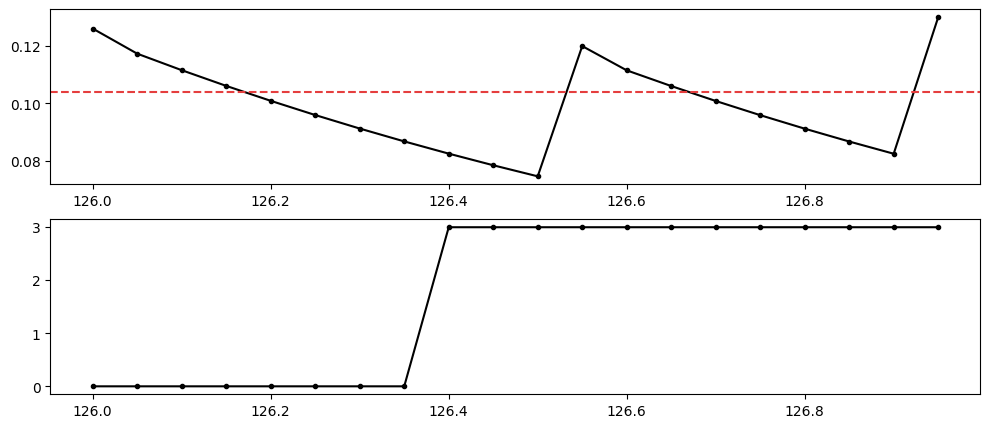

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5))

seq_start = 2520
# seq_end = task_params['n_steps_stabilize']
seq_end = 2540

ax1.plot(timeaxis[seq_start:seq_end], outputs[seq_start:seq_end, cn_idx], color='k', marker='.')
ax1.axhline(task.threshold, color=c_vals[0], linestyle='dashed') # Plot the threshold

ax2.plot(timeaxis[seq_start:seq_end], task_states_idx[-1, seq_start:seq_end], color='k', marker='.')

##### Photostim Tests

In [ ]:
verbose = False
session_idx = 0

# Photostim parameters
task_params['photostim'] = 'every_session' # None, every_session
task_params['n_groups'] = 100 # Less groups than neurons, like experiment
task_params['neuron_fidelity_mode'] = 'ones' # ones, uniform_random, copy
task_params['max_fidelty'] = 0.25
task_params['n_repeats_per_group'] = 20

# No seed set internally, assumed to continue off of training seed setting
# Do this to av
np.random.seed(task_params.get('seed', 0))

output_vars_ps = ['output_ps', 'output_fl_ps', 'output_dff_ps', 'net_input_ps',
                  'net_photostim_input_ps',]

params, train_outputs_ps, net, task_ps = run_photostim(
    (task_params, train_params, net_params), output_vars=output_vars_ps,
    task=task, net=net, verbose=True
)

n_steps photostim: 24000
Running 20.0 mintues photostim (24000 steps)...
Perc. under cutoff: 0.36


Showing neurons: [12 38  6]


Text(0.5, 0, 'Time (s)')

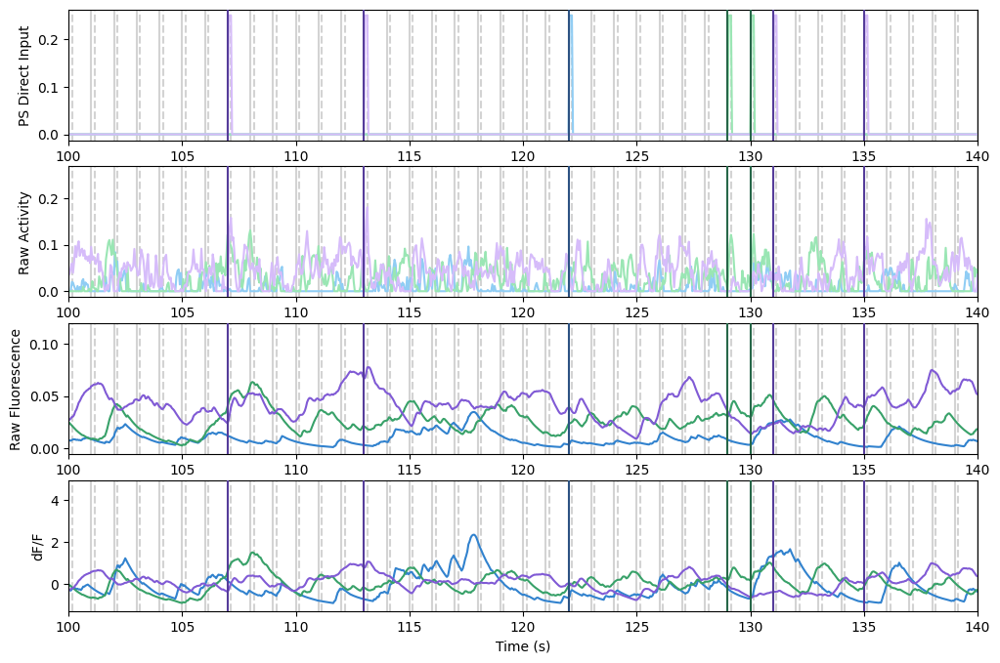

In [ ]:
session_idx = 0
n_neurons_plot = 3
neuron_idxs = np.random.choice(task_params['n_neurons'], n_neurons_plot)
print('Showing neurons:', neuron_idxs)

# fig1, axs = plt.subplots(n_neurons_plot, 1, figsize=(12, 2*n_neurons_plot))
fig2, (ax0, ax1, ax2, ax3) = plt.subplots(4, 1, figsize=(12, 8))

task_ps_hist = task_ps.hists[session_idx]
t_photostim = np.arange(task_ps.n_steps_photostim) * task_ps.dt

for neuron_idx_idx, neuron_idx in enumerate(neuron_idxs):
    # axs[neuron_idx_idx].plot(t_photostim, train_outputs_ps['output_ps'][:, neuron_idx], color=c_vals_l[neuron_idx_idx], zorder=-1)

    ax0.plot(t_photostim, train_outputs_ps['net_photostim_input_ps'][:, neuron_idx], color=c_vals_l[1+neuron_idx_idx], zorder=0)
    ax1.plot(t_photostim, train_outputs_ps['output_ps'][:, neuron_idx], color=c_vals_l[1+neuron_idx_idx], zorder=-1)
    ax2.plot(t_photostim, train_outputs_ps['output_fl_ps'][:, neuron_idx], color=c_vals[1+neuron_idx_idx], zorder=0)
    ax3.plot(t_photostim, train_outputs_ps['output_dff_ps'][:, neuron_idx], color=c_vals[1+neuron_idx_idx], zorder=0)

for ax in (ax0, ax1, ax2, ax3):
    for stim_start, group_idx in zip(task_ps_hist['stim_starts'], task_ps_hist['stim_group_idxs']):
        plot_color = 'lightgrey'
        plot_zorder = -5
        for neuron_idx_idx, neuron_idx in enumerate(neuron_idxs):
            if neuron_idx in task_ps.groups[group_idx]:
                plot_color=c_vals_d[1+neuron_idx_idx]
                plot_zorder = 10
        ax.axvline(stim_start * task_ps.dt, color=plot_color, zorder=plot_zorder)
    for stim_end in task_ps_hist['stim_ends']:
        ax.axvline(stim_end * task_ps.dt, color='lightgrey', zorder=-5, linestyle='dashed')

    ax.set_xlim((100, 140))

# for ax in (ax1, ax2,):
# for ax in (ax1, ax2, *axs):

ax0.set_ylabel('PS Direct Input')
ax1.set_ylabel('Raw Activity')
ax2.set_ylabel('Raw Fluorescence')
ax3.set_ylabel('dF/F')
ax3.set_xlabel('Time (s)')

Stim starts 961 end 960
Times within group: 47.9 (std: 20.7)
Times outside group: 910.1 (std: 20.7)


/usr/local/lib/python3.10/dist-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


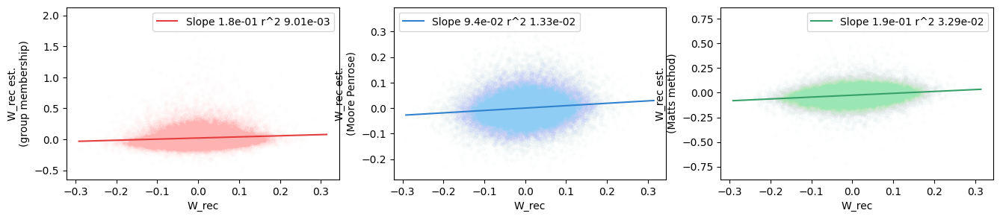

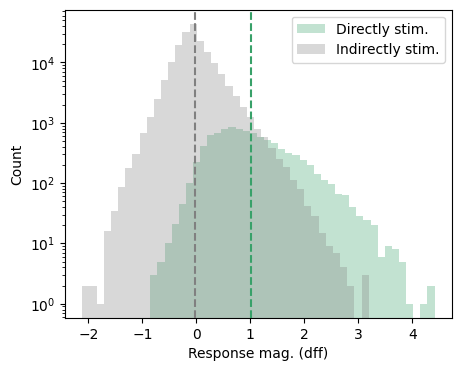

In [ ]:
omit_ps_times = True # True matches experiment, False matches Matt's setup
ps_activity_type = 'dff' # raw_activity, raw_fl, dff

causal_connectivity, group_activity, neuron_ps_responses = bci_analysis.get_photostim_results(
    train_outputs_ps, params, ps_activity_type=ps_activity_type, session_idx=0,
    omit_ps_times=omit_ps_times, verbose=True,
)
group_inputs, group_responses, group_pre_responses = group_activity
within_group_resp_mag, outside_group_resp_mag = neuron_ps_responses

implied_connectivity1 = bci_analysis.compute_causal_connectivity_neurons(causal_connectivity, train_outputs_ps, params, mode=1)
implied_connectivity2 = bci_analysis.compute_causal_connectivity_neurons(causal_connectivity, train_outputs_ps, params, mode=2)
implied_connectivity3 = bci_analysis.compute_causal_connectivity_neurons(causal_connectivity, train_outputs_ps, params, mode=3)

W_rec = np.copy(net.W_rec)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 3))
fig2, ax4 = plt.subplots(1, 1, figsize=(5, 4))

ax1.scatter(W_rec.flatten(), implied_connectivity1.flatten(), marker='.', alpha=0.01,
            color=c_vals_l[0])
add_regression_line(W_rec.flatten(), implied_connectivity1.flatten(), ax=ax1, color=c_vals[0], zorder=5)
ax2.scatter(W_rec.flatten(), implied_connectivity2.flatten(), marker='.', alpha=0.01,
            color=c_vals_l[1])
add_regression_line(W_rec.flatten(), implied_connectivity2.flatten(), ax=ax2, color=c_vals[1], zorder=5)
ax3.scatter(W_rec.flatten(), implied_connectivity3.flatten(), marker='.', alpha=0.01,
            color=c_vals_l[2])
add_regression_line(W_rec.flatten(), implied_connectivity3.flatten(), ax=ax3, color=c_vals[2], zorder=5)

for ax in (ax1, ax2, ax3):
    ax.legend()
    ax.set_xlabel('W_rec')

ax1.set_ylabel('W_rec est.\n(group membership)')
ax2.set_ylabel('W_rec est.\n(Moore Penrose)')
ax3.set_ylabel('W_rec est.\n(Matts method)')

within_group_resp_mag_flat = within_group_resp_mag.flatten()
within_group_resp_mag_flat = within_group_resp_mag_flat[~np.isnan(within_group_resp_mag_flat)] # Remove nans
outside_group_resp_mag_flat = outside_group_resp_mag.flatten()
outside_group_resp_mag_flat = outside_group_resp_mag_flat[~np.isnan(outside_group_resp_mag_flat)] # Remove nans

_ = ax4.hist(within_group_resp_mag_flat, bins=40, color=c_vals[2], alpha=0.3, label='Directly stim.')
ax4.axvline(np.mean(within_group_resp_mag_flat), color=c_vals[2], zorder=5, linestyle='dashed')
_ = ax4.hist(outside_group_resp_mag_flat, bins=40, color='grey', alpha=0.3, label='Indirectly stim.')
ax4.axvline(np.mean(outside_group_resp_mag_flat), color='grey', zorder=5, linestyle='dashed')

ax4.set_xlabel('Response mag. ({})'.format(ps_activity_type))
ax4.set_ylabel('Count')
ax4.set_yscale('log')
ax4.legend()

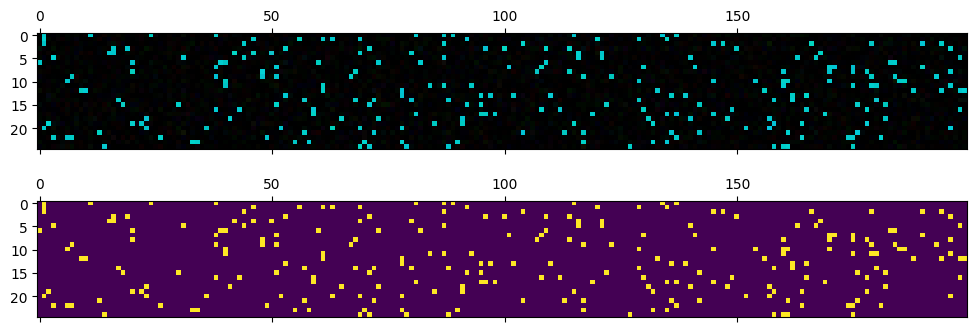

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4))
ax1.matshow(group_inputs)
groups_onehot = np.zeros((task_ps.n_groups, task_ps.n_neurons,))
for group_idx in range(task_ps.n_groups):
    groups_onehot[group_idx, task_ps.groups[group_idx]] = 1.0
ax2.matshow(groups_onehot)

Some tests that can be run after training to evaluate change in W_rec from change in photostim

Perc. under cutoff: 0.33
Stim starts 961 end 960
Times within group: 47.9 (std: 22.4)
Times outside group: 910.1 (std: 22.4)
Perc. under cutoff: 0.34
Stim starts 961 end 960
Times within group: 47.9 (std: 22.4)
Times outside group: 910.1 (std: 22.4)


Text(0.5, 0.98, 'Inferred connectivity mode: Moore-Penrose')

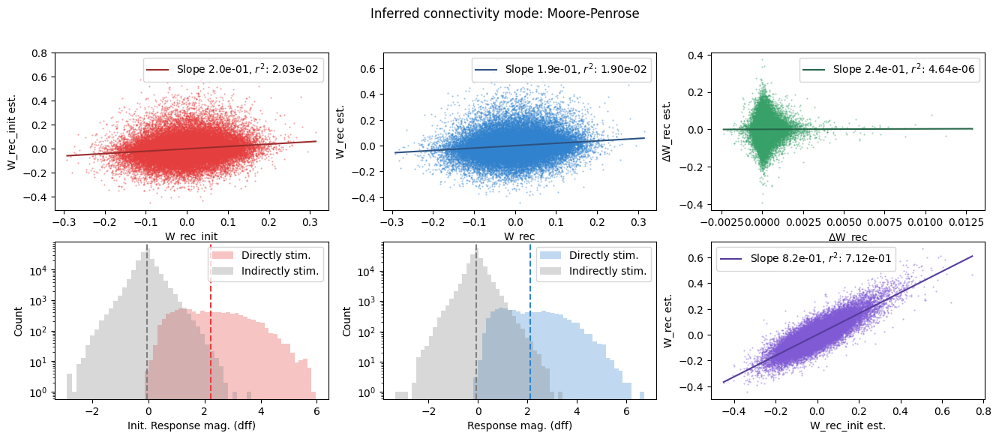

In [ ]:
session_idx = 0
omit_ps_times = True # True matches experiment, False matches Matt's setup
ps_activity_type = 'dff' # raw_activity, raw_fl, dff
causal_connectivity_mode = 2 # 1, 2, 3
if causal_connectivity_mode == 3:
    mode_name = 'Matts method'
elif causal_connectivity_mode == 2:
    mode_name = 'Moore-Penrose'

W_rec_init = train_outputs_all[session_idx]['W_rec_vals'][0]
W_rec =train_outputs_all[session_idx]['W_rec_vals'][-1]
delta_W_rec =  train_outputs_all[session_idx]['delta_W_rec']

delta_causal_connectivity = bci_analysis.compute_delta_causal_connectivity()

fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(16, 6))

ax1.scatter(W_rec_init.flatten(), implied_connectivity_init.flatten(), marker='.', alpha=0.5,
            color=c_vals[0], s=1)
add_regression_line(W_rec_init.flatten(), implied_connectivity_init.flatten(), ax=ax1, color=c_vals_d[0], zorder=5)
ax2.scatter(W_rec.flatten(), implied_connectivity.flatten(), marker='.', alpha=0.5,
            color=c_vals[1], s=1)
add_regression_line(W_rec.flatten(), implied_connectivity.flatten(), ax=ax2, color=c_vals_d[1], zorder=5)
ax3.scatter(delta_W_rec.flatten(), delta_implied_connectivity.flatten(), marker='.', alpha=0.5,
            color=c_vals[2], s=1)
if np.max(np.abs(delta_W_rec.flatten())) > 0.0: # Avoid this when delta_W_rec doesnt change
    add_regression_line(delta_W_rec.flatten(), delta_implied_connectivity.flatten(), ax=ax3, color=c_vals_d[2], zorder=5)
ax6.scatter(implied_connectivity_init.flatten(), implied_connectivity.flatten(), marker='.', alpha=0.5,
            color=c_vals[3], s=1)
add_regression_line(implied_connectivity_init.flatten(), implied_connectivity.flatten(), ax=ax6, color=c_vals_d[3], zorder=5)
# ax3.scatter(delta_W_rec.flatten()[delta_W_rec.flatten() > 0.0025], delta_implied_connectivity.flatten()[delta_W_rec.flatten() > 0.0025], marker='.', alpha=1.0,
#             color=c_vals_l[2])


for c_idx, ax, ps_responses in zip((0, 1), (ax4, ax5), (neuron_ps_responses_init, neuron_ps_responses)):
    within_group_resp_mag, outside_group_resp_mag = ps_responses
    within_group_resp_mag_flat = within_group_resp_mag.flatten()
    within_group_resp_mag_flat = within_group_resp_mag_flat[~np.isnan(within_group_resp_mag_flat)] # Remove nans
    outside_group_resp_mag_flat = outside_group_resp_mag.flatten()
    outside_group_resp_mag_flat = outside_group_resp_mag_flat[~np.isnan(outside_group_resp_mag_flat)] # Remove nans

    _ = ax.hist(within_group_resp_mag_flat, bins=40, color=c_vals[c_idx], alpha=0.3, label='Directly stim.')
    ax.axvline(np.mean(within_group_resp_mag_flat), color=c_vals[c_idx], zorder=5, linestyle='dashed')
    _ = ax.hist(outside_group_resp_mag_flat, bins=40, color='grey', alpha=0.3, label='Indirectly stim.')
    ax.axvline(np.mean(outside_group_resp_mag_flat), color='grey', zorder=5, linestyle='dashed')

    ax.set_ylabel('Count')
    ax.set_yscale('log')

for ax in (ax1, ax2, ax3, ax4, ax5, ax6):
    ax.legend()

ax1.set_xlabel('W_rec_init')
ax1.set_ylabel('W_rec_init est.')
ax2.set_xlabel('W_rec')
ax2.set_ylabel('W_rec est.')
ax3.set_xlabel('$\Delta$W_rec')
ax3.set_ylabel('$\Delta$W_rec est.')
ax4.set_xlabel('Init. Response mag. ({})'.format(ps_activity_type))
ax5.set_xlabel('Response mag. ({})'.format(ps_activity_type))
ax6.set_xlabel('W_rec_init est.')
ax6.set_ylabel('W_rec est.')

fig.suptitle('Inferred connectivity mode: {}'.format(mode_name))

In [ ]:
train_outputs = train_outputs_all[0]

train_outputs_ps_init = train_outputs['train_outputs_ps_init']
train_outputs_ps = train_outputs['train_outputs_ps']

print(np.mean(train_outputs_ps_init['output_ps'], axis=0)[:3])
print(np.mean(train_outputs_ps['output_ps'], axis=0)[:3])

[0.0118444  0.01634202 0.01842146]
[0.01344724 0.01502007 0.01756582]


#### Trial Structure Task (e.g. Center-out)

In [6]:
import copy

class TrialStructureTask():
    """
    Generates a basic trial-structure task.
    """

    def __init__(self, task_params, net_params):
        """
        Set defaults based on task_params (only needs net_params to get
        act_fn_type to generate appropriate inputs).
        """

        self.n_steps_trial = task_params.get('n_steps_trial', 100)
        self.trial_type = task_params.get('trial_type', 'high_stim') # high_stim, high_low_stim, center_out_1d, center_out_2d,

        self.n_neurons = task_params.get('n_neurons')
        self.n_bci_masks = task_params.get('n_bci_masks', 1) # Overriden for certain tasks
        self.task_scale = task_params.get('task_scale', 0.1)
        # Relative size of stim and noise (similar to signal to noise).
        # Note noise is always passed through W_inp, so can change with direct input
        # >1: Larger stim compared to noise
        # <1: Larger noise comapred to stim
        self.stim_to_noise_ratio = task_params.get('stim_to_noise_ratio', 1.0)

        self.reward_scale = task_params.get('reward scale', 0.025) # Overriden below for certain tasks

        # Way to more directly control stimulus signal where it doesn't need to pass through random matrix anymore
        self.net_direct_input = task_params.get('direct_input', False)
        if self.net_direct_input:
            self.net_W_inp = task_params.get('W_inp')

        self.act_fn_type = net_params.get('act_fn_type', 'ReTanh')

        if self.trial_type in ('high_stim', 'high_low_stim',):
            assert self.n_bci_masks == 1
            self.n_stim = 2
            # All these are filled after difficulty is set
            self.stim_targets = np.zeros((self.n_stim, self.n_bci_masks,))
            self.stim_widths = np.zeros((self.n_stim, self.n_bci_masks,))
            self.stim_reward_scales = np.zeros((self.n_stim, self.n_bci_masks,))

            self.n_trial_periods = self.n_stim # Trial periods defined by number of distinct stimuli
            self.get_trial_fn = self.activity_stim_trial
            self.set_task_difficulty_fn = self.activity_stim_set_task_difficulty
            self.reward_fn = trapezoid_reward
            self.stim_input = np.zeros((self.n_stim, self.n_neurons,))
            self.stim_input[0:1, :] = self.stim_to_noise_ratio * get_stimulus(task_params)
            self.stim_input[1:2, :] = self.stim_to_noise_ratio * get_stimulus(task_params)
            if self.trial_type in ('high_stim',):
                self.trial_period_percs = 1.0 * np.ones((self.n_trial_periods,)) # Highest in both
            elif self.trial_type in ('high_low_stim',):
                assert self.n_trial_periods == 2 # Doesn't make sense for more than two currently
                self.trial_period_percs = np.array((1.0, 0.)) # Highest in first, lwoest in second
                self.reward_smoothing = False # Can sometimes lead to runaway rewards because crosses zero
        elif self.trial_type in ('center_out_1d', 'center_out_1d_1', 'center_out_2d', 'center_out_2d_8',):

            self.n_trial_periods = 1 # Each trial is just a different stim
            self.stim_sample_mode = 'pseudo-random' # pseudo-random, random
            self.possible_stim_idxs = [] # Only used for pseudo-random option
            self.get_trial_fn = self.variable_stim_trial
            self.set_task_difficulty_fn = self.stim_target_set_task_difficulty
            # self.reward_fn = quadratic_reward
            self.reward_fn = center_out_reward
            self.reward_scale = np.sqrt(2) # Sets this to something on order of typical distances in BCI space

            if self.trial_type in ('center_out_1d',): # 1d BCI space, 2 targets
                self.n_bci_masks = 1
                self.n_stim = 2
                self.stim_targets = np.zeros((self.n_stim, self.n_bci_masks,)) # Used to set intrinsic mapping
                self.stim_targets[0, 0] = 1.
                self.stim_targets[1, 0] = -1.
            elif self.trial_type in ('center_out_1d_1',): # 1d BCI space, 1 target
                self.n_bci_masks = 1
                self.n_stim = 1
                self.stim_targets = np.zeros((self.n_stim, self.n_bci_masks,))
                self.stim_targets[0, 0] = 1.
            elif self.trial_type in ('center_out_2d',): # 2d BCI space, 4 targets
                self.n_bci_masks = 2
                self.n_stim = 4
                self.stim_targets = np.zeros((self.n_stim, self.n_bci_masks,))
                self.stim_targets[0, :] = np.array((1., 0.))
                self.stim_targets[1, :] = np.array((0., 1.))
                self.stim_targets[2, :] = np.array((-1., 0.))
                self.stim_targets[3, :] = np.array((0., -1.))
            elif self.trial_type in ('center_out_2d_8',): # 2d BCI space, 8 targets
                self.n_bci_masks = 2
                self.n_stim = 8
                self.stim_targets = np.zeros((self.n_stim, self.n_bci_masks,))
                self.stim_targets[0, :] = np.array((1., 0.))
                self.stim_targets[1, :] = 1/np.sqrt(2) * np.array((1., 1.))
                self.stim_targets[2, :] = np.array((0., 1.))
                self.stim_targets[3, :] = 1/np.sqrt(2) * np.array((-1., 1.))
                self.stim_targets[4, :] = np.array((-1., 0.))
                self.stim_targets[5, :] = 1/np.sqrt(2) * np.array((-1., -1.))
                self.stim_targets[6, :] = np.array((0., -1.))
                self.stim_targets[7, :] = 1/np.sqrt(2) * np.array((1., -1.))

            self.stim_widths = None # This doesn't use a reward function with width
            self.stim_reward_scales = np.zeros((self.n_stim, self.n_bci_masks,))

            if not np.all(np.abs(np.linalg.norm(self.stim_targets, axis=-1) - 1) < 1e-3):
                raise NotImplementedError(
                    'Center-out reward function assumes targets have magnitude 1!!'
                )

            self.stim_input = np.zeros((self.n_stim, self.n_neurons,))
            for stim_idx in range(self.n_stim): # Generate stimuli corresponding to distinct inputs
                # The size of this determines how much stimuli dominate activity
                if self.stim_to_noise_ratio < 1.0: # Ensures maximum scale of stim and noise is roughly task_scale
                    stim_mult = self.stim_to_noise_ratio # Reduces stim relative to noise
                else:
                    stim_mult = 1.0 # Reduces noise relative to stim
                # print('Setting stim_mult to:', stim_mult)
                # self.stim_input[stim_idx:stim_idx+1, :] = stim_mult * get_stimulus(task_params)
                self.stim_input[stim_idx:stim_idx+1, :] =  get_stimulus_special(task_params, stim_idx, self.n_stim, 'sparse_binary')
        else:
            raise ValueError('Trial type {} not recognized.'.format(self.trial_type))

        ### Masking conditions for context switching ###
        # Determines number of steps at beginning of a new stim to not count
        # in presession activity for scaling task difficulty
        self.n_steps_tol = task_params.get('n_steps_tol', 20)

        ## NaN reward conditions (equivalent to zero RPE) ##
        # Determines number of steps at beginning of a new trial to return nans
        self.n_steps_trial_start_nans = task_params.get('n_steps_trial_start_nans', 0)
        # Determines number of steps at beginning of a new stim to return nans
        # (since for some task types, stims can change mid-trial, distinct from above)
        self.n_steps_stim_change_nans = task_params.get('n_steps_stim_change_nans', 0)

        # Used to smooth rewards to compensate for maximum speed a network activity could change
        self.reward_smoothing = task_params.get('reward_smoothing', True)
        self.net_leak_term = task_params.get('net_leak_term', 0.8)

        ### Tracked parameters ###
        self.trial_onsets = []
        self.trial_period_onsets = [[] for _ in range(self.n_trial_periods)]

    def activity_stim_trial(self, trial_override=False):
        """
        Generate a single activity_stim trial. For distinct stimuli, requires the
        activity meet distinct levels under distinct stimuli, but all levels
        are high relative to what was seen before.

        Each trial consists of two periods, which go through periods in the same
        order each time. Thus each trial is identical other than the noise.
        """

        if trial_override:
            raise NotImplementedError()

        # Seq idx is always relative to start of trial
        half_trial_idx = int(np.round(self.n_steps_trial / 2))

        stims = np.zeros((self.n_steps_trial, self.n_neurons))
        stims[:half_trial_idx, :] = stims[:half_trial_idx, :] + self.stim_input[0:1, :]
        stims[half_trial_idx:, :] = stims[half_trial_idx:, :] + self.stim_input[1:2, :]
        input = self.get_noise_input(self.n_steps_trial, stims=stims)

        # bci_targets = 0.5 * self.task_scale * np.ones((self.n_steps_trial,))
        # bci_targets[half_trial_idx:, :] = 0.0
        # bci_targets[half_trial_idx:] = 0.25 * self.task_scale

        trial_stims = np.zeros((self.n_steps_trial,), dtype=np.int32)
        trial_stims[half_trial_idx:] = 1
        trial_period_onsets = (0, half_trial_idx)

        return input, trial_stims, trial_period_onsets

    def variable_stim_trial(self, trial_override=False):
        """
        Generate a single variable_stim_trial. Each trial randomly determines
        one distinct n_stim. Each trial only has one period, but trials can
        be distinct (from stim_idx and noise).
        """

        if trial_override: # Same stim every single trial
            stim_idx = 0
        elif self.stim_sample_mode in ('random',):
            stim_idx = np.random.choice(self.n_stim)
        elif self.stim_sample_mode in ('pseudo-random',): # Choose randomly from existing list or generate new list
            if self.possible_stim_idxs == []: # Empty condition
                self.possible_stim_idxs = [idx for idx in range(self.n_stim)]

            list_idx = np.random.randint(len(self.possible_stim_idxs))
            stim_idx = self.possible_stim_idxs[list_idx]
            self.possible_stim_idxs.pop(list_idx) # Delete the stim idx

        stims = np.ones((self.n_steps_trial, 1,)) * self.stim_input[stim_idx:stim_idx+1, :]
        input = self.get_noise_input(self.n_steps_trial, stims=stims)

        trial_stims = stim_idx * np.ones((self.n_steps_trial,), dtype=np.int32)

        trial_period_onsets = (0,)

        return input, trial_stims, trial_period_onsets

    def separate_activity_into_stims(self, activities_stabilize, task_params,
                                     seq_start_idx=0, reject_criterion='nan_mask'):
        """
        Separates activity into activity observed during distinct stims
        Used for pre-session activity to set difficulty and/or BCI mask,
        i.e. the inutitive mapping. Also used for analysis of how responses
        of each stimulus change during training.

        Returns both activity and corresponding sequence indexes. Latter useful
        for post-train analysis to further filter/separate activity.
        """

        seq_len = activities_stabilize.shape[0]

        activities_stabilize_stims = [[] for _ in range(self.n_stim)]
        seq_idxs_stabilize_stims = [[] for _ in range(self.n_stim)]

        current_stim_idx = None
        n_steps_in_stim = None

        # Goes through each seq_idx time, rejects times immediately following a transition.
        # Note this can be optionally offset by passing a nonzero seq_start_idx,
        # but this offset needs to be removed when referencing the passed activity
        for seq_idx in range(seq_start_idx, seq_len + seq_start_idx):
            trial_stim_idx = self.trial_stims[seq_idx]

            if reject_criterion in ('n_steps_tol',): # Old way of filtering
                if current_stim_idx is None: # Initialization
                    current_stim_idx = np.copy(trial_stim_idx)
                    n_steps_in_stim = 1
                else:
                    if current_stim_idx == trial_stim_idx: # Same state
                        n_steps_in_stim += 1
                    else: # New state
                        current_stim_idx = np.copy(trial_stim_idx)
                        n_steps_in_stim = 1

                if n_steps_in_stim <= self.n_steps_tol:
                    continue
            elif reject_criterion in ('nan_mask',): # Just use nan mask to filter, similar to experiment
                if self.nan_mask[seq_idx]:
                    continue
            else:
                raise ValueError()

            activities_stabilize_stims[trial_stim_idx].append(activities_stabilize[seq_idx - seq_start_idx])
            seq_idxs_stabilize_stims[trial_stim_idx].append(seq_idx)

        for trial_stim_idx in range(self.n_stim): # Converts each stim into numpy arrays
            activities_stabilize_stims[trial_stim_idx] = np.array(
                activities_stabilize_stims[trial_stim_idx]
            )

        return activities_stabilize_stims, seq_idxs_stabilize_stims

    def set_sequence_reward_parameters(self):
        """
        Set BCI targets based on stimulus of each step. Requires that the
        targets, reward scales, and (optionally) widths already be defined for
        the different stimuli.

        Option to smoothly interpolate based on max speed of the network's
        activity change
        """

        n_steps = self.input.shape[0]
        # self.nan_mask is initialized in generate_input_sequence since its easier to set trial-dependent parameters there
        self.bci_targets = np.zeros((n_steps, self.n_bci_masks,))
        self.bci_reward_scales = np.zeros((n_steps, self.n_bci_masks,))
        if self.reward_fn == trapezoid_reward:
            self.bci_widths = np.zeros((n_steps, self.n_bci_masks,))
        else:
            self.bci_widths = None

        if self.reward_smoothing:
            leak_term = self.net_leak_term
        else:
            leak_term = 0.

        current_stim_idx = None
        n_steps_in_stim = None

        for seq_idx in range(n_steps):
            stim_idx = self.trial_stims[seq_idx]
            if seq_idx == 0:
                prev_threshold = 0.
                prev_reward_scale = 1e-3 # For stability
            else:
                prev_threshold = self.bci_targets[seq_idx-1]
                prev_reward_scale = self.bci_reward_scales[seq_idx-1]

            self.bci_targets[seq_idx] = (
                leak_term * prev_threshold + (1 - leak_term) * self.stim_targets[stim_idx]
            )
            self.bci_reward_scales[seq_idx] = (
                leak_term * prev_reward_scale + (1 - leak_term) *  self.stim_reward_scales[stim_idx]
            )
            if self.bci_widths is not None:
                if seq_idx == 0:
                    prev_width = 0.
                else:
                    prev_width = self.bci_widths[seq_idx-1]
                self.bci_widths[seq_idx] = (
                    leak_term * prev_width + (1 - leak_term) * self.stim_widths[stim_idx]
                )

            if np.sum(np.abs(self.bci_reward_scales[seq_idx])) < 1e-3: # Stability condition
                self.bci_reward_scales[seq_idx, :] = 1e-3

            if current_stim_idx is None: # Initialization
                current_stim_idx = np.copy(stim_idx)
                n_steps_in_stim = 1
            else:
                if current_stim_idx == stim_idx: # Same state
                    n_steps_in_stim += 1
                else: # New state
                    current_stim_idx = np.copy(stim_idx)
                    n_steps_in_stim = 1

            if n_steps_in_stim < self.n_steps_stim_change_nans:
                self.nan_mask[seq_idx] = 1

    def activity_stim_set_task_difficulty(self, activities_stabilize, task_params):
        """
        Sets the task difficulty in a task that requires meeting a certain BCI
        activity level under distinct stimuli. The difficulty level is set
        dynamically based on stabilization activity.

        First, goes through stabilization stim activities and separates into
        distinct stims. Then for each distinct stim, sets the difficulty
        scale independent of the other stims, based on the desired percentiles.
        Then optionally smoothes the desired targets (thresholds).
        """

        seq_len = activities_stabilize.shape[0]

        ### Separates pre-session activity into distinct stims (seq_idxs dont matter)
        activities_stabilize_stims, _ = self.separate_activity_into_stims(
            activities_stabilize, task_params
        )

        ### For each distinct stim, computes activity scale to determine task difficulty
        for stim_idx in range(self.n_trial_stims):

            print('--- Stim idx {}, activity shape:'.format(stim_idx), activities_stabilize_stims[stim_idx].shape, '---')

            print('Mean: {:.3f}'.format(np.mean(activities_stabilize_stims[stim_idx])))

            # Creates a local version of task_params to modify
            task_params_copy = copy.deepcopy(task_params)
            task_params_copy['dyn_threshold_perc'] = self.trial_stim_percs[stim_idx]

            threshold, width, reward_scale, print_str, extras = set_thresholds_and_scales(
                activities_stabilize_stims[stim_idx], task_params_copy, task=self,
            )

            self.stim_targets[stim_idx, 0] = threshold
            self.stim_widths[stim_idx, 0] = width
            self.stim_reward_scales[stim_idx, 0] = reward_scale

        self.max_activity = 2 * max(self.stim_targets) + max(self.stim_widths) # This may not be used

        # Now set BCI targets based on trial stim of each step
        self.set_sequence_reward_parameters()

    def stim_target_set_task_difficulty(self, activities_stabilize, task_params):
        """
        Sets the task difficulty in a task that requires meeting a certain BCI
        activity level under distinct stimuli. The difficulty level is fixed by
        the targets.
        """

        seq_len = activities_stabilize.shape[0]

        ### Separates pre-session activity into distinct stims (seq_idxs dont matter)
        activities_stabilize_stims, _ = self.separate_activity_into_stims(
            activities_stabilize, task_params
        )

        ### For each distinct stim, sets reward scale to determine task difficulty
        for stim_idx in range(self.n_stim):
            # For now just set scale to initialized value
            self.stim_reward_scales[stim_idx, :] = self.reward_scale * np.ones((self.n_bci_masks,))

        self.max_activity = 0.3

        # Now set BCI targets based on trial stim of each step
        self.set_sequence_reward_parameters()

    def get_noise_input(self, n_steps, stims=None):
        """ Creates a noisy input with optional stimulus. """

        if stims is None:
            stims = np.zeros((n_steps, self.n_neurons,))

        if self.stim_to_noise_ratio < 1.0: # Ensures maximum scale of stim and noise is roughly task_scale
            noise_mult = 1.0 # Reduces stim relative to noise
        else:
            noise_mult = 1.0 / self.stim_to_noise_ratio # Reduces noise relative to stim
        # print('Setting noise_mult to:', noise_mult)
        raw_input = noise_mult * np.random.normal(scale=self.task_scale, size=(n_steps, self.n_neurons,))

        if self.net_direct_input: # Passes noise through excluded input layer for comparable noise distribution
            # Make noise positive (can still have inhibitory effect via W_input components)
            if self.act_fn_type in ('Tanh'):
                raw_input = np.maximum(raw_input, np.zeros_like(raw_input))
            elif self.act_fn_type in ('ReTanh'):
                raw_input = np.maximum(np.tanh(raw_input), np.zeros_like(raw_input))
            else:
                raise NotImplementedError('act_fn_type {} not yet implemented'.format(self.act_fn_type))

            # Note this is NOT passed through non-linearity, since it functions as
            # an input to into the hidden layer which has a non-linearity
            raw_input = np.matmul(raw_input, self.net_W_inp.T)

            return raw_input + stims
        else: # Stim and noise added, passed through non-linearity, then passed through W_input externally
            if self.act_fn_type in ('Tanh'): # Make noise positive
                return np.maximum(raw_input + stims, np.zeros_like(raw_input))
            elif self.act_fn_type in ('ReTanh'):
                return np.maximum(np.tanh(raw_input), np.zeros_like(raw_input))
            else:
                raise NotImplementedError('act_fn_type {} not yet implemented'.format(self.act_fn_type))

    def generate_input_sequence(self, n_steps):
        """
        Generate the full train sequences and targets. Does this by generating
        one trial at a time using appropriate target function then appends
        everything together.

        Generates self.input and self.trial_stims and save internally. Note this
        does not genreate self.bci_targets yet because these are set after task
        difficulty is set, which often requires running pre-session period to
        observe intial activity.
        """

        n_trials = int(np.round(n_steps / self.n_steps_trial))

        # Hardcoded override to produce some test sequences for debugging
        # Currently makes it so each trial is the same, just to see if learning
        # is possible without stimulus variation
        db_mode = False
        db_start_idx = 6000

        if n_steps % self.n_steps_trial != 0:
            raise NotImplementedError('Last trial wil be clipped, change n_steps to multiple of n_steps_trial')

        self.input = np.zeros((n_steps, self.n_neurons))
        self.bci_targets = None # These are set after task difficulty is set
        self.trial_stims = np.zeros((n_steps,), dtype=np.int32)

        self.nan_mask = np.zeros((n_steps,), dtype=np.int32) # When reward should just be NaN

        current_seq_idx = 0

        for trial_idx in range(n_trials):

            if db_mode and current_seq_idx >= db_start_idx:
                trial_override = True
            else:
                trial_override = False

            trial_input, trial_stims, trial_period_onsets = self.get_trial_fn(trial_override)

            self.input[current_seq_idx:current_seq_idx + self.n_steps_trial, :] = trial_input
            # self.bci_targets[current_seq_idx:current_seq_idx + self.n_steps_trial] = trial_activity_targets
            self.trial_stims[current_seq_idx:current_seq_idx + self.n_steps_trial] = trial_stims

            self.trial_onsets.append(current_seq_idx)
            for period_idx in range(self.n_trial_periods):
                self.trial_period_onsets[period_idx].append(current_seq_idx + trial_period_onsets[period_idx])

            if self.n_steps_trial_start_nans > 0:
                self.nan_mask[current_seq_idx:current_seq_idx + self.n_steps_trial_start_nans] = 1

            current_seq_idx += self.n_steps_trial

        return self.input

    def get_reward(self, activity, task_params, seq_idx):
        """
        activity.shape = (n_neurons,)
        bci_masks.shape = (n_bci_masks, n_neurons,)

        """

        if self.nan_mask[seq_idx]:
            return np.nan

        if self.bci_widths is None: # Some reward functions don't use width
            bci_width = None
        else:
            bci_width = self.bci_widths[seq_idx]

        bci_activity = get_bci_activity(activity, task_params) # (n_bci_masks)

        total_reward = self.reward_fn(
            bci_activity, self.bci_targets[seq_idx], bci_width,
            self.bci_reward_scales[seq_idx], self.task_scale
        )

        return total_reward

def get_perturbation_center_out(
        task_params, perm_mode, task=None, max_perts=2e6, n_perts_at_once=1e5,
        pass_criterion={
                'max_angle': 50., # 44.4 # In degrees
                'min_angle': 12., # 19.7
                'max_speed': 3, # AU, target speeds have speed 1
                'min_speed': 0.3,
        },
        tolerance = 0.0, n_perm_dims=60,
        return_all_perts=False, compute_rewards=False, verbose=False
    ):
    """
    Retrieves a BCI masks perturbation that meets the required criterion.
    Evaluates perturbations based on task_params['mean_act_stims'], which is
    computed at the end of the stabilization period.

    perm_mode:
    - wm: shuffles top axes within manifold space (determined by PR)
    - wm_n_top: shuffles top axes, determined by n_perm_dims
    - om_raw: shuffles neuron indices
    - om_top_stds: only shuffles neurons with top standard deviations during
      stabilization period
    - om_top_stim_stds: only shuffles neurons with top standard deviations
      across the various stimulus types
    task: only needed if compute_rewards = True
    max_perts: maximum number of perturbations to consider
    n_perts_at_once: how many perts to evaluate at once
    n_perm_dims: number of dimensions to permute, used for wm_n_top,
      om_top_stds, and om_top_stim_stds
    """

    def compute_bci_masks_diff_center_out(bci_masks_perm, task_params, task):
        """
        Evaluates stimulus velocity and relative angles of many permutation
        simultaneously.

        INPUTS:
        bci_masks_perm.shape = (n_perm, n_bci_masks, n_perm_space)

        OUTPUTS:
        speeds.shape (n_perm, n_stims)
        """

        # if task_params['manifold_project'] is not None:
        #     raise NotImplementedError('Mean act stims are in manifold space.')

        # (n_perm, n_bci_masks, n_neurons) x (n_neurons, n_stims) =  (n_perm, n_bci_masks, n_stims)
        # Recall mean_act_stims already include the z-scoring and manifold projection if on
        if task_params['bci_choice'] in ('intuitive_manifold',) and perm_mode in ('wm', 'wm_n_top',):
            # Well-defined manifold, mean_act_stims need to be projected to manifold space first
            mean_bci_act_stims = np.matmul(bci_masks_perm, np.matmul(
                task_params['manifold_project'], task_params['mean_act_stims'].T
            ))
        else:
            mean_bci_act_stims = np.matmul(bci_masks_perm, task_params['mean_act_stims'].T)

        # (n_perm, n_bci_masks, n_stims) -> (n_perm, n_stims)
        speeds = np.linalg.norm(mean_bci_act_stims, axis=1)

        # if task_params['bci_choice'] in ('intuitive_manifold',) and perm_mode in ('wm', 'wm_n_top',):
        #     # Well-defined manifold, mean_act_stims fit to manifold space not full space
        #     intuitive_velocities = np.matmul(task_params['bci_masks_manifold'], task_params['mean_act_stims'].T)
        # else:
        # (n_bci_masks, n_neurons) x (n_neurons, n_stims) =  (n_bci_masks, n_stims) -> (n_bci_masks, n_stims)
        intuitive_velocities = np.matmul(task_params['bci_masks'], task_params['mean_act_stims'].T)

        dots = np.einsum('piI, iI -> pI', mean_bci_act_stims, intuitive_velocities) # (n_perm, n_stims)
        cosine_angles = dots / (
            np.linalg.norm(intuitive_velocities, axis=0)[np.newaxis, :] * # (1, n_stims)
            np.linalg.norm(mean_bci_act_stims, axis=1) # (n_perm, n_stims)
        )

        if compute_rewards: # This is slow because in for loop, at some point might want to matrix-ify it
            rewards = np.zeros_like(speeds) # (n_perm, n_stims)
            dists = np.zeros_like(speeds)
            for perm_idx in range(rewards.shape[0]):
                for stim_idx in range(rewards.shape[-1]):
                    target = task.stim_targets[stim_idx]
                    rewards[perm_idx, stim_idx] = task.reward_fn(
                        mean_bci_act_stims[perm_idx, :, stim_idx], target, None,
                        task.stim_reward_scales[stim_idx], task.task_scale
                    )
                    dists[perm_idx, stim_idx] = center_out_distance(
                        mean_bci_act_stims[perm_idx, :, stim_idx], target, None,
                        task.stim_reward_scales[stim_idx], task.task_scale
                    )
                    # if perm_idx == 119 and stim_idx == 0:
                    #     print('Target:', target)
                    #     print('Mean act stim', mean_bci_act_stims[perm_idx, :, stim_idx])
                    #     print('Reward scale:', task.stim_reward_scales[stim_idx])
                    #     print('task scale:', task.task_scale)
        else:
            rewards = None
            dists = None

        return speeds, cosine_angles, rewards, dists

    bci_masks = task_params['bci_masks']
    n_neurons = bci_masks.shape[-1]
    mean_act_stims = task_params['mean_act_stims']

    # Used for some types of perturbations to set size of perturbation space
    pr_val = participation_ratio_vector(task_params['manifold_axes_var_exps'])
    pr_val = int(np.ceil(pr_val))

    bci_masks_pert_return = None
    total_perts_eval = 0
    current_min_dist = 1e5 # just a large number
    # Used to keep track of best perturbation so far
    best_pert_so_far = None
    best_speeds_so_far = None
    best_cas_so_far = None

    start_time = time.time()

    while total_perts_eval < max_perts: # Runs n_perts_at_once perturbation evals

        start_time_local = time.time()

        print_str = 'Perturbation type {} search'.format(perm_mode)

        ### Permute the (n_bci_masks, n_perm_space) elements, the same for each mask
        # n_perm_space is determined by the type of shuffle
        if perm_mode in ('om_raw',): # Shuffle over neuron indexes
            bci_masks_perm_space = bci_masks # Just the raw BCI masks (shuffle neurons)
        elif perm_mode in ('om_top_stds', 'om_top_stim_stds',): # Projects to subspace containing neurons with highest standard deviation
            # Note this projection just determines which neurons to include,
            # so only has has 1.0 elements in projection matrix
            if perm_mode in ('om_top_stds',):
                stds_stort = np.argsort(task_params['activity_stds'])[::-1] # Largest to smallest
            elif perm_mode in ('om_top_stim_stds',):
                stds_stort = np.argsort(np.std(task_params['mean_act_stims'], axis=0))[::-1] # Largest to smallest
            print_str += f' (n_permuted neurons: {n_perm_dims})'
            top_stds_proj = np.zeros((n_perm_dims, n_neurons,))
            for std_idx in range(n_perm_dims):
                top_stds_proj[std_idx, stds_stort[std_idx]] = 1.0
            top_stds_mask = np.sum(top_stds_proj, axis=0)
            bci_masks_perm_space = np.matmul(bci_masks, top_stds_proj.T)
        elif perm_mode in ('wm', 'wm_n_top',): # Project BCI masks to top few PC space
            if task_params['bci_choice'] in ('intuitive_manifold',): # Manifold projection well defined
                if perm_mode in ('wm_n_top',):
                    raise NotImplementedError('Manifold has been defined earlier, cant override.')
                print_str += ' (n_permuted set by manifold projection: {})'.format(task_params['manifold_project'].shape[0])
                bci_masks_perm_space = task_params['bci_masks_manifold']
            else: # No well-defined manifold
                if perm_mode in ('wm',):
                    n_dims_manifold = pr_val
                elif perm_mode in ('wm_n_top',):
                    n_dims_manifold = n_perm_dims
                print_str += f' (n_permuted dims manifold: {n_dims_manifold})'
                bci_masks_perm_space = np.matmul(bci_masks, task_params['manifold_axes'][:n_dims_manifold].T)
        else:
            raise NotImplementedError('Perm mode {} not recognized.'.format(perm_mode))
        print(print_str)

        shuffle_idxs = np.arange(bci_masks_perm_space.shape[-1])

        bci_masks_perm = np.repeat(bci_masks_perm_space[np.newaxis, :, :], n_perts_at_once, axis=0)
        bci_masks_perm_idxs = np.repeat(shuffle_idxs[np.newaxis, :], n_perts_at_once, axis=0)

        # rng = np.random.default_rng(seed = task_params['seed'] + total_perts_eval) # Change seed each runthrough
        rng = np.random.default_rng(seed = int(task_params['seed'] + total_perts_eval)) # Change seed each runthrough
        bci_masks_perm_idxs = rng.permuted(bci_masks_perm_idxs, axis=-1)

        for bci_mask_idx in range(bci_masks.shape[0]):
            bci_masks_perm[:, bci_mask_idx, :] = np.take_along_axis(
                bci_masks_perm[:, bci_mask_idx, :], bci_masks_perm_idxs, axis=-1
            )

        if perm_mode in ('om_raw',): # No need to project back
            bci_masks_pert = bci_masks_perm
        elif perm_mode in ('om_top_stds', 'om_top_stim_stds',): # Projects out of subspace comtaining neurons with highest standard deviation, copies rest
            bci_masks_pert_top_stds = np.matmul(bci_masks_perm, top_stds_proj) # BCI from just the shuffled space
            bci_masks_repeat = np.repeat(bci_masks[np.newaxis, :, :], n_perts_at_once, axis=0) # All other BCI

            bci_masks_pert = bci_masks_pert_top_stds + (1 - top_stds_mask) * bci_masks_repeat
        elif perm_mode in ('wm', 'wm_n_top',):  # Project back into full space
            if task_params['bci_choice'] in ('intuitive_manifold',): # Well-defined manifold
                bci_masks_pert = bci_masks_perm # Stimulus fits done directly in the manifold space
            else: # No well-defined manifold
                bci_masks_pert = np.matmul(bci_masks_perm, task_params['manifold_axes'][:n_dims_manifold])

        speeds, cosine_angles, rewards, dists = compute_bci_masks_diff_center_out(
            bci_masks_pert, task_params, task
        )

        # # Now evaluate the four conditions across all the stimuli
        # min_speed_pass = np.all(np.where(speeds > pass_criterion['min_speed'], True, False), axis=-1)
        # max_speed_pass = np.all(np.where(speeds < pass_criterion['max_speed'], True, False), axis=-1)

        # max_cosine_angle = np.cos(pass_criterion['min_angle'] * (np.pi / 180)) # Smaller angles -> larger cosine angles
        # min_cosine_angle = np.cos(pass_criterion['max_angle'] * (np.pi / 180)) # Larger angles -> smaller cosine angles

        # min_cosine_angle_pass = np.all(np.where(cosine_angles > min_cosine_angle, True, False), axis=-1)
        # max_cosine_angle_pass = np.all(np.where(cosine_angles < max_cosine_angle, True, False), axis=-1)

        # # Combine all conditions into one giant array
        # full_pass = np.concatenate((
        #     min_speed_pass[np.newaxis, :],
        #     max_speed_pass[np.newaxis, :],
        #     min_cosine_angle_pass[np.newaxis, :],
        #     max_cosine_angle_pass[np.newaxis, :],
        # ), axis=0)

        # n_passes = np.sum(np.all(full_pass, axis=0))

        # Now evaluate distance to all four conditions across all the stimuli

        to_min_speed = pass_criterion['min_speed'] - speeds # Negative passes
        min_speed_dist = np.where(to_min_speed > 0, to_min_speed, 0.)
        to_max_speed = speeds - pass_criterion['max_speed'] # Negative passes
        max_speed_dist = np.where(to_max_speed > 0, to_max_speed, 0.)
        total_speed_dist = np.sum(min_speed_dist + max_speed_dist, axis=-1) / (pass_criterion['max_speed'] - pass_criterion['min_speed'])

        max_cosine_angle = np.cos(pass_criterion['min_angle'] * (np.pi / 180)) # Smaller angles -> larger cosine angles
        min_cosine_angle = np.cos(pass_criterion['max_angle'] * (np.pi / 180)) # Larger angles -> smaller cosine angles

        to_min_ca = min_cosine_angle - cosine_angles # Negative passes
        min_ca_dist = np.where(to_min_ca > 0, to_min_ca, 0.)
        to_max_ca = cosine_angles - max_cosine_angle # Negative passes
        max_ca_dist = np.where(to_max_ca > 0, to_max_ca, 0.)
        total_ca_dist = np.sum(min_ca_dist + max_ca_dist, axis=-1) / (max_cosine_angle - min_cosine_angle)

        # Combine both conditions into a single number
        full_pass = total_speed_dist + total_ca_dist

        # n_passes = np.sum(full_pass == 0.)
        n_passes = np.sum(full_pass <= tolerance)

        if n_passes > 0:
            if verbose:
                print(' {} valid perturbations found! (time {:.2f})'.format(
                    n_passes, time.time() - start_time_local
                ))
            # pert_idx = np.where(np.all(full_pass, axis=0))[0][0] # Just get the first valid one, everything is random anyway
            pert_idx = np.where(full_pass <= tolerance)[0][0] # Just get the first valid one, everything is random anyway
            print('Pert idx: {}'.format(pert_idx))
            print(' speeds:', ['{:.2f}'.format(speed) for speed in speeds[pert_idx]])
            print(' angles:', ['{:.1f}'.format(angle) for angle in 180 / np.pi * np.arccos(cosine_angles[pert_idx])])
            if task_params['bci_choice'] in ('intuitive_manifold',) and perm_mode in ('wm', 'wm_n_top',):
                # Project perturbed mask to full space
                bci_masks_pert_return = np.matmul(bci_masks_pert[pert_idx], task_params['manifold_project'])
            else:
                bci_masks_pert_return = bci_masks_pert[pert_idx]
            break
        else: # While it fails to find a perturbation, keep track of the one that is closest to passing
            local_min_dist = min(full_pass)
            if local_min_dist < current_min_dist:
                current_min_dist = np.copy(local_min_dist)
                pert_idx = np.where(full_pass == current_min_dist)[0][0]
                if task_params['bci_choice'] in ('intuitive_manifold',) and perm_mode in ('wm', 'wm_n_top',):
                    # Project perturbed mask to full space
                    best_pert_so_far = np.matmul(bci_masks_pert[pert_idx], task_params['manifold_project'])
                else:
                    best_pert_so_far = bci_masks_pert[pert_idx]
                best_speeds_so_far = speeds[pert_idx]
                best_cas_so_far = cosine_angles[pert_idx]

            total_perts_eval += n_perts_at_once
            if verbose:
                print(' No passes found, min dist: {:.3f}, running again (time {:.2f}).'.format(
                    min(full_pass), time.time() - start_time_local
                ))

    if bci_masks_pert_return is not None:
        if verbose:
            print('Valid perturbation found, total time: {:.2f} seconds.'.format(
                time.time() - start_time
            ))
    else:
        print('No valid perturbation found in maximum number of iterations!')
        print('Best found over search:')
        print(' speeds:', ['{:.2f}'.format(speed) for speed in best_speeds_so_far])
        print(' angles:', ['{:.1f}'.format(angle) for angle in 180 / np.pi * np.arccos(best_cas_so_far)])

    extras = {
        'speeds': speeds, # Note these will only be for the most recent set of perturbations
        'cosine_angles': cosine_angles,
        'rewards': rewards,
        'dists': dists, # Special center-out distance to target
        'best_pert_so_far': best_pert_so_far,
        'best_speeds_so_far': best_speeds_so_far,
        'best_cas_so_far': best_cas_so_far,
        'min_speed': pass_criterion['min_speed'],
        'max_speed': pass_criterion['max_speed'],
        'min_ca': min_cosine_angle,
        'max_ca': max_cosine_angle,
    }

    if return_all_perts:
        if task_params['bci_choice'] in ('intuitive_manifold',) and perm_mode in ('wm', 'wm_n_top',):
            # Project perturbed mask to full space
            extras['bci_masks_pert'] = np.matmul(bci_masks_pert, task_params['manifold_project'])
        else:
            extras['bci_masks_pert'] = bci_masks_pert
        extras['pass_criterion'] = full_pass

    return bci_masks_pert_return, extras

def get_stimulus_special(task_params, stim_idx, n_stim, stim_type='uniform'):
    """
    Generates stimulus inputs for tasks that have many stimuli.

    Stimulus inputs are various random matrices.
    """
    if 'n_inp' in task_params: # Defaults to number of inputs
        n_neurons = task_params['n_inp']
    elif 'n_neurons' in task_params:
        n_neurons = task_params['n_neurons']
    else:
        raise NotImplementedError('Unknown stimulus size')

    assert n_neurons % n_stim == 0 # Needs to be nicely divisible
    n_per_stim = int(np.round(n_neurons / n_stim)) # Number of neurons per stimulus

    stim = np.zeros((1, n_neurons,))

    if stim_type in ('uniform',):
        stim[:, stim_idx*n_per_stim:(stim_idx+1)*n_per_stim] = np.random.uniform(
            -1 * task_params['task_scale'], 1 * task_params['task_scale'], size=(1, n_per_stim,)
        )
        return stim
    elif stim_type in ('sparse_binary',):
        p = 0.2
        stim = task_params['task_scale'] * (np.random.rand(1, n_neurons) < p).astype(int)
        return stim
    elif stim_type in ('normal',):
        raise NotImplementedError()

(1800, 200)
(1800, 200)
(1800, 200)
(1800, 200)
Cross-stim dots [[0.63190253 0.10359916 0.21750283 0.10774   ]
 [0.10359916 0.82791514 0.31973831 0.22237797]
 [0.21750283 0.31973831 1.         0.26611803]
 [0.10774    0.22237797 0.26611803 0.85170463]]
 Mean diag: 0.83
 Mean off-diag: 0.21


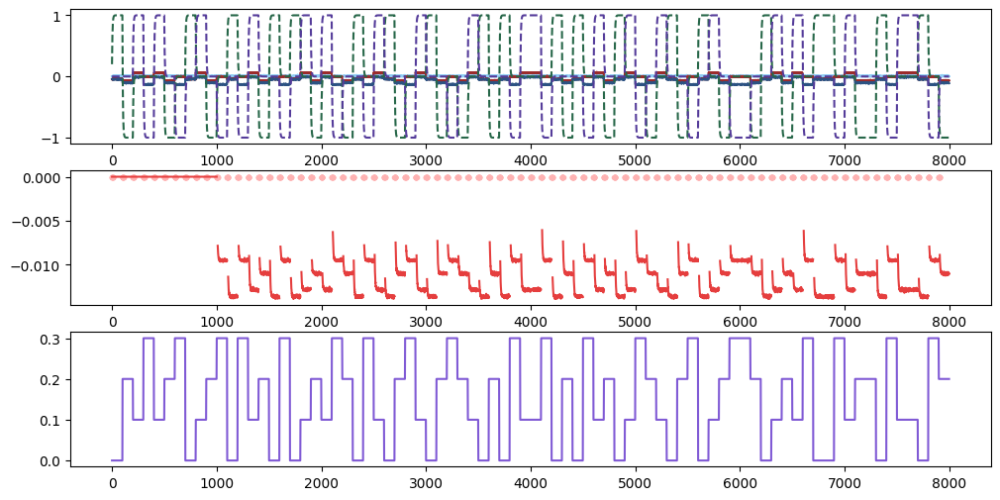

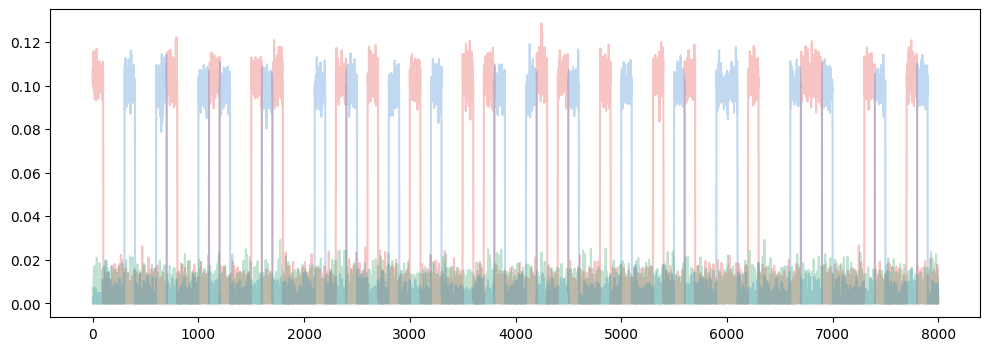

In [7]:
seed = 2002
np.random.seed(seed)

task_params = {}
task_params['n_neurons'] = 200
task_params['n_steps'] = 8000
task_params['n_steps_stabilize'] = 1000
task_params['task_scale'] = 0.1
task_params['task_type'] = 'trial_structure_task'
task_params['trial_type'] = 'center_out_2d' # high_stim, high_low_stim, center_out_1d, center_out_1d_1, center_out_2d, center_out_2d_8
task_params['n_steps_trial'] = 100
task_params['n_steps_stim_change_nans'] = 10
task_params['n_steps_trial_start_nans'] = 10

task_params['z_score_activities'] = False
task_params['dyn_threshold_type'] = 'percentile_bci_activity'
task_params['dyn_threshold_perc'] = 1.0
task_params['normalize_reward'] = False
task_params['net_leak_term'] = 0.8
task_params['direct_input'] = True
task_params['stim_to_noise_ratio'] = 10.0 #1.0/0.3
n_neurons = task_params['n_neurons']
W_rand = np.random.normal(0, 1 / np.sqrt(n_neurons), size=(n_neurons, n_neurons,))

net_params = {'act_fn_type': 'ReTanh',}

if task_params['direct_input']:
    task_params['W_inp'] = np.copy(W_rand)

task = TrialStructureTask(task_params, net_params)
net_inputs = task.generate_input_sequence(task_params['n_steps'])

assert ~np.isnan(net_inputs).any()

if task_params['direct_input']:
    activity = np.maximum(net_inputs, np.zeros_like(net_inputs))
else:
    activity = np.maximum(np.matmul(net_inputs, W_rand), np.zeros_like(net_inputs))
# bci_mask = np.zeros((1, n_neurons,))
# bci_mask[0, 0] = 1.0
bci_masks = np.random.uniform(high=1.0, low=-1.0, size=(task.n_bci_masks, n_neurons,))
bci_masks = bci_masks / np.linalg.norm(bci_masks, axis=-1, keepdims=True)

task_params['bci_masks'] = bci_masks
task_params['activity_subtract'] = np.zeros((task_params['n_neurons'],))
rewards = np.zeros((task_params['n_steps'],))

for seq_idx in range(task_params['n_steps']):

    if seq_idx == task_params['n_steps_stabilize']:
        if task.set_task_difficulty_fn is not None:
            task.set_task_difficulty_fn(activity[:1000], task_params)
    elif seq_idx > task_params['n_steps_stabilize']:
        rewards[seq_idx] = task.get_reward(activity[seq_idx], task_params, seq_idx)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 6))

for bci_mask_idx in range(task.n_bci_masks):
    ax1.plot(np.matmul(activity, bci_masks.T)[:, bci_mask_idx], color=c_vals_d[bci_mask_idx])

    ax1.plot(task.bci_targets[:, bci_mask_idx], color=c_vals_d[2 + bci_mask_idx], linestyle='dashed', zorder=5)
    if task.bci_widths is not None:
        ax1.plot(task.bci_targets[:, bci_mask_idx] + task.bci_widths[:, bci_mask_idx], color=c_vals_d[2], linestyle='dashed', zorder=5)

ax1.plot(activity[:, 2], color=c_vals_l[1], zorder=-5)

nan_steps = np.arange(task.nan_mask.shape[0])[task.nan_mask == 1]

ax2.plot(rewards, color=c_vals[0])
ax2.scatter(nan_steps, np.zeros_like(nan_steps), color=c_vals_l[0], marker='.')
ax3.plot(0.1 * task.trial_stims, color=c_vals[3])

# for ax in (ax1, ax2, ax3):
    # ax.set_xlim((0, 1000))
    # ax.set_xlim((1000, 2000))

# Plot some activity too
fig2, ax4 = plt.subplots(1, 1, figsize=(12, 4))

for neuron_idx in range(3):
    ax4.plot(activity[:, neuron_idx], color=c_vals[neuron_idx], alpha=0.3)

# To compare these on equal footing, need to compute what the input would be for non-direct
if task_params['direct_input']:
    # stim_activity, _ = task.separate_activity_into_stims(net_inputs, task_params)
    stim_activity, _ = task.separate_activity_into_stims(activity, task_params)
else:
    # stim_activity, _ = task.separate_activity_into_stims(
    #     np.matmul(net_inputs, W_rand), task_params
    # )
    stim_activity, _ = task.separate_activity_into_stims(activity, task_params)
mean_stim_activity = np.zeros((task.n_stim, n_neurons,))

for stim_idx in range(len(stim_activity)):
    print(stim_activity[stim_idx].shape)
    mean_stim_activity[stim_idx] = np.mean(stim_activity[stim_idx], axis=0)

stim_dots = np.matmul(mean_stim_activity, mean_stim_activity.T)
norm_dots = stim_dots / np.max(np.abs(stim_dots))
print('Cross-stim dots', norm_dots)
print(' Mean diag: {:.2f}'.format(np.trace(norm_dots) / task.n_stim))
print(' Mean off-diag: {:.2f}'.format((np.sum(norm_dots) - np.trace(norm_dots)) / (task.n_stim**2 - task.n_stim)))

# period_activity, _ = task.separate_activity_into_stims(activity, task_params)
# mean_act = np.zeros((4, task_params['n_neurons']))
# for stim_idx in range(4):
#     print(stim_activity[stim_idx].shape)

#     mean_act[stim_idx, :] = np.mean(stim_activity[stim_idx], axis=0)

# print(np.linalg.inv(np.matmul(mean_act.T, mean_act)))

In [8]:
from sklearn.decomposition import FactorAnalysis

n_components = 10

session_idx = 0
outputs = train_outputs_all[session_idx]['output'][:task_params['n_steps_stabilize']]
task_params, train_params, net_params = params

# Testing out FA
my_fa = FactorAnalysis(n_components=n_components, random_state=task_params['seed'])
my_fa.fit(outputs)

outputs_fa = my_fa.transform(outputs)

print(outputs_fa.shape)

outputs_center = outputs - np.mean(outputs, axis=0, keepdims=True)
Wpsi = my_fa.components_ / my_fa.noise_variance_
quick_invert = np.matmul(np.linalg.inv(
    np.eye(n_components) + np.dot(Wpsi, my_fa.components_.T)
), Wpsi)


# Wpsi = my_fa.components_ / my_fa.noise_variance_
# tmp = np.dot(outputs_center, Wpsi.T) # (n_stabilize, n_neurons) x (n_neurons, n_components) -> (n_stabilize, n_components)
# outputs_fa_test = np.dot(tmp, np.linalg.inv(np.eye(n_components) + np.dot(Wpsi, my_fa.components_.T)))  # (n_components, n_components)

outputs_fa_test = np.matmul(outputs_center, quick_invert.T)

quick_invert2 = np.matmul(my_fa.components_, np.linalg.inv(
    np.diag(my_fa.noise_variance_) + np.matmul(my_fa.components_.T, my_fa.components_)
))
outputs_fa_test2 = np.matmul(outputs_center, quick_invert2.T)

print(outputs_fa[:3, :3])
print(outputs_fa_test[:3, :3])
print(outputs_fa_test2[:3, :3])

NameError: name 'train_outputs_all' is not defined

##### Default Pert Params

In [ ]:
def set_pert_defaults(task_params, train_params, net_params):
    """
    Default parameters for the perturbation task
    """

    local_task_params = {

        ### Task choice
        'task_type': 'trial_structure_task', # (should already be set to this, just to be explicit)
        ## Trial_structure task parameters
            'trial_type': 'center_out_2d', # high_stim, high_low_stim, center_out_1d, center_out_1d_1, center_out_2d, 'center_out_2d_8'
            'stim_to_noise_ratio': 1.0/0.3, # 0.25
            'n_steps_trial': 200, # 200 is about 10 seconds; 500,
            'n_steps_period_change_nans': 40, # 100
            'n_steps_trial_start_nans': 40, #  grace

        'z_score_activities': True, # z-scores activities based on pre-session, does this before BCI map and for manifold calculation

        ### BCI mask choice (threshold/width used to set spout movement threshold/max speed)
        'bci_choice': 'intuitive_manifold',
        ## Parameters for various bci_choice settings
            'n_bci_masks': 2,
            'manifold_mode': 'pc', # pc, fa; whether to use PCA or FA to determine the low-dimensional manifold

        ### Session length parameters
        'n_steps': 50000, #5200,
        'n_steps_stabilize': 5000, #1000, #500,

        ### Reward-relevant parameters
        'normalize_reward': True, # Makes value of rewards depend on median and threshold during presession
        'n_reward_delay': 0, # Number of time steps to delay the current reward
        'separate_stim_reward_baselines': True, # Different reward baseline for each distinct stimulus

        'task_scale': 0.1, # Determines the scale of the noise input and also the constant input when used

        'n_sessions': 1,
        'use_max_activity': False, # Clip activity at maximum, helps stabilize training with recurrent adjustment

        'solution_type': None, # Not yet implemented
        # 'perturbations': None,
        'perturbations': ( # To test BCI mask perturbations
            (8000, 'center_out', {'perm_mode': 'om_raw', # wm, wm_n_top, om_raw, om_top_stds, om_top_stim_stds
                                  'n_perm_dims': 100,}),
            (42000, 'center_out', {'perm_mode': 'intuitive',
                                  'n_perm_dims': 60,}),
        )


# task_params['z_score_activities'] = False
# task_params['dyn_threshold_type'] = 'percentile_bci_activity'
# task_params['dyn_threshold_perc'] = 1.0
# task_params['normalize_reward'] = False
# task_params['net_leak_term'] = 0.8
# task_params['direct_input'] = True
# task_params['stim_to_noise_ratio'] = 10.0 #1.0/0.3
    }

    local_train_params = {
        'eta': 2e0,
        'n_window_reward': 10 * 20, #60 * 20, # Size of the average window for reward baseline
        'n_window_baseline': 1 * 20, # Size of the average window for activity
        'n_steps_per_loss': 5, # How often to total RPE and adjust weights
        'eligibility_acc_type': 'running_average', # acc_and_wipe, running_average
        'n_window_elig': 40, # Only used for 'running_average' option, how long to keep eligibility

        'rpe_clip': 0.05,
    }

    local_net_params = {
        'direct_input': True, # More directly control over stimulus signal where it doesn't need to pass through random matrix anymore
        'weight_mask_modes': None, # None or tuple with: cn_freeze, cn_only, cn_no_output
    }

    local_task_params['direct_input'] = local_net_params['direct_input']

    for local_key in local_task_params.keys():
        task_params[local_key] = local_task_params[local_key]
    for local_key in local_train_params.keys():
        train_params[local_key] = local_train_params[local_key]
    for local_key in local_net_params.keys():
        net_params[local_key] = local_net_params[local_key]

    return task_params, train_params, net_params

### Train one network

In [23]:
import time

run = True # Set to False if you just want to initialize the functions here
minimal = False # Additional outputs that can take up a fair amount of memory, only relevant if run=True
train = True # Only relevant if run=True
save_run = False # Save entire run
save_sessions = False # Save every session
save_path = '/content/drive/MyDrive/neuro_research/BCI/saved_nets/test_plots_'

seed = 2013 # 2014 # 2011

def default_toy_params(seed=0, verbose=False):

    task_params = {
        ### Task choice
        # - simple_bci: just change bci activity, no trial structure
        # - our_bci: Special task setup to reproduce our BCI task
        # - trial_structure_task: various trial-structure based tasks (including WMP/OMP setup)
        'task_type': 'our_bci',

        'z_score_activities': False, # z-scores activities based on pre-session, does this before BCI map and for manifold calculation

        ### BCI mask choice (parameters that need to be specified)
        # - random: random CN choices (n_cns, n_bci_masks)
        # - activity_percentile: choice closest to desired activity percentile (n_cns, n_bci_masks, activity_percentile)
        # - activity_high: random choice within percentile (n_cns, n_bci_masks, activity_percentile)
        # - manifold: BCI mask is one of the manifold dims (manifold_mode, manifold_idx, n_bci_masks)
        # - intuitive: BCI masks chosen to best solve task
        # - intuitive_maifold: Same as above, but based on low-dim manifold activity
        'bci_choice': 'activity_high',
        ## Parameters for various bci_choice settings
            'n_bci_masks': 1,
            'activity_percentile': 0.7, # For activity_percentile and activity_high, determines CN percentile.
            'n_cns': 1, # Used for settings where number of CNs for a single mask is variable
            'manifold_mode': 'pc', # pc, fa; whether to use PCA or FA to determine the low-dimensional manifold
            'manifold_idx': 25, # For manfiold settings, determines what idx is the mask (lower = higher var exp)
            'constant_stim_input': False, # Add constant stim to this task (otherwise just zeros, needed for odd activations)
        ### What to set the threshold based on: percentile_bci_activity, bci_activity_mean_and_std, fixed_neural_distance
        'dyn_threshold_type': 'bci_activity_mean_and_std',
        ## Parameters for various threshold choices
            'dyn_threshold_perc': 0.9, #0.9, # Sets threshold to be at certain percentile of activity (only used for perc_ above)
            'dyn_width_perc': None,
            'n_stds': 2.0, # for 'bci_activity_mean_and_std' option
            'threshold_distance': 0.05, # for 'fixed_neural_distance' option

        ### Session length parameters
        't_step':  50, # ms, only needed to define fluorescence in some tasks
        'n_steps': 6000, #10000, # 2500,
        'n_steps_stabilize': 2000, #1000, #500,
        'n_steps_evaluate': 0, # Stops training to observe solution

        ### Reward-relevant parameters
        'reward_structure': 'abs', # trapezoid, quadratic, abs
        'normalize_reward': True, # False, # Makes value of rewards depend on median and threshold during presession
        'n_reward_delay': 5, # Number of time steps to delay the current reward

        'task_scale': 0.1, # Determines the scale of the noise input and also the constant input when used
        'start_avg_reward': 'dynamic', # dynamic
        
        'n_sessions': 1,
        'use_max_activity': False, # Clip activity at maximum, helps stabilize training with recurrent adjustment

        'add_fl': False,

        'seed': seed,

        # Solution criteria
        'solution_type': 'avg_activity', # None, avg_activity
        'sol_n_steps': 20,
        'terminate_on_sol': False,

        ### Parameters used only for special tests ###
        
        'constant_rpe_val': None, # 0.025, # If anything other than None, RPE is held constant

        # Used to introduce additional correlation into activity
        'correlation_type': None, # None, activity, weights
        'on_idx': 20,
        'on_weight': 1.0,

        # Used to test how non-BCI components affect training
        'non_bci_deviation_zero': False,

        ## Perturbations to training
        # Step_idx to apply perturbation, preturbation type, perturbation params
        # 'perturbations': ( # To test BCI mask perturbations
        #     (2000, 'bci_masks_new_pc', {'pc_idx': 80}), # 10, 80
        #     (3000, 'bci_masks_new_pc', {'pc_idx': 2}),
        # )
        # 'perturbations': ( # To test BCI mask perturbations
        #     (6000, 'center_out', {'perm_mode': 'om_top_stim_stds', # wm, wm_n_top, om_raw, om_top_stds, om_top_stim_stds
        #                           'n_perm_dims': 100,}),
        #     (26000, 'center_out', {'perm_mode': 'intuitive',
        #                           'n_perm_dims': 60,}),
        # )

        ## Special training criterion
        # None, zero_cn_input, zero_cn_input_and_sparsify_rec, zero_cn_input_and_sparsify_rec_copy
        # zero_cn_input_and_sparsify_rec_copy_hold
        'special_test_type': None,
    }

    # Some defaults
    default_fills = {'bci_masks': None, 'activity_subtract': None, 'activity_stds': None,
                    'threshold': None, 'width': None, 'perturbations': None,
                    'dyn_width_perc': None, 'max_activity': None, 'photostim': None,
                    'special_test_type': None,
                    'start_avg_reward': None, 'z_score_activities': False,
                    'use_max_activity': False, 'add_fl': False, 'terminate_on_sol': False,
                    'separate_stim_reward_baselines': False, 'run_test_idxs': None,}
    for default_fill in default_fills.keys():
        if default_fill not in task_params: task_params[default_fill] = default_fills[default_fill]

    assert task_params['n_reward_delay'] >= 0. # Negative values don't make sense here

    train_params = {
        # 5e-1 works well for 3-factor toy task with abs reward
        # 50.0 works well for 3-factor toy task with quadratic
        'eta': 1e0, #5e0,
        'n_window_reward': 200, # Size of the average window for reward baseline
        'n_window_baseline': 50, #20, # Size of the average window for activity
        'n_steps_per_loss': 5, # How often to total RPE and adjust weights
        'eligibility_acc_type': 'running_average', # acc_and_wipe, running_average
        'n_window_elig': 5, # Only used for 'running_average' option, how long to keep eligibility

        'adjust_type': '3factor',
        # 3factor: our 3-factor, post dev * phi^prime * pre
        # backprop: same as our 3-factor, but full dh_dW including leak
        # backprop_two_step: same as our 3-factor, just one more step back for dh_dW
        # 3factor_leak: our 3-factor, but correctly calculates leak term contribution
        # 3factor_nophiprime: our 3-factor without phi^prime term (EH learning with postactivation)
        # 3factor_nodev: our 3-factor without post dev, just post * phi^prime * pre
        # 3factor_vanilla_hebbian: 3-factor with just the usual Hebbian, essentially equivalent to having both no phi prime and no deviation
        # 3factor_eh: True EH learning, use preactivations for postsynaptic activity
        # 3factor_miconi: Same rule used in Miconi
        # 3factor_miconi_insp: Same rule used in Miconi, but actually uses postsynaptic deviations
        # 3factor_node_pert: Node perturbation to postactivations (applies perturbations but still uses same RPE)
        # 3factor_node_pert_pre: Node perturbation to preactivations
        # 3factor_predevs: Deviation only in presyn
        # 3factor_two_devs: Deviation in post and presyn deviations
        # 3factor_sl: 3-factor supervised approximation, with knowledge of BCI mask
        # 3factor_sl_uniform: 3-factor supervised approximation, with no knowledge of BCI mask
        # backprop_sl: full dh_dW with knowlege of BCI mask
        
        # scalar or vector: scale of activity perturbations for 3factor_nope_pert training (if None, uses task_scale)
        'act_perturbation_scale': None, #0.05, 
        
        'rpe_clip': 0.05, # None, 0.1; maximum RPE (per step) magnitude, stabilizes training a bit

        'print_every': 100,
        'weight_reg': 'L2',
        'reg_lambda': 0., #1e-5, #1e-4,
    }

    net_params = {
        'n_inp': 200, # input layer
        'n_neurons': 200, # hidden layer

        'W_inp_type': 'gaussian', # gaussian, sparse_gaussian, log_normal
        'W_rec_type': 'gaussian',
        'W_inp_adjust': False,
        'W_rec_adjust': True,
        # 'W_rec_weight_norm': 0.0,

        'act_fn_type': 'ReTanh', # ReTanh, Tanh, ReLU, linear

        'weight_mask_modes': None, # None or tuple with: cn_freeze, cn_only, cn_no_output
        'W_inp_adjust_mask': None,
        'W_rec_adjust_mask': None,

        'direct_input': False, # For more control over input into hidden activity

        'leak_term': 0.8, # alpha, 0.0 means no leak
        'leak_type': 'membrane', # activity, membrane
    }

    task_params['n_stim'] = None
    task_params['net_leak_term'] = net_params['leak_term']
    task_params['direct_input'] = net_params['direct_input']

    if 'n_inp' not in net_params:
        net_params['n_inp'] = net_params['n_neurons']
    # Tasks need to know about these to create correct input sizes
    task_params['n_inp'] = net_params['n_inp']
    task_params['n_neurons'] = net_params['n_neurons']

    if task_params['task_type'] in ('our_bci',):
        if verbose: print('Overriding task_params with our BCI defaults.')
        task_params, train_params, net_params = set_to_our_bci_defaults(task_params, train_params, net_params)
        task_params['track_raw_states'] = True # Track some extra things for nice plots (like spout position)
    if task_params['task_type'] in ('trial_structure_task',):
        if verbose: print('Overriding task_params with our pertrubation defaults.')
        task_params, train_params, net_params = set_pert_defaults(task_params, train_params, net_params)

    if train_params['adjust_type'] in ('3factor_sl', '3factor_sl_uniform', 'backprop_sl',):
        print('INCREASING RPE CLIP FOR SL-LIKE LEARNING')
        train_params['rpe_clip'] = 1.0
    
    if task_params['add_fl'] and ('fl_kernel' not in task_params): # Initialization of fl kernel
        # print('Initializing fluorescence!')
        task_params = fluorescence_init(task_params)
        if task_params['task_type'] not in ('our_bci',):
            train_params['eta'] = 0.4 * train_params['eta'] # Compensate for lower standard deviation
            print(' FL: lowering learning rate by factor of 2/5: {:.1e} -> {:.1e}'.format(
                train_params['eta'] / 0.4, train_params['eta']
            ))

    return (task_params, train_params, net_params)

def train_task(params, output_vars=[], net=None, task=None, prev_seq_vars=None,
               train=True, n_steps=None, save_sessions=False, save_path='',
               verbose=True):
    """
    Run a network through a training sequence. This is setup to be run under
    several conditions including those where the network/task are generated
    internally but also ones where a network/task generated elsewhere is run
    through a sequence.

    INPUTS:
    - params = task_params, train_params, net_params
    - output_vars: list controlling what internal parameters are returned from
        training (some are returned regardless of contents of list)
    - net: if None, initializes new networks, otherwise uses passed network
    - task: the task environment, for some tasks there is no environment. For
        tasks with an environment, generates internally if None, otherwise uses
        passed task
    - prev_seq_vars: a bunch of internally tracked parameters over training. If None,
        generates internally, otherwise uses passed value
    - n_steps: Number of steps to train, if None just uses task_params value. Used for
        training test sessions that may be distinct from full task_params value.
        
    - save_sessions: save individual sessions within a run
    - save_path: only used here to save individual sessions, otherwise saved externally

    OUTPUTS:
    - train_outputs_all: giant dictionary with default ouputs along with "output_vars" input
    
    """

    task_params, train_params, net_params = params

    task_scale = task_params['task_scale'] # Determines the scale of the noise input and also the constant input when used

    # Set seed/state here, determines input noise (see below for additional seed sets)
    if net is not None:
        if net.rng_state is not None:
            np.random.set_state(net.rng_state)
    else:
        np.random.seed(task_params['seed'])

    train_outputs_all = []
    task_ps = None
    if n_steps is None: n_steps = task_params['n_steps']

    # Repeats everything for each session, just doesn't reset network and carries over certain baselines
    for session_idx in range(task_params['n_sessions']):

        # Dict will be populated throughout each individual session, then all
        # are collected in a list for output
        train_outputs = {}

        prev_activity = None # Overriden below if specifying the network's state (only do this if generating more activity)
        prev_activity_pre_act = None

        if net is not None: # Using a passed network
            if verbose: print('--- Session idx {}: Using passed network ---'.format(session_idx))
            if hasattr(net, 'prev_activity') and hasattr(net, 'prev_activity_pre_act'): # Initialize these if we want to set the state too
                prev_activity = net.prev_activity
                prev_activity_pre_act = net.prev_activity_pre_act
            if net_params['weight_mask_modes'] is not None:
                raise NotImplementedError()
        elif session_idx == 0: # Things set only in first session, unless an existing network is passed
            if verbose: print('--- Session idx {}: Initializing network ---'.format(session_idx))
            net = networks.SimpleRNN(net_params, task_params, train_params)
        else:
            raise ValueError('Net needs to be passed if this isnt the first session')

        # Initialize BCI-mask quantities if not yet determined
        if task_params['bci_masks'] is None:
            task_params['bci_var_exp'] = None
            task_params['cn_idxs'] = None
            
        task_params['W_inp'] = np.copy(net.W_inp) if net_params['direct_input'] else None  # task needs to know aobut W_inp in case it is being circumnavigated

        ### Initialize task and quantities to track throughout sequence run (whether training or not) ###
        # Also handles resetting for a new session, start step_idx can be nonzero if we are splitting training at a certain point
        task, start_step_idx, (
            net_input, output, output_pre_act, reward, avg_reward, avg_activity,
            avg_activity_pre_act, mean_stabilize_actvities, output_fl,
            bci_activity, avg_bci_activity, avg_reward_stims, 
            act_perturbations, preact_perturbations,
        ) = initialize_sequence_variables(task_params, net=net, task=task, prev_seq_vars=prev_seq_vars, n_steps=n_steps, verbose=verbose)
        
        # Quantities to determine if solution has been found, if used
        sol_n_steps = 0
        sol_step = None # Step solution was achieved

        ### Initialize training-relevant quantities, if relevant ###
        (loss_steps, total_rpes, W_inp_vals, W_rec_vals, W_inp_elg_vals,
         W_rec_elg_vals, act_fn_p_pre_act_vals) = initialize_sequence_variables_training(task_params, net, output_vars, train=train, verbose=verbose)

        task_params, train_params, net_params, net = set_special_test(
            task_params, train_params, net_params, net
        )

        # Initialize and run initial photostim (only do this when doing a single session)
        if task_params['n_sessions'] == 1 and task_params['photostim'] in ('every_session',):
            _, train_outputs_ps_init, _, task_ps = run_photostim(
                (task_params, train_params, net_params), output_vars=output_vars_ps,
                task=task, task_ps=task_ps, net=net, verbose=verbose
            )
            train_outputs['train_outputs_ps_init'] = train_outputs_ps_init

        # Now iterate through sequence times
        for step_idx in range(start_step_idx, n_steps):

            if step_idx == 0: # Initialization values for each session (these are not carried between sessions)
                if prev_activity is None and prev_activity_pre_act is None:
                    prev_activity = np.zeros((task_params['n_neurons'],))
                    prev_activity_pre_act = np.zeros((task_params['n_neurons'],))
                prev_reward = 0.
                prev_avg_activity = np.zeros((task_params['n_neurons'],))
                prev_avg_activity_pre_act = np.zeros((task_params['n_neurons'],))
                prev_avg_bci_activity = np.zeros((task_params['n_neurons'],))
                if avg_reward_stims is not None:
                    prev_reward_stims = np.zeros((task.n_stim,))
            else:
                prev_activity = output[step_idx-1]
                prev_activity_pre_act = output_pre_act[step_idx-1]
                prev_reward = avg_reward[step_idx-1] # Delay not needed here
                prev_avg_activity = avg_activity[step_idx-1]
                prev_avg_activity_pre_act = avg_activity_pre_act[step_idx-1]
                prev_avg_bci_activity = avg_bci_activity[step_idx-1]
                if avg_reward_stims is not None:
                    prev_reward_stims = avg_reward_stims[step_idx-1]

            if task_params['perturbations'] is not None:
                task_params, terminate_training = apply_bci_mask_perturbations(step_idx, task_params, verbose=verbose)
                if terminate_training: # If a valid perturbation is not found, sometimes breaks from training
                    break                

            # Network forward pass
            current_input = net_input[step_idx]
            current_act_perturbation = None if act_perturbations is None else act_perturbations[step_idx]
            current_preact_perturbation = None if preact_perturbations is None else preact_perturbations[step_idx]
            output[step_idx], output_pre_act[step_idx] = net.forward(
                current_input, prev_activity, prev_activity_pre_act, net_params, 
                perturbation=current_act_perturbation, perturbation_preact=current_preact_perturbation,
            )

            # Some ways that activity could be adjusted (special tests or clips)
            if 'max_activity' in task_params: # Clip total activity for numerical stability
                if task_params['max_activity'] is not None:
                    output[step_idx] = np.clip(output[step_idx], None, task_params['max_activity'])
                # if train_params['adjust_type'] in ('3factor_miconi',):
                #     print('Output activity being clipped, what about preact?')
            
            if task_params['correlation_type'] in ('activity',): # Correlate via direct activity change
                raise NotImplementedError('This was making code messier, since it requires on_idx it was further down. Update so it works here.')
                # output[step_idx, task_params['on_idx']] = (
                #     (1 - task_params['on_weight']) * output[step_idx, task_params['on_idx']] + task_params['on_weight'] * output[step_idx, cn_idx]
                # )
            if task_params['special_test_type'] in ('zero_cn_input_and_sparsify_rec_copy_hold',):
                raise NotImplementedError('This was making code messier, since it requires nonzero_rec_idxs it was further down. Update so it works here.')
                # # Holds one of the special neurons at its average activity
                # output[step_idx, task_params['nonzero_rec_idxs'][0]] = avg_activity[step_idx, task_params['nonzero_rec_idxs'][0]]

            if task_params['add_fl']: # Computed after activity adjustments
                n_steps_fl = np.minimum(step_idx, task_params['fl_kernel'].shape[0] - 1) # Only pass whats needed, -1 because inclusive of step_idx
                output_fl[step_idx] = fluorescence_convolution(output[step_idx - n_steps_fl:step_idx+1], task_params, last_only=True)

            avg_activity[step_idx] = accumulate_decay(prev_avg_activity, output[step_idx], n_window=train_params['n_window_baseline'])
            avg_activity_pre_act[step_idx] = accumulate_decay(prev_avg_activity_pre_act, output_pre_act[step_idx], n_window=train_params['n_window_baseline'])

            output_deviation = output[step_idx] - avg_activity[step_idx] # n_neurons
            output_preact_deviation = output_pre_act[step_idx] - avg_activity_pre_act[step_idx]
            act_fn_p_pre_act = net.act_fn_p(output_pre_act[step_idx])
            if 'act_fn_p_pre_act_vals' in output_vars and train: # For analyzing eligibility trace in more detail
                act_fn_p_pre_act_vals[step_idx] = np.copy(act_fn_p_pre_act)

            ### Now that forward is complete, compute reward/state adjusts and (for some tasks) state computation based on stage of training ###
            if step_idx < task_params['n_steps_stabilize']:
                if task_params['task_type'] in ('our_bci',): # Generate a new input at every time step
                    temp_bci_activity = None # Prior to stabilization, bci_activity is not well defined
                    if step_idx < n_steps - 1: # Doesn't run on last step
                        net_input[step_idx+1], _, _, _, env_extras = task.step(temp_bci_activity) # currently, done and term not used, reward ignored too

            elif step_idx >= task_params['n_steps_stabilize']:
                # Stablilization over, determines bci_mask(s), set difficulty, retroactively computes reward, sets baseline reward.
                # This could have in theory been done at the end of the previous step, but clearner to do here.
                if step_idx == task_params['n_steps_stabilize']:
                    # This ignores effects from delays, but should have an overall very small effect
                    if task_params['add_fl']:
                        reward_relevant_stabilize = output_fl[:task_params['n_steps_stabilize']]
                    else:
                        reward_relevant_stabilize = output[:task_params['n_steps_stabilize']]
                    
                    ### Determine BCI mask ###
                    prev_seq_vars_tuning = (
                        net_input, output, output_pre_act, reward, avg_reward, avg_activity,
                        avg_activity_pre_act, mean_stabilize_actvities, output_fl,
                        bci_activity, avg_bci_activity, avg_reward_stims
                    )
                    task_params, determine_bci_extras = determine_bci_mapping(
                        reward_relevant_stabilize, (task_params, train_params, net_params), net=net, task=task,
                        train_outputs_all=train_outputs_all, prev_seq_vars_tuning=prev_seq_vars_tuning, output_vars=output_vars,
                        verbose=verbose
                    )
                    del prev_seq_vars_tuning

                    train_outputs['bci_mean_activity'] = np.mean(get_bci_activity(reward_relevant_stabilize, task_params), axis=0)

                    # Special tests that make adjustments after BCI mask is set
                    task_params, train_params, net_params, net = set_special_test_post_bci_mask(
                        reward_relevant_stabilize, task_params, train_params, net_params, net
                    )

                    ### Set the difficulty of the task based on stabilization activity (changes task_params) ###
                    task_params, task = set_task_difficulty(reward_relevant_stabilize, task_params, task=task, verbose=verbose)

                    # Retroactively calculate what BCI activity and (optionally) rewards would have been during stabilization period
                    # Starts at n_delay_steps since needs previous activity to compute reward, so first few bci_activity/rewards will just be zero
                    for step_idx_retro in range(task_params['n_reward_delay'], step_idx):
                        # Incorporates delay by using past activity for current reward computation
                        if  task_params['add_fl']: # If fl is added, passes this to compute reward instead of raw activity
                            bci_relevant_activity = output_fl[step_idx_retro] # No delay here, bci activity is activity without delay
                            reward_relevant_activity = output_fl[step_idx_retro - task_params['n_reward_delay']]
                        else:
                            bci_relevant_activity = output[step_idx_retro]
                            reward_relevant_activity = output[step_idx_retro - task_params['n_reward_delay']]

                        bci_activity[step_idx_retro] = get_bci_activity(bci_relevant_activity, task_params)
                        avg_bci_activity[step_idx_retro] = np.nan # Since avg activity isn't calculated during presession, no need
                        if task_params['task_type'] not in ('our_bci',): # In this case, calculation of prev reward done in special fn below
                            # Delay was accounted for in offset of index assignment above
                            reward[step_idx_retro] = get_reward(
                                reward_relevant_activity, task_params,
                                task=task, seq_idx=step_idx_retro
                            )

                    if net_params['weight_mask_modes'] is not None: # Optional freezing of certain weights
                        net, net_params = get_weight_adjust_mask(net, task_params, net_params, net.W_inp, net.W_rec)

                    ### Computes previous reward, which is needed to compute RPE ###
                    if net.last_reward is not None: # Just use the network's last reward (from previous session)
                        print('Setting avg_reward to last_reward')
                        avg_reward[step_idx-1] = np.copy(net.last_reward)
                    elif task_params['task_type'] in ('our_bci',) and session_idx == 0:
                        
                        prev_seq_vars_reward = (
                            net_input, output, output_pre_act, reward, avg_reward, avg_activity,
                            avg_activity_pre_act, mean_stabilize_actvities, output_fl,
                            bci_activity, avg_bci_activity, avg_reward_stims
                        )
                        avg_test_reward = compute_avg_reward_our_bci((task_params, train_params, net_params), net, task, prev_seq_vars_reward)
                        del prev_seq_vars_reward
                        if 'start_avg_reward_mult' in task_params:
                            avg_test_reward *= task_params['start_avg_reward_mult']
                            print(' Setting avg_reward to test average: {:.4f} (mult: {:.2f})'.format(avg_test_reward, task_params['start_avg_reward_mult']))
                        else:
                            print(' Setting avg_reward to test average: {:.4f}'.format(avg_test_reward))
                        avg_reward[step_idx-1] = avg_test_reward
                    elif task_params['start_avg_reward'] in ('dynamic',):
                        avg_reward[step_idx-1] = np.nanmean(
                            reward[task_params['n_reward_delay']:task_params['n_steps_stabilize']], axis=0
                        ) # Delay already accounted for in assignment
                    elif type(task_params['start_avg_reward']) == float:
                        # print('Setting avg_reward to start_avg_reward: {:.4f}'.format(task_params['start_avg_reward']))
                        avg_reward[step_idx-1] = np.copy(task_params['start_avg_reward'])
                    else:
                        raise NotImplementedError('task_params[start_avg_reward]: {} not recognized.'.format(task_params['start_avg_reward']))

                    prev_reward = avg_reward[step_idx-1] # Update this with new assignment, since used below to calculate running reward
                    prev_avg_bci_activity = np.mean(bci_activity[:step_idx]) # Update, used below to calculate running BCI activity

                ### Things to do on every step after stabilization (including step_idx == n_steps_stabilize) ###
                if  task_params['add_fl']: # If fl is added, passes this to compute reward instead of raw activity
                    bci_relevant_activity = output_fl[step_idx] # No delay here, bci activity is activity without delay
                    reward_relevant_activity = output_fl[step_idx - task_params['n_reward_delay']]
                else:
                    bci_relevant_activity = output[step_idx]
                    reward_relevant_activity = output[step_idx - task_params['n_reward_delay']]

                bci_activity[step_idx] = get_bci_activity(bci_relevant_activity, task_params)
                avg_bci_activity[step_idx] = accumulate_decay(prev_avg_bci_activity, bci_activity[step_idx], n_window=train_params['n_window_baseline'])
                # avg_bci_activity[step_idx] = get_bci_activity(avg_activity[step_idx], task_params) # THIS DOES NOT USE THE FL ACTIVITY SO WILL BE INCORRECT

                if task_params['task_type'] in ('our_bci',): # Calculate reward and next input via environment
                    bci_mask_idx = 0
                    if task_params['env_drive_mode'] in ('default',): # Current net's activty drives environemnt
                        # Delay incorporated into offset of bci_activity (defined to have no delay)
                        env_drive_activity = bci_activity[step_idx - task_params['n_reward_delay']][bci_mask_idx]
                    elif task_params['env_drive_mode'] in ('saved_activity',): # Saved BCI activty drives environemnt
                        # Delay doesn't matter here, since its external activity driving network anyway
                        env_drive_activity = task_params['env_drive_activity'][step_idx, bci_mask_idx]
                    net_input_temp, reward[step_idx], _, _, env_extras = ( # BCI activity includes fl activity if used
                        task.step(env_drive_activity)
                    )
                    if step_idx < n_steps - 1: # No assignment on final step
                        net_input[step_idx+1] = np.copy(net_input_temp)
                else: # Reward calculation via get_reward function now that threshold and BCI masks are set
                    reward[step_idx] = get_reward( # Note: delay incorporated into reward_relevant_activity above already
                        reward_relevant_activity, task_params,
                        task=task, seq_idx=step_idx
                    )

                # # Create a copy of the network and task to see what reward would be at this point in test task
                # # Note this uses net_input[step_idx+1] so must be run after first step above (hence awkard placement)
                # # The net effect of this is to set avg_reward and prev_reward, which is used below for this step
                # if step_idx == task_params['n_steps_stabilize'] and task_params['task_type'] in ('our_bci',) and session_idx == 0:
                #     if task_params['start_avg_reward'] == 'dynamic':
                #         prev_seq_vars_reward = (
                #             net_input, output, output_pre_act, reward, avg_reward, avg_activity,
                #             avg_activity_pre_act, mean_stabilize_actvities, output_fl,
                #             bci_activity, avg_bci_activity, avg_reward_stims
                #         )
                #         avg_test_reward = compute_avg_reward_our_bci((task_params, train_params, net_params), net, task, prev_seq_vars_reward)
                #         del prev_seq_vars_reward
                #         if 'start_avg_reward_mult' in task_params:
                #             avg_test_reward *= task_params['start_avg_reward_mult']
                #             print('Setting avg_reward to test average: {:.4f} (mult: {:.2f})'.format(avg_test_reward, task_params['start_avg_reward_mult']))
                #         else:
                #             print('Setting avg_reward to test average: {:.4f}'.format(avg_test_reward))
                #         avg_reward[step_idx-1] = avg_test_reward
                #         prev_reward = avg_reward[step_idx-1]
                
                # Option to create a test version of the network to evaluate statistics in a training-frozen session
                # This is only really needed for tasks that interact with the enviroment. We do this after next input is caluclated for starting point
                # Needs to be training, prevents test sessions from triggering themselves
                if task_params['task_type'] in ('our_bci',) and train and task_params['run_test_idxs'] is not None:
                    if step_idx in task_params['run_test_idxs']:
                        print('Running test session at step {} (duration {} steps)...'.format(step_idx, task_params['n_steps_test']))
                        prev_seq_vars = (
                            net_input, output, output_pre_act, reward, avg_reward, avg_activity,
                            avg_activity_pre_act, mean_stabilize_actvities, output_fl,
                            bci_activity, avg_bci_activity, avg_reward_stims
                        )
                        test_output_vars = ('reward', 'output',)
                        _, train_outputs_test, _, _ = run_test_session_our_bci(
                            params, net, task, prev_seq_vars, test_output_vars, n_steps_test=task_params['n_steps_test']
                        )
                        # Now save the outputs from the test session to unique key
                        test_session_idx = 0
                        while 'train_outputs_test_{}'.format(test_session_idx) in train_outputs.keys():
                            test_session_idx += 1
                        session_idx = 0 # test sessions are always run for only one session
                        train_outputs[f'train_outputs_test_{test_session_idx}'] = train_outputs_test[session_idx]
                        del prev_seq_vars
                        del train_outputs_test
                
                # Average reward is calculated without potential reward delay, assumed to based on current rewards
                avg_reward[step_idx] = accumulate_decay(prev_reward, reward[step_idx], n_window=train_params['n_window_reward']) # nans handled within

                # Special version of RPE that is stimulus-dependent (used for WMP/OMP model)
                if avg_reward_stims is not None:
                    current_stim_idx = task.trial_stims[step_idx]
                    for stim_idx in range(task.n_stim):
                        if stim_idx == current_stim_idx: # Actually decay reward based on current step
                            avg_reward_stims[step_idx, stim_idx] = accumulate_decay(prev_reward_stims[stim_idx], reward[step_idx], n_window=train_params['n_window_reward']) # nans handled within
                            avg_reward[step_idx] = avg_reward_stims[step_idx, stim_idx] # Override avg reward
                        else: # Just carry average reward over
                            avg_reward_stims[step_idx, stim_idx] = prev_reward_stims[stim_idx]

                ### Determine if solution has been found ###
                if task_params['solution_type'] is not None:
                    if task_params['solution_type'] in ('avg_activity',):
                        if task_params['add_fl']: raise NotImplementedError('Need to incorporate FL in this setup.')
                        # Uses the reward criterion to see if avg activity is within threshold
                        avg_act_reward = get_reward(
                            avg_activity[step_idx], task_params,
                            task=task, seq_idx=step_idx
                        )
                        # Threshold average reward needs to be under (0.0 for trapezoidal most of the time)
                        sol_scale = task_params['sol_scale'] if task_params['sol_scale'] is not None else 0.0
                        if ~np.isnan(avg_act_reward):
                            if np.abs(avg_act_reward) <= sol_scale:
                                sol_n_steps += 1
                            else:
                                sol_n_steps = 0
                        # print('Sol at step idx {}, sol steps: {}'.format(step_idx, sol_n_steps))
                        if sol_n_steps == task_params['sol_n_steps'] and sol_step is None:
                            sol_step = np.copy(step_idx - task_params['n_steps_stabilize'])
                            if verbose: print('Solution criteria met at step: {}'.format(sol_step))
                            # Break training if relevant
                            if task_params['terminate_on_sol']: break
            # Continue run below regardless of training step (reward is just zero without BCI mask)

            if task_params['constant_rpe_val'] is not None: # Overrides actual rewards with custom signal
                reward[step_idx] = task_params['constant_rpe_val']
                avg_reward[step_idx] = task_params['constant_rpe_val']
            # avg_reward[step_idx] = 0.0025 # Override avg reward for some constant baseline checks

            # Possible delay in reward already accounted for in offset of step_idx assignment above
            rpe = reward[step_idx] - avg_reward[step_idx] # scalar, can be nan

            # Print out summary during training
            if step_idx > 0 and step_idx % train_params['print_every'] == 0:
                if verbose:
                    print('step {} - avg reward: {:.2e}'.format(step_idx, avg_reward[step_idx]))

            # Some early exit conditions that will skip weight adjustment calculations
            if not train: # No adjustment run
                continue
            if step_idx < task_params['n_steps_stabilize']: # No adjustment during stabilization period
                continue
            if step_idx >= n_steps - task_params['n_steps_evaluate']: # No adjustment during evaluation period
                if step_idx == n_steps - task_params['n_steps_evaluate']:
                    if verbose: print('Evaluation period: pausing training')
                continue

            ### Eligibility calculation and accumulation, RPE accumulation ###
            if train_params['adjust_type'] in ('3factor_sl', '3factor_sl_uniform', 'backprop_sl',): # Override RPE with supervised signal
                if task_params['task_type'] in ('simple_bci',):
                    assert task_params['reward_structure'] == 'abs'
                    # assert task_params['normalize_reward'] == False
                    assert task_params['add_fl'] == False
                    # assert task_params['n_reward_delay'] == 0
                    assert task_params['n_bci_masks'] == 1
                    # BCI activity below threshold is equivalent to positive RPE
                    bci_mask_idx = 0
                    rpe = (task_params['threshold'] - bci_activity[step_idx, bci_mask_idx])
                elif task_params['task_type'] in ('our_bci',):
                    assert task_params['n_bci_masks'] == 1
                    bci_mask_idx = 0
                    env_drive_activity = bci_activity[step_idx - task_params['n_reward_delay']][bci_mask_idx]
                    rpe = (env_extras['oracle_signal'] - env_drive_activity)
                else:
                    raise NotImplementedError()
                # # Effective credit assignment of BCI mask
                # act_fn_p_pre_act = task_params['bci_masks'][bci_mask_idx] * act_fn_p_pre_act

            # Update eligibility traces of network (tracked internally)
            # (messy call because lots of options for eligibility adjustment)
            net.backward(
                task_params, rpe, output_deviation, current_input, prev_activity,
                act_fn_p_pre_act, prev_avg_activity, output_pre_act[step_idx],
                output[step_idx], output_preact_deviation, current_act_perturbation,
                current_preact_perturbation, task_params['bci_masks'],
            )

            ### Weight adjustment, only if criterion are met ###
            if (step_idx + 1) % train_params['n_steps_per_loss'] == 0: # +1 prevent adjustment on step_idx == 0

                net.loss_step(task_params, train_params)

                # Save some stuff for post-training analysis
                loss_steps.append(step_idx)
                total_rpes.append(net.total_rpe)
                if net.W_inp_adjust:
                    W_inp_vals.append(np.copy(net.W_inp))
                    if 'W_inp_elg_vals' in output_vars:
                        W_inp_elg_vals.append(np.copy(net.total_W_inp_elg))
                if net.W_rec_adjust:
                    W_rec_vals.append(np.copy(net.W_rec))
                    if 'W_rec_elg_vals' in output_vars:
                        W_rec_elg_vals.append(np.copy(net.total_W_rec_elg))

                # Should be called after saving of values above, since it wipes many things
                net.set_grads_for_next_step()

        ### At the end of the session ###
        if verbose and task_params['task_type'] not in ('our_bci',):
            print('Total reward: {:.2f}, total rpe: {:.2f} (std: {:.2f})'.format(np.nansum(reward), np.nansum(total_rpes), np.nanstd(total_rpes)))
        session_summary = None
        if task_params['task_type'] in ('our_bci',) and 'session_summary' in output_vars: # Special summary printout for our BCI task
            session_summary = get_session_summary_our_bci_task(
                reward, total_rpes, output, output_fl, avg_activity, task, task_params,
                task_params['cn_idxs'], task_params['cn_idxs_activity_percentile'], output_vars, verbose=verbose
            )

        # Run end of session photostim if being used
        # (internally initializes/resets new session)
        if task_params['photostim'] in ('every_session',):
            _, train_outputs_ps, _, task_ps = run_photostim(
                (task_params, train_params, net_params), output_vars=output_vars_ps,
                task=task, task_ps=task_ps, net=net,
                verbose=verbose
            )
            train_outputs['train_outputs_ps'] = train_outputs_ps

        if train:
            W_inp_vals = np.array(W_inp_vals)
            W_rec_vals = np.array(W_rec_vals)
            delta_W_inp = W_inp_vals[-1, :, :] - W_inp_vals[0, :, :]
            delta_W_rec = W_rec_vals[-1, :, :] - W_rec_vals[0, :, :]
            if 'W_inp_elg_vals' in output_vars: W_inp_elg_vals = np.array(W_inp_elg_vals)
            if 'W_rec_elg_vals' in output_vars: W_rec_elg_vals = np.array(W_rec_elg_vals)
        else:
            delta_W_inp = None
            delta_W_rec = None

        train_outputs['bci_masks'] = np.copy(task_params['bci_masks'])
        if task_params['cn_idxs'] is not None:
            train_outputs['cn_idxs'] = np.copy(task_params['cn_idxs'])
        else: # Prevents this from being turned into an array with None in it
            train_outputs['cn_idxs'] = None
        train_outputs['threshold'] = np.copy(task_params['threshold'])
        train_outputs['start_avg_reward'] = avg_reward[task_params['n_steps_stabilize']-1] # Used to estimate reward with no training
        if 'test_tunings' in output_vars: test_tunings = determine_bci_extras['test_tunings'] 
        if 'test_tuning_stds' in output_vars: test_tuning_stds = determine_bci_extras['test_tuning_stds']
        assert 'task' not in output_vars # Output separately, shouldnt be in train_outputs (depricated)
        assert 'task_ps' not in output_vars # Output separately, shouldnt be in train_outputs (depricated) 
        for output_var in output_vars:
            if output_var in ('FILL',): # Omitted output_vars that are saved elesewhere
                continue
            else:
                exec('train_outputs[\'{}\'] = {}'.format(output_var, output_var))

        if save_sessions: # train_outputs saved, so wipe to save memory
            net.rng_state = np.random.get_state()

            net_helpers.save_session(
                session_idx, (task_params, train_params, net_params),
                train_outputs, net, task, task_ps, save_path,
                path_mode='raw_path', overwrite=False, verbose=verbose
            )

            # Delete information that will be TWO sessions back (after next iteration),
            # need to keep previous session info because it is sometimes used to
            # compute things like tuning
            if session_idx > 0:
                if verbose: print('Wiping session {} data'.format(session_idx - 1))
                train_outputs_all[session_idx - 1] = {}
                task.hists[session_idx - 1] = {}
                if task_ps is not None:
                    task_ps.hists[session_idx - 1] = {}

        # Accumulate train_outputs (might be wiped later, see above)
        train_outputs_all.append(train_outputs)

        if len(avg_reward) > 0:
            net.last_reward = np.copy(avg_reward[-1]) # Carries over average reward to next session
        # else: # No training case
        #     net.last_reward = 0.

        # Reset mask to trigger reset at start of next session (mask saved to train_outputs above)
        task_params['bci_masks'] = None
        task_params['cn_idxs'] = None

    ### At the end of all sessions ###
    # Some params are updated here, so return them
    params = task_params, train_params, net_params

    net.rng_state = np.random.get_state()

    return params, train_outputs_all, net, task, task_ps

task_params, train_params, net_params = default_toy_params(seed=seed, verbose=True)

output_vars = ['output', 'reward', 'avg_reward', 'avg_activity', 'loss_steps',
               'W_inp_vals', 'W_rec_vals', 'bci_activity', 'avg_bci_activity',
               'total_rpes', 'mean_stabilize_actvities', 'sol_step',
               'delta_W_inp', 'delta_W_rec', 'output_fl', 'session_summary',] # 'test_tunings' 'test_tuning_stds' 'estimated_tunings']

output_vars_ps = ['output_ps',]
# output_vars_ps = ['output_ps', 'output_fl_ps', 'output_dff_ps', 'net_input_ps',
#                   'net_photostim_input_ps',]

if not minimal: # Additional outputs that can take up a fair amount of memory
    output_vars.extend(['net_input', 'output_pre_act', 'act_fn_p_pre_act_vals',])
    if net_params['W_inp_adjust']:
        output_vars.extend(['W_inp_elg_vals',])
    if net_params['W_rec_adjust']: # These can be very big
        output_vars.extend(['W_rec_elg_vals',])
if task_params['separate_stim_reward_baselines']:
    output_vars.append('avg_reward_stims')
if run:
    params, train_outputs_all, net, task, task_ps = train_task(
        (task_params, train_params, net_params), output_vars=output_vars,
        train=train, save_sessions=save_sessions, save_path=save_path,
    )

    if save_run: # Save entire run
        net_helpers.save_run(params, train_outputs_all, net, task, task_ps, save_path, path_mode='raw_path', overwrite=False, verbose=True)
        
    print('Done!')    

Overriding task_params with our BCI defaults.
--- Session idx 0: Initializing network ---
step 100 - avg reward: 0.00e+00
step 200 - avg reward: 0.00e+00
step 300 - avg reward: 0.00e+00
step 400 - avg reward: 0.00e+00
step 500 - avg reward: 0.00e+00
step 600 - avg reward: 0.00e+00
step 700 - avg reward: 0.00e+00
step 800 - avg reward: 0.00e+00
step 900 - avg reward: 0.00e+00
step 1000 - avg reward: 0.00e+00
step 1100 - avg reward: 0.00e+00
step 1200 - avg reward: 0.00e+00
step 1300 - avg reward: 0.00e+00
step 1400 - avg reward: 0.00e+00
step 1500 - avg reward: 0.00e+00
step 1600 - avg reward: 0.00e+00
step 1700 - avg reward: 0.00e+00
step 1800 - avg reward: 0.00e+00
step 1900 - avg reward: 0.00e+00
step 2000 - avg reward: 0.00e+00
step 2100 - avg reward: 0.00e+00
step 2200 - avg reward: 0.00e+00
step 2300 - avg reward: 0.00e+00
Running test session to compute tuning...
 TUNING COMPUTATION: Skipping task_sync on state_mode for now.
 TUNING COMPUTATION: Skipping task_sync on stim_to_nois

#### Analyze one network

Visualize training over one session.

--- Session idx 0 ---
BCI sparsity: 0.86
All neuron sparsity: 0.51


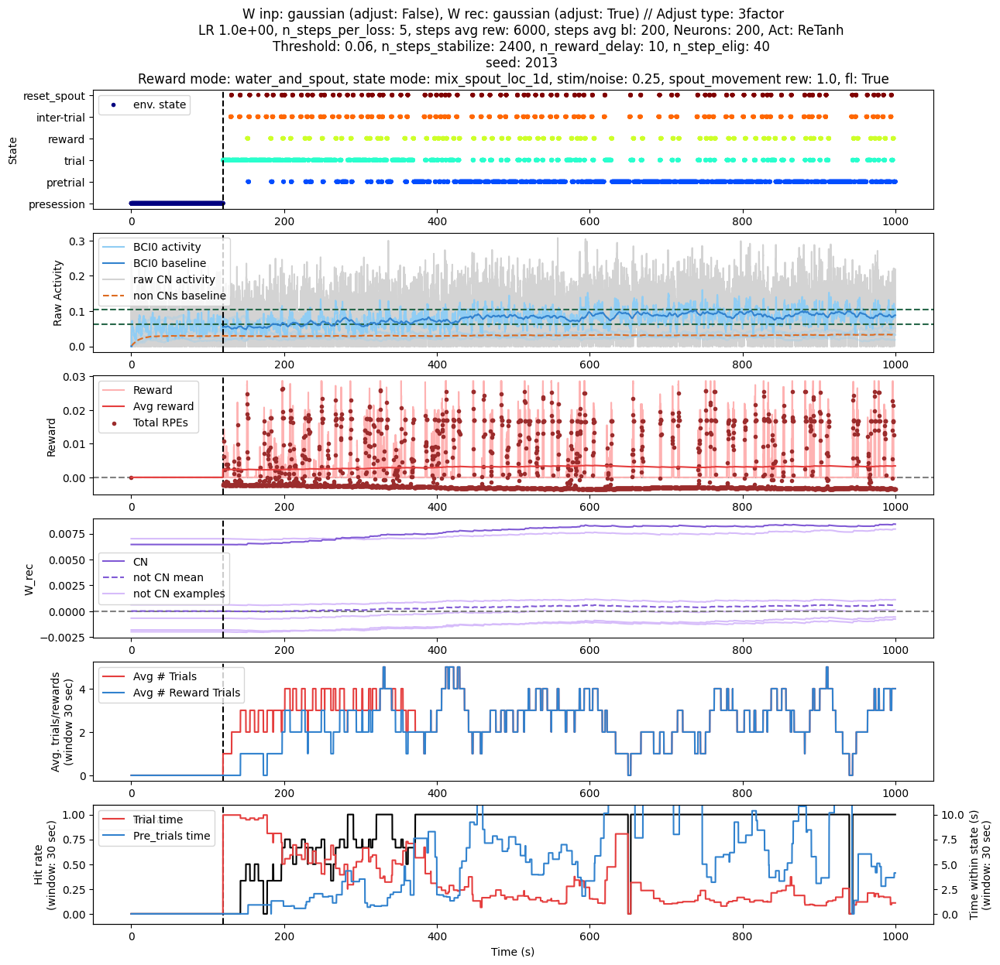

In [49]:
session_idx = 0
if session_idx >= task_params['n_sessions']:
    raise ValueError('Indexing session outside of range!')
print('--- Session idx {} ---'.format(session_idx))

task_params, train_params, net_params = params

n_neurons = task_params['n_neurons']

train_outputs = train_outputs_all[session_idx]

loss_steps = train_outputs['loss_steps']
steps = np.arange(task_params['n_steps'])
raw_steps = np.arange(task_params['n_steps']) # Has delay incorporated

if 't_step' not in task_params: # x-axis is in steps
    x_axis_step_scale = 1.0
    x_axis_label = 'Steps'
else: # x-axis in time (seconds)
    x_axis_step_scale = task_params['t_step'] / 1000 # Convert from ms to s
    x_axis_label = 'Time (s)'
x_axis = x_axis_step_scale * steps
x_axis_raw = x_axis_step_scale * raw_steps
x_axis_loss = x_axis_step_scale * np.array(loss_steps)

cn_idxs = train_outputs['cn_idxs']
bci_masks = train_outputs['bci_masks']
output = train_outputs['output']
reward = train_outputs['reward']
avg_activity = train_outputs['avg_activity']
avg_reward = train_outputs['avg_reward']

bci_activity = train_outputs['bci_activity'] # Not the same as matmul(output, bci_masks.T) when BCI masks change mid-session (perturbations)
avg_bci_activity = train_outputs['avg_bci_activity']

total_rpes = train_outputs['total_rpes']

sol_step = train_outputs['sol_step']

n_cells = 5
random_neuron_idxs = np.random.choice(task_params['n_neurons'], size=(n_cells,))
if cn_idxs is not None:
    while any(rn_idx in cn_idxs for rn_idx in random_neuron_idxs) in random_neuron_idxs: # Ensures the random neuron idxs aren't the CNs
        random_neuron_idxs = np.random.choice(task_params['n_neurons'], size=(n_cells,))

needs_thresold_plot = True
if task_params['task_type'] in ('our_bci',): # Extra plot for trial periods
    task_hist = task.hists[session_idx]

    fig, (ax0, ax1, ax2, ax3, ax4, ax5) = plt.subplots(6, 1, figsize=(14, 14))
    axs = (ax0, ax1, ax2, ax3, ax4, ax5)
    
    ax0.scatter(x_axis, task_hist['world_trajectory'], c=task_hist['world_trajectory'], cmap='jet', marker='.', label='env. state')
    ax0.set_ylabel('State')
    ax0.set_yticks((-1, 0, 1, 2, 3, 4))
    ax0.set_yticklabels(('presession', 'pretrial', 'trial', 'reward', 'inter-trial', 'reset_spout'))

    plot_more_our_bci_task((ax4, ax5), x_axis, task_params, task, session_idx)
    if task.dynamic_threshold:
        plot_dynamic_threshold(task_hist, ax1, task_params)
        needs_thresold_plot = False
else:
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 8))
    axs = (ax1, ax2, ax3)

if task_params['n_cns'] <= 2 and not task_params['add_fl']: # Plot the CN(s) activity
    if cn_idxs is not None:
        ax1.plot(x_axis, output[:, cn_idxs[0]], color=c_vals_l[1], label='CN activity')
        ax1.plot(x_axis, avg_activity[:, cn_idxs[0]], color=c_vals_d[1],  zorder=5, label='CN baseline')
        if task_params['n_cns'] == 2:
            ax1.plot(x_axis, output[:, cn_idxs[1]], color=c_vals_l[2], label='CN2 activity')
            ax1.plot(x_axis, avg_activity[:, cn_idxs[1]], color=c_vals_d[2], zorder=5, label='CN baseline')
else: # Plot BCI activity
    for bci_mask_idx in range(bci_masks.shape[0]):
        ax1.plot(x_axis, bci_activity[:, bci_mask_idx], color=c_vals_l[1 + bci_mask_idx],
                 label='BCI{} activity'.format(bci_mask_idx))
        ax1.plot(x_axis, avg_bci_activity[:, bci_mask_idx], color=c_vals[1 + bci_mask_idx],
                 label='BCI{} baseline'.format(bci_mask_idx), zorder=3)
    if task_params['add_fl']:
        ax1.plot(x_axis, output[:, cn_idxs[0]], color='lightgrey', label='raw CN activity', zorder=-5)

if task_params['task_type'] in ('simple_bci', 'our_bci',) and needs_thresold_plot:   
    ax1.axhline(train_outputs['threshold'], color=c_vals_d[2], linestyle='dashed')
    if task_params['width'] is not None:
        ax1.axhline(train_outputs['threshold'] + task_params['width'], color=c_vals_d[2], linestyle='dashed')
elif task_params['task_type'] in ('trial_structure_task',):
    for bci_mask_idx in range(task_params['n_bci_masks']):
        ax1.plot(
            x_axis, task.bci_targets[:, bci_mask_idx],
            color=c_vals_d[1 + bci_mask_idx], linestyle='dashed'
        )
        if task.bci_widths is not None:
            ax1.plot(x_axis, task.bci_targets[:, bci_mask_idx] +
                     task.bci_widths[:, bci_mask_idx],
                     color=c_vals_d[1 + bci_mask_idx], linestyle='dashed')
if cn_idxs is not None:
    ax1.plot(x_axis, np.mean(np.delete(avg_activity, cn_idxs, axis=-1), axis=-1), color=c_vals[4], label='non CNs baseline', linestyle='dashed')

for neuron_idx in random_neuron_idxs:
    ax1.plot(x_axis, avg_activity[:, neuron_idx], color=c_vals_l[1], zorder=-5, alpha=0.3)

ax1.set_ylabel('Raw Activity')

ax2.plot(x_axis_raw, reward, color=c_vals_l[0], label='Reward')
ax2.plot(x_axis, avg_reward, color=c_vals[0], label='Avg reward', zorder=6)
ax2.scatter(x_axis_loss, total_rpes, color=c_vals_d[0], marker='.', label='Total RPEs', zorder=5)
ax2.axhline(0.0, color='grey', linestyle='dashed', zorder=-3)

ax2.set_ylabel('Reward')

weight_change_x_axis = x_axis_loss

if net_params['W_inp_adjust']:
    W_type = net_params['W_inp_type']
    W_vals = train_outputs['W_inp_vals']
    ax3.set_ylabel('W_inp')
elif net_params['W_rec_adjust']:
    W_type = net_params['W_rec_type']
    W_vals = train_outputs['W_rec_vals']
    ax3.set_ylabel('W_rec')

delta_W_full = W_vals[1:] - W_vals[:-1]
delta_Ws = np.mean(delta_W_full, axis=(1, 2)) # Mean over inputs and outputs
if cn_idxs is not None:
    delta_Ws_nocn = np.mean(np.delete(W_vals, cn_idxs, axis=1)[1:] - np.delete(W_vals, cn_idxs, axis=1)[:-1], axis=(1, 2))
if W_type in ('diagonal',):
    raise NotImplementedError('Depricated.')
    ax3.plot(weight_change_x_axis, W_vals[:, cn_idx, cn_idx], color=c_vals[3], label='CN')
    ax3.plot(weight_change_x_axis, np.mean(np.delete(np.diagonal(W_vals, axis1=1, axis2=2), cn_idxs, axis=-1), axis=-1), color=c_vals[3], linestyle='dashed', label='not CN mean')
elif W_type in ('gaussian', 'gaussian_sparse', 'gaussian_low', 'log_normal', 'perm'):
    if task_params['n_cns'] == 1:
        if cn_idxs is not None:
            ax3.plot(weight_change_x_axis, np.mean(W_vals[:, cn_idxs[0], :], axis=-1), color=c_vals[3], label='CN')
            ax3.plot(weight_change_x_axis, np.mean(np.mean(np.delete(W_vals, cn_idxs, axis=1), axis=1), axis=-1), color=c_vals[3], linestyle='dashed', label='not CN mean')
    elif bci_masks.shape[0] == 1:
        ax3.plot(weight_change_x_axis, np.matmul(np.mean(W_vals, axis=-1), bci_masks.T)[:, 0], color=c_vals[3], label='BCI weights')
    ax3.axhline(0.0, color='grey', linestyle='dashed', zorder=-3)
    # ax3.scatter(loss_x_axis[1:], delta_Ws, color=c_vals_d[3], label='delta W', marker='.')

label = 'not CN examples'
for neuron_idx in random_neuron_idxs:
    if net_params['W_inp_type'] in ('diagonal',):
        ax3.plot(weight_change_x_axis, W_vals[:, neuron_idx, neuron_idx], color=c_vals_l[3], zorder=-5, label=label)
    elif net_params['W_inp_type'] in ('gaussian', 'gaussian_sparse', 'gaussian_low', 'log_normal',):
        ax3.plot(weight_change_x_axis, np.mean(W_vals[:, neuron_idx, :], axis=-1), color=c_vals_l[3], zorder=-5, label=label)
    label = None

show_trial_starts = False
for ax in axs:
    ax.legend()
    ax.axvline(x_axis_step_scale * task_params['n_steps_stabilize'], color='k', linestyle='dashed')
    # ax.set_xlim((2600, 2700))
    # ax.set_xlim((2400, 5000))
    # ax.set_xlim((20000, 26000))
    # ax.set_xlim((100, 200))
    # ax.set_xlim((415, 420))
    # ax.set_xlim((550, 600))

    if sol_step is not None:
        ax.axvline(x_axis_step_scale * (sol_step + task_params['n_steps_stabilize']), color=c_vals[2], linestyle='dashed', zorder=-5)
    if task_params['n_steps_evaluate'] > 0:
        ax.axvline(x_axis_step_scale * (task_params['n_steps'] - task_params['n_steps_evaluate']), color=c_vals[3], linestyle='dashed', zorder=-5)

    if task_params['perturbations'] is not None:
        for pert in task_params['perturbations']:
            ax.axvline(x_axis_step_scale * pert[0], color=c_vals[4], linestyle='dotted', zorder=-5)

    if task_params['task_type'] in ('our_bci'):
        if show_trial_starts:
            for trial_start in task.hist['trial_starts']:
                ax.axvline(task.dt * trial_start, color=c_vals_l[2], zorder=-5)
        if 'threshold_changes' in task.hist.keys():
            for threshold_change in task.hist['threshold_changes']:
                ax.axvline(task.dt * threshold_change, color=c_vals_l[4], zorder=-5)

# ax1.set_ylim((-2, 2))
# ax2.set_ylim((-0.04, 0.01))

if task_params['threshold'] is None:
    thresh_string = 'Threshold: None'
else:
    thresh_string = 'Threshold: {:.2f}'.format(task_params['threshold'])
title = 'W inp: {} (adjust: {}), W rec: {} (adjust: {}) // Adjust type: {}\n\
    LR {:.1e}, n_steps_per_loss: {}, steps avg rew: {}, steps avg bl: {}, Neurons: {}, Act: {}\n\
    {}, n_steps_stabilize: {}, n_reward_delay: {}, n_step_elig: {}\n\
    seed: {}'.format(
    net_params['W_inp_type'], net_params['W_inp_adjust'], net_params['W_rec_type'], net_params['W_rec_adjust'], train_params['adjust_type'],
    train_params['eta'], train_params['n_steps_per_loss'], train_params['n_window_reward'], train_params['n_window_baseline'], task_params['n_neurons'], net_params['act_fn_type'],
    thresh_string, task_params['n_steps_stabilize'], task_params['n_reward_delay'], train_params['n_window_elig'],
    task_params['seed']
)
axs[-1].set_xlabel(x_axis_label)

if task_params['task_type'] in ('our_bci'):
    title += '\nReward mode: {}, state mode: {}, stim/noise: {:.2f}, spout_movement rew: {:.1f}, fl: {}'.format(
        task_params['reward_mode'], task_params['state_mode'], task_params['stim_to_noise_ratio'],
        task_params['spout_movement_reward_scale'], task_params['add_fl']
    )

axs[0].set_title(title)
# ax3.set_ylim((-0.0001, 0.0001))

print('BCI sparsity: {:.2f}'.format(np.sum(np.mean(train_outputs['output'][:, cn_idxs] > 0, axis=-1)) / task_params['n_steps']))
print('All neuron sparsity: {:.2f}'.format(np.sum(np.mean(train_outputs['output'] > 0, axis=-1)) / task_params['n_steps']))

Try to explain why weight changes occur in the network. Currently makes 3 plots:
- Try to explain the incoming weights to neuron using various network measures (both ULR and MLR)
- Likewise try to explain the outgoing weight of a neuron
- Do an MLR fit, similar to what is done for experiment, to all weight changes

('1_post', '1_pre') - -5.2e-05 (p: 5.2e-267)
('1_post', 'mean_pre') - -7.4e-05 (p: 0.0e+00)
('1_post', 'delta_pre') - -2.7e-05 (p: 1.4e-31)
('mean_post', '1_pre') - -6.8e-05 (p: 1.3e-291)
('mean_post', 'mean_pre') - -1.0e-04 (p: 0.0e+00)
('mean_post', 'delta_pre') - -6.6e-05 (p: 4.4e-119)
('delta_post', '1_pre') - 2.1e-04 (p: 0.0e+00)
('delta_post', 'mean_pre') - 2.8e-04 (p: 0.0e+00)
('delta_post', 'delta_pre') - -1.0e-04 (p: 1.1e-187)


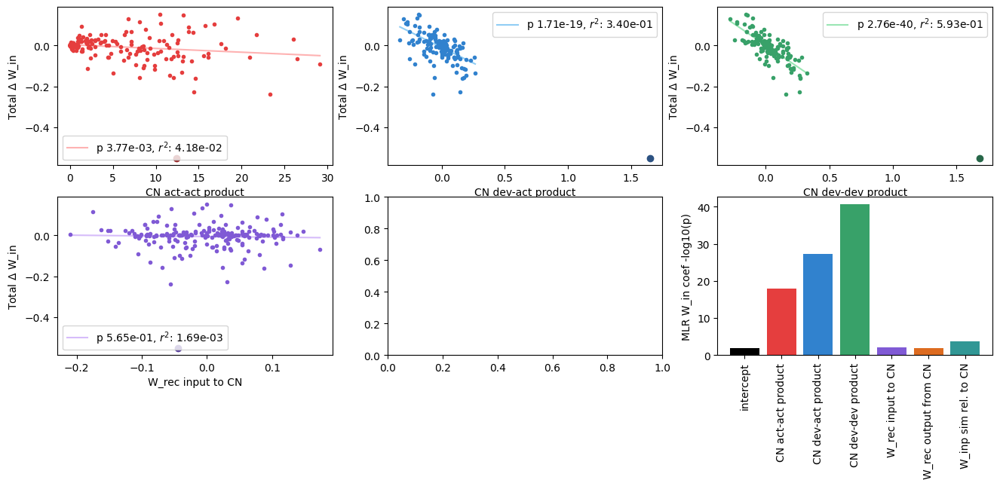

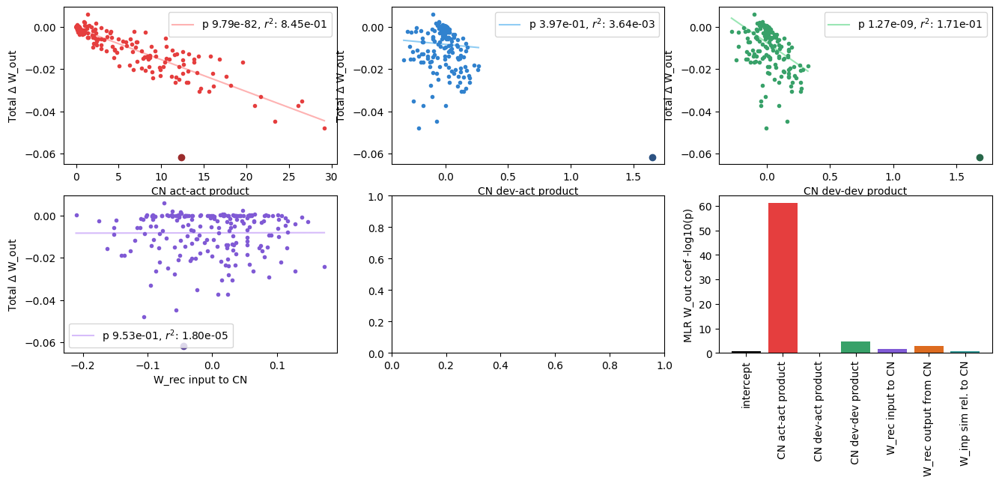

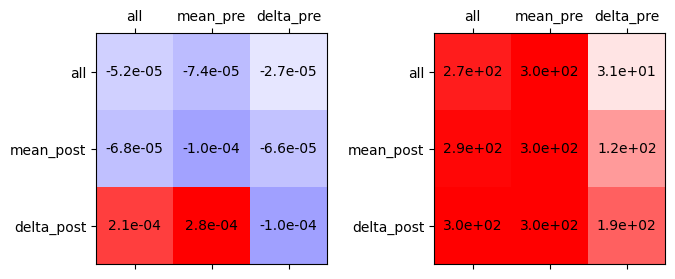

In [55]:
import statsmodels.api as sm

n_offset = 0
session_idx = 0

train_outputs = train_outputs_all[session_idx]

reward = train_outputs['reward']
avg_reward = train_outputs['avg_reward']
reward_relevant_output = train_outputs['output']
avg_reward_relevant_output = train_outputs['avg_activity']

cn_idx = train_outputs['cn_idxs'][0]

n_steps_stabilize = task_params['n_steps_stabilize']

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
    if 'W_inp_elg_vals' in output_vars:
        W_elg = train_outputs['W_inp_elg_vals']
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']
    if 'W_rec_elg_vals' in output_vars:
        W_elg = train_outputs['W_rec_elg_vals']

activity_trunc = reward_relevant_output[n_steps_stabilize:]
deviation_trunc = reward_relevant_output[n_steps_stabilize:] - avg_reward_relevant_output[n_steps_stabilize:]
# Note we account for the delay in the reward indexing here
rpe_trunc = reward[n_steps_stabilize:] - avg_reward[n_steps_stabilize:]
delta_W = W_vals[-1] - W_vals[0]

W_rec = 1/2 * (W_vals[-1] + W_vals[0])

if n_offset > 0:
    rpe_activity_prod = np.matmul(rpe_trunc[n_offset:], activity_trunc[:-n_offset])
    rpe_dev_prod = np.matmul(rpe_trunc[n_offset:], deviation_trunc[:-n_offset])
elif n_offset == 0:
    rpe_activity_prod = np.matmul(rpe_trunc, activity_trunc)
    rpe_dev_prod = np.matmul(rpe_trunc, deviation_trunc)
elif n_offset < 0:
    rpe_activity_prod = np.matmul(rpe_trunc[:-n_offset], activity_trunc[n_offset:])
    rpe_dev_prod = np.matmul(rpe_trunc[:-n_offset], deviation_trunc[n_offset:])

neuron_act_neuron_act_prod = np.matmul(activity_trunc.T, activity_trunc) # (n_neurons, n_neurons)
neuron_dev_neuron_act_prod = np.matmul(deviation_trunc.T, activity_trunc) # (n_neurons, n_neurons)
neuron_dev_neuron_dev_prod = np.matmul(deviation_trunc.T, deviation_trunc) # (n_neurons, n_neurons)

W_inp = np.copy(net.W_inp)
W_inp_sim = np.matmul(W_inp, W_inp[cn_idx])

total_delta_W_in = np.sum(delta_W, axis=-1)
total_delta_W_in_no_cn = np.delete(total_delta_W_in, cn_idx)

total_delta_W_out = np.sum(delta_W, axis=0)
total_delta_W_out_no_cn = np.delete(total_delta_W_out, cn_idx)

# A bunch of parameter that could potentially explain the weight changes
predictors = np.column_stack((
    # rpe_activity_prod,
    # rpe_dev_prod,
    neuron_act_neuron_act_prod[cn_idx, :],
    neuron_dev_neuron_act_prod[cn_idx, :],
    neuron_dev_neuron_dev_prod[cn_idx, :],
    W_rec[cn_idx],
    W_rec[:, cn_idx],
    W_inp_sim,
)).T
n_predictors = predictors.shape[0]

predictor_names = (
    # 'RPE-activity product',
    # 'RPE-dev product',
    'CN act-act product',
    'CN dev-act product',
    'CN dev-dev product',
    'W_rec input to CN',
    'W_rec output from CN',
    'W_inp sim rel. to CN',
)



for dW_name, total_delta_W, total_delta_W_no_cn in (
    ('W_in', total_delta_W_in, total_delta_W_in_no_cn),
    ('W_out', total_delta_W_out, total_delta_W_out_no_cn),
):

    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(16, 6))

    for predictor_idx, ax in enumerate((ax1, ax2, ax3, ax4,)):
        ax.scatter(predictors[predictor_idx], total_delta_W, marker='.', color=c_vals[predictor_idx])
        ax.scatter(predictors[predictor_idx, cn_idx], total_delta_W[cn_idx], marker='o', color=c_vals_d[predictor_idx])
        # Fit without CN
        _ = add_regression_line(np.delete(predictors[predictor_idx], cn_idx), total_delta_W_no_cn, ax=ax, color=c_vals_l[predictor_idx], zorder=-5)
        ax.set_xlabel(predictor_names[predictor_idx])

        ax.legend()
        ax.set_ylabel('Total $\Delta$ {}'.format(dW_name))

    X = np.delete(predictors, cn_idx, axis=-1).T
    Y = total_delta_W_no_cn[:, np.newaxis]

    X = sm.add_constant(X)

    fit_model = sm.OLS(Y, X, missing='none') # nans should be caught above
    results = fit_model.fit()

    # slope = results.params[slope_idx]
    # intercept = 0. if not fit_intercept else results.params[0]
    # rvalue = np.sqrt(results.rsquared)

    # print(results.params)
    # print(results.pvalues)

    bar_colors = ('k', *[c_vals[idx] for idx in range(n_predictors)])
    ax6.bar(np.arange(n_predictors+1), -np.log10(results.pvalues), color=bar_colors)

    ax6.set_xticks(np.arange(n_predictors+1))
    ax6.set_xticklabels(('intercept', *predictor_names), rotation=90)
    ax6.set_ylabel('MLR {} coef -log10(p)'.format(dW_name))
    
### MLR like fit ###

output_train = reward_relevant_output[task_params['n_steps_stabilize']:task_params['n_steps']-task_params['n_steps_evaluate']]

neuron_means = np.zeros((n_neurons,))
neuron_changes = np.zeros((n_neurons,))

train_steps = np.arange(output_train.shape[0])

for neuron_idx in range(n_neurons):
    neuron_means[neuron_idx] = np.mean(output_train[:, neuron_idx])
    
    slope, _, _, _, _ = linregress(train_steps, output_train[:, neuron_idx])
    neuron_changes[neuron_idx] = slope

neuron_means = (neuron_means - np.mean(neuron_means)) / np.std(neuron_means)
neuron_changes = (neuron_changes - np.mean(neuron_changes)) / np.std(neuron_changes)

reg_names = []
delta_W_regressors = []
    
for reg_out_name, reg_out_val in zip(('1_post', 'mean_post', 'delta_post'), (np.ones((n_neurons,)), neuron_means, neuron_changes)):
    for reg_in_name, reg_in_val in zip(('1_pre', 'mean_pre', 'delta_pre'), (np.ones((n_neurons,)), neuron_means, neuron_changes)):
        reg_names.append((reg_out_name, reg_in_name))
        delta_W_regressors.append(
            (reg_out_val[:, None] * reg_in_val[None, :]).flatten()
        )   
delta_W_regressors = np.array(delta_W_regressors).T       

# z-score
delta_W_regressors = (delta_W_regressors - np.mean(delta_W_regressors, axis=-1, keepdims=True)) / np.std(delta_W_regressors, axis=-1, keepdims=True)

delta_W_flat = delta_W.flatten()[:, None]

X = delta_W_regressors
Y = delta_W_flat

fit_model = sm.OLS(Y, X, missing='none') # nans should be caught above
results = fit_model.fit()

for reg_idx, reg_name in enumerate(reg_names):
    print('{} - {:.1e} (p: {:.1e})'.format(reg_name, results.params[reg_idx], results.pvalues[reg_idx]))
    
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))

params_matrix = results.params.reshape(3, 3)
max_val = np.max(np.abs(params_matrix))
ax1.matshow(params_matrix, vmax=max_val, vmin=-max_val, cmap='bwr')
for (i, j), z in np.ndenumerate(params_matrix):
    ax1.text(j, i, f'{z:0.1e}', ha='center', va='center')

pvalues_matrix = -np.log10(np.where(results.pvalues.reshape(3, 3) < 1e-300, 1e-300, results.pvalues.reshape(3, 3)))
max_val = np.max(np.abs(pvalues_matrix))
ax2.matshow(pvalues_matrix, vmax=max_val, vmin=-max_val, cmap='bwr')
for (i, j), z in np.ndenumerate(pvalues_matrix):
    ax2.text(j, i, f'{z:0.1e}', ha='center', va='center')
    
for ax in (ax1, ax2):
    ax.set_xticks(np.arange(3))
    ax.set_xticklabels(('all', 'mean_pre', 'delta_pre'))
    ax.set_yticks(np.arange(3))
    ax.set_yticklabels(('all', 'mean_post', 'delta_post'))


Test to see if correlations predict weight changes. Eventually will be used to reproduce experiment results where there seems to be a very strong correlation between change in correlation between a photostim group and the change in causal connectivity.

(-0.0001, 0.0001)

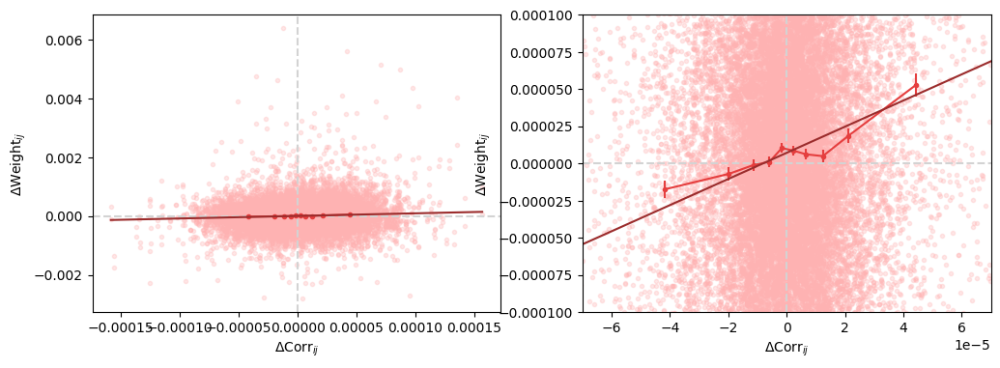

In [ ]:
step_init = 10000
step_final = 20000
n_steps_corr = 5000

session_idx = 0

task_params, train_params, net_params = params

train_outputs = train_outputs_all[session_idx]

output = train_outputs['output']
loss_steps = train_outputs['loss_steps']
W_vals = train_outputs['W_rec_vals']

def get_corrs_and_weights(step):
    output_steps = output[step-n_steps_corr:step]
    corrs = np.cov(output_steps.T)

    # Find closest loss_step index to desired final time step
    loss_step_idx = np.argmin(np.abs(step - np.array(loss_steps)))
    weights = W_vals[loss_step_idx]

    corrs_flat = []
    weights_flat = []

    for neuron_idx1 in range(corrs.shape[0]):
        for neuron_idx2 in range(corrs.shape[0]):
            if neuron_idx1 == neuron_idx2: continue # Skip diagonals
            corrs_flat.append(corrs[neuron_idx1, neuron_idx2])
            weights_flat.append(weights[neuron_idx1, neuron_idx2])

    return np.array(corrs_flat), np.array(weights_flat)

corrs_init, weights_init = get_corrs_and_weights(step_init)
corrs_final, weights_final = get_corrs_and_weights(step_final)

delta_corrs = corrs_final - corrs_init
delta_weights = weights_final - weights_init

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for ax in (ax1, ax2):
    ax.scatter(delta_corrs, delta_weights, marker='.', color=c_vals_l[0], alpha=0.3,
                zorder=-10)

    add_bin_plot(delta_corrs, delta_weights, 10, ax=ax, color=c_vals[0], zorder=0,
                add_label=False, alpha=1.0)
    add_regression_line(delta_corrs, delta_weights, ax=ax, color=c_vals_d[0], zorder=1)

    ax.set_xlabel('$\Delta$Corr$_{ij}$')
    ax.set_ylabel('$\Delta$Weight$_{ij}$')

    ax.axvline(0.0, color='lightgrey', linestyle='dashed', zorder=-1)
    ax.axhline(0.0, color='lightgrey', linestyle='dashed', zorder=-1)

ax2.set_xlim((-7e-5, 7e-5))
ax2.set_ylim((-1e-4, 1e-4))

# outputs_final = output[]

In [ ]:
# For a given network, drives it using some input to produce some data
import copy

def get_more_acitivty(params, net, W_rec_new=None, W_inp_new=None, state=None,
                      state_pre_act=None):

    task_params, train_params, net_params = params

    task_params_copy = copy.deepcopy(task_params)
    train_params_copy = copy.deepcopy(train_params)
    net_params_copy = copy.deepcopy(net_params)
    net_copy = copy.deepcopy(net)

    train_params_copy['eta'] = 0.0 # Zeros out learning rate, so no training
    task_params_copy['n_steps_stabilize'] = task_params_copy['n_steps'] + 10 # Never leave stabilization (repetitive with above)

    if W_rec_new is not None:
        net_copy['W_rec'] = W_rec_new

    if W_inp_new is not None:
        net_copy['W_inp'] = W_inp_new

    if state is not None:
        raise NotImplementedError('Update to new network')
        assert state_pre_act is not None # Both these need to be nonzero for this to make sense
        net_copy['prev_activity'] = state
        net_copy['prev_activity_pre_act'] = state_pre_act

    _, train_outputs_activity, _, _, _ = train_task((task_params_copy, train_params_copy, net_params_copy),
                                                     output_vars=output_vars, net=net_copy, verbose=False)

    session_idx = 0

    return train_outputs_activity[session_idx]['output'], train_outputs_activity

Some manifold quantifications

shape: (1000, 200)
 Approx activity dim: 39.8 (ratio: 0.20)
 Whitened approx activity dim: 61.0 (ratio: 0.30)


(1e-06, 10.0)

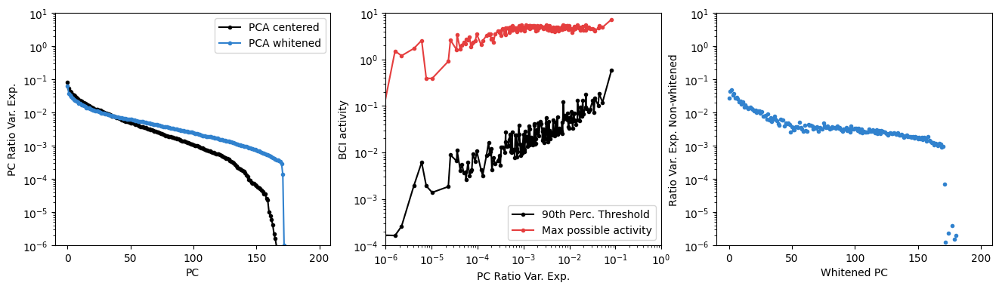

In [ ]:
session_idx = 0

activities_stabilize = train_outputs_all[session_idx]['output'][:task_params['n_steps_stabilize']]

print('shape:', activities_stabilize.shape)

activities_stabilize_center = activities_stabilize - np.mean(activities_stabilize, axis=0)
activities_stabilize_white = np.where(
    np.std(activities_stabilize_center, axis=0) > 0,
    activities_stabilize_center / (np.std(activities_stabilize_center, axis=0) + 1e-8), 0.
)

activity_pca = PCA()
activity_pca.fit(activities_stabilize_center)

stabilize_pca_var_exp = activity_pca.explained_variance_ratio_
stabilize_pca_pr = participation_ratio_vector(activity_pca.explained_variance_ratio_)

activity_white_pca = PCA()
activity_white_pca.fit(activities_stabilize_white)
stabilize_white_pca_var_exp = activity_white_pca.explained_variance_ratio_
stabilize_white_pca_pr = participation_ratio_vector(activity_white_pca.explained_variance_ratio_)

print(' Approx activity dim: {:.1f} (ratio: {:.2f})'.format(
    stabilize_pca_pr, stabilize_pca_pr / task_params['n_neurons']
))
print(' Whitened approx activity dim: {:.1f} (ratio: {:.2f})'.format(
    stabilize_white_pca_pr, stabilize_white_pca_pr / task_params['n_neurons']
))

# Remove ambiguity in PC directions by definining the mean dot product with the uncentered activity to be positive
manifold_axes = np.sign(np.mean(np.matmul(activities_stabilize, activity_pca.components_.T), axis=0))[:, np.newaxis] * activity_pca.components_

# Non-centered PCA projections
activities_stabilize_pca = np.matmul(activities_stabilize, manifold_axes.T)

# Thresholds along various PC directions
percentile = 90
pc_thresholds = np.percentile(activities_stabilize_pca, percentile, axis=0)

# Maximum possible activity along each PC
max_activity_manifold_axes = np.zeros((task_params['n_neurons'],))
max_activity = 1.
for pc_idx in range(task_params['n_neurons']):
    max_activity_manifold_axes[pc_idx] = max_activity * np.sum(manifold_axes[pc_idx, manifold_axes[pc_idx] > 0], axis=-1)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4))

ax1.plot(stabilize_pca_var_exp, color='k', marker='.', label='PCA centered')
ax1.plot(stabilize_white_pca_var_exp, color=c_vals[1], marker='.', label='PCA whitened')
ax1.set_xlabel('PC')
ax1.set_ylabel('PC Ratio Var. Exp.')
ax1.set_yscale('log')

ax2.plot(stabilize_pca_var_exp, pc_thresholds, color='k', marker='.', label='{}th Perc. Threshold'.format(percentile))
ax2.plot(stabilize_pca_var_exp, max_activity_manifold_axes, color=c_vals[0], marker='.', label='Max possible activity')
ax2.set_xscale('log')
ax2.set_yscale('log')

ax2.set_xlabel('PC Ratio Var. Exp.')
ax2.set_ylabel('BCI activity')

pc_projs = np.matmul(activity_pca.components_, activity_white_pca.components_.T) # normal PC x white PCs
# pc_projs = np.matmul(activity_pca.components_, activity_pca.components_.T) # normal PC x white PCs

ax3.scatter(np.arange(task_params['n_neurons']), np.matmul(stabilize_pca_var_exp, pc_projs**2),
            color=c_vals[1], marker='.')
ax3.set_xlabel('Whitened PC')
ax3.set_ylabel('Ratio Var. Exp. Non-whitened')
ax3.set_yscale('log')

ax1.set_ylim((1e-6, 1e1))

ax2.set_xlim((1e-6, 1e0))
ax2.set_ylim((1e-4, 1e1))
ax1.legend()
ax2.legend()

ax3.set_ylim((1e-6, 1e1))

**Various measures of effects from RPE - eligibility/deviation correlation**

Look at how RPE-eligibility correlation influences total weight changes for an individual postsynaptic neuron. No delay accounted for here.

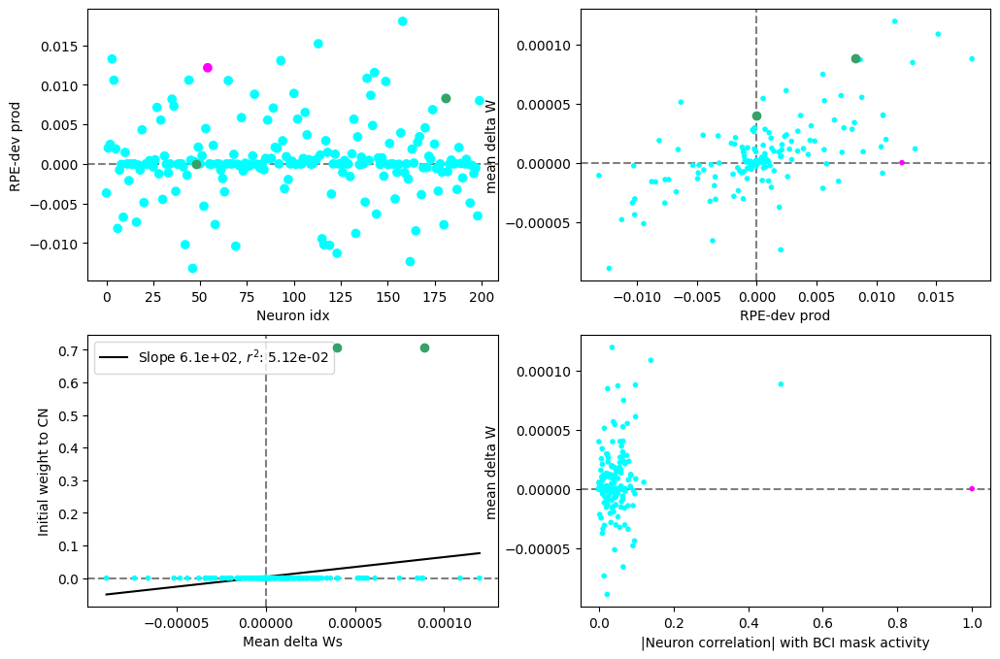

In [ ]:
correlation_type = 'deviation_raw_rpes'
# deviation_raw_rpes: compute deviations at all times steps, and rpes at all time steps
# eligibility_total_rpes: closest to actual calculation, total RPEs and eligibility at every loss adjustment (will be correlated trivially)

if 'nonzero_rec_idxs' in task_params:
    neuron_idxs_to_color = task_params['nonzero_rec_idxs']
else:
    neuron_idxs_to_color = None #np.array([112, 183,])
neuron_color = c_vals[2]

session_idx = 0
plot_extras = True
training_only = False # Truncate in between end of stabilization period and solution step
cmap_type = 'cool' # viridis, cool

train_outputs = train_outputs_all[session_idx]

cn_idxs = train_outputs['cn_idxs']
bci_masks = train_outputs['bci_masks']
reward = train_outputs['reward']
total_rpes = train_outputs['total_rpes']
avg_reward = train_outputs['avg_reward']

if task_params['add_fl']:
    print('Even though FL is on, still use raw activity because thats used in eligibility.')
    # reward_relevant_output = train_outputs['output_fl']
    # avg_reward_relevant_output = np.zeros_like(output)
    # # Calculate average FL by hand since its not computed during training (no good reason for this)
    # prev_avg_activity_fl = np.zeros((task_params['n_neurons'],))
    # for step_idx in range(task_params['n_steps']):
    #     avg_reward_relevant_output[step_idx] = accumulate_decay(prev_avg_activity_fl, reward_relevant_output[step_idx], n_window=train_params['n_window_baseline'])
    #     prev_avg_activity_fl = avg_reward_relevant_output[step_idx]

reward_relevant_output = train_outputs['output']
avg_reward_relevant_output = train_outputs['avg_activity']

sol_step = train_outputs['sol_step']
n_steps_stabilize = task_params['n_steps_stabilize']
loss_steps = train_outputs['loss_steps']

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
    if 'W_inp_elg_vals' in output_vars:
        W_elg = train_outputs['W_inp_elg_vals']
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']
    if 'W_rec_elg_vals' in output_vars:
        W_elg = train_outputs['W_rec_elg_vals']

if training_only: # Any time after stabilization and before solution step
    deviation_trunc = (reward_relevant_output[n_steps_stabilize:n_steps_stabilize + sol_step] -
                       avg_reward_relevant_output[n_steps_stabilize:n_steps_stabilize + sol_step])
    rpe_trunc = (reward[n_steps_stabilize:n_steps_stabilize + sol_step] -
                 avg_reward[n_steps_stabilize:n_steps_stabilize + sol_step])
    train_end_loss_idx = np.argmin(np.abs(loss_steps - (n_steps_stabilize + sol_step)))
    delta_W = W_vals[train_end_loss_idx] - W_vals[0]
else: # Any time after stabilization
    deviation_trunc = reward_relevant_output[n_steps_stabilize:] - avg_reward_relevant_output[n_steps_stabilize:]
    # Note we account for the delay in the reward indexing here
    rpe_trunc = reward[n_steps_stabilize:] - avg_reward[n_steps_stabilize:]
    delta_W = W_vals[-1] - W_vals[0]

# deviation_mag = np.linalg.norm(deviation_trunc, axis=0)

# cosine_angle_deviations = np.where(
#     np.outer(deviation_mag, deviation_mag) > 0,
#     np.matmul(deviation_trunc.T, deviation_trunc) / np.outer(deviation_mag, deviation_mag),
#     0.
# )
# cosine_angle_rpe = np.where(
#     deviation_mag > 0,
#     np.matmul(rpe_trunc, deviation_trunc) / (deviation_mag * np.linalg.norm(rpe_trunc)),
#     0.
# )

if correlation_type == 'deviation_raw_rpes':
    rpe_dev_prod = np.matmul(rpe_trunc, deviation_trunc)
    rpe_dev_squared_prod = np.matmul(rpe_trunc, deviation_trunc**2)
elif correlation_type == 'eligibility_total_rpes':
    rpe_dev_prod = np.sum(np.einsum('I, Iij -> ij', np.array(total_rpes), np.array(W_elg)), axis=-1)
    rpe_dev_squared_prod = np.zeros_like(rpe_dev_prod)
if plot_extras:
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))
else:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4))

# ax1.matshow(cosine_angle_deviations, vmax=1, vmin=-1, cmap='bwr')
# ax1.scatter(np.arange(task_params['n_neurons']), cosine_angle_rpe, color=c_vals_l[3])
# ax1.scatter(np.arange(task_params['n_neurons'])[cn_idx], cosine_angle_rpe[cn_idx], color=c_vals[3])
assert bci_masks.shape[0] == 1
ax1.scatter(np.arange(task_params['n_neurons']), rpe_dev_prod, c=bci_masks[0], cmap=cmap_type)
if neuron_idxs_to_color is not None:
    ax1.scatter(np.arange(task_params['n_neurons'])[neuron_idxs_to_color], rpe_dev_prod[neuron_idxs_to_color],
                c=neuron_color, zorder=10)
# ax1.scatter(np.arange(task_params['n_neurons']), rpe_dev_prod, color=c_vals_l[3])

# correlations = []

# for neuron_idx1 in range(task_params['n_neurons']):
#     for neuron_idx2 in range(neuron_idx1+1, task_params['n_neurons']):
#         correlations.append(cosine_angle_deviations[neuron_idx1, neuron_idx2])

# mean_correlation = np.mean(correlations)

# print('Mean deviation correlation: {:.2f}'.format(mean_correlation))
# if 'cn_idx2' in train_outputs: # Special case for two CNs
#     cn_idx2 = train_outputs['cn_idx2']
#     print('CN1-CN2 deviation correlation: {:.2f}'.format(
#         cosine_angle_deviations[cn_idx, cn_idx2]
#     ))
#     print('RPE-CN1 corr: {:.2f}, RPE-CN2 corr: {:.2f}, non-CN corr: {:.2f}'.format(
#         cosine_angle_rpe[cn_idx], cosine_angle_rpe[cn_idx2],
#         np.mean(np.delete(cosine_angle_rpe, (cn_idx, cn_idx2)))
#     ))

# else:
#     print('RPE, CN corr: {:.2f}, non-CN corr: {:.2f}'.format(
#         cosine_angle_rpe[cn_idx], np.mean(np.delete(cosine_angle_rpe, cn_idx))
#     ))

mean_delta_Ws = np.mean(delta_W, axis=-1)
# mean_delta_Ws = np.mean(np.abs(delta_W), axis=-1)

assert bci_masks.shape[0] == 1
ax2.scatter(rpe_dev_prod, mean_delta_Ws, c=bci_masks[0], cmap=cmap_type, marker='.')
if neuron_idxs_to_color is not None:
    ax2.scatter(rpe_dev_prod[neuron_idxs_to_color], mean_delta_Ws[neuron_idxs_to_color],
                c=neuron_color, zorder=10)
# ax2.scatter(rpe_dev_prod, mean_delta_Ws, color=c_vals[0], marker='.')
# ax2.scatter(cosine_angle_rpe[cn_idx], np.mean(delta_W, axis=-1)[cn_idx], color=c_vals_d[0], marker='.')
# if cn_idx2 is not None:
#     ax2.scatter(cosine_angle_rpe[cn_idx2], np.mean(delta_W, axis=-1)[cn_idx2], color=c_vals_d[0], marker='.')
ax2.axhline(0., color='grey', linestyle='dashed', zorder=-5)
ax2.axvline(0., color='grey', linestyle='dashed', zorder=-5)

ax1.set_xlabel('Neuron idx')
# ax1.set_ylabel('RPE correlation')
ax1.set_ylabel('RPE-dev prod')
ax1.axhline(0., color='grey', linestyle='dashed', zorder=-5)

ax2.set_xlabel('RPE-dev prod')
ax2.set_ylabel('mean delta W')

if plot_extras:
    if len(cn_idxs) == 1: # Do large weight change neurons also have strong connections to CN?
        w_val_idx = 0 # 0 for initial, or -1 for final

        ax3.scatter(mean_delta_Ws, W_vals[w_val_idx][cn_idxs[0]], c=bci_masks[0], cmap=cmap_type,
                    marker='.')
        if neuron_idxs_to_color is not None:
            ax3.scatter(mean_delta_Ws[neuron_idxs_to_color], W_vals[w_val_idx][cn_idxs[0]][neuron_idxs_to_color],
                        c=neuron_color, zorder=10)
        ax3.set_xlabel('Mean delta Ws')
        # ax1.set_ylabel('RPE correlation')
        if w_val_idx == 0:
            ax3.set_ylabel('Initial weight to CN')
        elif w_val_idx == -1:
            ax3.set_ylabel('Final weight to CN')
        ax3.axvline(0., color='grey', linestyle='dashed', zorder=-5)
        ax3.axhline(0., color='grey', linestyle='dashed', zorder=-5)

        _ = add_regression_line(mean_delta_Ws, W_vals[w_val_idx][cn_idxs[0]], ax=ax3, color='k', zorder=-3)
        ax3.legend()
    else: # RPE-dev^2 prod
        assert bci_masks.shape[0] == 1
        ax3.scatter(np.arange(task_params['n_neurons']), rpe_dev_squared_prod, c=bci_masks[0], cmap=cmap_type,
                    marker='.')

        ax3.set_xlabel('Neuron idx')
        # ax1.set_ylabel('RPE correlation')
        ax3.set_ylabel('RPE-dev^2 prod')
        ax3.axhline(0., color='grey', linestyle='dashed', zorder=-5)

    neuron_correlations = np.corrcoef(deviation_trunc.T)
    # Set nans to zero
    neuron_correlations = np.where(
        np.isnan(neuron_correlations), 0., neuron_correlations
    )

    assert bci_masks.shape[0] == 1
    corr_with_bci = np.matmul(neuron_correlations, bci_masks.T)[:, 0]
    assert bci_masks.shape[0] == 1
    ax4.scatter(np.abs(corr_with_bci), mean_delta_Ws, c=bci_masks[0], cmap=cmap_type, marker='.')
    ax4.axhline(0., color='grey', linestyle='dashed', zorder=-5)

    ax4.set_xlabel('|Neuron correlation| with BCI mask activity')
    ax4.set_ylabel('mean delta W')

How well does RPE-eligibility correlation explain other useful activity change parameters?

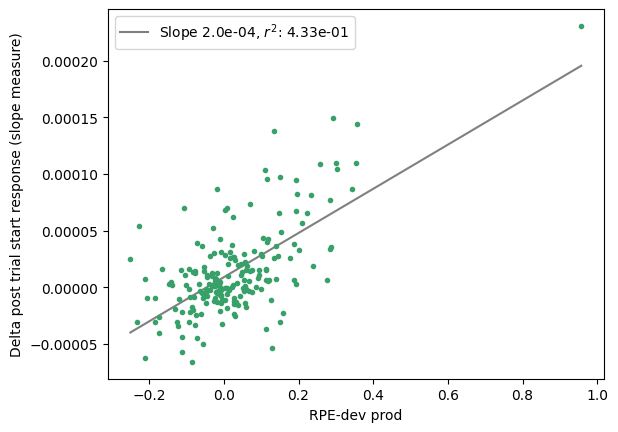

In [ ]:
fig, ax1 = plt.subplots()

# ax1.scatter(rpe_dev_prod, tuning_slopes, marker='.', color=c_vals[2])
# ax1.scatter(rpe_dev_prod, np.mean(reward_relevant_output, axis=0), marker='.', color=c_vals[2])
ax1.scatter(rpe_dev_prod, post_slopes, marker='.', color=c_vals[2])
ax1.set_xlabel('RPE-dev prod')
# ax1.set_ylabel('Delta tuning (slope measure)')
# ax1.set_ylabel('Mean activity')
ax1.set_ylabel('Delta post trial start response (slope measure)')

# _ = add_regression_line(rpe_dev_prod, tuning_slopes, ax=ax1, color='grey', zorder=-5)
# _ = add_regression_line(rpe_dev_prod, np.mean(reward_relevant_output, axis=0), ax=ax1, color='grey', zorder=-5)
_ = add_regression_line(rpe_dev_prod, post_slopes, ax=ax1, color='grey', zorder=-5)
ax1.legend()

In [ ]:
#delta_causal_connectivity_neurons = bci_analysis.compute_causal_connectivity_neurons(delta_causal_connectivity, train_outputs, params, task_ps, mode=2)

Account for delay that offsets eligibility-RPE correlation.

In [ ]:

n_offsets = np.arange(-20, 200)
# n_offsets = np.array([10,])
var_explain_offsets = np.zeros_like(n_offsets)
var_exps = []
slopes = []
dev_self_corrs = []
rpe_self_corrs = []

rpe_dev_prods = []

if n_offsets.shape[0] > 3:
    plot_visualization = False
else:
    plot_visualization = True

for offset_idx, n_offset in enumerate(n_offsets):

    reward_relevant_output = train_outputs['output']
    avg_reward_relevant_output = train_outputs['avg_activity']

    n_steps_stabilize = task_params['n_steps_stabilize']

    if net_params['W_inp_adjust']:
        W_vals = train_outputs['W_inp_vals']
        if 'W_inp_elg_vals' in output_vars:
            W_elg = train_outputs['W_inp_elg_vals']
    elif net_params['W_rec_adjust']:
        W_vals = train_outputs['W_rec_vals']
        if 'W_rec_elg_vals' in output_vars:
            W_elg = train_outputs['W_rec_elg_vals']

    deviation_trunc = reward_relevant_output[n_steps_stabilize:] - avg_reward_relevant_output[n_steps_stabilize:]
    # Note we account for the delay in the reward indexing here
    rpe_trunc = reward[n_steps_stabilize:] - avg_reward[n_steps_stabilize:]
    delta_W = W_vals[-1] - W_vals[0]

    if n_offset > 0:
        rpe_dev_prod = np.matmul(rpe_trunc[n_offset:], deviation_trunc[:-n_offset])
        dev_dev_prod = np.matmul(deviation_trunc[n_offset:].T, deviation_trunc[:-n_offset])
        rpe_rpe_prod = np.matmul(rpe_trunc[n_offset:].T, rpe_trunc[:-n_offset])
    elif n_offset == 0:
        rpe_dev_prod = np.matmul(rpe_trunc, deviation_trunc)
        dev_dev_prod = np.matmul(deviation_trunc.T, deviation_trunc)
        rpe_rpe_prod = np.matmul(rpe_trunc.T, rpe_trunc)
    elif n_offset < 0:
        rpe_dev_prod = np.matmul(rpe_trunc[:-n_offset], deviation_trunc[n_offset:])
        dev_dev_prod = np.matmul(deviation_trunc[:-n_offset].T, deviation_trunc[n_offset:])
        rpe_rpe_prod = np.matmul(rpe_trunc[:-n_offset].T, rpe_trunc[n_offset:])

    mean_delta_Ws = np.mean(delta_W, axis=-1)

    slope, intercept, rvalue, _, _ = linregress(rpe_dev_prod, mean_delta_Ws)

    var_exp = rvalue**2
    slopes.append(slope)
    var_exps.append(var_exp)
    dev_self_corrs.append(np.trace(dev_dev_prod))
    rpe_self_corrs.append(rpe_rpe_prod)

    rpe_dev_prods.append(rpe_dev_prod)
    print('Var explain (idx: {}): {:.2f}'.format(offset_idx, var_exp))
    # print('Var explain (idx: {}): {:.2f}'.format(offset_idx, var_explain_offsets[offset_idx]))

    if plot_visualization:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4))

        assert bci_masks.shape[0] == 1
        ax1.scatter(np.arange(task_params['n_neurons']), rpe_dev_prod, c=bci_masks[0], cmap=cmap_type)
        if neuron_idxs_to_color is not None:
            ax1.scatter(np.arange(task_params['n_neurons'])[neuron_idxs_to_color], rpe_dev_prod[neuron_idxs_to_color],
                        c=neuron_color, zorder=10)

        assert bci_masks.shape[0] == 1
        ax2.scatter(rpe_dev_prod, mean_delta_Ws, c=bci_masks[0], cmap=cmap_type, marker='.')
        if neuron_idxs_to_color is not None:
            ax2.scatter(rpe_dev_prod[neuron_idxs_to_color], mean_delta_Ws[neuron_idxs_to_color],
                        c=neuron_color, zorder=10)

        _ = add_regression_line(rpe_dev_prod, mean_delta_Ws, ax=ax2, color='grey', zorder=-5)

        ax1.set_xlabel('Neuron idx')
        # ax1.set_ylabel('RPE correlation')
        ax1.set_ylabel('RPE-dev prod')
        ax1.axhline(0., color='grey', linestyle='dashed', zorder=-5)

        ax2.set_xlabel('RPE-dev prod')
        ax2.set_ylabel('mean delta W')

        ax2.legend()

Var explain (idx: 0): 0.01
Var explain (idx: 1): 0.01
Var explain (idx: 2): 0.01
Var explain (idx: 3): 0.01
Var explain (idx: 4): 0.01
Var explain (idx: 5): 0.01
Var explain (idx: 6): 0.01
Var explain (idx: 7): 0.01
Var explain (idx: 8): 0.01
Var explain (idx: 9): 0.01
Var explain (idx: 10): 0.01
Var explain (idx: 11): 0.01
Var explain (idx: 12): 0.01
Var explain (idx: 13): 0.00
Var explain (idx: 14): 0.01
Var explain (idx: 15): 0.01
Var explain (idx: 16): 0.01
Var explain (idx: 17): 0.02
Var explain (idx: 18): 0.02
Var explain (idx: 19): 0.01
Var explain (idx: 20): 0.19
Var explain (idx: 21): 0.22
Var explain (idx: 22): 0.24
Var explain (idx: 23): 0.27
Var explain (idx: 24): 0.31
Var explain (idx: 25): 0.34
Var explain (idx: 26): 0.38
Var explain (idx: 27): 0.42
Var explain (idx: 28): 0.46
Var explain (idx: 29): 0.50
Var explain (idx: 30): 0.54
Var explain (idx: 31): 0.57
Var explain (idx: 32): 0.59
Var explain (idx: 33): 0.60
Var explain (idx: 34): 0.61
Var explain (idx: 35): 0.61
Va

(-0.003, 0.003)

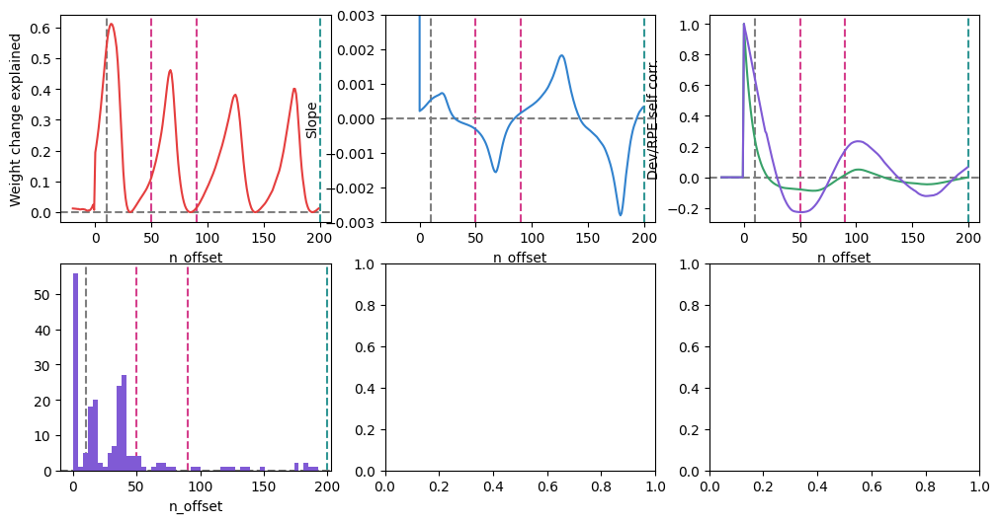

In [ ]:
fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(12, 6))

ax1.plot(n_offsets, var_exps, color=c_vals[0])
ax1.set_ylabel('Weight change explained')

ax2.plot(n_offsets, slopes, color=c_vals[1])
ax2.set_ylabel('Slope')

ax3.plot(n_offsets, dev_self_corrs / np.max(np.abs(dev_self_corrs)), color=c_vals[2])
ax3.plot(n_offsets, rpe_self_corrs / np.max(np.abs(rpe_self_corrs)), color=c_vals[3])
ax3.set_ylabel('Dev/RPE self corr.')

offset_maxes = n_offsets[np.argmax(np.array(rpe_dev_prods), axis=0)]
ax4.hist(offset_maxes, color=c_vals[3], bins=50)

for ax in (ax1, ax2, ax3, ax4):
    ax.axvline(task_params['n_reward_delay'], color='grey', zorder=-5, linestyle='dashed')
    ax.axvline(train_params['n_window_elig'] + task_params['n_reward_delay'], color=c_vals[7], zorder=-5, linestyle='dashed')
    ax.axvline(2 * train_params['n_window_elig'] + task_params['n_reward_delay'], color=c_vals[7], zorder=-5, linestyle='dashed')
    ax.axvline(train_params['n_window_baseline'], color=c_vals[5], zorder=-5, linestyle='dashed')
    ax.set_xlabel('n_offset')
    ax.axhline(0.0, color='grey', zorder=-5, linestyle='dashed')

ax2.set_ylim((-0.003, 0.003))

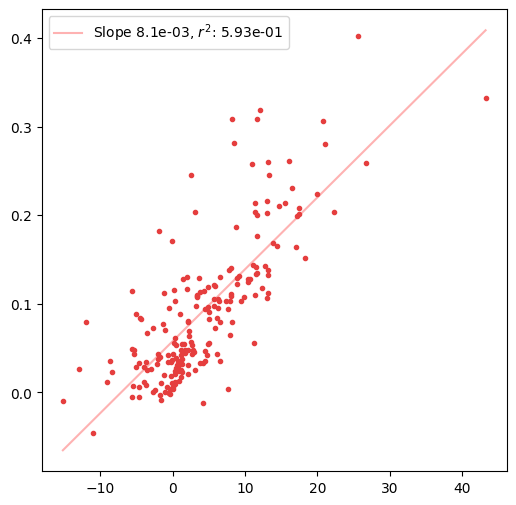

In [ ]:
# max_rpe_dev_prods = np.max(np.array(rpe_dev_prods), axis=0)
max_rpe_dev_prods = np.sum(np.array(rpe_dev_prods), axis=0)
# max_rpe_dev_prods = np.max(np.abs(np.array(rpe_dev_prods)), axis=0)

fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))

ax1.scatter(max_rpe_dev_prods, total_delta_W, marker='.', color=c_vals[0])
_ = add_regression_line(max_rpe_dev_prods, total_delta_W, ax=ax1, color=c_vals_l[0], zorder=-5)

ax1.legend()

Other analyses

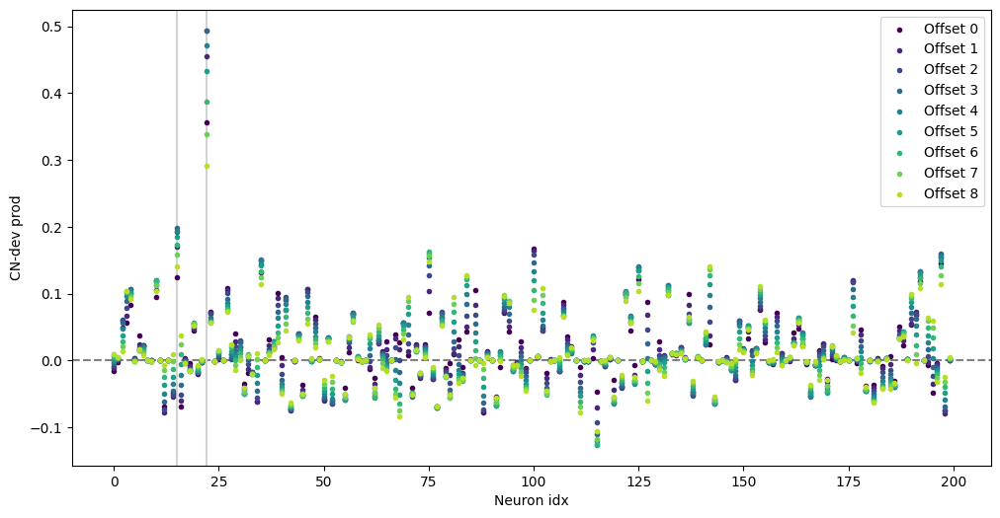

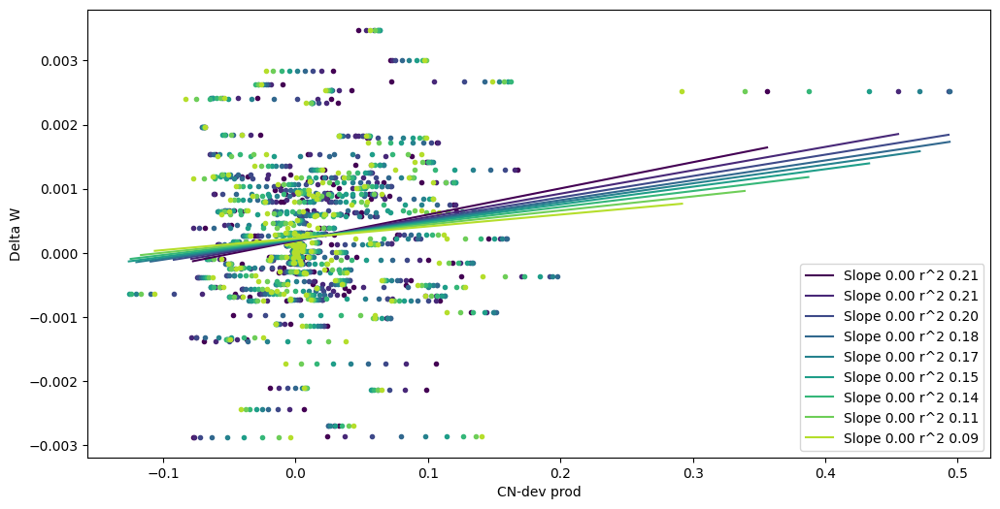

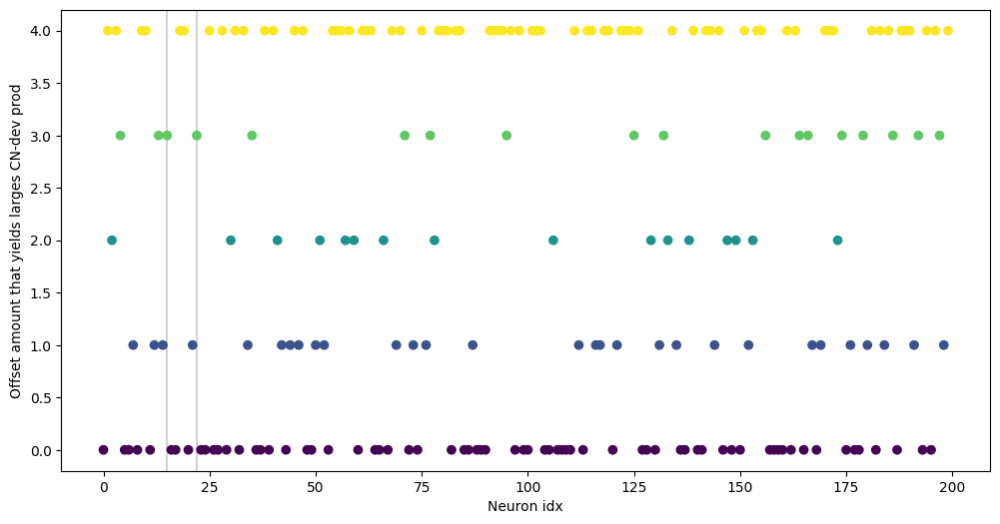

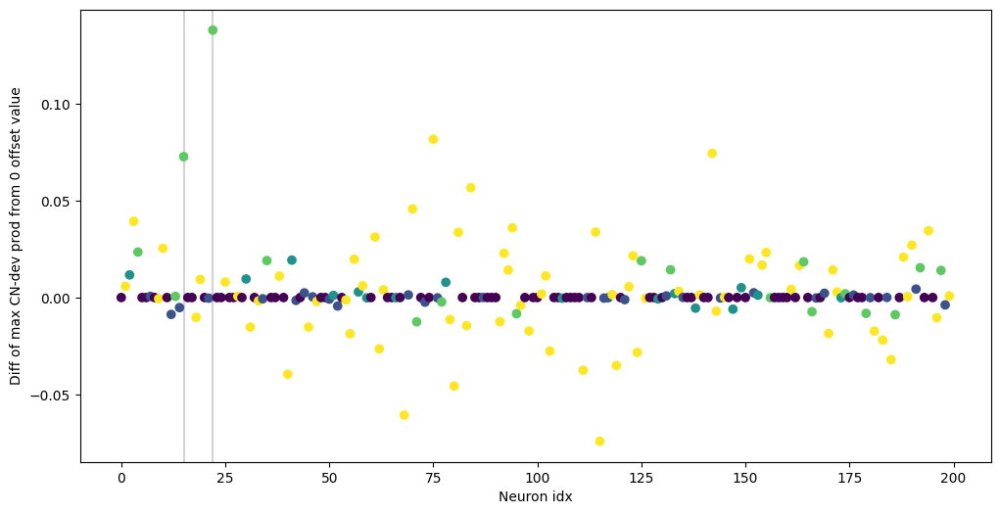

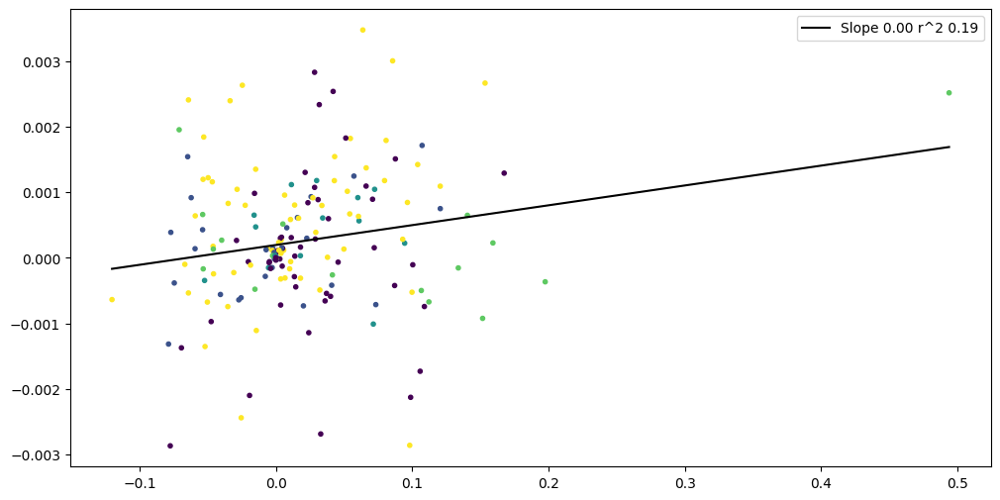

In [ ]:
comparison_type = 'dev-cn_dev' # dev-rpe, dev-cn_dev

fig, ax1 = plt.subplots(1, 1, figsize=(12, 6))
fig2, ax2 = plt.subplots(1, 1, figsize=(12, 6))
fig3, ax3 = plt.subplots(1, 1, figsize=(12, 6))
fig4, ax4 = plt.subplots(1, 1, figsize=(12, 6))
fig5, ax5 = plt.subplots(1, 1, figsize=(12, 6))

max_offset = 9

cmap = plt.get_cmap('viridis')

max_rpe_correlation = np.zeros((task_params['n_neurons'],))
max_rpe_correlation_offset = np.zeros((task_params['n_neurons'],))

for idx_offset in range(max_offset):

    deviation_offset = deviation_trunc[:deviation_trunc.shape[0]-idx_offset]
    if comparison_type == 'dev-rpe':
        label_label = 'RPE-dev prod'
        rpe_offset = rpe_trunc[idx_offset:] # RPE might lag deviation
        rpe_dev_prod_offset = np.matmul(rpe_offset, deviation_offset)
    elif comparison_type == 'dev-cn_dev':
        label_label = 'CN-dev prod'
        cn_dev_offset = deviation_trunc[idx_offset:, cn_idx] # RPE might lag deviation
        rpe_dev_prod_offset = np.matmul(cn_dev_offset, deviation_offset)

        rpe_dev_prod_offset[cn_idx] = 0.

    if idx_offset == 0:
        rpe_dev_prod_zero = np.copy(rpe_dev_prod_offset)
        max_rpe_correlation = np.copy(rpe_dev_prod_offset)
    elif idx_offset < 5:
    # else:
        for neuron_idx in range(task_params['n_neurons']):
            if np.abs(rpe_dev_prod_offset[neuron_idx]) > np.abs(max_rpe_correlation[neuron_idx]):
                max_rpe_correlation[neuron_idx] = rpe_dev_prod_offset[neuron_idx]
                max_rpe_correlation_offset[neuron_idx] = idx_offset

    ax1.scatter(np.arange(task_params['n_neurons']), rpe_dev_prod_offset, marker='.',
                color=cmap(idx_offset / max_offset), label='Offset {}'.format(idx_offset))

    ax2.scatter(rpe_dev_prod_offset, mean_delta_Ws, marker='.', color=cmap(idx_offset / max_offset))
    _ = add_regression_line(rpe_dev_prod_offset, mean_delta_Ws, ax=ax2, color=cmap(idx_offset / max_offset), zorder=5)

diff_from_zero_offset = max_rpe_correlation - rpe_dev_prod_zero

ax1.axhline(0.0, color='grey', linestyle='dashed', zorder=-5)

ax1.set_xlabel('Neuron idx')
ax1.set_ylabel(label_label)
ax1.legend()

ax2.set_xlabel(label_label)
ax2.set_ylabel('Delta W')
ax2.legend()

ax3.scatter(np.arange(task_params['n_neurons']), max_rpe_correlation_offset, c=max_rpe_correlation_offset,
            cmap='viridis')
ax3.set_xlabel('Neuron idx')
ax3.set_ylabel('Offset amount that yields larges {}'.format(label_label))
ax4.scatter(np.arange(task_params['n_neurons']), diff_from_zero_offset, c=max_rpe_correlation_offset,
            cmap='viridis')
ax4.set_xlabel('Neuron idx')
ax4.set_ylabel('Diff of max {} from 0 offset value'.format(label_label))
ax5.scatter(max_rpe_correlation, mean_delta_Ws, c=max_rpe_correlation_offset,
            cmap='viridis', marker='.')
_ = add_regression_line(max_rpe_correlation, mean_delta_Ws, ax=ax5, color='k', zorder=5)
ax5.legend()

for ax in (ax1, ax3, ax4):
    ax.axvline(15, color='lightgrey', zorder=-5)
    ax.axvline(22, color='lightgrey', zorder=-5)

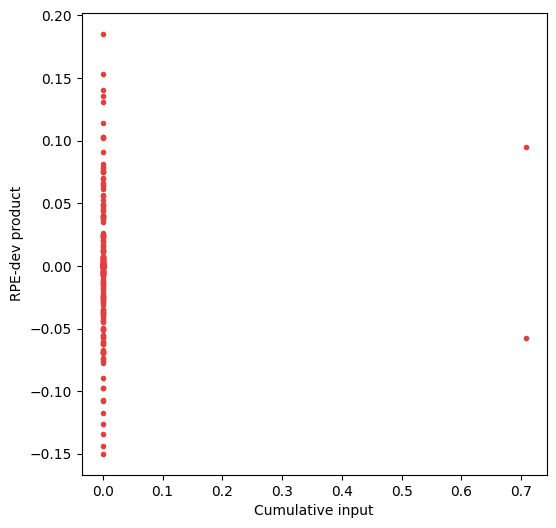

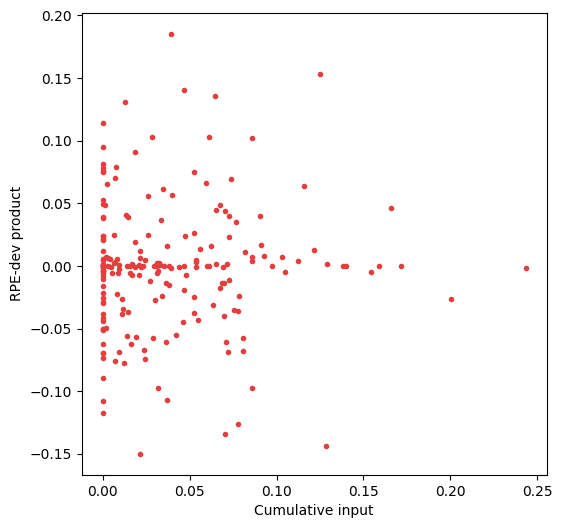

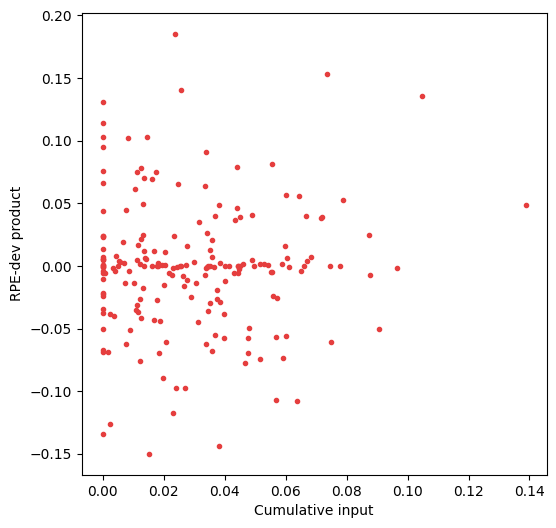

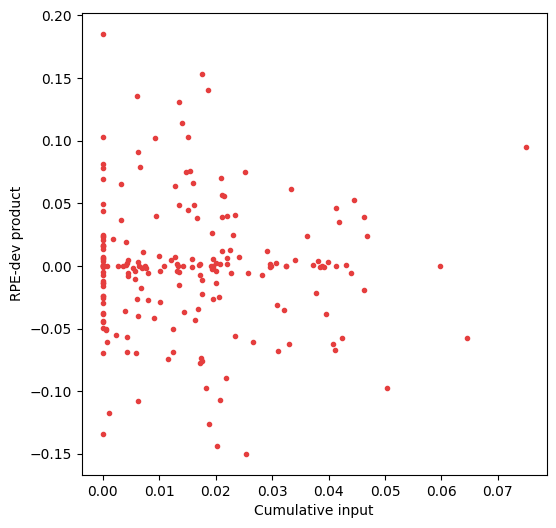

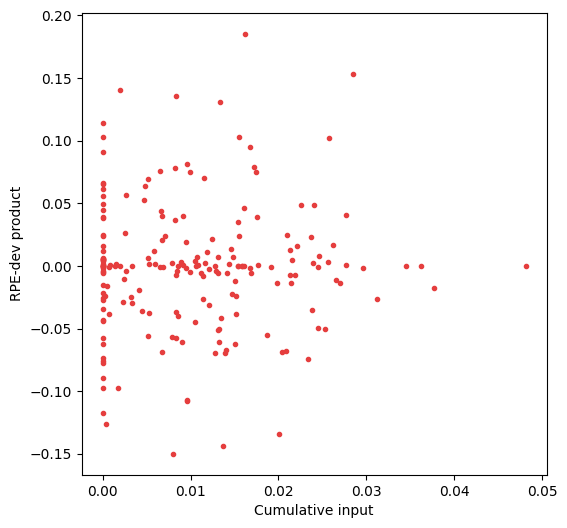

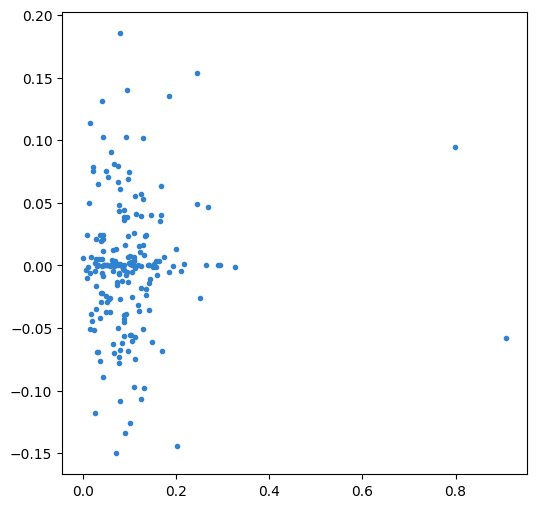

In [ ]:
assert len(cn_idxs) == 1
cn_idx = cn_idxs[0]

w_val_idx = 0 # 0 for initial, or -1 for final
W_rec = W_vals[w_val_idx]

W_rec_cumulative = np.copy(W_rec)
W_rec_cumulative = np.where(W_rec_cumulative >0, W_rec_cumulative, 0.)

activities_stabilize = output[:n_steps_stabilize]
mean_stabilize_activity = np.mean(activities_stabilize, axis=0)

total_cn_input = np.zeros((task_params['n_neurons'],))

for mult_idx in range(5):

    fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))

    total_cn_input += W_rec_cumulative[cn_idx]
    ax1.scatter(W_rec_cumulative[cn_idx], rpe_dev_prod, marker='.', color=c_vals[0])
    # ax1.scatter(np.matmul(W_rec_cumulative, mean_stabilize_activity), rpe_dev_prod, marker='.', color=c_vals[0])
    ax1.set_xlabel('Cumulative input')
    ax1.set_ylabel('RPE-dev product')

    W_rec_cumulative = np.matmul(W_rec, W_rec_cumulative)
    W_rec_cumulative = np.where(W_rec_cumulative >0, W_rec_cumulative, 0.)

fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))
# ax1.scatter(mean_stabilize_activity, rpe_dev_prod, marker='.', color=c_vals[1])
# ax1.scatter(np.matmul(mean_stabilize_activity, W_rec), rpe_dev_prod, marker='.', color=c_vals[1])
ax1.scatter(total_cn_input, rpe_dev_prod, marker='.', color=c_vals[1])

Evaluates how much each neuron contributes to the BCI activity before and after training

Text(0, 0.5, 'BCI activity contribution (post)')

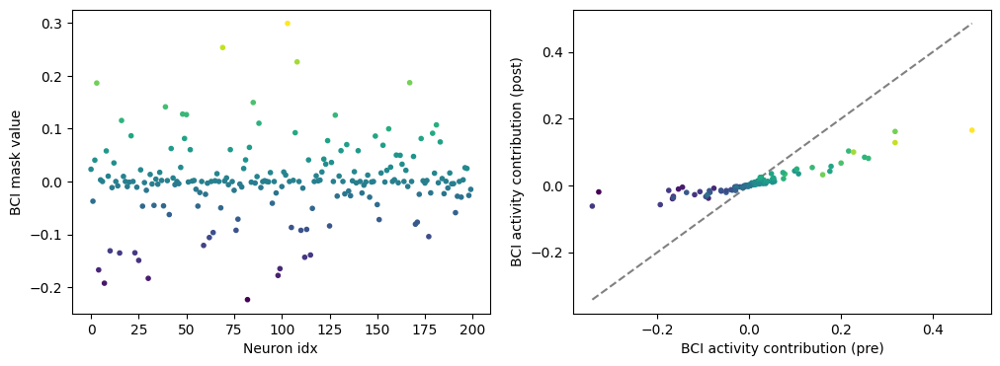

In [ ]:
session_idx = 0
cmap_type = 'viridis'

train_outputs = train_outputs_all[session_idx]

bci_masks = train_outputs['bci_masks']
output = train_outputs['output']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

raise NotImplementedError('Need to generalize this to potentially many BCI masks')

# Visualize BCI mask
ax1.scatter(np.arange(task_params['n_neurons']), bci_mask, c=bci_mask, marker='.', cmap=cmap_type)
ax1.set_xlabel('Neuron idx')
ax1.set_ylabel('BCI mask value')

output_pre = output[:task_params['n_steps_stabilize']]
mean_bci_activity_pre = np.matmul(np.mean(output_pre, axis=0), bci_mask)

bci_contribution_pre = np.mean(output_pre, axis=0) * bci_mask / mean_bci_activity_pre

output_post = output[-1 * task_params['n_steps_stabilize']:]
mean_bci_activity_post = np.matmul(np.mean(output_post, axis=0), bci_mask)

bci_contribution_post = np.mean(output_post, axis=0) * bci_mask / mean_bci_activity_post

ax2.scatter(bci_contribution_pre, bci_contribution_post, c=bci_mask, marker='.', cmap=cmap_type)
min_val = np.minimum(min(bci_contribution_pre), min(bci_contribution_post))
max_val = np.maximum(max(bci_contribution_pre), max(bci_contribution_post))
ax2.plot((min_val, max_val), (min_val, max_val), color='grey', linestyle='dashed', zorder=-5)
ax2.set_xlabel('BCI activity contribution (pre)')
ax2.set_ylabel('BCI activity contribution (post)')

# ax2.scatter(bci_mask, bci_contribution_pre, c=bci_mask, marker='.')
# ax2.set_xlabel('BCI mask value')
# ax2.set_ylabel('BCI activity contribution')

Look at the relative input strengths (takes into account activity AND weights) and the size of just the weights

CN_idx:
 W_inp: -0.01 // W_rec: 0.10


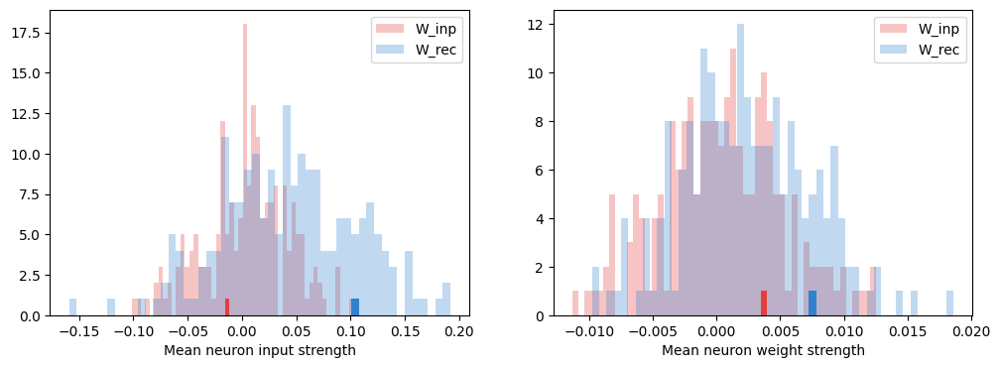

In [ ]:
session_idx = 0

train_outputs = train_outputs_all[session_idx]
inputs_stabilize = train_outputs['net_input'][:task_params['n_steps_stabilize']]
activities_stabilize = train_outputs['output'][:task_params['n_steps_stabilize']]

cn_idx = train_outputs['cn_idxs'][0]

neuron_W_inp_inputs = np.matmul(inputs_stabilize[1:], net.W_inp)
neuron_W_rec_inputs = np.matmul(activities_stabilize[1:], net.W_rec)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

mean_W_inp_input = np.mean(neuron_W_inp_inputs, axis=0)
mean_W_rec_input = np.mean(neuron_W_rec_inputs, axis=0)

_, bins_inp, _ = ax1.hist(mean_W_inp_input, color=c_vals[0], bins=50, alpha=0.3, label='W_inp')
_, bins_rec, _ = ax1.hist(mean_W_rec_input, color=c_vals[1], bins=50, alpha=0.3, label='W_rec')
_ = ax1.hist(mean_W_inp_input[cn_idx], color=c_vals[0], bins=bins_inp, zorder=1)
_ = ax1.hist(mean_W_rec_input[cn_idx], color=c_vals[1], bins=bins_rec, zorder=1)

_, bins_inp, _ = ax2.hist(np.mean(net.W_inp, axis=-1), color=c_vals[0], bins=50, alpha=0.3, label='W_inp')
_, bins_rec, _ = ax2.hist(np.mean(net.W_rec, axis=-1), color=c_vals[1], bins=50, alpha=0.3, label='W_rec')
_ = ax2.hist(np.mean(net.W_inp, axis=-1)[cn_idx], color=c_vals[0], bins=bins_inp, zorder=1)
_ = ax2.hist(np.mean(net.W_rec, axis=-1)[cn_idx], color=c_vals[1], bins=bins_rec, zorder=1)

print('CN_idx:')
print(' W_inp: {:.2f} // W_rec: {:.2f}'.format(
    mean_W_inp_input[cn_idx], mean_W_rec_input[cn_idx]
))

ax1.set_xlabel('Mean neuron input strength')
ax1.legend()

ax2.set_xlabel('Mean neuron weight strength')
ax2.legend()

Look at correlations between neurons and the CN, what the recurrent matrix looks like pre- and post-training, and how the recurrent matrix changes for the CN in particular.

PR: 51.5


/usr/local/lib/python3.10/dist-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.10/dist-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


0.3602342939913664
0.0


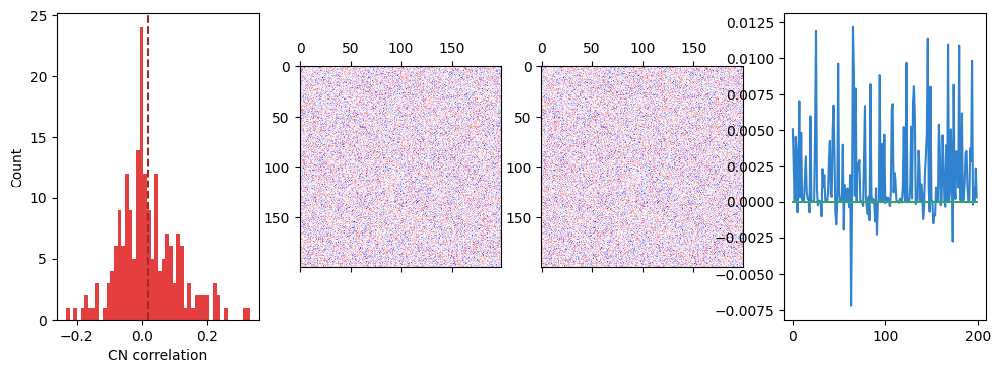

In [ ]:
session_idx = 0

train_outputs = train_outputs_all[session_idx]

if task_params['add_fl']:
    activities_stabilize = train_outputs['output_fl'][:task_params['n_steps_stabilize']]
else:
    activities_stabilize = train_outputs['output'][:task_params['n_steps_stabilize']]

pca = PCA()
pca.fit(activities_stabilize)

print('PR: {:.1f}'.format(participation_ratio_vector(pca.explained_variance_ratio_)))

cn_idxs = train_outputs['cn_idxs']

corrs = np.corrcoef(activities_stabilize.T)

corrs = np.where(np.isnan(corrs), 0., corrs)
corrs = np.where(corrs > 0.95, 0., corrs)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(12, 4))

ax1.hist(corrs[cn_idxs[0]], bins=50, color=c_vals[0])
ax1.axvline(np.mean(corrs[cn_idxs[0]]), linestyle='dashed', color=c_vals_d[0])
ax1.set_xlabel('CN correlation')
ax1.set_ylabel('Count')

init_W_rec= train_outputs['W_rec_vals'][0]
final_W_rec= train_outputs['W_rec_vals'][-1]

max_W_rec = np.max(np.abs(init_W_rec))
ax2.matshow(init_W_rec, vmax=max_W_rec, vmin=-1*max_W_rec, cmap='bwr')

max_W_rec = np.max(np.abs(final_W_rec))
ax3.matshow(final_W_rec, vmax=max_W_rec, vmin=-1*max_W_rec, cmap='bwr')

ax4.plot((final_W_rec - init_W_rec)[cn_idxs[0]], color=c_vals[1])
ax4.plot(((final_W_rec - init_W_rec) * (init_W_rec == 0.).astype(np.int32))[cn_idxs[0]], color=c_vals[2])
print(np.sum((final_W_rec - init_W_rec)[cn_idxs[0]]))
print(np.sum(((final_W_rec - init_W_rec) * (init_W_rec == 0.).astype(np.int32))[cn_idxs[0]]))

Various contributions to hebbian index

--- Session idx 0 ---
Total RPE: 1.10
RPE-delta W correlation 0.91
RPE-delta W correlation (no CN) 0.91


/usr/local/lib/python3.10/dist-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.10/dist-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Full elg - pos 1.00 neg 0.00 zero 0.00
Done!


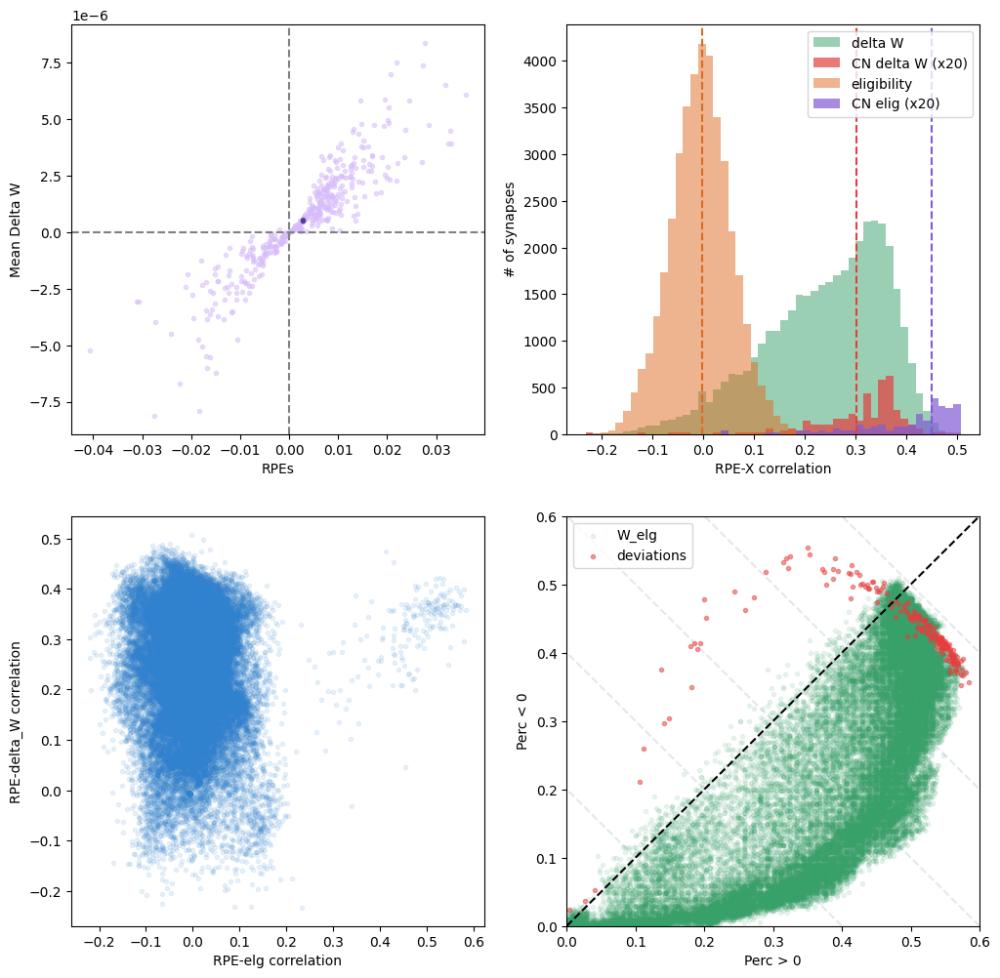

In [ ]:
session_idx = 0
print('--- Session idx {} ---'.format(session_idx))

task_params, train_params, net_params = params

n_neurons = task_params['n_neurons']

train_outputs = train_outputs_all[session_idx]

steps = np.arange(task_params['n_steps'])

cn_idxs = train_outputs['cn_idxs']
output = train_outputs['output']
reward = train_outputs['reward']
avg_activity = train_outputs['avg_activity']
avg_reward = train_outputs['avg_reward']

loss_steps = train_outputs['loss_steps']
total_rpes = train_outputs['total_rpes']

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
    if 'W_inp_elg_vals' in output_vars:
        W_elg_vals = train_outputs['W_inp_elg_vals']
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']
    if 'W_rec_elg_vals' in output_vars:
        W_elg_vals = train_outputs['W_rec_elg_vals']

delta_W_full = W_vals[1:] - W_vals[:-1]
delta_Ws = np.mean(delta_W_full, axis=(1, 2)) # Mean over inputs and outputs
delta_Ws_nocns = np.mean(np.delete(W_vals, cn_idxs, axis=1)[1:] - np.delete(W_vals, cn_idxs, axis=1)[:-1], axis=(1, 2))

print('Total RPE: {:.2f}'.format(np.sum(total_rpes)))
print('RPE-delta W correlation {:.2f}'.format(
    np.corrcoef(total_rpes[1:], delta_Ws)[0, 1]
))
print('RPE-delta W correlation (no CNs) {:.2f}'.format(
    np.corrcoef(total_rpes[1:], delta_Ws_nocns)[0, 1]
))

activity_deviations = output - avg_activity
# total_deviations = []
# # Syncs up deviations with RPE sums by summing in same window as RPE
# for loss_step_idx in range(len(loss_steps)-1):
#     loss_step_end_idx = loss_steps[loss_step_idx] + 1 # Inclusive of this idx, so add 1
#     loss_step_start_idx = loss_step_end_idx - train_params['n_steps_per_loss']

#     total_deviations.append()

rpe_delta_W_corrs = np.zeros((n_neurons, n_neurons,))
rpe_W_elg_corrs = np.zeros((n_neurons, n_neurons,))
W_elg_perc_pos = np.zeros((n_neurons, n_neurons,))
W_elg_perc_neg = np.zeros((n_neurons, n_neurons,))
deviation_perc_pos = np.zeros((n_neurons,))
deviation_perc_neg = np.zeros((n_neurons,))
TOLERANCE = 1e-2
for neuron_idx1 in range(n_neurons):
    for neuron_idx2 in range(n_neurons):
        rpe_delta_W_corrs[neuron_idx1, neuron_idx2] = np.corrcoef(
            total_rpes[1:], delta_W_full[:, neuron_idx1, neuron_idx2]
        )[0, 1]
        W_elg_val = W_elg_vals[1:, neuron_idx1, neuron_idx2]
        if np.std(W_elg_val) > 0: # Some neurons never have eligibility trace
            rpe_W_elg_corrs[neuron_idx1, neuron_idx2] = np.corrcoef(
                total_rpes[1:], W_elg_val
            )[0, 1]

        max_elg = np.max(np.abs(W_elg_val))
        W_elg_perc_pos[neuron_idx1, neuron_idx2] = W_elg_val[W_elg_val > TOLERANCE * max_elg].shape[0] / W_elg_val.shape[0]
        W_elg_perc_neg[neuron_idx1, neuron_idx2] = W_elg_val[W_elg_val < -1 * TOLERANCE * max_elg].shape[0] / W_elg_val.shape[0]

    deviation_val = activity_deviations[:, neuron_idx1]
    max_dev = np.max(np.abs(deviation_val))

    deviation_perc_pos[neuron_idx1] = deviation_val[deviation_val > TOLERANCE * max_dev].shape[0] / deviation_val.shape[0]
    deviation_perc_neg[neuron_idx1] = deviation_val[deviation_val < -1 * TOLERANCE * max_dev].shape[0] / deviation_val.shape[0]

W_elg_val = np.mean(W_elg_vals, axis=(1, 2))
max_elg = np.max(np.abs(W_elg_val))
W_elg_full_perc_pos = W_elg_val[W_elg_val > TOLERANCE * max_elg].shape[0] / W_elg_val.shape[0]
W_elg_full_perc_neg = W_elg_val[W_elg_val < -1 * TOLERANCE * max_elg].shape[0] / W_elg_val.shape[0]
print('Full elg - pos {:.2f} neg {:.2f} zero {:.2f}'.format(
    W_elg_full_perc_pos,
    W_elg_full_perc_neg,
    1. - W_elg_full_perc_pos - W_elg_full_perc_neg,
))


fig2, ((ax4, ax5), (ax6, ax7)) = plt.subplots(2, 2, figsize=(12, 12))

ax4.scatter(total_rpes[1:], delta_Ws, color=c_vals_l[3], alpha=0.5, marker='.')
ax4.scatter(np.mean(total_rpes[1:]), np.mean(delta_Ws), color=c_vals[3], marker='.')
ax4.scatter(np.mean(total_rpes[1:]), np.mean(delta_Ws_nocn), color=c_vals_d[3], marker='.')
ax4.axhline(0.0, color='grey', linestyle='dashed')
ax4.axvline(0.0, color='grey', linestyle='dashed')

_, bins, _ = ax5.hist(rpe_delta_W_corrs.reshape(-1), color=c_vals[2], bins=50, alpha=0.5, label='delta W')
# _ = ax5.hist(rpe_delta_W_corrs[cn_idx, :], color=c_vals[0], bins=bins, alpha=0.7, label='CN delta W')
_ = ax5.hist(rpe_delta_W_corrs[cn_idx, :], color=c_vals[0], bins=bins, alpha=0.7, label='CN delta W (x{:.0f})'.format(n_neurons/10),
             weights=n_neurons/10 * np.ones((n_neurons,)))
_ = ax5.hist(rpe_W_elg_corrs.reshape(-1), color=c_vals[4], bins=bins, alpha=0.5, label='eligibility')
# _ = ax5.hist(rpe_W_elg_corrs[cn_idx, :], color=c_vals[3], bins=bins, alpha=0.7, label='CN elig')
_ = ax5.hist(rpe_W_elg_corrs[cn_idx, :], color=c_vals[3], bins=bins, alpha=0.7, label='CN elig (x{:.0f})'.format(n_neurons/10),
             weights=n_neurons/10 * np.ones((n_neurons,)))
ax5.axvline(np.mean(rpe_delta_W_corrs), color=c_vals[2], linestyle='dashed')
ax5.axvline(np.mean(rpe_delta_W_corrs[cn_idx, :]), color=c_vals[0], linestyle='dashed')
ax5.axvline(np.mean(rpe_W_elg_corrs), color=c_vals[4], linestyle='dashed')
ax5.axvline(np.mean(rpe_W_elg_corrs[cn_idx, :]), color=c_vals[3], linestyle='dashed')

ax6.scatter(rpe_W_elg_corrs.reshape(-1), rpe_delta_W_corrs.reshape(-1), color=c_vals[1], marker='.', alpha=0.1)

# ax7.scatter(W_elg_perc_pos.reshape(-1), W_elg_perc_neg.reshape(-1), c=W_rec_vals[0, :, :].reshape(-1), marker='.', alpha=0.1,
#             cmap='viridis')
ax7.scatter(W_elg_perc_pos.reshape(-1), W_elg_perc_neg.reshape(-1), color=c_vals[2], marker='.', alpha=0.1,
            label='W_elg')
ax7.scatter(deviation_perc_pos, deviation_perc_neg, marker='.', alpha=0.5, color=c_vals[0], label='deviations')

for perc_zero in (0.2, 0.4, 0.6, 0.8, 1.0):
    ax7.plot((perc_zero, 0), (0, perc_zero), color=c_vals_l[6], zorder=-1, linestyle='dashed')
ax7.plot((0., 0.7), (0.0, 0.7), color='k', zorder=5, linestyle='dashed')

ax4.set_xlabel('RPEs')
ax4.set_ylabel('Mean Delta W')

ax5.set_xlabel('RPE-X correlation')
ax5.set_ylabel('# of synapses')
ax5.legend()

ax6.set_xlabel('RPE-elg correlation')
ax6.set_ylabel('RPE-delta_W correlation')

ax7.set_xlabel('Perc > 0')
ax7.set_ylabel('Perc < 0')
ax7.set_xlim((0, 0.6))
ax7.set_ylim((0, 0.6))
ax7.legend()

# These are big, so delele them
del activity_deviations
del W_rec_vals
del delta_W_full
del W_elg_vals

print('Done!')

Compute total eligibiltiy traces

Note the naming conventions here don't really make sense, they're named for recurrent but apply to both input and recurrent, depending on what is being trained.

In [ ]:
session_idx = 0

train_outputs = train_outputs_all[session_idx]

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
    W_rec_final = train_outputs['W_inp_vals'][-1]
    if 'W_inp_elg_vals' in output_vars:
        W_elg_vals = train_outputs['W_inp_elg_vals'][1:] # Don't include first value
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']
    W_rec_final = train_outputs['W_rec_vals'][-1]
    if 'W_rec_elg_vals' in output_vars:
        W_elg_vals = train_outputs['W_rec_elg_vals'][1:]

# Redo some computations to see how eligibility trace would have been different with different values
W_rec_elg = np.zeros((task_params['n_neurons'], task_params['n_neurons'],)) # Full reconstruction
W_elg_values_reconstruct = []
W_rec_elg_no_phi_p = np.zeros((task_params['n_neurons'], task_params['n_neurons'],)) # No phi prime contribution
W_elg_values_no_phi_p = []

for step_idx in range(task_params['n_steps']):
    if step_idx < task_params['n_steps_stabilize']:
        continue

    output_deviation = train_outputs['output'][step_idx] - train_outputs['avg_activity'][step_idx]
    act_fn_p_pre_act = train_outputs['act_fn_p_pre_act_vals'][step_idx]
    prev_activity = train_outputs['output'][step_idx-1]

    delta_W_rec = output_deviation[:, np.newaxis] * (
                    act_fn_p_pre_act[:, np.newaxis] * prev_activity[np.newaxis, :]
                  )
    # delta_W_rec_no_phi_p = output_deviation[:, np.newaxis] * (
    #                 (act_fn_p_pre_act > 0).astype(float)[:, np.newaxis] * prev_activity[np.newaxis, :]
    #               )
    delta_W_rec_no_phi_p = output_deviation[:, np.newaxis] * prev_activity[np.newaxis, :]

    raise NotImplementedError('Double check this calculation now')
    W_rec_elg += net_params['leak_term'] * W_rec_elg + (1. - net_params['leak_term']) * delta_W_rec
    W_rec_elg_no_phi_p += net_params['leak_term'] * W_rec_elg_no_phi_p + (1. - net_params['leak_term']) * delta_W_rec_no_phi_p

    if step_idx in train_outputs['loss_steps']:
        # print('loss adjust:')
        # print(W_rec_elg[:5, :5])
        # print(train_outputs['W_rec_elg_vals'][1, :5, :5])
        # print(sdfdsfsd)
        W_elg_values_reconstruct.append(W_rec_elg)
        W_elg_values_no_phi_p.append(W_rec_elg_no_phi_p)

        # Reset now
        W_rec_elg = np.zeros_like(W_rec_elg)
        W_rec_elg_no_phi_p = np.zeros_like(W_rec_elg_no_phi_p)

mean_elg = np.mean(W_elg_vals, axis=0)
mean_elg_reconstruct = np.mean(W_elg_values_reconstruct, axis=0)
mean_elg_no_phi_p = np.mean(W_elg_values_no_phi_p, axis=0)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

_, bins, _ = ax1.hist(mean_elg.reshape(-1), bins=55, color=c_vals[1], alpha=0.3, label='full elig: {:.1e}'.format(np.mean(mean_elg)))
ax1.axvline(np.mean(mean_elg), color=c_vals[1], linestyle='dashed')
print('Overall mean elg: {:.3e}'.format(np.mean(mean_elg)))

# # Check reconstruct
# _, bins, _ = ax1.hist(mean_elg_reconstruct.reshape(-1), bins=55, color=c_vals[0], alpha=0.3)
# ax1.axvline(np.mean(mean_elg_reconstruct), color=c_vals[0], linestyle='dashed')

# Check no phi prime contribution
_, _, _ = ax1.hist(mean_elg_no_phi_p.reshape(-1), bins=bins, color=c_vals[2], alpha=0.3, label='no $\phi^\prime$ elig: {:.1e}'.format(np.mean(mean_elg_no_phi_p)))
ax1.axvline(np.mean(mean_elg_no_phi_p), color=c_vals[2], linestyle='dashed')
print('Overall mean elg, no phi prime: {:.3e}'.format(np.mean(mean_elg_no_phi_p)))

# Full, separated by final synapse sign
bottoms, _, _ = ax2.hist(mean_elg[W_rec_final > 0], bins=bins, color=c_vals[0], alpha=0.3, label='full elig, pos. syn.')
ax2.axvline(np.mean(mean_elg[W_rec_final > 0]), color=c_vals[0], linestyle='dashed')
_, _, _ = ax2.hist(mean_elg[W_rec_final < 0], bins=bins, color=c_vals[1], bottom=bottoms, alpha=0.3, label='full elig, neg. syn.')
ax2.axvline(np.mean(mean_elg[W_rec_final < 0]), color=c_vals[1], linestyle='dashed')

# No phi prime, separated by final synapse sign
bottoms, _, _ = ax3.hist(mean_elg_no_phi_p[W_rec_final > 0], bins=bins, color=c_vals[0], alpha=0.3, label='no $\phi^\prime$ elig, pos. syn.')
ax3.axvline(np.mean(mean_elg_no_phi_p[W_rec_final > 0]), color=c_vals[0], linestyle='dashed')
_, _, _ = ax3.hist(mean_elg_no_phi_p[W_rec_final < 0], bins=bins, color=c_vals[1], bottom=bottoms, alpha=0.3, label='no $\phi^\prime$ elig, neg. syn.')
ax3.axvline(np.mean(mean_elg_no_phi_p[W_rec_final < 0]), color=c_vals[1], linestyle='dashed')

for ax in (ax1, ax2, ax3):
    ax.axvline(0.0, color='grey', linestyle='dashed', zorder=-5)
    ax.legend()
    ax.set_xlabel('Mean elg.')
    ax.set_ylabel('# of synapses')

NameError: name 'prev_W_rec_elg' is not defined

View an individual neuron's eligibility and delta W versus RPE signal

Mean weight 7.04e-03
Eligibility - pos 0.38 neg 0.57 zero 0.05


ValueError: operands could not be broadcast together with shapes (475,) (400,) 

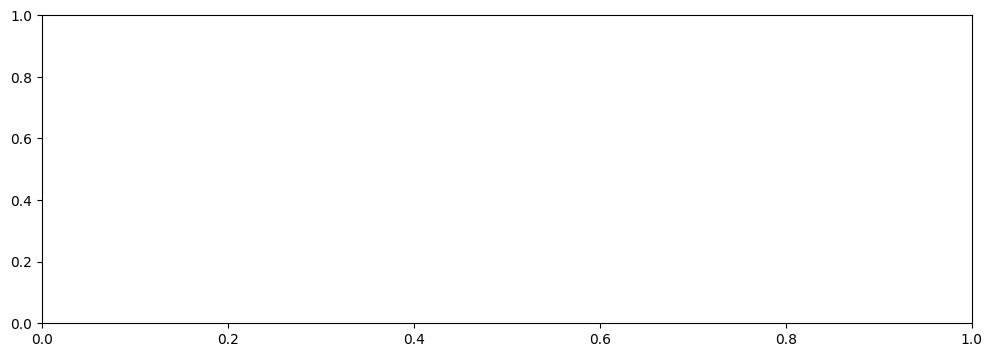

In [ ]:
neuron_idx = 407

W_elg = W_elg_vals.reshape((W_elg_vals.shape[0], -1))[:, neuron_idx]
delta_W = delta_W_full.reshape((delta_W_full.shape[0], -1))[:, neuron_idx]
max_elg = np.max(np.abs(W_elg))

perc_pos =  W_elg[W_elg > 1e-2 * max_elg].shape[0]/W_elg.shape[0]
perc_neg =  W_elg[W_elg < -1e-2 * max_elg].shape[0]/W_elg.shape[0]

print('Mean weight {:.2e}'.format(np.mean(W_rec_vals.reshape((W_rec_vals.shape[0], -1))[:, neuron_idx])))
print('Eligibility - pos {:.2f} neg {:.2f} zero {:.2f}'.format(
    perc_pos,
    perc_neg,
    1. - perc_pos - perc_neg,
))
fig, ax1 = plt.subplots(1, 1, figsize=(12, 4))

rpe_norm = total_rpes[1:] / np.max(np.abs(total_rpes))
W_elg_norm = W_elg / (np.max(np.abs(W_elg)))
delta_W_norm = delta_W / (np.max(np.abs(delta_W)))

reconstruct = total_rpes[1:] * W_elg_vals.reshape((W_elg_vals.shape[0], -1))[:, neuron_idx]

reconstruct_norm = reconstruct / np.max(np.abs(reconstruct))

ax1.plot(rpe_norm, color=c_vals[0], label='RPE')
ax1.plot(W_elg_norm, color=c_vals[1], label='elig')
ax1.plot(delta_W_norm, color=c_vals[2], label='delta W')
# ax1.plot(reconstruct_norm, color=c_vals[3], label='reconstruct')

print('RPE- delta W correlation: {:.2f}'.format(np.corrcoef(total_rpes[1:], delta_W)[0, 1]))

ax1.legend()

Changes in W_rec and W_inp along with activity distribution

<ipython-input-2-37c67a897238>:140: RuntimeWarning: invalid value encountered in divide
  return np.where(outer > 0., np.matmul(x, y.T) / outer, np.nan)


Hebbian idx: 0.03


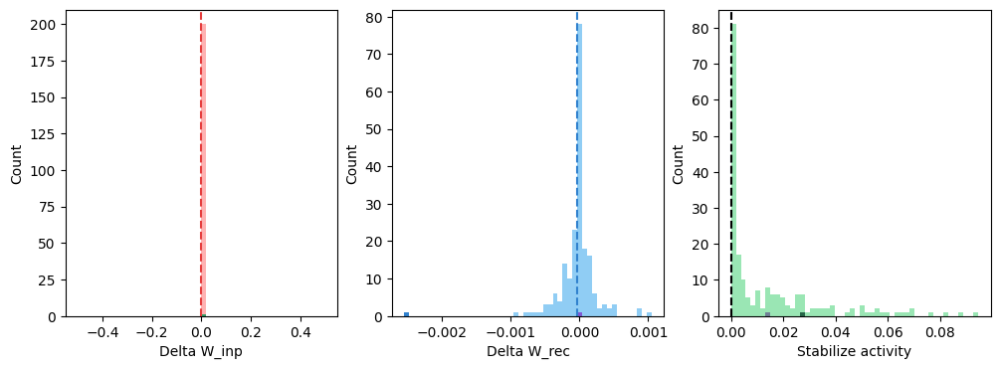

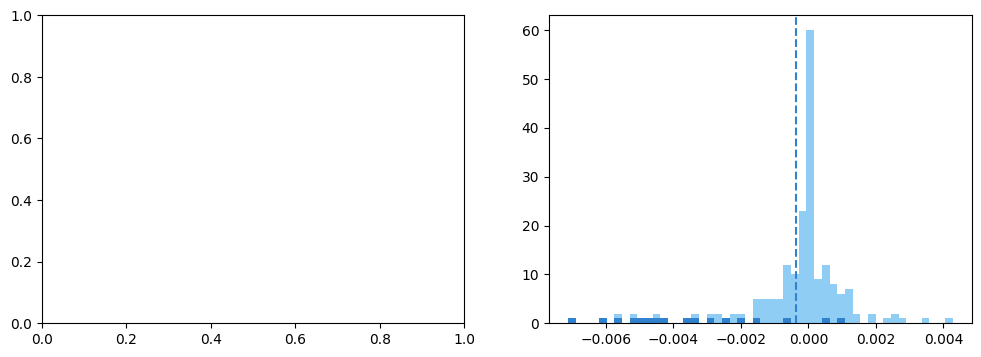

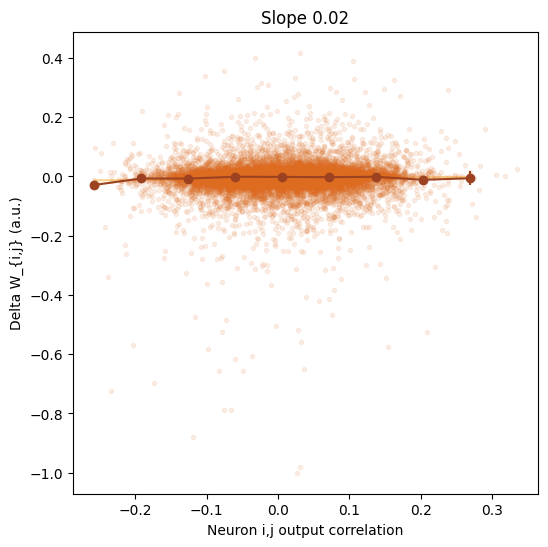

In [ ]:
session_idx = 19

train_outputs = train_outputs_all[session_idx]
cn_idx = train_outputs['cn_idx']

if session_idx > 0:
    prev_cn_idx = train_outputs_all[session_idx-1]['cn_idx']


fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))
fig, (ax4, ax5) = plt.subplots(1, 2, figsize=(12, 4))

if 'W_inp_vals' in train_outputs:
    W_inp_vals = train_outputs['W_inp_vals']
    delta_W_inp = W_inp_vals[-1, :, :] - W_inp_vals[0, :, :]

    _, bins, _ = ax1.hist(np.mean(delta_W_inp, axis=-1), bins=50, color=c_vals_l[0])
    _ = ax1.hist(np.mean(delta_W_inp[cn_idx, :], axis=-1), bins=bins, color=c_vals[0])
    if session_idx > 0:
        _ = ax1.hist(np.mean(delta_W_inp[prev_cn_idx, :], axis=-1), bins=bins, color=c_vals[2])
    ax1.axvline(np.mean(delta_W_inp), color=c_vals[0], linestyle='dashed')

if 'W_rec_vals' in train_outputs:
    W_rec_vals = train_outputs['W_rec_vals']
    delta_W_rec = W_rec_vals[-1, :, :] - W_rec_vals[0, :, :]

    _, bins, _ = ax2.hist(np.mean(delta_W_rec, axis=-1), bins=50, color=c_vals_l[1])
    _ = ax2.hist(np.mean(delta_W_rec[cn_idx, :], axis=-1), bins=bins, color=c_vals[1])
    if session_idx > 0:
        _ = ax2.hist(np.mean(delta_W_rec[prev_cn_idx, :], axis=-1), bins=bins, color=c_vals[3])
    ax2.axvline(np.mean(delta_W_rec), color=c_vals[1], linestyle='dashed')

    W_rec_init = train_outputs_all[0]['W_rec_vals'][-1] # W_rec from end of first session
    delta_W_rec_full = W_rec_vals[-1, :, :] - W_rec_init

    _, bins, _ = ax5.hist(np.mean(delta_W_rec_full, axis=-1), bins=50, color=c_vals_l[1])
    for session_idx2 in range(session_idx+1): # Color all previous CN_idxs and current one
        cn_idx_session = train_outputs_all[session_idx2]['cn_idx']
        _ = ax5.hist(np.mean(delta_W_rec_full[cn_idx_session, :], axis=-1), bins=bins, color=c_vals[1])
    ax5.axvline(np.mean(delta_W_rec_full), color=c_vals[1], linestyle='dashed')

_, bins, _ = ax3.hist(train_outputs['mean_stabilize_actvities'],  bins=50, color=c_vals_l[2])
_ = ax3.hist(train_outputs['mean_stabilize_actvities'][cn_idx], bins=bins, color=c_vals_d[2])
if session_idx > 0:
    _ = ax3.hist(train_outputs['mean_stabilize_actvities'][prev_cn_idx], bins=bins, color=c_vals[6])
    ax3.axvline(train_outputs_all[session_idx-1]['threshold'], color=c_vals[6], linestyle='dashed')

ax3.axvline(train_outputs['threshold'], color='k', linestyle='dashed')

ax1.set_xlabel('Delta W_inp')
ax1.set_ylabel('Count')

ax2.set_xlabel('Delta W_rec')
ax2.set_ylabel('Count')

ax3.set_xlabel('Stabilize activity')
ax3.set_ylabel('Count')

hebbian_idx, _ = bci_analysis.get_hebbian_idx(
    train_outputs, params, activity_type = 'raw_activity',
    plot_visualization=True
)

print('Hebbian idx: {:.2f}'.format(hebbian_idx))

Try to understand how eligibility traces scale as a function of the neuron activity

 Threshold set to 0.09 width 0.01 reward scale 0.03 max activity 0.19
 Threshold set to 0.03 width 0.01 reward scale 0.00 max activity 0.06
 Threshold set to 0.02 width 0.00 reward scale 0.00 max activity 0.04
 Threshold set to 0.20 width 0.02 reward scale 0.12 max activity 0.42
 Threshold set to 0.01 width 0.00 reward scale 0.00 max activity 0.02
 Threshold set to 0.13 width 0.02 reward scale 0.04 max activity 0.28
 Threshold set to 0.09 width 0.01 reward scale 0.03 max activity 0.18
 Threshold set to 0.10 width 0.02 reward scale 0.03 max activity 0.21
 Threshold set to 0.01 width 0.00 reward scale 0.00 max activity 0.02
 Threshold set to 0.11 width 0.02 reward scale 0.05 max activity 0.25
 Threshold set to 0.00 width 0.00 reward scale 0.00 max activity 0.00
Skipping idx 10 threshold is zero.
 Threshold set to 0.11 width 0.01 reward scale 0.05 max activity 0.23
 Threshold set to 0.02 width 0.00 reward scale 0.00 max activity 0.04
 Threshold set to 0.08 width 0.02 reward scale 0.01 max

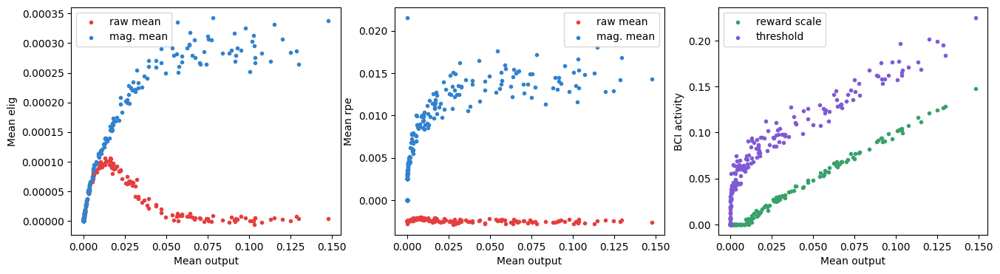

In [ ]:
assert train_params['eta'] == 0. # This only makes sense for no training

session_idx = 0


train_outputs = train_outputs_all[session_idx]

output = train_outputs['output']
activities_stabilize = output[:task_params['n_steps_stabilize']]
# reward = train_outputs['reward'] # True reward
# avg_reward = train_outputs['avg_reward'] # True reward

if task is not None:
    raise NotImplementedError('Need to adapt code to incorporate task-dependence')

rpes_cn_idxs = np.zeros((task_params['n_steps'], task_params['n_neurons'],))
reward_scale_cn_idxs = np.zeros((task_params['n_neurons'],))
threshold_cn_idxs = np.zeros((task_params['n_neurons'],))

for cn_idx in range(task_params['n_neurons']):

    task_params_copy = copy.deepcopy(task_params)

    bci_mask = np.zeros((task_params['n_neurons'],))
    bci_mask[cn_idx]= 1.0

    task_params_copy['bci_mask'] = bci_mask
    task_params_copy['threshold'] = None
    task_params_copy['width'] = None

    # Set the difficulty of the task based on stabilization activity
    task_params_copy, task = set_task_difficulty(activities_stabilize, task_params_copy, task=task, verbose=True)

    reward_scale_cn_idxs[cn_idx] = task_params_copy['reward_scale']
    threshold_cn_idxs[cn_idx] = task_params_copy['threshold']

    if task_params_copy['threshold'] == 0.0:
        print('Skipping idx {} threshold is zero.'.format(cn_idx))
        continue

    reward_bci_mask = np.zeros((task_params['n_steps'],))
    avg_reward_bci_mask = np.zeros((task_params['n_steps'],))

    # Retroactively calculate what the rewards would have been during entire trial
    for step_idx in range(task_params['n_reward_delay'], task_params['n_steps']):
        if step_idx == 0:
            prev_reward = 0
        else:
            prev_reward = avg_reward_bci_mask[step_idx - 1]

        reward_bci_mask[step_idx ] = get_reward(
            output[step_idx - task_params['n_reward_delay']], task_params_copy, bci_mask=task_params_copy['bci_mask'],
            task=task, seq_idx=step_idx
        )

        avg_reward_bci_mask[step_idx] = accumulate_decay(
            prev_reward, reward_bci_mask[step_idx], n_window=train_params['n_window_reward']
        )

    rpes_cn_idxs[:, cn_idx] = reward_bci_mask - avg_reward_bci_mask

mean_output = np.mean(output, axis=0) # Mean over time steps

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
    W_elg = train_outputs['W_inp_elg_vals']
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']
    W_elg = train_outputs['W_rec_elg_vals']

mean_elg = np.mean(W_elg, axis=(0, 2)) # Mean over time steps and presynaptic neuron
mean_elg_mag = np.mean(np.abs(W_elg), axis=(0, 2))

mean_rpe = np.mean(rpes_cn_idxs, axis=0)
mean_rpe_mag = np.mean(np.abs(rpes_cn_idxs), axis=0)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4))

ax1.scatter(mean_output, mean_elg, marker='.', color=c_vals[0], label='raw mean')
ax1.scatter(mean_output, mean_elg_mag, marker='.', color=c_vals[1], label='mag. mean')

ax1.set_ylabel('Mean elig')

ax2.scatter(mean_output, mean_rpe, marker='.', color=c_vals[0], label='raw mean')
ax2.scatter(mean_output, mean_rpe_mag, marker='.', color=c_vals[1], label='mag. mean')

ax2.set_ylabel('Mean rpe')

ax3.scatter(mean_output, reward_scale_cn_idxs, marker='.', color=c_vals[2], label='reward scale')
ax3.scatter(mean_output, threshold_cn_idxs, marker='.', color=c_vals[3], label='threshold')

ax3.set_ylabel('BCI activity')

for ax in (ax1, ax2, ax3):
    ax.set_xlabel('Mean output')
    ax.legend()

Look at Hebbian idx of the conditioned neuron only

Hebbian idx: 0.62


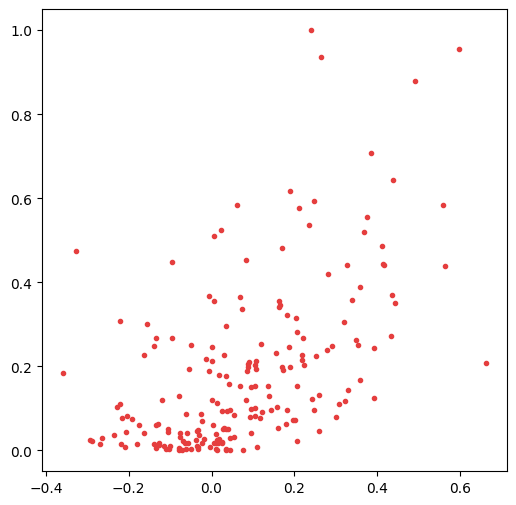

In [ ]:
session_idx = 1

train_outputs = train_outputs_all[session_idx]
cn_idx = train_outputs['cn_idx']

step_idxs = None

if step_idxs is None: # Full current session by default
    output_trunc = train_outputs['output'][task_params['n_steps_stabilize']:]
else: # Local part of time steps
    output_trunc = train_outputs['output'][step_idxs[0]:step_idxs[1]]
    print('Clipping from {} to {}'.format(step_idxs[0], step_idxs[1]))

output_corrs = custom_corrcoef(output_trunc.T[:, 1:], output_trunc.T[:, :-1]) # (n_neurons, n_neurons)

delta_W_rec = train_outputs['delta_W_rec'] # (n_neurons, n_neurons)
# else:
#     print('Using passed W_rec')
# delta_W_rec = W_rec_vals[-1, :, :] - W_rec_vals[0, :, :] # (n_neurons, n_neurons)

output_corrs_flat = []
output_corrs_sum = np.zeros((output_corrs.shape[0],))
delta_W_rec_flat = []
delta_W_rec_sum = np.zeros((output_corrs.shape[0],))
neuron_idx1 = cn_idx
for neuron_idx2 in range(output_corrs.shape[0]):
    if neuron_idx1 != neuron_idx2: # Skip diagonals
        if np.isnan(output_corrs[neuron_idx1, neuron_idx2]):
            continue
        output_corrs_flat.append(output_corrs[neuron_idx1, neuron_idx2])
        delta_W_rec_flat.append(delta_W_rec[neuron_idx1, neuron_idx2])
        output_corrs_sum[neuron_idx1] += output_corrs[neuron_idx1, neuron_idx2]
        delta_W_rec_sum[neuron_idx1] += delta_W_rec[neuron_idx1, neuron_idx2]

delta_W_rec_flat = delta_W_rec_flat / np.max(np.abs(delta_W_rec_flat)) # Normalizes so maximum is 1

assert not np.isnan(output_corrs_flat).any()
assert not np.isnan(delta_W_rec_flat).any()

# corr_coef = np.corrcoef(output_corrs_flat, delta_W_rec_flat)[0, 1]
# corr_coef = np.corrcoef(output_corrs_sum, delta_W_rec_sum)[0, 1]
corr_coef = np.dot(output_corrs_flat, delta_W_rec_flat) / (
    np.linalg.norm(output_corrs_flat) * np.linalg.norm(delta_W_rec_flat)
)

print('Hebbian idx: {:.2f}'.format(corr_coef))

fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))
ax1.scatter(output_corrs_flat, delta_W_rec_flat, marker='.', color=c_vals[0])

Plots some metrics as a function of the training time

<ipython-input-123-04e728378d74>:28: RuntimeWarning: invalid value encountered in divide
  np.matmul(deviation_trunc.T, deviation_trunc) / np.outer(deviation_mag, deviation_mag),
<ipython-input-123-04e728378d74>:33: RuntimeWarning: invalid value encountered in divide
  np.matmul(rpe_trunc, deviation_trunc) / (deviation_mag * np.linalg.norm(rpe_trunc)),


Idx start 0 idx end 50


<ipython-input-39-0353d743cb1f>:183: RuntimeWarning: invalid value encountered in divide
  return np.where(outer > 0., np.matmul(x, y.T) / outer, np.nan)
<ipython-input-123-04e728378d74>:95: RuntimeWarning: invalid value encountered in divide
  rpe_divs[division_idx] / (deviation_mag * np.linalg.norm(rpe_trunc)),
<ipython-input-123-04e728378d74>:108: RuntimeWarning: divide by zero encountered in divide
  rpe_elg_divs[division_idx, neuron_idx] / (W_elg_mag[neuron_idx] * np.linalg.norm(total_rpes_trunc)),
<ipython-input-123-04e728378d74>:105: RuntimeWarning: Mean of empty slice
  corrcoef_rpe_elg_divs[division_idx, neuron_idx] = np.nanmean(custom_corrcoef(W_elg_trunc[:, neuron_idx].T, total_rpes_trunc[np.newaxis, :])[:, 0])
<ipython-input-123-04e728378d74>:108: RuntimeWarning: invalid value encountered in divide
  rpe_elg_divs[division_idx, neuron_idx] / (W_elg_mag[neuron_idx] * np.linalg.norm(total_rpes_trunc)),


Idx start 50 idx end 100
Idx start 100 idx end 150
Idx start 150 idx end 200
Idx start 200 idx end 250
Idx start 250 idx end 300
Idx start 300 idx end 350
Idx start 350 idx end 400


<ipython-input-39-0353d743cb1f>:183: RuntimeWarning: divide by zero encountered in divide
  return np.where(outer > 0., np.matmul(x, y.T) / outer, np.nan)


Idx start 400 idx end 450
Idx start 450 idx end 500


<ipython-input-123-04e728378d74>:177: RuntimeWarning: invalid value encountered in divide
  delta_W_divs = delta_W_divs / np.max(np.abs(delta_W_divs))


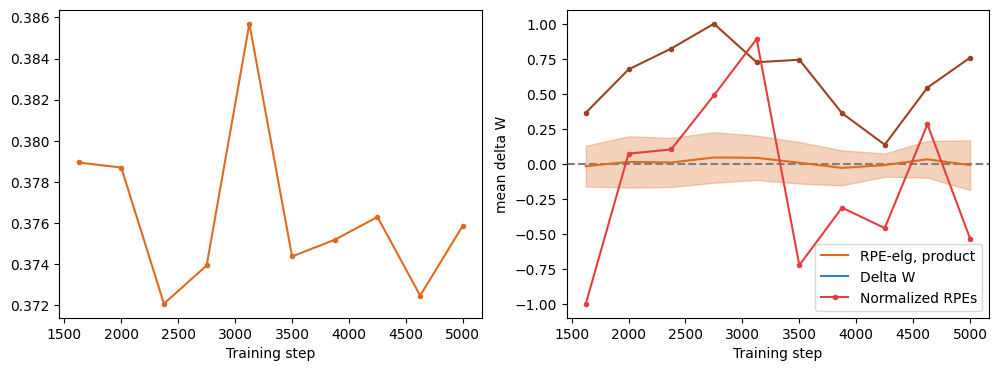

In [ ]:
session_idx = 0
train_outputs = train_outputs_all[session_idx]

cn_idx = train_outputs['cn_idx']
cn_idx2 = train_outputs['cn_idx2']
output = train_outputs['output']
reward = train_outputs['reward']
total_rpes = train_outputs['total_rpes']
avg_activity = train_outputs['avg_activity']
avg_reward = train_outputs['avg_reward']

deviation_trunc = output[task_params['n_steps_stabilize']:] - avg_activity[task_params['n_steps_stabilize']:]
rpe_trunc = reward[task_params['n_steps_stabilize']:] - avg_reward[task_params['n_steps_stabilize']:]

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
    W_elg = train_outputs['W_inp_elg_vals']
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']
    W_elg = train_outputs['W_rec_elg_vals']

delta_W = W_vals[-1] - W_vals[0]

deviation_mag = np.linalg.norm(deviation_trunc, axis=0)

cosine_angle_deviations = np.where(
    np.outer(deviation_mag, deviation_mag) > 0,
    np.matmul(deviation_trunc.T, deviation_trunc) / np.outer(deviation_mag, deviation_mag),
    0.
)
cosine_angle_rpe = np.where(
    deviation_mag > 0,
    np.matmul(rpe_trunc, deviation_trunc) / (deviation_mag * np.linalg.norm(rpe_trunc)),
    0.
)

rpe_dev_prod = np.matmul(rpe_trunc, deviation_trunc)
rpe_dev_squared_prod = np.matmul(rpe_trunc, deviation_trunc**2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

correlations = []

for neuron_idx1 in range(task_params['n_neurons']):
    for neuron_idx2 in range(neuron_idx1+1, task_params['n_neurons']):
        correlations.append(cosine_angle_deviations[neuron_idx1, neuron_idx2])

mean_correlation = np.mean(correlations)

n_divisions = 10
W_idx_bounds = np.linspace(0, len(train_outputs['loss_steps'])-1, n_divisions+1).astype(np.int32)

div_step_idxs = []
rpe_divs = np.zeros((n_divisions, task_params['n_neurons'])) # Temporal product of RPE and deviations activity
corrcoef_rpe_divs = np.zeros((n_divisions, task_params['n_neurons']))
cosine_angle_rpe_divs = np.zeros((n_divisions, task_params['n_neurons']))
rpe_elg_divs = np.zeros((n_divisions, task_params['n_neurons'])) # Temporal product of RPE and elgibility traces
corrcoef_rpe_elg_divs = np.zeros((n_divisions, task_params['n_neurons']))
cosine_angle_rpe_elg_divs = np.zeros((n_divisions, task_params['n_neurons']))

delta_W_divs = np.zeros((n_divisions, task_params['n_neurons']))
rpes_divs = np.zeros((n_divisions,))
activity_dim_divs = np.zeros((n_divisions,))

for division_idx in range(n_divisions):
    idx_start = W_idx_bounds[division_idx]
    idx_end = W_idx_bounds[division_idx+1]
    delta_W_rec = (train_outputs_all[session_idx]['W_rec_vals'][idx_end] -
                    train_outputs_all[session_idx]['W_rec_vals'][idx_start])

    print('Idx start {} idx end {}'.format(idx_start, idx_end))

    delta_W_divs[division_idx] = np.sum(delta_W_rec, axis=-1)

    # idx_start + 1 because these first loss_steps idx is 0,
    step_idx_start = train_outputs_all[session_idx]['loss_steps'][idx_start + 1] - train_params['n_steps_per_loss'] + 1
    step_idx_end = train_outputs_all[session_idx]['loss_steps'][idx_end] + 1

    div_step_idxs.append(step_idx_start + 1/2*step_idx_end)

    mean_activity_trunc = np.mean(output[step_idx_start:step_idx_end], axis=0)
    deviation_trunc = output[step_idx_start:step_idx_end] - avg_activity[step_idx_start:step_idx_end]
    rpe_trunc = reward[step_idx_start:step_idx_end] - avg_reward[step_idx_start:step_idx_end]

    deviation_mag = np.linalg.norm(deviation_trunc, axis=0)

    W_elg_trunc = W_elg[idx_start:idx_end]
    total_rpes_trunc = np.array(total_rpes[idx_start:idx_end])
    W_elg_mag = np.linalg.norm(W_elg_trunc, axis=0)

    rpe_divs[division_idx] = np.matmul(rpe_trunc, deviation_trunc)
    corrcoef_rpe_divs[division_idx] = custom_corrcoef(deviation_trunc.T, rpe_trunc[np.newaxis, :])[:, 0]
    cosine_angle_rpe_divs[division_idx] = np.where(
        deviation_mag > 0,
        rpe_divs[division_idx] / (deviation_mag * np.linalg.norm(rpe_trunc)),
        0.
    )

    for neuron_idx in range(task_params['n_neurons']):
        # print(division_idx, neuron_idx)
        # print(W_elg_trunc[:, neuron_idx].shape)
        # print(total_rpes_trunc.shape)
        # print(total_rpes_trunc[np.newaxis, :].shape)
        rpe_elg_divs[division_idx, neuron_idx] = np.mean(np.matmul(total_rpes_trunc, W_elg_trunc[:, neuron_idx]))
        corrcoef_rpe_elg_divs[division_idx, neuron_idx] = np.nanmean(custom_corrcoef(W_elg_trunc[:, neuron_idx].T, total_rpes_trunc[np.newaxis, :])[:, 0])
        cosine_angle_rpe_elg_divs[division_idx, neuron_idx] = np.mean(np.where(
            W_elg_mag[neuron_idx] > 0,
            rpe_elg_divs[division_idx, neuron_idx] / (W_elg_mag[neuron_idx] * np.linalg.norm(total_rpes_trunc)),
            0.
        ))
    rpes_divs[division_idx] = np.sum(rpe_trunc)
    activity_dim_divs[division_idx] = participation_ratio_vector(mean_activity_trunc) / task_params['n_neurons']

if task_params['task_type'] in ('simple_bci',) and task_params['constant_rpe_val'] is not None: # Changes versus correlation
    activity_trunc = output[task_params['n_steps_stabilize']:]
    activity_product = np.matmul(activity_trunc[1:].T, activity_trunc[:-1])
    activity_flat = []
    delta_W_flat = []
    for neuron_idx1 in range(task_params['n_neurons']):
        for neuron_idx2 in range(task_params['n_neurons']):
            if neuron_idx1 == neuron_idx2: continue
            activity_flat.append(activity_product[neuron_idx1, neuron_idx2])
            delta_W_flat.append(delta_W[neuron_idx1, neuron_idx2])

    ax1.scatter(activity_flat, delta_W_flat,
                color=c_vals_l[4], marker='.', alpha=0.1)

    slope, intercept, rvalue, _, _ = linregress(activity_flat, delta_W_flat)

    x_plot = np.linspace(np.min(activity_flat), np.max(activity_flat), 10)
    y_plot = slope * x_plot + intercept
    ax1.plot(x_plot, y_plot, color=c_vals[4],
             label='slope: {:.1e}, r: {:.2f}'.format(slope, rvalue))

    ax1.set_ylabel('delta W')
    ax1.set_xlabel('post * pre')
    ax1.legend()

else: # Dimension plot
    ax1.plot(div_step_idxs, activity_dim_divs, color=c_vals[4], marker='.')
    ax1.set_xlabel('Training step')

rpes_divs = rpes_divs / np.max(np.abs(rpes_divs))
rpe_elg_divs = rpe_elg_divs / np.max(np.abs(rpe_elg_divs))

mean_corrcoef = np.nanmean(corrcoef_rpe_divs, axis=-1)
std_corrcoef = np.nanstd(corrcoef_rpe_divs, axis=-1)
mean_cosine_angle = np.mean(cosine_angle_rpe_divs, axis=-1)
std_cosine_angle = np.std(cosine_angle_rpe_divs, axis=-1)

mean_elg_prod = np.nanmean(rpe_elg_divs, axis=-1)
std_elg_prod = np.nanstd(rpe_elg_divs, axis=-1)
mean_elg_corrcoef = np.nanmean(corrcoef_rpe_elg_divs, axis=-1)
std_elg_corrcoef = np.nanstd(corrcoef_rpe_elg_divs, axis=-1)

# ax4.plot(div_step_idxs, mean_cosine_angle, color=c_vals[2], label='RPE-dev, Cosine angle')
# ax4.fill_between(div_step_idxs, mean_cosine_angle + std_cosine_angle,
#                  mean_cosine_angle - std_cosine_angle, color=c_vals[2], alpha=0.3, zorder=-5)
# ax4.plot(div_step_idxs, cosine_angle_rpe_divs[:, cn_idx], color=c_vals_d[2], marker='.')
# ax4.plot(div_step_idxs, mean_corrcoef, color=c_vals[2], label='RPE-dev, corrcoef')
# ax4.fill_between(div_step_idxs, mean_corrcoef + std_corrcoef,
#                  mean_corrcoef - std_corrcoef, color=c_vals[2], alpha=0.3, zorder=-5)
# ax4.plot(div_step_idxs, corrcoef_rpe_divs[:, cn_idx], color=c_vals_d[2], marker='.')
# n_ex_neurons = 5
# for neuron_idx in np.random.choice(task_params['n_neurons'], size=(n_ex_neurons,)):
#     ax4.plot(div_step_idxs, cosine_angle_rpe_divs[:, neuron_idx], color=c_vals_l[2], zorder=-5)

# ax4.plot(div_step_idxs, mean_elg_corrcoef, color=c_vals[4], label='RPE-elg, corrcoef')
# ax4.fill_between(div_step_idxs, mean_elg_corrcoef + std_elg_corrcoef,
#                  mean_elg_corrcoef - std_elg_corrcoef, color=c_vals[4], alpha=0.3, zorder=-5)
# ax4.plot(div_step_idxs, corrcoef_rpe_elg_divs[:, cn_idx], color=c_vals_d[4], marker='.')
ax2.plot(div_step_idxs, mean_elg_prod, color=c_vals[4], label='RPE-elg, product')
ax2.fill_between(div_step_idxs, mean_elg_prod + std_elg_prod,
                 mean_elg_prod - std_elg_prod, color=c_vals[4], alpha=0.3, zorder=-5)
ax2.plot(div_step_idxs, rpe_elg_divs[:, cn_idx], color=c_vals_d[4], marker='.')

delta_W_divs = delta_W_divs / np.max(np.abs(delta_W_divs))

mean_delta_W = np.mean(delta_W_divs, axis=-1)
std_delta_W = np.std(delta_W_divs, axis=-1)

ax2.plot(div_step_idxs, mean_delta_W, color=c_vals[1], label='Delta W')
ax2.fill_between(div_step_idxs, mean_delta_W + std_delta_W,
                 mean_delta_W - std_delta_W, color=c_vals[1], alpha=0.3, zorder=-5)
ax2.plot(div_step_idxs, delta_W_divs[:, cn_idx], color=c_vals_d[1], marker='.')

ax2.plot(div_step_idxs, rpes_divs, color=c_vals[0], marker='.', label='Normalized RPEs')

ax2.set_xlabel('Training step')
ax2.set_ylabel('mean delta W')
ax2.axhline(0., color='grey', linestyle='dashed', zorder=-5)
ax2.legend()

Special plots for the flipped BCI masks that Kayvon likes

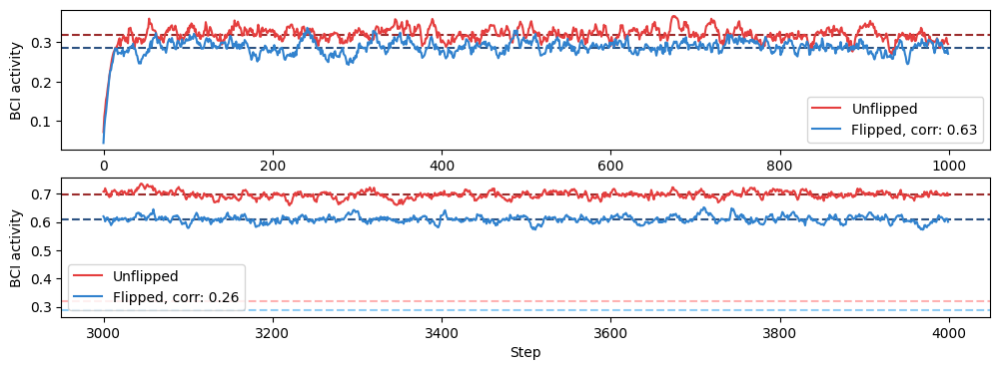

In [ ]:
session_idx = 0

train_outputs = train_outputs_all[session_idx]

bci_mask = train_outputs['bci_mask']
output = train_outputs['output']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4))

flip_mask = 2*np.array([idx % 2 for idx in range(bci_mask.shape[0])]) - 1
bci_mask_pos = np.where(flip_mask > 0, bci_mask, 0.)
bci_mask_neg = np.where(flip_mask < 0, -1 * bci_mask, 0.) # Flips signs back
# bci_mask_pos = np.where(bci_mask > 0, bci_mask, 0.)
# bci_mask_neg = np.where(bci_mask < 0, -1 * bci_mask, 0.) # Flips signs back

bci_activity_pos_pre = np.matmul(output[:task_params['n_steps_stabilize']], bci_mask_pos)
bci_activity_neg_pre = np.matmul(output[:task_params['n_steps_stabilize']], bci_mask_neg)
corr_pre = np.corrcoef(bci_activity_pos_pre, bci_activity_neg_pre)[0, 1]
bci_activity_pos_post = np.matmul(output[-1 * task_params['n_steps_stabilize']:], bci_mask_pos)
bci_activity_neg_post = np.matmul(output[-1 * task_params['n_steps_stabilize']:], bci_mask_neg)
corr_post = np.corrcoef(bci_activity_pos_post, bci_activity_neg_post)[0, 1]

pre_steps = np.arange(task_params['n_steps_stabilize'])
ax1.plot(pre_steps, bci_activity_pos_pre, color=c_vals[0], label='Unflipped')
ax1.plot(pre_steps, bci_activity_neg_pre, color=c_vals[1], label='Flipped, corr: {:.2f}'.format(corr_pre))
ax1.axhline(np.mean(bci_activity_pos_pre), color=c_vals_d[0], linestyle='dashed', zorder=-1)
ax1.axhline(np.mean(bci_activity_neg_pre), color=c_vals_d[1], linestyle='dashed', zorder=-1)

post_steps = np.arange(task_params['n_steps'] - task_params['n_steps_stabilize'], task_params['n_steps'])
ax2.plot(post_steps, bci_activity_pos_post, color=c_vals[0], label='Unflipped')
ax2.plot(post_steps, bci_activity_neg_post, color=c_vals[1], label='Flipped, corr: {:.2f}'.format(corr_post))

ax2.axhline(np.mean(bci_activity_pos_pre), color=c_vals_l[0], linestyle='dashed', zorder=-1)
ax2.axhline(np.mean(bci_activity_neg_pre), color=c_vals_l[1], linestyle='dashed', zorder=-1)
ax2.axhline(np.mean(bci_activity_pos_post), color=c_vals_d[0], linestyle='dashed', zorder=-1)
ax2.axhline(np.mean(bci_activity_neg_post), color=c_vals_d[1], linestyle='dashed', zorder=-1)

ax2.set_xlabel('Step')

for ax in (ax1, ax2):
    ax.legend()
    ax.set_ylabel('BCI activity')

Continue training under distinct settings. Used to try to tell the difference between learning rules after network has reached baseline activity.

In [ ]:
train_params['adjust_type'] = '3factor'
params, train_outputs_all, _, _, _ = train_task((task_params, train_params, net_params), net=net, output_vars=output_vars)

--- Session idx 0: Using passed network ---
Step 100 - Avg reward: 0.00
Step 200 - Avg reward: 0.00
Step 300 - Avg reward: 0.00
Step 400 - Avg reward: 0.00
 CN idx 37 (chosen from 0.80 percentile, actual percentile: 0.84)
 Threshold set to 0.00 Max activity set to 0.10
Step 500 - Avg reward: -0.01
Step 600 - Avg reward: -0.02
Step 700 - Avg reward: -0.03
Step 800 - Avg reward: -0.03
Step 900 - Avg reward: -0.03
Step 1000 - Avg reward: -0.03
Step 1100 - Avg reward: -0.03
Step 1200 - Avg reward: -0.03
Step 1300 - Avg reward: -0.03
Step 1400 - Avg reward: -0.03
Step 1500 - Avg reward: -0.03
Step 1600 - Avg reward: -0.02
Step 1700 - Avg reward: -0.02
Step 1800 - Avg reward: -0.02
Step 1900 - Avg reward: -0.02
Step 2000 - Avg reward: -0.02
Step 2100 - Avg reward: -0.02
Step 2200 - Avg reward: -0.02
Step 2300 - Avg reward: -0.02
Step 2400 - Avg reward: -0.01
Total reward: -66.95, total rpe: -0.12 (std: 0.02)


In [ ]:
train_params['adjust_type'] = '3factor_nophiprime'
params, train_outputs_all, _, _, _ = train_task((task_params, train_params, net_params), net=net, output_vars=output_vars)

--- Session idx 0: Using passed network ---
Step 100 - Avg reward: 0.00
Step 200 - Avg reward: 0.00
Step 300 - Avg reward: 0.00
Step 400 - Avg reward: 0.00
 CN idx 37 (chosen from 0.80 percentile, actual percentile: 0.84)
 Threshold set to 0.00 Max activity set to 0.10
Step 500 - Avg reward: -0.01
Step 600 - Avg reward: -0.02
Step 700 - Avg reward: -0.03
Step 800 - Avg reward: -0.03
Step 900 - Avg reward: -0.03
Step 1000 - Avg reward: -0.03
Step 1100 - Avg reward: -0.03
Step 1200 - Avg reward: -0.02
Step 1300 - Avg reward: -0.02
Step 1400 - Avg reward: -0.03
Step 1500 - Avg reward: -0.02
Step 1600 - Avg reward: -0.02
Step 1700 - Avg reward: -0.02
Step 1800 - Avg reward: -0.02
Step 1900 - Avg reward: -0.01
Step 2000 - Avg reward: -0.01
Step 2100 - Avg reward: -0.02
Step 2200 - Avg reward: -0.01
Step 2300 - Avg reward: -0.01
Step 2400 - Avg reward: -0.01
Total reward: -60.42, total rpe: 0.03 (std: 0.01)


See how W_rec changes to become more/less aligned with recurrent activity

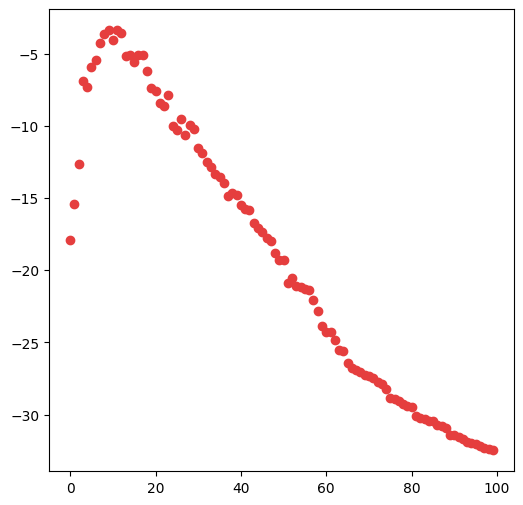

In [ ]:
def get_reward_mask(activity, mask, threshold=1.5, width=0.1):
    raise NotImplementedError('This is old.')
    bci_activity = np.dot(mask, activity)

    if bci_activity < threshold:
        return  -1 * np.abs(bci_activity - threshold)
    elif bci_activity > threshold + width:
        return  -1 * np.abs(bci_activity - (threshold + width))
    else:
        return 0.

train_outputs = train_outputs_all[session_idx]
n_neurons = task_params['n_neurons']

outputs = train_outputs['output']

activities_stabilize = outputs[:task_params['n_steps_stabilize']]

avg_activity = np.mean(activities_stabilize, axis=0) # Baseline activities equal to mean during stabilization

# Uses this to determine CN choice
mean_stabilize_actvities = np.mean(activities_stabilize, axis=0) # n_neurons
activity_sort_idxs = np.argsort(mean_stabilize_actvities)[::-1] # largest to smallest

raise NotImplementedError('Setting threshold like this is depricated')
threshold = np.mean(activities_stabilize) + task_params['task_thresh_mult'] * task_params['task_scale'] # Threshold is set relative to mean across all neurons

bci_masks = []

for neuron_idx in range(100):
    mask = np.zeros((n_neurons,))
    mask[activity_sort_idxs[neuron_idx]] = 1.0

    bci_masks.append(mask)

bci_masks = np.array(bci_masks)
n_masks = bci_masks.shape[0]

mask_rewards = np.zeros((n_masks,))

for mask_idx in range(n_masks):
    mask = bci_masks[mask_idx]

    tot_reward = 0
    # Retroactively calculate what the rewards would have been during stabilization period
    for step_idx in range(task_params['n_steps_stabilize']):
        tot_reward += get_reward_mask(outputs[step_idx], mask, threshold=threshold,
                                      width=task_params['width'])

    mask_rewards[mask_idx] = tot_reward


fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))

ax1.scatter(np.arange(n_masks), mask_rewards, color=c_vals[0])

Credit assign adjustment: RPE-deviation**2 Correlation

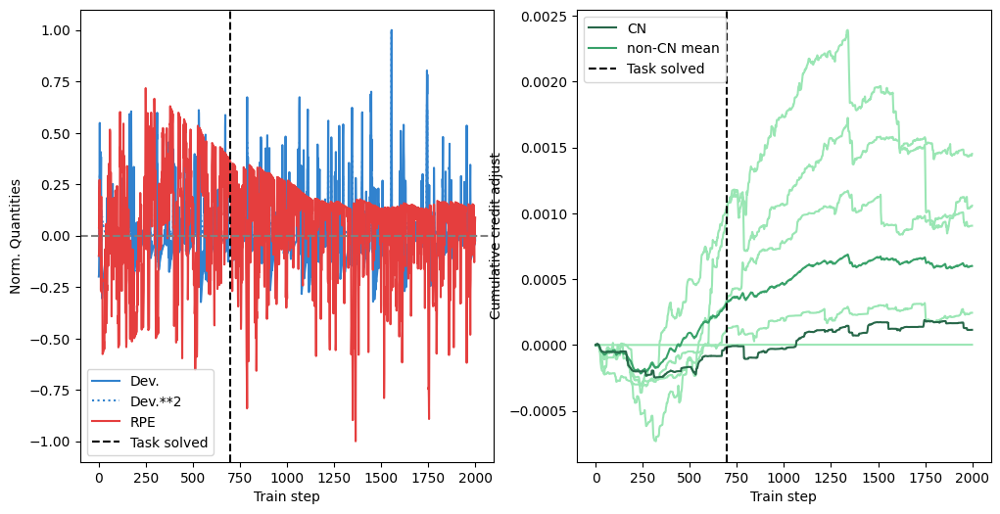

In [ ]:
train_outputs = train_outputs_all[session_idx]

output = train_outputs['output']
reward = train_outputs['reward']
avg_activity = train_outputs['avg_activity']
avg_reward = train_outputs['avg_reward']

deviation_trunc = output[task_params['n_steps_stabilize']:] - avg_activity[task_params['n_steps_stabilize']:]
rpe_trunc = reward[task_params['n_steps_stabilize']:] - avg_reward[task_params['n_steps_stabilize']:]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.plot(deviation_trunc[:, cn_idx] / np.max(np.abs(deviation_trunc[:, cn_idx])), color=c_vals[1], label='Dev.')
ax1.plot(deviation_trunc[:, cn_idx]**2 / np.max(np.abs(deviation_trunc[:, cn_idx]**2)), color=c_vals[1], linestyle='dotted', label='Dev.**2')
ax1.plot(rpe_trunc / np.max(np.abs(rpe_trunc)), color=c_vals[0], label='RPE')

ax1.axhline(0.0, color='grey', linestyle='dashed')

ax1.set_ylabel('Norm. Quantities')

ax2.plot(np.cumsum(rpe_trunc * deviation_trunc[:, cn_idx]**2), color=c_vals_d[2], label='CN')
ax2.set_ylabel('Cumulative credit adjust')

for neuron_idx in np.random.choice(n_neurons, size=(5,)):
    ax2.plot(np.cumsum(rpe_trunc * deviation_trunc[:, neuron_idx]**2), color=c_vals_l[2], zorder=-5)

ax2.plot(np.cumsum(np.mean(rpe_trunc[:, np.newaxis] * np.delete(deviation_trunc[:, :]**2, cn_idx, axis=-1), axis=-1)),
         color=c_vals[2], zorder=-3, label='non-CN mean')

for ax in (ax1, ax2):
    ax.set_xlabel('Train step')
    ax.axvline(train_outputs['sol_step'], color='k', linestyle='dashed', label='Task solved')
    ax.legend()

Understand how certain weight parameters evolve over the course of a session. This divides the sessions into a certain number of divisions and computes certain parameters within each division.

Note that since some parameters like weights/loss steps have indexing not in sync with time steps, need to adjust to keep it insync with things like RPE that can be defined at every time step.

Loss idxs: 0 to 176	Step idxs: 2400 to 3280
Loss idxs: 176 to 352	Step idxs: 3280 to 4160
Loss idxs: 352 to 528	Step idxs: 4160 to 5040
Loss idxs: 528 to 704	Step idxs: 5040 to 5920
Loss idxs: 704 to 880	Step idxs: 5920 to 6800
Loss idxs: 880 to 1056	Step idxs: 6800 to 7680
Loss idxs: 1056 to 1232	Step idxs: 7680 to 8560
Loss idxs: 1232 to 1408	Step idxs: 8560 to 9440
Loss idxs: 1408 to 1584	Step idxs: 9440 to 10320
Loss idxs: 1584 to 1760	Step idxs: 10320 to 11200
Loss idxs: 1760 to 1936	Step idxs: 11200 to 12080
Loss idxs: 1936 to 2112	Step idxs: 12080 to 12960
Loss idxs: 2112 to 2288	Step idxs: 12960 to 13840
Loss idxs: 2288 to 2464	Step idxs: 13840 to 14720
Loss idxs: 2464 to 2640	Step idxs: 14720 to 15600
Loss idxs: 2640 to 2816	Step idxs: 15600 to 16480
Loss idxs: 2816 to 2992	Step idxs: 16480 to 17360
Loss idxs: 2992 to 3168	Step idxs: 17360 to 18240
Loss idxs: 3168 to 3344	Step idxs: 18240 to 19120
Loss idxs: 3344 to 3520	Step idxs: 19120 to 20000


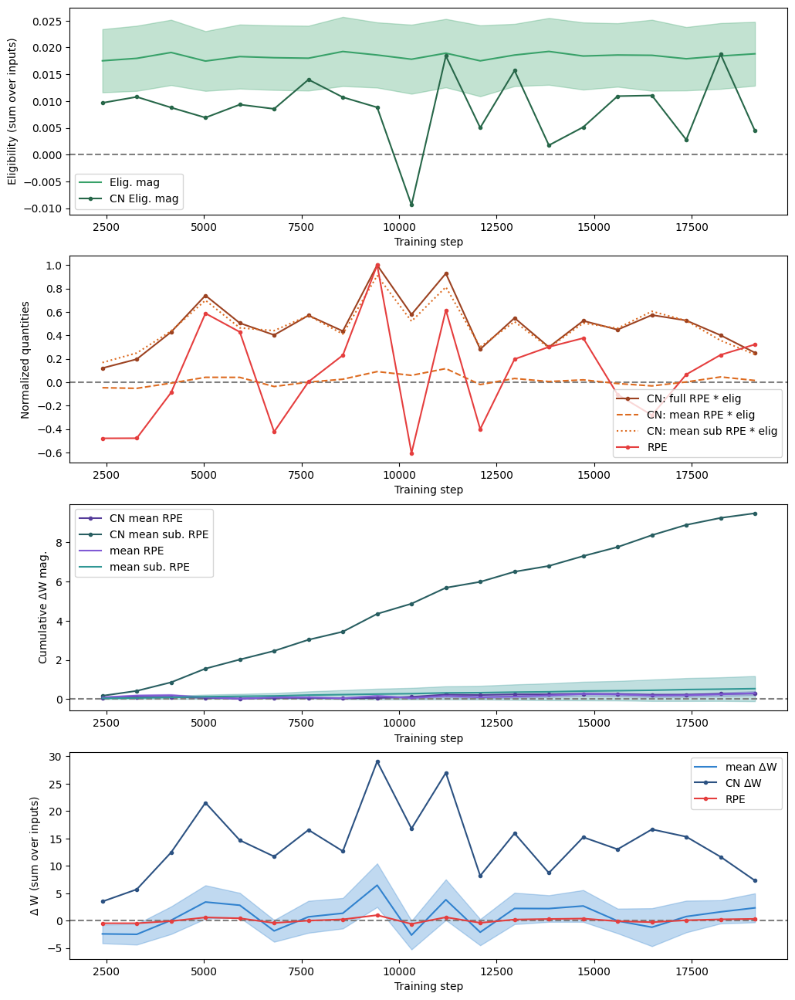

In [ ]:
n_divisions = 20 # Number of equal time bins the session should be divided into

session_idx = 0
train_outputs = train_outputs_all[session_idx]

cn_idxs = train_outputs['cn_idxs']

assert cn_idxs is not None
assert len(cn_idxs) == 1

cn_idx = cn_idxs[0]
output = train_outputs['output']
reward = train_outputs['reward']
total_rpes = train_outputs['total_rpes']
avg_activity = train_outputs['avg_activity']
avg_reward = train_outputs['avg_reward']

deviation_trunc = output[task_params['n_steps_stabilize']:] - avg_activity[task_params['n_steps_stabilize']:]
rpe_trunc = reward[task_params['n_steps_stabilize']:] - avg_reward[task_params['n_steps_stabilize']:]

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
    W_elg = train_outputs['W_inp_elg_vals']
    n_presyn = task_params['n_inp']
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']
    W_elg = train_outputs['W_rec_elg_vals']
    n_presyn = task_params['n_neurons']

delta_W = W_vals[-1] - W_vals[0]

deviation_mag = np.linalg.norm(deviation_trunc, axis=0)

cosine_angle_deviations = np.where(
    np.outer(deviation_mag, deviation_mag) > 0,
    np.matmul(deviation_trunc.T, deviation_trunc) / np.outer(deviation_mag, deviation_mag),
    0.
)
cosine_angle_rpe = np.where(
    deviation_mag > 0,
    np.matmul(rpe_trunc, deviation_trunc) / (deviation_mag * np.linalg.norm(rpe_trunc)),
    0.
)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(12, 16))

# These are indexes of loss/weight values
W_idx_bounds = np.linspace(0, len(train_outputs['loss_steps'])-1, n_divisions+1).astype(np.int32)

div_step_idxs = []
elg_mag_divs = np.zeros((n_divisions, task_params['n_neurons'])) # Magnitude of eligibility traces
rpe_divs = np.zeros((n_divisions, task_params['n_neurons'])) # Temporal product of RPE and deviations activity
corrcoef_rpe_divs = np.zeros((n_divisions, task_params['n_neurons']))
cosine_angle_rpe_divs = np.zeros((n_divisions, task_params['n_neurons']))
rpe_elg_divs = np.zeros((n_divisions, task_params['n_neurons'],)) # Temporal product of RPE and elgibility traces, summed over all time steps within div
# Components of RPE
rpe_elg_mean_divs = np.zeros((n_divisions, task_params['n_neurons'],)) # Temporal product of mean RPE and elgibility traces
rpe_elg_mean_sub_divs = np.zeros((n_divisions, task_params['n_neurons'],)) # Temporal product of mean subtracted RPE and elgibility traces

corrcoef_rpe_elg_divs = np.zeros((n_divisions, task_params['n_neurons']))
cosine_angle_rpe_elg_divs = np.zeros((n_divisions, task_params['n_neurons']))

delta_W_divs = np.zeros((n_divisions, task_params['n_neurons'], n_presyn))
rpes_divs = np.zeros((n_divisions,))
rpe_mean_divs = np.zeros((n_divisions,))
activity_dim_divs = np.zeros((n_divisions,))

elig_divs = np.zeros((n_divisions, task_params['n_neurons'], n_presyn)) # Sum of elig over all time steps

### Scan over divisions
for division_idx in range(n_divisions):
    idx_start = W_idx_bounds[division_idx]
    idx_end = W_idx_bounds[division_idx+1]

    # If idx_start = 0 and idx_end = 1, corresponds to single loss step
    delta_W_rec = (train_outputs_all[session_idx]['W_rec_vals'][idx_end] -
                    train_outputs_all[session_idx]['W_rec_vals'][idx_start])

    delta_W_divs[division_idx] = delta_W_rec

    # idx_start + 1 because the first loss_steps idx is 0,
    step_idx_start = train_outputs_all[session_idx]['loss_steps'][idx_start + 1] - train_params['n_steps_per_loss'] + 1
    step_idx_end = train_outputs_all[session_idx]['loss_steps'][idx_end] + 1

    print('Loss idxs: {} to {}\tStep idxs: {} to {}'.format(idx_start, idx_end, step_idx_start, step_idx_end))

    # div_step_idxs.append(step_idx_start + 1/2*(step_idx_start - step_idx_end))
    div_step_idxs.append(step_idx_start)

    mean_activity_trunc = np.mean(output[step_idx_start:step_idx_end], axis=0)
    deviation_trunc = output[step_idx_start:step_idx_end] - avg_activity[step_idx_start:step_idx_end]
    rpe_trunc = reward[step_idx_start:step_idx_end] - avg_reward[step_idx_start:step_idx_end]

    deviation_mag = np.linalg.norm(deviation_trunc, axis=0)

    W_elg_trunc = W_elg[idx_start+1:idx_end+1, :, :] # +1 because first entry is all zeros
    elig_divs[division_idx] = np.sum(W_elg_trunc, axis=0) # Sum over all time steps within division
    W_elg_mag = np.linalg.norm(W_elg_trunc, axis=0)
    # All RPEs within division, total = mean + deviations
    total_rpes_trunc = np.array(total_rpes[idx_start+1:idx_end+1]) # +1 because first entry is zero
    mean_rpe_trunc = np.mean(total_rpes_trunc) * np.ones_like(total_rpes_trunc) # Just the mean RPE over the division time period
    mean_sub_rpe_trunc = total_rpes_trunc - mean_rpe_trunc # Deviation around mean RPE over the division time period

    rpe_divs[division_idx] = np.matmul(rpe_trunc, deviation_trunc)
    corrcoef_rpe_divs[division_idx] = custom_corrcoef(deviation_trunc.T, rpe_trunc[np.newaxis, :])[:, 0]
    cosine_angle_rpe_divs[division_idx] = np.where(
        deviation_mag > 0,
        rpe_divs[division_idx] / (deviation_mag * np.linalg.norm(rpe_trunc)),
        0.
    )

    for neuron_idx in range(task_params['n_neurons']): # Scan over postsynaptic neurons
        # print(division_idx, neuron_idx)
        # print(total_rpes_trunc.shape)
        # print(total_rpes_trunc[np.newaxis, :].shape)
        elg_mag_divs[division_idx, neuron_idx] = np.mean(np.sum(W_elg_trunc[:, neuron_idx, :], axis=0)) # Sum over time, mean over input neurons

        rpe_elg_divs[division_idx, neuron_idx] = np.matmul(total_rpes_trunc, np.sum(W_elg_trunc[:, neuron_idx, :], axis=-1)) # Product over time
        rpe_elg_mean_divs[division_idx, neuron_idx] = np.mean(np.matmul(mean_rpe_trunc, np.sum(W_elg_trunc[:, neuron_idx, :], axis=-1))) # Mean over input neurons
        rpe_elg_mean_sub_divs[division_idx, neuron_idx] = np.mean(np.matmul(mean_sub_rpe_trunc, np.sum(W_elg_trunc[:, neuron_idx, :], axis=-1))) # Mean over input neurons

        # corrcoef_rpe_elg_divs[division_idx, neuron_idx] = np.nanmean(custom_corrcoef(W_elg_trunc[:, neuron_idx].T, total_rpes_trunc[np.newaxis, :])[:, 0])

        # cosine_angle_rpe_elg_divs[division_idx, neuron_idx] = np.mean(np.where(
        #     W_elg_mag[neuron_idx] > 0,
        #     rpe_elg_divs[division_idx, neuron_idx] / (W_elg_mag[neuron_idx] * np.linalg.norm(total_rpes_trunc)),
        #     0.
        # ))

    rpes_divs[division_idx] = np.sum(rpe_trunc) # Summed over all RPEs within division
    rpe_mean_divs[division_idx] = np.mean(rpe_trunc)
    activity_dim_divs[division_idx] = participation_ratio_vector(mean_activity_trunc) / task_params['n_neurons']

rpes_divs = rpes_divs / np.max(np.abs(rpes_divs)) # Normalize so max RPE_div is |1|

max_rpe_elg_divs = np.max(np.abs(rpe_elg_divs))
rpe_elg_divs = rpe_elg_divs / max_rpe_elg_divs
rpe_elg_mean_divs = rpe_elg_mean_divs / max_rpe_elg_divs # Components have same normalization
rpe_elg_mean_sub_divs = rpe_elg_mean_sub_divs / max_rpe_elg_divs # Components have same normalization

mean_corrcoef = np.nanmean(corrcoef_rpe_divs, axis=-1)
std_corrcoef = np.nanstd(corrcoef_rpe_divs, axis=-1)
mean_cosine_angle = np.mean(cosine_angle_rpe_divs, axis=-1)
std_cosine_angle = np.std(cosine_angle_rpe_divs, axis=-1)

mean_elg_mag_prod = np.nanmean(elg_mag_divs, axis=-1)
std_elg_mag_prod = np.nanstd(elg_mag_divs, axis=-1)
mean_elg_prod = np.nanmean(rpe_elg_divs, axis=-1)
std_elg_prod = np.nanstd(rpe_elg_divs, axis=-1)
mean_elg_corrcoef = np.nanmean(corrcoef_rpe_elg_divs, axis=-1)
std_elg_corrcoef = np.nanstd(corrcoef_rpe_elg_divs, axis=-1)

# ax4.plot(div_step_idxs, mean_cosine_angle, color=c_vals[2], label='RPE-dev, Cosine angle')
# ax4.fill_between(div_step_idxs, mean_cosine_angle + std_cosine_angle,
#                  mean_cosine_angle - std_cosine_angle, color=c_vals[2], alpha=0.3, zorder=-5)
# ax4.plot(div_step_idxs, cosine_angle_rpe_divs[:, cn_idx], color=c_vals_d[2], marker='.')
# ax4.plot(div_step_idxs, mean_corrcoef, color=c_vals[2], label='RPE-dev, corrcoef')
# ax4.fill_between(div_step_idxs, mean_corrcoef + std_corrcoef,
#                  mean_corrcoef - std_corrcoef, color=c_vals[2], alpha=0.3, zorder=-5)
# ax4.plot(div_step_idxs, corrcoef_rpe_divs[:, cn_idx], color=c_vals_d[2], marker='.')
# n_ex_neurons = 5
# for neuron_idx in np.random.choice(task_params['n_neurons'], size=(n_ex_neurons,)):
#     ax4.plot(div_step_idxs, cosine_angle_rpe_divs[:, neuron_idx], color=c_vals_l[2], zorder=-5)

# ax4.plot(div_step_idxs, mean_elg_corrcoef, color=c_vals[4], label='RPE-elg, corrcoef')
# ax4.fill_between(div_step_idxs, mean_elg_corrcoef + std_elg_corrcoef,
#                  mean_elg_corrcoef - std_elg_corrcoef, color=c_vals[4], alpha=0.3, zorder=-5)
# ax4.plot(div_step_idxs, corrcoef_rpe_elg_divs[:, cn_idx], color=c_vals_d[4], marker='.')

ax1.plot(div_step_idxs, mean_elg_mag_prod, color=c_vals[2], label='Elig. mag')
ax1.fill_between(div_step_idxs, mean_elg_mag_prod + std_elg_mag_prod,
                 mean_elg_mag_prod - std_elg_mag_prod, color=c_vals[2], alpha=0.3, zorder=-5)
ax1.plot(div_step_idxs, elg_mag_divs[:, cn_idx], color=c_vals_d[2], marker='.', label='CN Elig. mag')

ax1.set_ylabel('Eligibility (sum over inputs)')

# ax2.plot(div_step_idxs, mean_elg_prod, color=c_vals[4], label='RPE-elg, product')
# ax2.fill_between(div_step_idxs, mean_elg_prod + std_elg_prod,
#                  mean_elg_prod - std_elg_prod, color=c_vals[4], alpha=0.3, zorder=-5)
ax2.plot(div_step_idxs, rpe_elg_divs[:, cn_idx], color=c_vals_d[4], marker='.', label='CN: full RPE * elig')
ax2.plot(div_step_idxs, rpe_elg_mean_divs[:, cn_idx], color=c_vals[4], linestyle='dashed', label='CN: mean RPE * elig')
ax2.plot(div_step_idxs, rpe_elg_mean_sub_divs[:, cn_idx], color=c_vals[4], linestyle='dotted', label='CN: mean sub RPE * elig')

ax2.set_ylabel('Normalized quantities')

# ax3.plot(div_step_idxs, np.abs(rpe_elg_mean_divs[:, cn_idx]), color=c_vals_d[3], linestyle='dashed', label='mean RPE')
# ax3.plot(div_step_idxs, np.abs(rpe_elg_mean_sub_divs[:, cn_idx]), color=c_vals_d[5], linestyle='dotted', label='mean sub RPE')
# ax3.plot(div_step_idxs, np.mean(np.abs(rpe_elg_mean_divs), axis=-1), color=c_vals[3], linestyle='dashed')
# ax3.plot(div_step_idxs, np.mean(np.abs(rpe_elg_mean_sub_divs), axis=-1), color=c_vals[5], linestyle='dotted')

# ax3.plot(div_step_idxs, rpe_elg_mean_divs[:, cn_idx], color=c_vals_d[3], linestyle='dashed', label='mean RPE')
# ax3.plot(div_step_idxs, rpe_elg_mean_sub_divs[:, cn_idx], color=c_vals_d[5], linestyle='dotted', label='mean sub RPE')
# ax3.plot(div_step_idxs, np.mean(rpe_elg_mean_divs, axis=-1), color=c_vals[3], linestyle='dashed')
# ax3.plot(div_step_idxs, np.mean(rpe_elg_mean_sub_divs, axis=-1), color=c_vals[5], linestyle='dotted')

# ax3.plot(div_step_idxs, np.cumsum(rpe_elg_mean_divs[:, cn_idx]), color=c_vals_d[3], linestyle='dashed', label='CN mean RPE')
# ax3.plot(div_step_idxs, np.cumsum(rpe_elg_mean_sub_divs[:, cn_idx]), color=c_vals_d[3], linestyle='dotted', label='CN mean sub RPE')
# ax3.plot(div_step_idxs, np.mean(np.cumsum(np.delete(rpe_elg_mean_divs, cn_idx, axis=-1), axis=0), axis=-1), color=c_vals[5], linestyle='dashed', label='non-CN mean RPE')
# ax3.plot(div_step_idxs, np.mean(np.cumsum(np.delete(rpe_elg_mean_sub_divs, cn_idx, axis=-1), axis=0), axis=-1), color=c_vals[5], linestyle='dotted', label='non-CN mean sub RPE')
# ax3.set_ylabel('Cumulative weight change components')

ax3.plot(div_step_idxs, np.abs(np.cumsum(rpe_elg_mean_divs[:, cn_idx])), color=c_vals_d[3], marker='.', label='CN mean RPE')
ax3.plot(div_step_idxs, np.abs(np.cumsum(rpe_elg_mean_sub_divs[:, cn_idx])), color=c_vals_d[5], marker='.', label='CN mean sub. RPE')

mean_rpe_elg_mean_divs = np.mean(np.abs(np.cumsum(np.delete(rpe_elg_mean_divs, cn_idx, axis=-1), axis=0)), axis=-1)
std_rpe_elg_mean_divs = np.std(np.abs(np.cumsum(np.delete(rpe_elg_mean_divs, cn_idx, axis=-1), axis=0)), axis=-1)
mean_rpe_elg_mean_sub_divs = np.mean(np.abs(np.cumsum(np.delete(rpe_elg_mean_sub_divs, cn_idx, axis=-1), axis=0)), axis=-1)
std_rpe_elg_mean_sub_divs = np.std(np.abs(np.cumsum(np.delete(rpe_elg_mean_sub_divs, cn_idx, axis=-1), axis=0)), axis=-1)

ax3.plot(div_step_idxs, mean_rpe_elg_mean_divs, color=c_vals[3], label='mean RPE')
ax3.fill_between(div_step_idxs, mean_rpe_elg_mean_divs + std_rpe_elg_mean_divs, mean_rpe_elg_mean_divs - std_rpe_elg_mean_divs,
                 color=c_vals[3], alpha=0.3, zorder=-5)
ax3.plot(div_step_idxs, mean_rpe_elg_mean_sub_divs, color=c_vals[5], label='mean sub. RPE')
ax3.fill_between(div_step_idxs, mean_rpe_elg_mean_sub_divs + std_rpe_elg_mean_sub_divs, mean_rpe_elg_mean_sub_divs - std_rpe_elg_mean_sub_divs,
                 color=c_vals[5], alpha=0.3, zorder=-5)
ax3.set_ylabel('Cumulative $\Delta$W mag.')

delta_W_divs = delta_W_divs / np.max(np.abs(delta_W_divs))

mean_delta_W = np.mean(np.sum(delta_W_divs, axis=-1), axis=-1) # Sum over presynaptic, mean over postsynaptic (including CN)
std_delta_W = np.std(np.sum(delta_W_divs, axis=-1), axis=-1) # Sum over presynaptic, std over postsynaptic (including CN)

ax4.plot(div_step_idxs, mean_delta_W, color=c_vals[1], label='mean $\Delta$W')
ax4.fill_between(div_step_idxs, mean_delta_W + std_delta_W,
                 mean_delta_W - std_delta_W, color=c_vals[1], alpha=0.3, zorder=-5)
ax4.plot(div_step_idxs, np.sum(delta_W_divs, axis=-1)[:, cn_idx], color=c_vals_d[1], marker='.', label='CN $\Delta$W')
ax4.set_ylabel('$\Delta$ W (sum over inputs)')

# ax2.set_ylim((-2, 1))
# ax3.set_ylim((-1, 1))

for ax in (ax2, ax4):
    ax.plot(div_step_idxs, rpes_divs, color=c_vals[0], marker='.', label='RPE')

for ax in (ax1, ax2, ax3, ax4):
    ax.set_xlabel('Training step')
    ax.axhline(0., color='grey', linestyle='dashed', zorder=-5)
    ax.legend()

##### Hebbian index related

In [10]:
def get_div_idxs(task_hist, loss_steps, hi_params):
    if hi_params['div_mode'] == 'idxs':
        n_divisions = hi_params['n_divisions']
        # Divide indexes of loss/weight values into equal sizes, start at 1 since loss_steps[0] is 0 by default
        loss_step_divs = np.linspace(1, len(loss_steps)-1, n_divisions+1).astype(np.int32)
    elif hi_params['div_mode'] == 'trials':
        n_trials_per_div = hi_params['n_trials_per_div']
        n_trials = len(task_hist['trial_starts']) - 1 # Last trial is always omitted so we have end point
        n_divisions = int(np.floor(n_trials / n_trials_per_div))
        print('{} trials into {} divisions ({} per trial, last {} omitted)'.format(
            n_trials, n_divisions, n_trials_per_div, n_trials - n_trials_per_div * n_divisions
        ))

        # +1 here ensures that we get trial start idx of trial after last division, there will always be one because of above omission
        div_step_idxs = [task_hist['trial_starts'][div_idx * n_trials_per_div] for div_idx in range(n_divisions+1)]

        loss_step_divs = []
        for div_step_idx in div_step_idxs:
            loss_step_divs.append(np.argmin(np.abs(div_step_idx - np.array(loss_steps))))

        loss_step_divs = np.array(loss_step_divs)
    
    return loss_step_divs
        
def compute_local_hebbian_indexes(
    train_outputs, task_hist, params, hi_params, return_elig_divs=False, run_mlr=False):
    """
    Compute the local Hebbian index across potentially many eligibility estimations, including the true eligibility.
    
    Note this code computes the full session Hebbian index still, which is an addition computation
    but just kept it in for convenience
    
    INPUTS: 
    - train_outputs
    - n_divisions: number of divisions to divide session up into. Does this from the loss time steps, 
        so looks only at training times
    - return_elig_divs: return internally computed variable elig_divs, which is quite large but sometimes used for 
        additional analysis
    - run_mlr: MLR fit over divisions, this is the original way Kayvon was doing, kept for backwards compatibility
        
    OUTPUTS:
    - rpes_divs: shape (n_divisions,); RPE in each division
    - div_slopes: shape (n_elig_types, n_divisions,) the true local HI for each division (fit to change in weight in division)
    - div_slopes_full_delta: shape (n_elig_types, n_divisions,) the approximate local HI for each division (fit to change in weight across entire session)
    - full_slopes: shape (n_elig_types,) the HI across the entire session
    - elig_divs: usually None, otherwise internal variable
    - div_slopes_mlr: (n_elig_types, n_divisions,) MLR HI
    """
    
    task_params, train_params, net_params = params
    
    output = train_outputs['output']
    reward = train_outputs['reward']
    total_rpes = train_outputs['total_rpes']
    
    loss_step_divs = get_div_idxs(task_hist, train_outputs['loss_steps'], hi_params)
    n_divisions = loss_step_divs.shape[0] - 1 # -1 since this has both bounds of each division
    
    # if task_params['add_fl']:
    #     print('SHOULD COMPUTE ELIGIBILITY FROM FLUORESCENCE!')

    if net_params['W_inp_adjust']:
        W_vals = train_outputs['W_inp_vals']
        W_elg = train_outputs['W_inp_elg_vals']
        n_presyn = task_params['n_inp']
    elif net_params['W_rec_adjust']:
        W_vals = train_outputs['W_rec_vals']
        W_elg = train_outputs['W_rec_elg_vals']
        n_presyn = task_params['n_neurons']
        
    delta_W_divs = np.zeros((n_divisions, task_params['n_neurons'], n_presyn)) # Change in W over each division
    rpes_divs = {}
    if 'true' in hi_params['rpe_types']:
        rpes_divs['true'] = np.zeros((n_divisions,)) # Total RPE in each division

    # Different eligibility types
    n_elig_types = len(hi_params['elig_types'])
    elig_divs = np.zeros((n_elig_types, n_divisions, task_params['n_neurons'], n_presyn)) # Sum of each elig in each division
    elig_full = np.zeros((n_elig_types, task_params['n_neurons'], n_presyn)) # Across full session, so no divisions

    ### Full session values for entire session Hebbian index ###
    idx_start = 0
    idx_end = loss_step_divs[-1]
    delta_W = W_vals[idx_end] - W_vals[idx_start]

    # Translate the loss steps (start at idx 1 because first loss_step is always [0]
    step_idx_start = train_outputs['loss_steps'][1] - train_params['n_steps_per_loss'] + 1
    step_idx_end = train_outputs['loss_steps'][idx_end] + 1

    # Hebbian index fits, eligibility to change in weights
    div_slopes = np.zeros((n_elig_types, n_divisions,)) # Elig in division to weight change in division
    div_slopes_full_delta = np.zeros((n_elig_types, n_divisions,)) # Elig in division to total weight change
    full_slopes = np.zeros((n_elig_types,)) # Over entire session

    for elig_type_idx, elig_type in enumerate(hi_params['elig_types']):
        if elig_type == 'true':
            elig_full[elig_type_idx] = np.sum(W_elg[idx_start+1:idx_end+1, :, :], axis=0) # +1 because first entry is all zeros
        elif elig_type == 'hebb':
            elig_full[elig_type_idx] = np.matmul(output[step_idx_start:step_idx_end].T, output[step_idx_start:step_idx_end])
            # elig_full[elig_type_idx] = np.corrcoef(output[step_idx_start:step_idx_end].T)
        else:
            continue
        # Hebbian index fit over entire session
        full_slopes[elig_type_idx], _, _, _, _ = linregress(elig_full[elig_type_idx].flatten(), delta_W.flatten())

    ### Scan over eligibility types then divisions ###
    # This order means we only need to compute the full eligibility once for each division
    for elig_type_idx, elig_type in enumerate(hi_params['elig_types']):

        # Compute eligibility for the relevant type
        if elig_type in ('hebb', 'dpost_pre', 'post_dpre', 'dpost_dpre', 'dpost_pre_acc',):
            eligibility = bci_analysis.compute_eligibility_approx(output, output, train_params, elig_type=elig_type)
        elif elig_type not in ('true',): # Already saved in this place, so no need to compute.
            raise ValueError('Eligibility type {} not recognized!'.format(elig_type))

        for division_idx in range(n_divisions):
            # Start and end of division in loss steps
            idx_start = loss_step_divs[division_idx]
            idx_end = loss_step_divs[division_idx+1]

            # Translate loss steps intro raw steps
            step_idx_start = train_outputs['loss_steps'][idx_start] - train_params['n_steps_per_loss'] + 1
            step_idx_end = train_outputs['loss_steps'][idx_end] + 1

            # print('Loss idxs: {} to {}\tStep idxs: {} to {}'.format(idx_start, idx_end, step_idx_start, step_idx_end))

            if elig_type_idx == 0: # These things are not eligibility dependent, so do only on first pass through
                delta_W_divs[division_idx] =  W_vals[idx_end] - W_vals[idx_start]
                rpes_divs['true'][division_idx] = np.sum(np.array(total_rpes[idx_start:idx_end]))
                
            if elig_type == 'true': 
                # Division relevant eligibility and RPE
                W_elg_trunc = W_elg[idx_start:idx_end, :, :]
                elig_divs[elig_type_idx, division_idx] = np.sum(W_elg_trunc, axis=0) # Sum over all time steps within division
            elif elig_type in ('hebb', 'dpost_pre', 'post_dpre', 'dpost_dpre', 'dpost_pre_acc',):
                elig_divs[elig_type_idx, division_idx] = np.sum(eligibility[step_idx_start:step_idx_end], axis=0)

            # Now that eligibility in division is computed, fit to weight changes (both local or full weight change)
            div_slopes[elig_type_idx, division_idx], _, _, _, _ = linregress(
                elig_divs[elig_type_idx, division_idx].flatten(), delta_W_divs[division_idx].flatten()
            )
            div_slopes_full_delta[elig_type_idx, division_idx], _, _, _, _ = linregress(
                elig_divs[elig_type_idx, division_idx].flatten(), delta_W.flatten()
            )

    div_slopes_mlr = None
    if run_mlr:
        div_slopes_mlr = np.zeros((n_elig_types, n_divisions,))

        for elig_type_idx, elig_type in enumerate(hi_params['elig_types']):
            # Kayvon's MLR version of Hebbian index
            X = elig_divs[elig_type_idx, :].reshape((n_divisions, -1)).T # (n_divs, n_pairs) -> (n_pairs, n_divs)
            X = sm.add_constant(X)
            Y = delta_W.flatten()[:, np.newaxis]
            # Y = delta_W_divs[div_idx, :, :].flatten()[:, np.newaxis]

            fit_model = sm.OLS(Y, X, missing='drop')
            results = fit_model.fit()

            div_slopes_mlr[elig_type_idx] = results.params[1:]     
    if not return_elig_divs: # Wipe this before returning it
        elig_divs = None
        
    ### Gather various performance metrics over each division ###
    rpe_estimates = get_rpe_estimates(task_hist)
    for rpe_type in hi_params['rpe_types']:
        if rpe_type == 'true':
            continue
        if hi_params['div_mode'] == 'idxs':
            rpes_divs[rpe_type] = None 
        elif hi_params['div_mode'] == 'trials':
            rpes_divs[rpe_type] = np.zeros((n_divisions,)) # Total RPE in each division
            if rpe_type in ('hits', 'hits_rpe', 'speed', 'speed_rpe',): # Divide by trials
                for div_idx in range(n_divisions):
                    rpes_divs[rpe_type][div_idx] = np.mean(
                        rpe_estimates[rpe_type][div_idx*hi_params['n_trials_per_div']:(div_idx+1)*hi_params['n_trials_per_div']]
                    )
            elif rpe_type in ('hits_steps', 'hits_rpe_steps', 'spout_steps', 'spout_rpe_steps',):
                for div_idx in range(n_divisions):
                    # Get loss step divisions
                    idx_start = loss_step_divs[div_idx]
                    idx_end = loss_step_divs[div_idx+1]
                    # Translate loss steps intro raw steps
                    step_idx_start = train_outputs['loss_steps'][idx_start] - train_params['n_steps_per_loss'] + 1
                    step_idx_end = train_outputs['loss_steps'][idx_end] + 1
                    # if rpe_type == 'hits_steps':
                    #     print('{} - steps {} to {}'.format(div_idx, step_idx_start, step_idx_end))
                    rpes_divs[rpe_type][div_idx] = np.mean(
                        rpe_estimates[rpe_type][step_idx_start:step_idx_end]
                    )
                
    return rpes_divs, div_slopes, div_slopes_full_delta, full_slopes, elig_divs, div_slopes_mlr

# In theory, these should be drawn from the environment, but I am being lazy and just doing it this way
MAX_L = 3. # a.u.
MAX_T = 10. # seconds
T_STEP = 0.05 # ms

def get_rpe_estimates(task_hist, n_trial_avg=10, n_steps_miss=200, n_reward_window=6000,):
    """
    INPUTS:
    - n_trial_avg: # of trials to average over
    - n_steps_miss: how many steps to count misses as
    - n_reward_window: # of steps to average over
    """

    ### Trial metrics ###
    start_idxs = np.array(task_hist['trial_starts'])
    rew_idxs = bci_analysis.pad_rew_idxs(task_hist) # Adds nan pads to rew_idxs, should be same length as trial start idxs now

    n_trials = start_idxs.shape[0]

    hits = np.astype(~np.isnan(rew_idxs), np.int32)
    trial_lengths = rew_idxs - start_idxs
    trial_lengths = np.where(np.isnan(trial_lengths), n_steps_miss, trial_lengths)

    avg_hits = np.nan * np.ones_like(hits)
    avg_trial_lengths = np.nan * np.ones_like(hits)
    for trial_idx in range(n_trials):
        if trial_idx < n_trial_avg: # Early session clipping
            avg_hits[trial_idx] = np.mean(hits[:trial_idx+1])
            avg_trial_lengths[trial_idx] = np.mean(trial_lengths[:trial_idx+1])
        else:
            avg_hits[trial_idx] = np.mean(hits[trial_idx-n_trial_avg+1:trial_idx+1])
            avg_trial_lengths[trial_idx] = np.mean(trial_lengths[trial_idx-n_trial_avg+1:trial_idx+1])
    
    ### Step metrics ###
    gamma = 1. - 1./n_reward_window
    
    raw_states = np.array(task_hist['raw_states']) # (trial tone, water available, spout location)

    water_reward = raw_states[:, 1] # Times water is being delivered
    forward_spout_move = np.zeros((raw_states.shape[0])) 
    forward_spout_move[1:] = -1 * (raw_states[1:, 2] - raw_states[:-1, 2]) # Spout movement = difference in spout location
    forward_spout_move = np.where(forward_spout_move > 0, forward_spout_move, 0.) # Remove backward movements

    avg_water_reward = np.zeros_like(water_reward)
    avg_forward_spout_move = np.zeros_like(forward_spout_move)

    for step_idx in range(raw_states.shape[0]):
        if step_idx == 0:
            prev_avg_water_reward = 0.
            prev_avg_forward_spout_move = 0.
        else:
            prev_avg_water_reward = avg_water_reward[step_idx-1]
            prev_avg_forward_spout_move = avg_forward_spout_move[step_idx-1]

        avg_water_reward[step_idx] = gamma * prev_avg_water_reward + (1 - gamma) * water_reward[step_idx]
        avg_forward_spout_move[step_idx] = gamma * prev_avg_forward_spout_move + (1 - gamma) * forward_spout_move[step_idx]
    
    
    return {
        ### Trial metrics ###
        'hits': hits,
        'hits_rpe': np.where(np.isnan(hits - avg_hits), 0., hits - avg_hits), # If first trial is miss, prevents nan
        'speed': MAX_L / (trial_lengths * T_STEP),
        'speed_rpe': MAX_L / (trial_lengths * T_STEP) - MAX_L / (avg_trial_lengths * T_STEP),
        
        ### Step metrics ###
        'hits_steps': water_reward,
        'hits_rpe_steps': water_reward - avg_water_reward,
        'spout_steps': forward_spout_move,
        'spout_rpe_steps': forward_spout_move - avg_forward_spout_move,
    }

76 trials into 15 divisions (5 per trial, last 1 omitted)
76 trials into 15 divisions (5 per trial, last 1 omitted)
0 - steps 2400 to 3555
1 - steps 3550 to 4460
2 - steps 4455 to 5290
3 - steps 5285 to 6215
4 - steps 6210 to 7065
5 - steps 7060 to 8125
6 - steps 8120 to 8945
7 - steps 8940 to 10140
8 - steps 10135 to 10995
9 - steps 10990 to 12080
10 - steps 12075 to 14150
11 - steps 14145 to 15590
12 - steps 15585 to 16835
13 - steps 16830 to 18020
14 - steps 18015 to 19700


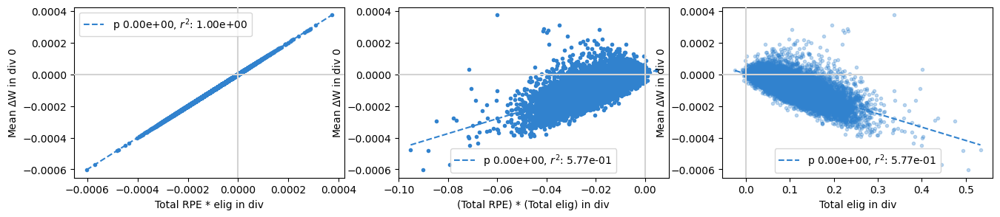

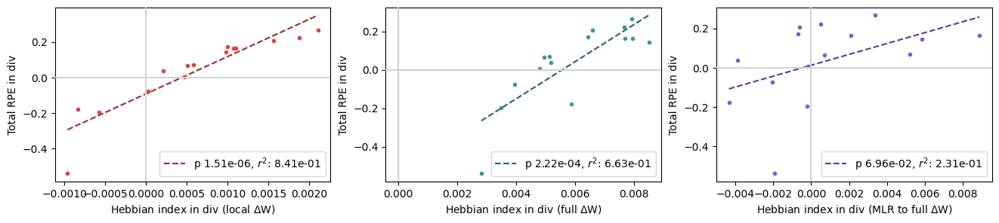

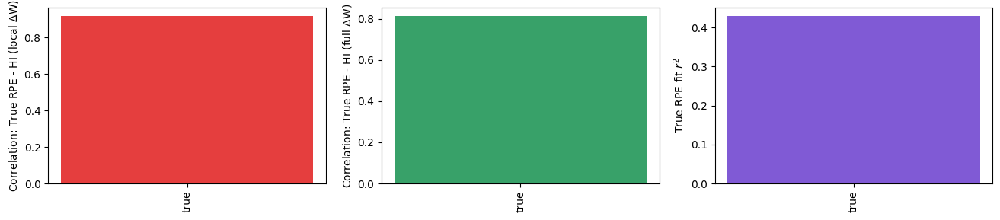

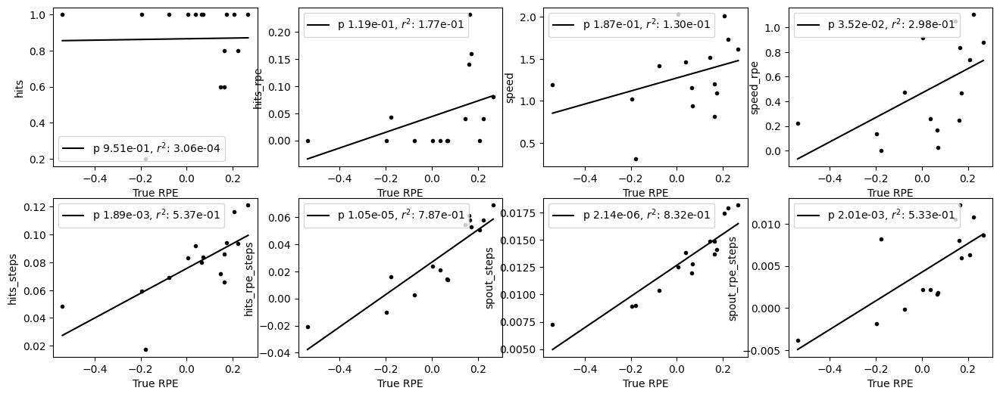

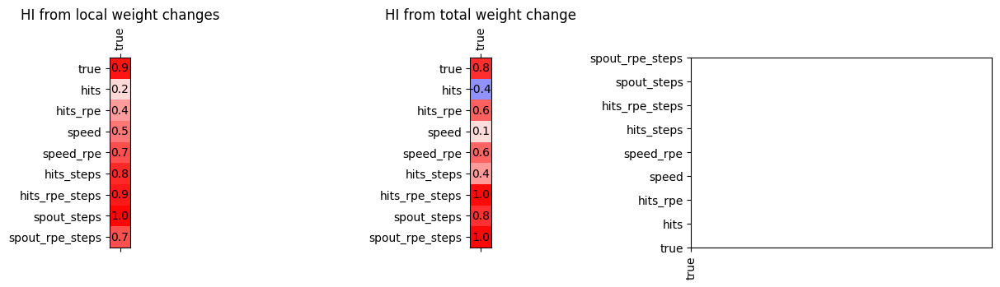

In [71]:
import statsmodels.api as sm

hi_params = {
    'div_mode': 'trials', # idxs, trials
        'n_trials_per_div': 5, # Number of trials per division bin, used when div_mode = trials
        'n_divisions': 20, # Number of equal time bins the session should be divided into, used when div_mode = idxs
    'elig_types': ('true',), # 'hebb', 'dpost_pre', 'post_dpre', 'dpost_dpre', 'dpost_pre_acc',),
    'rpe_types': ('true', 'hits', 'hits_rpe', 'speed', 'speed_rpe', 'hits_steps', 'hits_rpe_steps', 'spout_steps', 'spout_rpe_steps',),
}

session_idx = 0
train_outputs = train_outputs_all[session_idx]

output = train_outputs['output']
reward = train_outputs['reward']
avg_activity = train_outputs['avg_activity']
avg_reward = train_outputs['avg_reward']
total_rpes = train_outputs['total_rpes']

deviation_trunc = output[task_params['n_steps_stabilize']:] - avg_activity[task_params['n_steps_stabilize']:]
rpe_trunc = reward[task_params['n_steps_stabilize']:] - avg_reward[task_params['n_steps_stabilize']:]

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
    W_elg = train_outputs['W_inp_elg_vals']
    n_presyn = task_params['n_inp']
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']
    W_elg = train_outputs['W_rec_elg_vals']
    n_presyn = task_params['n_neurons']

# Divide indexes of loss/weight values into equal sizes
W_idx_bounds = get_div_idxs(task.hists[session_idx], train_outputs['loss_steps'], hi_params)
n_divisions = W_idx_bounds.shape[0] - 1

delta_W_divs = np.zeros((n_divisions, task_params['n_neurons'], n_presyn)) # Change in W over each division

# Different eligibility types
n_elig_types = len(hi_params['elig_types'])
n_rpe_types = len(hi_params['rpe_types'])

# This is just used for a sanity check
rpe_elg_divs = np.zeros((n_divisions, task_params['n_neurons'], n_presyn)) # Temporal product of RPE and elgibility traces, summed over all time steps within div

# ### Full session values for entire session Hebbian index ###
idx_start = W_idx_bounds[0]
idx_end = W_idx_bounds[-1]
delta_W = W_vals[idx_end] - W_vals[idx_start]

# # Translate the loss steps 
# step_idx_start = train_outputs['loss_steps'][idx_start + 1] - train_params['n_steps_per_loss'] + 1
# step_idx_end = train_outputs['loss_steps'][idx_end] + 1

# # Hebbian index fits, eligibility to change in weights
# div_slopes = np.zeros((n_elig_types, n_divisions,)) # Elig in division to weight change in division
# div_slopes_full_delta = np.zeros((n_elig_types, n_divisions,)) # Elig in division to total weight change
# full_slopes = np.zeros((n_elig_types,)) # Over entire session

rpes_divs, div_slopes, div_slopes_full_delta, full_slopes, elig_divs, div_slopes_mlr = compute_local_hebbian_indexes(
    train_outputs, task.hists[session_idx], params, hi_params, return_elig_divs=True, run_mlr=True
)


# for elig_type_idx, elig_type in enumerate(hi_params['elig_types']):
#     if elig_type == 'true':
#         elig_full[elig_type_idx] = np.sum(W_elg[idx_start+1:idx_end+1, :, :], axis=0) # +1 because first entry is all zeros
#     elif elig_type == 'hebb':
#         elig_full[elig_type_idx] = np.matmul(output[step_idx_start:step_idx_end].T, output[step_idx_start:step_idx_end])
#         # elig_full[elig_type_idx] = np.corrcoef(output[step_idx_start:step_idx_end].T)
#     else:
#         continue
#     # Hebbian index fit over entire session
#     full_slopes[elig_type_idx], _, _ = add_regression_line(elig_full[elig_type_idx].flatten(), delta_W.flatten())

### Scan over eligibility types then divisions ###
# This order means we only need to compute the full eligibility once for each division

for elig_type_idx, elig_type in enumerate(hi_params['elig_types']):
    
    # # Compute eligibility for the relevant type
    # if elig_type in ('hebb', 'dpost_pre', 'post_dpre', 'dpost_dpre', 'dpost_pre_acc',):
    #     eligibility = compute_eligibility_approx(output, output, train_params, elig_type=elig_type)
    # elif elig_type not in ('true',):
    #     raise ValueError('Eligibility type {} not recognized!'.format(elig_type))
    
    for division_idx in range(n_divisions):
        # Start and end of division in loss steps
        idx_start = W_idx_bounds[division_idx]
        idx_end = W_idx_bounds[division_idx+1]
        
        # # Translate loss steps intro raw steps, idx_start + 1 because the first loss_steps idx is 0
        # step_idx_start = train_outputs['loss_steps'][idx_start + 1] - train_params['n_steps_per_loss'] + 1
        # step_idx_end = train_outputs['loss_steps'][idx_end] + 1
        
        # print('Loss idxs: {} to {}\tStep idxs: {} to {}'.format(idx_start, idx_end, step_idx_start, step_idx_end))
        
        if elig_type_idx == 0: # These things only need to be done once
            delta_W_divs[division_idx] =  W_vals[idx_end] - W_vals[idx_start]
            # div_step_idxs.append(step_idx_start)

            total_rpes_trunc = np.array(total_rpes[idx_start+1:idx_end+1]) # +1 because first entry is zero
            
            for neuron_idx in range(task_params['n_neurons']): # Scan over postsynaptic neurons
                rpe_elg_divs[division_idx, neuron_idx, :] = np.matmul(total_rpes_trunc, W_elg[idx_start+1:idx_end+1, neuron_idx, :]) # Product over time
        
#         if elig_type == 'true': 
#             # Division relevant eligibility and RPE
#             W_elg_trunc = W_elg[idx_start+1:idx_end+1, :, :] # +1 because first entry is all zeros
#             elig_divs[elig_type_idx, division_idx] = np.sum(W_elg_trunc, axis=0) # Sum over all time steps within division
#         elif elig_type in ('hebb', 'dpost_pre', 'post_dpre', 'dpost_dpre', 'dpost_pre_acc',):
#             # elig_divs[elig_type_idx, division_idx] = np.matmul(output[step_idx_start:step_idx_end].T, output[step_idx_start:step_idx_end])
#             # elig_divs[elig_type_idx, division_idx = np.corrcoef(output[step_idx_start:step_idx_end].T) # Correlation Hebbian
#             elig_divs[elig_type_idx, division_idx] = np.sum(eligibility[step_idx_start:step_idx_end], axis=0)
        
#         # Division Hebbian index fits
#         div_slopes[elig_type_idx, division_idx], _, _ = add_regression_line(
#             elig_divs[elig_type_idx, division_idx].flatten(), delta_W_divs[division_idx].flatten()
#         )
#         div_slopes_full_delta[elig_type_idx, division_idx], _, _ = add_regression_line(
#             elig_divs[elig_type_idx, division_idx].flatten(), delta_W.flatten()
#         )

fig1, (ax5, ax6, ax7) = plt.subplots(1, 3, figsize=(16, 3)) # Some exemplar plots for a given division
fig2, (ax8, ax9, ax10) = plt.subplots(1, 3, figsize=(16, 3)) # Various types of local Hebbian index
fig3, (ax11, ax12, ax13) = plt.subplots(1, 3, figsize=(16, 3))
fig5, ax5s = plt.subplots(2, 4, figsize=(16, 6))
fig4, (ax14, ax15, ax16) = plt.subplots(1, 3, figsize=(16, 3))

div_idx = 0
elig_type_idx = 0 
assert hi_params['elig_types'][elig_type_idx] == 'true'

# Crude approximation to RPE * elig because just uses sums
ax5.scatter(rpe_elg_divs[div_idx, :, :].flatten(), delta_W_divs[div_idx, :, :].flatten(), color=c_vals[1], marker='.')
_ = add_regression_line(rpe_elg_divs[div_idx, :, :].flatten(), delta_W_divs[div_idx, :, :].flatten(), ax=ax5, color=c_vals[1], linestyle='dashed')
ax5.set_xlabel('Total RPE * elig in div')

# Crude approximation to RPE * elig because just uses sums (use true eligibility)
rpe_elg_means = rpes_divs['true'][div_idx] * elig_divs[elig_type_idx, div_idx]

ax6.scatter(rpe_elg_means.flatten(), delta_W_divs[div_idx, :, :].flatten(), color=c_vals[1], marker='.')
_ = add_regression_line(rpe_elg_means.flatten(), delta_W_divs[div_idx, :, :].flatten(), ax=ax6, color=c_vals[1], linestyle='dashed')
ax6.set_xlabel('(Total RPE) * (Total elig) in div')

ax7.scatter(elig_divs[elig_type_idx, div_idx].flatten(), delta_W_divs[div_idx, :, :].flatten(), color=c_vals[1], marker='.', alpha=0.3)
_ = add_regression_line(elig_divs[elig_type_idx, div_idx].flatten(), delta_W_divs[div_idx, :, :].flatten(), ax=ax7, color=c_vals[1], linestyle='dashed')
ax7.set_xlabel('Total elig in div')

for ax in (ax5, ax6, ax7,):
    ax.axhline(0.0, color='lightgrey', zorder=--5, linestyle='solid')
    ax.axvline(0.0, color='lightgrey', zorder=--5, linestyle='solid')
    ax.set_ylabel('Mean $\Delta$W in div {}'.format(div_idx))
    ax.legend()

# div_slopes_mlr = np.zeros((n_elig_types, n_divisions,))

# for elig_type_idx, elig_type in enumerate(hi_params['elig_types']):
#     # Kayvon's MLR version of Hebbian index
#     X = elig_divs[elig_type_idx, :].reshape((n_divisions, -1)).T # (n_divs, n_pairs) -> (n_pairs, n_divs)
#     X = sm.add_constant(X)
#     Y = delta_W.flatten()[:, np.newaxis]
#     # Y = delta_W_divs[div_idx, :, :].flatten()[:, np.newaxis]

#     fit_model = sm.OLS(Y, X, missing='drop')
#     results = fit_model.fit()
    
#     div_slopes_mlr[elig_type_idx] = results.params[1:]

elig_type_idx = 0  
    
rpe_type = 'true'
rpe_div_vals = rpes_divs[rpe_type]
    
ax8.scatter(div_slopes[elig_type_idx], rpe_div_vals, marker='.', color=c_vals[0])
_ = add_regression_line(div_slopes[elig_type_idx], rpe_div_vals, ax=ax8, color=c_vals_d[0], linestyle='dashed')
# ax8.axvline(full_slope, color=c_vals[0], linestyle='dashed') # Full Hebbian index
ax8.set_ylabel('Total RPE in div')
ax8.set_xlabel('Hebbian index in div (local $\Delta$W)')

# Raw values, with offset
ax9.scatter(div_slopes_full_delta[elig_type_idx], rpe_div_vals, marker='.', color=c_vals[2])
_ = add_regression_line(div_slopes_full_delta[elig_type_idx], rpe_div_vals, ax=ax9, color=c_vals_d[2], linestyle='dashed')
# With mean subtraction
# ax9.scatter(div_slopes_full_delta - np.mean(div_slopes_full_delta), rpe_div_vals, marker='.', color=c_vals_l[2])
# _ = add_regression_line(div_slopes_full_delta - np.mean(div_slopes_full_delta), rpe_div_vals, ax=ax9, color=c_vals[2], linestyle='dashed')
# ax9.axvline(full_slope, color=c_vals[2], linestyle='dashed')
ax9.set_ylabel('Total RPE in div')
ax9.set_xlabel('Hebbian index in div (full $\Delta$W)')

ax10.scatter(div_slopes_mlr[elig_type_idx], rpe_div_vals, marker='.', color=c_vals[3])
_ = add_regression_line(div_slopes_mlr[elig_type_idx], rpe_div_vals, ax=ax10, color=c_vals_d[3], linestyle='dashed')
ax10.set_ylabel('Total RPE in div')
ax10.set_xlabel('Hebbian index in div (MLR to full $\Delta$W)')

for ax in (ax8, ax9, ax10,):
    ax.axhline(0.0, color='lightgrey', zorder=--5, linestyle='solid')
    ax.axvline(0.0, color='lightgrey', zorder=--5, linestyle='solid')
    ax.legend()

# Exact fits
fit_r_squareds_div = np.zeros((n_elig_types, n_rpe_types,))
fit_r_squareds_full = np.zeros((n_elig_types, n_rpe_types,))
fit_r_squareds_mlr = np.zeros((n_elig_types, n_rpe_types,))
fit_corrs_div = np.zeros((n_elig_types, n_rpe_types,))
fit_corrs_full = np.zeros((n_elig_types, n_rpe_types,))
# fit_corrs_mlr = np.zeros((n_elig_types, n_rpe_types,))

for rpe_type_idx, rpe_type in enumerate(hi_params['rpe_types']):
    rpe_div_vals = rpes_divs[rpe_type]
    for elig_type_idx, elig_type in enumerate(hi_params['elig_types']):
        slope, intercept, rvalue = add_regression_line(div_slopes[elig_type_idx], rpe_div_vals)
        fit_r_squareds_div[elig_type_idx, rpe_type_idx] = rvalue**2
        fit_corrs_div[elig_type_idx, rpe_type_idx] = np.corrcoef(div_slopes[elig_type_idx], rpe_div_vals)[0, 1]

        slope, intercept, rvalue = add_regression_line(div_slopes_full_delta[elig_type_idx], rpe_div_vals)
        fit_r_squareds_full[elig_type_idx, rpe_type_idx] = rvalue**2
        fit_corrs_full[elig_type_idx, rpe_type_idx] = np.corrcoef(div_slopes_full_delta[elig_type_idx], rpe_div_vals)[0, 1]

        X = elig_divs[elig_type_idx, :].reshape((n_divisions, -1)).T # (n_divs, n_pairs) -> (n_pairs, n_divs)
        X = sm.add_constant(X)
        Y = delta_W.flatten()[:, np.newaxis]
        fit_model = sm.OLS(Y, X, missing='drop')
        results = fit_model.fit()
        fit_r_squareds_mlr[elig_type_idx, rpe_type_idx] = results.rsquared

rpe_type_idx = 0
# ax11.bar(np.arange(n_elig_types), fit_r_squareds_div, color=c_vals[0])
# ax12.bar(np.arange(n_elig_types), fit_r_squareds_full, color=c_vals[2])
ax11.bar(np.arange(n_elig_types), fit_corrs_div[:, rpe_type_idx], color=c_vals[0])
ax12.bar(np.arange(n_elig_types), fit_corrs_full[:, rpe_type_idx], color=c_vals[2])
ax13.bar(np.arange(n_elig_types), fit_r_squareds_mlr[:, rpe_type_idx], color=c_vals[3])
ax11.set_ylabel('Correlation: True RPE - HI (local $\Delta$W)')
ax12.set_ylabel('Correlation: True RPE - HI (full $\Delta$W)')

for ax in (ax11, ax12, ax13):
    ax.set_xticks(np.arange(n_elig_types))
    ax.set_xticklabels(hi_params['elig_types'], rotation=90)
    # ax.set_ylabel('True RPE fit $r^2$')

ax13.set_ylabel('True RPE fit $r^2$')

for ax, rpe_type in zip(ax5s.flatten(), ('hits', 'hits_rpe', 'speed', 'speed_rpe', 'hits_steps', 'hits_rpe_steps', 'spout_steps', 'spout_rpe_steps',)):
    ax.scatter(rpes_divs['true'], rpes_divs[rpe_type], color='k', marker='.')
    add_regression_line(rpes_divs['true'], rpes_divs[rpe_type], color='k', ax=ax)
    ax.set_xlabel('True RPE')
    ax.set_ylabel('{}'.format(rpe_type))
    ax.legend()
    
ax14.matshow(fit_corrs_div.T, cmap='bwr', vmin=-1.0, vmax=1.0)
for (i, j), z in np.ndenumerate(fit_corrs_div.T):
    ax14.text(j, i, '{:0.1f}'.format(z), ha='center', va='center')
ax14.title.set_text('HI from local weight changes')

ax15.matshow(fit_corrs_full.T, cmap='bwr', vmin=-1.0, vmax=1.0)
for (i, j), z in np.ndenumerate(fit_corrs_full.T):
    ax15.text(j, i, '{:0.1f}'.format(z), ha='center', va='center')
ax15.title.set_text('HI from total weight change')

for ax in (ax14, ax15, ax16,):
    ax.set_xticks(np.arange(n_elig_types))
    ax.set_xticklabels(hi_params['elig_types'], rotation=90)
    ax.set_yticks(np.arange(n_rpe_types))
    ax.set_yticklabels(hi_params['rpe_types'])

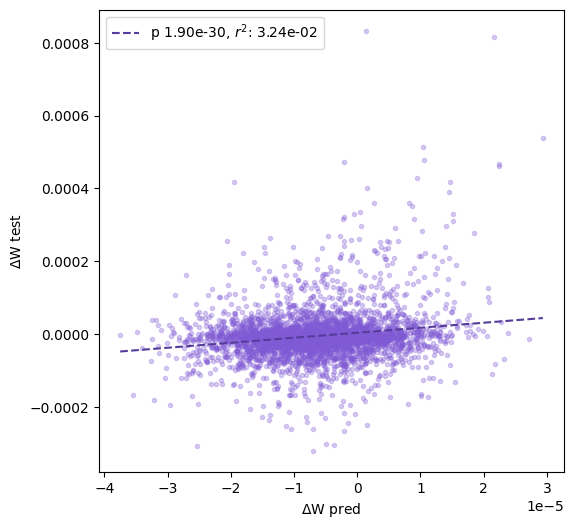

In [ ]:
from sklearn.model_selection import train_test_split

test_ratio = 0.1

# MLR fit
X = elig_values_divs.reshape((n_divisions, -1)).T # (n_pairs, n_divs)
Y = delta_W_divs[div_idx, :, :].flatten()[:, np.newaxis]
X = sm.add_constant(X)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=test_ratio, random_state=42)

fit_model = sm.OLS(Y_train, X_train, missing='none')
results = fit_model.fit()

Y_pred = results.predict(X_test)

fig, ax = plt.subplots(1, 1, figsize=(6, 6))

Y_pred = Y_pred.flatten()
Y_test = Y_test.flatten()

ax.scatter(Y_pred, Y_test, marker='.', color=c_vals[3], alpha=0.3)
_ = add_regression_line(Y_pred, Y_test, ax=ax, color=c_vals_d[3], linestyle='dashed', zorder=10)

ax.set_xlabel('$\Delta$W pred')
ax.set_ylabel('$\Delta$W test')
ax.legend()

In [ ]:
import statsmodels.api as sm

n_divisions = 50 # Number of equal time bins the session should be divided into

session_idx = 0
train_outputs = train_outputs_all[session_idx]

cn_idxs = train_outputs['cn_idxs']

assert cn_idxs is not None
assert len(cn_idxs) == 1

cn_idx = cn_idxs[0]
output = train_outputs['output']
reward = train_outputs['reward']
total_rpes = train_outputs['total_rpes']
avg_activity = train_outputs['avg_activity']
avg_reward = train_outputs['avg_reward']

deviation_trunc = output[task_params['n_steps_stabilize']:] - avg_activity[task_params['n_steps_stabilize']:]
rpe_trunc = reward[task_params['n_steps_stabilize']:] - avg_reward[task_params['n_steps_stabilize']:]

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
    W_elg = train_outputs['W_inp_elg_vals']
    n_presyn = task_params['n_inp']
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']
    W_elg = train_outputs['W_rec_elg_vals']
    n_presyn = task_params['n_neurons']

delta_W = W_vals[-1] - W_vals[0]

# These are indexes of loss/weight values
W_idx_bounds = np.linspace(0, len(train_outputs['loss_steps'])-1, n_divisions+1).astype(np.int32)

div_step_idxs = []

delta_W_divs = np.zeros((n_divisions, task_params['n_neurons'], n_presyn))
rpes_divs = np.zeros((n_divisions,))
elig_divs = np.zeros((n_divisions, task_params['n_neurons'], n_presyn)) # Sum of elig over all time steps
elig_hebb_divs = np.zeros((n_divisions, task_params['n_neurons'], n_presyn)) # Sum of elig over all time steps

rpe_elg_divs = np.zeros((n_divisions, task_params['n_neurons'], n_presyn)) # Temporal product of RPE and elgibility traces, summed over all time steps within div


### Scan over divisions
for division_idx in range(n_divisions):
    idx_start = W_idx_bounds[division_idx]
    idx_end = W_idx_bounds[division_idx+1]

    # If idx_start = 0 and idx_end = 1, corresponds to single loss step
    delta_W_rec = (train_outputs_all[session_idx]['W_rec_vals'][idx_end] -
                    train_outputs_all[session_idx]['W_rec_vals'][idx_start])

    delta_W_divs[division_idx] = delta_W_rec

    # idx_start + 1 because the first loss_steps idx is 0,
    step_idx_start = train_outputs_all[session_idx]['loss_steps'][idx_start + 1] - train_params['n_steps_per_loss'] + 1
    step_idx_end = train_outputs_all[session_idx]['loss_steps'][idx_end] + 1

    print('Loss idxs: {} to {}\tStep idxs: {} to {}'.format(idx_start, idx_end, step_idx_start, step_idx_end))

    div_step_idxs.append(step_idx_start)

    # mean_activity_trunc = np.mean(output[step_idx_start:step_idx_end], axis=0)
    # deviation_trunc = output[step_idx_start:step_idx_end] - avg_activity[step_idx_start:step_idx_end]
    # rpe_trunc = reward[step_idx_start:step_idx_end] - avg_reward[step_idx_start:step_idx_end]

    W_elg_trunc = W_elg[idx_start+1:idx_end+1, :, :] # +1 because first entry is all zeros
    elig_divs[division_idx] = np.sum(W_elg_trunc, axis=0) # Sum over all time steps within division

    # Computes what the eligibilty would be estimated to be if just from activity correlations
    elig_hebb_divs[division_idx] = np.corrcoef(output[step_idx_start:step_idx_end].T)

    total_rpes_trunc = np.array(total_rpes[idx_start+1:idx_end+1]) # +1 because first entry is zero

    rpes_divs[division_idx] = np.sum(total_rpes_trunc) # Summed over all RPEs within a division

    for neuron_idx in range(task_params['n_neurons']): # Scan over postsynaptic neurons
        rpe_elg_divs[division_idx, neuron_idx, :] = np.matmul(total_rpes_trunc, W_elg_trunc[:, neuron_idx, :]) # Product over time

fig2, (ax8, ax9, ax10) = plt.subplots(1, 3, figsize=(16, 3))

div_idx = 5
eligibility_type = 'true' # true, hebb

# Crude approximation to RPE * elig because just uses sums
ax5.scatter(rpe_elg_divs[div_idx, :, :].flatten(), delta_W_divs[div_idx, :, :].flatten(), color=c_vals[1], marker='.')
_ = add_regression_line(rpe_elg_divs[div_idx, :, :].flatten(), delta_W_divs[div_idx, :, :].flatten(), ax=ax5, color=c_vals[1], linestyle='dashed')
ax5.axhline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')
ax5.axvline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')

ax5.set_xlabel('Total RPE in div')
ax5.set_ylabel('Mean $\Delta$W in div')

# Crude approximation to RPE * elig because just uses sums
rpe_elg_means = rpes_divs[div_idx] * elig_divs[div_idx]

ax6.scatter(rpe_elg_means.flatten(), delta_W_divs[div_idx, :, :].flatten(), color=c_vals[1], marker='.')
_ = add_regression_line(rpe_elg_means.flatten(), delta_W_divs[div_idx, :, :].flatten(), ax=ax6, color=c_vals[1], linestyle='dashed')
ax6.axhline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')
ax6.axvline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')

ax6.set_xlabel('Total RPE in div')
ax6.set_ylabel('Mean $\Delta$W in div')

ax7.scatter(elig_divs[div_idx].flatten(), delta_W_divs[div_idx, :, :].flatten(), color=c_vals[1], marker='.', alpha=0.3)
_ = add_regression_line(elig_divs[div_idx].flatten(), delta_W_divs[div_idx, :, :].flatten(), ax=ax7, color=c_vals[1], linestyle='dashed')
ax7.axhline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')
ax7.axvline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')

ax7.legend()

ax7.set_xlabel('Total elig. in div')
ax7.set_ylabel('Mean $\Delta$W in div')

if eligibility_type == 'true':
    elig_values_divs = elig_divs
elif eligibility_type == 'hebb':
    elig_values_divs = elig_hebb_divs

div_slopes = np.zeros((n_divisions))
div_slopes_full_delta = np.zeros((n_divisions))

for div_idx in range(n_divisions):
    div_slopes[div_idx], _, _ = add_regression_line(elig_values_divs[div_idx].flatten(), delta_W_divs[div_idx, :, :].flatten())
    div_slopes_full_delta[div_idx], _, _ = add_regression_line(elig_values_divs[div_idx].flatten(), delta_W.flatten())

# MLR fit
X = elig_values_divs.reshape((n_divisions, -1)).T # (n_pairs, n_divs)
Y = delta_W_divs[div_idx, :, :].flatten()[:, np.newaxis]
X = sm.add_constant(X)

fit_model = sm.OLS(Y, X, missing='none')
results = fit_model.fit()

ax8.scatter(div_slopes, rpes_divs, marker='.', color=c_vals[0])
_ = add_regression_line(div_slopes, rpes_divs, ax=ax8, color=c_vals_d[0], linestyle='dashed')
ax8.axhline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')
ax8.axvline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')
ax8.set_ylabel('Total RPE in div')
ax8.set_xlabel('Hebbian index in div (local $\Delta$W)')
ax8.legend()

ax9.scatter(div_slopes_full_delta, rpes_divs, marker='.', color=c_vals[2])
_ = add_regression_line(div_slopes_full_delta, rpes_divs, ax=ax9, color=c_vals_d[2], linestyle='dashed')
ax9.axhline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')
ax9.axvline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')
ax9.set_ylabel('Total RPE in div')
ax9.set_xlabel('Hebbian index in div (full $\Delta$W)')
ax9.legend()

ax10.scatter(results.params[1:], rpes_divs, marker='.', color=c_vals[3])
_ = add_regression_line(results.params[1:], rpes_divs, ax=ax10, color=c_vals_d[3], linestyle='dashed')
ax10.axhline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')
ax10.axvline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')
ax10.set_ylabel('Total RPE in div')
ax10.set_xlabel('Hebbian index in div (MLR to full $\Delta$W)')
ax10.legend()


# ax6.scatter(rpes_divs, mean_delta_W, color=c_vals[1], marker='.')
# _ = add_regression_line(rpes_divs, mean_delta_W, ax=ax6, color=c_vals[1], linestyle='dashed')
# ax6.axhline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')
# ax6.axvline(0.0, color='lightgrey', zorder=--5, linestyle='dashed')

# ax6.set_xlabel('Total RPE in div')
# ax6.set_ylabel('Mean $\Delta$W in div')

Compute the change in tuning. Uses the stabilization period to compute tuning, so can't compute change in tuning for the very last session of training because no stabilization period afterwards.

Current CN perc: 1.00


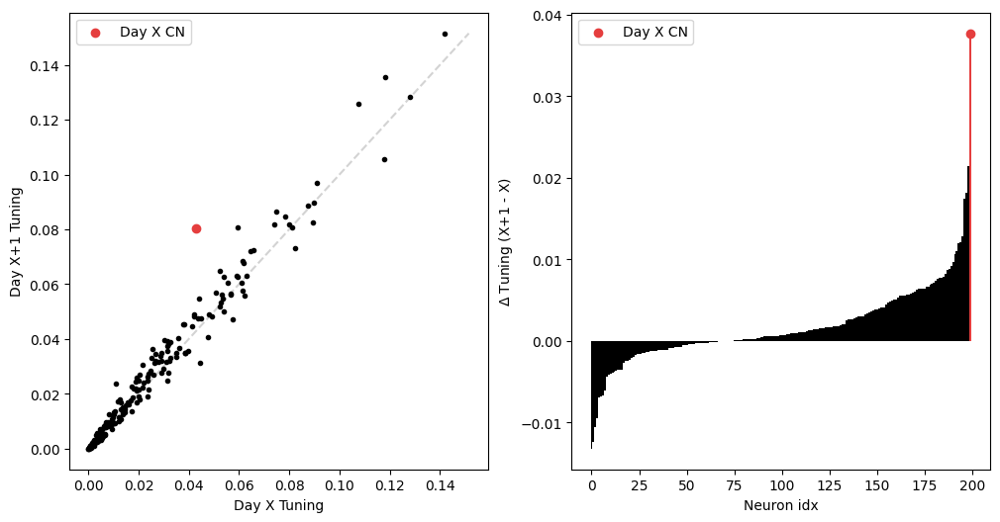

In [ ]:
def compute_and_plot_tuning_toy(session_idx, task_params, train_outputs_all, ax1=None, ax2=None):
    """
    This computes the "tuning" of the toy task (i.e. the mean activity.)
    Note the use of "tuning" to describe this is depricated, now just call it
    mean_activity, so should change vocabulary used in this function at some
    point.
    """

    assert session_idx < task_params['n_sessions'] - 1

    pretrain_tunings = train_outputs_all[session_idx]['mean_stabilize_actvities']
    posttrain_tunings = train_outputs_all[session_idx + 1]['mean_stabilize_actvities']

    current_cn_idx = train_outputs_all[session_idx]['cn_idx']

    delta_tunings = posttrain_tunings - pretrain_tunings
    delta_tuning_sort_idxs = np.argsort(delta_tunings)
    sort_delta_tunings = delta_tunings[delta_tuning_sort_idxs]

    current_cn_perc = (np.where(delta_tuning_sort_idxs == current_cn_idx)[0][0] + 1) / sort_delta_tunings.shape[0]

    if session_idx > 0: # Prev CN idx
        prev_cn_idx = train_outputs_all[session_idx - 1]['cn_idx']
        prev_cn_perc = (np.where(delta_tuning_sort_idxs == prev_cn_idx)[0][0] + 1) / sort_delta_tunings.shape[0]
    else:
        prev_cn_perc = None

    if ax1 is not None:
        ax1.scatter(pretrain_tunings, posttrain_tunings, color='k', marker='.')
        ax1.scatter(pretrain_tunings[current_cn_idx], posttrain_tunings[current_cn_idx], color=c_vals[0], marker='o', zorder=5,
                    label='Day X CN')
        if session_idx > 0: # Prev CN idx
            ax1.scatter(pretrain_tunings[prev_cn_idx], posttrain_tunings[prev_cn_idx], color=c_vals[2], marker='o', zorder=5,
                        label='Day X-1 CN')

        max_tuning = np.max((np.max(pretrain_tunings), np.max(posttrain_tunings)))
        ax1.plot((0, max_tuning), (0, max_tuning), color='lightgrey', linestyle='dashed', zorder=-1)

        ax1.set_xlabel('Day X Tuning')
        ax1.set_ylabel('Day X+1 Tuning')
        ax1.legend()

    if ax2 is not None:
        ax2.bar(np.arange(sort_delta_tunings.shape[0]), sort_delta_tunings, color='k', width=1.0)
        ax2.bar(np.where(delta_tuning_sort_idxs == current_cn_idx)[0], delta_tunings[current_cn_idx], color=c_vals[0],
                width=1.0, zorder=5)
        ax2.scatter(np.where(delta_tuning_sort_idxs == current_cn_idx)[0], delta_tunings[current_cn_idx], color=c_vals[0],
                    marker='o', zorder=5, label='Day X CN')
        if session_idx > 0: # Prev CN idx
            ax2.bar(np.where(delta_tuning_sort_idxs == prev_cn_idx)[0], delta_tunings[prev_cn_idx], color=c_vals[2],
                    width=1.0, zorder=5)
            ax2.scatter(np.where(delta_tuning_sort_idxs == prev_cn_idx)[0], delta_tunings[prev_cn_idx], color=c_vals[2],
                        marker='o', zorder=5, label='Day X-1 CN')

        ax2.set_xlabel('Neuron idx')
        ax2.set_ylabel('$\Delta$ Tuning (X+1 - X)')
        ax2.legend()

    return current_cn_perc, prev_cn_perc

session_idxs = (0,)
# session_idxs = (1, 2, 3,)

if len(session_idxs) == 1:

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

    current_cn_perc, prev_cn_perc = compute_and_plot_tuning_toy(session_idxs[0], task_params, train_outputs_all, ax1=ax1, ax2=ax2)

    print('Current CN perc: {:.2f}'.format(current_cn_perc))
    if session_idxs[0] > 0:
        print('Prev CN perc: {:.2f}'.format(prev_cn_perc))

else:
    fig, axs = plt.subplots(len(session_idxs), 2, figsize=(12, 6*len(session_idxs)))

    # for session_idx in session_idxs:


Older analyses below

Hebbian idx, raw W_ij: 0.32
Hebbian idx, sum_j W_ij: 0.66
done


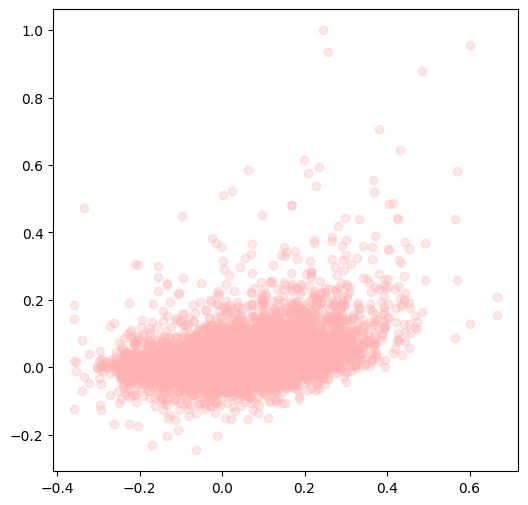

In [ ]:
task_params, train_params, net_params = params

session_idx = 1

output_trunc = train_outputs_all[session_idx]['output'][task_params['n_steps_stabilize']:]
deviation_trunc = (train_outputs_all[session_idx]['output'][task_params['n_steps_stabilize']:] -
                   train_outputs_all[session_idx]['avg_activity'][task_params['n_steps_stabilize']:])

# output_corrs = np.matmul(deviation_trunc.T[:, 1:], output_trunc[:-1, :])
# output_corrs = np.matmul(output_trunc.T[:, 1:], output_trunc[:-1, :]) # Offset by one for pre -> post
# output_corrs = np.matmul(deviation_trunc.T, output_trunc) / (
#     np.linalg.norm(deviation_trunc, axis=0)[:, np.newaxis] *
#     np.linalg.norm(output_trunc, axis=0)[np.newaxis, :]
# )
# output_corrs = np.matmul(output_trunc.T, output_trunc) / (
#     np.linalg.norm(output_trunc, axis=0)[:, np.newaxis] *
#     np.linalg.norm(output_trunc, axis=0)[np.newaxis, :]
# )
output_corrs = np.corrcoef(output_trunc.T) # (n_neurons, n_neurons)

delta_W_rec = train_outputs_all[session_idx]['delta_W_rec'] # (post, pre)

output_corrs_flat = []
output_corrs_sum = np.zeros((output_corrs.shape[0],))
delta_W_rec_flat = []
delta_W_rec_sum = np.zeros((output_corrs.shape[0],))
for neuron_idx1 in range(output_corrs.shape[0]):
    for neuron_idx2 in range(output_corrs.shape[0]):
        if neuron_idx1 != neuron_idx2: # Skip diagonals
            if np.isnan(output_corrs[neuron_idx1, neuron_idx2]):
                continue
            output_corrs_flat.append(output_corrs[neuron_idx1, neuron_idx2])
            delta_W_rec_flat.append(delta_W_rec[neuron_idx1, neuron_idx2])
            output_corrs_sum[neuron_idx1] += output_corrs[neuron_idx1, neuron_idx2]
            delta_W_rec_sum[neuron_idx1] += delta_W_rec[neuron_idx1, neuron_idx2]

delta_W_rec_flat = delta_W_rec_flat / np.max(np.abs(delta_W_rec_flat)) # Normalizes so maximum is 1

corr_coef = np.corrcoef(output_corrs_flat, delta_W_rec_flat)[0, 1]
corr_coef_sum = np.corrcoef(output_corrs_sum, delta_W_rec_sum)[0, 1]

print('Hebbian idx, raw W_ij: {:.2f}'.format(corr_coef))
print('Hebbian idx, sum_j W_ij: {:.2f}'.format(corr_coef_sum))

fig ,ax1 = plt.subplots(1, 1, figsize=(6, 6))
# ax1.hist(delta_W_rec.reshape(-1), bins=50, color=c_vals[0])
# ax1.hist(np.sum(delta_W_rec, axis=-1), bins=50, color=c_vals[0])
ax1.scatter(output_corrs_flat, delta_W_rec_flat, color=c_vals_l[0], alpha=0.3)
# ax1.scatter(output_corrs_sum, delta_W_rec_sum, color=c_vals[0], alpha=0.3)
print('done')

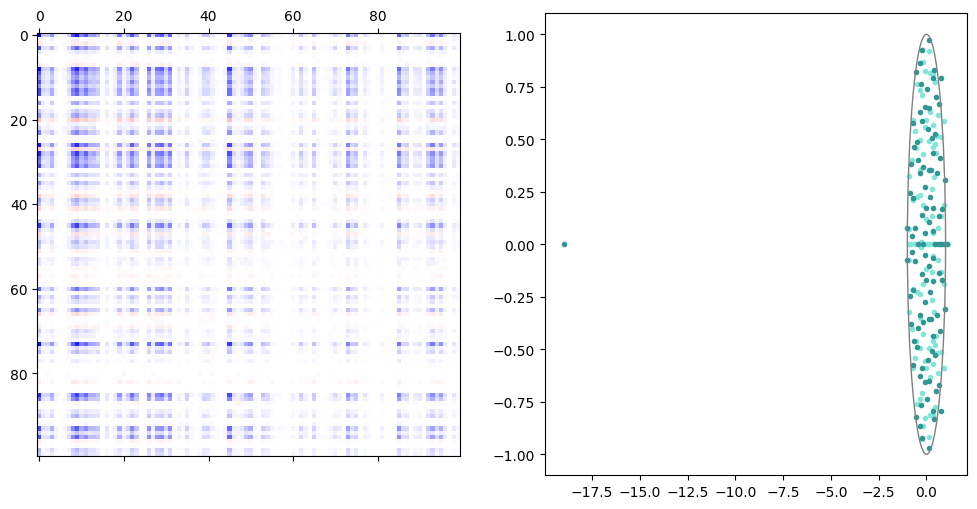

In [ ]:

fig, (ax3, ax4) = plt.subplots(1, 2, figsize=(12,6))

max_val = np.max(np.abs(delta_W_rec))
ax3.matshow(delta_W_rec, vmin=-1*max_val, vmax=max_val, cmap='bwr')

eigvals, eigvecs = np.linalg.eig(W_rec)
ax4.scatter(np.real(eigvals), np.imag(eigvals), color=c_vals[5], marker='.')

eigvals, eigvecs = np.linalg.eig(W_rec_vals[0, :, :])
ax4.scatter(np.real(eigvals), np.imag(eigvals), color=c_vals_l[5], marker='.', zorder=-5)

ax4.add_patch(plt.Circle((0, 0), 1, color='grey', fill=False))

Explores dimensionality of neuronal activity

A different way of comparing two networks. Just takes W_input and W_rec values at a given point in time and feeds same input into both of them to evaluate activity. Note assumes that they both start at default previous activity.



In [ ]:
def run_sequence(net_input, W_inp, W_rec, task_params, net_params):

    output = np.zeros((task_params['n_steps'], task_params['n_neurons'],))
    output_pre_act = np.zeros((task_params['n_steps'], task_params['n_neurons'],))

    for step_idx in range(task_params['n_steps']):

        if step_idx == 0: # Initialization values
            prev_activity = np.zeros((task_params['n_neurons'],))
            prev_activity_pre_act = np.zeros((task_params['n_neurons'],))
        else:
            prev_activity = output[step_idx-1]
            prev_activity_pre_act = output_pre_act[step_idx-1]

        output[step_idx], output_pre_act[step_idx] = net_forward(
            W_inp, net_input[step_idx], W_rec, prev_activity, prev_activity_pre_act, net_params
        )

        # Clip total activity for numerical stability
        if 'max_activity' in task_params:
            output[step_idx] = np.clip(output[step_idx], None, task_params['max_activity'])

    return output, output_pre_act

In [ ]:
session_idx = 1

net_input = setup_task_and_input(task_params)

cn_idx = train_outputs_all[session_idx]['cn_idx']

step_idx_i = 900
loss_idx_i = np.argmin(np.abs(np.array(train_outputs_all[session_idx]['loss_steps']) - step_idx_i))
W_inp_i = train_outputs_all[session_idx]['W_inp_vals'][0]
W_rec_i = train_outputs_all[session_idx]['W_rec_vals'][loss_idx_i]

step_idx_f = 500
loss_idx_f = np.argmin(np.abs(np.array(train_outputs_all[session_idx]['loss_steps']) - step_idx_f))
W_inp_f = train_outputs_all[session_idx]['W_inp_vals'][0]
W_rec_f = train_outputs_all[session_idx]['W_rec_vals'][loss_idx_f]

output_i, _ = run_sequence(net_input, W_inp_i, W_rec_i, task_params, net_params)
output_f, _ = run_sequence(net_input, W_inp_f, W_rec_f, task_params, net_params)

In [ ]:
output_i_PCA = PCA()
output_i_PCA.fit(output_i)
output_f_PCA = PCA()
output_f_PCA.fit(output_f)

pr_i = participation_ratio_vector(output_i_PCA.explained_variance_ratio_) / task_params['n_neurons']
pr_f = participation_ratio_vector(output_f_PCA.explained_variance_ratio_) / task_params['n_neurons']
print('-- I network --')
print(' PR: {:.3f}'.format(pr_i))
print(' Sparsity: {:.3f}'.format(np.sum(output_i > 1e-3 * np.mean(output_i)) / np.prod(output_i.shape)))
print(' Magnitude: {:.3f}, CN only: {:.3f}'.format(np.mean(output_i), np.mean(output_i[:, cn_idx])))
print('-- F network --')
print(' PR: {:.3f}'.format(pr_f))
print(' Sparsity: {:.3f}'.format(np.sum(output_f > 1e-3 * np.mean(output_i)) / np.prod(output_f.shape)))
print(' Magnitude: {:.3f}, CN only: {:.3f}'.format(np.mean(output_f), np.mean(output_f[:, cn_idx])))

-- I network --
 PR: 0.319
 Sparsity: 0.940
 Magnitude: 0.027, CN only: 0.024
-- F network --
 PR: 0.316
 Sparsity: 0.937
 Magnitude: 0.029, CN only: 0.025


##### Our BCI Analysis

Additional basic analysis for our BCI task

--- Session idx 0 ---


/tmp/ipykernel_2082/2107823586.py:67: RuntimeWarning: Mean of empty slice
  mean_pretrial_times[conv_idx] = task_params['t_step'] / 1000 * np.nanmean(pretrial_lens[conv_idx:conv_idx + n_trial_avg_window])


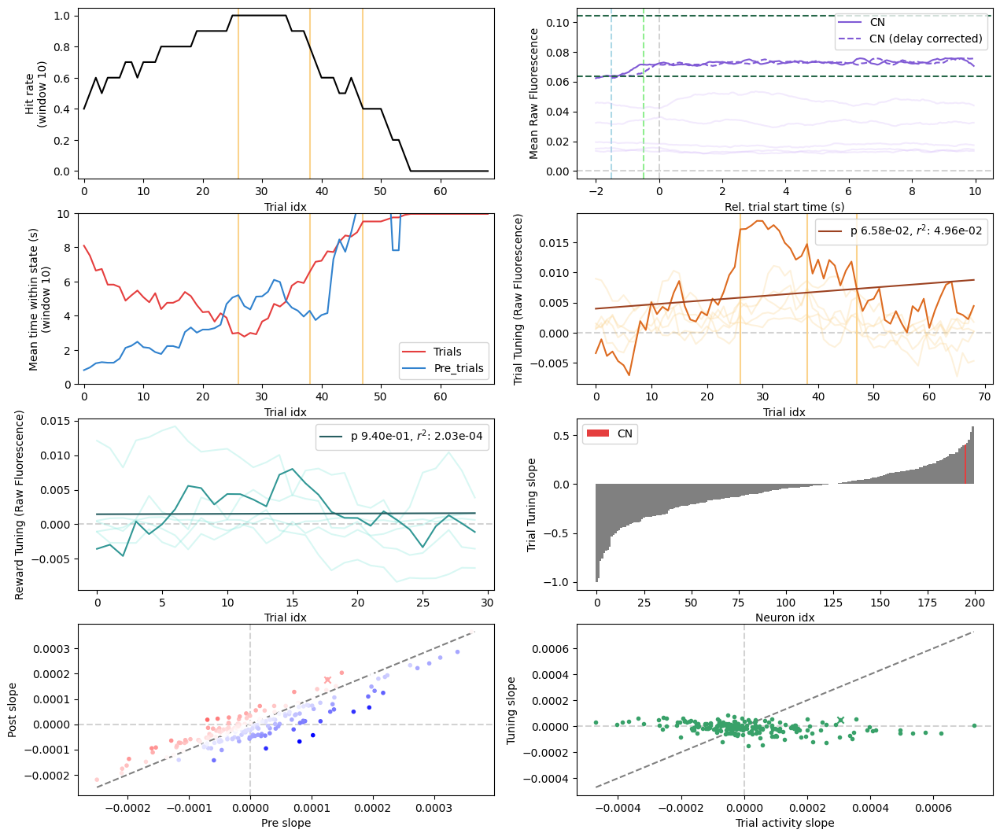

In [77]:
tuning_activity_type = 'raw_fl' # raw_activity, raw_fl, dff

session_idx = 0
if session_idx > task_params['n_sessions']:
    raise ValueError('Indexing session outside of range!')
print('--- Session idx {} ---'.format(session_idx))

fig2, ((ax4, ax5), (ax6, ax7), (ax8, ax9), (ax10, ax11)) = plt.subplots(4, 2, figsize=(15, 13))
# fig2, ax4 = plt.subplots(1, 1, figsize=(16, 3))

n_other_cells = 5
n_trial_avg_window = 10
trial_avg_window = 1 / n_trial_avg_window * np.ones((n_trial_avg_window,))
task_hist = task.hists[session_idx]

n_trials = len(task_hist['trial_ends'])
n_trial_starts = len(task_hist['trial_starts'])

assert len(train_outputs_all[session_idx]['cn_idxs']) == 1
cn_idx = train_outputs_all[session_idx]['cn_idxs'][0]

### Tuning plots ###
if tuning_activity_type in ('raw_activity',):
    tuning_activity = train_outputs_all[session_idx]['output']
    tuning_activity_label = 'Raw Activity'
elif tuning_activity_type in ('raw_fl',):
    tuning_activity = train_outputs_all[session_idx]['output_fl']
    tuning_activity_label = 'Raw Fluorescence'
elif tuning_activity_type in ('dff',):
    tuning_activity, _ = bci_analysis.compute_dff(
        train_outputs_all[session_idx]['output_fl'], task_params, f0_CUTOFF = 0.1 * task_params['task_scale']
    )
    tuning_activity_label = 'dF/F'

post_activities, pre_activities, tuning_lengths = bci_analysis.get_our_bci_trial_aligned_activities(
    tuning_activity, task, session_idx, tuning_type='trial'
)
tuning = bci_analysis.get_our_bci_tuning(post_activities, pre_activities)

n_post_tuning = post_activities.shape[1]
n_pre_tuning = pre_activities.shape[1]
rel_trial_times = task_params['t_step'] / 1000 * np.arange(-n_pre_tuning, n_post_tuning)

if len(task_hist['trial_outcomes']) < n_trial_avg_window:
    print('Not enough trials to plot.')
else:
    mean_hit_rates = fftconvolve(task_hist['trial_outcomes'], trial_avg_window, mode='valid')

    trial_lens = np.array(task_hist['trial_ends']) - np.array(task_hist['trial_starts'][:n_trials])
    mean_trial_times = task_params['t_step'] / 1000 * fftconvolve(trial_lens, trial_avg_window, mode='valid')

    if len(task_hist['pretrial_ends']) < n_trial_avg_window:
        print('Not enough pretrials to plot')
    else:
        raw_pretrial_lens = np.array(task_hist['pretrial_ends']) - np.array(task_hist['pretrial_starts'][:len(task_hist['pretrial_ends'])])
        # We want pre-trials to be aligned with trials, but not all trials have pre-trials, so fill these with nans
        pretrial_lens = np.empty((n_trials,))
        pretrial_lens[:] = np.nan # default will be nan, fill with actual times
        pre_trial_idx = 0
        for trial_idx in range(n_trials):
            if task_hist['trial_outcomes'][trial_idx] and pre_trial_idx < len(raw_pretrial_lens): # May not have pre-trial option for last trial
                pretrial_lens[trial_idx] = raw_pretrial_lens[pre_trial_idx]
                pre_trial_idx += 1

        mean_pretrial_times = np.zeros((n_trials - n_trial_avg_window + 1,))
        for conv_idx in range(n_trials - n_trial_avg_window + 1): # Manual nan convolution
            mean_pretrial_times[conv_idx] = task_params['t_step'] / 1000 * np.nanmean(pretrial_lens[conv_idx:conv_idx + n_trial_avg_window])
        # mean_pretrial_times = task_params['t_step'] / 1000 * fftconvolve(raw_pretrial_lens, trial_avg_window, mode='valid')

# For ax5, mean cell responses around trial starts
trial_activities = np.concatenate((pre_activities, post_activities,), axis=1) # Concatenate along seq dim
mean_trial_activities = np.nanmean(trial_activities, axis=0) # Mean across trials

# For ax6, tuning computation
ax4.plot(np.arange(mean_hit_rates.shape[0]), mean_hit_rates, color='k')
ax4.set_ylabel('Hit rate\n(window {})'.format(n_trial_avg_window))

ax6.plot(np.arange(mean_trial_times.shape[0]), mean_trial_times, color=c_vals[0],
          label='Trials')
ax6.plot(np.arange(mean_pretrial_times.shape[0]), mean_pretrial_times, color=c_vals[1],
          label='Pre_trials')
ax6.set_ylabel('Mean time within state (s)\n(window {})'.format(n_trial_avg_window))
ax6.set_ylim((0, 10.))
ax6.legend()

for ax in (ax4, ax6): # Same x-axis
    ax.set_xlim((-1, mean_hit_rates.shape[0]))
    ax.set_xlabel('Trial idx')

ax5.plot(rel_trial_times, mean_trial_activities[:, cn_idx], color=c_vals[3], label='CN')
if task_params['n_reward_delay'] > 0:
    ax5.plot(
        rel_trial_times[task_params['n_reward_delay']:], mean_trial_activities[:-task_params['n_reward_delay'], cn_idx],
        color=c_vals[3], linestyle='dashed', label='CN (delay corrected)'
    )
for cell_idx in np.random.choice(np.arange(task_params['n_neurons']), size=n_other_cells):
    ax5.plot(rel_trial_times, mean_trial_activities[:, cell_idx], color=c_vals_l[3], alpha=0.3)
ax5.axvline(0.0, color='lightgrey', linestyle='dashed', zorder=-5)
ax5.axvline(-1.5, color='lightblue', linestyle='dashed', zorder=-5) # 1 sec intertrial + 0.5 sec movement backwards
ax5.axvline(-0.5, color='lightgreen', linestyle='dashed', zorder=-5) # 0.5 sec movement backwards
ax5.axhline(0.0, color='lightgrey', linestyle='dashed', zorder=-5)

ax5.axhline(train_outputs_all[session_idx]['threshold'], color=c_vals_d[2], linestyle='dashed')
ax5.axhline(train_outputs_all[session_idx]['threshold'] + task_params['width'], color=c_vals_d[2], linestyle='dashed')

ax5.set_xlabel('Rel. trial start time (s)')
ax5.set_ylabel('Mean {}'.format(tuning_activity_label))
ax5.legend()

# # Raw plots
# ax7.plot(np.arange(n_trials), tuning[:, cn_idx], color=c_vals[4])
# for cell_idx in np.random.choice(np.arange(n_cells), size=n_other_cells):
#     ax7.plot(np.arange(n_trials), tuning[:, cell_idx], color=c_vals_l[4], alpha=0.3, zorder=-1)
# _ = add_regression_line(np.arange(n_trials), tuning[:, cn_idx], ax=ax7, color=c_vals_d[4], zorder=5)

mean_cn_tuning = fftconvolve(tuning[:, cn_idx], trial_avg_window, mode='valid')
ax7.plot(np.arange(mean_cn_tuning.shape[0]), mean_cn_tuning, color=c_vals[4])
_ = add_regression_line(np.arange(mean_cn_tuning.shape[0]), mean_cn_tuning, ax=ax7, color=c_vals_d[4], zorder=5)
for cell_idx in np.random.choice(np.arange(task_params['n_neurons']), size=n_other_cells):
    mean_tuning = fftconvolve(tuning[:, cell_idx], trial_avg_window, mode='valid')
    ax7.plot(np.arange(mean_tuning.shape[0]), mean_tuning, color=c_vals_l[4], alpha=0.3, zorder=-1)
ax7.axhline(0.0, color='lightgrey', linestyle='dashed', zorder=-5)
ax7.legend()

ax7.set_xlabel('Trial idx')
ax7.set_ylabel('Trial Tuning ({})'.format(tuning_activity_label))

# Quantify change in tuning
tuning_slopes = np.zeros((task_params['n_neurons'],))

for neuron_idx in range(task_params['n_neurons']):
    mean_tuning = fftconvolve(tuning[:, neuron_idx], trial_avg_window, mode='valid')
    tuning_slopes[neuron_idx], intercept, rvalue = add_regression_line(np.arange(mean_tuning.shape[0]), mean_tuning)

# Normalizes
tuning_slopes = tuning_slopes / np.max(np.abs(tuning_slopes))

tuning_slopes_sort = np.argsort(tuning_slopes)
cn_sort_idx = np.where(tuning_slopes_sort == cn_idx)[0]

ax9.bar(np.arange(tuning_slopes.shape[0]), tuning_slopes[tuning_slopes_sort], color='grey', width=1.0)
ax9.bar(np.where(tuning_slopes_sort == cn_idx)[0], tuning_slopes[cn_idx],
        color=c_vals[0], width=1.0, zorder=5, label='CN')
if session_idx > 0:
    prev_cn_idx = train_outputs_all[session_idx - 1]['cn_idxs'][0]
    ax9.bar(np.where(tuning_slopes_sort == prev_cn_idx)[0], tuning_slopes[prev_cn_idx],
            color=c_vals[2], width=1.0, zorder=5, label='prev CN')

ax9.set_xlabel('Neuron idx')
ax9.set_ylabel('Trial Tuning slope')
ax9.legend()

### Reward tuning computation

post_activities_rw, pre_activities_rw, tuning_lengths_rw = bci_analysis.get_our_bci_trial_aligned_activities(
    tuning_activity, task, session_idx, tuning_type='reward', post_tuning_time=2000,
)
tuning_rw = bci_analysis.get_our_bci_tuning(post_activities_rw, pre_activities_rw)

mean_cn_tuning_rw = fftconvolve(tuning_rw[:, cn_idx], trial_avg_window, mode='valid')
ax8.plot(np.arange(mean_cn_tuning_rw.shape[0]), mean_cn_tuning_rw, color=c_vals[5])
_ = add_regression_line(np.arange(mean_cn_tuning_rw.shape[0]), mean_cn_tuning_rw, ax=ax8, color=c_vals_d[5], zorder=5)
for cell_idx in np.random.choice(np.arange(task_params['n_neurons']), size=n_other_cells):
    mean_tuning_rw = fftconvolve(tuning_rw[:, cell_idx], trial_avg_window, mode='valid')
    ax8.plot(np.arange(mean_tuning_rw.shape[0]), mean_tuning_rw, color=c_vals_l[5], alpha=0.3, zorder=-1)
ax8.axhline(0.0, color='lightgrey', linestyle='dashed', zorder=-5)
ax8.legend()

ax8.set_xlabel('Trial idx')
ax8.set_ylabel('Reward Tuning ({})'.format(tuning_activity_label))

# ax9.scatter(np.arange(task_params['n_neurons']), tuning_slopes[tuning_slopes_sort], marker='.', color='k')
# ax9.scatter(cn_sort_idx, tuning_slopes[tuning_slopes_sort][cn_sort_idx], marker='.', color=c_vals[0], zorder=5)

### Quantification of how the solution is reached
# ax10: Plots pre- and post- trial start response changes for each cell to see if
#   it is mostly the pre or post response that is changing
# ax11: Plots trial tuning and trial activity for each cell to see if its mostly
#   an increase in activity or an increase in tuning that leads to solutions

mean_post_activities = np.nanmean(post_activities, axis=1) # Mean over time
mean_pre_activities = np.nanmean(pre_activities, axis=1) # Mean over time
tuning = bci_analysis.get_our_bci_tuning(post_activities, pre_activities)
mean_trial_activities = np.nanmean(post_activities, axis=1) + np.nanmean(pre_activities, axis=1)

# Quantify change in tuning, pre, and post
tuning_slopes = np.zeros((task_params['n_neurons'],))
trial_activity_slopes = np.zeros((task_params['n_neurons'],))
post_slopes = np.zeros((task_params['n_neurons'],))
pre_slopes = np.zeros((task_params['n_neurons'],))

for neuron_idx in range(task_params['n_neurons']):
    tuning_slopes[neuron_idx], _, _ = add_regression_line(np.arange(tuning.shape[0]), tuning[:, neuron_idx])
    trial_activity_slopes[neuron_idx], _, _ = add_regression_line(np.arange(mean_trial_activities.shape[0]), mean_trial_activities[:, neuron_idx])
    post_slopes[neuron_idx], _, _ = add_regression_line(np.arange(mean_post_activities.shape[0]), mean_post_activities[:, neuron_idx])
    pre_slopes[neuron_idx], _, _ = add_regression_line(np.arange(mean_pre_activities.shape[0]), mean_pre_activities[:, neuron_idx])

max_vals = np.max(np.abs(tuning_slopes))
ax10.scatter(pre_slopes, post_slopes, c=tuning_slopes, cmap='bwr', vmin=-max_vals, vmax=max_vals, marker='.')
ax10.scatter(pre_slopes[cn_idx], post_slopes[cn_idx], c=tuning_slopes[cn_idx], cmap='bwr', vmin=-max_vals, vmax=max_vals, marker='x')
max_val = np.max((np.max(pre_slopes), np.max(post_slopes)))
min_val = np.min((np.min(pre_slopes), np.min(post_slopes)))
ax10.plot((min_val, max_val), (min_val, max_val), color='grey', linestyle='dashed', zorder=-5)

ax10.set_xlabel('Pre slope')
ax10.set_ylabel('Post slope')

ax11.scatter(trial_activity_slopes, tuning_slopes, color=c_vals[2], marker='.')
ax11.scatter(trial_activity_slopes[cn_idx], tuning_slopes[cn_idx], color=c_vals[2], marker='x')
max_val = np.max((np.max(trial_activity_slopes), np.max(tuning_slopes)))
min_val = np.min((np.min(trial_activity_slopes), np.min(tuning_slopes)))
ax11.plot((min_val, max_val), (min_val, max_val), color='grey', linestyle='dashed', zorder=-5)
ax11.set_xlabel('Trial activity slope')
ax11.set_ylabel('Tuning slope')

for ax in (ax10, ax11):
    ax.axhline(0., color='lightgrey', linestyle='dashed', zorder=-5)
    ax.axvline(0., color='lightgrey', linestyle='dashed', zorder=-5)
    
for ax in(ax4, ax6, ax7,):
    if 'threshold_changes' in task.hist.keys():
        for threshold_trial in task.hists[session_idx]['threshold_trials']:
            ax.axvline(threshold_trial - n_trial_avg_window + 1, color=c_vals_l[4], zorder=-5)

Some (single application) photostimulation sanity checks. This code does essentially the same thing as bci_analysis.get_photostim_results but also plots a lot of intermediate quantities for visualization.

Using raw_fl for PS


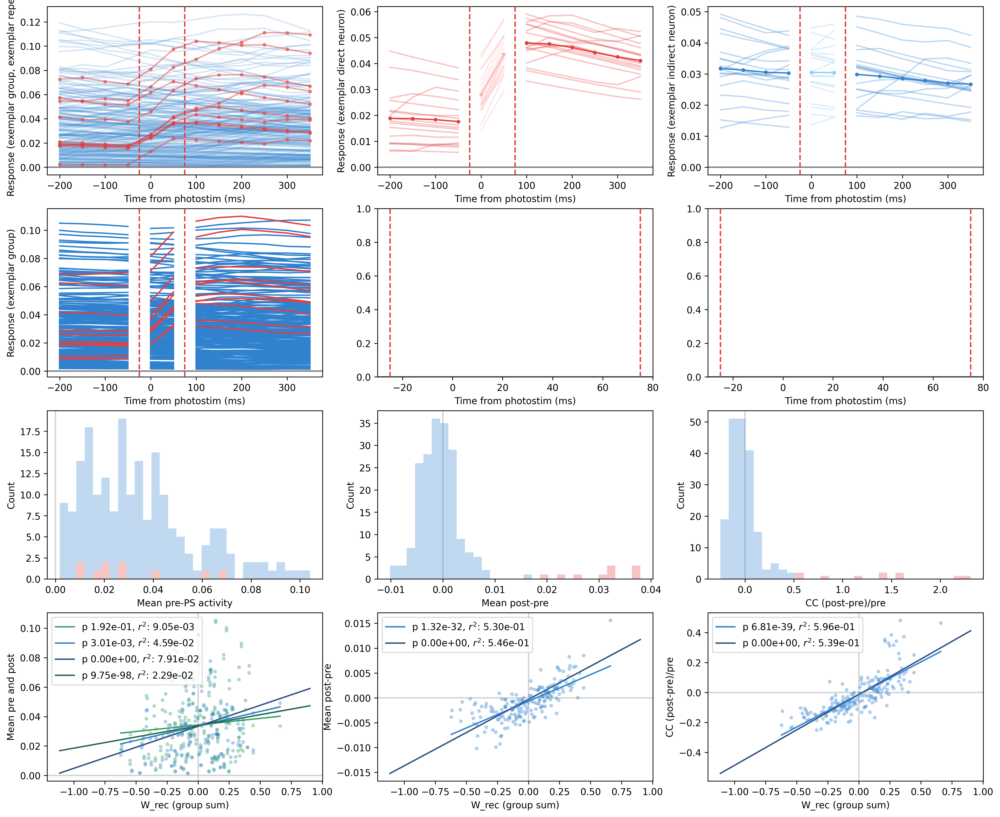

In [126]:
assert task_params['n_sessions'] == 1
session_idx = 0 # 0 is initial, #1 is final

exemplar_group_idx = 5
exemplar_neuron_idx = task_ps.groups[exemplar_group_idx, 2] # Exemplar neuron is inside group
exemplar_neuron_idx2 = 22 
assert exemplar_neuron_idx2 not in task_ps.groups[exemplar_group_idx]

if session_idx == 0:
    train_outputs_ps = train_outputs_all[0]['train_outputs_ps_init']
    W_rec_val = train_outputs_all[0]['W_rec_vals'][0] # Start of session
elif session_idx == 1:
    train_outputs_ps = train_outputs_all[0]['train_outputs_ps']
    W_rec_val = train_outputs_all[0]['W_rec_vals'][-1] # End of session

# task_ps
ps_activity_type = 'raw_fl' # raw_fl, raw_activity
omit_ps_times=True
n_prev_dir_omit = 1 # Number of stimulations after a neuron is direct to omit its response (set to nans)

W_rec_groups = np.nan * np.ones((W_rec_val.shape[0], task_ps.n_groups)) # Change in weight per group
for group_idx in range(task_ps.n_groups):
    W_rec_groups[:, group_idx] = np.sum(W_rec_val[:, task_ps.groups[group_idx]], axis=-1)

task_params, _, _ = params

n_neurons = train_outputs_ps['output_ps'].shape[-1]
n_groups = task_ps.groups.shape[0]

direct_mask = []
indirect_mask = []
for neuron_idx in range(n_neurons):
    if neuron_idx in task_ps.groups[exemplar_group_idx]:
        direct_mask.append(neuron_idx)
    else:
        indirect_mask.append(neuron_idx)
direct_mask = np.array(direct_mask)
indirect_mask = np.array(indirect_mask)       
        
# Sometimes fluorescence/dff won't be saved for efficiency, so need to recompute in these cases
print('Using raw_fl for PS')
if ps_activity_type in ('raw_activity',):
    output_ps = train_outputs_ps['output_ps']
elif ps_activity_type in ('raw_fl',):
    if 'output_fl_ps' not in train_outputs_ps:
        train_outputs_ps['output_fl_ps'] = bci_analysis.reproduce_output_fl(
            train_outputs_ps['output_ps'], task_params['fl_kernel']
        )
    output_ps = train_outputs_ps['output_fl_ps']

T_STIM = int(np.round(task_ps.t_max_stim_on * 1000)) # s -> ms
T_POST_STIM = 300 # ms, matched to what Kayvon uses
T_PRE_STIM = 200 # ms, matched to what Kayvon uses
n_during_stim = int(np.round(T_STIM / task_params['t_step']))
n_post_stim = int(np.round(T_POST_STIM / task_params['t_step']))
n_pre_stim = int(np.round(T_PRE_STIM / task_params['t_step']))

assert n_pre_stim > 0

# Means across all group presentation
group_inputs = np.zeros((task_ps.n_groups, task_params['n_neurons'], n_during_stim,)) # Input into cell during photostim
group_post_responses = np.zeros((task_ps.n_groups, task_params['n_neurons'], n_post_stim,)) # Response of cell to photostim
group_pre_responses = np.zeros((task_ps.n_groups, task_params['n_neurons'], n_pre_stim,)) # Response of cell before photostim

task_ps_hist = task_ps.hists[session_idx]

# This just gathers the raw data and separates into groups, then means are taken below
raw_group_post_responses = [[] for _ in range(task_ps.n_groups)]
raw_group_stim_responses = [[] for _ in range(task_ps.n_groups)] # During PS
raw_group_pre_responses = [[] for _ in range(task_ps.n_groups)]

# Need to account for some weird off by one errors
n_stim_starts = len(task_ps.hists[session_idx]['stim_starts'])
n_stim_ends = len(task_ps.hists[session_idx]['stim_ends'])
n_stim_group_idxs = len(task_ps.hists[session_idx]['stim_group_idxs'])
assert n_stim_ends == n_stim_starts + 1
assert n_stim_ends == n_stim_group_idxs + 1

fig, ((ax1, ax2, ax3), (ax1p, ax2p, ax3p,), (ax4, ax5, ax6), (ax7, ax8, ax9),) = plt.subplots(4, 3, figsize=(18, 15))
ps_times = np.arange(-n_pre_stim, n_during_stim + n_post_stim) * task_params['t_step']
plot_1_exemplar = False # Only plot first instance of group being photostimulated

for stim_idx in range(1, len(task_ps_hist['stim_ends']) - 1): # 1 since no preresponse at start, -1 to avoid end cutoffs
    group_idx = task_ps_hist['stim_group_idxs'][stim_idx-1] # Correct some dumb off by one errors in saving history
    stim_start = task_ps_hist['stim_starts'][stim_idx-1] # Correct some dumb off by one errors in saving history
    stim_end = task_ps_hist['stim_ends'][stim_idx]
    
    stim_start += 1 # Again need to correct off by one indexing errors, verified this on raw PS responses
    stim_end += 1 # Again need to correct off by one indexing errors, verified this on raw PS responses

    assert stim_start < stim_end
    assert group_idx == task_ps.group_order[stim_idx]
    
    if omit_ps_times: # From end onwards
        post_response = np.copy(output_ps[stim_end:stim_end + n_post_stim])
        stim_response = np.copy(output_ps[stim_start:stim_end])
    else: # From start onwards
        post_response = np.copy(output_ps[stim_start:stim_start + n_post_stim])
    pre_response = np.copy(output_ps[stim_start-n_pre_stim:stim_start])
    
    if n_prev_dir_omit > 0: # Set responses to nans if recently directly stimulated
        prev_dir_mask = np.zeros((n_neurons,), dtype=bool)
        n_steps_back = np.min((n_prev_dir_omit, stim_idx)) # If stim_idx = 1 and n_prev_dir_omit = 2, can only go back 1
        for rel_stim_idx in range(1, n_steps_back+1): # Inclusive of n_steps_back, skip 0 steps back
            prev_group_idx = task_ps_hist['stim_group_idxs'][stim_idx-1-rel_stim_idx] # Correct some dumb off by one errors in saving history
            # print('Current step {} (group {}) prev step {} (group {})'.format(
            #     stim_idx, group_idx, stim_idx-rel_stim_idx, prev_group_idx
            # ))
            prev_dir_mask[task_ps.groups[prev_group_idx]] = True

        post_response[:, prev_dir_mask] = np.nan # Set all timesteps to nans
        stim_response[:, prev_dir_mask] = np.nan # Set all timesteps to nans
        pre_response[:, prev_dir_mask] = np.nan # Set all timesteps to nans
    
    raw_group_post_responses[group_idx].append(post_response)
    raw_group_stim_responses[group_idx].append(stim_response)
    raw_group_pre_responses[group_idx].append(pre_response)
    
    if group_idx == exemplar_group_idx and not plot_1_exemplar: # Plot some exemplars for the         
        for neuron_idx in range(output_ps.shape[-1]): # Direct neruon
            if neuron_idx in task_ps.groups[group_idx]:
                ax1.plot(ps_times, output_ps[stim_start-n_pre_stim:stim_end + n_post_stim, neuron_idx], color=c_vals[0], zorder=5, alpha=0.5, marker='.')
            else:
                ax1.plot(ps_times, output_ps[stim_start-n_pre_stim:stim_end + n_post_stim, neuron_idx], color=c_vals[1], zorder=-5, alpha=0.2)
                
        plot_1_exemplar = True 

        
# Now take mean over each group photostimulus -> (n_neurons, n_time)
for group_idx in range(n_groups):

    if len(raw_group_post_responses) == 0:
        raise ValueError('Group does not have reponses!!')
        
    raw_group_pre_responses[group_idx] = np.array(raw_group_pre_responses[group_idx])
    raw_group_stim_responses[group_idx] = np.array(raw_group_stim_responses[group_idx])
    raw_group_post_responses[group_idx] = np.array(raw_group_post_responses[group_idx])
    
    group_post_responses[group_idx] = np.nanmean(raw_group_post_responses[group_idx], axis=0).T # Mean across repeats
    group_pre_responses[group_idx] = np.nanmean(np.array(raw_group_pre_responses[group_idx]), axis=0).T # Mean across repeats
    
    if group_idx == exemplar_group_idx:
        
        # Plot repeat variation for one particular neuron
        for repeat_idx in range(raw_group_pre_responses[group_idx].shape[0]):
            ax2.plot(ps_times[:n_pre_stim], raw_group_pre_responses[group_idx][repeat_idx, :, exemplar_neuron_idx], color=c_vals[0], alpha=0.3)
            ax2.plot(ps_times[-n_post_stim:], raw_group_post_responses[group_idx][repeat_idx, :, exemplar_neuron_idx], color=c_vals[0], alpha=0.3)
            ax2.plot(ps_times[n_pre_stim:-n_post_stim], raw_group_stim_responses[group_idx][repeat_idx, :, exemplar_neuron_idx], color=c_vals_l[0], alpha=0.3)
            # ax2.plot((ps_times[n_pre_stim-1], ps_times[-n_post_stim]), (
            #     raw_group_pre_responses[group_idx][repeat_idx, -1, exemplar_neuron_idx],
            #     raw_group_post_responses[group_idx][repeat_idx, 0, exemplar_neuron_idx]
            # ), color=c_vals[0], alpha=0.3, linestyle='dashed')
            
            ax3.plot(ps_times[:n_pre_stim], raw_group_pre_responses[group_idx][repeat_idx, :, exemplar_neuron_idx2], color=c_vals[1], alpha=0.3)
            ax3.plot(ps_times[-n_post_stim:], raw_group_post_responses[group_idx][repeat_idx, :, exemplar_neuron_idx2], color=c_vals[1], alpha=0.3)
            ax3.plot(ps_times[n_pre_stim:-n_post_stim], raw_group_stim_responses[group_idx][repeat_idx, :, exemplar_neuron_idx2], color=c_vals_l[1], alpha=0.3)
        
        for neuron_idx in range(n_neurons):
            
            if neuron_idx in task_ps.groups[group_idx]:
                plot_color = c_vals[0]
                plot_zorder = 5
            else:
                plot_color = c_vals[1]
                plot_zorder = -5
            ax1p.plot(ps_times[:n_pre_stim], group_pre_responses[group_idx][neuron_idx, :], color=plot_color, zorder=plot_zorder)
            ax1p.plot(ps_times[-n_post_stim:], group_post_responses[group_idx][neuron_idx, :], color=plot_color, zorder=plot_zorder)
            # ax1p.plot((ps_times[n_pre_stim-1], ps_times[-n_post_stim]), (
            #     group_pre_responses[group_idx][neuron_idx, -1], group_post_responses[group_idx][neuron_idx, 0]
            # ), color=plot_color, linestyle='dashed', zorder=plot_zorder)
            ax1p.plot(ps_times[n_pre_stim:-n_post_stim], np.nanmean(raw_group_stim_responses[group_idx], axis=0).T[neuron_idx, :], color=plot_color, zorder=plot_zorder)
            # mean_pre = np.nanmean(group_pre_responses[group_idx][neuron_idx, :]) # Mean over times
            # ax1p.plot(ps_times[:n_pre_stim], group_pre_responses[group_idx][neuron_idx, :] - mean_pre, color=plot_color, zorder=plot_zorder)
            # ax1p.plot(ps_times[-n_post_stim:], group_post_responses[group_idx][neuron_idx, :] - mean_pre, color=plot_color, zorder=plot_zorder)
            # ax1p.plot(ps_times[n_pre_stim:-n_post_stim], np.nanmean(raw_group_stim_responses[group_idx], axis=0).T[neuron_idx, :] - mean_pre, color=plot_color, zorder=plot_zorder)
            # # ax1p.plot((ps_times[n_pre_stim-1], ps_times[-n_post_stim]), (
            # #     group_pre_responses[group_idx][neuron_idx, -1] - mean_pre, group_post_responses[group_idx][neuron_idx, 0] - mean_pre
            # # ), color=plot_color, linestyle='dashed', zorder=plot_zorder)
            
            if neuron_idx == exemplar_neuron_idx:
                ax2.plot(ps_times[:n_pre_stim], group_pre_responses[group_idx][neuron_idx, :], color=c_vals[0], zorder=5, marker='.')
                ax2.plot(ps_times[-n_post_stim:], group_post_responses[group_idx][neuron_idx, :], color=c_vals[0], zorder=5, marker='.')
                ax2.plot(ps_times[n_pre_stim:-n_post_stim], np.nanmean(raw_group_stim_responses[group_idx], axis=0).T[neuron_idx, :], color=c_vals_l[0], zorder=5, marker='.')
                # ax2.plot((ps_times[n_pre_stim-1], ps_times[-n_post_stim]), (
                #     group_pre_responses[group_idx][neuron_idx, -1], group_post_responses[group_idx][neuron_idx, 0]
                # ), color=c_vals[0], linestyle='dashed')
            if neuron_idx == exemplar_neuron_idx2:
                ax3.plot(ps_times[:n_pre_stim], group_pre_responses[group_idx][neuron_idx, :], color=c_vals[1], zorder=5, marker='.')
                ax3.plot(ps_times[-n_post_stim:], group_post_responses[group_idx][neuron_idx, :], color=c_vals[1], zorder=5, marker='.')
                ax3.plot(ps_times[n_pre_stim:-n_post_stim], np.nanmean(raw_group_stim_responses[group_idx], axis=0).T[neuron_idx, :], color=c_vals_l[1], zorder=5, marker='.')
        
for ax in (ax1, ax2, ax3, ax1p, ax2p, ax3p,):
    ax.axvline(-0.5*task_params['t_step'], color=c_vals[0], linestyle='dashed', zorder=10)
    ax.axvline(T_STIM-0.5*task_params['t_step'], color=c_vals[0], linestyle='dashed', zorder=10)
    ax.set_xlabel('Time from photostim (ms)')
    ax.axhline(0.0, color='grey', zorder=-5)
    
ax1.set_ylabel('Response (exemplar group, exemplar repeat)')
ax2.set_ylabel('Response (exemplar direct neuron)')
ax3.set_ylabel('Response (exemplar indirect neuron)')
ax1p.set_ylabel('Response (exemplar group)')
 
### Compute various measures of PS response from post and pre PS activity ###
causal_connectivity = np.nan * np.ones((n_neurons, n_groups))

# Only for plotting purposes
W_rec_indirect = []
cc_pre_indirect = []
cc_post_indirect = []
cc_no_pre_indirect = []
cc_indirect = []
for group_idx in range(n_groups):
    
    direct_mask = task_ps.groups[group_idx]
    indirect_mask = np.arange(n_neurons)
    indirect_mask = np.delete(indirect_mask, task_ps.groups[group_idx])
    
    with warnings.catch_warnings(): # Suppress mean of empty slice warnings, since they return nan as expected
        warnings.simplefilter("ignore", category=RuntimeWarning) 
        
        pre_mean = np.nanmean(np.nanmean(raw_group_pre_responses[group_idx], axis=1), axis=0) # Mean over time, then repeats (n_neurons,)
        if np.where(pre_mean == 0.)[0].shape[0] > 0:
            print('{} neurons with pre_mean = 0, setting to nonzero minimum.'.format(np.where(pre_mean == 0.)[0].shape[0]))
            min_pre_mean = np.min(pre_mean[np.where(pre_mean > 0.)])
            pre_mean = np.where(pre_mean > 0., pre_mean, min_pre_mean)
        
        repeat_responses = ( # Mean over time for post and pre
            np.nanmean(raw_group_post_responses[group_idx], axis=1) - np.nanmean(raw_group_pre_responses[group_idx], axis=1)
        ) / pre_mean[None, :]

        causal_connectivity[:, group_idx] = np.nanmean(repeat_responses, axis=0) / np.nanstd(repeat_responses, axis=0) # Now mean over repeats

        # These alternative quantities are computed just for visualization purposes
        cc_pre = np.nanmean(np.nanmean(raw_group_pre_responses[group_idx], axis=1), axis=0)
        cc_post = np.nanmean(np.nanmean(raw_group_post_responses[group_idx], axis=1), axis=0)

        cc_no_pre = np.nanmean(
            np.nanmean(raw_group_post_responses[group_idx], axis=1) - np.nanmean(raw_group_pre_responses[group_idx], axis=1), axis=0
        )

    W_rec_indirect.append(W_rec_groups[indirect_mask, group_idx])
    cc_pre_indirect.append(cc_pre[indirect_mask])
    cc_post_indirect.append(cc_post[indirect_mask])
    cc_no_pre_indirect.append(cc_no_pre[indirect_mask])
    cc_indirect.append(causal_connectivity[indirect_mask, group_idx])

    if group_idx == exemplar_group_idx: # Exemplar plots for visualization

        ### Scatter plots of various response values ###
        _, bins = np.histogram(pre_mean, bins=30)
        count, _, _ = ax4.hist(pre_mean[direct_mask], bins=bins, color=c_vals[0], alpha=0.3)
        ax4.hist(pre_mean[indirect_mask], bins=bins, bottom=count, color=c_vals[1], alpha=0.3)
        ax4.set_xlabel('Mean pre-PS activity')

        # Without pre normalization, to see what it looks like
        _, bins = np.histogram(cc_no_pre, bins=30)
        count, _, _ = ax5.hist(cc_no_pre[direct_mask], bins=bins, color=c_vals[0], alpha=0.3)
        ax5.hist(cc_no_pre[indirect_mask], bins=bins, bottom=count, color=c_vals[1], alpha=0.3)
        ax5.set_xlabel('Mean post-pre')

        _, bins = np.histogram(causal_connectivity[:, group_idx], bins=30)
        count, _, _ = ax6.hist(causal_connectivity[direct_mask, group_idx], bins=bins, color=c_vals[0], alpha=0.3)
        ax6.hist(causal_connectivity[indirect_mask, group_idx], bins=bins, bottom=count, color=c_vals[1], alpha=0.3)
        ax6.set_xlabel('CC (post-pre)/pre')

        ### Fits to true W_rec vals ###
        ax7.scatter(W_rec_groups[indirect_mask, group_idx], cc_pre[indirect_mask], color=c_vals[2], alpha=0.3, marker='.')
        add_regression_line(
            W_rec_groups[indirect_mask, group_idx], cc_pre[indirect_mask], ax=ax7, color=c_vals[2],
        )
        ax7.scatter(W_rec_groups[indirect_mask, group_idx], cc_post[indirect_mask], color=c_vals[1], alpha=0.3, marker='.')
        add_regression_line(
            W_rec_groups[indirect_mask, group_idx], cc_post[indirect_mask], ax=ax7, color=c_vals[1],
        )
        ax7.set_ylabel('Mean pre and post')

        ax8.scatter(W_rec_groups[indirect_mask, group_idx], cc_no_pre[indirect_mask], 
                    color=c_vals[1], alpha=0.3, marker='.')
        add_regression_line(
            W_rec_groups[indirect_mask, group_idx], cc_no_pre[indirect_mask], 
            ax=ax8, color=c_vals[1],
        )
        ax8.set_ylabel('Mean post-pre')

        ax9.scatter(W_rec_groups[indirect_mask, group_idx], causal_connectivity[indirect_mask, group_idx], 
                    color=c_vals[1], alpha=0.3, marker='.')
        add_regression_line(
            W_rec_groups[indirect_mask, group_idx], causal_connectivity[indirect_mask, group_idx], 
            ax=ax9, color=c_vals[1],
        )
        ax9.set_ylabel('CC (post-pre)/pre')

W_rec_indirect = np.concatenate(W_rec_indirect)
cc_pre_indirect = np.concatenate(cc_pre_indirect)
cc_post_indirect = np.concatenate(cc_post_indirect)
cc_no_pre_indirect = np.concatenate(cc_no_pre_indirect)
cc_indirect = np.concatenate(cc_indirect)

add_regression_line(W_rec_indirect, cc_post_indirect, ax=ax7, color=c_vals_d[1])
add_regression_line(W_rec_indirect, cc_pre_indirect, ax=ax7, color=c_vals_d[2])
add_regression_line(W_rec_indirect, cc_no_pre_indirect, ax=ax8, color=c_vals_d[1])
add_regression_line(W_rec_indirect, cc_indirect, ax=ax9, color=c_vals_d[1])

del W_rec_indirect
del cc_post_indirect
del cc_no_pre_indirect
del cc_indirect

for ax in (ax4, ax5, ax6):
    ax.set_ylabel('Count')
    ax.axvline(0.0, color='lightgrey', zorder=-5)
for ax in (ax7, ax8, ax9):
    ax.legend()
    ax.set_xlabel('W_rec (group sum)')
    ax.axvline(0.0, color='lightgrey', zorder=-5)
    ax.axhline(0.0, color='lightgrey', zorder=-5)

Some sanity checks on delta PS.

Using raw_fl for PS
Using raw_fl for PS
---- cc ----
 Initial fit: 2.0e+00 (p: 0.0e+00 r^2: 6.2e-01)
 Final   fit: 1.9e+00 (p: 0.0e+00 r^2: 5.9e-01)
 Delta   fit: 2.7e+00 (p: 2.8e-06 r^2: 1.2e-03)
Using raw_fl for PS
Using raw_fl for PS
---- post-pre ----
 Initial fit: 1.3e-02 (p: 0.0e+00 r^2: 5.5e-01)
 Final   fit: 1.4e-02 (p: 0.0e+00 r^2: 4.9e-01)
 Delta   fit: -1.0e-03 (p: 7.8e-01 r^2: 4.0e-06)
Using raw_fl for PS
Using raw_fl for PS
---- post_only ----
 Initial fit: 2.9e-02 (p: 0.0e+00 r^2: 7.9e-02)
 Final   fit: 3.9e-02 (p: 4.3e-242 r^2: 5.6e-02)
 Delta   fit: 2.5e+00 (p: 0.0e+00 r^2: 6.1e-01)
Using raw_fl for PS
Using raw_fl for PS
---- pre_only ----
 Initial fit: 1.5e-02 (p: 9.8e-98 r^2: 2.3e-02)
 Final   fit: 2.5e-02 (p: 4.6e-98 r^2: 2.3e-02)
 Delta   fit: 2.5e+00 (p: 0.0e+00 r^2: 6.1e-01)


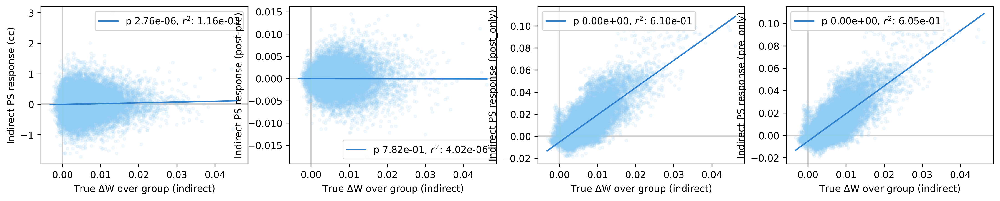

In [130]:
session_idx = 0

causal_connectivity_mode = 'groups_to_neurons' # groups_to_neurons, neurons_to_neurons
causal_connectivity_neurons_mode = 2 # Only matters if causal_connectivity_mode=neurons_to_neurons
ps_activity_type = 'raw_fl' # raw_activity, raw_fl 
ps_computation_type = 'cc' # cc, post-pre, post_only, pre_only
n_prev_dir_omit = 1 # Number of stimulations after a neuron is direct to omit its response (set to nans)

fig, (ax1, ax2, ax3, ax4,) = plt.subplots(1, 4, figsize=(18, 3))

# Computes the group summed change in weight of each neuron to compare to photostim
delta_W = train_outputs_all[session_idx]['delta_W_rec']
W_init = train_outputs_all[session_idx]['W_rec_vals'][0]
W_final = train_outputs_all[session_idx]['W_rec_vals'][-1]
delta_W_groups = np.nan * np.ones((delta_W.shape[0], task_ps.n_groups)) # Change in weight per group
W_init_groups = np.nan * np.ones((W_init.shape[0], task_ps.n_groups)) # Change in weight per group
W_final_groups = np.nan * np.ones((W_final.shape[0], task_ps.n_groups)) # Change in weight per group
for group_idx in range(task_ps.n_groups):
    delta_W_groups[:, group_idx] = np.sum(delta_W[:, task_ps.groups[group_idx]], axis=-1)
    W_init_groups[:, group_idx] = np.sum(W_init[:, task_ps.groups[group_idx]], axis=-1)
    W_final_groups[:, group_idx] = np.sum(W_final[:, task_ps.groups[group_idx]], axis=-1)
    
for ps_computation_type, ax in zip(('cc', 'post-pre', 'post_only', 'pre_only'), (ax1, ax2, ax3, ax4,)):

    # Change in causal connectivity
    delta_causal_connectivity, raw_causal_connectivities = bci_analysis.compute_delta_causal_connectivity(
        train_outputs_all, params, task_ps, session_idx,
        causal_connectivity_mode=causal_connectivity_mode, n_prev_dir_omit=n_prev_dir_omit,
        causal_connectivity_neurons_mode=causal_connectivity_neurons_mode,
        ps_computation_type=ps_computation_type, ps_activity_type=ps_activity_type
    )
    
    # Get only indirect
    delta_W_indirect = []
    delta_causal_connectivity_indirect = []
    W_init_indirect = []
    causal_connectivity_init_indirect = []
    W_final_indirect = []
    causal_connectivity_final_indirect = []
    for group_idx in range(n_groups):
        indirect_idxs = np.arange(n_neurons)
        indirect_idxs = np.delete(indirect_idxs, task_ps.groups[group_idx])
        
        delta_W_indirect.append(delta_W_groups[indirect_idxs, group_idx])
        delta_causal_connectivity_indirect.append(delta_causal_connectivity[indirect_idxs, group_idx])
        W_init_indirect.append(W_init_groups[indirect_idxs, group_idx])
        causal_connectivity_init_indirect.append(raw_causal_connectivities[0][indirect_idxs, group_idx])
        W_final_indirect.append(W_final_groups[indirect_idxs, group_idx])
        causal_connectivity_final_indirect.append(raw_causal_connectivities[1][indirect_idxs, group_idx])
    
    delta_W_indirect = np.concatenate(delta_W_indirect, axis=0)
    delta_causal_connectivity_indirect = np.concatenate(delta_causal_connectivity_indirect, axis=0)
    W_init_indirect = np.concatenate(W_init_indirect, axis=0)
    causal_connectivity_init_indirect = np.concatenate(causal_connectivity_init_indirect, axis=0)
    W_final_indirect = np.concatenate(W_final_indirect, axis=0)
    causal_connectivity_final_indirect = np.concatenate(causal_connectivity_final_indirect, axis=0)
    
    print('---- {} ----'.format(ps_computation_type))
    slope, intercept, rvalue, pvalue, _ = linregress(W_init_indirect, causal_connectivity_init_indirect)
    # slope, intercept, rvalue = add_regression_line(W_init_indirect, causal_connectivity_init_indirect)
    print(' Initial fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
    slope, intercept, rvalue, pvalue, _ = linregress(W_final_indirect, causal_connectivity_final_indirect)
    # slope, intercept, rvalue = add_regression_line(W_final_indirect, causal_connectivity_final_indirect)
    print(' Final   fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
    slope, intercept, rvalue, pvalue, _ = linregress(W_final_indirect - W_init_indirect, causal_connectivity_final_indirect - causal_connectivity_init_indirect)
    print(' Delta   fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
    
    # Scatter over true delta_W_groups versus CC estimate
    ax.scatter(delta_W_indirect, delta_causal_connectivity_indirect, marker='.', color=c_vals_l[1], alpha=0.1)
    add_regression_line(delta_W_indirect, delta_causal_connectivity_indirect, ax=ax, color=c_vals[1], zorder=5)
    ax.axhline(0.0, color='lightgrey', zorder=-5)
    ax.axvline(0.0, color='lightgrey', zorder=-5)
    
    ax.set_xlabel('True $\Delta$W over group (indirect)')
    ax.set_ylabel('Indirect PS response ({})'.format(ps_computation_type))
    ax.legend()

Correlation and change in correlation predicting photostim

---- True weights ----
 Initial fit: 1.8e-01 (p: 0.0e+00 r^2: 9.0e-02)
 Final   fit: 2.0e-01 (p: 0.0e+00 r^2: 1.0e-01)
 Delta   fit: 3.0e-03 (p: 5.3e-122 r^2: 2.9e-02)
Using raw_fl for PS
Using raw_fl for PS
---- cc ----
 Initial fit: 9.5e-02 (p: 4.9e-306 r^2: 7.1e-02)
 Final   fit: 1.1e-01 (p: 0.0e+00 r^2: 8.4e-02)
 Delta   fit: 2.5e-03 (p: 2.7e-01 r^2: 6.4e-05)
Using raw_fl for PS
Using raw_fl for PS
---- post-pre ----
 Initial fit: 2.7e-03 (p: 2.8e-277 r^2: 6.4e-02)
 Final   fit: 3.0e-03 (p: 9.4e-261 r^2: 6.1e-02)
 Delta   fit: -6.1e-05 (p: 3.5e-01 r^2: 4.7e-05)
Using raw_fl for PS
Using raw_fl for PS
---- post_only ----
 Initial fit: 1.6e-02 (p: 4.5e-295 r^2: 6.8e-02)
 Final   fit: 3.9e-02 (p: 0.0e+00 r^2: 1.5e-01)
 Delta   fit: 7.9e-03 (p: 6.4e-88 r^2: 2.1e-02)
Using raw_fl for PS
Using raw_fl for PS
---- pre_only ----
 Initial fit: 1.3e-02 (p: 4.5e-204 r^2: 4.8e-02)
 Final   fit: 3.6e-02 (p: 0.0e+00 r^2: 1.3e-01)
 Delta   fit: 8.0e-03 (p: 2.5e-88 r^2: 2.1e-02)


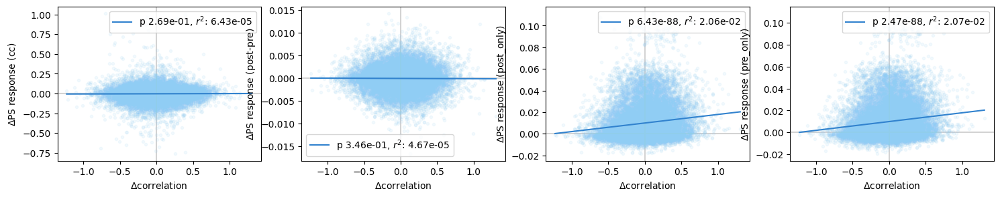

In [76]:
activity_type = 'raw_fl' # raw_activity, raw_fl, dff
ps_activity_type = 'raw_fl' # raw_activity, raw_fl
activity_division = 'split_training' # split_training, test_sessions

session_idx = 0
n_neurons = net_params['n_neurons']
n_groups = task_ps.groups.shape[0]

n_training_steps = task_params['n_steps'] - task_params['n_steps_stabilize']

W_init = train_outputs_all[session_idx]['W_rec_vals'][0]
W_final = train_outputs_all[session_idx]['W_rec_vals'][-1]

if activity_type in ('raw_activity',):
    activity_label = 'Raw Activity'
    if activity_division in ('split_training',):
        activity = train_outputs_all[session_idx]['output']
        activity_init = activity[task_params['n_steps_stabilize']:task_params['n_steps_stabilize']+int(n_training_steps/2)]
        activity_final = activity[task_params['n_steps_stabilize']+int(n_training_steps/2):]
        del activity
    elif activity_division in ('test_sessions',):
        activity_init = train_outputs_all[session_idx]['train_outputs_test_0']['output']
        activity_final = train_outputs_all[session_idx]['train_outputs_test_1']['output']
elif activity_type in ('raw_fl',):
    activity_label = 'Raw Fluorescence'
    if activity_division in ('split_training',):
        activity = train_outputs_all[session_idx]['output_fl']
        activity_init = activity[task_params['n_steps_stabilize']:task_params['n_steps_stabilize']+int(n_training_steps/2)]
        activity_final = activity[task_params['n_steps_stabilize']+int(n_training_steps/2):]
        del activity
    elif activity_division in ('test_sessions',): # Need to fl convolve these
        activity_init = fftconvolve(
            train_outputs_all[session_idx]['train_outputs_test_0']['output'], task_params['fl_kernel'][:, np.newaxis], axes=(0,), mode='valid'
        )
        activity_final = fftconvolve(
            train_outputs_all[session_idx]['train_outputs_test_1']['output'], task_params['fl_kernel'][:, np.newaxis], axes=(0,), mode='valid'
        )
elif activity_type in ('dff',):
    raise NotImplementedError()
    activity, _ = bci_analysis.compute_dff(
        train_outputs_all[session_idx]['output_fl'], task_params, f0_CUTOFF = 0.1 * task_params['task_scale']
    )
    activity_label = 'dF/F'
    
pairwise_correlations_init = np.corrcoef(activity_init.T)
pairwise_correlations_final = np.corrcoef(activity_final.T)

group_correlations_init = np.nan * np.ones((n_neurons, n_groups,))
group_correlations_final = np.nan * np.ones((n_neurons, n_groups,))

indirect_correlations_init = []
indirect_correlations_final = []
W_init_indirect = []
W_final_indirect = []

for group_idx in range(n_groups):
    indirect_idxs = np.arange(n_neurons)
    indirect_idxs = np.delete(indirect_idxs, task_ps.groups[group_idx])
    
    group_correlations_init[:, group_idx] = np.sum(pairwise_correlations_init[:, task_ps.groups[group_idx]], axis=-1)
    group_correlations_final[:, group_idx] = np.sum(pairwise_correlations_final[:, task_ps.groups[group_idx]], axis=-1)

    indirect_correlations_init.append(group_correlations_init[indirect_idxs, group_idx])
    indirect_correlations_final.append(group_correlations_final[indirect_idxs, group_idx])
    
    W_init_indirect.append(np.sum(W_init[:, task_ps.groups[group_idx]], axis=-1)[indirect_idxs])
    W_final_indirect.append(np.sum(W_final[:, task_ps.groups[group_idx]], axis=-1)[indirect_idxs])
    
indirect_correlations_init = np.concatenate(indirect_correlations_init, axis=0)
indirect_correlations_final = np.concatenate(indirect_correlations_final, axis=0)
W_init_indirect = np.concatenate(W_init_indirect, axis=0)
W_final_indirect = np.concatenate(W_final_indirect, axis=0)

print('---- True weights ----')
slope, intercept, rvalue, pvalue, _ = linregress(indirect_correlations_init, W_init_indirect)
print(' Initial fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
slope, intercept, rvalue, pvalue, _ = linregress(indirect_correlations_final, W_final_indirect)
print(' Final   fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
slope, intercept, rvalue, pvalue, _ = linregress(indirect_correlations_final - indirect_correlations_init, W_final_indirect - W_init_indirect)
print(' Delta   fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
    
fig, (ax1, ax2, ax3, ax4,) = plt.subplots(1, 4, figsize=(18, 3))
    
for ps_computation_type, ax in zip(('cc', 'post-pre', 'post_only', 'pre_only'), (ax1, ax2, ax3, ax4,)):

    # Change in causal connectivity
    delta_causal_connectivity, raw_causal_connectivities = bci_analysis.compute_delta_causal_connectivity(
        train_outputs_all, params, task_ps, session_idx,
        causal_connectivity_mode=causal_connectivity_mode,
        causal_connectivity_neurons_mode=causal_connectivity_neurons_mode,
        ps_activity_type=ps_activity_type, ps_computation_type=ps_computation_type,
    )
    
    delta_causal_connectivity_indirect = []
    causal_connectivity_init_indirect = []
    causal_connectivity_final_indirect = []
    for group_idx in range(n_groups):
        indirect_idxs = np.arange(n_neurons)
        indirect_idxs = np.delete(indirect_idxs, task_ps.groups[group_idx])
        
        delta_causal_connectivity_indirect.append(delta_causal_connectivity[indirect_idxs, group_idx])
        causal_connectivity_init_indirect.append(raw_causal_connectivities[0][indirect_idxs, group_idx])
        causal_connectivity_final_indirect.append(raw_causal_connectivities[1][indirect_idxs, group_idx])
    
    delta_causal_connectivity_indirect = np.concatenate(delta_causal_connectivity_indirect, axis=0)
    causal_connectivity_init_indirect = np.concatenate(causal_connectivity_init_indirect, axis=0)
    causal_connectivity_final_indirect = np.concatenate(causal_connectivity_final_indirect, axis=0)
    
    print('---- {} ----'.format(ps_computation_type))
    slope, intercept, rvalue, pvalue, _ = linregress(indirect_correlations_init, causal_connectivity_init_indirect)
    print(' Initial fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
    slope, intercept, rvalue, pvalue, _ = linregress(indirect_correlations_final, causal_connectivity_final_indirect)
    print(' Final   fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
    slope, intercept, rvalue, pvalue, _ = linregress(indirect_correlations_final - indirect_correlations_init, delta_causal_connectivity_indirect)
    print(' Delta   fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
    
    # Scatter over true delta_W_groups versus CC estimate
    ax.scatter(indirect_correlations_final - indirect_correlations_init, delta_causal_connectivity_indirect, marker='.', color=c_vals_l[1], alpha=0.1)
    add_regression_line(indirect_correlations_final - indirect_correlations_init, delta_causal_connectivity_indirect, ax=ax, color=c_vals[1], zorder=5)
    ax.axhline(0.0, color='lightgrey', zorder=-5)
    ax.axvline(0.0, color='lightgrey', zorder=-5)
    
    ax.set_xlabel('$\Delta$correlation')
    ax.set_ylabel('$\Delta$PS response ({})'.format(ps_computation_type))
    ax.legend()
    


Tests for enhanced-enhanced connectivity from photostimulation

Using raw_fl for PS
Using raw_fl for PS
Equal here?: 0


Text(0.5, 0, 'Total $\\Delta$ W_cc for post. (sum across groups)')

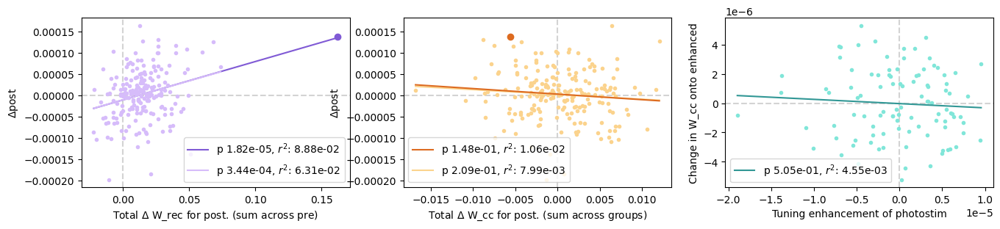

In [18]:
train_outputs = train_outputs_all[session_idx]

change_to_explain = 'post' # tuning, pre, post
if change_to_explain == 'tuning':
    slopes = tuning_slopes
    mean_values = np.mean(tuning, axis=0)
    slope_label = '$\Delta$tuning'
elif change_to_explain == 'pre':
    slopes = pre_slopes
    mean_values = np.mean(mean_pre_activities, axis=0)
    slope_label = '$\Delta$pre'
elif change_to_explain == 'post':
    slopes = post_slopes
    slope_label = '$\Delta$post'
    mean_values = np.mean(mean_post_activities, axis=0)

causal_connectivity_mode = 'groups_to_neurons' # groups_to_neurons, neurons_to_neurons
causal_connectivity_neurons_mode = 2 # Only matters if causal_connectivity_mode=neurons_to_neurons
ps_activity_type = 'raw_fl' # dff, raw_fl, raw_fl_no_pre_div # Raw_fl used in experiment

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 3))

delta_W_post = np.sum(train_outputs['delta_W_rec'], axis=-1)

ax1.scatter(delta_W_post, slopes, marker='.', color=c_vals_l[3])
ax1.scatter(delta_W_post[cn_idx], slopes[cn_idx], marker='o', color=c_vals[3])
add_regression_line(delta_W_post, slopes, ax=ax1, color=c_vals[3], zorder=0)
add_regression_line(
    np.delete(delta_W_post, cn_idx), np.delete(slopes, cn_idx),
    ax=ax1, color=c_vals_l[3], zorder=0
)

# Change in causal connectivity
delta_causal_connectivity, raw_causal_connectivities = bci_analysis.compute_delta_causal_connectivity(
    train_outputs_all, params, task_ps, session_idx,
    causal_connectivity_mode=causal_connectivity_mode,
    causal_connectivity_neurons_mode=causal_connectivity_neurons_mode,
    ps_activity_type=ps_activity_type
)

delta_causal_connectivity_within = np.zeros_like(delta_causal_connectivity)
delta_causal_connectivity_outside = np.copy(delta_causal_connectivity)

causal_connectivity_init = raw_causal_connectivities[0]
causal_connectivity_final = raw_causal_connectivities[1]

print('Equal here?:', np.sum(np.where(delta_causal_connectivity != (causal_connectivity_final - causal_connectivity_init), 1, 0)))

for group_idx in range(task_ps.n_groups):
    delta_causal_connectivity_outside[task_ps.groups[group_idx], group_idx] = 0.0 # Set group members to zero
    delta_causal_connectivity_within[task_ps.groups[group_idx], group_idx] = (
        (causal_connectivity_final + causal_connectivity_init)[task_ps.groups[group_idx], group_idx]
    ) # Only copy group members

n_photostims = np.zeros((task_params['n_neurons'],)) + 1e-5
for group_idx in range(task_ps.n_groups):
    n_photostims[task_ps.groups[group_idx]] += 1

delta_causal_connectivity_post = np.sum(delta_causal_connectivity, axis=-1)

ax2.scatter(delta_causal_connectivity_post, slopes, marker='.', color=c_vals_l[4])
ax2.scatter(delta_causal_connectivity_post[cn_idx], slopes[cn_idx], marker='o', color=c_vals[4])
add_regression_line(delta_causal_connectivity_post, slopes, ax=ax2, color=c_vals[4], zorder=5)
add_regression_line(
    np.delete(delta_causal_connectivity_post, cn_idx), np.delete(slopes, cn_idx),
    ax=ax2, color=c_vals_l[4], zorder=0
)
# for group_idx in range(task_ps.n_groups):
#     ax2.scatter(delta_causal_connectivity[:, group_idx], tuning_slopes, marker='.', color=c_vals_l[group_idx%9])
#     add_regression_line(delta_causal_connectivity[:, group_idx], tuning_slopes, ax=ax2, color=c_vals[group_idx%9], zorder=5)

# groups_onehot = np.zeros((task_ps.n_groups, task_ps.n_neurons,))
# for group_idx in range(task_ps.n_groups):
#     groups_onehot[group_idx, task_ps.groups[group_idx]] = 1.0

# group_delta_tuning = np.matmul(groups_onehot, slopes)
# delta_causal_connectivity_pre = np.sum(delta_causal_connectivity, axis=0)
# # delta_causal_connectivity_pre = np.matmul(causal_connectivity_final.T, tuning_slopes)
# ax3.scatter(delta_causal_connectivity_pre, group_delta_tuning, marker='.', color=c_vals_l[5])
# add_regression_line(delta_causal_connectivity_pre, group_delta_tuning, ax=ax3, color=c_vals[5], zorder=5)

group_delta_tuning = np.matmul(slopes, delta_causal_connectivity_outside)
group_tuning = np.matmul(slopes, delta_causal_connectivity_within)
# group_tuning = np.matmul(mean_values, delta_causal_connectivity_within)

ax3.scatter(group_tuning, group_delta_tuning, marker='.', color=c_vals_l[5])
add_regression_line(group_tuning, group_delta_tuning, ax=ax3, color=c_vals[5], zorder=5)
ax3.set_xlabel('Tuning enhancement of photostim')
# ax3.set_xlabel('Tuning of photostim')
ax3.set_ylabel('Change in W_cc onto enhanced')

# delta_W_rec_outside = np.copy(train_outputs['delta_W_rec'])
# delta_W_rec_inside = np.zeros_like(train_outputs['delta_W_rec'])
# W_rec_sum = train_outputs['W_rec_vals'][-1] + train_outputs['W_rec_vals'][0]

# for neuron_idx in range(task_params['n_neurons']):
#     delta_W_rec_outside[neuron_idx, neuron_idx] = 0.
#     delta_W_rec_inside[neuron_idx, neuron_idx] = W_rec_sum[neuron_idx, neuron_idx]

# group_delta_tuning = np.matmul(slopes, delta_W_rec_outside)
# group_tuning = np.matmul(slopes, delta_W_rec_inside)

# ax3.scatter(group_tuning, group_delta_tuning, marker='.', color=c_vals_l[5])
# ax3.scatter(group_tuning[cn_idx], group_delta_tuning[cn_idx], marker='o', color=c_vals_d[5])
# add_regression_line(group_tuning, group_delta_tuning, ax=ax3, color=c_vals[5], zorder=5)
# add_regression_line(
#     np.delete(group_tuning, cn_idx), np.delete(group_delta_tuning, cn_idx),
#     ax=ax3, color=c_vals_l[5], zorder=0
# )
# ax3.set_xlabel('{} enhancement of W_rec'.format(slope_label))
# ax3.set_ylabel('Change in W_rec onto enhanced')

for ax in (ax1, ax2, ax3):
    ax.axhline(0., color='lightgrey', linestyle='dashed', zorder=-5)
    ax.axvline(0., color='lightgrey', linestyle='dashed', zorder=-5)
    ax.legend()

for ax in (ax1, ax2):
    ax.set_ylabel(slope_label)

ax1.set_xlabel('Total $\Delta$ W_rec for post. (sum across pre)')
ax2.set_xlabel('Total $\Delta$ W_cc for post. (sum across groups)')

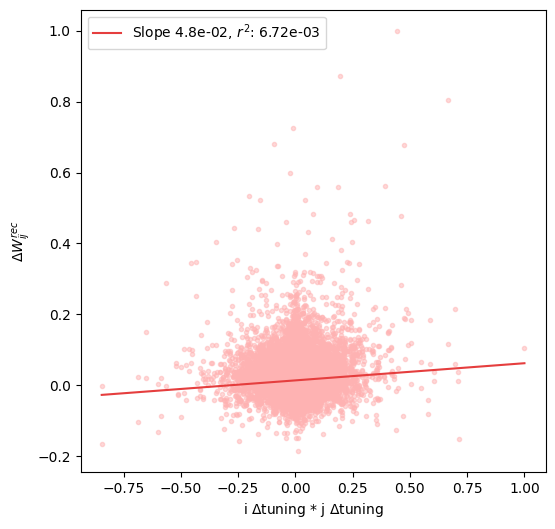

In [ ]:
fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))

delta_tuning_sim = np.outer(slopes, slopes)

delta_tuning_sim = (delta_tuning_sim / np.max(np.abs(delta_tuning_sim))).flatten()
delta_W_rec_norm = (train_outputs['delta_W_rec'] / np.max(np.abs(train_outputs['delta_W_rec']))).flatten()

ax1.scatter(delta_tuning_sim, delta_W_rec_norm, marker='.',
            color=c_vals_l[0], alpha=0.5)
add_regression_line(delta_tuning_sim, delta_W_rec_norm, ax=ax1, color=c_vals[0], zorder=5)

ax1.set_xlabel('i $\Delta$tuning * j $\Delta$tuning')
ax1.set_ylabel('$\Delta W^{rec}_{ij}$')
ax1.legend()

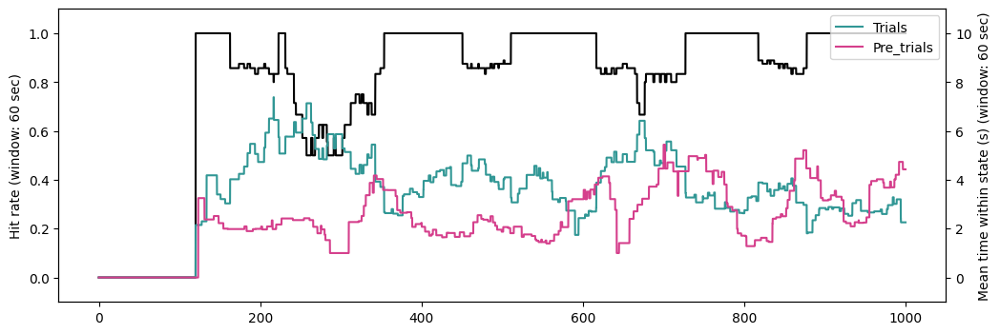

In [ ]:
n_trials = len(task.hist['trial_ends'])

t_window = 60 # sec
n_mean_window = int(t_window * 1000 / task_params['t_step'])
count_window = np.ones((n_mean_window,))

seq_idxs = np.arange(task_params['n_steps'])

trial_lens = np.array(task.hist['trial_ends']) - np.array(task.hist['trial_starts'][:n_trials])
pretrial_lens = np.array(task.hist['pretrial_ends']) - np.array(task.hist['pretrial_starts'][:len(task.hist['pretrial_ends'])])

trial_starts_idxs = task.hist['trial_starts'][:n_trials]
pretrial_starts_idxs = task.hist['pretrial_starts']

# Mask over all seq idxs for when trial starts/successful trials occur
trial_idx = 0
trial_starts_by_seq_idx = np.zeros((task_params['n_steps'],))
trial_lens_by_seq_idx = np.zeros((task_params['n_steps'],))
trial_hits_by_seq_idx = np.zeros((task_params['n_steps'],))
pretrial_idx = 0
pretrial_starts_by_seq_idx = np.zeros((task_params['n_steps'],))
pretrial_lens_by_seq_idx = np.zeros((task_params['n_steps'],))
for seq_idx in seq_idxs:
    if seq_idx in trial_starts_idxs:
        trial_starts_by_seq_idx[seq_idx] = 1.0
        trial_lens_by_seq_idx[seq_idx] = trial_lens[trial_idx] * task_params['t_step'] / 1000
        trial_hits_by_seq_idx[seq_idx] = task.hist['trial_outcomes'][trial_idx]
        trial_idx += 1
    if seq_idx in pretrial_starts_idxs:
        pretrial_starts_by_seq_idx[seq_idx] = 1.0
        pretrial_lens_by_seq_idx[seq_idx] = pretrial_lens[pretrial_idx] * task_params['t_step'] / 1000
        pretrial_idx += 1

# trial_starts_mask = np.array([seq_idx in np.array(task.hist['trial_starts']) for seq_idx in seq_idxs]).astype(np.int32)

rolling_avg_trial_lens = signal.fftconvolve(trial_lens_by_seq_idx, count_window, mode='full')[:-n_mean_window+1]
rolling_avg_trial_hits = signal.fftconvolve(trial_hits_by_seq_idx, count_window, mode='full')[:-n_mean_window+1]
rolling_avg_trial_starts = signal.fftconvolve(trial_starts_by_seq_idx, count_window, mode='full')[:-n_mean_window+1] + 1e-7 # For numerical stability
rolling_avg_trial_lens = np.where(rolling_avg_trial_lens / rolling_avg_trial_starts > 10000,
                                  0.0, rolling_avg_trial_lens / rolling_avg_trial_starts)
rolling_avg_trial_hits = np.where(rolling_avg_trial_hits / rolling_avg_trial_starts > 10000,
                                  0.0, rolling_avg_trial_hits / rolling_avg_trial_starts)
rolling_avg_pretrial_lens = signal.fftconvolve(pretrial_lens_by_seq_idx, count_window, mode='full')[:-n_mean_window+1]
rolling_avg_pretrial_starts = signal.fftconvolve(pretrial_starts_by_seq_idx, count_window, mode='full')[:-n_mean_window+1] + 1e-7 # For numerical stability
rolling_avg_pretrial_lens = np.where(rolling_avg_pretrial_lens / rolling_avg_pretrial_starts > 10000,
                                  0.0, rolling_avg_pretrial_lens / rolling_avg_pretrial_starts)

fig, ax1 = plt.subplots(1, 1, figsize=(12,4))

# ax.plot(rolling_avg_trial_starts)
# ax.plot(rolling_avg_trial_lens)

ax1.plot(x_axis, rolling_avg_trial_hits, color='k')
ax1.set_ylabel('Hit rate (window: {} sec)'.format(t_window))
ax1.set_ylim((-0.1, 1.1))

ax1p = ax1.twinx()
ax1p.plot(x_axis, rolling_avg_trial_lens, color=c_vals[5],
          label='Trials')
ax1p.plot(x_axis, rolling_avg_pretrial_lens, color=c_vals[7],
          label='Pre_trials')
ax1p.set_ylabel('Mean time within state (s) (window: {} sec)'.format(t_window))
ax1p.set_ylim((-1, 11.))
ax1p.legend()

Check how neuron's response to the various types of stimuli (trial start tone, spout movement, reward) are related to their tuning. Note this code really only makes sense to run when eta=0, since it is just trying to understand how tuning arises in the absence of training

In [ ]:
assert train_params['eta'] == 0.

tuning_activity_type = 'dff' # raw_activity, raw_fl, dff

session_idx = 0

### Tuning plots ###
if tuning_activity_type in ('raw_activity',):
    tuning_activity = train_outputs_all[session_idx]['output']
    tuning_activity_label = 'Raw Activity'
elif tuning_activity_type in ('raw_fl',):
    tuning_activity = train_outputs_all[session_idx]['output_fl']
    tuning_activity_label = 'Raw Fluorescence'
elif tuning_activity_type in ('dff',):
    tuning_activity, _ = bci_analysis.compute_dff(
        train_outputs_all[session_idx]['output_fl'], task_params, f0_CUTOFF = 0.1 * task_params['task_scale']
    )
    tuning_activity_label = 'dF/F'

post_activities, pre_activities, tuning_lengths = bci_analysis.get_our_bci_trial_aligned_activities(
    tuning_activity, task, session_idx, tuning_type='trial'
)
tuning = bci_analysis.get_our_bci_tuning(post_activities, pre_activities)

fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4))
fig2, (ax4, ax5, ax6) = plt.subplots(1, 3, figsize=(16, 4))

ax1.hist(np.mean(tuning, axis=0), bins=40, color=c_vals[0])
ax1.axvline(np.mean(tuning), linestyle='dashed', color=c_vals_d[0], zorder=5,
            label='Mean tuning: {:.3f} (std: {:.3f})'.format(
                np.mean(tuning), np.std(np.mean(tuning, axis=0))
            ))

ax1.set_xlabel('Tuning ({})'.format(tuning_activity_label))
ax1.legend()

stim_reps = np.matmul(task.stim_input, net.W_inp.T)

dot_reps = np.matmul(stim_reps, stim_reps.T)

mag_reps = (np.linalg.norm(stim_reps, axis=1)[:, np.newaxis] *
            np.linalg.norm(stim_reps, axis=1)[np.newaxis, :])

print(dot_reps / mag_reps)

for stim_idx in range(task.stim_input.shape[0]):
    ax2.plot(stim_reps[stim_idx, :], color=c_vals[stim_idx])

ax2.legend(['Trial start', 'Reward present', 'Spout move'])
ax2.set_xlabel('Neuron idx'.format(tuning_activity_label))
ax2.set_ylabel('Stim input')

for stim_idx in range(task.stim_input.shape[0]):
    # ax3.scatter(task.stim_input[stim_idx, :], np.mean(tuning, axis=0), color=c_vals[3], marker='.')
    # add_regression_line(task.stim_input[stim_idx, :], np.mean(tuning, axis=0), ax3, color=c_vals_d[3])
    if stim_idx in (0, 2,):
        ax3.scatter(stim_reps[stim_idx, :], np.mean(tuning, axis=0), color=c_vals[stim_idx], marker='.')
    add_regression_line(stim_reps[stim_idx, :], np.mean(tuning, axis=0), ax3, color=c_vals_d[stim_idx])

ax3.legend()

ax3.set_xlabel('Stim input')
ax3.set_ylabel('Tuning ({})'.format(tuning_activity_label))

net_input = train_outputs_all[session_idx]['net_input']
post_input, pre_input, _ = bci_analysis.get_our_bci_trial_aligned_activities(
    net_input, task, session_idx, tuning_type='trial'
)

output_pre_act = train_outputs_all[session_idx]['output_pre_act']
post_pre_act, pre_pre_act, _ = bci_analysis.get_our_bci_trial_aligned_activities(
    output_pre_act, task, session_idx, tuning_type='trial'
)

trial_start_input = np.mean(post_input[:, 1, :], axis=0) # Mean over trials
int_trial_start_input = np.mean(post_input[:, :10, :], axis=(0, 1)) # Mean over trial and time

trial_start_dir_input = np.mean(np.matmul(post_input[:, 1, :], net.W_inp.T), axis=0) # Mean over trials
int_trial_start_dir_input = np.mean(np.matmul(post_input[:, :10, :], net.W_inp.T), axis=(0, 1)) # Mean over trial and time

trial_start_pre_act = np.mean(post_pre_act[:, 1, :], axis=0) # Mean over trials
int_trial_start_pre_act = np.mean(post_pre_act[:, :10, :], axis=(0, 1)) # Mean over trials and time
trial_start_response = np.mean(post_activities[:, 1, :], axis=0) # Mean over trials

ax4.scatter(task.stim_input[stim_idx, :], trial_start_input, color=c_vals_l[4], marker='.')
ax4.scatter(task.stim_input[stim_idx, :], int_trial_start_input, color=c_vals[4], marker='.')

ax5.scatter(stim_reps[stim_idx, :], trial_start_dir_input, color=c_vals_l[5], marker='.')
ax5.scatter(stim_reps[stim_idx, :], int_trial_start_dir_input, color=c_vals[5], marker='.')

ax6.scatter(stim_reps[stim_idx, :], trial_start_pre_act, color=c_vals_l[7], marker='.')
ax6.scatter(stim_reps[stim_idx, :], int_trial_start_pre_act, color=c_vals[7], marker='.')

trial_idx = 10
neuron_idx = 79

print('Tuning: {:.3f}'.format(tuning[trial_idx, neuron_idx]))

AssertionError: 

See what mean trial start responses look like for a single neuron, for the entire population, and how raw firing rate tuning relates to fl tuning, because these two become disconnected for certain types of stimulus encodings (e.g. spout movment) which is counterintuitive. Again only really makes sense if not training.

Largest stim reps: [ 79 161 197  82  92]
Smallest stim reps: [ 35 160  45 183 177]
Tuning raw: -0.003
Tuning fl: 0.007
Tuning raw std: 0.011
Tuning fl std: 0.009


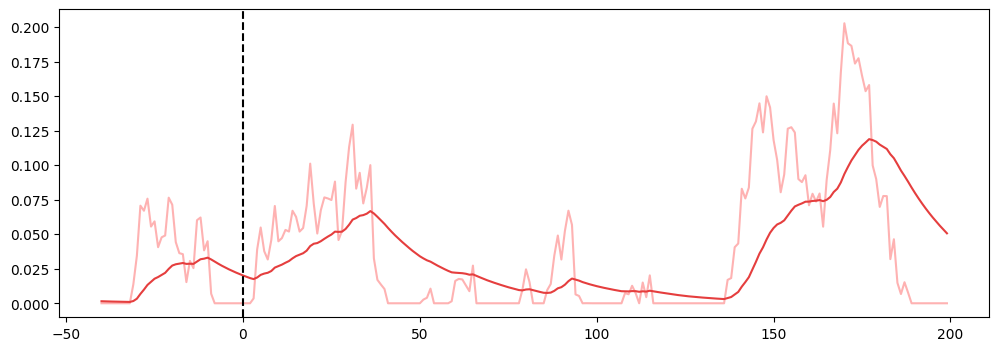

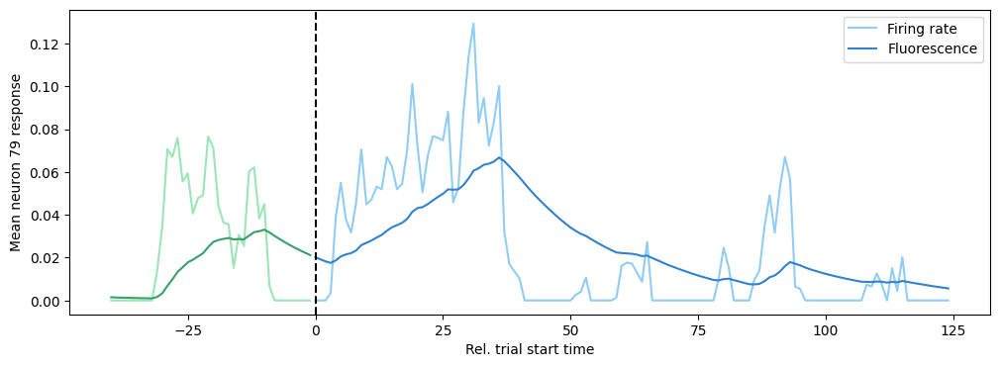

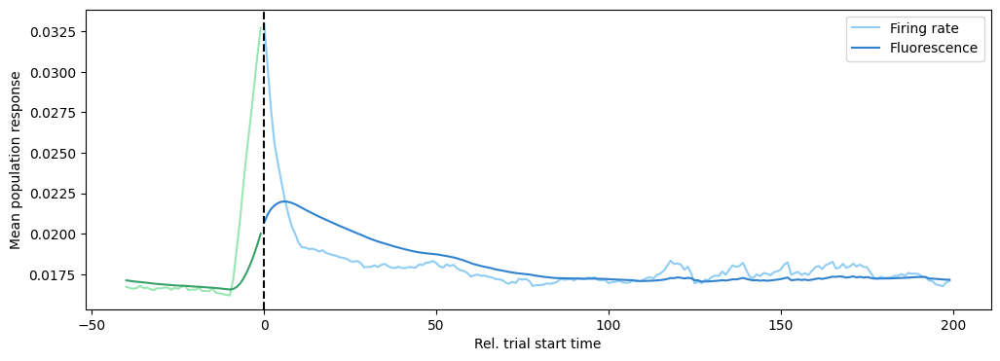

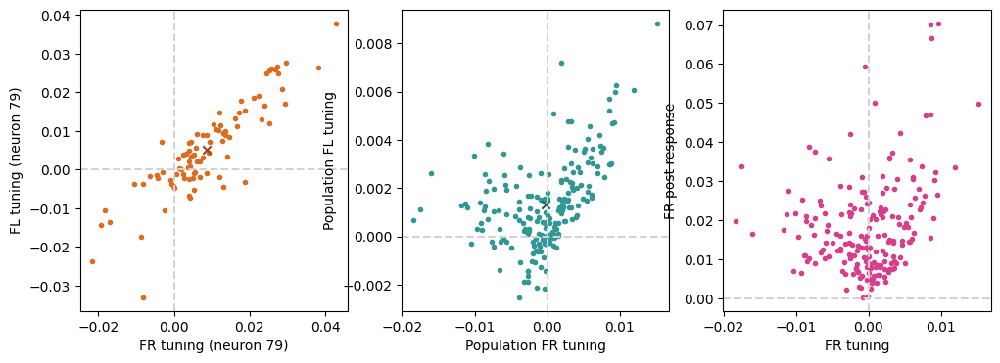

In [ ]:
assert train_params['eta'] == 0.

stim_idx = 2
print('Largest stim reps:', np.argsort(stim_reps[stim_idx, :])[::-1][:5]) # largest to smallest
print('Smallest stim reps:', np.argsort(stim_reps[stim_idx, :])[::-1][-5:]) # largest to smallest

post_activities, pre_activities, tuning_lengths = bci_analysis.get_our_bci_trial_aligned_activities(
    train_outputs_all[session_idx]['output'], task, session_idx, tuning_type='trial'
)

post_fl, pre_fl, _ = bci_analysis.get_our_bci_trial_aligned_activities(
    train_outputs_all[session_idx]['output_fl'], task, session_idx, tuning_type='trial'
)

activity_dff, _ = bci_analysis.compute_dff(
    train_outputs_all[session_idx]['output_fl'], task_params, f0_CUTOFF = 0.1 * task_params['task_scale']
)
post_dff, pre_dff, _ = bci_analysis.get_our_bci_trial_aligned_activities(
    activity_dff, task, session_idx, tuning_type='trial'
)

tuning = bci_analysis.get_our_bci_tuning(post_activities, pre_activities)
tuning_fl = bci_analysis.get_our_bci_tuning(post_fl, pre_fl)
tuning_dff = bci_analysis.get_our_bci_tuning(post_dff, pre_dff)

fig, ax10 = plt.subplots(1, 1, figsize=(12, 4))

trial_idx = 55
neuron_idx = 79 #160

start_idx = task.hists[session_idx]['trial_starts'][trial_idx] - 40
end_idx = task.hists[session_idx]['trial_starts'][trial_idx] + 200

ax10.plot(np.arange(-40, 200), train_outputs_all[session_idx]['output'][start_idx:end_idx, neuron_idx], color=c_vals_l[0])
ax10.plot(np.arange(-40, 200), train_outputs_all[session_idx]['output_fl'][start_idx:end_idx, neuron_idx], color=c_vals[0])
ax10.axvline(0, color='k', linestyle='dashed')

fig1, ax7 = plt.subplots(1, 1, figsize=(12, 4))
fig2, ax8 = plt.subplots(1, 1, figsize=(12, 4))

ax7.plot(np.arange(post_activities[trial_idx, :, neuron_idx].shape[0]), post_activities[trial_idx, :, neuron_idx], color=c_vals_l[1], label='Firing rate')
ax7.plot(np.arange(post_fl[trial_idx, :, neuron_idx].shape[0]), post_fl[trial_idx, :, neuron_idx], color=c_vals[1], label='Fluorescence')
ax7.plot(np.arange(-pre_activities[trial_idx, :, neuron_idx].shape[0], 0), pre_activities[trial_idx, :, neuron_idx], color=c_vals_l[2])
ax7.plot(np.arange(-pre_fl[trial_idx, :, neuron_idx].shape[0], 0), pre_fl[trial_idx, :, neuron_idx], color=c_vals[2])
ax7.set_xlabel('Rel. trial start time')
ax7.set_ylabel('Mean neuron {} response'.format(neuron_idx))
ax7.legend()
ax7.axvline(0, color='k', linestyle='dashed')

print('Tuning raw: {:.3f}'.format(np.nanmean(post_activities[trial_idx, :, neuron_idx]) - np.nanmean(pre_activities[trial_idx, :, neuron_idx])))
print('Tuning fl: {:.3f}'.format(np.nanmean(post_fl[trial_idx, :, neuron_idx]) - np.nanmean(pre_fl[trial_idx, :, neuron_idx])))

ax8.plot(np.arange(post_activities[trial_idx, :, neuron_idx].shape[0]), np.nanmean(post_activities, axis=(0, 2)), color=c_vals_l[1], label='Firing rate')
ax8.plot(np.arange(post_fl[trial_idx, :, neuron_idx].shape[0]), np.nanmean(post_fl, axis=(0, 2)), color=c_vals[1], label='Fluorescence')
# ax8.plot(np.arange(post_dff[trial_idx, :, neuron_idx].shape[0]), np.nanmean(post_dff, axis=(0, 2)), color=c_vals_d[1], linestyle='dashed', label='dFF')
ax8.plot(np.arange(-pre_activities[trial_idx, :, neuron_idx].shape[0], 0), np.nanmean(pre_activities, axis=(0, 2)), color=c_vals_l[2])
ax8.plot(np.arange(-pre_fl[trial_idx, :, neuron_idx].shape[0], 0), np.nanmean(pre_fl, axis=(0, 2)), color=c_vals[2])
# ax8.plot(np.arange(-pre_dff[trial_idx, :, neuron_idx].shape[0], 0), np.nanmean(pre_dff, axis=(0, 2)), color=c_vals_d[2], linestyle='dashed')
ax8.set_xlabel('Rel. trial start time')
ax8.set_ylabel('Mean population response'.format(neuron_idx))
ax8.legend()
ax8.axvline(0, color='k', linestyle='dashed')

fig3, (ax12, ax13, ax14) = plt.subplots(1, 3, figsize=(12, 4))

print('Tuning raw std: {:.3f}'.format(np.mean(np.std(tuning, axis=0))))
print('Tuning fl std: {:.3f}'.format(np.mean(np.std(tuning_fl, axis=0))))

ax12.scatter(tuning[:, neuron_idx], tuning_fl[:, neuron_idx], color=c_vals[4], marker='.')
ax12.scatter(np.mean(tuning[:, neuron_idx]), np.mean(tuning_fl[:, neuron_idx]), color=c_vals_d[4], marker='x')
ax12.set_xlabel('FR tuning (neuron {})'.format(neuron_idx))
ax12.set_ylabel('FL tuning (neuron {})'.format(neuron_idx))

ax13.scatter(np.mean(tuning, axis=0), np.mean(tuning_fl, axis=0), color=c_vals[5], marker='.')
ax13.scatter(np.mean(tuning), np.mean(tuning_fl), color=c_vals_d[5], marker='x')
ax13.set_xlabel('Population FR tuning')
ax13.set_ylabel('Population FL tuning')

ax14.scatter(np.mean(tuning, axis=0), np.nanmean(post_activities, axis=(0, 1)), color=c_vals[7], marker='.')
ax14.set_xlabel('FR tuning')
ax14.set_ylabel('FR post response')

for ax in (ax12, ax13, ax14):
    ax.axvline(0.0, color='lightgrey', linestyle='dashed')
    ax.axhline(0.0, color='lightgrey', linestyle='dashed')


Looks for enhance-enhanced connectivity in the raw weights

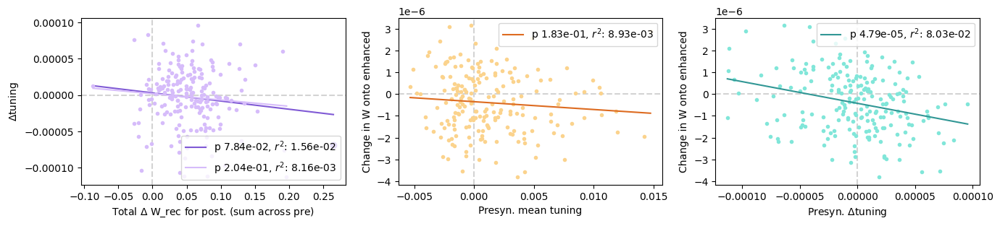

In [ ]:
tuning_activity_type = 'raw_activity' # raw_activity, raw_fl, dff
change_to_explain = 'tuning' # tuning, pre, post

session_idx = 0

### Tuning plots ###
if tuning_activity_type in ('raw_activity',):
    tuning_activity = train_outputs_all[session_idx]['output']
    tuning_activity_label = 'Raw Activity'
elif tuning_activity_type in ('raw_fl',):
    tuning_activity = train_outputs_all[session_idx]['output_fl']
    tuning_activity_label = 'Raw Fluorescence'
elif tuning_activity_type in ('dff',):
    tuning_activity, _ = bci_analysis.compute_dff(
        train_outputs_all[session_idx]['output_fl'], task_params, f0_CUTOFF = 0.1 * task_params['task_scale']
    )
    tuning_activity_label = 'dF/F'

post_activities, pre_activities, tuning_lengths = bci_analysis.get_our_bci_trial_aligned_activities(
    tuning_activity, task, session_idx, tuning_type='trial'
)

mean_post_activities = np.nanmean(post_activities, axis=1) # Mean over time, size (n_neurons,)
mean_pre_activities = np.nanmean(pre_activities, axis=1) # Mean over time, size (n_neurons,)
tuning = bci_analysis.get_our_bci_tuning(post_activities, pre_activities) # Mean over time, size (n_neurons,)
mean_trial_activities = np.nanmean(post_activities, axis=1) + np.nanmean(pre_activities, axis=1) # Mean over time, size (n_neurons,)

# Quantify change in tuning, pre, and post over session
tuning_slopes = np.zeros((task_params['n_neurons'],))
trial_activity_slopes = np.zeros_like(tuning_slopes)
post_slopes = np.zeros_like(tuning_slopes)
pre_slopes = np.zeros_like(tuning_slopes)

for neuron_idx in range(task_params['n_neurons']):
    tuning_slopes[neuron_idx], _, _ = add_regression_line(np.arange(tuning.shape[0]), tuning[:, neuron_idx])
    trial_activity_slopes[neuron_idx], _, _ = add_regression_line(np.arange(mean_trial_activities.shape[0]), mean_trial_activities[:, neuron_idx])
    post_slopes[neuron_idx], _, _ = add_regression_line(np.arange(mean_post_activities.shape[0]), mean_post_activities[:, neuron_idx])
    pre_slopes[neuron_idx], _, _ = add_regression_line(np.arange(mean_pre_activities.shape[0]), mean_pre_activities[:, neuron_idx])

if change_to_explain == 'tuning':
    slopes = tuning_slopes
    mean_values = np.mean(tuning, axis=0) # Mean over trials
    slope_label = 'tuning'
elif change_to_explain == 'pre':
    slopes = pre_slopes
    mean_values = np.mean(mean_pre_activities, axis=0) # Mean over trials
    slope_label = 'pre'
elif change_to_explain == 'post':
    slopes = post_slopes
    slope_label = 'post'
    mean_values = np.mean(mean_post_activities, axis=0)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 3))

cn_idx = train_outputs_all[session_idx]['cn_idxs'][0]

# How much does the total change in recurrent weights explain the observed
# change in tunings
delta_W_post = np.sum(train_outputs_all[session_idx]['delta_W_rec'], axis=-1) # Sum over presynaptic neurons
ax1.scatter(delta_W_post, slopes, marker='.', color=c_vals_l[3])
ax1.scatter(delta_W_post[cn_idx], slopes[cn_idx], marker='o', color=c_vals[3])
add_regression_line(delta_W_post, slopes, ax=ax1, color=c_vals[3], zorder=0)
add_regression_line(
    np.delete(delta_W_post, cn_idx), np.delete(slopes, cn_idx),
    ax=ax1, color=c_vals_l[3], zorder=0
)

delta_W = np.copy(train_outputs_all[session_idx]['delta_W_rec'])
delta_W_within = np.zeros_like(delta_W)
delta_W_outside = np.copy(delta_W)

for neuron_idx in range(delta_W.shape[0]):
    delta_W_outside[neuron_idx, neuron_idx] = 0.0 # Set group members to zero
    # delta_W_within[neuron_idx, neuron_idx] = (
    #     (causal_connectivity_final + causal_connectivity_init)[task_ps.groups[group_idx], group_idx]
    # ) # Only copy group members

enhanced_post = np.matmul(slopes, delta_W_outside)

ax2.scatter(mean_values, enhanced_post, marker='.', color=c_vals_l[4])
add_regression_line(mean_values, enhanced_post, ax=ax2, color=c_vals[4], zorder=5)

ax3.scatter(slopes, enhanced_post, marker='.', color=c_vals_l[5])
add_regression_line(slopes, enhanced_post, ax=ax3, color=c_vals[5], zorder=5)

# ax2.scatter(delta_causal_connectivity_post, slopes, marker='.', color=c_vals_l[4])
# ax2.scatter(delta_causal_connectivity_post[cn_idx], slopes[cn_idx], marker='o', color=c_vals[4])
# add_regression_line(delta_causal_connectivity_post, slopes, ax=ax2, color=c_vals[4], zorder=5)
# add_regression_line(
#     np.delete(delta_causal_connectivity_post, cn_idx), np.delete(slopes, cn_idx),
#     ax=ax2, color=c_vals_l[4], zorder=0
# )

# group_delta_tuning = np.matmul(slopes, delta_causal_connectivity_outside)
# group_tuning = np.matmul(slopes, delta_causal_connectivity_within)

# ax3.scatter(group_tuning, group_delta_tuning, marker='.', color=c_vals_l[5])
# add_regression_line(group_tuning, group_delta_tuning, ax=ax3, color=c_vals[5], zorder=5)
# ax3.set_xlabel('Tuning enhancement of photostim')
# ax3.set_ylabel('Change in W_cc onto enhanced')

for ax in (ax1, ax2, ax3):
    ax.axhline(0., color='lightgrey', linestyle='dashed', zorder=-5)
    ax.axvline(0., color='lightgrey', linestyle='dashed', zorder=-5)
    ax.legend()

ax1.set_ylabel('$\Delta$' + slope_label)

ax1.set_xlabel('Total $\Delta$ W_rec for post. (sum across pre)')

ax2.set_xlabel('Presyn. mean ' + slope_label)
ax3.set_xlabel('Presyn. $\Delta$' + slope_label)

for ax in (ax2, ax3):
    ax.set_ylabel('Change in W onto enhanced')

See if change in tuning can be related to how a given neuron's weights change going into or going out of the cell.

/tmp/ipython-input-19-4221532106.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


Text(0, 0.5, 'Final W post->pre')

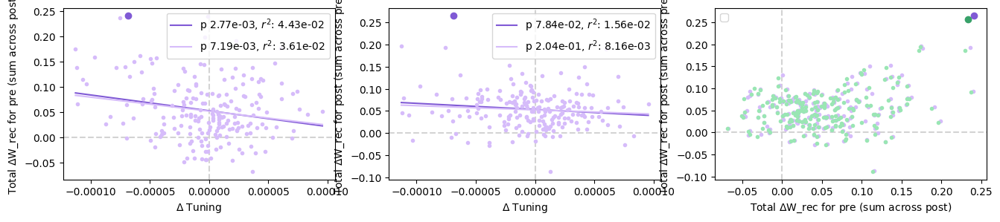

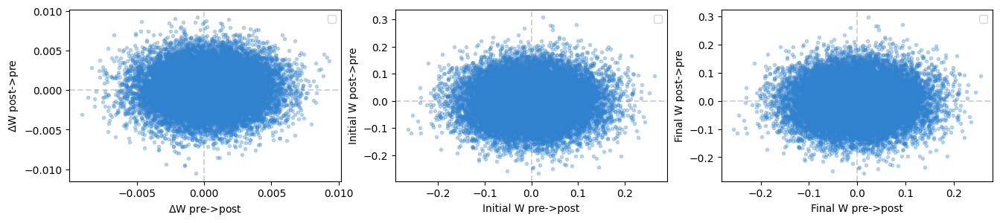

In [ ]:
fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 3))
fig2, (ax4, ax5, ax6) = plt.subplots(1, 3, figsize=(16, 3))

n_neurons = train_outputs_all[session_idx]['delta_W_rec'].shape[0]

delta_W_pre = np.sum(train_outputs_all[session_idx]['delta_W_rec'], axis=0) # Sum over postsynaptic neurons
ax1.scatter(slopes, delta_W_pre, marker='.', color=c_vals_l[3])
ax1.scatter(slopes[cn_idx], delta_W_pre[cn_idx], marker='o', color=c_vals[3])
add_regression_line(slopes, delta_W_pre, ax=ax1, color=c_vals[3], zorder=0)
add_regression_line(
    np.delete(slopes, cn_idx), np.delete(delta_W_pre, cn_idx),
    ax=ax1, color=c_vals_l[3], zorder=0
)

delta_W_post = np.sum(train_outputs_all[session_idx]['delta_W_rec'], axis=-1) # Sum over presynaptic neurons
ax2.scatter(slopes, delta_W_post, marker='.', color=c_vals_l[3])
ax2.scatter(slopes[cn_idx], delta_W_post[cn_idx], marker='o', color=c_vals[3])
add_regression_line(slopes, delta_W_post, ax=ax2, color=c_vals[3], zorder=0)
add_regression_line(
    np.delete(slopes, cn_idx), np.delete(delta_W_post, cn_idx),
    ax=ax2, color=c_vals_l[3], zorder=0
)

ax3.scatter(delta_W_pre, delta_W_post, marker='.', color=c_vals_l[3])
ax3.scatter(delta_W_pre[cn_idx], delta_W_post[cn_idx], marker='o', color=c_vals[3])
delta_W_rec_no_diag = train_outputs_all[session_idx]['delta_W_rec'].copy()
np.fill_diagonal(delta_W_rec_no_diag, 0.)
ax3.scatter(np.sum(delta_W_rec_no_diag, axis=0), np.sum(delta_W_rec_no_diag, axis=-1), marker='.', color=c_vals_l[2])
ax3.scatter(np.sum(delta_W_rec_no_diag, axis=0)[cn_idx], np.sum(delta_W_rec_no_diag, axis=-1)[cn_idx], marker='o', color=c_vals[2])

delta_W_rec = train_outputs_all[session_idx]['delta_W_rec']
init_W_rec = train_outputs_all[session_idx]['W_rec_vals'][0]
final_W_rec = train_outputs_all[session_idx]['W_rec_vals'][-1]
delta_pre_to_post_flat = []
delta_post_to_pre_flat = []
init_pre_to_post_flat = []
init_post_to_pre_flat = []
final_pre_to_post_flat = []
final_post_to_pre_flat = []
for pre_idx in range(n_neurons):
    for post_idx in range(pre_idx+1, n_neurons):
        delta_pre_to_post_flat.append(delta_W_rec[post_idx, pre_idx])
        delta_post_to_pre_flat.append(delta_W_rec[pre_idx, post_idx])
        init_pre_to_post_flat.append(init_W_rec[post_idx, pre_idx])
        init_post_to_pre_flat.append(init_W_rec[pre_idx, post_idx])
        final_pre_to_post_flat.append(final_W_rec[post_idx, pre_idx])
        final_post_to_pre_flat.append(final_W_rec[pre_idx, post_idx])

ax4.scatter(delta_pre_to_post_flat, delta_post_to_pre_flat, marker='.', color=c_vals[1], alpha=0.3)
ax5.scatter(init_pre_to_post_flat, init_post_to_pre_flat, marker='.', color=c_vals[1], alpha=0.3)
ax6.scatter(final_pre_to_post_flat, final_post_to_pre_flat, marker='.', color=c_vals[1], alpha=0.3)

for ax in (ax1, ax2, ax3, ax4, ax5, ax6):
    ax.axhline(0., color='lightgrey', linestyle='dashed', zorder=-5)
    ax.axvline(0., color='lightgrey', linestyle='dashed', zorder=-5)
    ax.legend()

ax1.set_xlabel('$\Delta$ Tuning')
ax1.set_ylabel('Total $\Delta$W_rec for pre (sum across post)')
ax2.set_xlabel('$\Delta$ Tuning')
ax2.set_ylabel('Total $\Delta$W_rec for post (sum across pre)')
ax3.set_xlabel('Total $\Delta$W_rec for pre (sum across post)')
ax3.set_ylabel('Total $\Delta$W_rec for post (sum across pre)')

ax4.set_xlabel('$\Delta$W pre->post')
ax4.set_ylabel('$\Delta$W post->pre')
ax5.set_xlabel('Initial W pre->post')
ax5.set_ylabel('Initial W post->pre')
ax6.set_xlabel('Final W pre->post')
ax6.set_ylabel('Final W post->pre')

Intead of explaining total postsyanptic weight changes, see how well we can explain individual weights (has delay parameter to properly account for delay)

Var explain: 0.86
Var explain: 0.48
Var explain: 0.77
Var explain: 0.76


Text(0.5, 0, 'RPE-dev * pre mean post trial resp.')

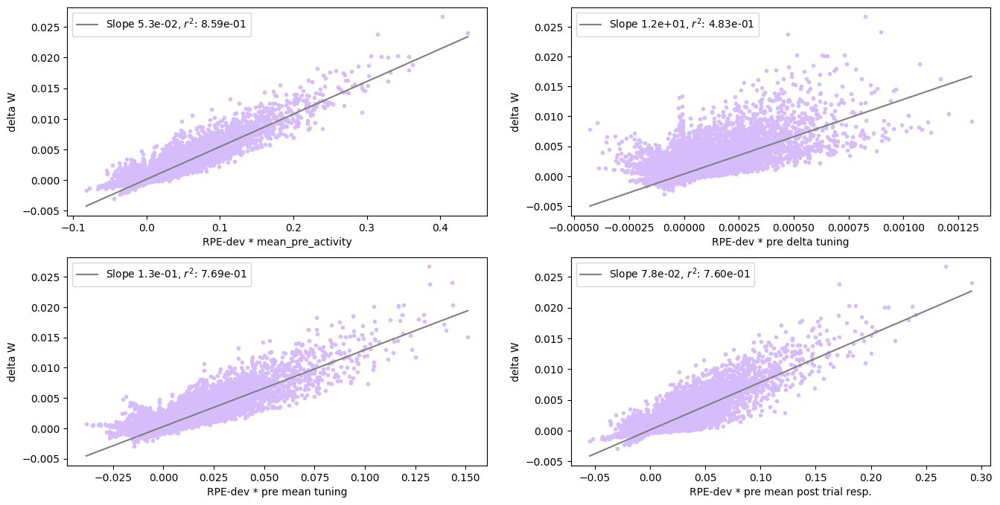

In [ ]:
n_offset = 10
session_idx = 0

train_outputs = train_outputs_all[session_idx]

reward = train_outputs['reward']
avg_reward = train_outputs['avg_reward']
reward_relevant_output = train_outputs['output']
avg_reward_relevant_output = train_outputs['avg_activity']
n_steps_stabilize = task_params['n_steps_stabilize']

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
    if 'W_inp_elg_vals' in output_vars:
        W_elg = train_outputs['W_inp_elg_vals']
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']
    if 'W_rec_elg_vals' in output_vars:
        W_elg = train_outputs['W_rec_elg_vals']

deviation_trunc = reward_relevant_output[n_steps_stabilize:] - avg_reward_relevant_output[n_steps_stabilize:]
# Note we account for the delay in the reward indexing here
rpe_trunc = reward[n_steps_stabilize:] - avg_reward[n_steps_stabilize:]
delta_W = W_vals[-1] - W_vals[0]

if n_offset > 0:
    rpe_dev_prod = np.matmul(rpe_trunc[n_offset:], deviation_trunc[:-n_offset])
elif n_offset == 0:
    rpe_dev_prod = np.matmul(rpe_trunc, deviation_trunc)
elif n_offset < 0:
    rpe_dev_prod = np.matmul(rpe_trunc[:-n_offset], deviation_trunc[n_offset:])

pre_deps = (
    np.mean(reward_relevant_output, axis=0),
    tuning_slopes,
    np.mean(tuning, axis=0),
    # np.mean(mean_post_activities, axis=0),
    np.mean(mean_pre_activities, axis=0),
)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 8))
axs = (ax1, ax2, ax3, ax4)

for pre_dep, ax in zip(pre_deps, axs):

    full_elig_est = rpe_dev_prod[:, np.newaxis] * pre_dep[np.newaxis, :]

    slope, intercept, rvalue, _, _ = linregress(full_elig_est.flatten(), delta_W.flatten())

    print('Var explain: {:.2f}'.format(rvalue**2))
    # print('Var explain (idx: {}): {:.2f}'.format(offset_idx, var_explain_offsets[offset_idx]))

    ax.scatter(full_elig_est.flatten(), delta_W.flatten(), marker='.', color=c_vals_l[3])

    _ = add_regression_line(full_elig_est.flatten(), delta_W.flatten(), ax=ax, color='grey',
                            zorder=5)

    ax.set_ylabel('delta W')
    ax.legend()

ax1.set_xlabel('RPE-dev * mean_pre_activity')
ax2.set_xlabel('RPE-dev * pre delta tuning')
ax3.set_xlabel('RPE-dev * pre mean tuning')
ax4.set_xlabel('RPE-dev * pre mean post trial resp.')

##### Center-out Analysis

Check relation ship between various stimulus representations to see if they are dissimilar enough to create distinct updates to the recurrent matrix

In [ ]:
session_idx = 0
outputs = train_outputs_all[session_idx]['output']
task_params, train_params, net_params = params

outputs_stabilize = outputs[:task_params['n_steps_stabilize']]

outputs_stabilize_stim, _ = task.separate_activity_into_stims(
    outputs_stabilize, task_params
)

mean_output_stabilize_stim = np.zeros((len(outputs_stabilize_stim), outputs.shape[-1],))

for stim_idx in range(len(outputs_stabilize_stim)):
    print(outputs_stabilize_stim[stim_idx].shape)

    mean_output_stabilize_stim[stim_idx] = np.mean(
        outputs_stabilize_stim[stim_idx], axis=0
    )

mean_stim_dots = np.matmul(mean_output_stabilize_stim, mean_output_stabilize_stim.T)

mean_stim_dots_norm = mean_stim_dots / np.max(np.abs(mean_stim_dots))

print('Cross-stim dots', mean_stim_dots_norm)
print(' Mean diag: {:.2f}'.format(np.trace(mean_stim_dots_norm) / task.n_stim))
print(' Mean off-diag: {:.2f}'.format((np.sum(mean_stim_dots_norm) - np.trace(mean_stim_dots_norm)) / (task.n_stim**2 - task.n_stim)))

(1120, 200)
(960, 200)
(960, 200)
(960, 200)
Cross-stim dots [[0.87250598 0.67405113 0.70466266 0.64155722]
 [0.67405113 0.92614595 0.68726772 0.75291779]
 [0.70466266 0.68726772 0.93455468 0.71843141]
 [0.64155722 0.75291779 0.71843141 1.        ]]
 Mean diag: 0.93
 Mean off-diag: 0.70


Special code to analyze how response to individual stimuli changes over training. This clips all the times together that a given stimulus is showing.

(7680,) (7581,)
(7840,) (7741,)
(7840,) (7741,)
(7840,) (7741,)


(-0.02, 0.01)

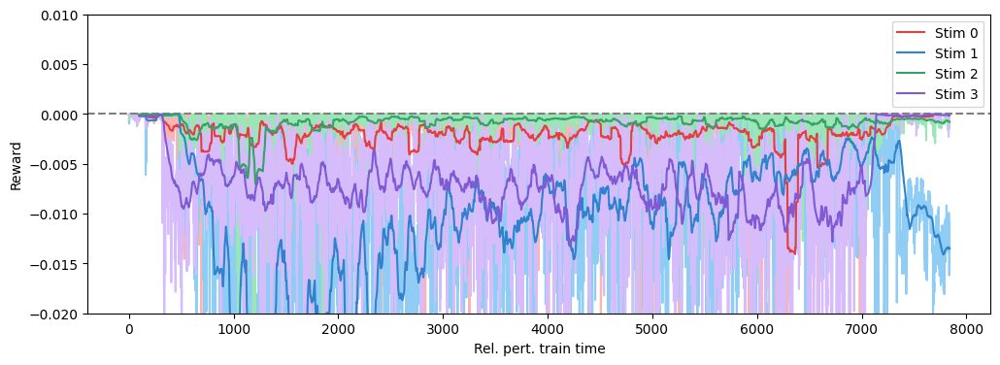

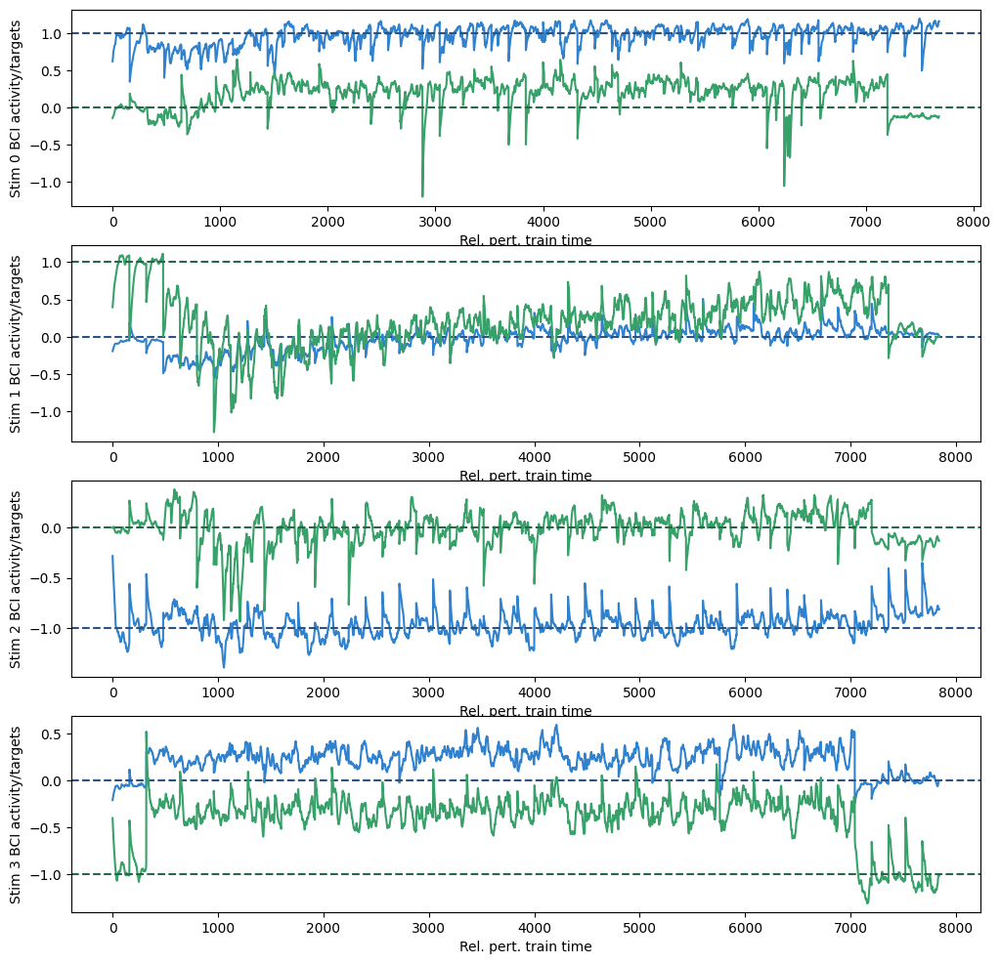

In [ ]:
task_params, train_params, net_params = params
session_idx = 0
n_smooth = 100

start_idx = 6000
end_idx = 45000
bci_activity_analyze = train_outputs_all[session_idx]['avg_bci_activity'][start_idx:end_idx]
reward_analyze = train_outputs_all[session_idx]['reward'][start_idx:end_idx]

bci_activity_stims, seq_idxs_stims = task.separate_activity_into_stims(
    bci_activity_analyze, task_params, seq_start_idx=start_idx,
    reject_criterion = 'nan_mask'
)
reward_stims, _ = task.separate_activity_into_stims(
    reward_analyze, task_params, seq_start_idx=start_idx,
    reject_criterion = 'nan_mask'
)

smooth_fn = 1 / n_smooth * np.ones((n_smooth,))

fig2, ax1 = plt.subplots(1, 1, figsize=(12, 4))
fig, axs = plt.subplots(4, 1, figsize=(12, 12))

for stim_idx, ax in zip(range(task.n_stim), axs):

    ax1.plot(reward_stims[stim_idx], color=c_vals_l[stim_idx])
    smooth_times = np.arange(n_smooth-1, reward_stims[stim_idx].shape[0])
    ax1.plot(smooth_times, np.convolve(reward_stims[stim_idx], smooth_fn, mode='valid'),
             color=c_vals[stim_idx], zorder= 5, label='Stim {}'.format(stim_idx))
    print(reward_stims[stim_idx].shape, np.convolve(reward_stims[stim_idx], smooth_fn, mode='valid').shape)
    for bci_mask_idx in range(task_params['n_bci_masks']):
        ax.plot(bci_activity_stims[stim_idx][:, bci_mask_idx], color=c_vals[1+bci_mask_idx])
        ax.axhline(task.stim_targets[stim_idx, bci_mask_idx], color=c_vals_d[1+bci_mask_idx],
                   linestyle='dashed')

    ax.set_xlabel('Rel. pert. train time')
    ax.set_ylabel('Stim {} BCI activity/targets'.format(stim_idx))

ax1.set_ylabel('Reward')
ax1.set_xlabel('Rel. pert. train time')
ax1.axhline(0.0, color='grey', linestyle='dashed')

ax1.legend()
ax1.set_ylim((-0.02, 0.01))

Plots smoothed reward as a function of time. Does special clipping around pertrubations to make sure bins between distinct time periods do not overlap.

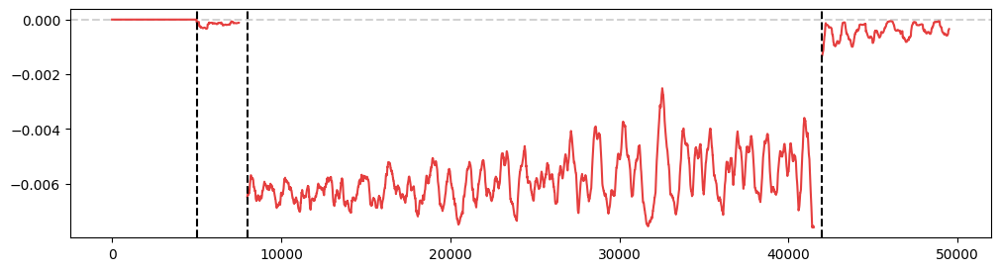

In [ ]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 3))

session_idx = 0
reward = train_outputs_all[session_idx]['reward']

n_smooth = 500

pert_times = []

for pert in task_params['perturbations']:
    pert_times.append(pert[0])

n_fft = reward.shape[0] - n_smooth + 1
reward_smooth = np.zeros((n_fft,))

for seq_idx in range(n_fft):

    if seq_idx < task_params['n_steps_stabilize']:
        continue

    pert_included = False # Make sure bins are not overlapping
    for pert_time in pert_times:
        if seq_idx < pert_time and seq_idx + n_smooth > pert_time:
            # print('Seq_idx {}: Setting to nan'.format(seq_idx))
            pert_included = True

    if pert_included:
        reward_smooth[seq_idx] = np.nan
    else:
        reward_smooth[seq_idx] = np.nanmean(reward[seq_idx:seq_idx + n_smooth])

# smooth_window = 1 / n_smooth * np.ones((n_smooth,))
# reward_smooth = fftconvolve(reward, smooth_window, mode='valid')

# ax1.plot(np.arange(reward.shape[0]), reward, color=c_vals[0])
ax1.plot(np.arange(reward_smooth.shape[0]), reward_smooth, color=c_vals[0])

ax1.axvline(task_params['n_steps_stabilize'], color='k', linestyle='dashed')
for pert_time in pert_times:
    ax1.axvline(pert_time, color='k', linestyle='dashed')

# Average of initial reward rate
ax1.axhline(0.0, color='lightgrey', zorder=-5, linestyle='dashed')

Saves a run (for Cosyne plots)

In [ ]:
del_keys = ('bci_mean_activity', 'output', 'avg_reward', 'avg_activity',
            'loss_steps', 'W_inp_vals', 'W_rec_vals', 'bci_activity',
            'avg_bci_activity', 'total_rpes', 'mean_stabilize_actvities',
            'sol_step', 'delta_W_inp', 'delta_W_rec', 'output_fl',
            'estimated_tunings', 'avg_reward_stims')

session_idx = 0

for del_key in del_keys:
    train_outputs_all[session_idx].pop(del_key, None)

In [ ]:
save_path_mode = 'raw_path' # '_seed{}.pkl' will always be added
save_path = '/content/drive/MyDrive/neuro_research/BCI/saved_nets/omp_example_'
# Seed taken are of automatically in task_params
net_helpers.save_run(params, train_outputs_all, net, task, task_ps, save_path, path_mode=save_path_mode, overwrite=False, verbose=False)


How much of the intuitive mapping is inside what we might call the intrinsic manifold?

(200, 200)
BCI mask idx 0 - PC perc: 0.97
BCI mask idx 1 - PC perc: 0.95


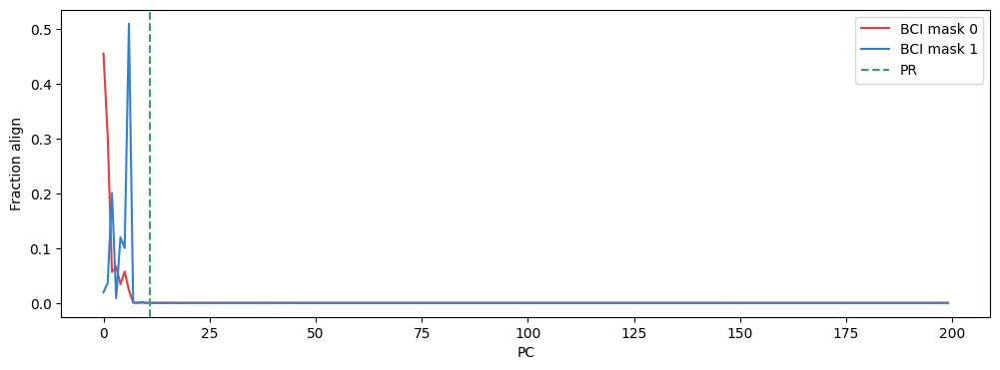

In [ ]:
unit_bci_masks = task_params['bci_masks'] / np.linalg.norm(task_params['bci_masks'], axis=-1, keepdims=True)

bci_mask_pc_dot = np.matmul(unit_bci_masks, task_params['manifold_axes'].T)

pr_val = participation_ratio_vector(task_params['manifold_axes_var_exps'])
pr_val = int(np.ceil(pr_val))

pc_pr_proj = np.matmul(
    np.matmul(task_params['manifold_axes'][:pr_val].T, np.linalg.inv(
        np.matmul(task_params['manifold_axes'][:pr_val], task_params['manifold_axes'][:pr_val].T)
    )), task_params['manifold_axes'][:pr_val]
)

print(pc_pr_proj.shape)

bci_mask_pc_proj = np.matmul(unit_bci_masks, pc_pr_proj.T)

for bci_mask_idx in range(task_params['n_bci_masks']):
    print('BCI mask idx {} - PC perc: {:.2f}'.format(
        bci_mask_idx,
        1 - np.linalg.norm(unit_bci_masks[bci_mask_idx] - bci_mask_pc_proj[bci_mask_idx]) /
        np.linalg.norm(unit_bci_masks[bci_mask_idx])
    ))

fig, ax1 = plt.subplots(1, 1, figsize=(12, 4))

for bci_mask_idx in range(task_params['n_bci_masks']):
    ax1.plot((bci_mask_pc_dot**2)[bci_mask_idx], color=c_vals[bci_mask_idx], label=f'BCI mask {bci_mask_idx}')

ax1.axvline(pr_val, color=c_vals[2],
            linestyle='dashed', label='PR')

ax1.set_ylabel('Fraction align')
ax1.set_xlabel('PC')

ax1.legend()

What do perturbations do?

In [ ]:
session_idx = 0
compute_rewards = True
perm_mode = 'wm' # wm, om_raw, om_top_stds, om_top_stim_stds
tolerance = 0.08
max_perts = 100000

task_params, _, _ = params
# This is an old funtion that gets bci_masks from task_params, so this is just
# a workaround, should update this at some point
task_params['bci_masks'] = train_outputs_all[session_idx]['bci_masks']


bci_masks_pert, extras = get_perturbation_center_out(
    task_params, perm_mode, task=task,
    n_perm_dims=100, compute_rewards=compute_rewards,
    max_perts=max_perts, tolerance=tolerance, return_all_perts=True, verbose=True
)

if bci_masks_pert is not None:
    print(bci_masks_pert.shape)

Perturbation type wm search (n_permuted set by manifold projection: 20)
 75 valid perturbations found! (time 7.56)
Pert idx: 709
 speeds: ['1.08', '0.51', '0.65', '0.20']
 angles: ['15.1', '43.4', '28.9', '18.9']
Valid perturbation found, total time: 7.56 seconds.
(2, 200)


Computes the variance of stabilization activity for each candidate BCI perturbation to get aggregate statistics of perturbations. Needs to be run after the code above.

Permutation mode: wm (n_passes: 75)
 Mean BCI_std: 0.2379 (std: 0.0728)
 Mean reward: -0.0037 (std: 0.0019)
 Mean speed: 0.7 (std: 0.2)
 Mean cosine angle: 0.89 (std: 0.08)


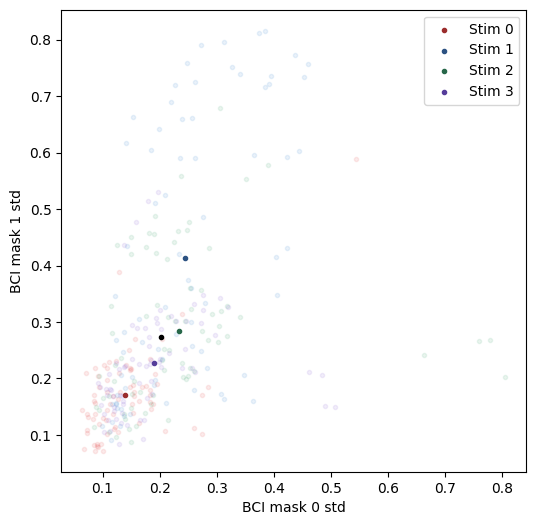

In [ ]:
assert compute_rewards

bci_masks_pert = extras['bci_masks_pert']
pass_criterion = extras['pass_criterion']

bci_masks_pert_pass = bci_masks_pert[np.where(pass_criterion <= tolerance)[0]]

# Activity of each possible perturbation during pre-session
session_idx = 0
task_params, train_params, net_params = params
stabilize_activity = train_outputs_all[session_idx]['output'][:task_params['n_steps_stabilize']]

pert_activity = np.zeros((bci_masks_pert_pass.shape[0], task_params['n_steps_stabilize'], bci_masks_pert.shape[1],))

for bci_pert_idx in range(bci_masks_pert_pass.shape[0]):
    pert_activity[bci_pert_idx] = get_bci_activity(stabilize_activity, task_params, bci_masks=bci_masks_pert_pass[bci_pert_idx])
    # pert_activity = np.matmul(bci_masks_pert_pass, stabilize_activity.T) # (n_perts_pass, n_bci_masks, n_steps_stabilize)

pert_activity = np.transpose(pert_activity, (1, 0, 2)) # (n_steps_stabilize, n_perts_pass, n_bci_masks)

pert_activity_stims, _ = task.separate_activity_into_stims(pert_activity, task_params) #

pert_stds = np.zeros((task.n_stim, bci_masks_pert_pass.shape[0], bci_masks_pert_pass.shape[1],)) # (n_stim, n_perts_pass, n_bci_masks)

for stim_idx in range(len(pert_activity_stims)):
    pert_stds[stim_idx] = np.std(pert_activity_stims[stim_idx], axis=0) # (n_perts_pass, n_bci_masks)


fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))

for stim_idx in range(len(pert_activity_stims)):
    ax1.scatter(pert_stds[stim_idx, :, 0], pert_stds[stim_idx, :, 1], color=c_vals[stim_idx],
                marker='.', alpha=0.1)  # Stim raw
    ax1.scatter(np.mean(pert_stds[stim_idx, :, 0]), np.mean(pert_stds[stim_idx, :, 1]),
                color=c_vals_d[stim_idx], marker='.', label=f'Stim {stim_idx}', zorder=5)  # Stim mean
ax1.scatter(np.mean(pert_stds[:, :, 0]), np.mean(pert_stds[:, :, 1]),
                color='k', marker='.') # All stim mean
ax1.set_xlabel('BCI mask 0 std')
ax1.set_ylabel('BCI mask 1 std')

ax1.legend()

pass_rewards = extras['rewards'][np.where(pass_criterion <= tolerance)[0]]
pass_speeds = extras['speeds'][np.where(pass_criterion <= tolerance)[0]]
pass_cosine_angles = extras['cosine_angles'][np.where(pass_criterion <= tolerance)[0]]

print('Permutation mode: {} (n_passes: {})'.format(perm_mode, pass_rewards.shape[0]))
# Mean over perts, bci_masks, and stims, std measures variance in perts not stims/bci_masks)
print(' Mean BCI_std: {:.4f} (std: {:.4f})'.format(np.mean(pert_stds), np.std(np.mean(pert_stds, axis=(0, 2)))))
print(' Mean reward: {:.4f} (std: {:.4f})'.format(np.mean(pass_rewards), np.std(np.mean(pass_rewards, axis=(0,)))))
print(' Mean speed: {:.1f} (std: {:.1f})'.format(np.mean(pass_speeds), np.std(np.mean(pass_speeds, axis=(0,)))))
print(' Mean cosine angle: {:.2f} (std: {:.2f})'.format(np.mean(pass_cosine_angles), np.std(np.mean(pass_cosine_angles, axis=(0,)))))

In [ ]:
save_path = '/content/drive/MyDrive/neuro_research/BCI/saved_nets/wmp_candidate_vals_seed{}.npy'.format(task_params['seed'])

with open(save_path, 'wb') as f:
    np.save(f, pert_stds)
    np.save(f, pass_rewards)
    np.save(f, pass_speeds)
    np.save(f, pass_cosine_angles)

print('Saved!')

Saved!


Permutation mode: wm (n_passes: 1535)
 Mean BCI_std: 0.2900 (std: 0.0704)
 Mean reward: -0.0051 (std: 0.0010)
 Mean speed: 0.7 (std: 0.2)
 Mean cosine angle: 0.81 (std: 0.02)

[0.42869973 0.37847594 0.36055652 0.34547223]


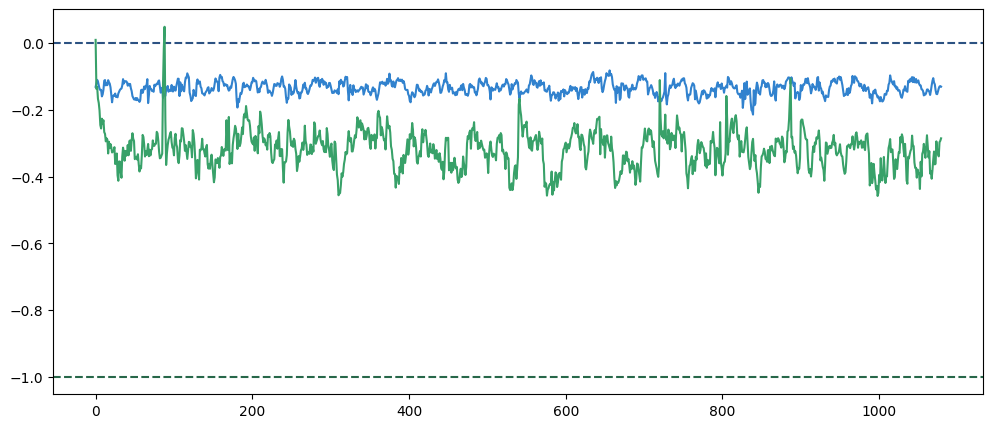

In [ ]:
pert_idx = 25
stim_idx = 3

print(extras['speeds'][np.where(pass_criterion == 0.)[0][pert_idx]])
# print(extras['speeds'][pert_idx])

fig, ax1 = plt.subplots(1, 1, figsize=(12, 5))

for bci_mask_idx in range(task_params['n_bci_masks']):
    ax1.plot(pert_activity_stims[stim_idx][:, pert_idx, bci_mask_idx], color=c_vals[1 + bci_mask_idx])
    ax1.axhline(task.stim_targets[stim_idx, bci_mask_idx], color=c_vals_d[1 + bci_mask_idx], linestyle='dashed')

Visualize space of perurbation speeds and angles

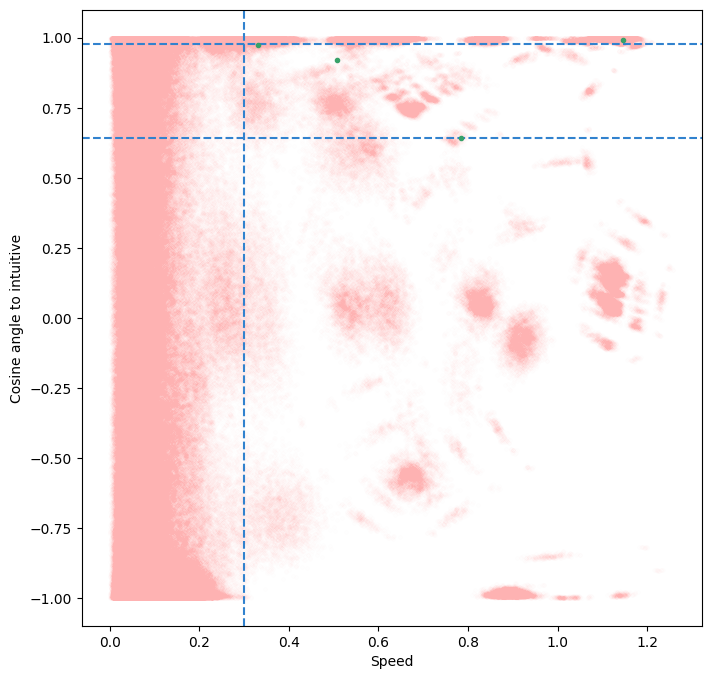

In [ ]:
fig, ax1 = plt.subplots(1, 1, figsize=(8, 8))

# if np.sum(np.all(full_pass, axis=0)):
#     speeds_pass = speeds[np.all(full_pass, axis=0), :]
#     abs_cosine_angles_pass = abs_cosine_angles[np.all(full_pass, axis=0), :]
#     ax1.scatter(speeds_pass[0], abs_cosine_angles_pass[0], marker='.', color=c_vals[2], zorder=5)
#     ax1.scatter(speeds_pass[1], abs_cosine_angles_pass[1], marker='.', color=c_vals[3], zorder=5)
if extras['best_pert_so_far'] is not None:
    ax1.scatter(extras['best_speeds_so_far'], extras['best_cas_so_far'], marker='.', color=c_vals[2], zorder=5)
    # ax1.scatter(speeds[1], abs_cosine_angles[1], marker='.', color=c_vals[3], zorder=5)

ax1.scatter(extras['speeds'].flatten(), extras['cosine_angles'].flatten(), marker='.', color=c_vals_l[0], alpha=0.0025)

# ax1.scatter(all_speeds, all_angles, marker='.', color=c_vals_l[0], alpha=0.25)
# ax1.scatter(speeds, angles, marker='.', color=c_vals[2], zorder=5)

ax1.set_xlabel('Speed')
# ax1.set_ylabel('Angle to intuitive')
ax1.set_ylabel('Cosine angle to intuitive')

# ax1.axhline(max_angle, color=c_vals[1], linestyle='dashed')
# ax1.axhline(min_angle, color=c_vals[1], linestyle='dashed')

ax1.axhline(extras['max_ca'], color=c_vals[1], linestyle='dashed')
ax1.axhline(extras['min_ca'], color=c_vals[1], linestyle='dashed')

ax1.axvline(extras['min_speed'], color=c_vals[1], linestyle='dashed')

Compare how the activity changes for reassociation or not.

--- Session idx 0 ---
Weight change: 0.018


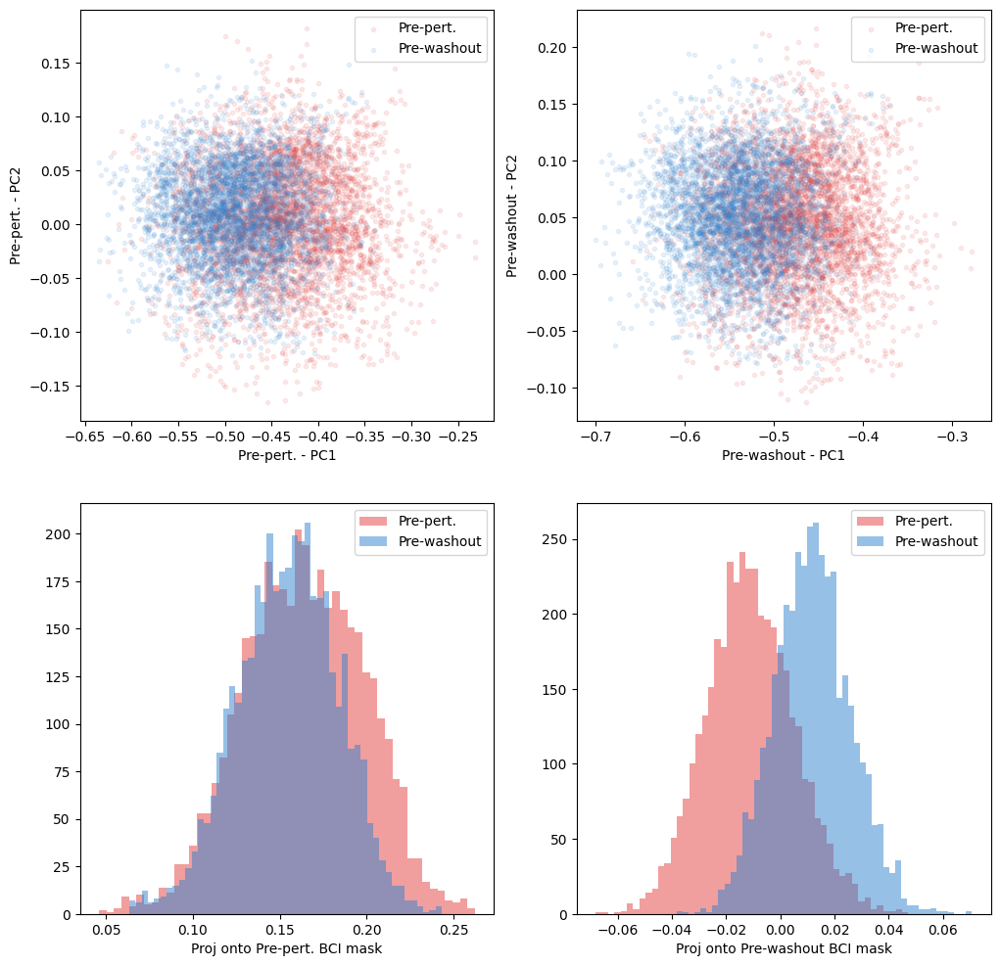

In [ ]:
# Compare how much activity has changed

session_idx = 0
print('--- Session idx {} ---'.format(session_idx))

task_params, train_params, net_params = params

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']

n_neurons = task_params['n_neurons']
train_outputs = train_outputs_all[session_idx]

pert_idx = task_params['perturbations'][0][0]
pert_remove_idx = task_params['perturbations'][1][0]

n_window = 500

# initial_activity = train_outputs['output'][pert_idx-n_window:pert_idx]
# pert_activity = train_outputs['output'][pert_remove_idx-n_window:pert_remove_idx]
bci_masks_init = task_params['manifold_axes'][task_params['manifold_idx']][np.newaxis, :]
bci_masks_pert = task_params['manifold_axes'][task_params['perturbations'][0][-1]['pc_idx']][np.newaxis, :]

loss_steps = np.array(train_outputs['loss_steps'])
W_initial = W_vals[np.argmin(np.abs(loss_steps - pert_idx))]
W_pert = W_vals[np.argmin(np.abs(loss_steps - pert_remove_idx))]

print('Weight change: {:.3f}'.format(np.linalg.norm(W_initial - W_pert) / np.linalg.norm(W_initial)))

initial_activity, _ = get_more_acitivty(
    params, net, W_rec_new=W_initial, state=train_outputs_all[session_idx]['output'][pert_idx],
    state_pre_act=train_outputs_all[session_idx]['output_pre_act'][pert_idx]
)
pert_activity, _ = get_more_acitivty(
    params, net, W_rec_new=W_pert, state=train_outputs_all[session_idx]['output'][pert_remove_idx],
    state_pre_act=train_outputs_all[session_idx]['output_pre_act'][pert_remove_idx]
)

def compare_activity(first_activity, second_activity, first_space, second_space,
                     first_label='1st', second_label='2nd', plot_visualization=False):

    assert first_activity.shape == second_activity.shape

    #### PC of each data ####
    first_pca = PCA()
    first_pca.fit(first_activity)

    # first_activity_first_pca = first_pca.transform(first_activity)
    # second_activity_first_pca = first_pca.transform(second_activity)
    first_activity_first_pca = np.matmul(first_activity, first_pca.components_.T)
    second_activity_first_pca = np.matmul(second_activity, first_pca.components_.T)

    second_pca = PCA()
    second_pca.fit(second_activity)

    # first_activity_second_pca = second_pca.transform(first_activity)
    # second_activity_second_pca = second_pca.transform(second_activity)
    first_activity_second_pca = np.matmul(first_activity, second_pca.components_.T)
    second_activity_second_pca = np.matmul(second_activity, second_pca.components_.T)

    #### Projections onto BCI masks ###

    first_activity_first_bci_masks = np.matmul(first_activity, first_space.T)
    second_activity_first_bci_masks = np.matmul(second_activity, first_space.T)

    first_activity_second_bci_masks = np.matmul(first_activity, second_space.T)
    second_activity_second_bci_masks = np.matmul(second_activity, second_space.T)

    # first_proj = np.matmul(np.matmul(first_space.T, np.linalg.inv(np.matmul(
    #                 first_space, first_space.T
    #             ))), first_space) # P_A = A (A.T A)^(-1) A.T (n_neurons, n_neurons)

    # second_proj = np.matmul(np.matmul(second_space.T, np.linalg.inv(np.matmul(
    #                 second_space, second_space.T
    #             ))), second_space) # P_A = A (A.T A)^(-1) A.T (n_neurons, n_neurons)

    if plot_visualization:
        fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 12))

        ax1.scatter(first_activity_first_pca[:, 0], first_activity_first_pca[:, 1],
                    color=c_vals[0], label=first_label, marker='.', alpha=0.1)
        ax1.scatter(second_activity_first_pca[:, 0], second_activity_first_pca[:, 1],
                    color=c_vals[1], label=second_label, marker='.', alpha=0.1)
        ax1.set_xlabel('{} - PC1'.format(first_label))
        ax1.set_ylabel('{} - PC2'.format(first_label))

        ax2.scatter(first_activity_second_pca[:, 0], first_activity_second_pca[:, 1],
                    color=c_vals[0], label=first_label, marker='.', alpha=0.1)
        ax2.scatter(second_activity_second_pca[:, 0], second_activity_second_pca[:, 1],
                    color=c_vals[1], label=second_label, marker='.', alpha=0.1)
        ax2.set_xlabel('{} - PC1'.format(second_label))
        ax2.set_ylabel('{} - PC2'.format(second_label))

        if first_space.shape[0] == 1: # Histogram plots along space
            ax3.hist(first_activity_first_bci_masks[:, 0], bins=50,
                     color=c_vals[0], label=first_label, alpha=0.5)
            ax3.hist(second_activity_first_bci_masks[:, 0], bins=50,
                     color=c_vals[1], label=second_label, alpha=0.5)

            ax4.hist(first_activity_second_bci_masks[:, 0], bins=50,
                     color=c_vals[0], label=first_label, alpha=0.5)
            ax4.hist(second_activity_second_bci_masks[:, 0], bins=50,
                     color=c_vals[1], label=second_label, alpha=0.5)

            ax3.set_xlabel('Proj onto {} BCI mask'.format(first_label))
            ax4.set_xlabel('Proj onto {} BCI mask'.format(second_label))

        for ax in (ax1, ax2, ax3, ax4):
            ax.legend()

compare_activity(initial_activity, pert_activity, bci_masks_init, bci_masks_pert,
                 first_label='Pre-pert.', second_label='Pre-washout', plot_visualization=True)

### Simple task robust

In [59]:
import copy

seed = 2018 #2012

save_run = True # Save entire run
save_sessions = False # Save individual sessions
load_run = False # Overrides saving/running
load_sessions = False # Overrides saving/running
save_path_mode = 'raw_path' # '_seed{}.pkl' will always be added
save_path = '/scratch/'

scan_type = 'learning_rule_comparison_rl_vs_sl'
# toy_param_scan_lr, toy_param_scan_tau_elig, toy_param_scan_tau_rpe, toy_param_scan_tau_act, 
# toy_param_scan_delay_tau_elig, toy_param_scan_tau_rpe_act,
#   how much varison measures (i.e. reward) varies with various toy parameters scans
# toy_param_scan_n_neurons: varies size of hidden layer
# toy_param_scan_n_stds: varies number of standard deviations away, takes additional measures
# toy_param_scan_starting_performance: varies the starting performance by shifting the reward function closer to the starting BCI activity, uses the 0th scan index as reference for rest
# learning_rule_comparison_Winp, learning_rule_comparison_Wrec: reward, Delta W, delta W predictors for 3factor vs. backprop
# learning_rule_comparison_dev_tests: test the effect of adding deviations to pre/post synaptic activity
# learning_rule_comparison_dev_tests_decrease: same as above, but tests ability to decrease BCI activity
# learning_rule_comparison_3factor_np: special case comparison of 3factor and node perturbation (change type of NP manually)
# learning_rule_comparison_rl_vs_sl: compare rl vs. sl
# learning_rule_comparison_deeper_credit: compare 
# train_cn_weights_vs_not: effects of freezing CN synapses vs. all other synapses
# train_cn_weights_vs_not_3factor_np: effects of freezing CN synapses vs. all other synapses for ours and node perturbation

# hebbian_idx_vs_activity
# add_correlation: Adds correlation to some ON idx to induce weight changes (maybe DEPRICATED)
# time_to_train_one_vs_two: training 2 CNs versus the CNs individually (DEPRICATED)
# gather_correlation_stats: I DONT REMEMBER WHAT THIS IS FOR
### Compare how various types of BCI masks influence learning speed ###
# compare_masks_cn_perc: Varies CN choice over various activity percentiles to see how this affects learning speed
# compare_masks_pcs: Varices BCI mask choice over various PCs 
# compare_masks_cn_fixed_thresh: Varies CN choice over various activity percentiles, but uses 0th scan index as fixed threshold
# compare_masks_fixed_thresh: Uses the 0th scan index threshold for all other scan_idxs

### Sadtler related scans ###
# incremental_omp_training: interpolate the BCI mask to the OMP mask
# incremental_omp_training_reward: interpolate by making the reward easier to see over time
# wmp_vs_omp
# pert_n_stds_scan
# pert_pc_fixed_dist_scan

# save_path += scan_type

n_scan = 10 # 10 # This might be ignored for a lot of scans below which have built in n_scans, or might get changed for outer-product scans
n_repeats = 4

output_vars = ['output', 'reward', 'avg_reward', 'avg_activity', 'loss_steps', 'total_rpes', 'W_inp_vals', 'W_rec_vals']

# Get default parameters to initialize some variables
task_params, train_params, net_params = default_toy_params(seed=seed)
assert task_params['task_type'] == 'simple_bci'

if (save_run or save_sessions) and (load_run or load_sessions):
    raise ValueError('Both save and load on, turn one off.')

#############################################
########### SETUP SCAN PARAMETERS ###########
#############################################
    
if scan_type in ('toy_param_scan_lr', 'toy_param_scan_tau_elig', 'toy_param_scan_tau_rpe', 'toy_param_scan_tau_act', 'toy_param_scan_delay_tau_elig',
                 'toy_param_scan_tau_rpe_act', 'toy_param_scan_n_neurons', 'toy_param_scan_n_stds', 'toy_param_scan_starting_performance',):
    n_sessions = 1    
    output_vars = ['reward', 'sol_step',]
    if scan_type in ('toy_param_scan_lr',):
        scan_vals = np.array([0, *list(np.logspace(0, 3, n_scan))]) # First serves as baseline comparison
    elif scan_type in ('toy_param_scan_n_stds', 'toy_param_scan_starting_performance',): # Gather some additional metrics for evaluation
        scan_vals_1 = [False, True,] # Whether or not to train, need this for each scan val since reward function changes
        if scan_type in ('toy_param_scan_n_stds',):
            scan_vals_2 = np.linspace(1, 3, n_scan) # n_stds
        elif scan_type in ('toy_param_scan_starting_performance',):
            scan_vals_2 = np.linspace(0.0, 0.8, n_scan) # relative shift of target to starting activity, 0.0 means no shift, 1.0 complete shift
            bci_stds = np.zeros((2 * n_scan, n_repeats))  
            total_rewards_evaluate = np.zeros((2 * n_scan, n_repeats))  
            reward_scales = np.zeros((2 * n_scan, n_repeats,))
            sol_scales = np.zeros((2 * n_scan, n_repeats,))
            # Varies n_stds over repeats to create variable learning speed, but keeps constant over all scan_idxs
            repeat_vals = np.random.uniform(1, 3, size=(n_repeats,)) 
        scan_vals = np.array(np.meshgrid(scan_vals_1, scan_vals_2)).T.reshape(-1, 2)
        bci_means = np.zeros((scan_vals.shape[0], n_repeats))  
        thresholds = np.zeros((scan_vals.shape[0], n_repeats,))
        output_vars.extend(['output'])
    elif scan_type in ('toy_param_scan_tau_elig',):
        scan_vals = np.ceil(np.logspace(0, 3, n_scan)).astype(np.int32)
    elif scan_type in ('toy_param_scan_tau_rpe',):
        scan_vals = np.logspace(X, X, n_scan)
    elif scan_type in ('toy_param_scan_tau_act',):
        scan_vals = np.logspace(X, X, n_scan)
    elif scan_type in ('toy_param_scan_n_neurons',):
        scan_vals_1 = [False, True,] # Whether or not to train
        scan_vals_2 = np.ceil(np.logspace(1, np.log10(500), n_scan)).astype(np.int32)
        scan_vals = np.array(np.meshgrid(scan_vals_1, scan_vals_2)).T.reshape(-1, 2)
        total_delta_Ws = [np.zeros((n_repeats, scan_val[1])) for scan_val in scan_vals] # This changes shape with each scan_val
        output_vars.extend(['W_rec_vals'])
    elif scan_type in ('toy_param_scan_delay_tau_elig',):
        # scan_vals_1 = np.ceil(np.logspace(0, 2, n_scan)).astype(np.int32) # Delays
        # scan_vals_2 = np.ceil(np.logspace(0, 3, n_scan)).astype(np.int32) # Eligibilities
        scan_vals_1 = np.array([0, 1, 5, 10, 25, 50, 100]) # Delays
        scan_vals_2 = np.array([1, 5, 10, 25, 50, 100]) # Eligibilities
        scan_vals = np.array(np.meshgrid(scan_vals_1, scan_vals_2)).T.reshape(-1, 2)
    elif scan_type in ('toy_param_scan_tau_rpe_act',):
        scan_vals_1 = np.ceil(np.logspace(0, 3, n_scan)).astype(np.int32) # RPEs
        scan_vals_2 = np.ceil(np.logspace(0, 3, n_scan)).astype(np.int32) # Activation baselines
        scan_vals = np.array(np.meshgrid(scan_vals_1, scan_vals_2)).T.reshape(-1, 2)
    
    n_scan = scan_vals.shape[0] # Override this for some 2d+ scans
    total_rewards = np.zeros((n_scan, n_repeats))  
    sol_steps = np.nan * np.ones((n_scan, n_repeats))
elif scan_type in ('learning_rule_comparison_Winp', 'learning_rule_comparison_Wrec', 'learning_rule_comparison_dev_tests', 
                   'learning_rule_comparison_dev_tests_decrease', 'learning_rule_comparison_3factor_np', 'learning_rule_comparison_rl_vs_sl',
                   'learning_rule_comparison_deeper_credit',):    
    if scan_type in ('learning_rule_comparison_Winp', 'learning_rule_comparison_Wrec',):
        scan_vals = ('3factor', 'backprop_two_step',) # backprop
        n_scan = len(scan_vals)
        delta_W_inps =  np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_inp']))
        delta_W_recs =  np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
        scan_vals = ('3factor', 'backprop_two_step',) # backprop

        output_vars = ['reward', 'delta_W_inp', 'delta_W_rec', 'sol_step',] # without delta_W predictors
        output_vars = ['reward', 'avg_reward', 'output', 'avg_activity',
                       'delta_W_inp', 'delta_W_rec', 'sol_step',] # with delta_W predictors

        if scan_type in ('learning_rule_comparison_Winp',):
            output_vars.append('W_inp_vals')
        elif scan_type in ('learning_rule_comparison_Wrec',):
            output_vars.append('W_rec_vals')

        predictor_names = ( # If you change this, need to change column_stack below accordingly
            # 'RPE-dev product',
            'CN dev-dev product',
            'W_rec input to CN',
            'W_rec output from CN',
            'W_inp sim rel. to CN',
        )
        n_predictors = len(predictor_names)
        predictors_all = np.zeros((n_scan, n_repeats, n_predictors, task_params['n_neurons']))
    elif scan_type in ('learning_rule_comparison_dev_tests', 'learning_rule_comparison_dev_tests_decrease',):
        
        scan_vals_1 = ('3factor', '3factor_vanilla_hebbian',) # '3factor_two_devs',)
        assert task_params['dyn_threshold_type'] == 'bci_activity_mean_and_std' # This is assumed for checks below
        if scan_type in ('learning_rule_comparison_dev_tests',):
            assert task_params['n_stds'] > 0
            scan_vals_2 = np.logspace(-1, 1, n_scan) # Scan over LRs, default is 1e0
        elif scan_type in ('learning_rule_comparison_dev_tests_decrease',):
            assert task_params['n_stds'] < 0
            scan_vals_2 = np.logspace(0, 2, n_scan) # Slightly larger LRs seems to work better for decrease
        
        scan_vals = np.array(np.meshgrid(scan_vals_1, scan_vals_2)).T.reshape(-1, 2)
        n_scan = scan_vals.shape[0]
        
        delta_W_recs =  np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
        
        output_vars = ['reward', 'delta_W_inp', 'delta_W_rec', 'sol_step',]
        # output_vars.append('W_rec_vals')
        
    elif scan_type in ('learning_rule_comparison_3factor_np',):
        # scan_vals = ('3factor', '3factor', '3factor_node_pert', '3factor_node_pert',) # train & no-train for each
        scan_vals = ('3factor', '3factor', '3factor_node_pert_pre', '3factor_node_pert_pre',)
        n_scan = len(scan_vals)
        
        if '3factor_node_pert' in scan_vals: # For postsynaptic node perturbation, need special settings
            assert net_params['act_fn_type'] in ('linear', 'Tanh',) # Need odd function for perturbation on activity to make sense
        
        if net_params['act_fn_type'] in ('linear', 'Tanh',): # Need this for odd activations
            assert task_params['constant_stim_input'] == True # Training odd functions needs this
        assert task_params['normalize_reward'] == True # Comparable training difficulty across learnign rules
            
        n_steps_stabilize = 2000 
        n_steps = 6000
        
        output_vars = ['reward', 'avg_reward', 'sol_step', 'output', 'output_pre_act',]

        activity_stabilize_all = np.zeros((n_scan, n_repeats, n_steps_stabilize, net_params['n_neurons'],))
        preactivity_stabilize_all = np.zeros((n_scan, n_repeats, n_steps_stabilize, net_params['n_neurons'],))
    elif scan_type in ('learning_rule_comparison_rl_vs_sl', 'learning_rule_comparison_deeper_credit',):
        if scan_type in ('learning_rule_comparison_rl_vs_sl',):
            scan_vals_1 = ('backprop_sl',) #('3factor', '3factor_sl', '3factor_sl_uniform', 'backprop_sl',)
            # scan_vals_2 = np.logspace(-1, 1, n_scan) # Scan over LRs, default is 1e0
            scan_vals_2 = np.logspace(-2, 1, n_scan) # For 3factor_sl_uniform, optimal is quite low
        elif scan_type in ('learning_rule_comparison_deeper_credit',):
            scan_vals_1 = ('3factor', 'backprop_two_step', 'backprop',)
            scan_vals_2 = np.logspace(-1, 1, n_scan) # For 3factor_sl_uniform, optimal is quite low
        
        scan_vals = np.array(np.meshgrid(scan_vals_1, scan_vals_2)).T.reshape(-1, 2)
        n_scan = scan_vals.shape[0]
        
        delta_W_recs =  np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
        rewards_all = np.zeros((n_scan, n_repeats, task_params['n_steps'],))
        
        output_vars = ['reward', 'delta_W_inp', 'delta_W_rec', 'sol_step',]
        
    n_sessions = 1
    total_rewards = np.zeros((n_scan, n_repeats))
    sol_steps = np.nan * np.ones((n_scan, n_repeats))
elif scan_type in ('train_cn_weights_vs_not', 'train_cn_weights_vs_not_3factor_np',):
    if scan_type in ('train_cn_weights_vs_not',):
        # 0: train nothing
        # 1: train everything
        # 2: train cn only
        # 3: train non-cn only
        scan_vals_1 = np.array((0, 1, 2, 3))
        if n_scan == 1: # Use default LR
            scan_vals_2 = train_params['eta']
        else:
            scan_vals_2 = np.logspace(-1, 1, n_scan) # Scan over LRs, default is 1e0
        scan_vals = np.array(np.meshgrid(scan_vals_1, scan_vals_2)).T.reshape(-1, 2)
        n_scan = scan_vals.shape[0]
        output_vars = ['reward', 'avg_reward', 'output', 'avg_activity', 'delta_W_inp', 'delta_W_rec', 'W_rec_vals',]
    elif scan_type in ('train_cn_weights_vs_not_3factor_np',):
        assert net_params['act_fn_type'] in ('linear', 'Tanh',) # Need odd function for perturbation on activity to make sense
        assert task_params['constant_stim_input'] == True # Training odd functions needs this
        assert task_params['normalize_reward'] == True # Comparable training difficulty across learnign rules
        
        raise NotImplementedError('Adjusted how the single LR scan works so need to update this code.')
        n_scan = 8
        n_steps_stabilize = 2000 
        n_steps = 6000
        activity_stabilize_all = np.zeros((n_scan, n_repeats, n_steps_stabilize, net_params['n_neurons'],))
        output_vars = ['reward', 'avg_reward', 'output', 'sol_step', 'W_rec_vals']
    
    n_sessions = 1
    W_rec_inits =  np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
    W_rec_finals =  np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
    total_rewards = np.zeros((n_scan, n_repeats))
    predictor_names = ( # If you change this, need to change column_stack below accordingly
        'RPE-dev product',
        'CN product',
        'CN dev-dev product',
        'W_rec input to CN',
        'W_rec output from CN',
        'W_inp sim rel. to CN',
    )
    n_predictors = len(predictor_names)
    predictors_all = np.zeros((n_scan, n_repeats, n_predictors, task_params['n_neurons']))
elif scan_type in ('hebbian_idx_vs_activity',):
    n_scan = 1 # No scan, just repeats
    n_sessions = 5 # The more sessions the more X to X+1 comparisons
    scan_vals = (0,)
    total_rewards = np.zeros((n_scan, n_repeats, n_sessions))
    hebbian_idxs = np.empty((n_scan, n_repeats, n_sessions))
    hebbian_idxs[:] = np.nan
    cn_prev_activities = np.copy(hebbian_idxs)
    cn_prev_tunings = np.copy(hebbian_idxs)
    delta_Ws = np.copy(hebbian_idxs)
    session_rpes = np.copy(hebbian_idxs)
    session_rpes_full = [[] for _ in range(n_repeats)]
    W_recs_full = [[] for _ in range(n_repeats)]
    # output_corrs_full = [[] for _ in range(n_repeats)]
    local_hebbian_idxs_full = [[] for _ in range(n_repeats)]
    output_vars = ['reward', 'output', 'delta_W_rec', 'total_rpes', 'W_rec_vals', 'loss_steps']
elif scan_type in ('add_correlation'):
    scan_vals = np.linspace(0, 1, n_scan) # on similarity weight
    n_sessions = 1
    on_idxs = np.zeros((n_scan, n_repeats, n_sessions), dtype=np.int32)
    output_vars = ['reward', 'output', 'delta_W_rec', 'avg_reward', 'avg_activity']
    delta_W_recs =  np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
    cn_correlations =  np.zeros((n_scan, n_repeats, task_params['n_neurons'],)) # Raw correlation of neuronal activity
    cn_dev_correlations = np.zeros((n_scan, n_repeats, task_params['n_neurons'],)) # Deviation correlation of neuronal activity
    rpe_correlations = np.zeros((n_scan, n_repeats, task_params['n_neurons'],))
    rpe_dev_correlations = np.zeros((n_scan, n_repeats, task_params['n_neurons'],))
elif scan_type in ('time_to_train_one_vs_two',):
    n_scan = 3
    scan_vals = ('simple_bci', 'simple_bci', 'simple_bci',)
    n_sessions = 1
    total_rewards = np.zeros((n_scan, n_repeats))
    sol_steps = np.zeros((n_scan, n_repeats))
    cn_covs = np.zeros((n_repeats, 2, 2))
    cn_idx2s = np.zeros((n_repeats,), dtype=np.int32) # Just need for first scan_idx
    bci_masks_all = np.zeros((n_scan, n_repeats, task_params['n_bci_masks'], task_params['n_neurons']))
    # delta_W_recs =  np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
    # Need activities stablize to compute neuron covariances
    output_vars = ['reward', 'delta_W_rec', 'sol_step', 'activities_stabilize']
elif scan_type in ('compare_masks_cn_perc', 'compare_masks_pcs', 'compare_masks_dyn_thresh', 'compare_masks_fixed_thresh', 'compare_masks_cn_fixed_thresh',):
    
    output_vars = ['reward', 'sol_step', 'total_rpes']
    n_steps_stabilize = 2000 
    n_steps = 6000 # Somtimes overriden with longer times below
    
    # Having this be true for these setups makes their difficulty comparable, but note
    # the difficulty settings can be overriden (e.g. for fixed thresh beyond first scan idx)
    if task_params['dyn_threshold_type'] in ('percentile_bci_activity',):
        assert task_params['normalize_reward'] == True
    elif task_params['dyn_threshold_type'] not in ('bci_activity_mean_and_std',):
        raise ValueError('Make sure this code makes sense for this threshold type')
    
    if scan_type in ('compare_masks_cn_perc', 'compare_masks_cn_fixed_thresh',): # Choose CN at various percentiles
        assert task_params['bci_choice'] == 'activity_high' # Need to be dynamically adjusting for this to make sense
        if scan_type in ('compare_masks_cn_perc',):
            scan_vals = ( # (bci_choice, activity_percentile, LR modulations)
                ('activity_percentile', 1.0, 1.0,), ('activity_percentile', 1.0, 0.0,), 
                ('activity_percentile', .80, 1.0,), ('activity_percentile', .80, 0.0,),
                ('activity_percentile', .60, 1.0,), ('activity_percentile', .60, 0.0,),
                ('activity_percentile', .40, 1.0,), ('activity_percentile', .40, 0.0,),
                ('activity_percentile', .20, 1.0,), ('activity_percentile', .20, 0.0,),
                # ('activity_percentile', 0.,), # Often this neuron is silent so can't set meaningful threshold
            )
        elif scan_type in ('compare_masks_cn_fixed_thresh',):
            scan_vals = ( # (bci_choice, activity_percentile, LR modulations)
                # ('activity_percentile', 1.0, 1.0,), 
                ('activity_percentile', .90, 1.0,),
                ('activity_percentile', .80, 1.0,),
                ('activity_percentile', .70, 1.0,),
                ('activity_percentile', .60, 1.0,),
                ('activity_percentile', .50, 1.0,),
                ('activity_percentile', .40, 1.0,),
            )
            n_steps = 10000 # Need slightly longer for solution steps
        output_vars.extend(['bci_activity']) # How much variance was in the BCI activity during pre-session
        bci_presession_means = np.zeros((len(scan_vals), n_repeats,))
        bci_presession_vars = np.zeros((len(scan_vals), n_repeats,))
    elif scan_type in ('compare_masks_pcs',): # Choose BCI mask to be various PCs
        # Need to be dynamically adjusting for this to make sense
        # (bci_choice, manifold_mode, manifold_idx, LR modulations)
        scan_vals = ( # Scan over various PCs
            ('manifold', 'pc', 1, 1.0), ('manifold', 'pc', 1, 0.0), 
            ('manifold', 'pc', 2, 1.0), ('manifold', 'pc', 2, 0.0),
            ('manifold', 'pc', 4, 1.0), ('manifold', 'pc', 4, 0.0),
            ('manifold', 'pc', 9, 1.0), ('manifold', 'pc', 9, 0.0),
            ('manifold', 'pc', 19, 1.0), ('manifold', 'pc', 19, 0.0),
            ('manifold', 'pc', 49, 1.0), ('manifold', 'pc', 49, 0.0),
            ('manifold', 'pc', 99, 1.0), ('manifold', 'pc', 99, 0.0),
        )
    else:
        # scan_vals = (
        #     ('manifold', 'wm', task_params['n_neurons'], 1,), # Scan over various PCs (WMP-OMP like)
        #     ('manifold', 'wm', task_params['n_neurons'], 2,),
        #     ('manifold', 'wm', task_params['n_neurons'], 4,),
        #     ('manifold', 'wm', task_params['n_neurons'], 9,),
        #     ('manifold', 'wm', task_params['n_neurons'], 19,),
        #     ('manifold', 'wm', task_params['n_neurons'], 49,),
        #     ('manifold', 'wm', task_params['n_neurons'], 99,),
        # )
        
        # scan_vals = ( # (bci_choice, n_cns, manifold_idx)
        #     ('activity_high', 1, None), # Scan over various one-hots and Kayvon's WMs
        #     ('activity_high', 2, None),
        #     ('activity_high', 5, None),
        #     ('activity_high', 10, None),
        #     ('activity_high', 20, None),
        #     ('activity_high', task_params['n_neurons'], None),
        # )
        scan_vals = ( # Show how fluctuation movement changes for different reward m
            ('manifold', 'wm', task_params['n_neurons'], 0,), # First one used to set threshold for next two
            ('manifold', 'wm', task_params['n_neurons'], 79,),
            ('manifold', 'wm', task_params['n_neurons'], 99,),
            ('manifold', 'wm', task_params['n_neurons'], 79,), # Same as above two but with dyn threshold
            ('manifold', 'wm', task_params['n_neurons'], 99,),
        )
    n_scan = len(scan_vals)
    n_sessions = 1

    thresholds = np.zeros((n_scan, n_repeats,))
    widths = np.zeros((n_scan, n_repeats,))
    reward_scales = np.zeros((n_scan, n_repeats,))
    total_rewards = np.zeros((n_scan, n_repeats))
    rewards_all = np.zeros((n_scan, n_repeats, n_steps))
    total_rewards_stabilize = np.zeros((n_scan, n_repeats))
    sol_steps = np.zeros((n_scan, n_repeats))
    bci_masks_all = np.zeros((n_scan, n_repeats, task_params['n_bci_masks'], task_params['n_neurons']))
    bci_var_exps = np.zeros((n_scan, n_repeats,))

    # # Collect some additional metrics
    # mean_bci_activity_start = np.zeros((n_scan, n_repeats, task_params['n_bci_masks']))
    # mean_bci_activity_end = np.zeros((n_scan, n_repeats, task_params['n_bci_masks']))
    # output_vars.extend(['output',])
elif scan_type in ('incremental_omp_training', 'incremental_omp_training_reward',):
    scan_vals = ( # (bci_choice, n_cns, manifold_idx)
        ('manifold', task_params['n_neurons'], 0,), # First one used to set threshold, and potentially starting BCI mask
        ('manifold', task_params['n_neurons'], 79,), # Second one used to define final BCI mask
        'raw_train',
        'iterate_train',
    )
    n_scan = len(scan_vals)
    n_sessions = 1
    n_step_interp = 6 # Final step will be om mask or full reward

    thresholds = np.zeros((n_scan, n_repeats,))
    widths = np.zeros((n_scan, n_repeats,))
    reward_scales = np.zeros((n_scan, n_repeats,))
    total_rewards = np.zeros((n_scan, n_repeats))
    total_rewards_stabilize = np.zeros((n_scan, n_repeats))
    total_rewards_last_interp = np.zeros((n_scan, n_repeats))

    bci_masks_all = np.zeros((n_scan, n_repeats, task_params['n_bci_masks'], task_params['n_neurons']))
    mean_bci_activity_start = np.zeros((n_scan, n_repeats, task_params['n_bci_masks']))
    mean_bci_activity_end = np.zeros((n_scan, n_repeats, task_params['n_bci_masks']))

    output_vars = ['reward', 'sol_step', 'total_rpes', 'output',]
elif scan_type in ('wmp_vs_omp',):
    scan_vals = (
        ( # WMP
            (3000, 'bci_masks_new_pc', {'pc_idx': 10}), # WMP
            (4000, 'bci_masks_new_pc', {'pc_idx': 2}),  # Intuitive
        ),
        ( # OMP
            (3000, 'bci_masks_new_pc', {'pc_idx': 80}), # OMP
            (4000, 'bci_masks_new_pc', {'pc_idx': 2}),  # Intuitive
        ),
    )
    n_scan = len(scan_vals)
    n_sessions = 1
    n_steps = 5000

    full_rewards = np.zeros((n_scan, n_repeats, n_steps))
elif scan_type in ('gather_correlation_stats',):
    n_scan = 1
    scan_vals = np.arange(n_scan)
    n_sessions = 1
    cn_corrs = np.zeros((n_scan, n_repeats, task_params['n_neurons'],))
elif scan_type in ('pert_n_stds_scan',):
    scan_vals = np.array((1, 1.5, 2, 2.5, 3,))
    n_scan = scan_vals.shape[0]
    n_sessions = 1
    total_rewards = np.zeros((n_scan, n_repeats))
    sol_steps = np.zeros((n_scan, n_repeats))
    output_vars = ['reward', 'sol_step',]
elif scan_type in ('pert_pc_fixed_dist_scan',):
    scan_vals = np.array((1, 2, 4, 7, 10, 15, 20, 25))
    n_scan = scan_vals.shape[0]
    n_sessions = 1
    total_rewards = np.zeros((n_scan, n_repeats))
    sol_steps = np.zeros((n_scan, n_repeats))
    total_rpes = np.zeros((n_scan, n_repeats))
    bci_stds = np.zeros((n_scan, n_repeats))
    output_vars = ['reward', 'sol_step', 'total_rpes', 'bci_activity']
else:
    raise ValueError('This shouldnt happen!')

if save_run or save_sessions:
    # Minimal outputs for saving correctly
    if scan_type in ('pert_n_stds_scan', 'pert_pc_fixed_dist_scan',):
        print('No save extension.')
    else:
        print('Extending output_vars for the purpose of saving...')
        save_output_vars = ['output', 'reward', 'loss_steps', 'bci_activity', 'total_rpes',
                            'delta_W_inp', 'delta_W_rec',]
        output_vars.extend(save_output_vars)
        output_vars = list(set(output_vars)) # eliminate redundant entries

cn_idxs = np.zeros((n_scan, n_repeats, n_sessions), dtype=np.int32)

for scan_idx, scan_val in enumerate(scan_vals):

    print(5*'-' + f' Scan idx {scan_idx} ' + 5*'-')

    for repeat_idx in range(n_repeats):

        repeat_seed = seed + repeat_idx

        print(2*'-' + f' Repeat idx {repeat_idx} ' + 2*'-')

        task_params, train_params, net_params = default_toy_params(seed=repeat_seed)
        train = True # Default is to train
        
        #################################################################
        ### Adjustment of parameters from default for each scan index ###
        #################################################################
        task_params['n_sessions'] = n_sessions
        if scan_type in ('toy_param_scan_lr', 'toy_param_scan_tau_elig', 'toy_param_scan_tau_rpe', 'toy_param_scan_tau_act', 'toy_param_scan_n_neurons',
                         'toy_param_scan_delay_tau_elig', 'toy_param_scan_tau_rpe_act', 'toy_param_scan_n_stds', 'toy_param_scan_starting_performance',):
            train_params['adjust_type'] = '3factor'
            # train_params['adjust_type'] = 'backprop'
            if scan_type in ('toy_param_scan_lr',):
                train_params['eta'] = scan_val
            elif scan_type in ('toy_param_scan_n_stds',):
                train = bool(scan_val[0]) # For no train comparison
                assert task_params['dyn_threshold_type'] in ('bci_activity_mean_and_std',)
                task_params['n_stds'] = scan_val[1]
                task_params['n_steps'] = 10000 # A bit longer for more solution lengths
            elif scan_type in ('toy_param_scan_starting_performance',):
                train = bool(scan_val[0]) # For no train comparison
                assert task_params['dyn_threshold_type'] in ('bci_activity_mean_and_std',)
                task_params['n_steps'] = 6000 #14000 # Even longer for more solution for far away objectives
                task_params['n_steps_evaluate'] = 2000 # Time to compute final reward rate
                # Set task difficulty to of first scan index, not relevant afterwards
                if scan_idx == 0:
                    assert scan_val[1] == 0.
                    task_params['dyn_threshold_type'] = 'bci_activity_mean_and_std'
                    # task_params['n_stds'] = 2.0
                    task_params['n_stds'] = repeat_vals[repeat_idx] # Since this just goes into computing the threshold, automatically transferred to other scan_idxs
                else:
                    neural_distance = thresholds[0, repeat_idx] - bci_means[0, repeat_idx]
                    task_params['threshold'] = thresholds[0, repeat_idx] - scan_val[1] * neural_distance
                    task_params['reward_scale'] = reward_scales[0, repeat_idx] # Scale does not change, just diff between target and threshold
                    task_params['sol_scale'] = sol_scales[0, repeat_idx] # Scale does not change, just diff between target and threshold
            elif scan_type in ('toy_param_scan_tau_elig',):
                assert train_params['eligibility_acc_type'] in ('running_average',) # Only makes sense for certain eligibilities
                train_params['n_window_elig'] = scan_val
            elif scan_type in ('toy_param_scan_tau_rpe',):
                train_params['n_window_reward'] = scan_val
            elif scan_type in ('toy_param_scan_tau_act',):
                train_params['n_window_baseline'] = scan_val   
            elif scan_type in ('toy_param_scan_n_neurons',):
                train = bool(scan_val[0]) # For no train comparison
                net_params['n_neurons'] = scan_val[1]
                task_params['n_neurons'] = scan_val[1]
                assert net_params['W_rec_adjust'] # Assumed this below
            elif scan_type in ('toy_param_scan_delay_tau_elig',):
                task_params['n_reward_delay'] = scan_val[0]
                assert train_params['eligibility_acc_type'] in ('running_average',) # Only makes sense for certain eligibilities
                train_params['n_window_elig'] = scan_val[1]
            elif scan_type in ('toy_param_scan_tau_rpe_act',):
                train_params['n_window_reward'] = scan_val[0]
                train_params['n_window_baseline'] = scan_val[1] 
        elif scan_type in ('learning_rule_comparison_Winp', 'learning_rule_comparison_Wrec','learning_rule_comparison_dev_tests', 'learning_rule_comparison_dev_tests_decrease', 'learning_rule_comparison_3factor_np', 'learning_rule_comparison_rl_vs_sl', 'learning_rule_comparison_deeper_credit',):
            if scan_type in ('learning_rule_comparison_Winp', 'learning_rule_comparison_Wrec',):
                if scan_val in '3factor':
                    # train_params['eta'] = 2e0 #1e-1 # 2e0, Optimal eta from another scan
                    train_params['adjust_type'] = '3factor'
                elif scan_val in 'backprop':
                    # train_params['eta'] = 1e0 # 1e-1 # 1e0, Optimal eta from another scan
                    train_params['adjust_type'] = 'backprop'
                elif scan_val in 'backprop_two_step':
                    train_params['adjust_type'] = 'backprop_two_step'
            elif scan_type in ('learning_rule_comparison_dev_tests', 'learning_rule_comparison_dev_tests_decrease',):
                train_params['adjust_type'] = scan_val[0]
                train_params['eta'] = float(scan_val[1])
            elif scan_type in ('learning_rule_comparison_3factor_np',):
                if scan_val in '3factor':
                    train_params['adjust_type'] = '3factor'
                    if scan_idx == 1: # No train example
                        train_params['eta'] = 0.
                elif scan_val in ('3factor_node_pert', '3factor_node_pert_pre',):
                    train_params['adjust_type'] = scan_val
                    
                    # mult_factor = 1.0
                    mult_factor = 6/3 # Scales up preactiviation node perturbation to be roughly the same size
                    
                    if scan_val in ('3factor_node_pert',):
                        perturbation_scale = mult_factor * np.std(activity_stabilize_all[0, repeat_idx, :, :]) 
                    elif scan_val in ('3factor_node_pert_pre',):
                        perturbation_scale = mult_factor * np.std(preactivity_stabilize_all[0, repeat_idx, :, :]) 
                    
                    # perturbation_scale = np.std(activity_stabilize_all[0, repeat_idx, :, :])
                    print('Setting pert scale to std of 3-fator: {:.1e} (mult factor: {:.1f})'.format(perturbation_scale, mult_factor))
                    
                    train_params['act_perturbation_scale'] = perturbation_scale 
                    # # Smaller PR perturbations
                    # train_params['act_perturbation_scale'] = np.zeros((net_params['n_neurons'],)) 
                    # train_params['act_perturbation_scale'][:50] = 4 * perturbation_scale
                    
                    if scan_idx == 3: # No train example
                        train_params['eta'] = 0.
            elif scan_type in ('learning_rule_comparison_rl_vs_sl', 'learning_rule_comparison_deeper_credit',):
                train_params['adjust_type'] = scan_val[0]
                train_params['eta'] = float(scan_val[1])
        elif scan_type in ('train_cn_weights_vs_not', 'train_cn_weights_vs_not_3factor_np',):
            assert task_params['task_type'] == 'simple_bci'
            assert task_params['n_bci_masks'] == 1
            assert task_params['n_cns'] == 1
            # assert task_params['special_test_type'] == 'zero_cn_input_and_sparsify_rec'
            # task_params['special_test_type'] = None
            
            # # NEED TO UDPATE THIS IF USING NODE PERTURBATION
            # if scan_idx > 3: # Node perturbation indexes
            #     train_params['adjust_type'] = scan_val
            #     perturbation_scale = np.std(activity_stabilize_all[0, repeat_idx, :, :])
            #     print('Setting pert scale to std of 3-fator: {:.1e}'.format(perturbation_scale))
            #     train_params['act_perturbation_scale'] = perturbation_scale
            # scan_sub_type = scan_idx % 4
            
            train_params['eta'] = scan_val[1]
            
            if scan_val[0] == 0: # train nothing
                train_params['eta'] = 0.0
                net_params['weight_mask_modes'] = None
            elif scan_val[0] == 1: # train everything
                net_params['weight_mask_modes'] = None
            elif scan_val[0] == 2: # train cn only
                net_params['weight_mask_modes'] = ['cn_only',]
            elif scan_val[0] == 3: # train non-cn only
                net_params['weight_mask_modes'] = ['cn_freeze',]
            
            # Optional freezing and zeroing of CN outputs, comment this on or off
            if net_params['weight_mask_modes'] is None:
                net_params['weight_mask_modes'] = ['cn_no_output',]
            else:
                net_params['weight_mask_modes'].append('cn_no_output')
            
        elif scan_type in ('hebbian_idx_vs_activity',):
            train_params['eta'] = 0.125 # Changing the learning rate changes the total RPE, so important parameter to control
        elif scan_type in ('add_correlation'):
            task_params['correlation_type'] = 'activity' # None, weights, activity
            task_params['on_idx'] = np.random.choice(task_params['n_neurons'])
            task_params['on_weight'] = scan_val
            task_params['bci_choice'] = 'activity_percentile' # Choose CNs to be around the same percentile, so roughly same amount of learning each time
            task_params['activity_percentile'] = 0.5
        elif scan_type in ('time_to_train_one_vs_two',):
            task_params['bci_choice'] = 'activity_percentile' # Choose CNs to be around the same percentile, so roughly same amount of learning each time
            task_params['activity_percentile'] = 0.7

            # Set task difficulty to be roughly constant
            task_params['dyn_threshold_type'] = 'percentile_bci_activity'
            task_params['dyn_threshold_perc'] = 1.0

            task_params['n_steps_stabilize'] = 1000 # Slightly longer to make sure accurate correlations
            task_params['n_steps'] = 4000 # Slightly longer
            if scan_idx == 0:
                task_params['n_cns'] = 2
            elif scan_idx == 1:
                raise ValueError('cn_idx_override depricated')
                task_params['cn_idx_override'] = cn_idxs[0, repeat_idx, 0]
                task_params['n_cns'] = 1
            elif scan_idx == 2:
                raise ValueError('cn_idx_override depricated')
                task_params['cn_idx_override'] = cn_idx2s[repeat_idx]
                task_params['n_cns'] = 1
        elif scan_type in ('compare_masks_cn_perc', 'compare_masks_pcs', 'compare_masks_dyn_thresh', 'compare_masks_fixed_thresh', 'compare_masks_cn_fixed_thresh',):
           
            task_params['n_steps_stabilize'] = n_steps_stabilize 
            task_params['n_steps'] = n_steps
        
            if scan_type in ('compare_masks_cn_perc', 'compare_masks_cn_fixed_thresh',):
                task_params['bci_choice'] = scan_val[0]
                task_params['activity_percentile'] = scan_val[1]
                train_params['eta'] = scan_val[2] * train_params['eta']
                if scan_type in ('compare_masks_cn_perc',):
                    task_params['dyn_threshold_perc'] = 1.0 # Because some neurons have really low activity, need this to be max to avoid setting target to 0.
                elif scan_type in ('compare_masks_cn_fixed_thresh',):
                    if scan_idx == 0: # Set task difficulty to of first scan index, then copy this to the other setups afterwards
                        task_params['dyn_threshold_type'] = 'percentile_bci_activity'
                        task_params['dyn_threshold_perc'] = 0.7
                    else:
                        task_params['dyn_threshold_type'] = 'fixed_neural_distance'
                        task_params['threshold_distance'] = thresholds[0, repeat_idx] - bci_presession_means[0, repeat_idx]
                        # task_params['width'] = widths[0, repeat_idx] # Only used for certain losses, but copy anyway
                        # task_params['reward_scale'] = reward_scales[0, repeat_idx]
                        print('Task set to fixed neural distance: {:.1e}'.format(task_params['threshold_distance']))
            elif scan_type in ('compare_masks_pcs',):
                task_params['dyn_threshold_perc'] = 1.0 # To be on equal footing with above test
                task_params['bci_choice'] = scan_val[0]
                task_params['manifold_mode'] = scan_val[1]
                task_params['manifold_idx'] = scan_val[2]
                train_params['eta'] = scan_val[3] * train_params['eta']
            else: 
                task_params['bci_choice'] = scan_val[0]
                task_params['n_cns'] = scan_val[1]
                task_params['manifold_idx'] = scan_val[2]
                if scan_type in ('compare_masks_dyn_thresh',):
                    task_params['activity_percentile'] = 0.25

                    # Set task difficulty to be constant
                    task_params['dyn_threshold_type'] = 'percentile_bci_activity'
                    task_params['dyn_threshold_perc'] = 1.0
                elif scan_type in ('compare_masks_fixed_thresh',):
                    # Set task difficulty to of first scan index, not relevant afterwards
                    if scan_idx == 0:
                        task_params['dyn_threshold_type'] = 'percentile_bci_activity'
                        task_params['dyn_threshold_perc'] = 1.0
                    else:
                        task_params['threshold'] = thresholds[0, repeat_idx]
                        task_params['width'] = widths[0, repeat_idx]
                        task_params['reward_scale'] = reward_scales[0, repeat_idx]
            
        elif scan_type in ('incremental_omp_training', 'incremental_omp_training_reward',):
            task_params['normalize_reward'] = True

            if scan_idx in (0, 1): # Sets the BCI mask choice parameters to determine start and final BCI masks
                task_params['bci_choice'] = scan_val[0]
                task_params['n_cns'] = scan_val[1]
                task_params['manifold_idx'] = scan_val[2]

                task_params['n_steps_stabilize'] = 1000 # Slightly longer to make accurate percentiles
                # task_params['n_steps'] = 1 + task_params['n_steps_stabilize'] # No training needed here
                task_params['n_steps'] = 2000 + task_params['n_steps_stabilize'] # For debugging, just check if its the same as next session
            elif scan_idx in (2, 3): # Actual interpolation settings to directly compare (2 will not interpolate)
                task_params['n_steps'] = 2000 + task_params['n_steps_stabilize'] # Training
            else:
                raise NotImplementedError('This doesnt work for more than four scan cases yet')

            if scan_idx in (0,): # Dynamic threshold case, set threshold for all other cases
                task_params['dyn_threshold_type'] = 'percentile_bci_activity'
                task_params['dyn_threshold_perc'] = 1.0
            else:
                if scan_idx in (1,) and scan_type in ('incremental_omp_training_reward',): # Dynamic threshold for this case too
                    task_params['dyn_threshold_type'] = 'percentile_bci_activity'
                    task_params['dyn_threshold_perc'] = 1.0
                else: # Scan_idx is in (2, 3) or scan_idx is (1) and we are doing bci mask interpolation
                    task_params['threshold'] = thresholds[0, repeat_idx] # Copy the reward settings of zeroth index
                    task_params['width'] = widths[0, repeat_idx]
                    task_params['reward_scale'] = reward_scales[0, repeat_idx]

                if scan_idx in (2,): # Set BCI mask to OM value
                    task_params['bci_masks'] = bci_masks_all[1, repeat_idx]
                    task_params['cn_idxs'] = None
                    task_params['bci_var_exp'] = None
                elif scan_idx in (3,): # First interpolation toward OM from intrinsic
                    if scan_type in ('incremental_omp_training',): # Interpolate BCI mask
                        task_params['bci_masks'] = (
                            (n_step_interp - 1)/ n_step_interp * bci_masks_all[0, repeat_idx] +
                            1 / n_step_interp * bci_masks_all[1, repeat_idx]
                        )
                    elif scan_type in ('incremental_omp_training_reward',): # Interpolate the reward, override above
                        task_params['bci_masks'] = bci_masks_all[1, repeat_idx] # Just OM BCI mask at all steps
                        task_params['threshold'] = thresholds[1, repeat_idx] # Copy the reward settings of first index instead
                        task_params['width'] = widths[1, repeat_idx]
                        task_params['reward_scale'] = reward_scales[1, repeat_idx]

                    task_params['cn_idxs'] = None
                    task_params['bci_var_exp'] = None

        elif scan_type in ('wmp_vs_omp',):

            task_params['normalize_reward'] = True

            task_params['bci_choice'] = 'manifold'
            task_params['manifold_idx'] = 2 # Initial PC

            task_params['dyn_threshold_type'] = 'percentile_bci_activity'
            task_params['dyn_threshold_perc'] = 0.9

            task_params['n_steps'] = n_steps # Perturbations at 3000, 4000

            task_params['perturbations'] = scan_val
        elif scan_type in ('gather_correlation_stats',):
            assert task_params['task_type'] == 'simple_bci'
            assert task_params['n_bci_masks'] == 1

            task_params['n_steps'] = task_params['n_steps_stabilize'] + 1 # So CN is chosen
        elif scan_type in ('pert_n_stds_scan', 'pert_pc_fixed_dist_scan',):
            task_params['n_steps'] = 50000 # Very long, but will terminate on solution
            task_params['reward_structure'] = 'abs'
            task_params['normalize_reward'] = False # False, # Makes value of rewards depend on median and threshold during presession
            task_params['add_fl'] = False
            task_params['solution_type'] = 'avg_activity' # None, avg_activity
            task_params['sol_n_steps'] = 50
            task_params['terminate_on_sol'] = True
            if scan_type in ('pert_n_stds_scan',):
                task_params['dyn_threshold_type'] = 'bci_activity_mean_and_std'
                task_params['n_stds'] = scan_val
            elif scan_type in ('pert_pc_fixed_dist_scan',):
                task_params['bci_choice'] = 'manifold'
                task_params['manifold_mode'] = 'pc'
                task_params['manifold_idx'] = scan_val
                task_params['dyn_threshold_type'] = 'fixed_neural_distance'
                task_params['threshold_distance'] = 0.05
        else:
            raise ValueError('This shouldnt happen')
        
        ########################################################
        ### Run or load the network (could be many sessions) ###
        ########################################################
        
        params = task_params, train_params, net_params
        
        local_path = None
        if load_run or load_sessions or save_run or save_sessions: # Only generate unique path if needed
            local_path = save_path + '{}/'.format(scan_type) # save_path includes specifics about test
            local_path += build_scan_val_string(scan_val)
            
        if not load_run and not load_sessions: # Standard run           
            params, train_outputs_all, net, task, task_ps = train_task(
                params, output_vars=output_vars, save_sessions=save_sessions,
                save_path=local_path, train=train, verbose=False
            )
        elif load_run: # Just loads the data instead of training in this setting
            assert not load_sessions
            params, train_outputs_all, net, task, task_ps = net_helpers.load_run(local_path, repeat_seed)
        elif load_sessions: # Need to iterate through the sessions and load/save data for each session
            for session_idx in range(n_sessions):
                params, train_outputs, net, task, task_ps = net_helpers.load_session(
                    session_idx, local_path, repeat_seed
                )

                if scan_type in ('bci_lr_scan_multisession',):
                    session_summaries[scan_idx][repeat_idx].append(train_outputs['session_summary'])
                    start_avg_rewards[scan_idx, repeat_idx, session_idx] = train_outputs['start_avg_reward']

            continue # No need to run data collection below now

        # No metrics are collected in save_sessions because train_ouputs_all has been
        # mostly wiped.
        if save_sessions:
            continue

        ######################################################################
        #### Collection of various metrics for the given training session ####
        ### Note anything not tracked here will be overriden by next iter. ###
        ######################################################################

        task_params, train_params, net_params = params

        for session_idx in range(task_params['n_sessions']):
            print(' Total reward: {:.1f}'.format(np.sum(train_outputs_all[session_idx]['reward'][task_params['n_steps_stabilize']:])))
            if train_outputs_all[session_idx]['cn_idxs'] is not None:
                if len(train_outputs_all[session_idx]['cn_idxs']) == 1:
                    cn_idxs[scan_idx, repeat_idx, session_idx] = train_outputs_all[session_idx]['cn_idxs'][0]

        if scan_type in ('toy_param_scan_lr', 'toy_param_scan_tau_elig', 'toy_param_scan_tau_rpe', 'toy_param_scan_tau_act', 'toy_param_scan_n_neurons',
                         'toy_param_scan_delay_tau_elig', 'toy_param_scan_tau_rpe_act', 'toy_param_scan_n_stds', 'toy_param_scan_starting_performance',):
            session_idx = 0
            total_rewards[scan_idx, repeat_idx] = np.sum(train_outputs_all[session_idx]['reward'])
            sol_steps[scan_idx, repeat_idx] = train_outputs_all[session_idx]['sol_step']
            # print('CN idx {}'.format(task_params['cn_idx']))
            # print(' Total reward: {:.1f}'.format(np.sum(train_outputs['reward'])))
            if scan_type in ('toy_param_scan_n_neurons',):
                W_vals = train_outputs_all[session_idx]['W_rec_vals']
                if train:
                    total_delta_Ws[scan_idx][repeat_idx, :] = np.mean(W_vals[-1] - W_vals[0], axis=-1)
            elif scan_type in ('toy_param_scan_n_stds', 'toy_param_scan_starting_performance',): # Extra metrics
                cn_idx = train_outputs_all[session_idx]['cn_idxs'][0]
                bci_means[scan_idx, repeat_idx] = np.mean(
                    train_outputs_all[session_idx]['output'][:task_params['n_steps_stabilize'], cn_idx]
                )
                thresholds[scan_idx, repeat_idx] = task_params['threshold']
                if scan_type in ('toy_param_scan_starting_performance',):
                    bci_stds[scan_idx, repeat_idx] = np.std(
                        train_outputs_all[session_idx]['output'][:task_params['n_steps_stabilize'], cn_idx]
                    )
                    total_rewards_evaluate[scan_idx, repeat_idx] = np.sum(train_outputs_all[session_idx]['reward'][-task_params['n_steps_evaluate']:])
                    reward_scales[scan_idx, repeat_idx] = task_params['reward_scale']
                    sol_scales[scan_idx, repeat_idx] = task_params['sol_scale']
        elif scan_type in ('learning_rule_comparison_Winp', 'learning_rule_comparison_Wrec', 'learning_rule_comparison_dev_tests', 'learning_rule_comparison_dev_tests_decrease', 'learning_rule_comparison_3factor_np', 'learning_rule_comparison_rl_vs_sl', 'learning_rule_comparison_deeper_credit',):
            session_idx = 0
            total_rewards[scan_idx, repeat_idx] = np.sum(train_outputs_all[session_idx]['reward'])
            sol_steps[scan_idx, repeat_idx] = train_outputs_all[session_idx]['sol_step']
            
            if scan_type in ('learning_rule_comparison_Winp', 'learning_rule_comparison_Wrec',):              
                delta_W_inps[scan_idx, repeat_idx] = train_outputs_all[session_idx]['delta_W_inp']
                delta_W_recs[scan_idx, repeat_idx] = train_outputs_all[session_idx]['delta_W_rec']

                ### Computes predictors for each scan_idx, will do MLR on all of them below ###
                if scan_type in ('learning_rule_comparison_Winp',):
                    raise NotImplementedError('I am not sure if the predictor code below makes sense for W_inp training, check')

                reward = train_outputs_all[session_idx]['reward']
                avg_reward = train_outputs_all[session_idx]['avg_reward']
                reward_relevant_output = train_outputs_all[session_idx]['output']
                avg_reward_relevant_output = train_outputs_all[session_idx]['avg_activity']

                cn_idx = train_outputs_all[session_idx]['cn_idxs'][0]
                n_steps_stabilize = task_params['n_steps_stabilize']

                delta_W = train_outputs_all[session_idx]['W_rec_vals'][-1] - train_outputs_all[session_idx]['W_rec_vals'][0]
                W_rec_eval = 1/2 * (train_outputs_all[session_idx]['W_rec_vals'][-1] + train_outputs_all[session_idx]['W_rec_vals'][0])

                W_inp = np.copy(net.W_inp)    
                W_inp_sim = np.matmul(W_inp, W_inp[cn_idx].T)

                deviation_trunc = reward_relevant_output[n_steps_stabilize:] - avg_reward_relevant_output[n_steps_stabilize:]
                neuron_neuron_prod = np.matmul(deviation_trunc.T, deviation_trunc) # (n_neurons, n_neurons)
                # Note we account for the delay in the reward indexing here
                rpe_trunc = reward[n_steps_stabilize:] - avg_reward[n_steps_stabilize:]
                rpe_dev_prod = np.matmul(rpe_trunc, deviation_trunc)

                # A bunch of parameter that could potentially explain the weight changes
                predictors_all[scan_idx, repeat_idx] = np.column_stack((
                    # rpe_dev_prod,
                    neuron_neuron_prod[cn_idx, :],
                    W_rec_eval[cn_idx],
                    W_rec_eval[:, cn_idx],
                    W_inp_sim,
                )).T
            elif scan_type in ('learning_rule_comparison_dev_tests', 'learning_rule_comparison_dev_tests_decrease',):
                delta_W_recs[scan_idx, repeat_idx] = train_outputs_all[session_idx]['delta_W_rec']
            elif scan_type in ('learning_rule_comparison_3factor_np',):
                # Sometimes this will be the raw output activity, sometimes it will be preactivations
                activity_stabilize_all[scan_idx, repeat_idx] = train_outputs_all[session_idx]['output'][:task_params['n_steps_stabilize'], :]
                preactivity_stabilize_all[scan_idx, repeat_idx] = train_outputs_all[session_idx]['output_pre_act'][:task_params['n_steps_stabilize'], :]
            elif scan_type in ('learning_rule_comparison_rl_vs_sl', 'learning_rule_comparison_deeper_credit',):
                delta_W_recs[scan_idx, repeat_idx] = train_outputs_all[session_idx]['delta_W_rec']
                rewards_all[scan_idx, repeat_idx] = train_outputs_all[session_idx]['reward']
        elif scan_type in ('train_cn_weights_vs_not', 'train_cn_weights_vs_not_3factor_np',):
            session_idx = 0
            total_rewards[scan_idx, repeat_idx] = np.sum(train_outputs_all[session_idx]['reward'][task_params['n_steps_stabilize']:])
            W_rec_inits[scan_idx, repeat_idx] = train_outputs_all[session_idx]['W_rec_vals'][0]
            W_rec_finals[scan_idx, repeat_idx] = train_outputs_all[session_idx]['W_rec_vals'][-1]
            if scan_type in ('train_cn_weights_vs_not_3factor_np',):
                activity_stabilize_all[scan_idx, repeat_idx] = train_outputs_all[session_idx]['output'][:task_params['n_steps_stabilize'], :]
            
            reward = train_outputs_all[session_idx]['reward']
            avg_reward = train_outputs_all[session_idx]['avg_reward']
            reward_relevant_output = train_outputs_all[session_idx]['output']
            avg_reward_relevant_output = train_outputs_all[session_idx]['avg_activity']

            cn_idx = train_outputs_all[session_idx]['cn_idxs'][0]
            n_steps_stabilize = task_params['n_steps_stabilize']

            W_rec_init = train_outputs_all[session_idx]['W_rec_vals'][0]

            W_inp = np.copy(net.W_inp)    
            W_inp_sim = np.matmul(W_inp, W_inp[cn_idx].T)
            
            # These are all measured BEFORE training starts
            neuron_neuron_prod = np.matmul(reward_relevant_output[:n_steps_stabilize].T, reward_relevant_output[:n_steps_stabilize]) # (n_neurons, n_neurons)
            deviation_trunc = reward_relevant_output[:n_steps_stabilize] - avg_reward_relevant_output[:n_steps_stabilize]
            dev_dev_prod = np.matmul(deviation_trunc.T, deviation_trunc) # (n_neurons, n_neurons)

            # Measured during training, Note we account for the delay in the reward indexing here
            rpe_trunc = reward[n_steps_stabilize:] - avg_reward[n_steps_stabilize:]
            deviation_trunc = reward_relevant_output[n_steps_stabilize:] - avg_reward_relevant_output[n_steps_stabilize:]
            rpe_dev_prod = np.matmul(rpe_trunc, deviation_trunc)

            # A bunch of parameter that could potentially explain the weight changes, note
            predictors_all[scan_idx, repeat_idx] = np.column_stack((
                rpe_dev_prod,
                neuron_neuron_prod[cn_idx, :],
                dev_dev_prod[cn_idx, :],
                W_rec_init[cn_idx, :],
                W_rec_init[:, cn_idx],
                W_inp_sim,
            )).T
            
        elif scan_type in ('hebbian_idx_vs_activity',):
            for session_idx in range(task_params['n_sessions']):

                total_rewards[scan_idx, repeat_idx, session_idx] = np.sum(train_outputs_all[session_idx]['reward'])
                # # Some rejection criteria
                # if (train_outputs_all[session_idx]['threshold'] > 0.3 or # Too high of threshold, possibly run away activity
                #     np.sum(train_outputs_all[session_idx]['reward']) < - 60 or # Too low of reward, not training
                #     np.sum(train_outputs_all[session_idx]['reward']) > -20): # Too high of reward, shouldn't be possible
                #     continue

                hebbian_idx, _ = bci_analysis.get_hebbian_idx(
                    train_outputs_all[session_idx], params, activity_type = 'raw_activity',
                    plot_visualization=False
                )
                hebbian_idxs[scan_idx, repeat_idx, session_idx] = hebbian_idx
                session_rpes[scan_idx, repeat_idx, session_idx] = np.sum(train_outputs_all[session_idx]['total_rpes'])
                session_rpes_full[repeat_idx].append(train_outputs_all[session_idx]['total_rpes'])
                W_recs_full[repeat_idx].append(train_outputs_all[session_idx]['W_rec_vals'])
                # output_corrs_full[repeat_idx].append(output_corrs)

                delta_Ws[scan_idx, repeat_idx, session_idx] = np.mean(
                    np.delete(train_outputs_all[session_idx]['delta_W_rec'], train_outputs_all[session_idx]['cn_idx'], axis=1)
                )

                W_rec_idx_bounds = [0, 40, 80, 120, 160, 200, 240, 280, 320, 360, 400]
                local_hebbian_idxs = []
                for idx_idx in range(len(W_rec_idx_bounds)-1):
                    idx_start = W_rec_idx_bounds[idx_idx]
                    idx_end = W_rec_idx_bounds[idx_idx+1] - 1
                    delta_W_rec = (train_outputs_all[session_idx]['W_rec_vals'][idx_end] -
                                   train_outputs_all[session_idx]['W_rec_vals'][idx_start])

                    # idx_start + 1 because these first loss_steps idx is 0,
                    step_idx_start = train_outputs_all[session_idx]['loss_steps'][idx_start + 1] - train_params['n_steps_per_loss'] + 1
                    step_idx_end = train_outputs_all[session_idx]['loss_steps'][idx_end + 1] + 1

                    # print('W_rec_idxs {} to {}, absolute {} to {}'.format(idx_start, idx_end, step_idx_start, step_idx_end))

                    local_hebbian_idx, local_output_corrs = bci_analysis.get_hebbian_idx(
                        train_outputs_all[session_idx], params, activity_type = 'raw_activity',
                        delta_W_rec=delta_W_rec, step_idxs=(step_idx_start, step_idx_end),
                        plot_visualization=False,
                    )

                    if np.isnan(local_hebbian_idx):
                        print('Local output corrs has nans: {}'.format(
                            np.isnan(local_output_corrs).any()
                        ))
                        raise ValueError('Local hebbian idx is nan.')

                    local_hebbian_idxs.append(local_hebbian_idx)

                local_hebbian_idxs_full[repeat_idx].append(local_hebbian_idxs)

                if session_idx > 0: # Prev CN activity doesn't make sense for any session beyond first
                    cn_idx = train_outputs_all[session_idx]['cn_idx']
                    mean_cn_activity = np.mean( # Mean activity of current CN in previous session
                        train_outputs_all[session_idx-1]['output'][task_params['n_steps_stabilize']:, cn_idx]
                    )
                    cn_prev_activities[scan_idx, repeat_idx, session_idx] = mean_cn_activity

                    # Distance from center of optimal activity (threshold + 1/2 * width)
                    cn_prev_tunings[scan_idx, repeat_idx, session_idx] = -1 * np.abs(
                        mean_cn_activity - (train_outputs_all[session_idx]['threshold'] + 1/2 * task_params['width'])
                    )
        elif scan_type in ('add_correlation'):
            session_idx = 0
            cn_idx = train_outputs_all[session_idx]['cn_idx']
            delta_W_recs[scan_idx, repeat_idx] = train_outputs_all[session_idx]['delta_W_rec']
            on_idxs[scan_idx, repeat_idx, session_idx] = task_params['on_idx']

            output = train_outputs_all[session_idx]['output'][task_params['n_steps_stabilize']:, :]
            output_dev = output - train_outputs_all[session_idx]['avg_activity'][task_params['n_steps_stabilize']:, :]
            rpe = (train_outputs_all[session_idx]['reward'][task_params['n_steps_stabilize']:] -
                   train_outputs_all[session_idx]['avg_reward'][task_params['n_steps_stabilize']:])

            cn_correlations[scan_idx, repeat_idx] = custom_corrcoef(output.T, output[:, cn_idx:cn_idx+1].T)[:, 0]
            cn_dev_correlations[scan_idx, repeat_idx] = custom_corrcoef(output_dev.T, output_dev[:, cn_idx:cn_idx+1].T)[:, 0]
            rpe_correlations[scan_idx, repeat_idx] = custom_corrcoef(output.T, rpe[:, np.newaxis].T)[:, 0]
            rpe_dev_correlations[scan_idx, repeat_idx] = custom_corrcoef(output_dev.T, rpe[:, np.newaxis].T)[:, 0]

        elif scan_type in ('time_to_train_one_vs_two',):
            session_idx = 0
            if scan_idx == 0:
                cn_idx2s[repeat_idx] = train_outputs_all[session_idx]['cn_idx2']

                activities_stabilize = train_outputs_all[session_idx]['activities_stabilize']
                cn_cov = np.cov(activities_stabilize[:, train_outputs_all[session_idx]['cn_idxs']].T)
                cn_covs[repeat_idx] = cn_cov

            bci_masks_all[scan_idx, repeat_idx] = train_outputs_all[session_idx]['bci_mask']
            total_rewards[scan_idx, repeat_idx] = np.sum(train_outputs_all[session_idx]['reward'])
            sol_steps[scan_idx, repeat_idx] = train_outputs_all[session_idx]['sol_step']
            print('Solution step: {}'.format(sol_steps[scan_idx, repeat_idx]))
            # delta_W_recs[scan_idx, repeat_idx] = train_outputs_all[session_idx]['delta_W_rec']
        elif scan_type in ('compare_masks_cn_perc', 'compare_masks_pcs', 'compare_masks_dyn_thresh', 'compare_masks_fixed_thresh', 'compare_masks_cn_fixed_thresh',):
            session_idx = 0

            bci_masks_all[scan_idx, repeat_idx] = train_outputs_all[session_idx]['bci_masks']
            total_rewards[scan_idx, repeat_idx] = np.sum(train_outputs_all[session_idx]['reward'][task_params['n_steps_stabilize']:])
            rewards_all[scan_idx, repeat_idx] = train_outputs_all[session_idx]['reward']
            total_rewards_stabilize[scan_idx, repeat_idx] = np.sum(train_outputs_all[session_idx]['reward'][:task_params['n_steps_stabilize']])
            sol_steps[scan_idx, repeat_idx] = train_outputs_all[session_idx]['sol_step']
            bci_var_exps[scan_idx, repeat_idx] = task_params['bci_var_exp']
            thresholds[scan_idx, repeat_idx] = task_params['threshold']
            widths[scan_idx, repeat_idx] = task_params['width']
            # reward_scales[scan_idx, repeat_idx] = task_params['reward_scale']

            print('Solution step: {}'.format(sol_steps[scan_idx, repeat_idx]))
            
            if scan_type in ('compare_masks_cn_perc', 'compare_masks_cn_fixed_thresh',):
                bci_pression_act = train_outputs_all[session_idx]['bci_activity'][:task_params['n_steps_stabilize']]
                bci_presession_means[scan_idx, repeat_idx] = bci_pression_act.mean()
                bci_presession_vars[scan_idx, repeat_idx] = bci_pression_act.var()
        elif scan_type in ('incremental_omp_training', 'incremental_omp_training_reward',):
            session_idx = 0

            thresholds[scan_idx, repeat_idx] = task_params['threshold']
            # print('Threshold: {:.3f}'.format(task_params['threshold'])) # Sanity check
            # print('BCI mask:', task_params['bci_masks'][0, :5]) # Sanity check
            widths[scan_idx, repeat_idx] = task_params['width']

            total_rewards[scan_idx, repeat_idx] = np.sum(train_outputs_all[session_idx]['reward'][task_params['n_steps_stabilize']:])
            total_rewards_stabilize[scan_idx, repeat_idx] = np.sum(train_outputs_all[session_idx]['reward'][:task_params['n_steps_stabilize']])

            # Get initial BCI activity for the first training session
            bci_output = get_bci_activity(
                train_outputs_all[session_idx]['output'], task_params,
            )
            mean_bci_activity_start[scan_idx, repeat_idx, :] = np.mean(bci_output[:1000], axis=0)

            if scan_idx in (0, 1): # Just need to save masks in these settings, no more training
                bci_masks_all[scan_idx, repeat_idx] = train_outputs_all[session_idx]['bci_masks']
            if scan_idx in (2, 3): # Continue the training, for scan_idx 3 we iterate the bci mask

                assert n_step_interp > 1

                for new_session_idx in range(1, n_step_interp): # First session counts as first step
                    task_params_copy = copy.deepcopy(task_params)
                    train_params_copy = copy.deepcopy(train_params)
                    net_params_copy = copy.deepcopy(net_params)

                    task_params_copy['n_steps_stabilize'] = 100
                    task_params_copy['n_steps'] = 2000 + task_params_copy['n_steps_stabilize']

                    if scan_idx in (3,):
                        if scan_type in ('incremental_omp_training',): # Interpolate BCI mask
                            task_params_copy['bci_masks'] = (
                                (n_step_interp - 1 - new_session_idx)/ n_step_interp * bci_masks_all[0, repeat_idx] +
                                (1 + new_session_idx) / n_step_interp * bci_masks_all[1, repeat_idx]
                            )
                            # print('BCI_mask', task_params_copy['bci_masks'][0, :5]) # Sanity check
                        elif scan_type in ('incremental_omp_training_reward',): # Interpolate reward functions
                            task_params_copy['threshold'] = (
                                (n_step_interp - 1 - new_session_idx)/ (n_step_interp - 1) * thresholds[1, repeat_idx] + # Smaller thresh
                                new_session_idx / (n_step_interp - 1) * thresholds[0, repeat_idx] # Larger thresh
                            )
                            task_params_copy['width'] = (
                                (n_step_interp - 1 - new_session_idx)/ (n_step_interp - 1) * widths[1, repeat_idx] + # Smaller thresh
                                new_session_idx / (n_step_interp - 1) * widths[0, repeat_idx] # Larger thresh
                            )
                            task_params_copy['reward_scale'] = (
                                (n_step_interp - 1 - new_session_idx)/ (n_step_interp - 1) * reward_scales[1, repeat_idx] + # Smaller thresh
                                new_session_idx / (n_step_interp - 1) * reward_scales[0, repeat_idx] # Larger thresh
                            )

                    params, train_outputs_all, net, task, task_ps = train_task(
                        (task_params_copy, train_params_copy, net_params_copy),
                        net=net, output_vars=output_vars, verbose=False
                    )
                    task_params, train_params, net_params = params
                    # print('Threshold: {:.3f}'.format(task_params['threshold'])) # Sanity check
                    print(' Total reward: {:.1f}'.format(np.sum(train_outputs_all[session_idx]['reward'][task_params['n_steps_stabilize']:])))
                    total_rewards[scan_idx, repeat_idx] += np.sum(train_outputs_all[session_idx]['reward'][task_params['n_steps_stabilize']:])

                    if new_session_idx == n_step_interp - 1: # Last interpolation session
                        bci_output = get_bci_activity(
                            train_outputs_all[session_idx]['output'], task_params,
                        )
                        # print('Train outputs bci mask:', train_outputs_all[session_idx]['bci_masks'][0, :5]) # Sanity check
                        mean_bci_activity_end[scan_idx, repeat_idx, :] = np.mean(bci_output[-1000:], axis=0)
                        total_rewards_last_interp[scan_idx, repeat_idx] = np.sum(
                            train_outputs_all[session_idx]['reward'][task_params['n_steps_stabilize']:]
                        )

        elif scan_type in ('wmp_vs_omp',):
            session_idx = 0
            full_rewards[scan_idx, repeat_idx] = train_outputs_all[session_idx]['reward']
        elif scan_type in ('gather_correlation_stats',):
            session_idx = 0
            assert len(train_outputs_all[session_idx]['cn_idxs']) == 1
            activities_stabilize = train_outputs_all[session_idx]['output'][:task_params['n_steps_stabilize']]

            # pca = PCA()
            # pca.fit(activities_stabilize)
            # print('PR: {:.1f}'.format(participation_ratio_vector(pca.explained_variance_ratio_)))

            corrs = np.corrcoef(activities_stabilize.T)
            corrs = np.where(np.isnan(corrs), 0., corrs)
            # corrs = np.where(corrs > 0.95, 0., corrs)

            cn_corrs[scan_idx, repeat_idx] = corrs[train_outputs_all[session_idx]['cn_idxs'][0]]
        elif scan_type in ('pert_n_stds_scan', 'pert_pc_fixed_dist_scan',):
            session_idx = 0
            sol_steps[scan_idx, repeat_idx] = train_outputs_all[session_idx]['sol_step']
            total_rewards[scan_idx, repeat_idx] = np.sum(train_outputs_all[session_idx]['reward'][task_params['n_steps_stabilize']:])

            print('Solution step: {}'.format(sol_steps[scan_idx, repeat_idx]))

            if scan_type in ('pert_pc_fixed_dist_scan',):
                total_rpes[scan_idx, repeat_idx] = np.nansum(train_outputs_all[session_idx]['total_rpes'])
                bci_mask_idx = 0
                bci_stds[scan_idx, repeat_idx] = np.std(
                    train_outputs_all[session_idx]['bci_activity'][:task_params['n_steps_stabilize'], bci_mask_idx]
                )
                print(train_outputs_all[session_idx]['bci_activity'].shape)

        if save_run and not load_run: # Save network
            # Seed taken are of automatically via task_params
            net_helpers.save_run(params, train_outputs_all, net, task, task_ps, local_path, path_mode=save_path_mode, overwrite=False, verbose=False)

print('Done!')

Extending output_vars for the purpose of saving...
----- Scan idx 0 -----
-- Repeat idx 0 --
 New CN idx 119 (chosen from 0.70 percentile, actual activity percentile: 0.85)
 Threshold 8.3e-02 (BCI activity mean: 4.2e-02, std: 2.1e-02)
Sol scale set to 8.3e-03
 Total reward: -95.9
-- Repeat idx 1 --
 New CN idx 43 (chosen from 0.70 percentile, actual activity percentile: 1.00)
 Threshold 2.0e-01 (BCI activity mean: 1.6e-01, std: 2.3e-02)
Sol scale set to 9.2e-03
 Total reward: -81.7
-- Repeat idx 2 --
 New CN idx 170 (chosen from 0.70 percentile, actual activity percentile: 0.77)
 Threshold 1.1e-01 (BCI activity mean: 6.5e-02, std: 2.0e-02)
Sol scale set to 8.1e-03
 Total reward: -76.2
-- Repeat idx 3 --
 New CN idx 192 (chosen from 0.70 percentile, actual activity percentile: 0.98)
 Threshold 1.6e-01 (BCI activity mean: 1.1e-01, std: 2.3e-02)
Sol scale set to 9.3e-03
 Total reward: -80.0
----- Scan idx 1 -----
-- Repeat idx 0 --
 New CN idx 119 (chosen from 0.70 percentile, actual acti

#### Simple scan analysis

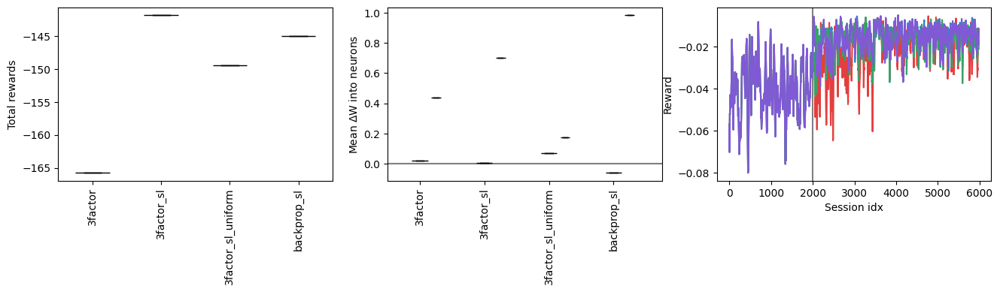

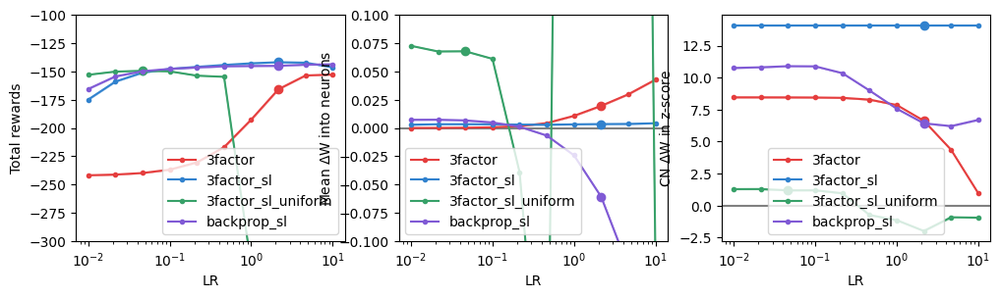

In [ ]:
# RL vs. SL
if scan_type in ('learning_rule_comparison_rl_vs_sl', 'learning_rule_comparison_deeper_credit',):
    n_scan_1 = len(scan_vals_1)
    n_scan_2 = len(scan_vals_2)

    if scan_type in ('learning_rule_comparison_rl_vs_sl',):
        lr_scan_2_idxs = (7, 7, 2, 7)
    elif scan_type in ('learning_rule_comparison_deeper_credit',):
        lr_scan_2_idxs = (5, 4, 3,)

    scan_2_idx = 0

    fig, (ax1, ax2, ax6,) = plt.subplots(1, 3, figsize=(16, 3))

    mean_delta_W_in = np.zeros((n_scan, n_repeats))
    cn_delta_W_in = np.zeros((n_scan, n_repeats))
    cn_delta_W_in_z = np.zeros((n_scan, n_repeats))

    for scan_idx in range(n_scan):
        for repeat_idx in range(n_repeats):
            cn_idx = cn_idxs[scan_idx, repeat_idx, 0]
            delta_W_in = np.sum(delta_W_recs[scan_idx, repeat_idx], axis=-1)

            mean_delta_W_in[scan_idx, repeat_idx] = np.mean(delta_W_in)
            cn_delta_W_in[scan_idx, repeat_idx] = delta_W_in[cn_idx]
            cn_delta_W_in_z[scan_idx, repeat_idx] = (delta_W_in[cn_idx] - np.mean(delta_W_in)) / np.std(delta_W_in)

    total_rewards_slice = np.zeros((n_scan_1, n_repeats,))
    mean_delta_W_in_slice = np.zeros((n_scan_1, n_repeats,))
    cn_delta_W_in_sclie = np.zeros((n_scan_1, n_repeats,))

    for rule_idx in range(n_scan_1):
        scan_2_idx = lr_scan_2_idxs[rule_idx]

        total_rewards_slice[rule_idx] = total_rewards.reshape(n_scan_1, n_scan_2, n_repeats)[rule_idx, scan_2_idx, :]
        mean_delta_W_in_slice[rule_idx] = mean_delta_W_in.reshape(n_scan_1, n_scan_2, n_repeats)[rule_idx, scan_2_idx, :]
        cn_delta_W_in_sclie[rule_idx] = cn_delta_W_in.reshape(n_scan_1, n_scan_2, n_repeats)[rule_idx, scan_2_idx, :]

        total_rewards_rule = rewards_all.reshape(n_scan_1, n_scan_2, n_repeats, -1)[rule_idx, scan_2_idx] # (n_lrs, n_repeats)
        n_smooth = 20
        smooth_fn = 1 / n_smooth * np.ones((n_smooth,))
        total_rewards_rule_smooth =  np.apply_along_axis(lambda m: np.convolve(m, smooth_fn, mode='valid'), axis=-1, arr=total_rewards_rule)

        # total_rewards_rule_smooth = np.convolve(total_rewards_rule, smooth_fn, mode='valid')
        median_rewards_all = np.mean(total_rewards_rule_smooth, axis=0)
        ax6.plot(median_rewards_all, color=c_vals[rule_idx], label=scan_vals_1[rule_idx])

    rew_bp = ax1.boxplot(total_rewards_slice.T, patch_artist=True, notch=False, positions=np.arange(n_scan_1),
                         widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                         boxprops={'linewidth':0.})

    for patch in rew_bp['boxes']:
        patch.set_facecolor(c_vals[0])


    delta_W_bp = ax2.boxplot(mean_delta_W_in_slice.T, patch_artist=True, notch=False, positions=np.arange(n_scan_1),
                             widths=0.25, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                             boxprops={'linewidth':0.})

    delta_W_cn_bp = ax2.boxplot(cn_delta_W_in_sclie.T, patch_artist=True, notch=False, positions=np.arange(n_scan_1)+0.25,
                                widths=0.15, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                                boxprops={'linewidth':0.})

    for patch in delta_W_bp['boxes']:
        patch.set_facecolor('grey')
    for patch in delta_W_cn_bp['boxes']:
        patch.set_facecolor(c_vals_p['cn'])

    ax1.set_ylabel('Total rewards')

    ax2.set_ylabel('Mean $\Delta$W into neurons')
    ax2.axhline(0.0, color='grey', zorder=-5)

    for ax in (ax1, ax2,):
        ax.set_xticks(np.arange(n_scan_1))
        ax.set_xticklabels(scan_vals_1, rotation=90)

    ax6.set_xlabel('Session idx')
    ax6.axvline(task_params['n_steps_stabilize'], color='grey', zorder=-5)
    ax6.set_ylabel('Reward')

    fig2, (ax3, ax4, ax5) = plt.subplots(1, 3, figsize=(12, 3))

    for rule_idx in range(n_scan_1):
        scan_2_idx = lr_scan_2_idxs[rule_idx]
        total_rewards_rule = total_rewards.reshape(n_scan_1, n_scan_2, n_repeats)[rule_idx] # (n_lrs, n_repeats)
        median_rewards = np.median(total_rewards_rule, axis=-1)
        err_rewards = (np.percentile(total_rewards_rule, 75, axis=-1), np.percentile(total_rewards_rule, 25, axis=-1))
        ax3.plot(scan_vals_2, median_rewards, color=c_vals[rule_idx], label=scan_vals_1[rule_idx], marker='.')
        ax3.plot(scan_vals_2[scan_2_idx], median_rewards[scan_2_idx], color=c_vals[rule_idx], marker='o')
        ax3.fill_between(scan_vals_2, err_rewards[0], err_rewards[1], 
                         color=c_vals[rule_idx], alpha=0.3, zorder=-5)

        mean_delta_W_in_rule = mean_delta_W_in.reshape(n_scan_1, n_scan_2, n_repeats)[rule_idx] # (n_lrs, n_repeats)
        median_mean_delta_W_in = np.median(mean_delta_W_in_rule, axis=-1)
        err_mean_delta_W_in = (np.percentile(mean_delta_W_in_rule, 75, axis=-1), np.percentile(mean_delta_W_in_rule, 25, axis=-1))
        ax4.plot(scan_vals_2, median_mean_delta_W_in, color=c_vals[rule_idx], label=scan_vals_1[rule_idx], marker='.')
        ax4.plot(scan_vals_2[scan_2_idx], median_mean_delta_W_in[scan_2_idx], color=c_vals[rule_idx], marker='o')
        ax4.fill_between(scan_vals_2, err_mean_delta_W_in[0], err_mean_delta_W_in[1], 
                         color=c_vals[rule_idx], alpha=0.3, zorder=-5)

        cn_delta_W_in_z_rule = cn_delta_W_in_z.reshape(n_scan_1, n_scan_2, n_repeats)[rule_idx] # (n_lrs, n_repeats)
        median_cn_z_score_rule = np.median(cn_delta_W_in_z_rule, axis=-1)
        err_cn_z_score_rule = (np.percentile(cn_delta_W_in_z_rule, 75, axis=-1), np.percentile(cn_delta_W_in_z_rule, 25, axis=-1))
        ax5.plot(scan_vals_2, median_cn_z_score_rule, color=c_vals[rule_idx], label=scan_vals_1[rule_idx], marker='.')
        ax5.plot(scan_vals_2[scan_2_idx], median_cn_z_score_rule[scan_2_idx], color=c_vals[rule_idx], marker='o')
        ax5.fill_between(scan_vals_2, err_cn_z_score_rule[0], err_cn_z_score_rule[1], 
                         color=c_vals[rule_idx], alpha=0.3, zorder=-5)

    ax3.set_ylabel('Total rewards')

    ax3.set_ylim((-300, -100))

    ax4.set_ylabel('Mean $\Delta$W into neurons')
    ax4.axhline(0.0, color='grey', zorder=-5)
    ax4.set_ylim((-0.1, 0.1))

    ax5.set_ylabel('CN $\Delta$W in z-score')
    ax5.axhline(0.0, color='grey', zorder=-5)

    for ax in (ax3, ax4, ax5,):
        ax.set_xlabel('LR')
        ax.set_xscale('log')
        ax.legend()

('RPE-dev product', 'CN product', 'CN dev-dev product', 'W_rec input to CN', 'W_rec output from CN', 'W_inp sim rel. to CN')
$\Delta$W_in
  [0.00363885 0.05640255 0.         0.08041535]
  [1.87929385e-23 3.29850368e-27            nan 1.82189973e-54]
$\Delta$W_out
  [0.00386581 0.01105871 0.         0.01223853]
  [2.42418879e-166 8.50480571e-009             nan 9.36345792e-011]


/tmp/ipykernel_146/563339568.py:138: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


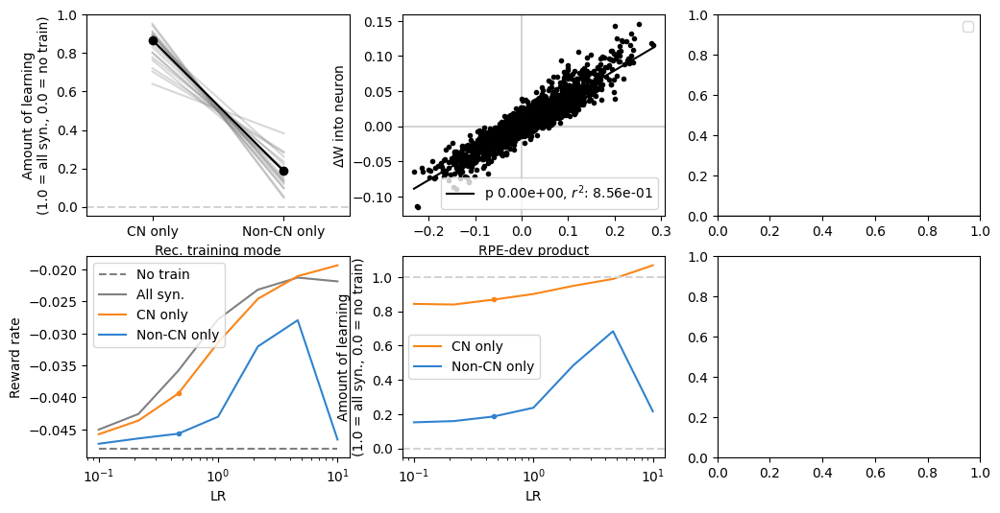

In [76]:
# How does freezing and not freezing the CN affect things
if scan_type in ('train_cn_weights_vs_not',):

    n_scan_1 = len(scan_vals_1)
    n_scan_2 = len(scan_vals_2)

    exemplar_scan_2_idx = 2

    fig, ((ax1, ax2, ax3,), (ax4, ax5, ax6,)) = plt.subplots(2, 3, figsize=(12, 6))

    # Convert total rewards into a reward rate
    reward_rate = np.zeros_like(total_rewards)
    for repeat_idx in range(n_repeats):
        reward_rate[:, repeat_idx] = np.nan # default
        if total_rewards[0, repeat_idx] < -400:
            print('Skipping idx {}, too low of reward even with no training'.format(repeat_idx))
        elif total_rewards[3, repeat_idx] < -400:
            print('Skipping idx {}, too low of reward for non-CN training'.format(repeat_idx))
        else:
            reward_rate[:, repeat_idx] = total_rewards[:, repeat_idx] / (task_params['n_steps'] - task_params['n_steps_stabilize'])

    learning_amounts = np.zeros((n_scan_2, 2, n_repeats,))
    reward_rate = reward_rate.reshape(n_scan_1, n_scan_2, n_repeats)
    total_reward_rate_change = reward_rate[1, :, :] - reward_rate[0, :, :]

    for scan_2_idx in range(n_scan_2):

        reward_rate_slice = reward_rate[:, scan_2_idx, :]

        # total_reward_rate_change = reward_rate_slice[1, :] - reward_rate_slice[0, :] # All versus none

        learning_amounts[scan_2_idx, 0, :] = (reward_rate_slice[2, :] - reward_rate_slice[0, :]) / total_reward_rate_change[scan_2_idx] # cn_only
        learning_amounts[scan_2_idx, 1, :] = (reward_rate_slice[3, :] - reward_rate_slice[0, :]) / total_reward_rate_change[scan_2_idx] # non-cn_only

        if scan_2_idx == exemplar_scan_2_idx:
            for repeat_idx in range(n_repeats):
                ax1.plot(np.arange(2), learning_amounts[scan_2_idx, :, repeat_idx], color='grey', zorder=-5, alpha=0.3)
            ax1.plot(np.arange(2), np.median(learning_amounts[scan_2_idx], axis=-1), marker='o', color='k')

    ax4.plot(scan_vals_2, np.median(reward_rate[0], axis=-1), color='grey', linestyle='dashed', label='No train')
    ax4.plot(scan_vals_2, np.median(reward_rate[1], axis=-1), color='grey', label='All syn.')
    ax4.plot(scan_vals_2, np.median(reward_rate[2], axis=-1), color=c_vals_p['cn'], label='CN only')
    ax4.plot(scan_vals_2, np.median(reward_rate[3], axis=-1), color=c_vals[1], label='Non-CN only')
    ax4.scatter(scan_vals_2[exemplar_scan_2_idx], np.median(reward_rate[2], axis=-1)[exemplar_scan_2_idx], color=c_vals_p['cn'], marker='.')
    ax4.scatter(scan_vals_2[exemplar_scan_2_idx], np.median(reward_rate[3], axis=-1)[exemplar_scan_2_idx], color=c_vals[1], marker='.')

    ax4.set_ylabel('Reward rate')

    ax5.plot(scan_vals_2, np.median(learning_amounts[:, 0, :], axis=-1), color=c_vals_p['cn'], label='CN only')
    ax5.plot(scan_vals_2, np.median(learning_amounts[:, 1, :], axis=-1), color=c_vals[1], label='Non-CN only')
    ax5.scatter(scan_vals_2[exemplar_scan_2_idx], np.median(learning_amounts[:, 0, :], axis=-1)[exemplar_scan_2_idx], color=c_vals_p['cn'], marker='.')
    ax5.scatter(scan_vals_2[exemplar_scan_2_idx], np.median(learning_amounts[:, 1, :], axis=-1)[exemplar_scan_2_idx], color=c_vals[1], marker='.')

    for ax in (ax4, ax5,):
        ax.set_xscale('log')
        ax.set_xlabel('LR')
        ax.legend()

    scan_1_idx = 3 # Only CN training

    predictors_fit_all = []
    W_init_to_cn_all = []
    delta_W_in_all = []
    delta_W_out_all = []

    for repeat_idx in range(n_repeats):
        scan_idx = exemplar_scan_2_idx + n_scan_2 * scan_1_idx
        cn_idx = cn_idxs.reshape(n_scan_1, n_scan_2, n_repeats, 1)[scan_1_idx, exemplar_scan_2_idx, repeat_idx, 0]

        # print(cn_idx)
        # print(cn_idxs[scan_idx, repeat_idx, 0])

        W_init =  W_rec_inits[scan_idx, repeat_idx]
        W_final = W_rec_finals[scan_idx, repeat_idx]
        delta_W = W_rec_finals[scan_idx, repeat_idx] - W_rec_inits[scan_idx, repeat_idx]
        delta_W_in = np.sum(delta_W, axis=-1)
        delta_W_out = np.sum(delta_W, axis=0)

        W_init_to_cn_all.append(np.delete(W_init[cn_idx, :], cn_idx))
        delta_W_in_all.append(np.delete(delta_W_in, cn_idx))
        delta_W_out_all.append(np.delete(delta_W_out, cn_idx))

        predictors_fit_all.append(
            np.delete(predictors_all[scan_idx, repeat_idx], cn_idx, axis=-1)
        )

        # ax2.scatter(W_init[cn_idx, :], delta_W_in, color='k', marker='.')
        # add_regression_line(W_init[cn_idx, :], delta_W_in, ax=ax2, color='k')
        # ax2.scatter(W_init[:, cn_idx], delta_W_in, color=c_vals[0], marker='.')
        # add_regression_line(W_init[:, cn_idx], delta_W_in, ax=ax2, color=c_vals[0])

    predictors_fit_all = np.concatenate(predictors_fit_all, axis=-1)
    W_init_to_cn_all = np.concatenate(W_init_to_cn_all)
    delta_W_in_all = np.concatenate(delta_W_in_all)
    delta_W_out_all = np.concatenate(delta_W_out_all)

    print(predictor_names)
    pred_idx = 0
    # ax2.scatter(W_init_to_cn_all, delta_W_in_all, color='k', marker='.')
    # add_regression_line(W_init_to_cn_all, delta_W_in_all, ax=ax2, color='k')
    ax2.scatter(predictors_fit_all[pred_idx], delta_W_in_all, color='k', marker='.')
    add_regression_line(predictors_fit_all[pred_idx], delta_W_in_all, ax=ax2, color='k')

    # ax2.set_xlabel('W into CN')
    ax2.set_xlabel(predictor_names[pred_idx])
    ax2.set_ylabel('$\Delta$W into neuron')

    pred_keep_idxs = np.array((3, 4, 5))

    X = predictors_fit_all[pred_keep_idxs].T
    X = sm.add_constant(X)

    fit_model = sm.OLS(delta_W_in_all[:, None], X, missing='none') # nans should be caught above
    results = fit_model.fit()
    print('$\Delta$W_in')
    print(' ', results.params)
    print(' ', results.pvalues)

    fit_model = sm.OLS(delta_W_out_all[:, None], X, missing='none') # nans should be caught above
    results = fit_model.fit()
    print('$\Delta$W_out')
    print(' ', results.params)
    print(' ', results.pvalues)


    # ax3.scatter(W_final[cn_idx, :], delta_W_in, color='k', marker='.')
    # add_regression_line(W_final[cn_idx, :], delta_W_in, ax=ax3, color='k')

    for ax in (ax1, ax5):
        ax.axhline(0.0, color='lightgrey', linestyle='dashed')
        ax.axhline(1.0, color='lightgrey', linestyle='dashed')
        ax.set_ylabel('Amount of learning\n(1.0 = all syn., 0.0 = no train)')

    ax1.set_xticks([0, 1])
    ax1.set_xticklabels(['CN only', 'Non-CN only'])
    ax1.set_xlim((-0.5, 1.5))
    ax1.set_xlabel('Rec. training mode')

    for ax in (ax2, ax3,):
        ax.legend()
        ax.axhline(0.0, color='lightgrey', linestyle='solid', zorder=-5)
        ax.axvline(0.0, color='lightgrey', linestyle='solid', zorder=-5)

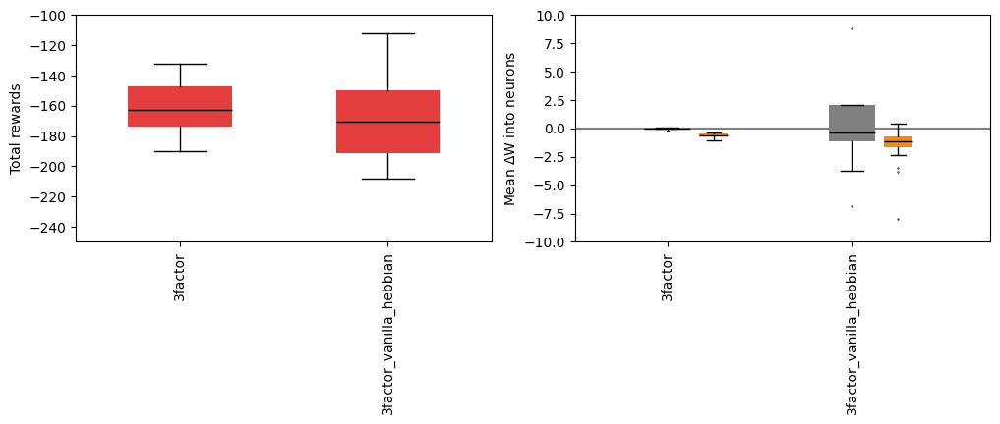

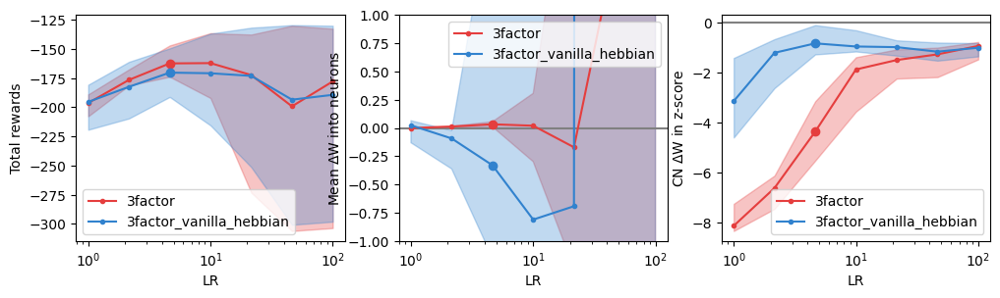

In [68]:
if scan_type in ('learning_rule_comparison_dev_tests', 'learning_rule_comparison_dev_tests_decrease',): # Compare various learning rules on performance and sparsity
    n_scan_1 = len(scan_vals_1)
    n_scan_2 = len(scan_vals_2)

    if scan_type in ('learning_rule_comparison_dev_tests',):
        scan_2_idx = 4
    elif scan_type in ('learning_rule_comparison_dev_tests_decrease',):
        scan_2_idx = 2

    fig, (ax1, ax2,) = plt.subplots(1, 2, figsize=(12, 3))

    total_rewards_slice = total_rewards.reshape(n_scan_1, n_scan_2, n_repeats)[:, scan_2_idx, :]

    rew_bp = ax1.boxplot(total_rewards_slice.T, patch_artist=True, notch=False, positions=np.arange(n_scan_1),
                         widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                         boxprops={'linewidth':0.})

    for patch in rew_bp['boxes']:
        patch.set_facecolor(c_vals[0])

    mean_delta_W_in = np.zeros((n_scan, n_repeats))
    cn_delta_W_in = np.zeros((n_scan, n_repeats))
    cn_delta_W_in_z = np.zeros((n_scan, n_repeats))

    for scan_idx in range(n_scan):
        for repeat_idx in range(n_repeats):
            cn_idx = cn_idxs[scan_idx, repeat_idx, 0]
            delta_W_in = np.sum(delta_W_recs[scan_idx, repeat_idx], axis=-1)

            mean_delta_W_in[scan_idx, repeat_idx] = np.mean(delta_W_in)
            cn_delta_W_in[scan_idx, repeat_idx] = delta_W_in[cn_idx]
            cn_delta_W_in_z[scan_idx, repeat_idx] = (delta_W_in[cn_idx] - np.mean(delta_W_in)) / np.std(delta_W_in)

    mean_delta_W_in_slice = mean_delta_W_in.reshape(n_scan_1, n_scan_2, n_repeats)[:, scan_2_idx, :]
    cn_delta_W_in_sclie = cn_delta_W_in.reshape(n_scan_1, n_scan_2, n_repeats)[:, scan_2_idx, :]

    delta_W_bp = ax2.boxplot(mean_delta_W_in_slice.T, patch_artist=True, notch=False, positions=np.arange(n_scan_1),
                             widths=0.25, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                             boxprops={'linewidth':0.})

    delta_W_cn_bp = ax2.boxplot(cn_delta_W_in_sclie.T, patch_artist=True, notch=False, positions=np.arange(n_scan_1)+0.25,
                                widths=0.15, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                                boxprops={'linewidth':0.})

    for patch in delta_W_bp['boxes']:
        patch.set_facecolor('grey')
    for patch in delta_W_cn_bp['boxes']:
        patch.set_facecolor(c_vals_p['cn'])

    ax1.set_ylabel('Total rewards')

    ax2.set_ylabel('Mean $\Delta$W into neurons')
    ax2.axhline(0.0, color='grey', zorder=-5)

    for ax in (ax1, ax2,):
        ax.set_xticks(np.arange(n_scan_1))
        ax.set_xticklabels(scan_vals_1, rotation=90)

    fig2, (ax3, ax4, ax5) = plt.subplots(1, 3, figsize=(12, 3))

    for rule_idx in range(n_scan_1):
        total_rewards_rule = total_rewards.reshape(n_scan_1, n_scan_2, n_repeats)[rule_idx] # (n_lrs, n_repeats)
        median_rewards = np.median(total_rewards_rule, axis=-1)
        err_rewards = (np.percentile(total_rewards_rule, 75, axis=-1), np.percentile(total_rewards_rule, 25, axis=-1))
        ax3.plot(scan_vals_2, median_rewards, color=c_vals[rule_idx], label=scan_vals_1[rule_idx], marker='.')
        ax3.plot(scan_vals_2[scan_2_idx], median_rewards[scan_2_idx], color=c_vals[rule_idx], marker='o')
        ax3.fill_between(scan_vals_2, err_rewards[0], err_rewards[1], 
                         color=c_vals[rule_idx], alpha=0.3, zorder=-5)

        mean_delta_W_in_rule = mean_delta_W_in.reshape(n_scan_1, n_scan_2, n_repeats)[rule_idx] # (n_lrs, n_repeats)
        median_mean_delta_W_in = np.median(mean_delta_W_in_rule, axis=-1)
        err_mean_delta_W_in = (np.percentile(mean_delta_W_in_rule, 75, axis=-1), np.percentile(mean_delta_W_in_rule, 25, axis=-1))
        ax4.plot(scan_vals_2, median_mean_delta_W_in, color=c_vals[rule_idx], label=scan_vals_1[rule_idx], marker='.')
        ax4.plot(scan_vals_2[scan_2_idx], median_mean_delta_W_in[scan_2_idx], color=c_vals[rule_idx], marker='o')
        ax4.fill_between(scan_vals_2, err_mean_delta_W_in[0], err_mean_delta_W_in[1], 
                         color=c_vals[rule_idx], alpha=0.3, zorder=-5)

        cn_delta_W_in_z_rule = cn_delta_W_in_z.reshape(n_scan_1, n_scan_2, n_repeats)[rule_idx] # (n_lrs, n_repeats)
        median_cn_z_score_rule = np.median(cn_delta_W_in_z_rule, axis=-1)
        err_cn_z_score_rule = (np.percentile(cn_delta_W_in_z_rule, 75, axis=-1), np.percentile(cn_delta_W_in_z_rule, 25, axis=-1))
        ax5.plot(scan_vals_2, median_cn_z_score_rule, color=c_vals[rule_idx], label=scan_vals_1[rule_idx], marker='.')
        ax5.plot(scan_vals_2[scan_2_idx], median_cn_z_score_rule[scan_2_idx], color=c_vals[rule_idx], marker='o')
        ax5.fill_between(scan_vals_2, err_cn_z_score_rule[0], err_cn_z_score_rule[1], 
                         color=c_vals[rule_idx], alpha=0.3, zorder=-5)
    
    if scan_type in ('learning_rule_comparison_dev_tests',): # Some plot ranges that work well for increase
        ax1.set_ylim((-400, -100))
        
        ax3.set_ylim((-300, -100))
        ax4.set_ylim((-0.1, 0.1))
    elif scan_type in ('learning_rule_comparison_dev_tests_decrease',): # Some plot ranges that work well for decrease
        ax1.set_ylim((-250, -100))
        ax2.set_ylim((-10, 10))
        # ax3.set_ylim((-300, -100))
        ax4.set_ylim((-1.0, 1.0))
    
    ax3.set_ylabel('Total rewards')

    ax4.set_ylabel('Mean $\Delta$W into neurons')
    ax4.axhline(0.0, color='grey', zorder=-5)

    ax5.set_ylabel('CN $\Delta$W in z-score')
    ax5.axhline(0.0, color='grey', zorder=-5)

    for ax in (ax3, ax4, ax5,):
        ax.set_xlabel('LR')
        ax.set_xscale('log')
        ax.legend()

(7, 10)
(70, 2)
[-0.01011605 -0.67542647 -0.00283724]
[4.42137949e-09 1.75191566e-24 1.79530344e-03]


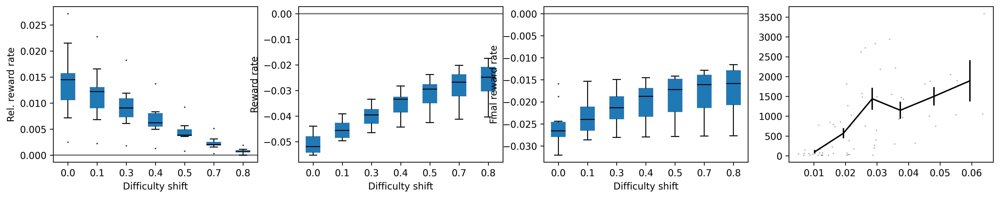

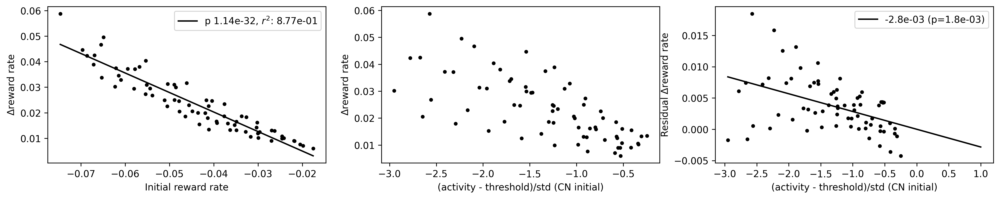

In [120]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(18, 3))
n_plots = int(n_scan / 2)

# Compute the difference in total rewards from training vs. no training setups
delta_reward_rate = (total_rewards[n_plots:] - total_rewards[:n_plots]) / (task_params['n_steps'] - task_params['n_steps_stabilize'])

# No relative value, just total amount of reward received
base_reward_rate = total_rewards[:n_plots] / (task_params['n_steps'] - task_params['n_steps_stabilize'])
reward_rate = total_rewards[n_plots:] / (task_params['n_steps'] - task_params['n_steps_stabilize'])

reward_rate_evaluate = total_rewards_evaluate[n_plots:] / (task_params['n_steps_evaluate'])

rel_rew_bp = ax1.boxplot(delta_reward_rate.T, patch_artist=True, notch=False, positions=np.arange(n_plots),
                         widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                         boxprops={'linewidth':0.})

rew_bp = ax2.boxplot(reward_rate.T, patch_artist=True, notch=False, positions=np.arange(n_plots),
                     widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                     boxprops={'linewidth':0.})

# sol_steps_max = np.where(np.isnan(sol_steps), task_params['n_steps'] - task_params['n_steps_stabilize'], sol_steps)[n_plots:]

sol_bp = ax3.boxplot(reward_rate_evaluate.T, patch_artist=True, notch=False, positions=np.arange(n_plots),
                     widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                     boxprops={'linewidth':0.})

learning_dist = thresholds[n_plots:] - bci_means[n_plots:]

# for repeat_idx in range(n_repeats):
    # ax4.plot(learning_dist[:, repeat_idx], sol_steps_max[:, repeat_idx])
# ax4.scatter(learning_dist.flatten(), sol_steps_max.flatten(), marker='.')
# add_regression_line(learning_dist.flatten(), sol_steps_max.flatten(), ax=ax4, color='k')

non_nan = ~np.isnan(sol_steps[n_plots:].flatten())
sol_steps_nonan = sol_steps[n_plots:].flatten()[non_nan]
learning_dist_nonan = learning_dist.flatten()[non_nan]

ax4.scatter(learning_dist_nonan, sol_steps_nonan, marker='.', color='k', alpha=0.3, s=1.0)
add_bin_plot(learning_dist_nonan, sol_steps_nonan, n_bins=6, ax=ax4, color='k', zorder=5)


ax1.axhline(0.0, color='grey', zorder=-5)
ax2.axhline(0.0, color='grey', zorder=-5)
ax3.axhline(0.0, color='grey', zorder=-5)

ax1.set_ylabel('Rel. reward rate')
ax2.set_ylabel('Reward rate')
ax3.set_ylabel('Final reward rate')

for ax in (ax1, ax2, ax3):
    ax.set_xticks(np.arange(n_plots))
    ax.set_xticklabels(np.array(['{:.1f}'.format(scan_val[1]) for scan_val in scan_vals[n_plots:]]))
    ax.set_xlabel('Difficulty shift')

fig, (ax5, ax6, ax7) = plt.subplots(1, 3, figsize=(18, 3))

delta_reward = reward_rate_evaluate - base_reward_rate
# delta_reward = reward_rate - base_reward_rate

ax5.scatter(base_reward_rate, delta_reward, marker='.', color='k')
# ax5.scatter(base_reward_rate[:, 0], delta_reward[:, 0], marker='.', color=c_vals[0])
# ax5.scatter(base_reward_rate[0, :], delta_reward[0, :], marker='.', color=c_vals[1])
# ax5.scatter(base_reward_rate[0, 0], delta_reward[0, 0], marker='.', color=c_vals[3])
add_regression_line(base_reward_rate, delta_reward, ax=ax5, color='k')

ax5.set_xlabel('Initial reward rate')
ax5.set_ylabel('$\Delta$reward rate')
ax5.legend()

# metric_name = '(activity - threshold) (CN initial)'
# prediction_metric = bci_means[n_plots:] - thresholds[n_plots:]
metric_name = '(activity - threshold)/std (CN initial)'
prediction_metric = (bci_means[n_plots:] - thresholds[n_plots:]) / bci_stds[n_plots:]

ax6.scatter(prediction_metric, delta_reward, marker='.', color='k')
# ax6.scatter(prediction_metric[:, 0], delta_reward[:, 0], marker='.', color=c_vals[0])
# ax6.scatter(prediction_metric[0, :], delta_reward[0, :], marker='.', color=c_vals[1])
# ax6.scatter(prediction_metric[0, 0], delta_reward[0, 0], marker='.', color=c_vals[3])

ax6.set_xlabel(metric_name)
ax6.set_ylabel('$\Delta$reward rate')

print(delta_reward.shape)
# print(prediction_metric.shape)

X = np.concatenate((base_reward_rate.flatten()[:, None], prediction_metric.flatten()[:, None]), axis=-1)
print(X.shape)
X = sm.add_constant(X)
Y = delta_reward.flatten()[:, None]

fit_model = sm.OLS(Y, X, missing='none') # nans should be caught above
results = fit_model.fit()

x_vals = np.array((np.min(X), np.max(X)))
Y_pred = results.predict(X)

Y_subtracted = Y[:, 0] - (results.params[0] + X[:, 1] * results.params[1])
Y_subtracted = Y_subtracted.reshape((n_plots, n_repeats))

ax7.scatter(prediction_metric, Y_subtracted, marker='.', color='k')
ax7.plot(x_vals, x_vals * results.params[-1], color='k', 
         label='{:.1e} (p={:.1e})'.format(results.params[-1], results.pvalues[-1]))
# ax7.scatter(prediction_metric[:, 0], Y_subtracted[:, 0], marker='.', color=c_vals[0])
# ax7.scatter(prediction_metric[0, :], Y_subtracted[0, :], marker='.', color=c_vals[1])
# ax7.scatter(prediction_metric[0, 0], Y_subtracted[0, 0], marker='.', color=c_vals[3])

ax7.set_xlabel(metric_name)
ax7.set_ylabel('Residual $\Delta$reward rate')
ax7.legend()

print(results.params)
print(results.pvalues)

IndexError: boolean index did not match indexed array along axis 0; size of axis is 300 but size of corresponding boolean axis is 70

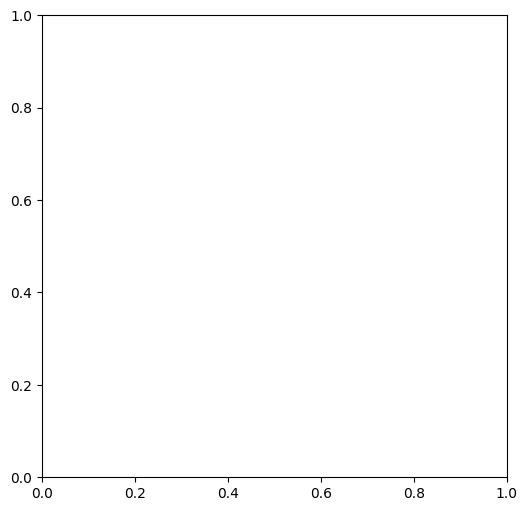

In [49]:
# print(thresholds)
# print(bci_presession_means)
# print(bci_presession_vars)
# print(sol_steps)
fig4, ax4 = plt.subplots(1, 1, figsize=(6, 6))

tep_to_sec = task_params['t_step'] / 1000 # Convert from ms to s

bci_std = np.sqrt(bci_presession_vars)

non_nan = ~np.isnan(sol_steps.flatten())
sol_steps_nonan = sol_steps.flatten()[non_nan]
bci_std_nonan = bci_std.flatten()[non_nan]

ax4.scatter(ACTIVITY_SCALE * bci_std_nonan, step_to_sec * sol_steps_nonan, marker='.', color='k', alpha=0.3, s=1.0)

0
1 0
[-0.02168276 -0.04253005  0.01992737  0.09546439 -0.04310292 -0.06678288
  0.05493525  0.00178176  0.10546289 -0.0755979 ]
[-0.02168276 -0.04253005  0.01992737  0.09546439 -0.04310292 -0.06678288
  0.05493525  0.00178176  0.10546289 -0.0755979 ]


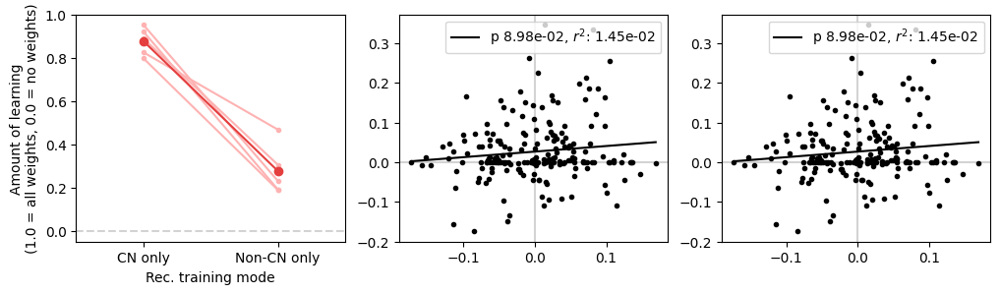

In [14]:
import statsmodels.api as sm

def plot_scan_metric(ax, scan_metric, scan_vals=None, color_idx=0, plot_std=False, scatter_raw=False, scatter_raw_connect=False):

    if scan_vals is None:
        scan_vals = np.arange(scan_metric.shape[0])

    mean_scan_metric = np.mean(scan_metric, axis=-1)
    std_scan_metric = np.std(scan_metric, axis=-1) / np.sqrt(scan_metric.shape[-1])
    
    ax.plot(scan_vals, mean_scan_metric, color=c_vals_d[color_idx], zorder=10, linewidth=5.0)
    if plot_std:
        ax.fill_between(scan_vals, mean_scan_metric - std_scan_metric,
                        mean_scan_metric + std_scan_metric, color=c_vals[color_idx],
                        zorder=5, alpha=0.3)

    for scan_idx, scan_val in enumerate(scan_vals):
        if scatter_raw:
            ax.scatter(scan_val * np.ones_like(scan_metric[scan_idx]), scan_metric[scan_idx],
                       color=c_vals[color_idx], marker=None, zorder=-5, alpha=0.3)
    for repeat_idx in range(scan_metric.shape[1]):
        if scatter_raw_connect:
            ax.plot(scan_vals, scan_metric[:, repeat_idx],
                    color=c_vals[color_idx], marker='.', zorder=-1, alpha=0.5)

if scan_type in ('toy_param_scan_lr', 'toy_param_scan_tau_elig', 'toy_param_scan_tau_rpe', 'toy_param_scan_tau_act', 
                 'toy_param_scan_delay_tau_elig', 'toy_param_scan_tau_rpe_act',):
    fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))

    if scan_vals[0].shape == (): # 1d scan_vals
        if scan_type not in ('toy_param_scan_lr',):
            raise ValueError('Other types depricated with no baseline subtract')
        print('SUBRTRACTING FIRST VALUE OFF ASSUMING IT IS BASELINE')
        delta_total_rewards = total_rewards[1:] - total_rewards[0]
        plot_scan_metric(ax1, delta_total_rewards, scan_vals[1:], plot_std=True, scatter_raw=True)

        ax1.set_xscale('log')
        ax1.set_ylabel('Total Reward')

        if scan_type in ('toy_param_scan_lr',):
            ax1.set_xlabel('LR')
            ax1.set_ylim((-180., -20))
        elif scan_type in ('toy_param_scan_tau_elig',):
            ax1.set_xlabel('n_elig_steps')
        elif scan_type in ('toy_param_scan_tau_rpe',):
            ax1.set_xlabel('n_rpe_steps')
        elif scan_type in ('toy_param_scan_tau_act',):
            ax1.set_xlabel('n_baseline_steps')
    else:
        total_rewards_2d = total_rewards.reshape(scan_vals_1.shape[0], scan_vals_2.shape[0], n_repeats)
        mean_total_rewards_2d = np.mean(total_rewards_2d, axis=-1)
        
        # +1 here and below to avoid problems with np.log10
        ax1.contourf(np.log10(scan_vals_2 + 1), np.log10(scan_vals_1 + 1), mean_total_rewards_2d, levels=15)
        
        ax1.set_yticks(np.log10(scan_vals_1 + 1))
        ax1.set_yticklabels(scan_vals_1)
        ax1.set_xticks(np.log10(scan_vals_2 + 1))
        ax1.set_xticklabels(scan_vals_2)
        
        
        if scan_type in ('toy_param_scan_delay_tau_elig',):
            ax1.plot((np.log10(2), np.log10(101)), (np.log10(2), np.log10(101)), color=c_vals[0], linestyle='dashed')

            ax1.set_ylabel('n_steps_delay')
            ax1.set_xlabel('n_elig_steps')
        elif scan_type in ('toy_param_scan_tau_rpe_act',):
            ax1.plot((np.log10(2), np.log10(1001)), (np.log10(2), np.log10(1001)), color=c_vals[0], linestyle='dashed')

            ax1.set_ylabel('n_steps_rpe')
            ax1.set_xlabel('n_steps_act_baseline')
elif scan_type in ('toy_param_scan_n_neurons',): # Separate from above because this has additional delta W analysis
    n_plots = int(n_scan / 2)

    fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

    delta_reward_rate = (total_rewards[n_plots:] - total_rewards[:n_plots]) / (task_params['n_steps'] - task_params['n_steps_stabilize'])

    z_scored_cn = np.zeros((n_plots, n_repeats))

    for plot_idx in range(n_plots):
        scan_idx = plot_idx + n_plots # Only second half are relevant

        for repeat_idx in range(n_repeats):
            mean_delta_W = np.mean(total_delta_Ws[scan_idx][repeat_idx])
            std_delta_W = np.std(total_delta_Ws[scan_idx][repeat_idx])
            cn_idx = cn_idxs[scan_idx, repeat_idx, 0]

            z_scored_cn[plot_idx, repeat_idx] = (
                (total_delta_Ws[scan_idx][repeat_idx, cn_idx] - mean_delta_W) / std_delta_W
            )
        
    rew_bp = ax1.boxplot(delta_reward_rate.T, patch_artist=True, notch=False, positions=np.arange(n_plots),
                         widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                         boxprops={'linewidth':0.})

    sparsity_bp = ax2.boxplot(z_scored_cn.T, patch_artist=True, notch=False, positions=np.arange(n_plots),
                              widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                              boxprops={'linewidth':0.})

    ax1.axhline(0.0, color='grey', zorder=-5)
    ax2.axhline(0.0, color='grey', zorder=-5)

    ax1.set_ylabel('Reward rate')
    ax2.set_ylabel('CN activity change (z-score)')

    for ax in (ax1, ax2):
        ax.set_xticks(np.arange(n_plots))
        ax.set_xticklabels([scan_val[1] for scan_val in scan_vals[n_plots:]])
        ax.set_xlabel('# hidden neurons')
elif scan_type in ('toy_param_scan_n_stds',):
    fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(16, 3))
    n_plots = int(n_scan / 2)

    delta_reward_rate = (total_rewards[n_plots:] - total_rewards[:n_plots]) / (task_params['n_steps'] - task_params['n_steps_stabilize'])
    reward_rate = total_rewards[n_plots:] / (task_params['n_steps'] - task_params['n_steps_stabilize'])

    rel_rew_bp = ax1.boxplot(delta_reward_rate.T, patch_artist=True, notch=False, positions=np.arange(n_plots),
                             widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                             boxprops={'linewidth':0.})

    rew_bp = ax2.boxplot(reward_rate.T, patch_artist=True, notch=False, positions=np.arange(n_plots),
                         widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                         boxprops={'linewidth':0.})

    sol_steps_max = np.where(np.isnan(sol_steps), task_params['n_steps'] - task_params['n_steps_stabilize'], sol_steps)[n_plots:]

    sol_bp = ax3.boxplot(sol_steps_max.T, patch_artist=True, notch=False, positions=np.arange(n_plots),
                         widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                         boxprops={'linewidth':0.})

    learning_dist = thresholds[n_plots:] - bci_means[n_plots:]

    # for repeat_idx in range(n_repeats):
        # ax4.plot(learning_dist[:, repeat_idx], sol_steps_max[:, repeat_idx])
    # ax4.scatter(learning_dist.flatten(), sol_steps_max.flatten(), marker='.')
    # add_regression_line(learning_dist.flatten(), sol_steps_max.flatten(), ax=ax4, color='k')

    non_nan = ~np.isnan(sol_steps[n_plots:].flatten())
    sol_steps_nonan = sol_steps[n_plots:].flatten()[non_nan]
    learning_dist_nonan = learning_dist.flatten()[non_nan]

    ax4.scatter(learning_dist_nonan, sol_steps_nonan, marker='.', color='k', alpha=0.3, s=1.0)
    add_bin_plot(learning_dist_nonan, sol_steps_nonan, n_bins=6, ax=ax4, color='k', zorder=5)


    ax1.axhline(0.0, color='grey', zorder=-5)
    ax2.axhline(0.0, color='grey', zorder=-5)
    ax3.axhline(0.0, color='grey', zorder=-5)

    ax1.set_ylabel('Rel. reward rate')
    ax2.set_ylabel('Reward rate')

    for ax in (ax1, ax2, ax3):
        ax.set_xticks(np.arange(n_plots))
        ax.set_xticklabels([scan_val[1] for scan_val in scan_vals[n_plots:]])
        ax.set_xlabel('Neural distance')
elif scan_type in ('learning_rule_comparison_Winp', 'learning_rule_comparison_Wrec',):
    fig, ((ax1, ax2, ax3,), (ax4, ax5, ax6,),) = plt.subplots(2, 3, figsize=(16, 6))

    plot_scan_metric(ax1, total_rewards, plot_std=True, scatter_raw_connect=True)
    ax1.set_ylabel('Total Reward')
    
    plot_scan_metric(ax2, sol_steps, plot_std=True, scatter_raw_connect=True)
    ax2.set_ylabel('Steps to solution')

    if scan_type in ('learning_rule_comparison_Winp',):
        delta_W = delta_W_inps
        ax4_label = 'Delta W_inp mag'
    elif scan_type in ('learning_rule_comparison_Wrec',):
        delta_W = delta_W_recs
        ax4_label = 'Delta W_rec mag'

    delta_W_flat = delta_W.reshape((n_scan, n_repeats, -1))
    delta_W_mag = np.linalg.norm(delta_W_flat, axis=-1)
    plot_scan_metric(ax4, delta_W_mag, color_idx=1, plot_std=True, scatter_raw_connect=True)
    ax4.set_ylabel(ax4_label)

    delta_W_pr = participation_ratio_vector(delta_W_flat, axis=-1) / (delta_W_flat.shape[-1])
    plot_scan_metric(ax5, delta_W_pr, color_idx=2, plot_std=True, scatter_raw_connect=True)
    ax5.set_ylabel('Delta W PR')

    delta_W_cn_perc = np.zeros((n_scan, n_repeats))
    for scan_idx, scan_val in enumerate(scan_vals):
        for repeat_idx in range(n_repeats):
            cn_idx = int(cn_idxs[scan_idx, repeat_idx, 0])
            delta_W_into = np.sum(delta_W[scan_idx, repeat_idx], axis=-1)
            # fig1, ax = plt.subplots(1, 1, figsize=(6, 6))
            # _, bins, _ = ax.hist(delta_W_into, bins=50, color=c_vals_l[1])
            # _ = ax.hist(delta_W_into[cn_idx], bins=bins, color=c_vals[0])
            sort_idxs = np.argsort(delta_W_into)[::-1]

            cn_perc = 1 - (np.where(sort_idxs == cn_idx)[0][0] + 1) / task_params['n_neurons']

            # ax.set_xlabel('CN perc {:.2f}'.format(cn_perc))
            delta_W_cn_perc[scan_idx, repeat_idx] = cn_perc

    plot_scan_metric(ax6, delta_W_cn_perc, color_idx=3, plot_std=True, scatter_raw_connect=True)
    ax6.set_ylabel('Delta W CN perc')

    for ax in (ax1, ax2, ax3, ax4, ax5, ax6,):
        ax.set_xlabel('Train type')
        ax.set_xticks((0, 1))
        ax.set_xticklabels(scan_vals)
        ax.set_xlim((-0.5, 1.5))
        
    ### Predicting weight changes
    predictor_params = np.zeros((n_scan, n_repeats, n_predictors+1)) # +1 for intercept
    predictor_pvalues = np.zeros((n_scan, n_repeats, n_predictors+1)) # +1 for intercept
    
    for scan_idx, scan_val in enumerate(scan_vals):
        for repeat_idx in range(n_repeats):
            cn_idx = int(cn_idxs[scan_idx, repeat_idx, 0]) 
            
            total_delta_W = np.sum(delta_W[scan_idx, repeat_idx], axis=-1)
            total_delta_W_no_cn = np.delete(total_delta_W, cn_idx)
        
            predictors = predictors_all[scan_idx, repeat_idx]
            X = np.delete(predictors, cn_idx, axis=-1).T
            Y = total_delta_W_no_cn[:, np.newaxis]
            X = sm.add_constant(X)

            fit_model = sm.OLS(Y, X, missing='none') # nans should be caught above
            results = fit_model.fit()
            
            predictor_params[scan_idx, repeat_idx] = results.params
            predictor_pvalues[scan_idx, repeat_idx] = results.pvalues

    fig, ((ax1, ax2, ax3,), (ax4, ax5, ax6,),) = plt.subplots(2, 3, figsize=(16, 6))
    
    for predictor_idx, ax in zip(range(n_predictors), (ax1, ax2, ax3, ax4,)) :
        plot_scan_metric(ax, -np.log10(predictor_pvalues[:, :, predictor_idx+1]), plot_std=True, scatter_raw_connect=True, color_idx=predictor_idx)
        ax.set_ylabel(predictor_names[predictor_idx] + ': -log10(p)')
        
    for predictor_idx, ax in zip(range(2), (ax5, ax6,)) :
        plot_scan_metric(ax, predictor_params[:, :, predictor_idx+1], plot_std=True, scatter_raw_connect=True, color_idx=predictor_idx)
        ax.set_ylabel(predictor_names[predictor_idx] + ': Coef.')
        ax.axhline(0., color='grey', zorder=-5, linestyle='dashed')
    
    for ax in (ax1, ax2, ax3, ax4, ax5, ax6,):
        ax.set_xlabel('Train type')
        ax.set_xticks((0, 1))
        ax.set_xticklabels(scan_vals)
        ax.set_xlim((-0.5, 1.5))
elif scan_type in ('learning_rule_comparison_3factor_np',):
#     repeat_idx = 0
#     neuron_idx = 22

#     print(activity_stabilize_all.shape)

#     start_idx = 500
#     end_idx = 600

#     fig, ax1 = plt.subplots(1, 1, figsize=(12, 4))

#     ax1.plot(activity_stabilize_all[0, repeat_idx, start_idx:end_idx, neuron_idx], color=c_vals[0])
#     ax1.plot(activity_stabilize_all[1, repeat_idx, start_idx:end_idx, neuron_idx], color=c_vals[1])

#     print('Neuron {}:'.format(neuron_idx))
#     print('  Noise inject std: {:.2e}'.format(np.std(activity_stabilize_all[0, repeat_idx, :, neuron_idx])))
#     print('  Node pert std: {:.2e}'.format(np.std(activity_stabilize_all[1, repeat_idx, :, neuron_idx])))
#     print('All neurons')
#     print('  Noise inject std: {:.2e}'.format(np.std(activity_stabilize_all[0, repeat_idx, :, :])))
#     print('  Node pert std: {:.2e}'.format(np.std(activity_stabilize_all[1, repeat_idx, :, :])))

    fig, ((ax1, ax2, ax3,), (ax4, ax5, ax6,),) = plt.subplots(2, 3, figsize=(16, 6))

    for repeat_idx in range(n_repeats):
        print('Repeat_idx:', repeat_idx)

        ax1.plot(0, total_rewards[0, repeat_idx] - total_rewards[1, repeat_idx], color=c_vals[0], marker='.',)
        ax1.plot(1, total_rewards[2, repeat_idx] - total_rewards[3, repeat_idx], color=c_vals[1], marker='.',)

        ax2.plot(0, np.std(activity_stabilize_all[0, repeat_idx, :, :]), color=c_vals[0], marker='.',)
        ax2.plot(1, np.std(activity_stabilize_all[2, repeat_idx, :, :]), color=c_vals[1], marker='.',)

        activity_pca = PCA()
        activity_pca.fit(activity_stabilize_all[0, repeat_idx, :, :])
        stabilize_pca_var_exp = activity_pca.explained_variance_ratio_
        stabilize_pca_pr = participation_ratio_vector(activity_pca.explained_variance_ratio_)
        ax3.plot(0, stabilize_pca_pr / net_params['n_neurons'], marker='.', color=c_vals[0])

        activity_pca = PCA()
        activity_pca.fit(activity_stabilize_all[2, repeat_idx, :, :])
        stabilize_pca_var_exp = activity_pca.explained_variance_ratio_
        stabilize_pca_pr = participation_ratio_vector(activity_pca.explained_variance_ratio_)
        ax3.plot(1, stabilize_pca_pr / net_params['n_neurons'], marker='.', color=c_vals[1])

    ax1.set_ylabel('$\Delta$Tot. Reward')
    ax2.set_ylabel('Population std.')
    ax3.set_ylabel('Population PR')

    for ax in (ax1, ax2, ax3,):
        ax.set_xticks([0, 1])
        ax.set_xticklabels(('Ours', 'Node pert.'))
        ax.set_xlim((-1, 2))

        ax.axhline(0.0, color='grey', zorder=-5)
elif scan_type in ('hebbian_idx_vs_activity',):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

    # ax1.scatter(cn_activities[0, :, 1:].reshape(-1), hebbian_idxs[0, :, 1:].reshape(-1), color=c_vals[0],
    #             marker='.')
    # ax1.set_xlabel('CN activity (Day X)')
    # ax1.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), hebbian_idxs[0, :, 1:].reshape(-1), color=c_vals[0],
    #             marker='.')
    # # for repeat_idx in range(n_repeats):
    # #     ax1.plot(cn_prev_tunings[0, repeat_idx, 1:], hebbian_idxs[0, repeat_idx, 1:], color=c_vals[repeat_idx],
    # #              marker='.')
    # ax1.set_xlabel('CN \'tuning\' (-1 * |activity - center of target|, Day X)')
    # ax1.set_ylabel('Hebbian idx (Day X+1)')

    ax1.scatter(session_rpes[0, :, 1:].reshape(-1), delta_Ws[0, :, 1:].reshape(-1), color=c_vals[0],
                marker='.')
    ax1.set_xlabel('Session RPE (Day X)')
    ax1.set_ylabel('Delta W_rec (no CN, Day X)')

    ax2.scatter(session_rpes[0, :, 1:].reshape(-1), hebbian_idxs[0, :, 1:].reshape(-1), color=c_vals[1],
                marker='.')
    ax2.set_xlabel('Session RPE (Day X)')
    ax2.set_ylabel('Hebbian idx (Day X)')

    # ax2.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), session_rpes[0, :, 1:].reshape(-1), color=c_vals[1],
    #             marker='.')
    # ax2.set_xlabel('CN \'tuning\' (-1 * |activity - center of target|, Day X)')
    # ax2.set_ylabel('Session RPE (Day X+1)')

    # ax2.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), delta_Ws[0, :, 1:].reshape(-1), color=c_vals[1],
    #             marker='.')
    # ax2.set_xlabel('CN \'tuning\' (-1 * |activity - center of target|, Day X)')
    # ax2.set_ylabel('Delta W_rec (no CN, Day X+1)')

    # ax2.scatter(delta_Ws[0, :, 1:].reshape(-1), hebbian_idxs[0, :, 1:].reshape(-1), color=c_vals[1],
    #             marker='.')
    # ax2.set_xlabel('Delta W_rec (no CN, Day X)')
    # ax2.set_ylabel('Hebbian idx (Day X)')

    # ax2.scatter(hebbian_idxs[0, :, 1:].reshape(-1), session_rpes[0, :, 1:].reshape(-1), color=c_vals[1],
    #             marker='.')
    # ax2.set_xlabel('Hebbian idx')
    # ax2.set_ylabel('Session RPE (Day X+1)')

    # ax2.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), total_rewards[0, :, 1:].reshape(-1), color=c_vals[1],
    #             marker='.')
    # ax2.set_xlabel('CN \'tuning\' (-1 * |activity - center of target|, Day X)')
    # ax2.set_ylabel('Total reward (Day X+1)')

    # ax2.scatter(cn_tunings[0, :, 1:].reshape(-1), (total_rewards[0, :, 1:] - total_rewards[0, :, :-1]).reshape(-1), color=c_vals[1],
    #             marker='.')
    # ax2.set_xlabel('CN \'tuning\' (-1 * |activity - center of target|, Day X)')
    # ax2.set_ylabel('Reward diff (Day X+1 - Day X)')

    # ax1.set_xlim((0, 0.5))
    # ax2.set_ylim((-100, 0))

elif scan_type in ('add_correlation',):

    session_idx = 0
    n_neurons = task_params['n_neurons']

    # correlation_measure = cn_correlations # Raw activity correlations
    # correlation_label = 'CN1 - CN2 correlation'
    # correlation_measure = cn_dev_correlations # Activity deviation correlations
    # correlation_label = 'CN1 dev. - CN2 dev. correlation'
    # correlation_measure = rpe_correlations # Raw activity - RPE correlations
    # correlation_label = 'RPE - activity correlation'
    correlation_measure = rpe_dev_correlations # Deviation - RPE correlations
    correlation_label = 'RPE - dev correlation'

    cn_on_correlations = np.zeros((n_scan, n_repeats,))
    all_cn_correlations = np.zeros((n_scan, n_repeats, n_neurons,))
    delta_W_on = np.zeros((n_scan, n_repeats,))
    delta_W_cn = np.zeros((n_scan, n_repeats,))
    delta_W_all = np.zeros((n_scan, n_repeats,))
    all_delta_W = np.zeros((n_scan, n_repeats, n_neurons,))

    for scan_idx in range(n_scan):
        for repeat_idx in range(n_repeats):
            # if repeat_idx in (2, 6,):
            #     continue
            on_idx = on_idxs[scan_idx, repeat_idx, session_idx]
            cn_idx = cn_idxs[scan_idx, repeat_idx, session_idx]

            # Non-normalized versions
            delta_W_on[scan_idx, repeat_idx] = np.sum(delta_W_recs[scan_idx, repeat_idx][on_idx, :])
            delta_W_cn[scan_idx, repeat_idx] = np.sum(delta_W_recs[scan_idx, repeat_idx][cn_idx, :])
            delta_W_all[scan_idx, repeat_idx] = np.mean(np.sum(np.delete(delta_W_recs[scan_idx, repeat_idx], (cn_idx, on_idx), axis=0), axis=-1))

            # # Normalize change by uncorrelated (scan_idx = 0) CN delta W and rest of neurons
            # max_change = np.sum(delta_W_recs[0, repeat_idx][cn_idx, :]) # 1
            # min_change = np.mean(np.sum(np.delete(delta_W_recs[0, repeat_idx], (cn_idx, on_idx), axis=0), axis=-1)) # 0

            # delta_W_cn[scan_idx, repeat_idx] = (np.sum(delta_W_recs[scan_idx, repeat_idx][cn_idx, :]) - min_change) / (max_change - min_change)
            # # print('Scan {} repeat {}: {}'.format(scan_idx, repeat_idx, delta_W_cn[scan_idx, repeat_idx]))
            # delta_W_on[scan_idx, repeat_idx] = (np.sum(delta_W_recs[scan_idx, repeat_idx][on_idx, :]) - min_change) / (max_change - min_change)
            # delta_W_all[scan_idx, repeat_idx] = (np.mean(np.sum(np.delete(delta_W_recs[scan_idx, repeat_idx], (cn_idx, on_idx), axis=0), axis=-1)) - min_change) / (max_change - min_change)

            all_delta_W[scan_idx, repeat_idx, :] = np.sum(delta_W_recs[scan_idx, repeat_idx], axis=-1)
            cn_on_correlations[scan_idx, repeat_idx] = correlation_measure[scan_idx, repeat_idx, on_idx]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

    mean_cn_on_correlations = np.nanmean(cn_on_correlations, axis=-1)
    mean_delta_W_on = np.mean(delta_W_on, axis=-1)
    mean_delta_W_cn = np.mean(delta_W_cn, axis=-1)
    mean_delta_W_all = np.mean(delta_W_all, axis=-1)
    std_delta_W_on = np.std(delta_W_on, axis=-1)
    std_delta_W_cn = np.std(delta_W_cn, axis=-1)
    std_delta_W_all = np.std(delta_W_all, axis=-1)

    ax1.plot(mean_cn_on_correlations, mean_delta_W_cn, color=c_vals[1], marker='.', label='CN')
    ax1.fill_between(mean_cn_on_correlations, mean_delta_W_cn+std_delta_W_cn,
                     mean_delta_W_cn-std_delta_W_cn, alpha=0.3, zorder=-5, color=c_vals[1])
    ax1.plot(mean_cn_on_correlations, mean_delta_W_on, color=c_vals[0], marker='.', label='ON')
    ax1.fill_between(mean_cn_on_correlations, mean_delta_W_on+std_delta_W_on,
                     mean_delta_W_on-std_delta_W_on, alpha=0.3, zorder=-5, color=c_vals[0])
    # for repeat_idx in range(n_repeats):
    #     ax1.plot(cn_on_correlations[:, repeat_idx], delta_W_cn[:, repeat_idx], color=c_vals[1], alpha=0.3)
    #     ax1.plot(cn_on_correlations[:, repeat_idx], delta_W_on[:, repeat_idx], color=c_vals[0], alpha=0.3)

    ax1.plot(mean_cn_on_correlations, mean_delta_W_all, color=c_vals[2], marker='.', label='all neurons')
    ax1.fill_between(mean_cn_on_correlations, mean_delta_W_all+std_delta_W_all,
                     mean_delta_W_all-std_delta_W_all, alpha=0.3, zorder=-5, color=c_vals[2])

    ax2.scatter(cn_on_correlations.reshape(-1), (delta_W_on/delta_W_cn).reshape(-1),
                color=c_vals[3], marker='.')
    ax2.scatter(correlation_measure.reshape(-1), (all_delta_W/delta_W_cn[:, :, np.newaxis]).reshape(-1),
                color=c_vals_l[3], alpha=0.3, zorder=-5, marker='.')
    # ax2.scatter(cn_correlations[0].reshape(-1), (all_delta_W/delta_W_cn[:, :, np.newaxis])[0].reshape(-1),
    #             color=c_vals_l[3], alpha=0.3, zorder=-5, marker='.')
    # ax2.scatter(cn_on_correlations.reshape(-1), (delta_W_cn/delta_W_cn).reshape(-1),
    #             color=c_vals[3], marker='.')
    # ax2.scatter(np.delete(cn_on_correlations, 2, axis=-1).reshape(-1), np.delete(delta_W_on/delta_W_cn, 2, axis=-1).reshape(-1),
    #             color=c_vals[3], marker='.')


    ax1.set_xlabel('ON ' + correlation_label)
    ax1.set_ylabel('Norm. Delta W')
    ax1.legend()

    ax2.set_xlabel(correlation_label)
    ax2.set_ylabel('Delta W CN2 / Delta W CN1')

elif scan_type in ('time_to_train_one_vs_two',):

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

    x_locs = np.arange(n_repeats)

    # ax1.bar(x_locs-0.135, sol_steps[0], width=0.25, color=c_vals[3])
    # ax1.bar(x_locs+0.135, sol_steps[1], width=0.25, color=c_vals[0])
    # ax1.bar(x_locs+0.135, sol_steps[2], width=0.25, color=c_vals[1], bottom=sol_steps[1])
    # ax1.bar(x_locs-0.2, sol_steps[0], width=0.2, color=c_vals[3])
    # ax1.bar(x_locs, sol_steps[1], width=0.2, color=c_vals[0])
    # ax1.bar(x_locs+0.2, sol_steps[2], width=0.2, color=c_vals[1])
    ax1.bar(x_locs-0.3, sol_steps[0], width=0.2, color=c_vals[3], label='2 CN')
    ax1.bar(x_locs-0.1, np.mean(sol_steps[1:], axis=0), width=0.2, color=c_vals[2], label='Mean 1 CN')
    ax1.bar(x_locs+0.1, sol_steps[1], width=0.2, color=c_vals[0], label='CN1 only')
    ax1.bar(x_locs+0.3, sol_steps[2], width=0.2, color=c_vals[1], label='CN2 only')

    ax1.set_xlabel('Trial')
    ax1.set_ylabel('Steps to solution')

    covs = cn_covs[:, 0, 1] / (1/2 * (cn_covs[:, 0, 0] + cn_covs[:, 1, 1]))
    # rel_train_time = (sol_steps[0] - np.mean(sol_steps[1:], axis=0)) / np.mean(sol_steps[1:], axis=0)
    rel_train_time = (sol_steps[0] - np.mean(sol_steps[1:], axis=0)) / sol_steps[0]
    ax2.scatter(covs, rel_train_time, marker='.', color=c_vals[4])
    # ax2.scatter(np.arange(n_repeats), rel_train_time, marker='.', color=c_vals[5])
    ax2.axvline(0.0, color='grey', linestyle='dashed')
    ax2.axhline(0.0, color='grey', linestyle='dashed')
    ax2.set_xlabel('CN1-CN2 Covariance')
    ax2.set_ylabel('Rel. 2 CN - 1 CN Train time')

elif scan_type in ('compare_masks_cn_perc', 'compare_masks_pcs', 'compare_masks_dyn_thresh', 'compare_masks_fixed_thresh',):
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))
    axs = (ax1, ax2, ax3)
    
    if scan_type in ('compare_masks_cn_perc',):
        x_ticks = ('100', '80', '60', '40', '20',)
        x_label = 'CN pre-training activity percentile'
    elif scan_type in ('compare_masks_pcs',):
        x_ticks = ('PC2', 'PC3', 'PC5', 'PC10', 'PC20', 'PC50', 'PC100')
        x_label = 'BCI mask type'
    else:
        # x_labels = ('1 hot', '2 hot', '5 hot', '10 hot', '20 hot', 'wm',)
        x_ticks = ('PC1', 'PC80 (fix.)', 'PC100 (fix.)', 'PC80 (dyn.)', 'PC100 (dyn.)')
        x_label = 'BCI mask type'

    # mean_reward_rate = np.median(total_rewards, axis=-1) / (
    #     task_params['n_steps'] - task_params['n_steps_stabilize']
    # )
    # std_reward_rate = np.nanstd(total_rewards, axis=-1) / (
    #     task_params['n_steps'] - task_params['n_steps_stabilize']
    # )
    # mean_reward_rate_stabilize = np.median(total_rewards_stabilize, axis=-1) / (
    #     task_params['n_steps_stabilize']
    # )
    # std_reward_rate_stabilize = np.nanstd(total_rewards_stabilize, axis=-1) / (
    #     task_params['n_steps_stabilize']
    # )

    n_plots = int(n_scan/2)
    
    reward_rate_all = total_rewards / (
        task_params['n_steps'] - task_params['n_steps_stabilize']
    )
    
    reward_rate = reward_rate_all[::2]
    reward_baseline = reward_rate_all[1::2]
    
    
    
    # reward_rate_stabilize = total_rewards_stabilize / task_params['n_steps_stabilize']
    
    
    # reward_rate = total_rewards / (
    #     task_params['n_steps'] - task_params['n_steps_stabilize']
    # )
    # reward_rate_stabilize = total_rewards_stabilize / task_params['n_steps_stabilize']

    # ax1.errorbar(np.arange(n_scan), mean_reward_rate, yerr=std_reward_rate,
    #              color=c_vals[0], label='training reward rate')
    # ax1.errorbar(np.arange(n_scan), mean_reward_rate_stabilize, yerr=std_reward_rate_stabilize,
    #              color=c_vals[1], label='baseline rate')
    rew_bp = ax1.boxplot(reward_rate.T, patch_artist=True, notch=False, positions=np.arange(n_plots)-0.125,
                         widths=0.2)
    rew_baseline_bp = ax1.boxplot(reward_baseline.T, patch_artist=True, notch=False,
                                   positions=np.arange(n_plots)+0.125, widths=0.2)
    ax1.plot(np.arange(n_plots)-0.125, np.median(reward_rate, axis=-1), color=c_vals[0], label='Training')
    ax1.plot(np.arange(n_plots)+0.125, np.median(reward_baseline, axis=-1), color=c_vals[1], label='Pre-session')

    # fill boxplots with colors
    for idx, bplot in enumerate((rew_bp, rew_baseline_bp)):
        for patch in bplot['boxes']:
            patch.set_facecolor(c_vals[idx])

    # ax1.errorbar(np.arange(n_scan), mean_reward_rate_stabilize, yerr=std_reward_rate_stabilize,
    #              color=c_vals[1], label='baseline rate')
    # Sets zero train times to maximum
    sol_steps_train = sol_steps[::2]
    
    sol_steps_train = np.where(np.isnan(sol_steps_train), task_params['n_steps'] - task_params['n_steps_stabilize'], sol_steps_train)

    # mean_sol_steps = np.mean(sol_steps, axis=-1)
    # std_sol_steps = np.std(sol_steps, axis=-1)

    # ax2.errorbar(np.arange(n_scan), mean_sol_steps, yerr=std_sol_steps,
    #              color=c_vals[2])
    sol_steps_bp = ax2.boxplot(sol_steps_train.T, patch_artist=True, notch=False, positions=np.arange(n_plots),
                               widths=0.4)
    ax2.plot(np.arange(n_scan), np.median(sol_steps, axis=-1), color=c_vals[2], label=None)
    for patch in sol_steps_bp['boxes']:
        patch.set_facecolor(c_vals[2])

    
    rewards_all_baselines = rewards_all[1::2, :, task_params['n_steps_stabilize']:]
    rewards_all_baselines_flat = rewards_all_baselines.reshape(n_plots, -1) # Flatten all rewards across all repeats

    scan_means = np.mean(rewards_all_baselines_flat, axis=-1)
    scan_stds = np.std(rewards_all_baselines_flat, axis=-1)

    reward_dist_bp = ax3.boxplot(rewards_all_baselines_flat.T, patch_artist=True, notch=False, positions=np.arange(n_plots), 
                                 flierprops={'marker':'.'})
    for patch in reward_dist_bp['boxes']:
        patch.set_facecolor(c_vals[3])
        
    # ax3.violinplot(rewards_all_stabilize_flat.T, positions=np.arange(n_scan), showextrema=False)
    # for scan_idx in range(n_scan):
    #     ax3.plot((scan_idx, scan_idx), ((scan_means-scan_stds)[scan_idx], (scan_means+scan_stds)[scan_idx]), color='k')
    #     ax3.plot((scan_idx,), (scan_means[scan_idx],), color='k', marker='_')
    
    bci_mask_prs = np.zeros((n_scan, n_repeats,))

    for scan_idx in range(n_scan):
        for repeat_idx in range(n_repeats):
            bci_mask_prs[scan_idx, repeat_idx] = participation_ratio_vector(
                bci_masks_all[scan_idx, repeat_idx]
            )
    
    ax1.set_ylabel('Reward rate')
    ax2.set_ylabel('Sol. steps')
    ax3.set_ylabel('Pre-training reward dist.')

    ax2.set_ylim((0, None))

    for ax in axs:
        ax.set_xlabel(x_label)
        ax.set_xticks(np.arange(n_plots))
        ax.set_xticklabels(x_ticks)
        ax.legend()

elif scan_type in ('incremental_omp_training', 'incremental_omp_training_reward',):
    print('WARNING USING SOME HARD CODED PARAMETERS, MAKE SURE TO CHANGE IF CHANGING TRAINING SPECIFICATIONS')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    axs = (ax1, ax2)

    reward_rate_stabilize = total_rewards_stabilize / 1000 # Hard coded because this changes over later sessions
    reward_rate_stabilize[3, :] = reward_rate_stabilize[2, :] # Copy this for iterative, for comparison to non-iterative case

    reward_rate = total_rewards_last_interp / (task_params['n_steps'] - task_params['n_steps_stabilize'])

    rew_stabilize_bp = ax1.boxplot(reward_rate_stabilize[2:].T, patch_artist=True, notch=False,
                                   positions=np.arange(n_scan-2)+0.125, widths=0.2)
    rew_bp = ax1.boxplot(reward_rate[2:].T, patch_artist=True, notch=False,
                                 positions=np.arange(n_scan-2)-0.125, widths=0.2)

    ax1.plot(np.arange(n_scan-2)-0.125, np.median(reward_rate[2:], axis=-1), color=c_vals[0], label='Post-train')
    ax1.plot(np.arange(n_scan-2)+0.125, np.median(reward_rate_stabilize[2:], axis=-1), color=c_vals[1], label='Pre-train')

    ax1.set_ylabel('Reward rate')
    for patch in rew_stabilize_bp['boxes']:
        patch.set_facecolor(c_vals[1])
    for patch in rew_bp['boxes']:
        patch.set_facecolor(c_vals[0])

    ratio_in_bci = mean_bci_activity_end / mean_bci_activity_start[2:3, :, :]

    bci_ratio = ax2.boxplot(ratio_in_bci[2:, :, 0].T, patch_artist=True, notch=False, positions=np.arange(n_scan-2),
                                 widths=0.5)

    ax2.set_ylabel('BCI activity (post-train/pre-train)')
    ax2.axhline(1.0, color='grey', zorder=-5)
    ax2.set_yscale('log')

    for patch in bci_ratio['boxes']:
        patch.set_facecolor(c_vals[4])

    for ax in axs:
        ax.set_xticks(np.arange(n_scan-2))
        ax.set_xticklabels(['PC80 (fix.)', 'PC80 (interp.)'], fontsize=8)
        ax.legend()

elif scan_type in ('wmp_vs_omp',):

    fig, ax1 = plt.subplots(1, 1, figsize=(12, 4))

    full_rewards_plot = np.zeros_like(full_rewards)
    n_smooth = 20
    full_rewards_smooth = np.zeros_like(full_rewards)
    smooth_fn = np.ones((n_smooth))

    for scan_idx in range(n_scan): # Some rejection criteria
        for repeat_idx in range(n_repeats):
            if min(full_rewards[scan_idx, repeat_idx]) < -0.6:
                full_rewards_plot[scan_idx, repeat_idx] = np.nan
            else:
                full_rewards_plot[scan_idx, repeat_idx] = full_rewards[scan_idx, repeat_idx]

            full_rewards_smooth[scan_idx, repeat_idx] = np.convolve(full_rewards_plot[scan_idx, repeat_idx], smooth_fn, mode='full')[:-n_smooth+1]

    ax1.plot(np.nanmean(full_rewards_smooth[0, :, :], axis=0), color=c_vals[0],
                 zorder=5, label='WMP (PC2 -> PC10)')
    ax1.plot(np.nanmean(full_rewards_smooth[1, :, :], axis=0), color=c_vals[1],
                 zorder=5, label='OMP (PC2 -> PC80)')

    for scan_idx in range(n_scan):
        for repeat_idx in range(n_repeats):
            ax1.plot(full_rewards_smooth[scan_idx, repeat_idx], color=c_vals_l[scan_idx], alpha=0.3,
                     zorder=-5)


    ax1.axvline(task_params['n_steps_stabilize'], color='k', linestyle='dashed', label='training begins')
    ax1.axvline(task_params['perturbations'][0][0], color=c_vals[3], linestyle='dotted', label='pert.')
    ax1.axvline(task_params['perturbations'][1][0], color=c_vals[4], linestyle='dotted', label='remove pert.')

    ax1.legend()
    ax1.set_ylabel('BCI activity')
    ax1.set_xlabel('Step')

elif scan_type in ('train_cn_weights_vs_not', 'train_cn_weights_vs_not_3factor_np',):
    
    if scan_type in ('train_cn_weights_vs_not',):
        iteration_vals = ((0, 0),) # offset_idx, color_idx
    elif scan_type in ('train_cn_weights_vs_not_3factor_np',):
        iteration_vals = ((0, 0,), (4, 1,),) # offset_idx, color_idx
    
    fig, (ax1, ax2, ax3,) = plt.subplots(1, 3, figsize=(12, 3))
    
    # Convert total rewards into a reward rate
    reward_rate = np.zeros_like(total_rewards)
    for repeat_idx in range(n_repeats):
        reward_rate[:, repeat_idx] = np.nan # default
        if total_rewards[0, repeat_idx] < -400:
            print('Skipping idx {}, too low of reward even with no training'.format(repeat_idx))
        elif total_rewards[3, repeat_idx] < -400:
            print('Skipping idx {}, too low of reward for non-CN training'.format(repeat_idx))
        else:
            reward_rate[:, repeat_idx] = total_rewards[:, repeat_idx] / (task_params['n_steps'] - task_params['n_steps_stabilize'])
    
    for offset_idx, color_idx in iteration_vals:
        
        print(offset_idx)
        print(offset_idx+1, offset_idx+0)
        
        total_reward_rate_change = reward_rate[offset_idx+1, :] - reward_rate[offset_idx+0, :] # All versus none
        
        learning_amounts = np.zeros((2, n_repeats,))
        learning_amounts[0, :] = (reward_rate[offset_idx+2, :] - reward_rate[offset_idx+0, :]) / total_reward_rate_change # cn_only
        learning_amounts[1, :] = (reward_rate[offset_idx+3, :] - reward_rate[offset_idx+0, :]) / total_reward_rate_change # non-cn_only

        for repeat_idx in range(n_repeats):
            ax1.plot(np.arange(2), learning_amounts[:, repeat_idx], marker='.', color=c_vals_l[color_idx])
        ax1.plot(np.arange(2), np.mean(learning_amounts, axis=-1), marker='o', color=c_vals[color_idx])
        
    scan_idx = 3 # Only CN training
    repeat_idx = 3

    cn_idx = cn_idxs[scan_idx, repeat_idx, 0]

    delta_W = W_rec_finals[scan_idx, repeat_idx] - W_rec_inits[scan_idx, repeat_idx]
    delta_W_in = np.sum(delta_W, axis=-1)
    W_init =  W_rec_inits[scan_idx, repeat_idx]
    W_final = W_rec_finals[scan_idx, repeat_idx]
    
    ax2.scatter(W_init[cn_idx, :], delta_W_in, color='k', marker='.')
    add_regression_line(W_init[cn_idx, :], delta_W_in, ax=ax2, color='k')
    # ax2.scatter(W_init[:, cn_idx], delta_W_in, color=c_vals[0], marker='.')
    # add_regression_line(W_init[:, cn_idx], delta_W_in, ax=ax2, color=c_vals[0])
    
    ax3.scatter(W_final[cn_idx, :], delta_W_in, color='k', marker='.')
    add_regression_line(W_final[cn_idx, :], delta_W_in, ax=ax3, color='k')
        
    ax1.axhline(0.0, color='lightgrey', linestyle='dashed')
    ax1.axhline(1.0, color='lightgrey', linestyle='dashed')

    ax1.set_xticks([0, 1])
    ax1.set_xticklabels(['CN only', 'Non-CN only'])
    ax1.set_xlim((-0.5, 1.5))
    ax1.set_xlabel('Rec. training mode')

    ax1.set_ylabel('Amount of learning\n(1.0 = all weights, 0.0 = no weights)')
    
    for ax in (ax2, ax3,):
        ax.legend()
        ax.axhline(0.0, color='lightgrey', linestyle='solid', zorder=-5)
        ax.axvline(0.0, color='lightgrey', linestyle='solid', zorder=-5)

elif scan_type in ('gather_correlation_stats',):
    fig, ax1 = plt.subplots(1, 1, figsize=(6, 4))

    ax1.hist(cn_corrs.flatten(), bins=50, color=c_vals[0])

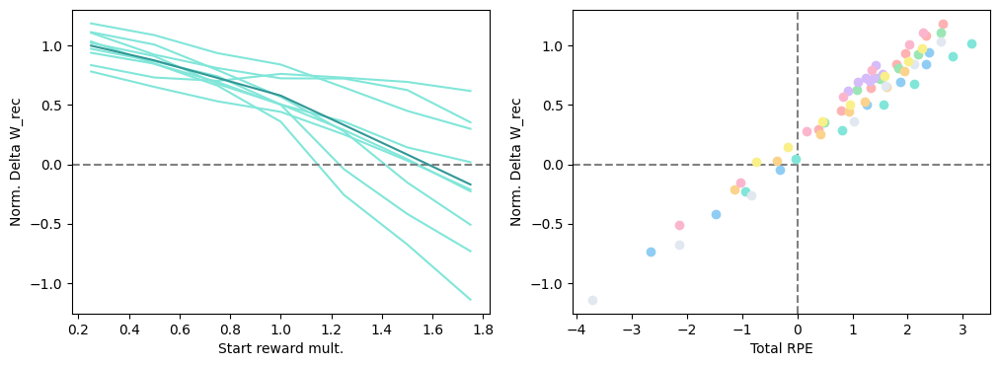

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

mean_delta_W_recs = np.mean(delta_W_recs, axis=(2, 3))

norm_val = np.max(np.abs(np.mean(mean_delta_W_recs, axis=-1)))

for repeat_idx in range(n_repeats):
    ax1.plot(scan_vals, mean_delta_W_recs[:, repeat_idx] / norm_val, color=c_vals_l[5], zorder=-5)
    ax2.scatter(total_rpes_all[:, repeat_idx], mean_delta_W_recs[:, repeat_idx] / norm_val, color=c_vals_l[repeat_idx])

ax1.plot(scan_vals, np.mean(mean_delta_W_recs, axis=-1) / norm_val, color=c_vals[5])

for ax in (ax1, ax2):
    ax.axhline(0.0, color='grey', zorder=-5, linestyle='dashed')
    ax.set_ylabel('Norm. Delta W_rec')

ax1.set_xlabel('Start reward mult.')
ax2.set_xlabel('Total RPE')
ax.axvline(0.0, color='grey', zorder=-5, linestyle='dashed')

WMP/OMP, how BCI std affects solution time/RPEs

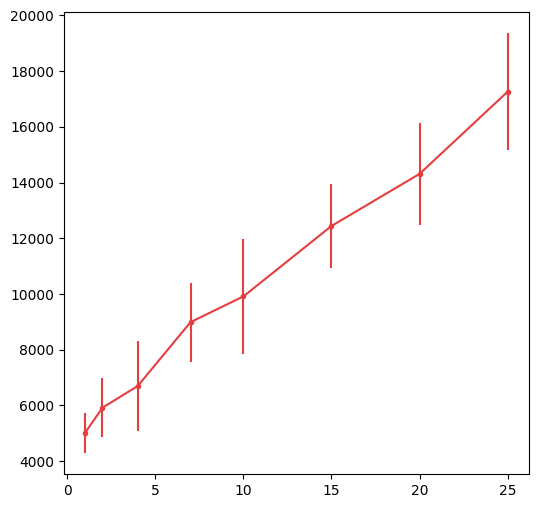

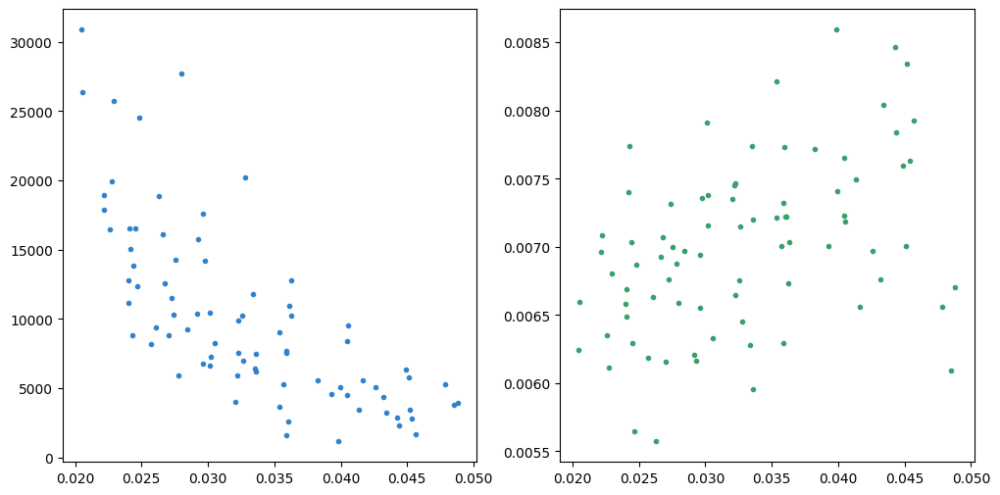

In [ ]:
fig1, ax1 = plt.subplots(1, 1, figsize=(6, 6))
ax1.errorbar(scan_vals, np.mean(sol_steps, axis=-1), np.std(sol_steps, axis=-1) / np.sqrt(sol_steps.shape[-1]), marker='.', color=c_vals[0])

mean_rpes = total_rpes / sol_steps

fig2, (ax2, ax3) = plt.subplots(1, 2, figsize=(12, 6))
for repeat_idx in range(n_repeats):
    ax2.scatter(bci_stds[:, repeat_idx], sol_steps[:, repeat_idx], color=c_vals[1], marker='.')
    ax3.scatter(bci_stds[:, repeat_idx], mean_rpes[:, repeat_idx], color=c_vals[2], marker='.')
# rel_error = sol_steps - sol_steps[0:1, :]
# ax1.errorbar(scan_vals, np.mean(rel_error, axis=-1), np.std(rel_error, axis=-1) / np.sqrt(rel_error.shape[-1]), marker='.', color=c_vals[1])

### Our BCI robust

This code is very similar to the scans code above but is only for scans related to "Our BCI" task.

In [29]:
import copy

seed = 2012

save_run = False # Save entire run
save_sessions = False # Save individual sessions
load_run = False # Overrides saving/running
load_sessions = False # Overrides saving/running
save_path_mode = 'raw_path' # '_seed{}.pkl' will always be added
save_path = '/scratch/'
save_path_mod = 'dyn_thresh_' # A simple way to distinguish tests without creating an entirely new one

scan_type = 'bci_train_speed'

### Our BCI task scans ###
# No scan, just run several training runs to analyze:
# - bci_many_repeats: gathers pairwise neuron correlation and change in weights to various inputs too
# - bci_many_repeats_ps: same as above, gathers slightly different things for PS analysis
# - bci_hebbian_index: gathers data needed to compute local Hebbian index
# - bci_train_speed: gathers data needed to compute train speed variation
# bci_learning_rule_scan: Scan over various learning rules to see how they compare on our task
## Single/double parameter scans to see how performance is affected 
# bci_lr_scan, bci_n_window_reward_scan, bci_n_window_baseline_scan, bci_n_window_elig_scan, bci_spout_rew_scan
# bci_lr_scan_W_inp, bci_lr_scan_multisession
# bci_stim_to_noise_ratio_scan
# bci_n_reward_delay_scan
# bci_start_avg_reward_mult_scan

save_path += scan_type

# 7 for bci_start_avg_reward_mult_scan
n_scan = 7 # This might be ignored for a lot of scans below which have built in n_scans, or might get changed for outer-product scans
n_repeats = 2

# Get default parameters to initialize some variables
task_params, train_params, net_params = default_toy_params(seed=seed)

if (save_run or save_sessions) and (load_run or load_sessions):
    raise ValueError('Both save and load on, turn one off.')

#############################################
########### SETUP SCAN PARAMETERS ###########
#############################################
    
output_vars = ['reward', 'session_summary']
if scan_type in ('bci_many_repeats', 'bci_many_repeats_ps', 'bci_hebbian_index', 'bci_train_speed',):
    scan_vals = (None,)
    n_scan = 1
    n_sessions = 1
    task_hists_all = [] # Used to make some plots as a function of trial
    output_vars.extend(['output', 'output_fl',])
    if scan_type in ('bci_many_repeats',):
        pairwise_corrs = np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons'],)) # See if corr with CN predicts changes
        output_vars.append('W_rec_vals')
        assert task_params['photostim'] == None # Assumes no PS
        assert task_params['state_mode'] == 'mix_spout_loc_1d'
        delta_W_inputs_all = np.zeros((n_scan, n_repeats, task_params['n_neurons'], 4)) # 4 is assumed number of distinct inputs
    elif scan_type in ('bci_many_repeats_ps',):
        assert task_params['photostim'] == 'every_session'
        output_vars.extend(('W_rec_vals',))
        
        task_pss_all = []
        ps_inits_all = []
        ps_finals_all = []
        W_inits_all = np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
        W_finals_all = np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
        
        pairwise_corr_inits_all = np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
        pairwise_corr_finals_all = np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))  
    elif scan_type in ('bci_hebbian_index',):
        n_max_divisions = 50 
        output_vars.extend(['loss_steps', 'total_rpes', 'W_rec_vals', 'W_rec_elg_vals',])
        hi_params = {
            'div_mode': 'trials', # idxs, trials
                'n_trials_per_div': 5, # Number of trials per division bin, used when div_mode = trials
                'n_divisions': 20, # Number of equal time bins the session should be divided into, used when div_mode = idxs
            'elig_types': ('true', 'hebb', 'dpost_pre', 'post_dpre', 'dpost_dpre', 'dpost_pre_acc',),
            'rpe_types': ('true', 'hits', 'hits_rpe', 'speed', 'speed_rpe', 'hits_steps', 'hits_rpe_steps', 'spout_steps', 'spout_rpe_steps',),
        }
        n_elig_types = len(hi_params['elig_types'])
        assert task_params['photostim'] == None # Assumes no PS
        rpes_divs_all = []
        div_slopes_all =  np.nan * np.ones((n_scan, n_repeats, n_elig_types, n_max_divisions,))
        div_slopes_full_delta_all =  np.nan * np.ones((n_scan, n_repeats, n_elig_types, n_max_divisions,))
    elif scan_type in ('bci_train_speed',):
        output_vars.extend(['total_rpes', 'test_tunings', 'test_tuning_stds',])
        ts_metrics = ('pre_start', 'post_start_nopre', 'pre_reward', 'trial', 'post_reward',)       
        
        thresholds_all = np.zeros((n_scan, n_repeats,))
        thresholds_upper_all = np.zeros((n_scan, n_repeats,))
        
        ts_metrics_means_all = {key: np.zeros((n_scan, n_repeats, task_params['n_neurons'],)) for key in ts_metrics}
        ts_metrics_stds_all = {key: np.zeros((n_scan, n_repeats, task_params['n_neurons'],)) for key in ts_metrics}
elif scan_type in ('bci_learning_rule_scan',):
    scan_vals_1 = ('3factor', '3factor_vanilla_hebbian',) # '3factor_two_devs',)
    if n_scan == 1: # No scan over LR
        scan_vals_2 = np.array((train_params['eta']))
    else:
        scan_vals_2 = np.logspace(-1, 1, n_scan) # Scan over LRs, default is 1e0
    scan_vals = np.array(np.meshgrid(scan_vals_1, scan_vals_2)).T.reshape(-1, 2)
    n_scan = scan_vals.shape[0]
    assert task_params['photostim'] == None # Assumes no PS
    n_sessions = 1
elif scan_type in ('bci_lr_scan', 'bci_lr_scan_multisession', 'bci_n_window_reward_scan', 'bci_n_window_baseline_scan',
                   'bci_n_window_elig_scan', 'bci_spout_rew_scan', ): 
    n_sessions = 1
    assert task_params['photostim'] == None # Assumes no PS
    assert task_params['threshold_change_type'] == 'fixed'
    assert train_params['adjust_type'] == '3factor'
    if scan_type in ('bci_lr_scan',):
        scan_vals = np.logspace(-1, 1, n_scan) # 1e0 is current default
        
        # scan_vals = np.logspace(0, 2, n_scan) # For two_devs, benefits from slightly higher
        # scan_vals = np.logspace(-3, -1, n_scan) # For SL-like, benefits from lower
    elif scan_type in ('bci_lr_scan_W_inp',):
        scan_vals = np.logspace(np.log10(3), np.log10(300), n_scan)
    elif scan_type in ('bci_n_window_reward_scan',): # 300 * 20 is current default
        scan_vals = np.logspace(np.log10(10), np.log10(600 * 20), n_scan)
    elif scan_type in ('bci_n_window_baseline_scan',): # current default: 10 * 20
        scan_vals = np.logspace(np.log10(5), np.log10(120 * 20), n_scan)
    elif scan_type in ('bci_n_window_elig_scan',): # current default: 2 * 20
        scan_vals = np.logspace(np.log10(1), np.log10(60 * 20), n_scan)
    elif scan_type in ('bci_spout_rew_scan',): 
        scan_vals = (0, 1,) # With spout movement, no spout movement
        n_scan = 2
    elif scan_type in ('bci_lr_scan_multisession',):
        scan_vals = np.logspace(-1, 1, n_scan) # stim/noise = 0.2
        n_sessions = 8
        
    task_hists_all = [[] for _ in range(n_scan)]  # Load task hist too to get better training metrics
elif scan_type in ('bci_stim_to_noise_ratio_scan',): # current default: 0.25
    scan_vals = np.logspace(np.log10(0.1), np.log10(10.0), n_scan)
    n_sessions = 1
elif scan_type in ('bci_n_reward_delay_scan',): # current default: 0
    scan_vals = np.array((0, 2, 5, 10, 15, 20, 40, 60, 100))
    n_scan = scan_vals.shape[0]
    n_sessions = 1
elif scan_type in ('bci_start_avg_reward_mult_scan',): # current default: 1.0
    scan_vals = np.linspace(0.25, 1.75, n_scan)
    output_vars.extend(['delta_W_rec', 'total_rpes',])
    total_rpes_all = np.zeros((n_scan, n_repeats,))
    delta_W_recs = np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
    n_sessions = 1
# elif scan_type in ('bci_hebbian_index',): # This just runs a lot of sessions, so nothing to scan over
#     scan_vals = np.array((np.nan,))
#     n_scan = 1
#     hi_params = {
#         'div_mode': 'trials', # idxs, trials
#             'n_trials_per_div': 5, # Number of trials per division bin, used when div_mode = trials
#             'n_divisions': 20, # Number of equal time bins the session should be divided into, used when div_mode = idxs
#         'elig_types': ('true', 'hebb', 'dpost_pre', 'post_dpre', 'dpost_dpre', 'dpost_pre_acc',),
#         'rpe_types': ('true', 'hits', 'hits_rpe', 'speed', 'speed_rpe',),
#     }
#     total_rpes_all = []
#     delta_W_recs = np.zeros((n_scan, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
#     n_sessions = task_params['n_sessions']
#     raise NotImplementedError('See if this fits into our current framework.')
else:
    raise ValueError('This shouldnt happen!')

print('Scanning over:', scan_vals)

if scan_type in ('bci_lr_scan_multisession',): # Multisession scans
    session_summaries = [[[] for _ in range(n_repeats)] for _ in range(n_scan)]
    start_avg_rewards = np.zeros((n_scan, n_repeats, n_sessions))
else: # Single session scans
    assert n_sessions == 1
    session_summaries = [[] for _ in range(n_scan)]
    start_avg_rewards = np.zeros((n_scan, n_repeats,))

if save_run or save_sessions:
    # Minimal outputs for saving correctly
    print('Extending output_vars for the purpose of saving...')
    save_output_vars = ['output', 'reward', 'loss_steps', 'bci_activity', 'total_rpes',
                        'delta_W_inp', 'delta_W_rec',]
    output_vars.extend(save_output_vars)
    output_vars = list(set(output_vars)) # eliminate redundant entries

cn_idxs = np.zeros((n_scan, n_repeats, n_sessions), dtype=np.int32)

for scan_idx, scan_val in enumerate(scan_vals):

    print(5*'-' + f' Scan idx {scan_idx} ' + 5*'-')

    for repeat_idx in range(n_repeats):

        repeat_seed = seed + repeat_idx

        print(2*'-' + f' Repeat idx {repeat_idx} ' + 2*'-')

        task_params, train_params, net_params = default_toy_params(seed=repeat_seed)
        assert task_params['task_type'] == 'our_bci' # Assumed that this is our bci task
        train = True # Default is to train
        
        #################################################################
        ### Adjustment of parameters from default for each scan index ###
        #################################################################
        task_params['n_sessions'] = n_sessions
        task_params['track_raw_states'] = False # This can be kind of large, so don't gather for now 
        if scan_type in ('bci_many_repeats', 'bci_many_repeats_ps', 'bci_train_speed',):
            None # Do nothing
        elif scan_type in ('bci_hebbian_index',):
             task_params['track_raw_states'] = True # Need this to compute certain types of reward functions
        elif scan_type in ('bci_learning_rule_scan',):
            train_params['adjust_type'] = scan_val[0]
            train_params['eta'] = float(scan_val[1])
        elif scan_type in ('bci_lr_scan', 'bci_lr_scan_multisession', 'bci_lr_scan_W_inp',):
            # Note n_sessions is set above
            train_params['eta'] = scan_val
        elif scan_type in ('bci_stim_to_noise_ratio_scan',):
            task_params['stim_to_noise_ratio'] = scan_val
        elif scan_type in ('bci_n_window_reward_scan',):
            train_params['n_window_reward'] = scan_val
        elif scan_type in ('bci_n_window_baseline_scan',):
            train_params['n_window_baseline'] = scan_val
        elif scan_type in ('bci_n_window_elig_scan',):
            train_params['n_window_elig'] = scan_val
        elif scan_type in ('bci_spout_rew_scan',):
            if scan_val == 0: # Spout movement reward
                task_params['reward_mode'] = 'water_and_spout'
            elif scan_val == 1: # No spout movement reward
                task_params['reward_mode'] = 'water_only'
        elif scan_type in ('bci_n_reward_delay_scan',):
            task_params['n_reward_delay'] = scan_val
        elif scan_type in ('bci_start_avg_reward_mult_scan',):
            task_params['start_avg_reward_mult'] = scan_val
        else:
            raise ValueError('This shouldnt happen')
        
        ########################################################
        ### Run or load the network (could be many sessions) ###
        ########################################################
        
        params = task_params, train_params, net_params
        
        local_path = None
        if load_run or load_sessions or save_run or save_sessions: # Only generate unique path if needed
            local_path = save_path + '{}/'.format(scan_type) # save_path includes specifics about test
            if save_path_mod is not None:
                local_path += save_path_mod
            local_path += build_scan_val_string(scan_val)
        
        if not load_run and not load_sessions: # Standard run           
            params, train_outputs_all, net, task, task_ps = train_task(
                params, output_vars=output_vars, save_sessions=save_sessions,
                save_path=local_path, train=train, verbose=False
            )
        elif load_run: # Just loads the data instead of training in this setting
            assert not load_sessions
            params, train_outputs_all, net, task, task_ps = net_helpers.load_run(local_path, repeat_seed)
        elif load_sessions: # Need to iterate through the sessions and load/save data for each session
            for session_idx in range(n_sessions):
                params, train_outputs, net, task, task_ps = net_helpers.load_session(
                    session_idx, local_path, repeat_seed
                )

                if scan_type in ('bci_lr_scan_multisession',):
                    session_summaries[scan_idx][repeat_idx].append(train_outputs['session_summary'])
                    start_avg_rewards[scan_idx, repeat_idx, session_idx] = train_outputs['start_avg_reward']

            continue # No need to run data collection below now

        # No metrics are collected in save_sessions because train_ouputs_all has been
        # mostly wiped.
        if save_sessions:
            continue

        ######################################################################
        #### Collection of various metrics for the given training session ####
        ### Note anything not tracked here will be overriden by next iter. ###
        ######################################################################

        task_params, train_params, net_params = params

        for session_idx in range(task_params['n_sessions']):
            print(' Total reward: {:.1f}'.format(np.sum(train_outputs_all[session_idx]['reward'][task_params['n_steps_stabilize']:])))
            if train_outputs_all[session_idx]['cn_idxs'] is not None:
                if len(train_outputs_all[session_idx]['cn_idxs']) == 1:
                    cn_idxs[scan_idx, repeat_idx, session_idx] = train_outputs_all[session_idx]['cn_idxs'][0]

        session_idx = 0
        session_summaries[scan_idx].append(train_outputs_all[session_idx]['session_summary'])
        start_avg_rewards[scan_idx, repeat_idx] = train_outputs_all[session_idx]['start_avg_reward']
        
        if scan_type in ('bci_many_repeats', 'bci_many_repeats_ps', 'bci_hebbian_index', 'bci_train_speed',):
            task_hists_all.append(task.hist)
            if scan_type in ('bci_many_repeats',):
                pairwise_corrs[scan_idx, repeat_idx] = np.corrcoef(train_outputs_all[session_idx]['output_fl'][:task_params['n_steps_stabilize']].T)

                possible_inputs = np.concatenate((np.ones((1, net_params['n_inp'])), task.stim_input), axis=0)
                possible_inputs = possible_inputs / np.linalg.norm(possible_inputs, axis=-1, keepdims=True) # Unit norm

                # Multiply through input layer to find effect on hidden
                assert net_params['W_inp_adjust'] == False
                possible_inputs = np.matmul(net.W_inp, possible_inputs.T).T 

                W_vals = train_outputs_all[session_idx]['W_rec_vals']
                delta_W = W_vals[-1] - W_vals[0]
                # Weight changes by how much input they get
                delta_W_inputs_all[scan_idx, repeat_idx] = np.matmul(delta_W, possible_inputs.T) # (n_neurons, n_inputs)
                
                del possible_inputs
                del W_vals
                del delta_W
            elif scan_type in ('bci_many_repeats_ps',):
                
                task_pss_all.append(task_ps)
                ps_inits_all.append(train_outputs_all[session_idx]['train_outputs_ps_init'])
                ps_finals_all.append(train_outputs_all[session_idx]['train_outputs_ps'])
                W_inits_all[scan_idx, repeat_idx] = train_outputs_all[session_idx]['W_rec_vals'][0]
                W_finals_all[scan_idx, repeat_idx] = train_outputs_all[session_idx]['W_rec_vals'][-1]
                
                
                # Initial and start correlation are computed just as first and second half of training for now
                if 'run_test_idxs' in task_params:
                    assert len(task_params['run_test_idxs']) == 2
                    # activity_init = train_outputs_all[session_idx]['train_outputs_test_0']['output']
                    # activity_final = train_outputs_all[session_idx]['train_outputs_test_1']['output']
                    activity_init = fftconvolve(
                        train_outputs_all[session_idx]['train_outputs_test_0']['output'], task_params['fl_kernel'][:, np.newaxis], axes=(0,), mode='valid'
                    )
                    activity_final = fftconvolve(
                        train_outputs_all[session_idx]['train_outputs_test_1']['output'], task_params['fl_kernel'][:, np.newaxis], axes=(0,), mode='valid'
                    )
                else:
                    n_training_steps = task_params['n_steps'] - task_params['n_steps_stabilize']
                    activity = train_outputs_all[session_idx]['output_fl']
                    activity_init = activity[task_params['n_steps_stabilize']:task_params['n_steps_stabilize']+int(n_training_steps/2)]
                    activity_final = activity[task_params['n_steps_stabilize']+int(n_training_steps/2):]
                    del activity

                pairwise_corr_inits_all[scan_idx, repeat_idx] = np.corrcoef(activity_init.T)
                pairwise_corr_finals_all[scan_idx, repeat_idx] = np.corrcoef(activity_final.T)
                
                del activity_init
                del activity_final
            elif scan_type in ('bci_hebbian_index',):
                rpes_divs, div_slopes, div_slopes_full_delta, _, _, _ = compute_local_hebbian_indexes(
                    train_outputs_all[session_idx], task.hists[session_idx], params, hi_params,
                )
                rpes_divs_all.append(rpes_divs)
                n_divisions = div_slopes.shape[-1]
                div_slopes_all[scan_idx, repeat_idx, :, :n_divisions] = div_slopes
                div_slopes_full_delta_all[scan_idx, repeat_idx, :, :n_divisions] = div_slopes_full_delta
            elif scan_type in ('bci_train_speed',):
                ts_metrics = ('pre_start', 'post_start_nopre', 'pre_reward', 'trial', 'post_reward',)       
                
                thresholds_all[scan_idx, repeat_idx] = task.threshold
                thresholds_upper_all[scan_idx, repeat_idx] = task.threshold_upper
                
                for ts_metric in ts_metrics:
                    ts_metrics_means_all[ts_metric][scan_idx, repeat_idx] = train_outputs_all[session_idx]['test_tunings'][ts_metric]
                    ts_metrics_stds_all[ts_metric][scan_idx, repeat_idx] = np.nanmean( # Mean over trials
                        train_outputs_all[session_idx]['test_tuning_stds'][ts_metric], axis=-1
                    )
        elif scan_type in ('bci_learning_rule_scan',):  
            None # Everything already collected in session summaries
        elif scan_type in ('bci_start_avg_reward_mult_scan', 'bci_hebbian_index',):
            total_rpes_all[scan_idx, repeat_idx] = np.sum(train_outputs_all[session_idx]['total_rpes'])
            delta_W_recs[scan_idx, repeat_idx] = train_outputs_all[session_idx]['delta_W_rec']            
        elif scan_type in ('bci_lr_scan', 'bci_lr_scan_multisession', 'bci_n_window_reward_scan', 'bci_n_window_baseline_scan',
                           'bci_n_window_elig_scan', 'bci_spout_rew_scan', ): 
            task_hists_all[scan_idx].append(task.hists[session_idx])
            
        if save_run and not load_run: # Save network
            # Seed taken are of automatically via task_params
            net_helpers.save_run(params, train_outputs_all, net, task, task_ps, local_path, path_mode=save_path_mode, overwrite=False, verbose=False)

print('Done!')

Scanning over: (None,)
----- Scan idx 0 -----
-- Repeat idx 0 --
Running test session to compute tuning...
 TUNING COMPUTATION: Skipping task_sync on state_mode for now.
 TUNING COMPUTATION: Skipping task_sync on stim_to_noise_ratio for now.
 New CN idx 23 (chosen from 0.70 percentile, actual activity percentile: 0.87)
 (tuning: chosen from 0.25 percentile, actual 0.03. Estimated tuning: -5.7e-03)
Threshold 5.9e-02, mean BCI activity 5.1e-02, dist 7.3e-03
Running test network/task to compute starting reward...
 Setting avg_reward to test average: 0.0020 (mult: 1.00)
 Total reward: 54.5
-- Repeat idx 1 --
Running test session to compute tuning...
 TUNING COMPUTATION: Skipping task_sync on state_mode for now.
 TUNING COMPUTATION: Skipping task_sync on stim_to_noise_ratio for now.
 New CN idx 101 (chosen from 0.70 percentile, actual activity percentile: 0.88)
 (tuning: chosen from 0.25 percentile, actual 0.16. Estimated tuning: -2.5e-03)
Threshold 6.3e-02, mean BCI activity 5.4e-02, dist 

#### Our BCI scan analysis

Trial_starts len: 72, trial_outcomes len: 71, padding!


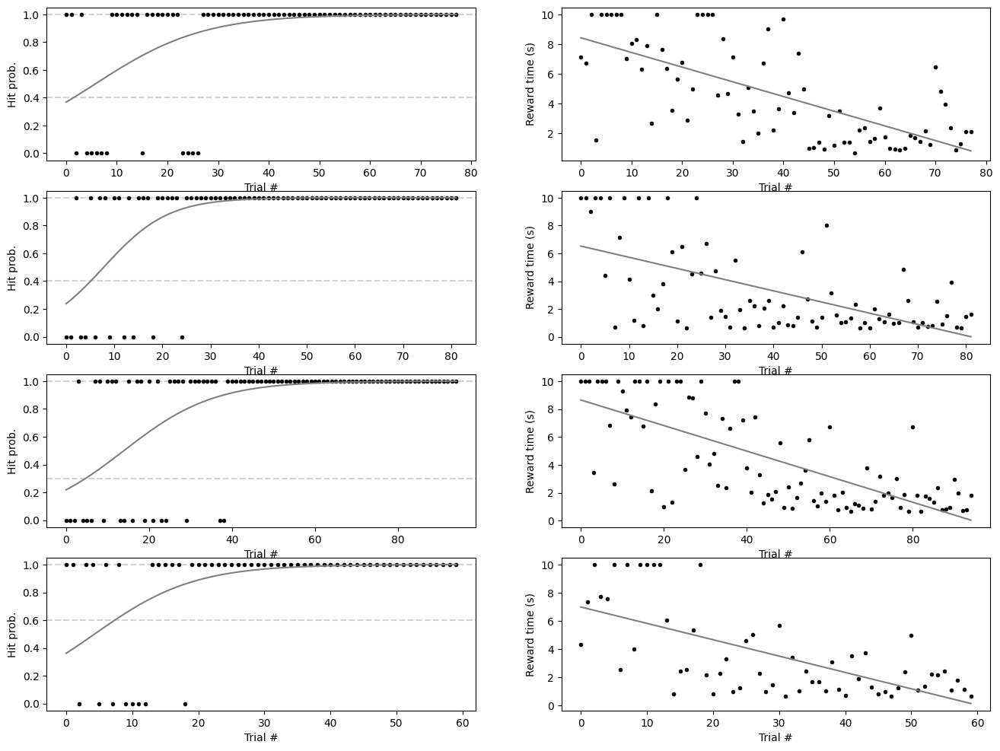

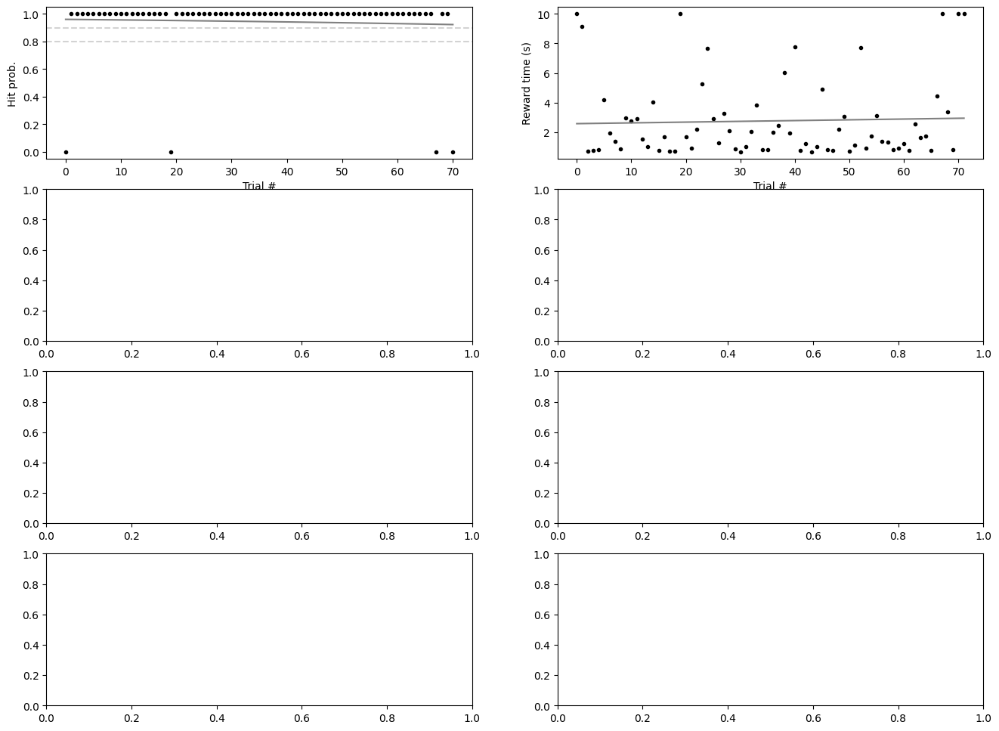

In [88]:
# Quantify changes in preformance from fits
from sklearn.linear_model import LogisticRegression

N_INITIAL_TRIAL = 2

# HIT RATE COMPUTATION #
start_hit = []
end_hit = []
hit_diff = []
initial_hit_diff = [] # Approximation of change from first two trials of fit
fraction_hit_diff = [] # Fraction of possible change
later_hit_diff = [] # Change in hit rate over only trials after N_INITIAL_TRIAL

# TRIAL LENGTH COMPUTATION #
trial_length_start = []
trial_length_end = []
trial_length_diff = []
initial_trial_length_diff = [] # Approximation of change from first two trials of fit 
fraction_tl_diff = [] # Fraction of possible change
later_tl_diff = [] # Change in hit rate over only trials after N_INITIAL_TRIAL

# Trial length difference
dt_si = 0.05 # These really don't differ enough for it to matter

ax_it = 4

for repeat_idx in range(n_repeats):
    
    task_hist = task_hists_all[repeat_idx]
    
    if ax_it == 4: # New figure
        fig, axs = plt.subplots(4, 2, figsize=(16, 12))
        ax_it = 0
    
    ax1, ax2 = axs[ax_it]
    ax_it += 1
    
    ### HIT RATE ###
    n_trials = len(task_hist['trial_outcomes'])
    
    trials = np.arange(n_trials)[:, None]
    hits = task_hist['trial_outcomes']

    if np.all(hits): # All hits, no fit no difference
        print('All hits, skipping fits')
        start_hit.append(1.0)
        end_hit.append(1.0)
        hit_diff.append(np.nan)
        initial_hit_diff.append(np.nan)
        fraction_hit_diff.append(np.nan)
        later_hit_diff.append(np.nan)
    else:

        fit = LogisticRegression(penalty=None).fit(trials, hits)

        probs = fit.predict_proba(trials)[:, -1]

        hit_diff.append(probs[-1] - probs[0])
        start_hit.append(probs[0])
        end_hit.append(probs[-1])
        if 1.0 - probs[0] < 0.1: # Too small of possible improvment
            fraction_hit_diff_val = np.nan 
        else:
            fraction_hit_diff_val = (probs[-1] - probs[0]) / (1.0 - probs[0]) 
        fraction_hit_diff.append(fraction_hit_diff_val)

        ax1.plot(trials, probs, color='grey')

        initial_hit_diff.append(probs[N_INITIAL_TRIAL-1] - probs[0])

        # Later performance fit
        if np.all(hits[N_INITIAL_TRIAL:]):
            print('All hits: skipping late trial fit')
            later_hit_diff.append(np.nan)
        else:
            fit_late = LogisticRegression(penalty=None).fit(trials[N_INITIAL_TRIAL:], hits[N_INITIAL_TRIAL:])
            probs_late = fit_late.predict_proba(trials)[:, -1]

            # ax1.plot(trials[N_INITIAL_TRIAL:], probs_late[N_INITIAL_TRIAL:], color=c_vals[2])
            later_hit_diff.append(probs_late[-1] - probs_late[N_INITIAL_TRIAL])

    ax1.scatter(trials, hits, marker='.', color='k')

    ax1.axhline(np.mean(hits[:10]), color='lightgrey', zorder=-5, linestyle='dashed')
    ax1.axhline(np.mean(hits[-10:]), color='lightgrey', zorder=-5, linestyle='dashed')

    ax1.set_xlabel('Trial #')
    ax1.set_ylabel('Hit prob.')
    
    ### REWARD TIME ###
    
    trial_start_idxs = np.array(task_hist['trial_starts'])
    rew_idxs = np.array(bci_analysis.pad_rew_idxs(task_hist))
    
    reward_times_session = (rew_idxs - trial_start_idxs) * dt_si # Convert to seconds
    reward_times_session = np.where(np.isnan(reward_times_session), 10.0, reward_times_session) # Sets misses to 10.0

    trials = np.arange(rew_idxs.shape[0])
    reward_times = reward_times_session
    
    slope, intercept, _, _, _ = linregress(trials, reward_times)

    reward_times_fit = trials * slope + intercept

    trial_length_start.append(reward_times_fit[0])
    trial_length_end.append(reward_times_fit[-1])
    trial_length_diff.append(reward_times_fit[-1] - reward_times_fit[0])
    fraction_tl_diff.append((reward_times_fit[-1] - reward_times_fit[0])/(4. - reward_times_fit[0]))

    ax2.scatter(trials, reward_times, marker='.', color='k')
    ax2.plot(trials, reward_times_fit, color='grey')

    if N_INITIAL_TRIAL > 1:
        slope, intercept, _, _, _ = linregress(trials[:N_INITIAL_TRIAL], reward_times[:N_INITIAL_TRIAL])
        reward_times_fit = trials * slope + intercept
        initial_trial_length_diff.append(reward_times_fit[N_INITIAL_TRIAL-1] - reward_times_fit[0])

        # ax2.plot(trials[:N_INITIAL_TRIAL], reward_times_fit[:N_INITIAL_TRIAL], color=c_vals[2])
    else:
        initial_trial_length_diff.append(np.nan)

     # Later performance fit
    slope_late, intercept_late, _, _, _ = linregress(trials[N_INITIAL_TRIAL:], reward_times[N_INITIAL_TRIAL:])
    reward_times_fit_late = trials * slope_late + intercept_late

    # ax2.plot(trials[N_INITIAL_TRIAL:], reward_times_fit[N_INITIAL_TRIAL:], color=c_vals[2])
    later_tl_diff.append(reward_times_fit[-1] - reward_times_fit[N_INITIAL_TRIAL])

    ax2.set_xlabel('Trial #')
    ax2.set_ylabel('Reward time (s)')

hit_diff = np.array(hit_diff)

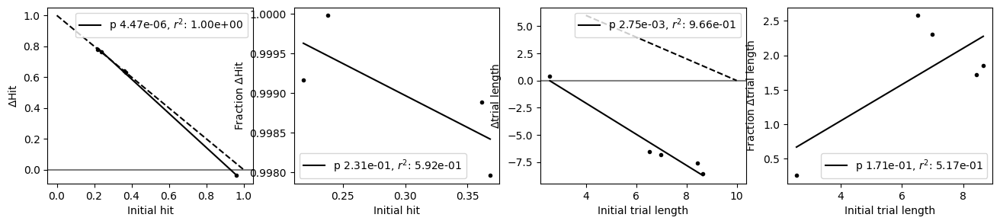

In [90]:
c_vals_p['trial'] = 'k'

fig, ax1s = plt.subplots(1, 4, figsize=(16, 3))

ax1s[0].scatter(start_hit, hit_diff, marker='.', color='k')
add_regression_line(start_hit, hit_diff, ax=ax1s[0], color='k')

ax1s[0].plot((0.0, 1.0), (1.0, 0.0), color='k', linestyle='dashed')
ax1s[0].axhline(0.0, color='grey', zorder=-5)

ax1s[0].set_xlabel('Initial hit')
ax1s[0].set_ylabel('$\Delta$Hit')
ax1s[0].legend()

# ax1s[1].scatter(start_hit, initial_hit_diff, marker='.', color='k')
# add_regression_line(start_hit, initial_hit_diff, ax=ax1s[1], color='k')
ax1s[1].scatter(start_hit, fraction_hit_diff, marker='.', color='k')
add_regression_line(start_hit, fraction_hit_diff, ax=ax1s[1], color='k')

ax1s[1].set_xlabel('Initial hit')
# ax1s[1].set_ylabel('Initial $\Delta$Hit')
ax1s[1].set_ylabel('Fraction $\Delta$Hit')
ax1s[1].legend()

ax1s[2].scatter(trial_length_start, trial_length_diff, marker='.', color='k')
add_regression_line(trial_length_start, trial_length_diff, ax=ax1s[2], color='k')

ax1s[2].plot((4.0, 10), (6.0, 0.0), linestyle='dashed', color='k')
ax1s[2].axhline(0.0, color='grey', zorder=-5)

ax1s[2].set_xlabel('Initial trial length')
ax1s[2].set_ylabel('$\Delta$trial length')
ax1s[2].legend()

# ax1s[3].scatter(trial_length_start, initial_trial_length_diff, marker='.', color='k')
# add_regression_line(trial_length_start, initial_trial_length_diff, ax=ax1s[3], color='k')
ax1s[3].scatter(trial_length_start, fraction_tl_diff, marker='.', color='k')
add_regression_line(trial_length_start, fraction_tl_diff, ax=ax1s[3], color='k')

ax1s[3].set_xlabel('Initial trial length')
# ax1s[3].set_ylabel('Initial $\Delta$trial length')
ax1s[3].set_ylabel('Fraction $\Delta$trial length')
ax1s[3].legend()

In [ ]:
# Can we even predict performance changes from same session activity?
scan_idx = 0
n_bootstrap = 100 # 1st BS index is always true CNs

elim_outliers = True
OUTLIER_THRESH = 3

fig, (ax1s, ax2s) = plt.subplots(2, 5, figsize=(24, 9))
fig, (ax3s, ax4s) = plt.subplots(2, 5, figsize=(24, 9)) # Bootstrap plots

out_str_1 = ''
out_str_2 = ''
out_str_3 = ''
out_str_4 = ''

ts_metric_names = ('Pre', 'Early', 'Late', 'Trial', 'Reward',)

for ts_metric, ts_metric_name, ax1, ax2, ax3, ax4 in zip(ts_metrics, ts_metric_names, ax1s, ax2s, ax3s, ax4s):
    ts_metric_changes = np.zeros((n_sessions,))
    
    # if ts_metric_name == 'Pre':
    #     continue
    
    baseline_1 = None
    baseline_2 = None
    baseline_1 = np.array(start_hit)
    # baseline_1 = np.array([day_2_ts_metrics_changes[session_idx][ts_metric]['intercept'][day_2_cn_idxs[session_idx]] for session_idx in range(n_sessions)])
    baseline_2 = np.array(trial_length_start)
    
    y_val_1_slopes_bs = np.zeros((n_bootstrap,))
    y_val_2_slopes_bs = np.zeros((n_bootstrap,))
    
    for bs_idx in range(n_bootstrap): # If no bootstrapping, just run this through once
    
        for repeat_idx in range(n_repeats):
            if bs_idx == 0:
                neuron_idx = cn_idxs[scan_idx, repeat_idx, 0]
            else:
                n_neurons = net_params['n_neurons']
                neuron_idx = np.random.randint(n_neurons)
            
            with warnings.catch_warnings(): # Suppress mean of empty slice warnings, since they just return nans as expected
                warnings.simplefilter('ignore', category=RuntimeWarning)
                ### Day 2, using CN_2 ###
                # ts_metric_label = '\n CN_1 change fit slope'
                # ts_metric_changes[session_idx] = day_2_ts_metrics_changes[session_idx][ts_metric]['slope'][neuron_idx]
                # ts_metric_label = '\n change fit intercept (trial 0 value)'
                # ts_metric_changes[session_idx] = day_2_ts_metrics_changes[session_idx][ts_metric]['intercept'][neuron_idx]
                # ts_metric_label = '\n change fit intercept - threshold'
                # ts_metric_changes[session_idx] = (day_2_ts_metrics_changes[session_idx][ts_metric]['intercept'][neuron_idx]
                #                                   - thresholds_all[scan_idx, repeat_idx])
                # ts_metric_label = '\n (change fit intercept - threshold) / std'
                # ts_metric_changes[session_idx] = (day_2_ts_metrics_changes[session_idx][ts_metric]['intercept'][neuron_idx]
                #                                   - thresholds_all[scan_idx, repeat_idx]) / np.nanmean(day_2_ts_metrics_changes[session_idx][ts_metric+'_stds'], axis=-1)[neuron_idx]
                # ts_metric_label = '\n average tuning'
                # ts_metric_changes[session_idx] = day_2_ts_metrics[ts_metric][session_idx][neuron_idx]
                # ts_metric_label = '\n std during epoch (avg over trials)'
                # ts_metric_changes[session_idx] = np.nanmean(day_2_ts_metrics_changes[session_idx][ts_metric+'_stds'], axis=-1)[neuron_idx]
                # ts_metric_label = '\n initial std during epoch'
                # ts_metric_changes[session_idx] = np.nanmean(day_2_ts_metrics_changes[session_idx][ts_metric+'_stds'][:, :10], axis=-1)[neuron_idx]
                # ts_metric_label = '\n mean/std during epoch (avg over trials)'
                # ts_metric_changes[session_idx] = (day_2_ts_metrics[ts_metric][session_idx] /
                #                                   np.nanmean(day_2_ts_metrics_changes[session_idx][ts_metric+'_stds'], axis=-1))[neuron_idx]
                # ts_metric_label = '\n (tuning - threshold)/std during (Day 2)'
                # ts_metric_changes[session_idx] = ((day_2_ts_metrics[ts_metric][session_idx][neuron_idx] - thresholds_all[scan_idx, repeat_idx]) /
                #                                    np.nanmean(day_2_ts_metrics_changes[session_idx][ts_metric+'_stds'], axis=-1)[neuron_idx])
                
                ### Day 2, initial metrics ###
                # ts_metric_label = '\n Initial tuning (Day 2)'
                # ts_metric_changes[session_idx] = np.nanmean(day_2_ts_metrics_changes[session_idx][ts_metric+'_trials'][:, :N_INITIAL_TRIAL], axis=-1)[neuron_idx]
                # ts_metric_label = '\n Initial tuning - threshold (Day 2)'
                # ts_metric_changes[session_idx] = (np.nanmean(day_2_ts_metrics_changes[session_idx][ts_metric+'_trials'][:, :N_INITIAL_TRIAL], axis=-1)[neuron_idx]
                #                                   - thresholds_all[scan_idx, repeat_idx])
                # ts_metric_label = '\n (Initial tuning - threshold)/initial std (Day 2)'
                # ts_metric_changes[session_idx] = (np.nanmean(day_2_ts_metrics_changes[session_idx][ts_metric+'_trials'][:, :N_INITIAL_TRIAL], axis=-1)[neuron_idx]
                #                                   - thresholds_all[scan_idx, repeat_idx]) / np.nanmean(day_2_ts_metrics_changes[session_idx][ts_metric+'_stds'][:, :N_INITIAL_TRIAL], axis=-1)[neuron_idx]

                ### Day 1, using CN_2 ###
                # ts_metric_label = '\n change fit slope'
                # ts_metric_changes[session_idx] = day_1_ts_metrics_changes[session_idx][ts_metric]['slope'][neuron_idx]
                # ts_metric_label = '\n change fit intercept (trial 0 value)'
                # ts_metric_changes[session_idx] = day_1_ts_metrics_changes[session_idx][ts_metric]['intercept'][neuron_idx]
                # ts_metric_label = '\n (change fit intercept - threshold)'
                # ts_metric_changes[session_idx] = (day_1_ts_metrics_changes[session_idx][ts_metric]['intercept'][neuron_idx]
                #                                   - thresholds_all[scan_idx, repeat_idx])
                # ts_metric_label = '\n tuning (Day 1)'
                # ts_metric_changes[session_idx] = day_1_ts_metrics[ts_metric][session_idx][neuron_idx]
                # ts_metric_label = '\n tuning - threshold (Day 1)'
                # ts_metric_changes[session_idx] = (day_1_ts_metrics[ts_metric][session_idx][neuron_idx] - thresholds_all[scan_idx, repeat_idx])
                # ts_metric_label = '\n std during epoch (avg over trials)'
                # ts_metric_changes[session_idx] = np.nanmean(day_1_ts_metrics_changes[session_idx][ts_metric+'_stds'], axis=-1)[neuron_idx]
                # ts_metric_label = '\n mean/std during epoch (avg over trials)'
                # ts_metric_changes[session_idx] = (day_1_ts_metrics[ts_metric][session_idx] /
                #                                   np.nanmean(day_1_ts_metrics_changes[session_idx][ts_metric+'_stds'], axis=-1))[neuron_idx]
                ts_metric_label = '\n (tuning - threshold)/std (Day 1)'
                ts_metric_changes[session_idx] = ((day_1_ts_metrics[ts_metric][session_idx][neuron_idx] - thresholds_all[scan_idx, repeat_idx]) /
                                                   np.nanmean(day_1_ts_metrics_changes[session_idx][ts_metric+'_stds'], axis=-1)[neuron_idx])

        y_val_1 = hit_diff
        y_label_1 = '$\Delta$Hit (Day 2)'
        # y_val_1 = start_hit
        # y_label_1 = 'Initial hit (Day 2)'
        # y_val_1 = initial_hit_diff
        # y_label_1 = 'Initial $\Delta$Hit (Day 2)'
        # y_val_1 = initial_metric_cn_change[ts_metric]
        # y_label_1 = 'Initial {} value (Day 2)'.format(ts_metric)
        # y_val_1 = later_hit_diff
        # y_label_1 = 'Later $\Delta$Hit (Day 2)'

        y_val_2 = trial_length_diff
        y_label_2 = '$\Delta$Reward Time (Day 2)'
        # y_val_2 = trial_length_start
        # y_label_2 = 'Initial reward time (Day 2)'
        # y_val_2 = initial_trial_length_diff
        # y_label_2 = 'Initial $\Delta$Reward Time (Day 2)'
        # y_val_2 = initial_metric_cn_change[ts_metric]
        # y_label_2 = 'Initial $\Delta${} (Day 2)'.format(ts_metric)
        # y_val_2 = later_tl_diff
        # y_label_2 = 'Later $\Delta$Reward Time (Day 2)'
        
        # Iterate over two possible predictor values
        for idx, (ax, y_val, y_label, baseline, y_val_slopes_bs) in enumerate(zip(
            (ax1, ax2), (y_val_1, y_val_2,), (y_label_1, y_label_2,), (baseline_1, baseline_2,),
            (y_val_1_slopes_bs, y_val_2_slopes_bs,),
        )):
            x_val = ts_metric_changes
            x_val = x_val[:, None]
            if baseline is not None:
                x_val = np.concatenate((baseline[:, None], x_val), axis=-1)

            if elim_outliers:
                x_zscores = (x_val - np.nanmean(x_val, axis=0, keepdims=True)) / np.nanstd(x_val, axis=0, keepdims=True)
                y_zscores = (y_val - np.nanmean(y_val)) / np.nanstd(y_val)

                outlier_mask = np.logical_or(np.any(np.abs(x_zscores) > OUTLIER_THRESH, axis=-1),  (np.abs(y_zscores) > OUTLIER_THRESH))
                if bs_idx == 0:
                    print(' Eliminating {} outliers.'.format(np.sum(outlier_mask)))

                x_val = np.array(x_val)[~outlier_mask, :]
                y_val = np.array(y_val)[~outlier_mask]

            if baseline is None: # Single fit
                if bs_idx == 0:
                    ax.scatter(x_val[:, -1], y_val, color=c_vals_p[ts_metric], marker='.')
                else:
                    ax = None
                slope, _, _, _, _ = add_regression_line(x_val[:, -1], y_val, ax=ax, color=c_vals_p[ts_metric])
            else:
                x_val = sm.add_constant(x_val)

                fit_model = sm.OLS(y_val[:, None], x_val, missing='drop') 
                results = fit_model.fit()

                fit_pvalue = results.pvalues[-1]
                slope = results.params[-1]
                
                if bs_idx == 0:
                    # Relative r^2 computation
                    y_pred = results.predict(x_val)

                    r_squared_full = 1 - (
                        np.nansum((y_val - y_pred)**2) / np.nansum((y_val - np.nanmean(y_val.flatten()))**2)
                    )
                    
                    y_pred_no_metric = results.params[0] + x_val[:, 1] * results.params[1] # Without new fit metric
                    # r_squared_no_metric = 1 - (
                    #     np.nansum((y_val - y_pred_no_metric)**2) / np.nansum((y_val - np.nanmean(y_val.flatten()))**2)
                    # )
                    # slope, intercept, rvalue, pvalue, se = linregress(x_val[:, 1], y_val, nan_policy='omit') # Fits with intercept automatically
                    result_no_metric= sm.OLS(y_val[:, None], x_val[:, :-1], missing='drop').fit()
                    r_squared_no_metric = result_no_metric.rsquared
                    
                    r_squared_str = 'r^2 full: {:.3f}, r^2 no metric {:.3f}, ratio: {:.2f}'.format(
                          r_squared_full, r_squared_no_metric, r_squared_full / r_squared_no_metric
                    )


                    if fit_pvalue > 0.05: p_str = ''
                    elif fit_pvalue > 0.01: p_str = '*'
                    elif fit_pvalue > 0.001: p_str = '**'
                    elif fit_pvalue > 0.0001: p_str = '***'
                    else: p_str = '****'

                    # str_val = ' {} bl : coef: {:.1e} (p: {:.1e}) {}\n'.format(ts_metric, results.params[1], results.pvalues[1], p_str)
                    str_val = ' {} : coef: {:.1e} (p: {:.1e}) {}\t{}\n'.format(ts_metric_name, results.params[-1], results.pvalues[-1], p_str, r_squared_str)
                    if idx == 0: out_str_1 +=str_val
                    else: out_str_2 +=str_val

                    y_val_bl_subtracted = y_val - y_pred_no_metric

                    ax.scatter(x_val[:, -1], y_val_bl_subtracted, color=c_vals_p[ts_metric], marker='.')
                    x_val_plot = np.sort(x_val[:, -1])
                    ax.plot(x_val_plot, results.params[-1] * x_val_plot, color=c_vals_p[ts_metric], label='p: {:.2e}'.format(fit_pvalue))
            
            y_val_slopes_bs[bs_idx] = slope
            if bs_idx == 0:
                ax.set_ylabel(y_label)
                ax.set_xlabel('{}{}'.format(ts_metric_name, ts_metric_label))
                ax.legend()
                
        # End of single bootstrap
    # After all bootstraps
    if n_bootstrap > 1:
        ax3.hist(y_val_1_slopes_bs[1:], bins=100, color=c_vals_p[ts_metric], alpha=0.3)
        ax3.axvline(y_val_1_slopes_bs[0], color=c_vals_p['cn'], label='p={:.1e}'.format(
            1 - np.sum(y_val_1_slopes_bs[0] > y_val_1_slopes_bs[1:]) / (n_bootstrap - 1)
        ))
        ax4.hist(y_val_2_slopes_bs[1:], bins=100, color=c_vals_p[ts_metric], alpha=0.3)
        ax4.axvline(y_val_2_slopes_bs[0], color=c_vals_p['cn'], label='p={:.1e}'.format(
            1 - np.sum(y_val_2_slopes_bs[0] < y_val_2_slopes_bs[1:]) / (n_bootstrap - 1)
        ))
        
        for ax in (ax3, ax4,):
            ax.axvline(0.0, color='grey', zorder=-5)
            ax.legend()
        
print(out_str_1)
print(out_str_2)

In [72]:
ts_metric_names = ('Pre', 'Early', 'Late', 'Trial', 'Reward',)
ts_metrics_all



{'pre_start': array([[[0.01274407, 0.02060438, 0.01877764, 0.02947631, 0.0151193 ,
          0.03652753, 0.0669283 , 0.04743501, 0.0474479 , 0.0200261 ,
          0.01868579, 0.03806779, 0.02705642, 0.01829692, 0.04714915,
          0.02744801, 0.01692253, 0.02904007, 0.01236191, 0.00576979,
          0.05230234, 0.01794425, 0.01329715, 0.06017845, 0.01273563,
          0.02359198, 0.01363421, 0.03089152, 0.02717874, 0.04032491,
          0.0373377 , 0.01097168, 0.02096772, 0.00962694, 0.01617049,
          0.00924414, 0.01986555, 0.00946611, 0.04093072, 0.0283457 ,
          0.01442861, 0.02263693, 0.00551287, 0.02349983, 0.06175175,
          0.04996521, 0.01196707, 0.01033119, 0.05266444, 0.04436903,
          0.04119779, 0.00804683, 0.05111958, 0.00728724, 0.03364673,
          0.02701991, 0.02674115, 0.00525524, 0.02157857, 0.09275869,
          0.01187638, 0.01681709, 0.01427068, 0.04217199, 0.02789092,
          0.01926459, 0.03542009, 0.01983875, 0.01734901, 0.11459332,
       

Trial_starts len: 72, trial_outcomes len: 71, padding!
Trial_starts len: 80, trial_outcomes len: 79, padding!
Trial_starts len: 85, trial_outcomes len: 84, padding!
Trial_starts len: 88, trial_outcomes len: 87, padding!
Trial_starts len: 86, trial_outcomes len: 85, padding!


/tmp/ipykernel_60/3377791160.py:62: RuntimeWarning: Mean of empty slice
  plot_val = np.nanmean(mean_hit_rates_all[scan_idx], axis=0)
/tmp/ipykernel_60/3377791160.py:67: RuntimeWarning: Mean of empty slice
  plot_val = np.nanmean(trial_outcomes_all[scan_idx], axis=0)
/tmp/ipykernel_60/3377791160.py:72: RuntimeWarning: Mean of empty slice
  plot_val = np.nanmean(trial_lens_all[scan_idx], axis=0)


Trial_starts len: 86, trial_outcomes len: 85, padding!
Trial_starts len: 87, trial_outcomes len: 86, padding!
Trial_starts len: 70, trial_outcomes len: 69, padding!
Trial_starts len: 83, trial_outcomes len: 82, padding!
Trial_starts len: 88, trial_outcomes len: 87, padding!
Trial_starts len: 81, trial_outcomes len: 80, padding!
Trial_starts len: 85, trial_outcomes len: 84, padding!
Trial_starts len: 85, trial_outcomes len: 84, padding!
Trial_starts len: 84, trial_outcomes len: 83, padding!
Trial_starts len: 79, trial_outcomes len: 78, padding!
Trial_starts len: 83, trial_outcomes len: 82, padding!
Trial_starts len: 84, trial_outcomes len: 83, padding!
Trial_starts len: 98, trial_outcomes len: 97, padding!
Trial_starts len: 79, trial_outcomes len: 78, padding!
Trial_starts len: 92, trial_outcomes len: 91, padding!


/tmp/ipykernel_60/3377791160.py:88: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


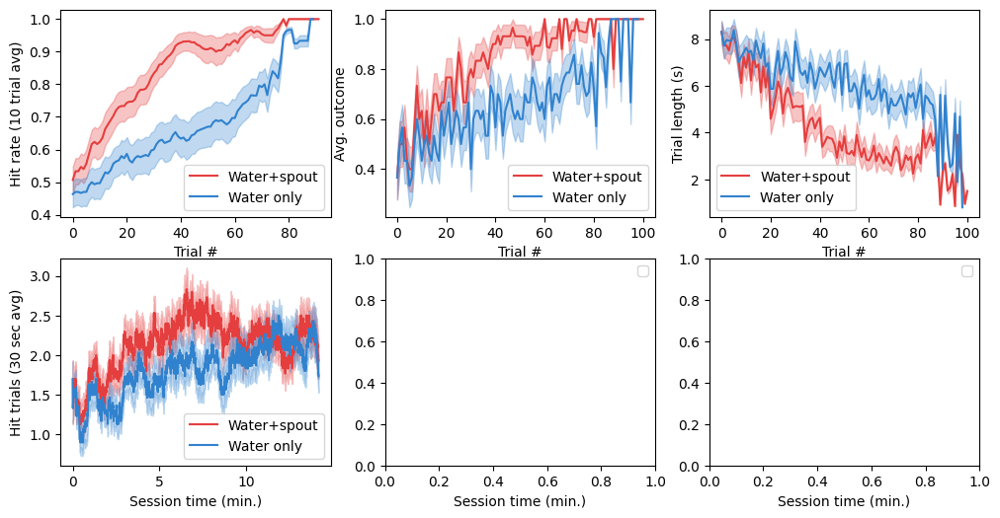

In [98]:
if scan_type in ('bci_spout_rew_scan',):

    n_trial_avg_window = 10 # trial average window
    n_step_avg_window = 30 * 20

    n_max_trials_plot = 200
    trial_avg_window = 1 / n_trial_avg_window * np.ones((n_trial_avg_window,))

    MIN_REPEATS = 20

    # Just raw values versus trial time
    trial_outcomes_all = np.nan * np.ones((n_scan, n_repeats, n_max_trials_plot)) 
    mean_hit_rates_all = np.nan * np.ones((n_scan, n_repeats, n_max_trials_plot)) # Averaged over 10 trials
    trial_lens_all = np.nan * np.ones((n_scan, n_repeats, n_max_trials_plot)) 

    n_steps_max = task_params['n_steps'] - n_step_avg_window + 1

    running_hit_rates_all = np.nan * np.ones((n_scan, n_repeats, n_steps_max))
    running_trial_lens_all = np.nan * np.ones((n_scan, n_repeats, n_steps_max)) 

    fig, ((ax1, ax2, ax3,), (ax4, ax5, ax6,),) = plt.subplots(2, 3, figsize=(12, 6))

    scan_val_labels = ('Water+spout', 'Water only',)

    for scan_idx, scan_val in enumerate(scan_vals):
        for repeat_idx in range(n_repeats):
            task_hist = task_hists_all[scan_idx][repeat_idx]

            trial_outcomes_all[scan_idx, repeat_idx, :len(task_hist['trial_outcomes'])] = task_hist['trial_outcomes']

            if len(task_hist['trial_outcomes']) < n_trial_avg_window:
                print('Not enough trials to plot.')
            else:
                mean_hit_rates = fftconvolve(task_hist['trial_outcomes'], trial_avg_window, mode='valid')

            n_trials_plot = min(mean_hit_rates.shape[0], n_max_trials_plot)
            mean_hit_rates_all[scan_idx, repeat_idx, :n_trials_plot] = mean_hit_rates[:n_trials_plot]

            ### Trial and pretrial lens ###
            start_idxs = task_hist['trial_starts']
            rew_idxs = bci_analysis.pad_rew_idxs(task_hist) # Adds nan pads to rew_idxs, should be same length as trial start idxs now

            trial_lens = np.array(rew_idxs) - np.array(start_idxs)
            trial_lens = np.where(np.isnan(trial_lens), 200, trial_lens) * 1/20 # nans become 10 seconds

            trial_lens_all[scan_idx, repeat_idx, :trial_lens.shape[0]] = trial_lens

            ### As a function of sequence index ###
            n_trials = len(task_hist['trial_outcomes'])

            ## Get all the start times of successful trials
            # Might have one more start than outcome because last trial incomplete
            trial_start_successes = np.array(task_hist['trial_starts'][:n_trials]) * np.array(task_hist['trial_outcomes'])
            trial_start_successes = trial_start_successes[trial_start_successes > 0] # Filters only successful trials

            trial_starts_hit_mask = np.array([seq_idx in trial_start_successes for seq_idx in seq_idxs]).astype(np.int32)

            running_hit_rates_all[scan_idx, repeat_idx] = signal.fftconvolve(trial_starts_hit_mask, count_window, mode='valid')

        # plot_limit = np.where(np.sum(~np.isnan(trial_outcomes_all[scan_idx]), axis=0) < MIN_REPEATS)[0][0] # Limit # of trials to minimum number of repeats

        plot_val = np.nanmean(mean_hit_rates_all[scan_idx], axis=0)
        error_val = np.nanstd(mean_hit_rates_all[scan_idx], axis=0) / np.sqrt(n_repeats)
        ax1.plot(np.arange(n_max_trials_plot), plot_val, color=c_vals[scan_idx], label=scan_val_labels[scan_idx])    
        ax1.fill_between(np.arange(n_max_trials_plot), plot_val+error_val, plot_val-error_val, color=c_vals[scan_idx], alpha=0.3, zorder=-5)    

        plot_val = np.nanmean(trial_outcomes_all[scan_idx], axis=0)
        error_val = np.nanstd(trial_outcomes_all[scan_idx], axis=0) / np.sqrt(n_repeats)
        ax2.plot(np.arange(n_max_trials_plot), plot_val, color=c_vals[scan_idx], label=scan_val_labels[scan_idx])    
        ax2.fill_between(np.arange(n_max_trials_plot), plot_val+error_val, plot_val-error_val, color=c_vals[scan_idx], alpha=0.3, zorder=-5)    

        plot_val = np.nanmean(trial_lens_all[scan_idx], axis=0)
        error_val = np.nanstd(trial_lens_all[scan_idx], axis=0) / np.sqrt(n_repeats)
        ax3.plot(np.arange(n_max_trials_plot), plot_val, color=c_vals[scan_idx], label=scan_val_labels[scan_idx])    
        ax3.fill_between(np.arange(n_max_trials_plot), plot_val+error_val, plot_val-error_val, color=c_vals[scan_idx], alpha=0.3, zorder=-5)    

        plot_val = np.nanmean(running_hit_rates_all[scan_idx, :, task_params['n_steps_stabilize']:], axis=0)
        error_val = np.nanstd(running_hit_rates_all[scan_idx, :, task_params['n_steps_stabilize']:], axis=0) / np.sqrt(n_repeats)
        ax4.plot(np.arange(n_steps_max - task_params['n_steps_stabilize']) / (20 * 60), plot_val, color=c_vals[scan_idx], label=scan_val_labels[scan_idx])    
        ax4.fill_between(np.arange(n_steps_max - task_params['n_steps_stabilize']) / (20 * 60), plot_val+error_val, plot_val-error_val, color=c_vals[scan_idx], alpha=0.3, zorder=-5)    

    for ax in (ax1, ax2, ax3):
        ax.set_xlabel('Trial #')
        ax.legend()

    for ax in (ax4, ax5, ax6):
        ax.set_xlabel('Session time (min.)')
        ax.legend()

    ax1.set_ylabel('Hit rate ({} trial avg)'.format(n_trial_avg_window))
    ax2.set_ylabel('Avg. outcome'.format(n_trial_avg_window))
    ax3.set_ylabel('Trial length (s)'.format(n_trial_avg_window))

    ax4.set_ylabel('Hit trials ({:.0f} sec avg)'.format(n_step_avg_window / 20))

Analysis of threshold-change aligned activity

Trial_starts len: 66, trial_outcomes len: 65, padding!
Trial_starts len: 87, trial_outcomes len: 86, padding!
Trial_starts len: 72, trial_outcomes len: 71, padding!


/tmp/ipykernel_56/2962472106.py:62: RuntimeWarning: Mean of empty slice
  ax1.plot(np.nanmean(trial_outcomes_all, axis=0), color='k')
/tmp/ipykernel_56/2962472106.py:65: RuntimeWarning: Mean of empty slice
  ax2.plot(np.nanmean(trial_lens_all, axis=0), color=c_vals[0])


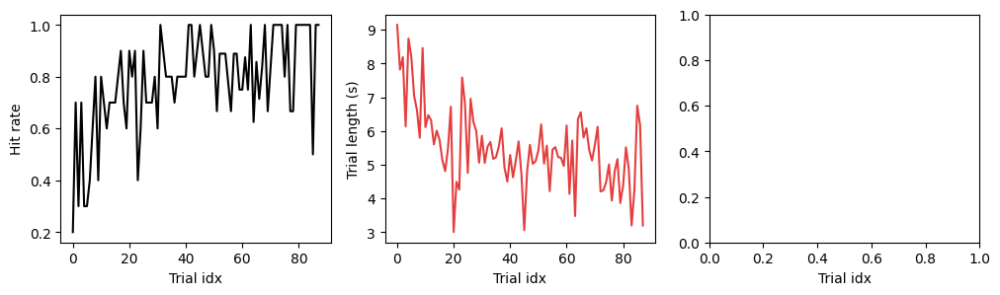

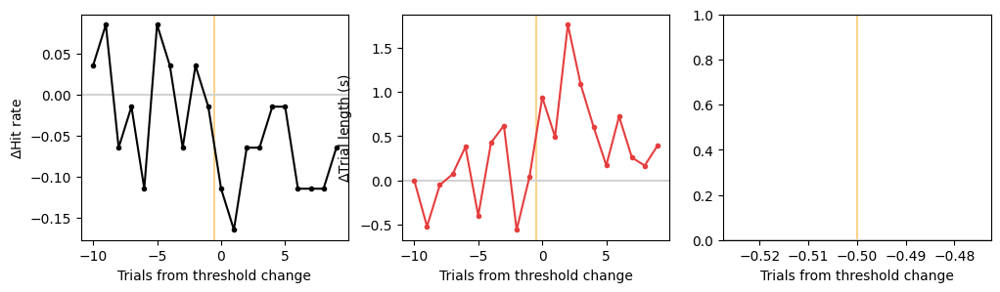

In [46]:
if scan_type in ('bci_many_repeats',) and task_params['threshold_change_type'] in ('seq_idxs',): 

    scan_idx = 0
    n_trial_avg_window = 5

    n_max_trials_plot = 200
    trial_avg_window = 1 / n_trial_avg_window * np.ones((n_trial_avg_window,))

    # Just raw values versus trial time
    trial_outcomes_all = np.nan * np.ones((n_repeats, n_max_trials_plot)) 
    mean_hit_rates_all = np.nan * np.ones((n_repeats, n_max_trials_plot)) # Averaged over 10 trials
    trial_lens_all = np.nan * np.ones((n_repeats, n_max_trials_plot)) 
    pretrial_lens_all = np.nan * np.ones((n_repeats, n_max_trials_plot)) 

    # Aligned to threshold changes
    n_tc_window = 10 # Number of trials to go in either direction

    # These are all variable length since don't know how many changes there are
    trial_outcomes_tcs = []
    trial_lens_tcs = []

    for repeat_idx in range(n_repeats):
        task_hist = task_hists_all[repeat_idx]

        trial_outcomes_all[repeat_idx, :len(task_hist['trial_outcomes'])] = task_hist['trial_outcomes']

        if len(task_hist['trial_outcomes']) < n_trial_avg_window:
            print('Not enough trials to plot.')
        else:
            mean_hit_rates = fftconvolve(task_hist['trial_outcomes'], trial_avg_window, mode='valid')

        n_trials_plot = min(mean_hit_rates.shape[0], n_max_trials_plot)
        mean_hit_rates_all[repeat_idx, :n_trials_plot] = mean_hit_rates[:n_trials_plot]

        ### Trial and pretrial lens ###
        start_idxs = task_hist['trial_starts']
        rew_idxs = bci_analysis.pad_rew_idxs(task_hist) # Adds nan pads to rew_idxs, should be same length as trial start idxs now

        trial_lens = np.array(rew_idxs) - np.array(start_idxs)
        trial_lens = np.where(np.isnan(trial_lens), 200, trial_lens) * 1/20 # nans become 10 seconds

        trial_lens_all[repeat_idx, :trial_lens.shape[0]] = trial_lens

        pretrial_lens = (np.array(start_idxs[1:]) - np.array(rew_idxs[:-1])) * 1/20 # nans are kept

        for tc_idx, tc_trial in enumerate(task_hist['threshold_trials'][1:]): # Alway skip first since its intialization

            nan_pad = np.nan * np.ones((n_tc_window,))
            tc_trial_pad = tc_trial + n_tc_window # Account for padding

            trial_outcomes_tcs.append(
                np.concatenate((nan_pad, trial_outcomes_all[repeat_idx]))[tc_trial_pad-n_tc_window:tc_trial_pad+n_tc_window]
            )
            trial_lens_tcs.append(
                np.concatenate((nan_pad, trial_lens_all[repeat_idx]))[tc_trial_pad-n_tc_window:tc_trial_pad+n_tc_window]
            )


    trial_outcomes_tcs = np.array(trial_outcomes_tcs)
    trial_lens_tcs = np.array(trial_lens_tcs)

    fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 3))

    ax1.plot(np.nanmean(trial_outcomes_all, axis=0), color='k')
    ax1.set_ylabel('Hit rate')

    ax2.plot(np.nanmean(trial_lens_all, axis=0), color=c_vals[0])
    ax2.set_ylabel('Trial length (s)')

    for ax in (ax1, ax2, ax3):
        ax.set_xlabel('Trial idx')

    fig2, (ax4, ax5, ax6) = plt.subplots(1, 3, figsize=(12, 3))

    rel_trial_outcomes_tcs = trial_outcomes_tcs - np.nanmean(trial_outcomes_tcs[:, :n_tc_window], axis=-1, keepdims=True)

    ax4.plot(np.arange(-n_tc_window, n_tc_window), np.nanmean(rel_trial_outcomes_tcs, axis=0), color='k', marker='.')
    ax4.set_ylabel('$\Delta$Hit rate')

    rel_trial_lens_tcs = trial_lens_tcs - np.nanmean(trial_lens_tcs[:, :n_tc_window], axis=-1, keepdims=True)

    ax5.plot(np.arange(-n_tc_window, n_tc_window), np.nanmean(rel_trial_lens_tcs, axis=0), color=c_vals[0], marker='.')
    ax5.set_ylabel('$\Delta$Trial length (s)')

    for ax in (ax4, ax5, ax6):
        ax.axvline(-0.5, color=c_vals_l[4], zorder=-5)
        ax.axhline(0., color='lightgrey', zorder=-5)
        ax.set_xlabel('Trials from threshold change')

Hebbian index analysis. Needs to be merged with single scan analysis below

True to true, coef: 1.0e+00 (p: 0.0e+00 r^2: 1.00)
True to hits, coef: 4.0e-01 (p: 8.1e-07 r^2: 0.16)
True to hits_rpe, coef: 5.7e-01 (p: 9.7e-14 r^2: 0.33)
True to speed, coef: 2.0e-01 (p: 1.5e-02 r^2: 0.04)
True to speed_rpe, coef: 3.4e-01 (p: 4.8e-05 r^2: 0.11)
True to hits_steps, coef: 8.1e-01 (p: 3.9e-34 r^2: 0.66)
True to hits_rpe_steps, coef: 8.6e-01 (p: 3.7e-43 r^2: 0.75)
True to spout_steps, coef: 8.8e-01 (p: 4.5e-47 r^2: 0.78)
True to spout_rpe_steps, coef: 6.4e-01 (p: 1.0e-17 r^2: 0.41)
True to hebbian, coef: 0.0e+00 (p: 1.0e+00 r^2: 0.00)
True to anti-hebbian, coef: 0.0e+00 (p: 1.0e+00 r^2: 0.00)


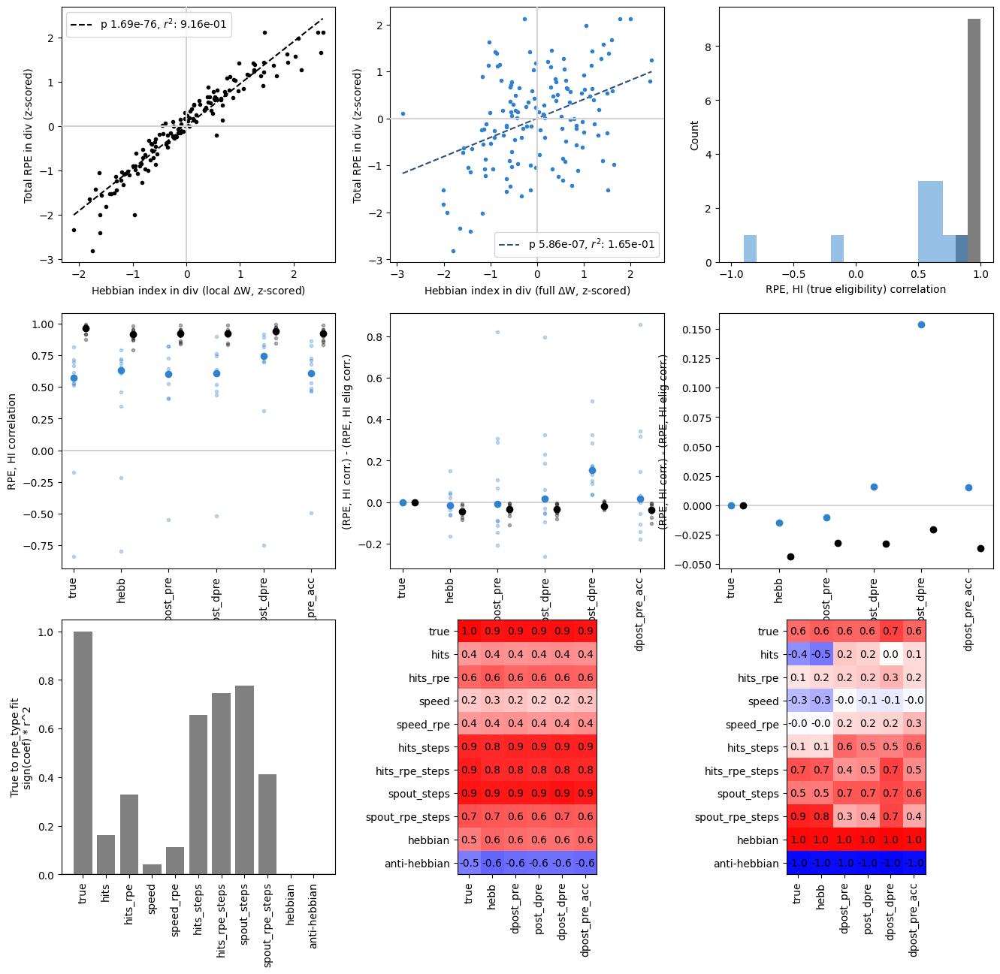

In [13]:
if scan_type in ('bci_hebbian_index',): 

    scan_idx = 0

    fig2, ((ax8, ax9, ax10), (ax11, ax12, ax13), (ax14, ax15, ax16),) = plt.subplots(3, 3, figsize=(16, 15)) # Various types of local Hebbian index

    div_idx = 0
    n_elig_types = len(hi_params['elig_types'])
    rpe_types = list(hi_params['rpe_types'])
    rpe_types.extend(['hebbian', 'anti-hebbian',])
    n_rpe_types = len(rpe_types)
    elig_type_idx = 0 
    rpe_type_idx = 0
    assert hi_params['elig_types'][elig_type_idx] == 'true'
    assert rpe_types[rpe_type_idx] == 'true'

    fit_corrs_local = np.zeros((n_repeats, n_rpe_types, n_elig_types,))
    fit_corrs_full = np.zeros((n_repeats, n_rpe_types, n_elig_types,))

    rpe_type = 'true'

    for rpe_type_idx, rpe_type in enumerate(rpe_types):

        rpe_true_vals = []
        rpe_type_vals = []

        for elig_type_idx, elig_type in enumerate(hi_params['elig_types']):

            div_slopes_local_z = []
            div_slopes_full_z = []
            rpe_divs_z = []

            # for repeat_idx in range(3):
            for repeat_idx in range(n_repeats):
                # Get number of divisions from third-factor values
                if rpe_type in ('hebbian', 'anti-hebbian',): # Not actually gathered, so generate on the fly
                    if rpe_type in ('hebbian',):
                        rpe_divs_val = 1.0 * np.ones_like(rpes_divs_all[repeat_idx]['true'])
                    elif rpe_type in ('anti-hebbian',):
                        rpe_divs_val = -1.0 * np.ones_like(rpes_divs_all[repeat_idx]['true'])
                else:
                    rpe_divs_val = rpes_divs_all[repeat_idx][rpe_type]
                n_divisions = rpe_divs_val.shape[0]

                div_slopes_local_val = div_slopes_all[scan_idx, repeat_idx, elig_type_idx, :n_divisions]
                div_slopes_full_val = div_slopes_full_delta_all[scan_idx, repeat_idx, elig_type_idx, :n_divisions]
                
                # z-score these FIRST, then use the z-scored values to compute the correlation coefficients
                if rpe_type in ('hebbian', 'anti-hebbian',): # Treats this as if all values are already deviations (no mean subtraction)
                    div_slopes_local_val = (div_slopes_local_val) / np.sqrt(np.sum(div_slopes_local_val**2) / n_divisions)
                    div_slopes_full_val = (div_slopes_full_val) / np.sqrt(np.sum(div_slopes_full_val**2) / n_divisions)
                    rpe_divs_val = (rpe_divs_val) / np.sqrt(np.sum(rpe_divs_val**2) / n_divisions)
                else:
                    div_slopes_local_val = (div_slopes_local_val - np.mean(div_slopes_local_val)) / np.std(div_slopes_local_val)
                    div_slopes_full_val = (div_slopes_full_val - np.mean(div_slopes_full_val)) / np.std(div_slopes_full_val)
                    rpe_divs_val = (rpe_divs_val - np.mean(rpe_divs_val)) / np.std(rpe_divs_val)
                
                # fit_corrs_local[repeat_idx, rpe_type_idx, elig_type_idx] = np.corrcoef(div_slopes_local_val, rpe_divs_val)[0, 1]
                # fit_corrs_full[repeat_idx, rpe_type_idx, elig_type_idx] = np.corrcoef(div_slopes_full_val, rpe_divs_val)[0, 1]
                
                fit_corrs_local[repeat_idx, rpe_type_idx, elig_type_idx] = np.dot(div_slopes_local_val, rpe_divs_val) / n_divisions
                fit_corrs_full[repeat_idx, rpe_type_idx, elig_type_idx] = np.dot(div_slopes_full_val, rpe_divs_val) / n_divisions
                
                div_slopes_local_z.append(div_slopes_local_val)
                div_slopes_full_z.append(div_slopes_full_val)
                rpe_divs_z.append(rpe_divs_val)

                if elig_type_idx == 0: # Only do for one type of eligibility
                    rpe_true_val = rpes_divs_all[repeat_idx]['true']
                    rpe_true_val = (rpe_true_val - np.mean(rpe_true_val)) / np.std(rpe_true_val)
                    rpe_true_vals.append(rpe_true_val)
                    rpe_type_vals.append(rpe_divs_val)

            div_slopes_local_z = np.concatenate(div_slopes_local_z, axis=0)
            div_slopes_full_z = np.concatenate(div_slopes_full_z, axis=0)
            rpe_divs_z = np.concatenate(rpe_divs_z, axis=0) 

            if elig_type_idx == 0 and rpe_type_idx == 0: # True RPE and elig only
                ax8.scatter(div_slopes_local_z, rpe_divs_z, marker='.', color='k')
                _ = add_regression_line(div_slopes_local_z, rpe_divs_z, ax=ax8, color='k', linestyle='dashed')
                # ax8.axvline(full_slope, color=c_vals[0], linestyle='dashed') # Full Hebbian index
                ax8.set_ylabel('Total RPE in div (z-scored)')
                ax8.set_xlabel('Hebbian index in div (local $\Delta$W, z-scored)')

                # Raw values, with offset
                ax9.scatter(div_slopes_full_z, rpe_divs_z, marker='.', color=c_vals[1])
                _ = add_regression_line(div_slopes_full_z, rpe_divs_z, ax=ax9, color=c_vals_d[1], linestyle='dashed')
                # With mean subtraction
                # ax9.scatter(div_slopes_full_delta - np.mean(div_slopes_full_delta), rpes_divs, marker='.', color=c_vals_l[2])
                # _ = add_regression_line(div_slopes_full_delta - np.mean(div_slopes_full_delta), rpes_divs, ax=ax9, color=c_vals[2], linestyle='dashed')
                # ax9.axvline(full_slope, color=c_vals[2], linestyle='dashed')
                ax9.set_ylabel('Total RPE in div (z-scored)')
                ax9.set_xlabel('Hebbian index in div (full $\Delta$W, z-scored)')

                bins = np.linspace(-1, 1, 21)
                ax10.hist(fit_corrs_full[:, rpe_type_idx, elig_type_idx], bins=bins, color=c_vals[1], alpha=0.5)
                ax10.hist(fit_corrs_local[:, rpe_type_idx, elig_type_idx], bins=bins, color='k', zorder=-5, alpha=0.5)
                ax10.set_xlabel('RPE, HI ({} eligibility) correlation'.format(elig_type))
                ax10.set_ylabel('Count')

            if rpe_type_idx == 0: # True RPE only
                # parts = ax11.violinplot(fit_corrs_full[:, elig_type_idx], positions=(elig_type_idx,), showextrema=False)
                # for pc in parts['bodies']:
                #     pc.set_facecolor('grey')
                ax11.scatter(elig_type_idx * np.ones(n_repeats), fit_corrs_full[:, rpe_type_idx, elig_type_idx], marker='.', alpha=0.3, color=c_vals[1])
                ax12.scatter(elig_type_idx * np.ones(n_repeats),  fit_corrs_full[:, rpe_type_idx, elig_type_idx] - fit_corrs_full[:, rpe_type_idx, 0], marker='.', alpha=0.3, color=c_vals[1])

                ax11.scatter(elig_type_idx * np.ones(n_repeats)+0.25, fit_corrs_local[:, rpe_type_idx, elig_type_idx], marker='.', alpha=0.3, color='k')
                ax12.scatter(elig_type_idx * np.ones(n_repeats)+0.25,  fit_corrs_local[:, rpe_type_idx, elig_type_idx] - fit_corrs_local[:, rpe_type_idx, 0], marker='.', alpha=0.3, color='k')

                # ax13.scatter(elig_type_idx * np.ones(n_repeats)+0.25,  fit_corrs_local[:, rpe_type_idx, elig_type_idx] - fit_corrs_local[:, rpe_type_idx, 0], marker='.', alpha=0.3, color='k')

        if rpe_type_idx == 0: # True RPE only
            ax11.scatter(np.arange(n_elig_types), np.median(fit_corrs_full, axis=0)[rpe_type_idx], marker='o', color=c_vals[1], zorder=5)
            ax11.scatter(np.arange(n_elig_types)+0.25, np.median(fit_corrs_local, axis=0)[rpe_type_idx], marker='o', color='k', zorder=5)

            for ax in (ax12, ax13): # One of these just provides a zoomed in version of the other
                ax.scatter(np.arange(n_elig_types), np.median(fit_corrs_full - fit_corrs_full[:, :, 0:1], axis=0)[rpe_type_idx], marker='o', color=c_vals[1], zorder=5)
                ax.scatter(np.arange(n_elig_types)+0.25, np.median(fit_corrs_local - fit_corrs_local[:, :, 0:1], axis=0)[rpe_type_idx], marker='o', color='k', zorder=5)

        rpe_true_vals = np.concatenate(rpe_true_vals)
        rpe_type_vals = np.concatenate(rpe_type_vals)

        slope, intercept, rvalue, pvalue, _ = linregress(rpe_true_vals, rpe_type_vals)
        print('True to {}, coef: {:.1e} (p: {:.1e} r^2: {:.2f})'.format(rpe_type, slope, pvalue, rvalue**2))

        ax14.bar((rpe_type_idx,), (np.sign(slope) * rvalue**2), color='grey')

    ax15.matshow(np.median(fit_corrs_local, axis=0), vmin=-1, vmax=1, cmap='bwr')
    for (i, j), z in np.ndenumerate(np.median(fit_corrs_local, axis=0)):
        ax15.text(j, i, '{:0.1f}'.format(z), ha='center', va='center')
    # ax15.title.set_text('HI from local weight changes')
    ax15.xaxis.set_ticks_position('bottom')

    ax16.matshow(np.median(fit_corrs_full, axis=0), vmin=-1, vmax=1, cmap='bwr')
    for (i, j), z in np.ndenumerate(np.median(fit_corrs_full, axis=0)):
        ax16.text(j, i, '{:0.1f}'.format(z), ha='center', va='center')
    # ax16.title.set_text('HI from total weight change')
    ax16.xaxis.set_ticks_position('bottom')

    for ax in (ax8, ax9,):
        ax.axhline(0.0, color='lightgrey', zorder=--5, linestyle='solid')
        ax.axvline(0.0, color='lightgrey', zorder=--5, linestyle='solid')
        ax.legend()

    ax11.axhline(0.0, color='lightgrey', zorder=-5)
    ax11.set_ylabel('RPE, HI correlation')

    for ax in (ax12, ax13): # One of these just provides a zoomed in version of the other
        ax.axhline(0.0, color='lightgrey', zorder=-5)
        ax.set_ylabel('(RPE, HI corr.) - (RPE, HI elig corr.)')

    for ax in (ax11, ax12, ax13, ax15, ax16):
        ax.set_xticks(np.arange(n_elig_types))
        ax.set_xticklabels(hi_params['elig_types'], rotation=90)

    ax14.set_ylabel('True to rpe_type fit\nsign(coef) * r^2')
    ax14.axhline(0.0, color='lightgrey', zorder=-5)
    ax14.set_xticks(np.arange(n_rpe_types))
    ax14.set_xticklabels(rpe_types, rotation=90)

    for ax in (ax15, ax16,):
        ax.set_yticks(np.arange(n_rpe_types))
        ax.set_yticklabels(rpe_types)


Some more detailed analysis for learning rule scan

In [177]:
### Sparsity of change plots ###

scan_idx = 0

c_vals_pl['post_start'] = 'grey'
c_vals_p['post_start'] = 'k'

ts_metrics = ('pre_start', 'post_start_nopre', 'pre_reward', 'post_start', 'post_reward',)
ts_metric_names = ('Pre', 'Early', 'Late', 'Trial', 'Rew')
n_ts_metrics = len(ts_metrics)

n_neurons = net_params['n_neurons']

cn_percentiles = np.nan * np.ones((n_scan, n_repeats, n_ts_metrics))

for scan_idx in range(n_scan):

    fig2, ax2s = plt.subplots(1, 5, figsize=(10, 2))
    
    for ts_metric_idx, (ts_metric, ts_metric_name, ax,) in enumerate(zip(ts_metrics, ts_metric_names, ax2s)):

        for repeat_idx in range(n_repeats): # Slightly easier to run over repeats first, then normalization only happens once
            ts_metric_slopes = session_summaries[scan_idx][repeat_idx]['ts_extras'][ts_metric]['slope']
            cn_idx = cn_idxs[scan_idx, repeat_idx, 0]

            slope_sort_idxs = np.argsort(ts_metric_slopes)

            cn_percentiles[scan_idx, repeat_idx, ts_metric_idx] = np.where(slope_sort_idxs == cn_idx)[0][0] / (n_neurons - 1)

            # ax.hist(np.mean(ts_metric_slopes_bs[1:, :], axis=-1), bins=100, color=c_vals_p[ts_metric], alpha=0.3)
            ax.axvline(cn_percentiles[scan_idx, repeat_idx, ts_metric_idx], color=c_vals_pl[ts_metric])
            ax.axvline(0.0, color='lightgrey', zorder=-5)
            ax.axvline(1.0, color='lightgrey', zorder=-5)

            ax.set_xlabel('$\Delta${} percentile'.format(ts_metric_name))
            ax.set_ylabel('Count')
            
        ax.axvline(np.mean(cn_percentiles[scan_idx, :, ts_metric_idx]), color=c_vals_p[ts_metric])

NameError: name 'n_scan' is not defined

Photostim analysis, needs to be merged with single scan analysis below

Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS
Using raw_fl for PS


/opt/conda/lib/python3.9/site-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/opt/conda/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


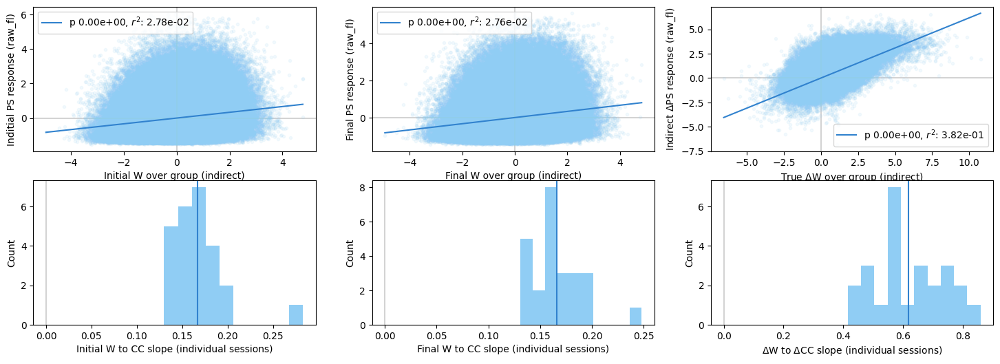

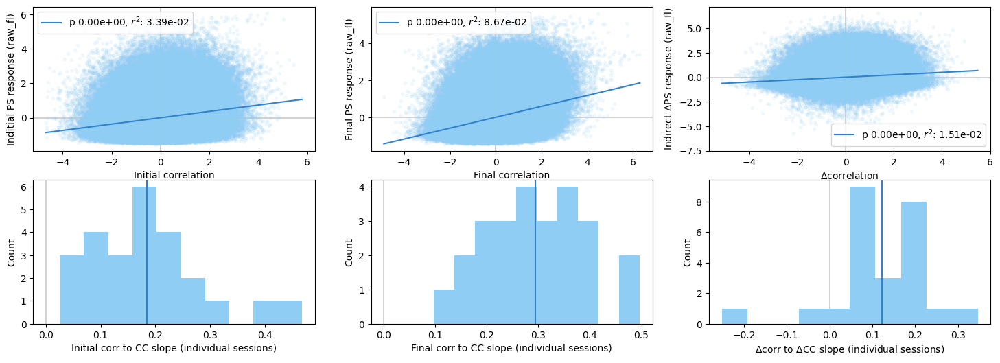

In [105]:
scan_idx = 0
session_idx = 0

n_groups = task_params['n_groups']
n_neurons = net_params['n_neurons']

causal_connectivity_mode = 'groups_to_neurons' # groups_to_neurons, neurons_to_neurons
ps_activity_type = 'raw_fl' # raw_fl, raw_fl_no_pre, raw_fl_post_only, raw_fl_pre_only 
ps_computation_type = 'post_only' # cc, post-pre, post_only, pre_only

W_init_indirect_all = []
W_final_indirect_all = []
delta_W_indirect_all = [] # For z-scoring purposes keep this separate
cc_init_indirect_all = []
cc_final_indirect_all = []
delta_cc_indirect_all = [] # For z-scoring purposes keep this separate

W_to_cc_init_slopes = []
W_to_cc_final_slopes = []
delta_W_to_cc_slopes = []

corr_init_indirect_all = []
corr_final_indirect_all = []
delta_corr_indirect_all = [] # For z-scoring purposes keep this separate

corr_to_cc_init_slopes = []
corr_to_cc_final_slopes = []
delta_corr_to_cc_slopes = []

for repeat_idx in range(n_repeats):

    # Computes the group summed change in weight of each neuron to compare to photostim
    W_init_groups = np.nan * np.ones((n_neurons, n_groups)) # Change in weight per group
    W_final_groups = np.nan * np.ones((n_neurons, n_groups)) # Change in weight per group
    for group_idx in range(task_ps.n_groups):
        W_init_groups[:, group_idx] = np.sum(W_inits_all[scan_idx, repeat_idx][:, task_ps.groups[group_idx]], axis=-1)
        W_final_groups[:, group_idx] = np.sum(W_finals_all[scan_idx, repeat_idx][:, task_ps.groups[group_idx]], axis=-1)

    # Change in causal connectivity
    delta_causal_connectivity, raw_causal_connectivities = bci_analysis.compute_delta_causal_connectivity(
        None, params, task_pss_all[repeat_idx], session_idx,
        causal_connectivity_mode=causal_connectivity_mode, 
        ps_activity_type=ps_activity_type, ps_computation_type=ps_computation_type,
        train_outputs_ps_init=ps_inits_all[repeat_idx], train_outputs_ps_final=ps_finals_all[repeat_idx],
    )

    # Get only indirect now
    W_init_indirect = []
    causal_connectivity_init_indirect = []
    W_final_indirect = []
    causal_connectivity_final_indirect = []
    for group_idx in range(n_groups):
        indirect_idxs = np.arange(n_neurons)
        indirect_idxs = np.delete(indirect_idxs, task_pss_all[repeat_idx].groups[group_idx])

        W_init_indirect.append(W_init_groups[indirect_idxs, group_idx])
        causal_connectivity_init_indirect.append(raw_causal_connectivities[0][indirect_idxs, group_idx])
        W_final_indirect.append(W_final_groups[indirect_idxs, group_idx])
        causal_connectivity_final_indirect.append(raw_causal_connectivities[1][indirect_idxs, group_idx])

    W_init_indirect = np.concatenate(W_init_indirect, axis=0)
    W_final_indirect = np.concatenate(W_final_indirect, axis=0)
    delta_W_indirect = W_final_indirect - W_init_indirect
    causal_connectivity_init_indirect = np.concatenate(causal_connectivity_init_indirect, axis=0)
    causal_connectivity_final_indirect = np.concatenate(causal_connectivity_final_indirect, axis=0)
    delta_cc_indirect = causal_connectivity_final_indirect - causal_connectivity_init_indirect
    
    # z-scoring of quantities
    W_init_indirect = (W_init_indirect - np.nanmean(W_init_indirect)) / np.nanstd(W_init_indirect)
    W_final_indirect = (W_final_indirect - np.nanmean(W_final_indirect)) / np.nanstd(W_final_indirect)
    delta_W_indirect = (delta_W_indirect - np.nanmean(delta_W_indirect)) / np.nanstd(delta_W_indirect)
    causal_connectivity_init_indirect = (causal_connectivity_init_indirect - np.nanmean(causal_connectivity_init_indirect)) / np.nanstd(causal_connectivity_init_indirect)
    causal_connectivity_final_indirect = (causal_connectivity_final_indirect - np.nanmean(causal_connectivity_final_indirect)) / np.nanstd(causal_connectivity_final_indirect)
    delta_cc_indirect = (delta_cc_indirect - np.nanmean(delta_cc_indirect)) / np.nanstd(delta_cc_indirect)
    
    #### Comparison of true weights to CC measured weights ####
    
    # print('---- {} ----'.format(ps_activity_type))
    slope, intercept, rvalue, pvalue, _ = linregress(W_init_indirect, causal_connectivity_init_indirect)
    W_to_cc_init_slopes.append(slope)
    # print(' Initial fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
    slope, intercept, rvalue, pvalue, _ = linregress(W_final_indirect, causal_connectivity_final_indirect)
    W_to_cc_final_slopes.append(slope)
    # print(' Final   fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
    slope, intercept, rvalue, pvalue, _ = linregress(delta_W_indirect, delta_cc_indirect)
    delta_W_to_cc_slopes.append(slope)
    # print(' Delta   fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))

    W_init_indirect_all.append(W_init_indirect)
    W_final_indirect_all.append(W_final_indirect)
    delta_W_indirect_all.append(delta_W_indirect)
    cc_init_indirect_all.append(causal_connectivity_init_indirect)
    cc_final_indirect_all.append(causal_connectivity_final_indirect)
    delta_cc_indirect_all.append(delta_cc_indirect)
    
    #### Correlation-based calculations ####
    
    group_correlations_init = np.nan * np.ones((n_neurons, n_groups,))
    group_correlations_final = np.nan * np.ones((n_neurons, n_groups,))
    indirect_correlations_init = []
    indirect_correlations_final = []
    
    for group_idx in range(n_groups):
        indirect_idxs = np.arange(n_neurons)
        indirect_idxs = np.delete(indirect_idxs, task_pss_all[repeat_idx].groups[group_idx])

        
        pairwise_corr_inits_all[scan_idx, repeat_idx]
        group_correlations_init[:, group_idx] = np.sum(
            pairwise_corr_inits_all[scan_idx, repeat_idx][:, task_pss_all[repeat_idx].groups[group_idx]], axis=-1
        )
        group_correlations_final[:, group_idx] = np.sum(
            pairwise_corr_finals_all[scan_idx, repeat_idx][:, task_pss_all[repeat_idx].groups[group_idx]], axis=-1
        )
        indirect_correlations_init.append(group_correlations_init[indirect_idxs, group_idx])
        indirect_correlations_final.append(group_correlations_final[indirect_idxs, group_idx])
    
    indirect_correlations_init = np.concatenate(indirect_correlations_init, axis=0)
    indirect_correlations_final = np.concatenate(indirect_correlations_final, axis=0)
    delta_corr_indirect = indirect_correlations_final - indirect_correlations_init
    # z-scoring of quantities
    indirect_correlations_init = (indirect_correlations_init - np.nanmean(indirect_correlations_init)) / np.nanstd(indirect_correlations_init)
    indirect_correlations_final = (indirect_correlations_final - np.nanmean(indirect_correlations_final)) / np.nanstd(indirect_correlations_final)
    delta_corr_indirect = (delta_corr_indirect - np.nanmean(delta_corr_indirect)) / np.nanstd(delta_corr_indirect)
    
    slope, intercept, rvalue, pvalue, _ = linregress(indirect_correlations_init, causal_connectivity_init_indirect)        
    corr_to_cc_init_slopes.append(slope)
    # print(' Initial fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
    slope, intercept, rvalue, pvalue, _ = linregress(indirect_correlations_final, causal_connectivity_final_indirect)
    corr_to_cc_final_slopes.append(slope)
    # print(' Final   fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))
    slope, intercept, rvalue, pvalue, _ = linregress(delta_corr_indirect, delta_cc_indirect)
    delta_corr_to_cc_slopes.append(slope)
    # print(' Delta   fit: {:.1e} (p: {:.1e} r^2: {:.1e})'.format(slope, pvalue, rvalue**2))

    corr_init_indirect_all.append(indirect_correlations_init)
    corr_final_indirect_all.append(indirect_correlations_final)
    delta_corr_indirect_all.append(delta_corr_indirect)

### True weights to CC plots ###

fig, ((ax1, ax2, ax3,), (ax4, ax5, ax6,)) = plt.subplots(2, 3, figsize=(18, 6))

W_init_indirect_all = np.concatenate(W_init_indirect_all, axis=0)
W_final_indirect_all = np.concatenate(W_final_indirect_all, axis=0)
delta_W_indirect_all = np.concatenate(delta_W_indirect_all, axis=0)
cc_init_indirect_all = np.concatenate(cc_init_indirect_all, axis=0)
cc_final_indirect_all = np.concatenate(cc_final_indirect_all, axis=0)
delta_cc_indirect_all = np.concatenate(delta_cc_indirect_all, axis=0)
    
# Scatter over true delta_W_groups versus CC estimate
ax1.scatter(W_init_indirect_all, cc_init_indirect_all, marker='.', color=c_vals_l[1], alpha=0.1)
init_slope, _, _ = add_regression_line(W_init_indirect_all, cc_init_indirect_all, ax=ax1, color=c_vals[1], zorder=5)
ax1.set_xlabel('Initial W over group (indirect)')
ax1.set_ylabel('Inditial PS response ({})'.format(ps_activity_type))

# Scatter over true delta_W_groups versus CC estimate
ax2.scatter(W_final_indirect_all, cc_final_indirect_all, marker='.', color=c_vals_l[1], alpha=0.1)
final_slope, _, _ = add_regression_line(W_final_indirect_all, cc_final_indirect_all, ax=ax2, color=c_vals[1], zorder=5)
ax2.set_xlabel('Final W over group (indirect)')
ax2.set_ylabel('Final PS response ({})'.format(ps_activity_type)) 
    
# Scatter over true delta_W_groups versus CC estimate
ax3.scatter(delta_W_indirect_all, delta_cc_indirect_all, marker='.', color=c_vals_l[1], alpha=0.1)
delta_slope, _, _ = add_regression_line(delta_W_indirect_all, delta_cc_indirect_all, ax=ax3, color=c_vals[1], zorder=5)
ax3.set_xlabel('True $\Delta$W over group (indirect)')
ax3.set_ylabel('Indirect $\Delta$PS response ({})'.format(ps_activity_type))

for ax in (ax1, ax2, ax3,):
    ax.axhline(0.0, color='lightgrey', zorder=-5)
    ax.axvline(0.0, color='lightgrey', zorder=-5)
    ax.legend()
    
ax4.hist(W_to_cc_init_slopes, color=c_vals_l[1], bins=10)
ax4.axvline(init_slope, color=c_vals[1],)
ax4.set_xlabel('Initial W to CC slope (individual sessions)')

ax5.hist(W_to_cc_final_slopes, color=c_vals_l[1], bins=10)
ax5.axvline(final_slope, color=c_vals[1],)
ax5.set_xlabel('Final W to CC slope (individual sessions)')

ax6.hist(delta_W_to_cc_slopes, color=c_vals_l[1], bins=10)
ax6.axvline(delta_slope, color=c_vals[1],)
ax6.set_xlabel('$\Delta$W to $\Delta$CC slope (individual sessions)')

for ax in (ax4, ax5, ax6,):
    ax.axvline(0.0, color='lightgrey', zorder=-5)
    ax.set_ylabel('Count')

#### Correlation-based plots ####

fig, ((ax1, ax2, ax3,), (ax4, ax5, ax6,)) = plt.subplots(2, 3, figsize=(18, 6))

corr_init_indirect_all = np.concatenate(corr_init_indirect_all, axis=0)
corr_final_indirect_all = np.concatenate(corr_final_indirect_all, axis=0)
delta_corr_indirect_all = np.concatenate(delta_corr_indirect_all, axis=0)

# Scatter over true delta_W_groups versus CC estimate
ax1.scatter(corr_init_indirect_all, cc_init_indirect_all, marker='.', color=c_vals_l[1], alpha=0.1)
init_slope, _, _ = add_regression_line(corr_init_indirect_all, cc_init_indirect_all, ax=ax1, color=c_vals[1], zorder=5)
ax1.set_xlabel('Initial correlation')
ax1.set_ylabel('Inditial PS response ({})'.format(ps_activity_type))

# Scatter over true delta_W_groups versus CC estimate
ax2.scatter(corr_final_indirect_all, cc_final_indirect_all, marker='.', color=c_vals_l[1], alpha=0.1)
final_slope, _, _ = add_regression_line(corr_final_indirect_all, cc_final_indirect_all, ax=ax2, color=c_vals[1], zorder=5)
ax2.set_xlabel('Final correlation')
ax2.set_ylabel('Final PS response ({})'.format(ps_activity_type)) 
    
# Scatter over true delta_W_groups versus CC estimate
ax3.scatter(delta_corr_indirect_all, delta_cc_indirect_all, marker='.', color=c_vals_l[1], alpha=0.1)
delta_slope, _, _ = add_regression_line(delta_corr_indirect_all, delta_cc_indirect_all, ax=ax3, color=c_vals[1], zorder=5)
ax3.set_xlabel('$\Delta$correlation')
ax3.set_ylabel('Indirect $\Delta$PS response ({})'.format(ps_activity_type))

for ax in (ax1, ax2, ax3,):
    ax.axhline(0.0, color='lightgrey', zorder=-5)
    ax.axvline(0.0, color='lightgrey', zorder=-5)
    ax.legend()
    
ax4.hist(corr_to_cc_init_slopes, color=c_vals_l[1], bins=10)
ax4.axvline(init_slope, color=c_vals[1],)
ax4.set_xlabel('Initial corr to CC slope (individual sessions)')

ax5.hist(corr_to_cc_final_slopes, color=c_vals_l[1], bins=10)
ax5.axvline(final_slope, color=c_vals[1],)
ax5.set_xlabel('Final corr to CC slope (individual sessions)')

ax6.hist(delta_corr_to_cc_slopes, color=c_vals_l[1], bins=10)
ax6.axvline(delta_slope, color=c_vals[1],)
ax6.set_xlabel('$\Delta$corr to $\Delta$CC slope (individual sessions)')

for ax in (ax4, ax5, ax6,):
    ax.axvline(0.0, color='lightgrey', zorder=-5)
    ax.set_ylabel('Count')
    

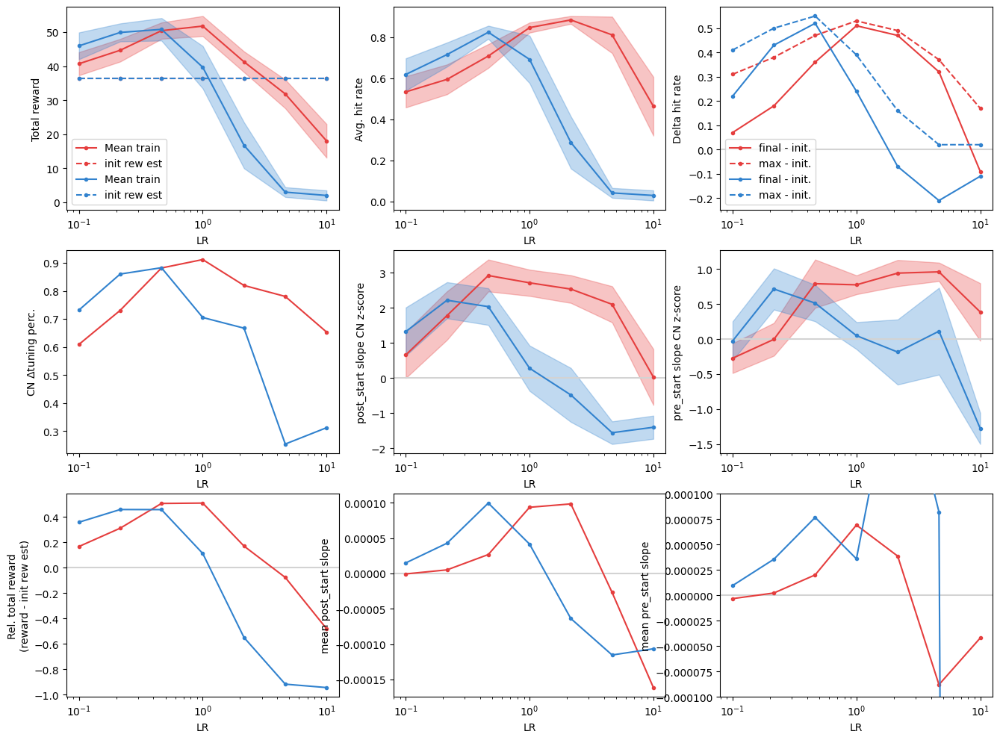

In [163]:
from scipy.stats import sem

fig, ((ax1, ax2, ax3), (ax4, ax5, ax6), (ax7, ax8, ax9)) = plt.subplots(3, 3, figsize=(16, 12))

n_scan_1 = len(scan_vals_1)
n_scan_2 = scan_vals_2.shape[0]
assert n_sessions == 1 
total_rewards = np.zeros((n_scan_1, n_scan_2, n_repeats,))

est_total_rewards = np.zeros_like(total_rewards)
total_hit_rates = np.zeros_like(total_rewards)
delta_hit_rates = np.zeros_like(total_rewards)
delta_hit_rates_max = np.zeros_like(total_rewards)

cn_tuning_perc = np.zeros_like(total_rewards)

ts_metric1 = 'post_start'
cn_ts_metric1_zscore = np.nan * np.ones_like(total_rewards)
ts_metric1_mean = np.nan * np.ones_like(total_rewards)

ts_metric2 = 'pre_start'
cn_ts_metric2_zscore = np.nan * np.ones_like(total_rewards)
ts_metric2_mean = np.nan * np.ones_like(total_rewards)


for scan_idx_1 in range(n_scan_1):
    for scan_idx_2 in range(n_scan_2):
        scan_idx = scan_idx_1 * n_scan_2 + scan_idx_2
        for repeat_idx in range(n_repeats):
            cn_idx = cn_idxs[scan_idx, repeat_idx, 0]
            
            total_rewards[scan_idx_1, scan_idx_2, repeat_idx] = session_summaries[scan_idx][repeat_idx]['total_reward']
            est_total_rewards[scan_idx_1, scan_idx_2, repeat_idx] = start_avg_rewards[scan_idx, repeat_idx] * (
                task_params['n_steps'] - task_params['n_steps_stabilize']
            )
            if scan_type in ('bci_start_avg_reward_mult_scan',): # Adjust for reward mult.
                est_total_rewards[scan_idx_1, scan_idx_2, repeat_idx] /= scan_vals[scan_idx]
            total_hit_rates[scan_idx_1, scan_idx_2, repeat_idx] = session_summaries[scan_idx][repeat_idx]['hit_rate']
            delta_hit_rates[scan_idx_1, scan_idx_2, repeat_idx] = (
                session_summaries[scan_idx][repeat_idx]['hit_rate_final'] - session_summaries[scan_idx][repeat_idx]['hit_rate_init']
            )
            delta_hit_rates_max[scan_idx_1, scan_idx_2, repeat_idx] = (
                session_summaries[scan_idx][repeat_idx]['hit_rate_max'] - session_summaries[scan_idx][repeat_idx]['hit_rate_init']
            )
            
            cn_tuning_perc[scan_idx_1, scan_idx_2, repeat_idx] = session_summaries[scan_idx][repeat_idx]['cn_tuning_percentile']
            
            if ts_metric1 in session_summaries[scan_idx][repeat_idx]['ts_extras'].keys():
                ts_metric1_slopes = session_summaries[scan_idx][repeat_idx]['ts_extras'][ts_metric1]['slope']
                cn_ts_metric1_zscore[scan_idx_1, scan_idx_2, repeat_idx] = (ts_metric1_slopes[cn_idx] - np.mean(ts_metric1_slopes)) / np.std(ts_metric1_slopes)
                ts_metric1_mean[scan_idx_1, scan_idx_2, repeat_idx] = np.mean(ts_metric1_slopes)
                
            if ts_metric2 in session_summaries[scan_idx][repeat_idx]['ts_extras'].keys():
                ts_metric2_slopes = session_summaries[scan_idx][repeat_idx]['ts_extras'][ts_metric2]['slope']
                cn_ts_metric2_zscore[scan_idx_1, scan_idx_2, repeat_idx] = (ts_metric2_slopes[cn_idx] - np.mean(ts_metric2_slopes)) / np.std(ts_metric2_slopes)
                ts_metric2_mean[scan_idx_1, scan_idx_2, repeat_idx] = np.mean(ts_metric2_slopes)
                
rel_total_rewards = (total_rewards - est_total_rewards) / est_total_rewards


MARKER = '.'   
for scan_idx_1 in range(n_scan_1):
    color_val = c_vals[scan_idx_1]
    color_val_l = c_vals_l[scan_idx_1]
    
    rew_val = np.mean(total_rewards[scan_idx_1, :, :], axis=-1)
    rew_error = sem(total_rewards[scan_idx_1, :, :], axis=-1, nan_policy='omit')
    # np.std(total_rewards[scan_idx_1, :, :], axis=-1)
    
    ax1.plot(scan_vals_2, rew_val, color=color_val, marker=MARKER, zorder=5, label='Mean train')
    ax1.fill_between(scan_vals_2, rew_val+rew_error, rew_val-rew_error, color=color_val, alpha=0.3, zorder=-5)
    ax1.plot(scan_vals_2, np.mean(est_total_rewards[scan_idx_1, :, :], axis=-1), color=color_val,
             marker=MARKER, zorder=5, linestyle='dashed', label='init rew est')
    
    hit_val = np.mean(total_hit_rates[scan_idx_1, :, :], axis=-1)
    hit_error = sem(total_hit_rates[scan_idx_1, :, :], axis=-1, nan_policy='omit')
    ax2.plot(scan_vals_2, hit_val, color=color_val, marker=MARKER, zorder=5)
    ax2.fill_between(scan_vals_2, hit_val+hit_error, hit_val-hit_error, color=color_val, alpha=0.3, zorder=-5)
    
    ax3.plot(scan_vals_2, np.mean(delta_hit_rates[scan_idx_1, :, :], axis=-1), color=color_val,
             marker=MARKER, zorder=5, label='final - init.')
    ax3.plot(scan_vals_2, np.mean(delta_hit_rates_max[scan_idx_1, :, :], axis=-1), color=color_val,
             marker=MARKER, zorder=5, linestyle='dashed', label='max - init.')
    
    ax4.plot(scan_vals_2, np.nanmean(cn_tuning_perc[scan_idx_1, :, :], axis=-1), color=color_val, marker=MARKER, zorder=5)
    
    ts_metric_val = np.nanmean(cn_ts_metric1_zscore[scan_idx_1, :, :], axis=-1)
    ts_metric_error = sem(cn_ts_metric1_zscore[scan_idx_1, :, :], axis=-1, nan_policy='omit')
    ax5.plot(scan_vals_2, ts_metric_val, color=color_val, marker=MARKER, zorder=5)
    ax5.fill_between(scan_vals_2, ts_metric_val+ts_metric_error, ts_metric_val-ts_metric_error, color=color_val, alpha=0.3, zorder=-5)
    
    ts_metric_val = np.nanmean(cn_ts_metric2_zscore[scan_idx_1, :, :], axis=-1)
    ts_metric_error = sem(cn_ts_metric2_zscore[scan_idx_1, :, :], axis=-1, nan_policy='omit')
    ax6.plot(scan_vals_2, ts_metric_val, color=color_val, marker=MARKER, zorder=5)
    ax6.fill_between(scan_vals_2, ts_metric_val+ts_metric_error, ts_metric_val-ts_metric_error, color=color_val, alpha=0.3, zorder=-5)

    ax7.plot(scan_vals_2, np.mean(rel_total_rewards[scan_idx_1, :, :], axis=-1), color=color_val, marker=MARKER, zorder=5)
    ax8.plot(scan_vals_2, np.nanmean(ts_metric1_mean[scan_idx_1, :, :], axis=-1), color=color_val, marker=MARKER, zorder=5)
    ax9.plot(scan_vals_2, np.nanmean(ts_metric2_mean[scan_idx_1, :, :], axis=-1), color=color_val, marker=MARKER, zorder=5)
    
#     for repeat_idx in range(n_repeats):
#         ax1.plot(scan_vals_2, total_rewards[scan_idx_1, :, repeat_idx], color=color_val_l, marker=MARKER, zorder=-10)
#         ax2.plot(scan_vals_2, total_hit_rates[scan_idx_1, :, repeat_idx], color=color_val_l, marker=MARKER, zorder=-10)
#         ax3.plot(scan_vals_2, delta_hit_rates[scan_idx_1, :, repeat_idx], color=color_val_l, marker=MARKER, zorder=-10)
        
#         ax4.plot(scan_vals_2, cn_tuning_perc[scan_idx_1, :, repeat_idx], color=color_val_l, marker=MARKER, zorder=-10)
#         ax5.plot(scan_vals_2, cn_ts_metric1_zscore[scan_idx_1, :, repeat_idx], color=color_val_l, marker=MARKER, zorder=-10)
#         ax6.plot(scan_vals_2, cn_ts_metric2_zscore[scan_idx_1, :, repeat_idx], color=color_val_l, marker=MARKER, zorder=-10)
        
#         ax7.plot(scan_vals_2, rel_total_rewards[scan_idx_1, :, repeat_idx], color=color_val_l, marker=MARKER, zorder=-10)
#         ax8.plot(scan_vals_2, ts_metric1_mean[scan_idx_1, :, repeat_idx], color=color_val_l, marker=MARKER, zorder=-10)
#         ax9.plot(scan_vals_2, ts_metric2_mean[scan_idx_1, :, repeat_idx], color=color_val_l, marker=MARKER, zorder=-10)

ax1.set_ylabel('Total reward')
ax2.set_ylabel('Avg. hit rate')
ax3.set_ylabel('Delta hit rate')

ax4.set_ylabel('CN $\Delta$tuning perc.')
ax5.set_ylabel('{} slope CN z-score'.format(ts_metric1))
ax6.set_ylabel('{} slope CN z-score'.format(ts_metric2))

ax7.set_ylabel('Rel. total reward\n(reward - init rew est)')
ax8.set_ylabel('mean {} slope'.format(ts_metric1))
ax9.set_ylabel('mean {} slope'.format(ts_metric2))

ax9.set_ylim((-0.0001, 0.0001))

for ax in (ax3, ax5, ax6, ax7, ax8, ax9):
    ax.axhline(0.0, color='lightgrey', linestyle='solid', zorder=-5)

ax1.legend()
ax3.legend()

for ax in (ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9):    
    ax.set_xscale('log') # Default, overriden below
    ax.set_xlabel('LR')

Plots various performance metrics as a function of the scan index

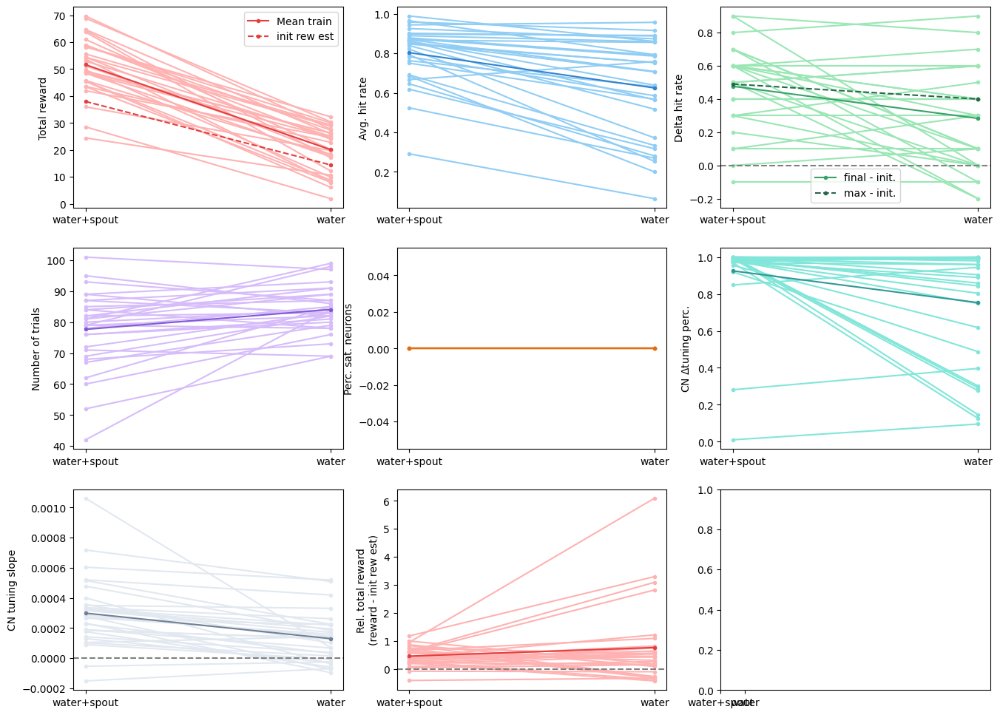

In [62]:
fig, ((ax1, ax2, ax3), (ax4, ax5, ax6), (ax7, ax8, ax9)) = plt.subplots(3, 3, figsize=(16, 12))

total_rewards = np.zeros((n_scan, n_repeats, n_sessions))
est_total_rewards = np.zeros_like(total_rewards)
total_hit_rates = np.zeros_like(total_rewards)
delta_hit_rates = np.zeros_like(total_rewards)
delta_hit_rates_max = np.zeros_like(total_rewards)
n_trials_all = np.zeros_like(total_rewards)
perc_sat_neurons = np.zeros_like(total_rewards)
cn_tuning_perc = np.zeros_like(total_rewards)
cn_tuning_slope = np.zeros_like(total_rewards)

if scan_type in ('bci_lr_scan_multisession',): # Need to load the data in this case
    SESSION_START = 0
    SESSION_END = n_sessions
    assert save_sessions or load_sessions

    for scan_idx, scan_val in enumerate(scan_vals):
        for repeat_idx in range(n_repeats):
            for session_idx in range(n_sessions):
                # local_path = save_path
                # local_path += '_scan_val{:.1e}'.format(scan_val)
                # params_load, train_outputs_load, net_load, task_load, task_ps_load = net_helpers.load_session(
                #     session_idx, local_path, seed + repeat_idx
                # )

                # total_rewards[scan_idx, repeat_idx, session_idx] = train_outputs_load['session_summary']['total_reward']
                # est_total_rewards[scan_idx, repeat_idx, session_idx] = train_outputs_load['start_avg_reward'] * (
                #     task_params['n_steps'] - task_params['n_steps_stabilize']
                # )
                # if scan_type in ('bci_start_avg_reward_mult_scan',): # Adjust for reward mult.
                #     est_total_rewards[scan_idx, repeat_idx, session_idx] /= scan_vals[scan_idx]
                # total_hit_rates[scan_idx, repeat_idx, session_idx] = train_outputs_load['session_summary']['hit_rate']
                # delta_hit_rates[scan_idx, repeat_idx, session_idx] = (
                #     train_outputs_load['session_summary']['hit_rate_final'] - train_outputs_load['session_summary']['hit_rate_init']
                # )
                # delta_hit_rates_max[scan_idx, repeat_idx, session_idx] = (
                #     train_outputs_load['session_summary']['hit_rate_max'] - train_outputs_load['session_summary']['hit_rate_init']
                # )
                # n_trials_all[scan_idx, repeat_idx, session_idx] = train_outputs_load['session_summary']['n_trials']
                # perc_sat_neurons[scan_idx, repeat_idx, session_idx] = train_outputs_load['session_summary']['perc_saturated_neurons']
                # cn_tuning_perc[scan_idx, repeat_idx, session_idx] = train_outputs_load['session_summary']['cn_tuning_percentile']
                # cn_tuning_slope[scan_idx, repeat_idx, session_idx] = train_outputs_load['session_summary']['cn_tuning_slope']

                total_rewards[scan_idx, repeat_idx, session_idx] = session_summaries[scan_idx][repeat_idx][session_idx]['total_reward']
                est_total_rewards[scan_idx, repeat_idx, session_idx] = start_avg_rewards[scan_idx, repeat_idx, session_idx] * (
                    task_params['n_steps'] - task_params['n_steps_stabilize']
                )
                if scan_type in ('bci_start_avg_reward_mult_scan',): # Adjust for reward mult.
                    est_total_rewards[scan_idx, repeat_idx, session_idx] /= scan_vals[scan_idx]
                total_hit_rates[scan_idx, repeat_idx, session_idx] = session_summaries[scan_idx][repeat_idx][session_idx]['hit_rate']
                delta_hit_rates[scan_idx, repeat_idx, session_idx] = (
                    session_summaries[scan_idx][repeat_idx][session_idx]['hit_rate_final'] - session_summaries[scan_idx][repeat_idx][session_idx]['hit_rate_init']
                )
                delta_hit_rates_max[scan_idx, repeat_idx, session_idx] = (
                    session_summaries[scan_idx][repeat_idx][session_idx]['hit_rate_max'] - session_summaries[scan_idx][repeat_idx][session_idx]['hit_rate_init']
                )
                n_trials_all[scan_idx, repeat_idx, session_idx] = session_summaries[scan_idx][repeat_idx][session_idx]['n_trials']
                perc_sat_neurons[scan_idx, repeat_idx, session_idx] = session_summaries[scan_idx][repeat_idx][session_idx]['perc_saturated_neurons']
                cn_tuning_perc[scan_idx, repeat_idx, session_idx] = session_summaries[scan_idx][repeat_idx][session_idx]['cn_tuning_percentile']
                cn_tuning_slope[scan_idx, repeat_idx, session_idx] = session_summaries[scan_idx][repeat_idx][session_idx]['cn_tuning_slope']
else: # Single session, single scan cases
    assert n_sessions == 1
    SESSION_START = 0
    SESSION_END = n_sessions

    for scan_idx in range(n_scan):
        for repeat_idx in range(n_repeats):
            total_rewards[scan_idx, repeat_idx] = session_summaries[scan_idx][repeat_idx]['total_reward']
            est_total_rewards[scan_idx, repeat_idx] = start_avg_rewards[scan_idx, repeat_idx] * (
                task_params['n_steps'] - task_params['n_steps_stabilize']
            )
            if scan_type in ('bci_start_avg_reward_mult_scan',): # Adjust for reward mult.
                est_total_rewards[scan_idx, repeat_idx] /= scan_vals[scan_idx]
            total_hit_rates[scan_idx, repeat_idx] = session_summaries[scan_idx][repeat_idx]['hit_rate']
            delta_hit_rates[scan_idx, repeat_idx] = (
                session_summaries[scan_idx][repeat_idx]['hit_rate_final'] - session_summaries[scan_idx][repeat_idx]['hit_rate_init']
            )
            delta_hit_rates_max[scan_idx, repeat_idx] = (
                session_summaries[scan_idx][repeat_idx]['hit_rate_max'] - session_summaries[scan_idx][repeat_idx]['hit_rate_init']
            )
            n_trials_all[scan_idx, repeat_idx] = session_summaries[scan_idx][repeat_idx]['n_trials']
            perc_sat_neurons[scan_idx, repeat_idx] = session_summaries[scan_idx][repeat_idx]['perc_saturated_neurons']
            cn_tuning_perc[scan_idx, repeat_idx] = session_summaries[scan_idx][repeat_idx]['cn_tuning_percentile']
            cn_tuning_slope[scan_idx, repeat_idx] = session_summaries[scan_idx][repeat_idx]['cn_tuning_slope']

rel_total_rewards = (total_rewards - est_total_rewards) / est_total_rewards

if scan_type in ('bci_n_window_reward_scan', 'bci_n_window_baseline_scan',
                 'bci_n_window_elig_scan', 'bci_n_reward_delay_scan',): # Remap scan value into seconds
    scan_vals_plot = scan_vals / 20
elif scan_type in ('bci_many_repeats', 'bci_hebbian_index',):
    scan_vals_plot = (1,)
else:
    scan_vals_plot = np.copy(scan_vals)

MARKER = '.'   

ax1.plot(scan_vals_plot, np.mean(total_rewards[:, :, SESSION_START:SESSION_END], axis=(1, 2)), color=c_vals[0],
         marker=MARKER, zorder=5, label='Mean train')
ax1.plot(scan_vals_plot, np.mean(est_total_rewards[:, :, SESSION_START:SESSION_END], axis=(1, 2)), color=c_vals[0],
         marker=MARKER, zorder=5, linestyle='dashed', label='init rew est')
ax2.plot(scan_vals_plot, np.mean(total_hit_rates[:, :, SESSION_START:SESSION_END], axis=(1, 2)), color=c_vals[1], marker=MARKER, zorder=5)
ax3.plot(scan_vals_plot, np.mean(delta_hit_rates[:, :, SESSION_START:SESSION_END], axis=(1, 2)), color=c_vals[2],
         marker=MARKER, zorder=5, label='final - init.')
ax3.plot(scan_vals_plot, np.mean(delta_hit_rates_max[:, :, SESSION_START:SESSION_END], axis=(1, 2)), color=c_vals_d[2],
         marker=MARKER, zorder=5, linestyle='dashed', label='max - init.')
ax4.plot(scan_vals_plot, np.mean(n_trials_all[:, :, SESSION_START:SESSION_END], axis=(1, 2)), color=c_vals[3], marker=MARKER, zorder=5)
ax5.plot(scan_vals_plot, np.mean(perc_sat_neurons[:, :, SESSION_START:SESSION_END], axis=(1, 2)), color=c_vals[4], marker=MARKER, zorder=5)
ax6.plot(scan_vals_plot, np.nanmean(cn_tuning_perc[:, :, SESSION_START:SESSION_END], axis=(1, 2)), color=c_vals[5], marker=MARKER, zorder=5)
ax7.plot(scan_vals_plot, np.nanmean(cn_tuning_slope[:, :, SESSION_START:SESSION_END], axis=(1, 2)), color=c_vals[6], marker=MARKER, zorder=5)
ax8.plot(scan_vals_plot, np.mean(rel_total_rewards[:, :, SESSION_START:SESSION_END], axis=(1, 2)), color=c_vals[0], marker=MARKER, zorder=5)

for repeat_idx in range(n_repeats):
    for session_idx in range(SESSION_START, SESSION_END):
        ax1.plot(scan_vals_plot, total_rewards[:, repeat_idx, session_idx], color=c_vals_l[0], marker=MARKER, zorder=-10)
        ax2.plot(scan_vals_plot, total_hit_rates[:, repeat_idx, session_idx], color=c_vals_l[1], marker=MARKER, zorder=-10)
        ax3.plot(scan_vals_plot, delta_hit_rates[:, repeat_idx, session_idx], color=c_vals_l[2], marker=MARKER, zorder=-10)
        ax4.plot(scan_vals_plot, n_trials_all[:, repeat_idx, session_idx], color=c_vals_l[3], marker=MARKER, zorder=-10)
        ax5.plot(scan_vals_plot, perc_sat_neurons[:, repeat_idx, session_idx], color=c_vals_l[4], marker=MARKER, zorder=-10)
        ax6.plot(scan_vals_plot, cn_tuning_perc[:, repeat_idx, session_idx], color=c_vals_l[5], marker=MARKER, zorder=-10)
        ax7.plot(scan_vals_plot, cn_tuning_slope[:, repeat_idx, session_idx], color=c_vals_l[6], marker=MARKER, zorder=-10)
        ax8.plot(scan_vals_plot, rel_total_rewards[:, repeat_idx, session_idx], color=c_vals_l[0], marker=MARKER, zorder=-10)

ax1.set_ylabel('Total reward')
ax2.set_ylabel('Avg. hit rate')
ax3.set_ylabel('Delta hit rate')
ax4.set_ylabel('Number of trials')
ax5.set_ylabel('Perc. sat. neurons')
ax6.set_ylabel('CN $\Delta$tuning perc.')
ax7.set_ylabel('CN tuning slope')
ax8.set_ylabel('Rel. total reward\n(reward - init rew est)')

ax1.legend()
ax3.axhline(0.0, color='grey', linestyle='dashed', zorder=-5)
ax3.legend()
ax7.axhline(0.0, color='grey', linestyle='dashed', zorder=-5)
ax8.axhline(0.0, color='grey', linestyle='dashed', zorder=-5)

for ax in (ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9):    
    ax.set_xscale('log') # Default, overriden below
    if scan_type in ('bci_learning_rule_scan',):
        if scan_vals_2.shape[0] > 1: 
            ax.set_xlabel('LR')
        else:
            ax.set_xlabel('Learning rule')
            ax.set_xscale('linear')
    elif scan_type in ('bci_lr_scan', 'bci_lr_scan_W_inp',):
        ax.set_xlabel('LR')
    elif scan_type in ('bci_stim_to_noise_ratio_scan',):
        ax.set_xlabel('stim/noise ratio')
        ax.axvline(0.25, color='grey', linestyle='dashed', zorder=-5)
    elif scan_type in ('bci_n_window_reward_scan',):
        ax.set_xlabel('reward timescale (s)')
        ax.axvline(300*20 / 20, color='grey', linestyle='dashed', zorder=-5)
    elif scan_type in ('bci_n_window_baseline_scan',):
        ax.set_xlabel('neuron baseline timescale (s)')
        ax.axvline(10*20 / 20, color='grey', linestyle='dashed', zorder=-5)
        ax.axvline(10 / 20, color=c_vals_d[0], linestyle='dashed', zorder=-5) # Delay
    elif scan_type in ('bci_n_window_elig_scan',):
        ax.set_xlabel('elig. timescale (s)')
        ax.axvline(2*20 / 20, color='grey', linestyle='dashed', zorder=-5)
        ax.axvline(10 / 20, color=c_vals_d[0], linestyle='dashed', zorder=-5) # Delay
    elif scan_type in ('bci_n_reward_delay_scan',):
        ax.set_xlabel('Delay (s)')
        ax.set_xscale('linear')
        ax.axvline(10 / 20, color=c_vals_d[0], linestyle='dashed', zorder=-5) # Delay
    elif scan_type in ('bci_start_avg_reward_mult_scan',):
        ax.set_xlabel('Start reward mult.')
        ax.set_xscale('linear')
    elif scan_type in ('bci_spout_rew_scan',):
        ax.set_xscale('linear')
        ax.set_xticks((0, 1,))
        ax.set_xticklabels(('water+spout', 'water',))

These plots only make sense for a single scan index for the moment.

Trial_starts len: 72, trial_outcomes len: 71, padding!
Trial_starts len: 80, trial_outcomes len: 79, padding!
Slope sparsity computation
 Pre bootstrap...


/tmp/ipykernel_54/1437051132.py:44: RuntimeWarning: Mean of empty slice
  pretrial_lens_avg.append(np.nanmean(pretrial_lens[trial_idx:trial_idx+n_trial_avg_window]))
/tmp/ipykernel_54/1437051132.py:70: RuntimeWarning: Mean of empty slice
  mean_hit_rate = np.nanmean(mean_hit_rates_all, axis=0)
/opt/conda/lib/python3.9/site-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_54/1437051132.py:87: RuntimeWarning: Mean of empty slice
  mean_trial_lens = np.nanmean(trial_lens_all, axis=0)
/tmp/ipykernel_54/1437051132.py:89: RuntimeWarning: Mean of empty slice
  mean_pretrial_lens = np.nanmean(pretrial_lens_all, axis=0)


 Early bootstrap...
 Late bootstrap...
 Trial bootstrap...
 Rew bootstrap...


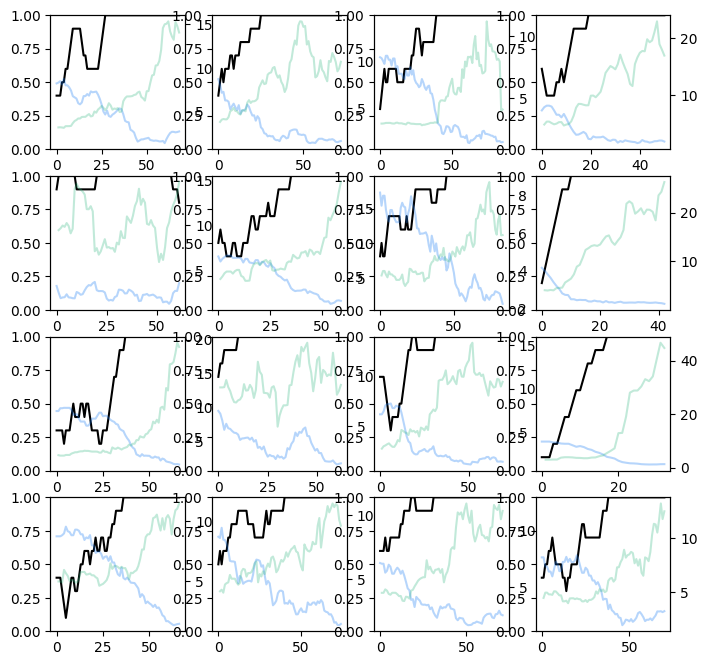

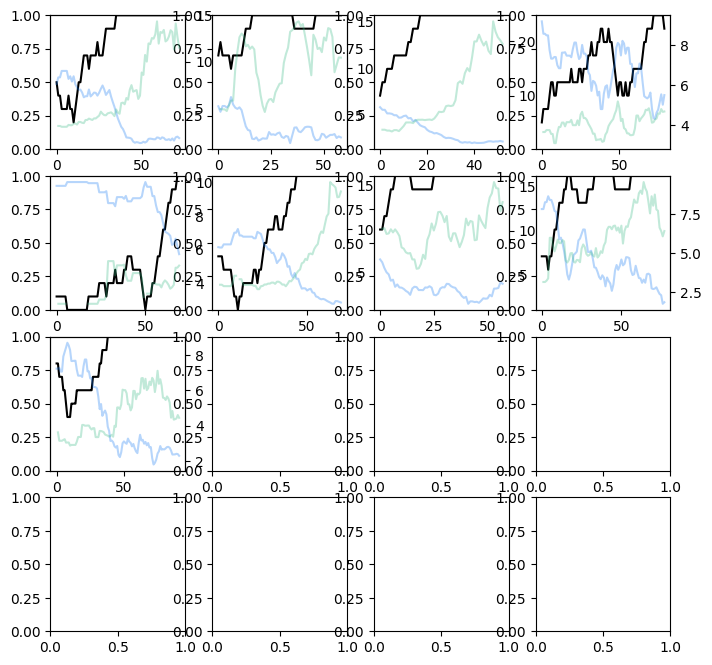

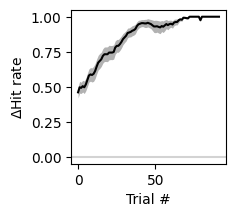

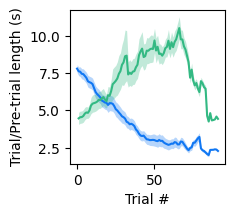

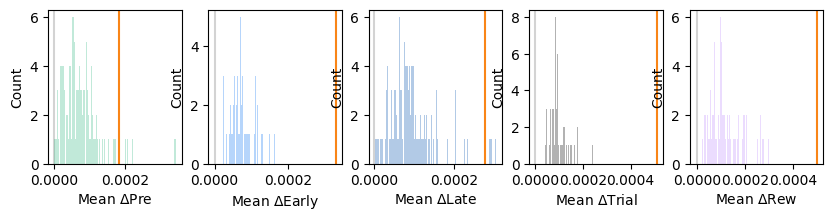

In [86]:
scan_idx = 0
n_trial_avg_window = 10

error_shading_mode = 'mse' # std, mse

n_max_trials_plot = 100
trial_avg_window = 1 / n_trial_avg_window * np.ones((n_trial_avg_window,))

n_bootstrap = 100 # 1st bootstrap idx is always actual CNs

mean_hit_rates_all = np.nan * np.ones((n_repeats, n_max_trials_plot)) # Averaged over 10 trials
trial_lens_all = np.nan * np.ones((n_repeats, n_max_trials_plot)) # Averaged over 10 trials
pretrial_lens_all = np.nan * np.ones((n_repeats, n_max_trials_plot)) # Averaged over 10 trials

fig0, axs0 = plt.subplots(4, 4, figsize=(8, 8))
ax_it = 0
for repeat_idx in range(n_repeats):

    task_hist = task_hists_all[repeat_idx]

    if len(task_hist['trial_outcomes']) < n_trial_avg_window:
        print('Not enough trials to plot.')
    else:
        mean_hit_rates = fftconvolve(task_hist['trial_outcomes'], trial_avg_window, mode='valid')

    n_trials_plot = min(mean_hit_rates.shape[0], n_max_trials_plot)
    mean_hit_rates_all[repeat_idx, :n_trials_plot] = mean_hit_rates[:n_trials_plot]
   
    ### Trial and pretrial lens ###
    start_idxs = task_hist['trial_starts']
    rew_idxs = bci_analysis.pad_rew_idxs(task_hist) # Adds nan pads to rew_idxs, should be same length as trial start idxs now

    trial_lens = np.array(rew_idxs) - np.array(start_idxs)
    trial_lens = np.where(np.isnan(trial_lens), 200, trial_lens) * 1/20 # nans become 10 seconds

    pretrial_lens = (np.array(start_idxs[1:]) - np.array(rew_idxs[:-1])) * 1/20 # nans are kept

    trial_lens_avg = []
    pretrial_lens_avg = [np.nan,] # start with nan to make this same length as trial_lens

    for trial_idx in range(n_trials_plot): # Already takes into account mean window size from above
        trial_lens_avg.append(np.mean(trial_lens[trial_idx:trial_idx+n_trial_avg_window]))
        if trial_idx > 0:
            pretrial_lens_avg.append(np.nanmean(pretrial_lens[trial_idx:trial_idx+n_trial_avg_window]))

    trial_lens_all[repeat_idx, :n_trials_plot] = trial_lens_avg
    pretrial_lens_all[repeat_idx, :n_trials_plot] = pretrial_lens_avg
            
    # ax4.plot(trial_lens_avg, color=c_vals_p['post_start_nopre'])
    # ax4.plot(pretrial_lens_avg, color=c_vals_p['pre_start'])


    ### Individual hit rate plots ###
    ax0 = axs0.flatten()[ax_it]
    ax0.plot(np.arange(n_trials_plot), mean_hit_rates_all[repeat_idx, :n_trials_plot], color='k')
    ax0.set_ylim((0.0, 1.0))
    
    ax0p = ax0.twinx() 
    ax0p.plot(trial_lens_avg, color=c_vals_p['post_start_nopre'], alpha=0.3, zorder=-5)
    ax0p.plot(pretrial_lens_avg, color=c_vals_p['pre_start'], alpha=0.3, zorder=-5)
    
    ax_it += 1
    if ax_it == 16: # New set of plots
        fig0, axs0 = plt.subplots(4, 4, figsize=(8, 8))
        ax_it = 0

### Mean hit rate plot ###
fig1, ax1 = plt.subplots(1, 1, figsize=(2, 2))

mean_hit_rate = np.nanmean(mean_hit_rates_all, axis=0)
std_hit_rate = np.nanstd(mean_hit_rates_all, axis=0)

if error_shading_mode == 'mse':
    std_hit_rate /= np.sqrt(n_repeats)

ax1.plot(np.arange(n_max_trials_plot), mean_hit_rate, color='k')
ax1.fill_between(np.arange(n_max_trials_plot), mean_hit_rate+std_hit_rate, mean_hit_rate-std_hit_rate, color='k',
                 alpha=0.3, zorder=-1, linewidth=0.)
ax1.axhline(0.0, color='lightgrey', zorder=-5)

ax1.set_xlabel('Trial #')
ax1.set_ylabel('$\Delta$Hit rate')

### Mean trial/pretrial lengths plot ###
fig4, ax4 = plt.subplots(1, 1, figsize=(2, 2))

mean_trial_lens = np.nanmean(trial_lens_all, axis=0)
std_trial_lens = np.nanstd(trial_lens_all, axis=0)
mean_pretrial_lens = np.nanmean(pretrial_lens_all, axis=0)
std_pretrial_lens = np.nanstd(pretrial_lens_all, axis=0)

if error_shading_mode == 'mse':
    std_trial_lens /= np.sqrt(n_repeats)
    std_pretrial_lens /= np.sqrt(n_repeats)

ax4.plot(np.arange(n_max_trials_plot), mean_trial_lens, color=c_vals_p['post_start_nopre'])
ax4.fill_between(np.arange(n_max_trials_plot), mean_trial_lens+std_trial_lens, mean_trial_lens-std_trial_lens, color=c_vals_p['post_start_nopre'],
                 alpha=0.3, zorder=-1, linewidth=0.)
ax4.plot(np.arange(n_max_trials_plot), mean_pretrial_lens, color=c_vals_p['pre_start'])
ax4.fill_between(np.arange(n_max_trials_plot), mean_pretrial_lens+std_pretrial_lens, mean_pretrial_lens-std_pretrial_lens, color=c_vals_p['pre_start'],
                 alpha=0.3, zorder=-1, linewidth=0.)

ax4.set_xlabel('Trial #')
ax4.set_ylabel('Trial/Pre-trial length (s)')

### Sparsity of change plots ###
fig2, ax2s = plt.subplots(1, 5, figsize=(10, 2))

c_vals_p['post_start'] = 'k'

ts_metrics = ('pre_start', 'post_start_nopre', 'pre_reward', 'post_start', 'post_reward',)
ts_metric_names = ('Pre', 'Early', 'Late', 'Trial', 'Rew')

print('Slope sparsity computation')
for ts_metric, ts_metric_name, ax in zip(ts_metrics, ts_metric_names, ax2s):
    
    ts_metric_slopes_bs = np.nan * np.ones((n_bootstrap, n_repeats))
    print(' {} bootstrap...'.format(ts_metric_name))
    
    for repeat_idx in range(n_repeats): # Slightly easier to run over repeats first, then normalization only happens once
        ts_metric_slopes = session_summaries[scan_idx][repeat_idx]['ts_extras'][ts_metric]['slope']
        
        for bs_idx in range(n_bootstrap):
            
            if bs_idx == 0:
                neuron_idx = cn_idxs[scan_idx, repeat_idx, 0]
            else:
                neuron_idx = np.random.randint(ts_metric_slopes.shape[0])
                
            ts_metric_slopes_bs[bs_idx, repeat_idx] = ts_metric_slopes[neuron_idx]
            
    ax.hist(np.mean(ts_metric_slopes_bs[1:, :], axis=-1), bins=100, color=c_vals_p[ts_metric], alpha=0.3)
    ax.axvline(np.mean(ts_metric_slopes_bs[0, :]), color=c_vals_p['cn'])
    ax.axvline(0.0, color='lightgrey', zorder=-5)
    
    ax.set_xlabel('Mean $\Delta${}'.format(ts_metric_name))
    ax.set_ylabel('Count')
    
if scan_type in ('bci_many_repeats',):
    
    fig3, ax3s = plt.subplots(1, 5, figsize=(10, 2))

    print('Pairwise predictivity computation')
    for ts_metric, ts_metric_name, ax in zip(ts_metrics, ts_metric_names, ax3s):

        ts_metric_pred_slopes_bs = np.nan * np.ones((n_bootstrap,))

        print(' {} bootstrap...'.format(ts_metric_name))

        for bs_idx in range(n_bootstrap):

            aggregate_corrs = []
            aggregate_slopes = []

            for repeat_idx in range(n_repeats): # Slightly easier to run over repeats first, then normalization only happens once
                if bs_idx == 0:
                    neuron_idx = cn_idxs[scan_idx, repeat_idx, 0]
                else:
                    neuron_idx = np.random.randint(pairwise_corrs[scan_idx][repeat_idx].shape[0])

                neuron_corrs = pairwise_corrs[scan_idx][repeat_idx][neuron_idx, :]
                ts_metric_slopes = session_summaries[scan_idx][repeat_idx]['ts_extras'][ts_metric]['slope']

                neuron_corrs = np.delete(neuron_corrs, neuron_idx)
                ts_metric_slopes = np.delete(ts_metric_slopes, neuron_idx)

                neuron_corrs = (neuron_corrs - np.mean(neuron_corrs)) / np.std(neuron_corrs) # z-score
                ts_metric_slopes = (ts_metric_slopes - np.mean(ts_metric_slopes)) / np.std(ts_metric_slopes) 

                aggregate_corrs.append(neuron_corrs)
                aggregate_slopes.append(ts_metric_slopes)

            aggregate_corrs = np.concatenate(aggregate_corrs, axis=0)
            aggregate_slopes = np.concatenate(aggregate_slopes, axis=0)

            slope, intercept, rvalue, pvalue, _ = linregress(aggregate_corrs, aggregate_slopes)

            ts_metric_pred_slopes_bs[bs_idx] = slope

        ax.hist(ts_metric_pred_slopes_bs[1:], bins=100, color=c_vals_p[ts_metric], alpha=0.3)
        ax.axvline(ts_metric_pred_slopes_bs[0], color=c_vals_p['cn'])
        ax.axvline(0.0, color='lightgrey', zorder=-5)

        ax.set_xlabel('Corr.-$\Delta${} slope'.format(ts_metric_name))
        ax.set_ylabel('Count')

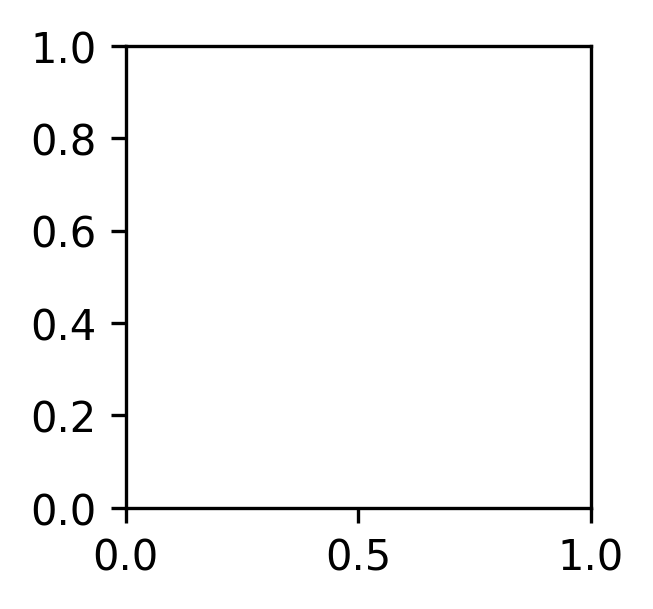

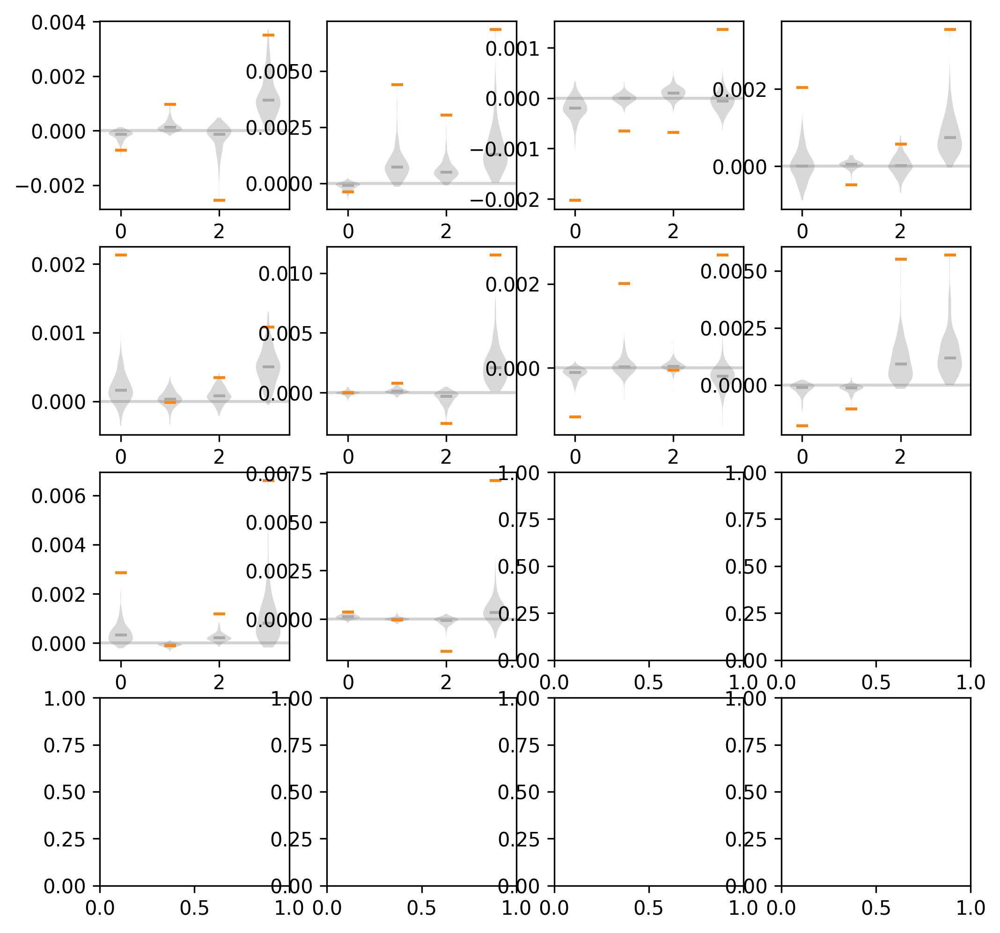

In [43]:
### Checks to see how each network learns based on distribution of weight changes
# relative to possible inputs.

fig6, ax6 = plt.subplots(1, 1, figsize=(2, 2))
fig7, ax7s = plt.subplots(4, 4, figsize=(8, 8))
ax_it = 0

stim_names = ('uniform', 'tone', 'reward', 'port move')
n_stims = 4

for repeat_idx in range(n_repeats):
   
    cn_idx = cn_idxs[scan_idx, repeat_idx, 0]
    ax7 = ax7s.flatten()[ax_it]
    
    ax7.axhline(0.0, color='lightgrey', zorder=-5)
    parts = ax7.violinplot(delta_W_inputs_all[scan_idx, repeat_idx], positions=np.arange(n_stims), showextrema=False)

    for pc in parts['bodies']:
        pc.set_facecolor('grey')
        
    ax7.scatter(np.arange(n_stims), np.median(delta_W_inputs_all[scan_idx, repeat_idx], axis=0), marker='_', color='darkgrey', zorder=5)
    ax7.scatter(np.arange(n_stims), delta_W_inputs_all[scan_idx, repeat_idx, cn_idx], marker='_', color=c_vals_p['cn'], zorder=5)


    ax_it+=1

##### Load and plot many

In [ ]:
load_path_base = '/content/drive/MyDrive/neuro_research/BCI/saved_nets/'
scan_type = 'bci_lr_scan'

if scan_type in ('bci_lr_scan',):
    seed = 2012
    n_scan = 10
    n_repeats = 5 #10
    scan_vals = np.logspace(-1, 1, n_scan)

load_path_base += scan_type

for scan_idx, scan_val in enumerate(scan_vals):
    for repeat_idx in range(n_repeats):

        repeat_seed = seed + repeat_idx
        local_load_path = load_path_base # save_path includes specifics about test
        local_load_path += '_scan_val{:.1e}'.format(scan_val)

        params_load, train_outputs_all_load, net_load, task_load, task_ps_load = net_helpers.load_run(local_load_path, repeat_seed)

##### Additional many net analysis

Analyze WMP/OMP for many networks

In [ ]:
start_train_reward = np.zeros((n_scan, n_repeats)) # This happens AFTER training starts to compare on equal footing to perturbation measures
pre_pert_reward = np.zeros_like(start_train_reward)
post_pert_reward = np.zeros_like(start_train_reward)
pre_pert_remove_reward = np.zeros_like(start_train_reward)
post_pert_remove_reward = np.zeros_like(start_train_reward)
end_train_reward = np.zeros_like(start_train_reward)

avg_window = 200

train_start_idx = task_params['n_steps_stabilize']
if task_params['perturbations'] is not None:
    pert_idx = task_params['perturbations'][0][0]
    pert_remove_idx = task_params['perturbations'][1][0]

for scan_idx in range(n_scan):
    for repeat_idx in range(n_repeats):
        start_train_reward[scan_idx, repeat_idx] = np.mean(
            full_rewards_plot[scan_idx, repeat_idx, train_start_idx:train_start_idx+avg_window],
        )
        pre_pert_reward[scan_idx, repeat_idx] = np.mean(
            full_rewards_plot[scan_idx, repeat_idx, pert_idx-avg_window:pert_idx],
        )
        post_pert_reward[scan_idx, repeat_idx] = np.mean(
            full_rewards_plot[scan_idx, repeat_idx, pert_idx:pert_idx+avg_window],
        )
        pre_pert_remove_reward[scan_idx, repeat_idx] = np.mean(
            full_rewards_plot[scan_idx, repeat_idx, pert_remove_idx-avg_window:pert_remove_idx],
        )
        post_pert_remove_reward[scan_idx, repeat_idx] = np.mean(
            full_rewards_plot[scan_idx, repeat_idx, pert_remove_idx:pert_remove_idx+avg_window],
        )
        end_train_reward[scan_idx, repeat_idx] = np.mean(
            full_rewards_plot[scan_idx, repeat_idx, -avg_window:],
        )

initial_train = pre_pert_reward - start_train_reward
pert_effect = post_pert_reward - pre_pert_reward
pert_train = pre_pert_remove_reward - post_pert_reward
pert_train_forget = post_pert_remove_reward - pre_pert_reward

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 3))

bp_quantities = np.concatenate((
    initial_train[:, np.newaxis, :],
    pert_effect[:, np.newaxis, :],
    pert_train[:, np.newaxis, :],
    pert_train_forget[:, np.newaxis, :],
), axis=1)

for scan_idx, scan_label in enumerate(('WMP (PC2 -> PC10)', 'OMP (PC2 -> PC80)')):
    scan_offset = -0.125 + 0.25 * scan_idx

    if scan_idx == 0:
        print('HARD CODE OF REMOVAL OF OUTLIER')
        bp_plot = np.delete(bp_quantities[scan_idx, :, :], 2, axis=-1)
    else:
        bp_plot = bp_quantities[scan_idx, :, :]

    bp = ax1.boxplot(bp_plot.T, patch_artist=True, notch=False,
                     positions=np.arange(4)+scan_offset, widths=0.2)
    for patch in bp['boxes']:
        patch.set_facecolor(c_vals[scan_idx])

    # ax1.scatter(0 * np.ones((n_repeats,)) + scan_offset, initial_train[scan_idx],
    #             color=c_vals[scan_idx], marker='.')
    # ax1.scatter(1 * np.ones((n_repeats,)) + scan_offset, pert_effect[scan_idx],
    #             color=c_vals[scan_idx], marker='.')
    # ax1.scatter(2 * np.ones((n_repeats,)) + scan_offset, pert_train[scan_idx],
    #             color=c_vals[scan_idx], marker='.')
    # ax1.scatter(3 * np.ones((n_repeats,)) + scan_offset, pert_train_forget[scan_idx],
    #             color=c_vals[scan_idx], marker='.')

    ax2.scatter(pert_effect[scan_idx], pert_train[scan_idx], color=c_vals[scan_idx], marker='.', label=scan_label)

    ax3.scatter(pert_train[scan_idx], pert_train_forget[scan_idx], color=c_vals[scan_idx], marker='.', label=scan_label)

ax1.set_xticks((0, 1, 2, 3))
ax1.set_xticklabels((
    'Init. Train',
    'Pert.',
    'Pert. Train',
    'Intrinsic\nfrom Pert.'
))

ax1.set_ylabel('$\Delta$R')

ax2.set_xlabel('$\Delta$R from Pert.')
ax2.set_ylabel('$\Delta$R over pert.')

ax3.set_xlabel('$\Delta$R from Pert.')
ax3.set_ylabel('$\Delta$R original mask')

for ax in (ax1, ax2, ax3):
    ax.axhline(0, color='grey', zorder=-5)
    ax.legend()

# ax1.set_ylim((-0.3, 0.3))
# ax3.set_ylim((-0.2, 0.2))

NameError: name 'full_rewards_plot' is not defined

Text(0.5, 0, 'BCI mask var. exp.')

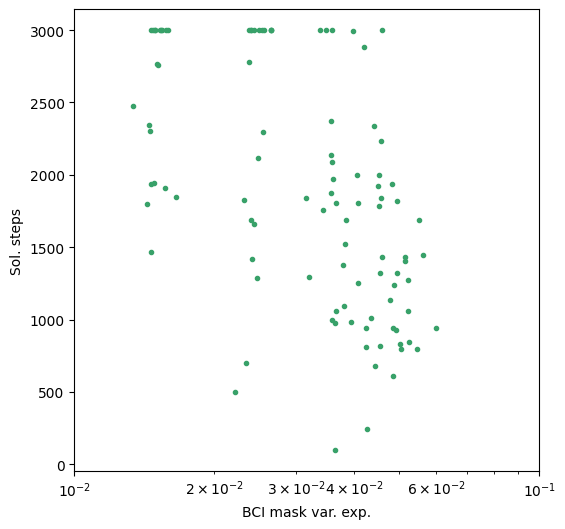

In [ ]:
fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))

ax1.scatter(bci_var_exps.reshape(-1), sol_steps.reshape(-1), marker='.', color=c_vals[2])

ax1.set_xlim((1e-2, 1e-1))
ax1.set_xscale('log')
ax1.set_ylabel('Sol. steps')
ax1.set_xlabel('BCI mask var. exp.')

Hebbian index plots

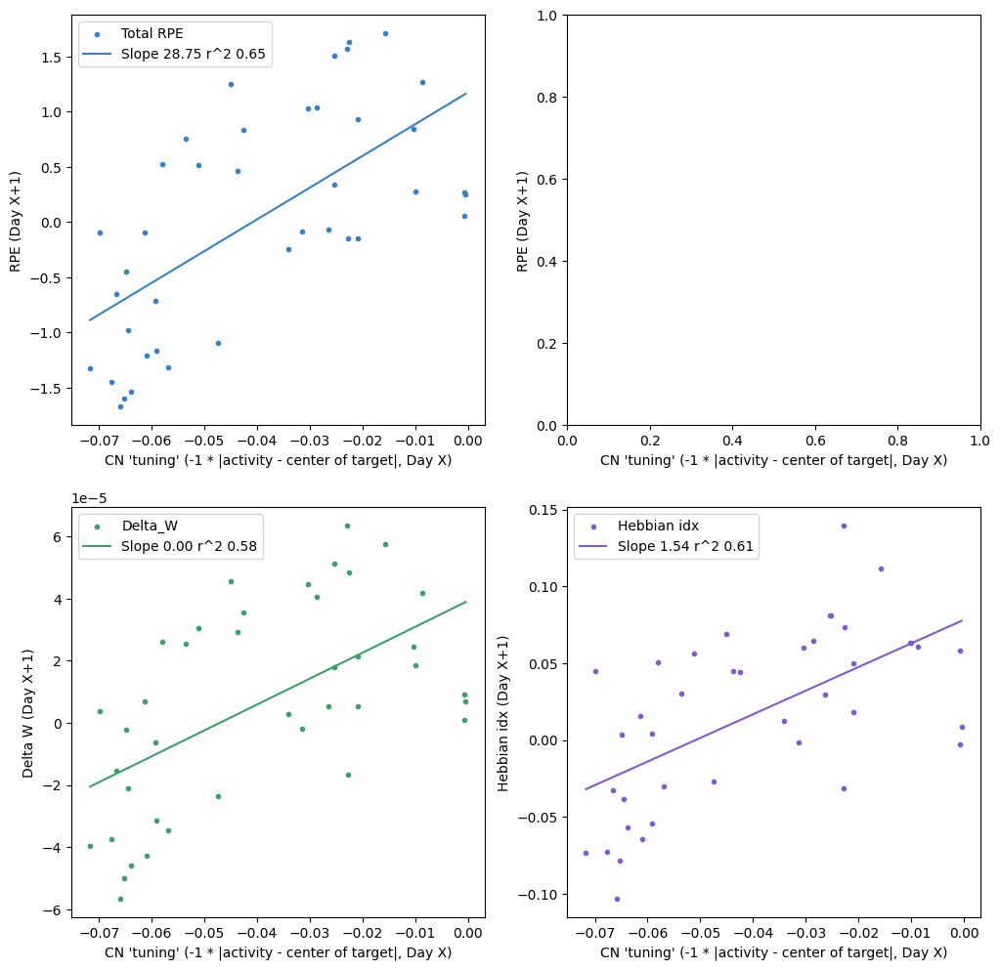

In [ ]:
def add_regression_line(x, y, ax=None, color='red', zorder=0):
    slope, intercept, rvalue, _, _ = linregress(x, y)
    x_plot = np.linspace(np.min(x), np.max(x), 10)
    y_plot = slope * x_plot + intercept
    label = 'Slope {:.2f} r^2 {:.2f}'.format(slope, rvalue)
    if ax is not None:
        ax.plot(x_plot, y_plot, color=color, zorder=zorder, label=label)

    return slope, intercept, rvalue

plot_type = 'full' # beginning_only, full

fig, ((ax1, ax2),(ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 12))

sum_to_idx = [40, 80, 120, 160, 200, 240, 280, 320, 360, 400]

plot_cmap = plt.get_cmap('viridis')

rpe_slopes = []
delta_W_rec_slopes = []
hebbian_idx_slopes = []

if plot_type in ('beginning_only',):

    fig2, ax5 = plt.subplots(1, 1, figsize=(6, 6))

    for idx_idx, idx in enumerate(sum_to_idx):
        local_RPE = np.zeros((n_repeats, n_sessions))
        total_RPE = np.zeros((n_repeats, n_sessions))
        local_delta_W = np.zeros((n_repeats, n_sessions))
        local_hebbian_idx = np.zeros((n_repeats, n_sessions))
        for repeat_idx in range(n_repeats):
            for session_idx in range(n_sessions):
                local_RPE[repeat_idx, session_idx] = np.sum(session_rpes_full[repeat_idx][session_idx][idx-40:idx])
                total_RPE[repeat_idx, session_idx] = np.sum(session_rpes_full[repeat_idx][session_idx])

                delta_W = W_recs_full[repeat_idx][session_idx][idx] - W_recs_full[repeat_idx][session_idx][idx-40]
                local_delta_W[repeat_idx, session_idx] = np.mean(delta_W)
                local_hebbian_idx[repeat_idx, session_idx] = local_hebbian_idxs_full[repeat_idx][session_idx][idx_idx]

                # if idx_idx != 0:
                #     continue

                # output_corrs = output_corrs_full[repeat_idx][session_idx]

                # output_corrs_flat = []
                # delta_W_rec_flat = []
                # for neuron_idx1 in range(output_corrs.shape[0]):
                #     for neuron_idx2 in range(output_corrs.shape[0]):
                #         if neuron_idx1 != neuron_idx2: # Skip diagonals
                #             if np.isnan(output_corrs[neuron_idx1, neuron_idx2]):
                #                 continue
                #             output_corrs_flat.append(output_corrs[neuron_idx1, neuron_idx2])
                #             delta_W_rec_flat.append(delta_W[neuron_idx1, neuron_idx2])

                # delta_W_rec_flat = delta_W_rec_flat / np.max(np.abs(delta_W_rec_flat)) # Normalizes so maximum is 1

                # local_hebbian_idx[repeat_idx, session_idx] = np.corrcoef(output_corrs_flat, delta_W_rec_flat)[0, 1]
                # corr_coef = np.corrcoef(output_corrs_sum, delta_W_rec_sum)[0, 1]

        if idx_idx == 0:
            ax1.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), local_RPE[:, 1:].reshape(-1), color=c_vals[0],
                        marker='.', label='Initial RPE (0 to 40)')
            _ = add_regression_line(cn_prev_tunings[0, :, 1:].reshape(-1), local_RPE[:, 1:].reshape(-1),
                                    ax1, color=c_vals[0], zorder=5)
            ax1.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), total_RPE[:, 1:].reshape(-1), color=c_vals[1],
                        marker='.', label='Total RPE')
            _ = add_regression_line(cn_prev_tunings[0, :, 1:].reshape(-1), total_RPE[:, 1:].reshape(-1),
                                    ax1, color=c_vals[1], zorder=5)
            ax3.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), local_delta_W[:, 1:].reshape(-1), color=c_vals[2],
                        marker='.', label='Initial delta_W (0 to 40)')
            _ = add_regression_line(cn_prev_tunings[0, :, 1:].reshape(-1), local_delta_W[:, 1:].reshape(-1),
                                    ax3, color=c_vals[2], zorder=5)
            ax4.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), local_hebbian_idx[:, 1:].reshape(-1), color=c_vals[3],
                        marker='.', label='Initial hebbian idx (0 to 40)')
            _ = add_regression_line(cn_prev_tunings[0, :, 1:].reshape(-1), local_hebbian_idx[:, 1:].reshape(-1),
                                    ax4, color=c_vals[3], zorder=5)
            # for repeat_idx in range(n_repeats):
            #     ax4.plot(cn_prev_tunings[0, repeat_idx, 1:], local_hebbian_idx[repeat_idx, 1:], color=c_vals[3],
            #              marker='.', alpha=0.3)

        ax2.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), local_RPE[:, 1:].reshape(-1), color=plot_cmap(idx/400),
                    marker='.', label='{} to {}'.format(idx-40, idx))

        rpe_slope, _, _ = add_regression_line(cn_prev_tunings[0, :, 1:].reshape(-1), local_RPE[:, 1:].reshape(-1),
                                            ax2, color=plot_cmap(idx/400), zorder=5)
        delta_W_rec_slope, _, _ = add_regression_line(cn_prev_tunings[0, :, 1:].reshape(-1), local_delta_W[:, 1:].reshape(-1))
        hebbian_idx_slope, _, _ = add_regression_line(cn_prev_tunings[0, :, 1:].reshape(-1), local_hebbian_idx[:, 1:].reshape(-1))

        rpe_slopes.append(rpe_slope)
        delta_W_rec_slopes.append(delta_W_rec_slope)
        hebbian_idx_slopes.append(hebbian_idx_slope)

    ax5.plot(sum_to_idx, rpe_slopes/np.max(rpe_slopes), color=c_vals[0], marker='.', label='RPE')
    ax5.plot(sum_to_idx, delta_W_rec_slopes/np.max(delta_W_rec_slopes), color=c_vals[2], marker='.', label='delta W')
    ax5.plot(sum_to_idx, hebbian_idx_slopes/np.max(hebbian_idx_slopes), color=c_vals[3], marker='.', label='Hebbian idx')
    ax5.axhline(0.0, color='k', linestyle='dashed', zorder=-5)

    ax5.set_xlabel('Training time (idxs)')
    ax5.set_ylabel('Tuning vs. X slope (normalized)')
    ax5.legend()

elif plot_type in ('full',):

    total_RPE = np.zeros((n_repeats, n_sessions))
    total_delta_W = np.zeros((n_repeats, n_sessions))

    for repeat_idx in range(n_repeats):
        for session_idx in range(n_sessions):
            total_RPE[repeat_idx, session_idx] = np.sum(session_rpes_full[repeat_idx][session_idx])
            delta_W = W_recs_full[repeat_idx][session_idx][-1] - W_recs_full[repeat_idx][session_idx][0]
            total_delta_W[repeat_idx, session_idx] = np.mean(delta_W)

    total_hebbian_idx = hebbian_idxs.reshape((-1, n_sessions))

    ax1.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), total_RPE[:, 1:].reshape(-1), color=c_vals[1],
                marker='.', label='Total RPE')
    _ = add_regression_line(cn_prev_tunings[0, :, 1:].reshape(-1), total_RPE[:, 1:].reshape(-1),
                            ax1, color=c_vals[1], zorder=5)
    ax3.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), total_delta_W[:, 1:].reshape(-1), color=c_vals[2],
                marker='.', label='Delta_W')
    _ = add_regression_line(cn_prev_tunings[0, :, 1:].reshape(-1), total_delta_W[:, 1:].reshape(-1),
                            ax3, color=c_vals[2], zorder=5)
    ax4.scatter(cn_prev_tunings[0, :, 1:].reshape(-1), total_hebbian_idx[:, 1:].reshape(-1), color=c_vals[3],
                marker='.', label='Hebbian idx')
    _ = add_regression_line(cn_prev_tunings[0, :, 1:].reshape(-1), total_hebbian_idx[:, 1:].reshape(-1),
                            ax4, color=c_vals[3], zorder=5)

ax1.set_xlabel('CN \'tuning\' (-1 * |activity - center of target|, Day X)')
ax1.set_ylabel('RPE (Day X+1)')
ax1.legend()

ax2.set_xlabel('CN \'tuning\' (-1 * |activity - center of target|, Day X)')
ax2.set_ylabel('RPE (Day X+1)')

ax3.set_xlabel('CN \'tuning\' (-1 * |activity - center of target|, Day X)')
ax3.set_ylabel('Delta W (Day X+1)')
ax3.legend()

ax4.set_xlabel('CN \'tuning\' (-1 * |activity - center of target|, Day X)')
ax4.set_ylabel('Hebbian idx (Day X+1)')
ax4.legend()


(-0.5, 1.5)

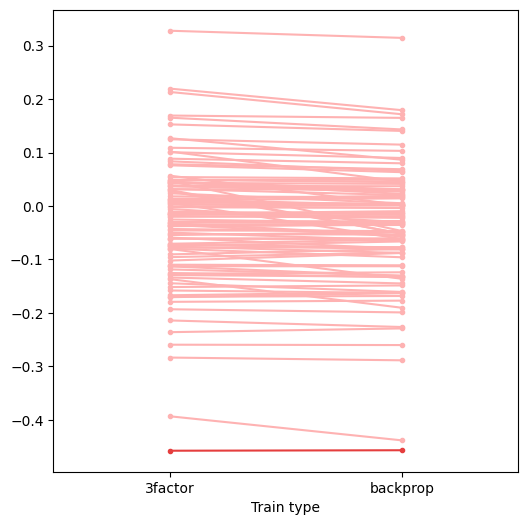

In [ ]:
fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))

delta_W_recs_flat = delta_W_recs[:, 0, :, :].reshape(2, -1)

delta_W_rec_into = np.sum(delta_W_recs[:, 0, :, :], axis=-1)

# for idx in range(delta_W_recs_flat.shape[-1]):
#     ax1.plot(np.array((0, 1)), delta_W_recs_flat[:, idx], marker='.')

cn_idx = cn_idxs[0, 0]
for idx in range(delta_W_rec_into.shape[-1]):
    if idx == cn_idx:
        color = c_vals[0]
    else:
        color = c_vals_l[0]
    ax1.plot(np.array((0, 1)), delta_W_rec_into[:, idx], marker='.', color=color)

ax1.set_xlabel('Train type')
ax1.set_xticks((0, 1))
ax1.set_xticklabels(scan_vals)
ax1.set_xlim((-0.5, 1.5))

#### Extra checks on toy setup

Saving/loading functions tests

In [ ]:
save_path_mode = 'raw_path' # '_seed{}.pkl' will always be added
save_path = '/content/drive/MyDrive/neuro_research/BCI/saved_nets/test_bci_activity'

session_idx = 0

# net_helpers.save_bci_activity(task_params, bci_activity[session_idx], save_path, path_mode=save_path_mode, overwrite=False, verbose=True)
net_helpers.save_bci_activity(task_params, train_outputs_all[session_idx]['bci_activity'],
                              task, save_path,
                              path_mode=save_path_mode, overwrite=False, verbose=True)

  File already exists at: /content/drive/MyDrive/neuro_research/BCI/saved_nets/test_bci_activity_seed22222.pkl
Override? (Y/N):Y
  Filename: /content/drive/MyDrive/neuro_research/BCI/saved_nets/test_bci_activity_seed22222.pkl


In [ ]:
load_path = '/content/drive/MyDrive/neuro_research/BCI/saved_nets/test_bci_activity'
task_params_load, bci_activity_load, task_load = net_helpers.load_bci_activity(load_path, 22222)

# Tuple of keys to check are the same between loaded task and current task
task_syncs = ('task_scale', 't_step', 'simple_states', 'noise_type', 'noise_timescale',
              'reward_mode', 'state_mode', 'stim_to_noise_ratio', 'add_fl',)
for task_sync in task_syncs:
    assert task_params[task_sync] == task_params_load[task_sync]

Can we reproduce output_fl from output?

In [ ]:
print(train_outputs_all[0]['output'].shape)
print(train_outputs_all[0]['output_fl'].shape)
print(train_outputs_all[0]['output_fl'][566, 22])

output_fl_reproduce = fftconvolve(train_outputs_all[0]['output'], task_params['fl_kernel'][:, np.newaxis], axes=(0,), mode='full')
output_fl_reproduce = output_fl_reproduce[:-task_params['fl_kernel'].shape[0] + 1]

print(output_fl_reproduce.shape)
print(output_fl_reproduce[566, 22])

Understand low-dimensional scaling

Done!


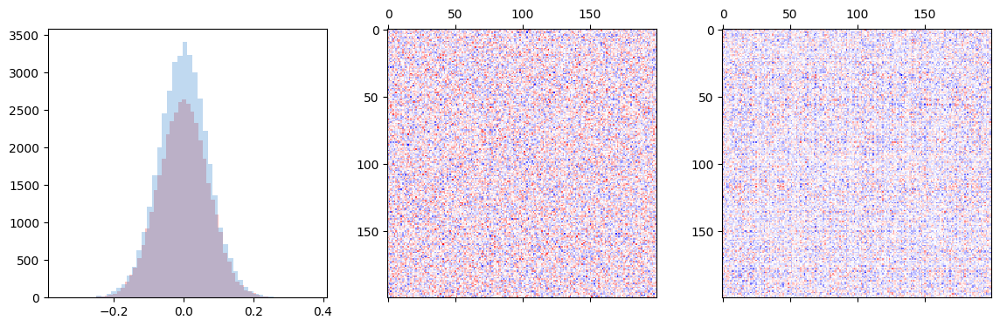

In [ ]:
n_neurons = 200
n_low_dim = 20

W = 1 / np.sqrt(n_neurons) * np.random.normal(size=(n_neurons, n_neurons))

W_1 = 1 / np.sqrt(n_neurons) * np.random.normal(size=(n_low_dim, n_neurons,))
W_2 = 1 / np.sqrt(n_low_dim) * np.random.normal(size=(n_neurons, n_low_dim,))

W_low = np.matmul(W_2, W_1)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))

ax1.hist(W.flatten(), color=c_vals[0], bins=50, alpha=0.3)
ax1.hist(W_low.flatten(), color=c_vals[1], bins=50, alpha=0.3)

ax2.matshow(W, cmap='bwr')
ax3.matshow(W_low, cmap='bwr')

print('Done!')

Make sure fluorescence convolution is working correctly

In [ ]:
task_params = {'t_step': 50}
task_params = fluorescence_init(task_params)

output = np.zeros((200, 1))
output[5, 0] = 1
output[45, 0] = 1
output[145, 0] = 1

fl_out = np.zeros_like(output)

for step_idx in range(output.shape[0]):
    n_steps_fl = np.minimum(step_idx, task_params['fl_kernel'].shape[0] - 1)
    fl_out[step_idx] = fluorescence_convolution(output[step_idx - n_steps_fl:step_idx+1], task_params, last_only=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.plot(task_params['fl_kernel'], color=c_vals[0])

ax2.plot(output, color=c_vals[1])
ax2.plot(fl_out, color=c_vals[2])

ax2.axvline(5 + task_params['fl_kernel'].shape[0], color='grey', zorder=-5)
ax2.axvline(45 + task_params['fl_kernel'].shape[0], color='grey', zorder=-5)

Make sure reward functions are behaving as expected

In [ ]:
target = np.array((0, 1,))
act1 = np.array((1, 1,))
act2 = np.array((1, 2,))
rew_scale = np.sqrt(2)

theta = 0.25
rot = np.array(((np.cos(theta), np.sin(theta)), (-1 * np.sin(theta), np.cos(theta))))

target = np.matmul(rot, target)
act1 = np.matmul(rot, act1)
act2 = np.matmul(rot, act2)

print('Target:', target)
print('Act1:', act1)
print('Act2:', act2)

print('Center-out:')
print(center_out_reward(act1, target, None, rew_scale * np.ones((2,)), 0.1))
print(center_out_reward(act2, target, None, rew_scale * np.ones((2,)), 0.1))
print('Quadratic:')
print(quadratic_reward(act1, target, None, rew_scale * np.ones((2,)), 0.1))
print(quadratic_reward(act2, target, None, rew_scale * np.ones((2,)), 0.1))

Target: [0.24740396 0.96891242]
Act1: [1.21631638 0.72150846]
Act2: [1.46372034 1.69042088]
Center-out:
-0.012499999999999994
-0.012499999999999995
Quadratic:
-0.012499999999999994
-0.02499999999999999


Quantification of the effective noise we are injecting into the network

Input - 	 mean: 0.04 std: 0.06
Hidden - 	 mean: 0.00 std: 0.06
stds - input 0.0578 hidden 0.0581 theory 0.0426


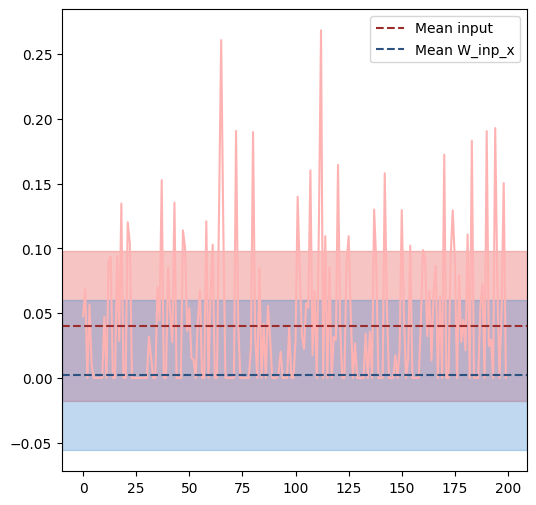

In [ ]:
task_scale = task_params['task_scale']

# Generate noise to drive the network
iid_noise = np.random.normal(scale=task_scale, size=(task_params['n_steps'], task_params['n_neurons'],))

W_inp = 1 / np.sqrt(task_params['n_inp']) * np.random.normal(size=(task_params['n_neurons'], task_params['n_inp']))

net_input = act_fn(iid_noise)

W_inp_x = np.matmul(W_inp, net_input.T).T

mean_input = np.mean(net_input)
std_input = np.mean(np.std(net_input, axis=0))

print('Input - \t mean: {:.2f} std: {:.2f}'.format(mean_input, std_input))

mean_hidden = np.mean(W_inp_x)
std_hidden = np.mean(np.std(W_inp_x, axis=0))

print('Hidden - \t mean: {:.2f} std: {:.2f}'.format(mean_hidden, std_hidden))

print('stds - input {:.4f} hidden {:.4f} theory {:.4f}'.format(
    std_input, std_hidden, 1/np.sqrt(2) * task_scale * np.sqrt(1 - 2 / np.pi)
))

fig, ax1 = plt.subplots(1, 1, figsize=(6, 6))

inp_idx = 5

ax1.plot(net_input[inp_idx], color=c_vals_l[0])

ax1.axhline(mean_input, color=c_vals_d[0], linestyle='dashed', label='Mean input')
ax1.axhspan(mean_input - std_input, mean_input + std_input, color=c_vals[0], alpha=0.3, zorder=-5)

ax1.axhline(mean_hidden, color=c_vals_d[1], linestyle='dashed', label='Mean W_inp_x')
ax1.axhspan(mean_hidden - std_hidden, mean_hidden + std_hidden, color=c_vals[1], alpha=0.3, zorder=-5)

ax1.legend()

Visualization on nonlinearity

Text(0, 0.5, 'Postsyn. elig. (dev * $\\phi^\\prime$)')

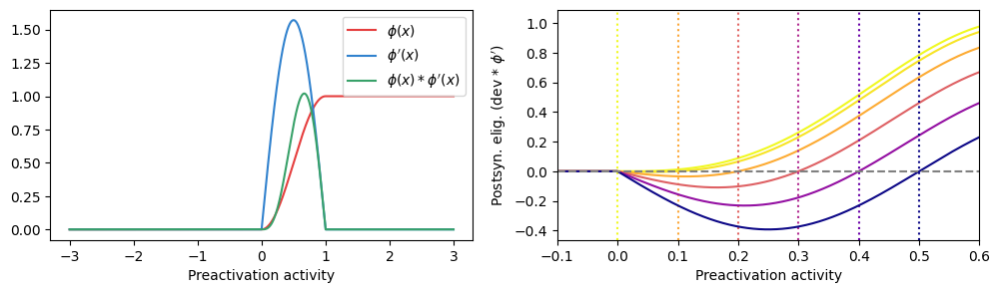

In [ ]:
xs = np.linspace(-3, 3, 5000)
act = act_fn(xs)
act_p = act_fn_p(xs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3))
ax1.plot(xs, act, color=c_vals[0], label='$\phi(x)$')
ax1.plot(xs, act_p, color=c_vals[1], label='$\phi^\prime(x)$')
ax1.plot(xs, act * act_p, color=c_vals[2], label='$\phi(x) * \phi^\prime(x)$')

ax1.set_xlabel('Preactivation activity')
ax1.legend()

mean_pre_acts = np.linspace(0, 0.5, 6)
mean_acts = act_fn(mean_pre_acts)

my_cmap = plt.get_cmap('plasma')

for mean_act, mean_pre_act in zip(mean_acts, mean_pre_acts):
    ax2.plot(xs, (act - mean_act)*act_p, color=my_cmap(1.0- mean_act / 0.5))
    # ax2.plot(xs, (act - mean_act), color=my_cmap(1.0- mean_act / 0.5))
    ax2.axvline(mean_pre_act, color=my_cmap(1.0- mean_pre_act / 0.5), linestyle='dotted')


ax2.set_xlim((-0.1, 0.6))
ax2.axhline(0.0, color='grey', linestyle='dashed')

ax2.set_xlabel('Preactivation activity')
ax2.set_ylabel('Postsyn. elig. (dev * $\phi^\prime$)')


State setting in Numpy

In [ ]:
np.random.seed(500)

print(np.random.rand())
print(np.random.rand())

np.random.seed(500)

print(np.random.rand())
random_state = np.random.get_state()

np.random.seed(3423423) # Try to override state with seed set

np.random.set_state(random_state)

print(np.random.rand())

### Nice Plots

In [19]:
plt.rcParams['figure.dpi'] = 300

# Arbitrary unit rescales to get nicer looking numbers
ACTIVITY_SCALE = 1e1
REWARD_SCALE = 1e2
WEIGHT_SCALE = 1e3

#### Fig 2: Toy BCI task

Exemplar plots. This should be run after a single network is trained. It will produce plots from that trained network

--- Session idx 0 ---


[Text(130, 0, '28'), Text(131, 0, ''), Text(132, 0, '30')]

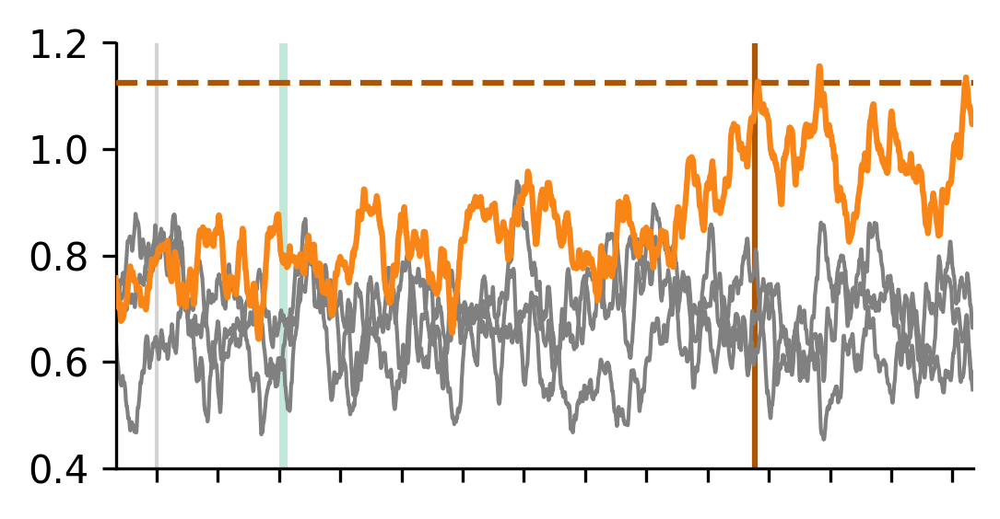

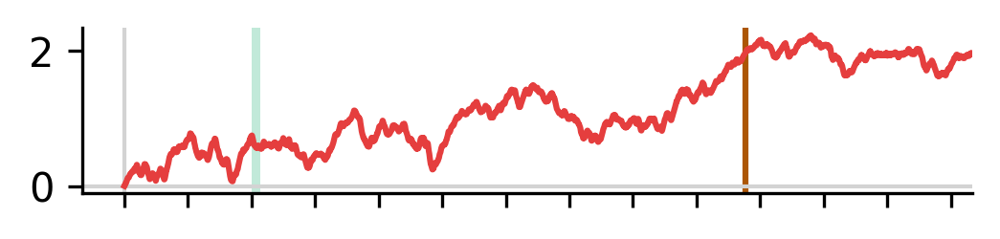

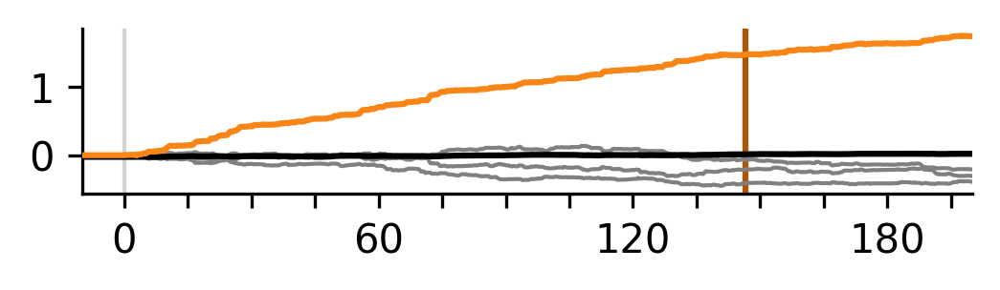

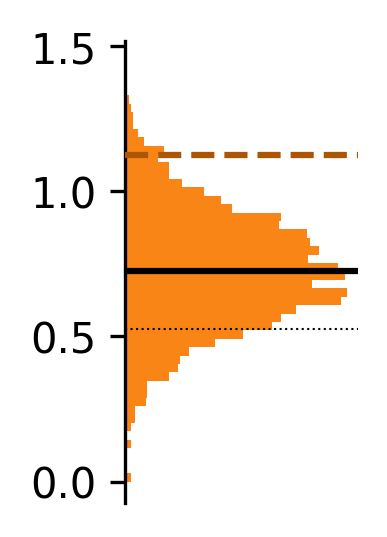

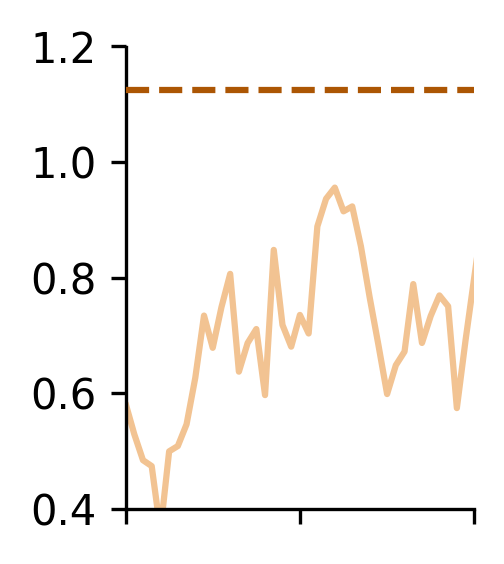

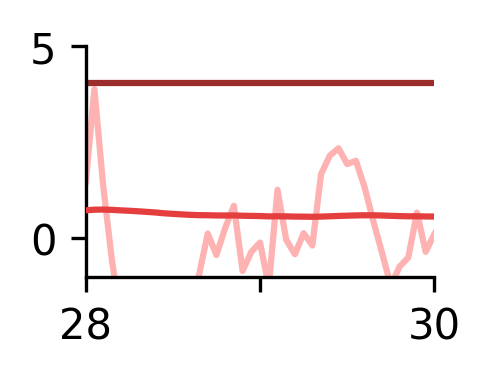

In [54]:
session_idx = 0
if session_idx >= task_params['n_sessions']:
    raise ValueError('Indexing session outside of range!')
print('--- Session idx {} ---'.format(session_idx))

task_params, train_params, net_params = params

n_neurons = task_params['n_neurons']
train_outputs = train_outputs_all[session_idx]

loss_steps = train_outputs['loss_steps']
steps = np.arange(task_params['n_steps'])
raw_steps = np.arange(task_params['n_steps']) # Has delay incorporated

x_axis_step_scale = task_params['t_step'] / 1000 # Convert from ms to s
x_axis_label = 'Time (s)'

x_axis = x_axis_step_scale * steps
x_axis_raw = x_axis_step_scale * raw_steps
x_axis_loss = x_axis_step_scale * np.array(loss_steps)

cn_idxs = train_outputs['cn_idxs']
bci_masks = train_outputs['bci_masks']
output = train_outputs['output']
avg_activity = train_outputs['avg_activity']

reward = train_outputs['reward']
avg_reward = train_outputs['avg_reward']
reward[:task_params['n_steps_stabilize']] = np.nan
avg_reward[:task_params['n_steps_stabilize']] = np.nan

# Offsets both avg_reward and reward by same amount
reward_shift = avg_reward[task_params['n_steps_stabilize']]
reward = reward - reward_shift
avg_reward = avg_reward - reward_shift

bci_activity = train_outputs['bci_activity'] # Not the same as matmul(output, bci_masks.T) when BCI masks change mid-session (perturbations)
avg_bci_activity = train_outputs['avg_bci_activity']

total_rpes = train_outputs['total_rpes']

sol_step = train_outputs['sol_step']

n_cells = 3
random_neuron_idxs = np.random.choice(task_params['n_neurons'], size=(n_cells,))

session_mean_activity = np.mean(avg_activity, axis=0)
sort_idxs = np.argsort(session_mean_activity)[::-1]
random_neuron_idxs = sort_idxs[16:16+n_cells]

if cn_idxs is not None:
    while any(rn_idx in cn_idxs for rn_idx in random_neuron_idxs) in random_neuron_idxs: # Ensures the random neuron idxs aren't the CNs
        random_neuron_idxs = np.random.choice(task_params['n_neurons'], size=(n_cells,))
    
fig1, ax1 = plt.subplots(1, 1, figsize=(4, 2)) # Exemplar activitivies vs. time
fig2, ax2 = plt.subplots(1, 1, figsize=(4, 0.75)) # Average reward vs. time
fig3, ax3 = plt.subplots(1, 1, figsize=(4, 0.75)) # Weight change vs. time

fig4, ax4 = plt.subplots(1, 1, figsize=(1, 2)) # Presession calibration plot

fig5, ax5 = plt.subplots(1, 1, figsize=(1.5, 2)) # Zoom in of CN activity
fig6, ax6 = plt.subplots(1, 1, figsize=(1.5, 1)) # Zoom in of reward

axs = (ax1, ax2, ax3)

# ax1.plot(x_axis, ACTIVITY_SCALE*output[:, cn_idxs[0]], color=c_vals_pl['cn'], label='CN activity')
ax1.plot(x_axis, ACTIVITY_SCALE*avg_activity[:, cn_idxs[0]], color=c_vals_p['cn'],  zorder=5, label='CN baseline')
        
ax1.axhline(ACTIVITY_SCALE*train_outputs['threshold'], color=c_vals_pd['cn'], zorder=3, linestyle='dashed')
# if task_params['width'] is not None:
#     ax1.axhline(train_outputs['threshold'] + task_params['width'], color=c_vals_d[2], linestyle='dashed')

# # Mean of all neuron's activity
# ax1.plot(x_axis, ACTIVITY_SCALE*np.mean(np.delete(avg_activity, cn_idxs[0], axis=-1), axis=-1), color='k', zorder=1)


for neuron_idx in random_neuron_idxs:
    ax1.plot(x_axis, ACTIVITY_SCALE*avg_activity[:, neuron_idx], color='grey', zorder=0, linewidth=1.)

# ax2.plot(x_axis_raw, REWARD_SCALE * reward, color=c_vals_l[0], label='Reward')
ax2.plot(x_axis, REWARD_SCALE * avg_reward, color=c_vals[0], label='Avg reward', zorder=6)
# ax2.scatter(x_axis_loss, total_rpes, color=c_vals_d[0], marker='.', label='Total RPEs', zorder=5)
# ax2.axhline(0.0, color='grey', linestyle='dashed', zorder=-3)

weight_change_x_axis = x_axis_loss

if net_params['W_inp_adjust']:
    W_type = net_params['W_inp_type']
    W_vals = train_outputs['W_inp_vals']
    ax3_label = 'W_inp'
elif net_params['W_rec_adjust']:
    W_type = net_params['W_rec_type']
    W_vals = train_outputs['W_rec_vals']
    ax3_label = '$\Delta$$W_{rec}$ (a.u.)'

delta_W_full = W_vals[1:] - W_vals[:-1]
delta_Ws = np.mean(delta_W_full, axis=(1, 2)) # Mean over inputs and outputs
if cn_idxs is not None:
    delta_Ws_nocn = np.mean(np.delete(W_vals, cn_idxs, axis=1)[1:] - np.delete(W_vals, cn_idxs, axis=1)[:-1], axis=(1, 2))

total_W_vals = np.mean(W_vals, axis=-1) # Mean over input
total_delta_W_vals = total_W_vals - total_W_vals[0]
    
# ax3.plot(weight_change_x_axis, WEIGHT_SCALE*total_W_vals[:, cn_idxs[0]], color=c_vals_p['cn'])
ax3.plot(weight_change_x_axis, WEIGHT_SCALE*total_delta_W_vals[:, cn_idxs[0]], color=c_vals_p['cn'], zorder=5)
ax3.plot(weight_change_x_axis, WEIGHT_SCALE*np.mean(np.mean(np.delete(W_vals, cn_idxs[0], axis=1), axis=1), axis=-1), color='k', zorder=1)
    
label = 'not CN examples'
for neuron_idx in random_neuron_idxs:
    # ax3.plot(weight_change_x_axis, WEIGHT_SCALE*total_W_vals[:, neuron_idx], color='grey', zorder=-5)
    ax3.plot(weight_change_x_axis, WEIGHT_SCALE*total_delta_W_vals[:, neuron_idx], color='grey', zorder=0, linewidth=1.)

show_trial_starts = False
TICK_START = 100
TICK_END = 300
x_ticks = np.arange(TICK_START, TICK_END, 15)
x_ticklabels = [int(x_tick-100) if (x_tick-100)%60 == 0 else None for x_tick in x_ticks]
for ax in axs:
    ax.axvline(x_axis_step_scale * task_params['n_steps_stabilize'], color='lightgrey', zorder=-5, linewidth=1.0)

    ax.axvline(x_axis_step_scale * (task_params['n_steps_stabilize'] + sol_step), color=c_vals_pd['cn'], zorder=-5)
    # print(x_axis_step_scale * sol_step)
    
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax.set_xlim((90, 300))
    ax.set_xticks(x_ticks)
    ax.set_xticklabels([])
    
    # Plot solution step
    # if sol_step is not None:
    #     ax.axvline(x_axis_step_scale * (sol_step + task_params['n_steps_stabilize']), color=c_vals[2], linestyle='dashed', zorder=-5)

# ax1.set_ylabel('Activity (a.u.)')
ax1.set_ylim((0.4, 1.2))    

# ax2.set_ylabel('Reward (a.u.)')
ax2.axhline(0.0, color='lightgrey', zorder=-5, linewidth=1.0)

ax3.axhline(0.0, color='lightgrey', zorder=-5, linewidth=1.0)    
ax3.set_xticklabels(x_ticklabels)
# ax3.set_xticklabels((0, None, None, None, 60, None, None, None, 120, None))   
# ax3.set_ylabel(ax3_label)
# ax3.set_xlabel('Train time (sec.)')

# ax4.plot(x_axis, avg_activity[:, cn_idxs[0]], color=c_vals_p['cn'],  zorder=5, label='CN baseline')

PRE_SES_START = 0 # Avoid making this too early to avoid stabilization period
PRE_SES_END = 100 

cn_pre_ses_activity = ACTIVITY_SCALE * output[int(PRE_SES_START / x_axis_step_scale):int(PRE_SES_END / x_axis_step_scale), cn_idxs[0]]

ax4.hist(cn_pre_ses_activity, 
         color=c_vals_p['cn'],  zorder=0, bins=50, orientation='horizontal')
# ax4.set_ylabel('CN activity (a.u.)')

ax4.axhline(ACTIVITY_SCALE * train_outputs['threshold'], color=c_vals_pd['cn'], zorder=3, linestyle='dashed')
ax4.axhline(np.mean(cn_pre_ses_activity), color='k', zorder=3, linestyle='solid')
ax4.axhline(np.mean(cn_pre_ses_activity) - np.std(cn_pre_ses_activity), color='k', zorder=3, linewidth=0.5, linestyle='dotted')
ax4.set_xticks([])
# ax4.set_xlim((40, 100))

ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.spines['bottom'].set_visible(False)

WINDOW_START = 12 #128 # Avoid making this too early to avoid stabilization period
WINDOW_END = 129 #130
for ax in (ax1, ax2,):
    ax.axvspan(WINDOW_START, WINDOW_END, color=c_vals_p['pre_start'], zorder=-10, alpha=0.3, linewidth=0.0)

ax5.plot(x_axis, ACTIVITY_SCALE * output[:, cn_idxs[0]], color=c_vals_pl['cn'], label='CN activity')
# ax5.plot(x_axis, ACTIVITY_SCALE * avg_activity[:, cn_idxs[0]], color=c_vals_p['cn'],  zorder=5, label='CN baseline')
ax5.axhline(ACTIVITY_SCALE * train_outputs['threshold'], color=c_vals_pd['cn'], zorder=3, linestyle='dashed')
ax5.set_ylim((0.4, 1.2))
# ax5.set_ylabel('CN activity (a.u.)')

ax6.plot(x_axis_raw, REWARD_SCALE*reward, color=c_vals_l[0], label='Reward')
ax6.plot(x_axis, REWARD_SCALE*avg_reward, color=c_vals[0], label='Avg reward', zorder=6)
ax6.set_ylim((-1, 5))
# ax6.set_ylabel('Reward (a.u.)')
ax6.axhline(REWARD_SCALE*-reward_shift, color=c_vals_d[0])

for ax in (ax5, ax6,):
    ax.set_xlim((WINDOW_START, WINDOW_END,))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # ax.set_xticks([WINDOW_START, WINDOW_START+1, WINDOW_START+2, WINDOW_START+3, WINDOW_START+4, WINDOW_START+5])
    ax.set_xticks([WINDOW_START, WINDOW_START+1, WINDOW_START+2,])
    ax.set_xticklabels([])

# ax6.set_xticklabels([20, None, None, None, None, 25])
ax6.set_xticklabels([28, None, 30])
# ax6.set_xlabel('Train time (sec.)')


In [57]:
bins[1:] - bins[:-1]

array([23.3380093, 23.3380093, 23.3380093, 23.3380093, 23.3380093,
       23.3380093, 23.3380093, 23.3380093, 23.3380093, 23.3380093,
       23.3380093, 23.3380093, 23.3380093, 23.3380093, 23.3380093,
       23.3380093, 23.3380093, 23.3380093, 23.3380093, 23.3380093])

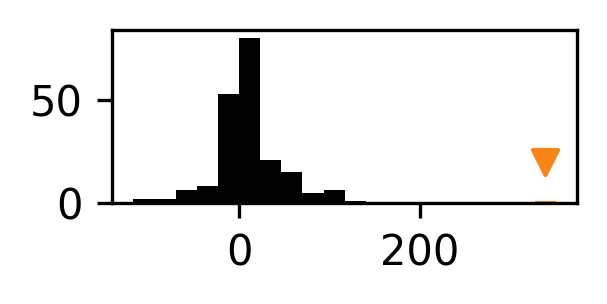

In [58]:
fig9, ax9 = plt.subplots(1, 1, figsize=(2, 0.75)) # Bin plot of total weight change sizes

tot_delta_W = WEIGHT_SCALE * np.sum(delta_W, axis=-1)

_, bins, _ = ax9.hist(tot_delta_W, bins=20, color='k')
ax9.hist(tot_delta_W[cn_idx], bins=bins, color=c_vals_p['cn'])

cn_bin_idx = np.digitize(tot_delta_W[cn_idx], bins) # Upper bound of bin
ax9.scatter(bins[cn_bin_idx-2] + 1/2 * (bins[1] - bins[0]), (20,), color=c_vals_p['cn'], marker='v')

/opt/conda/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/conda/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


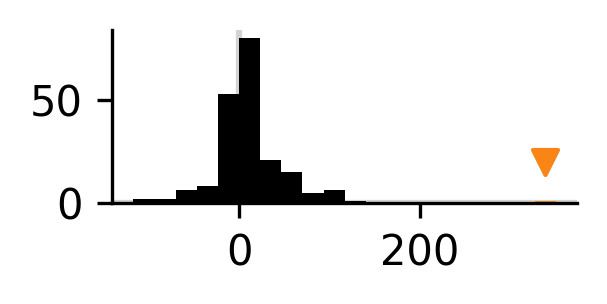

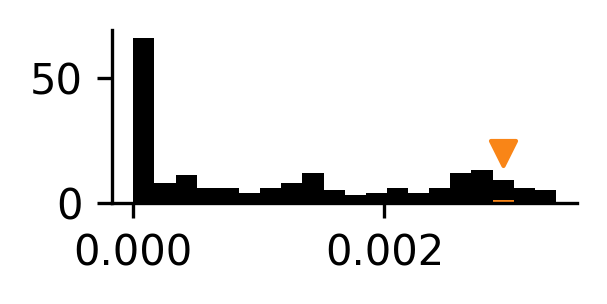

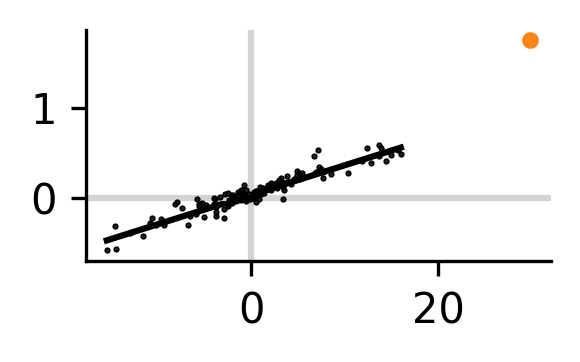

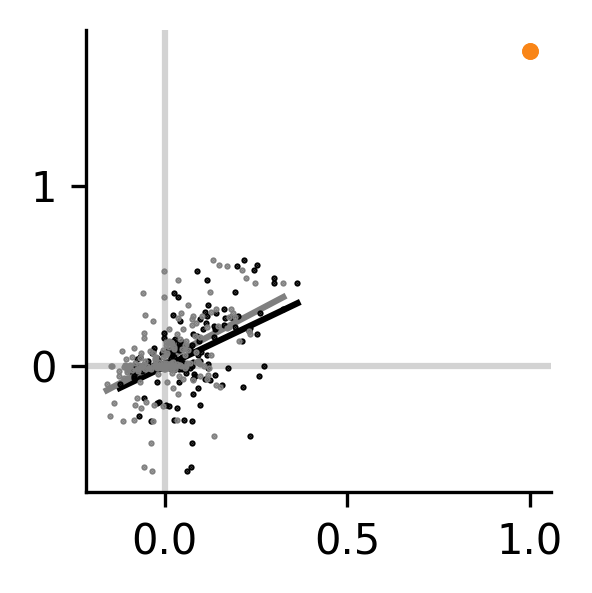

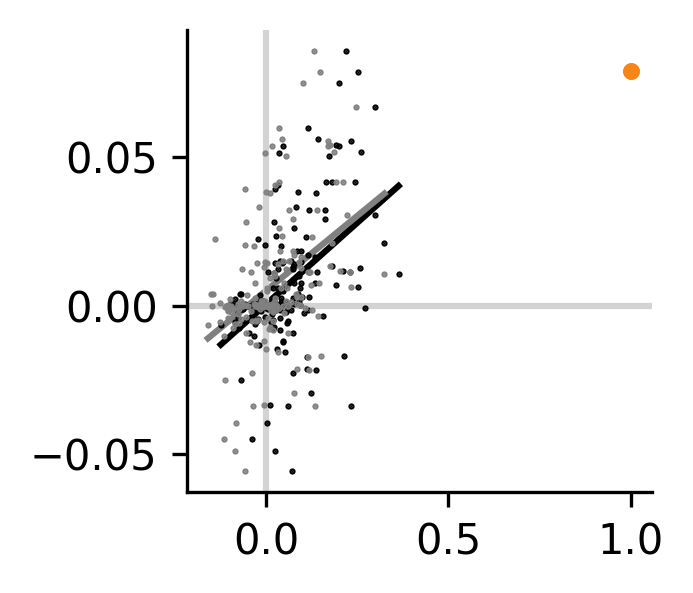

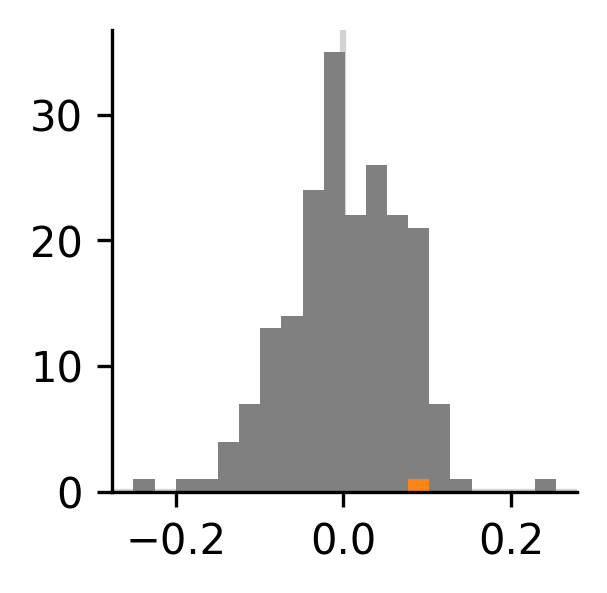

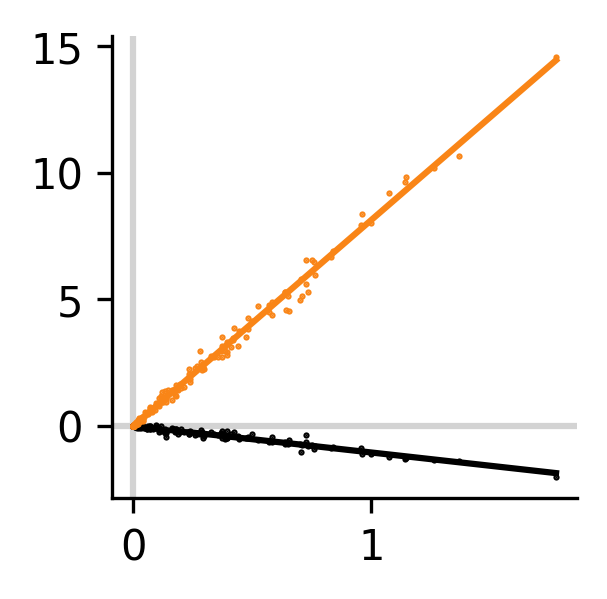

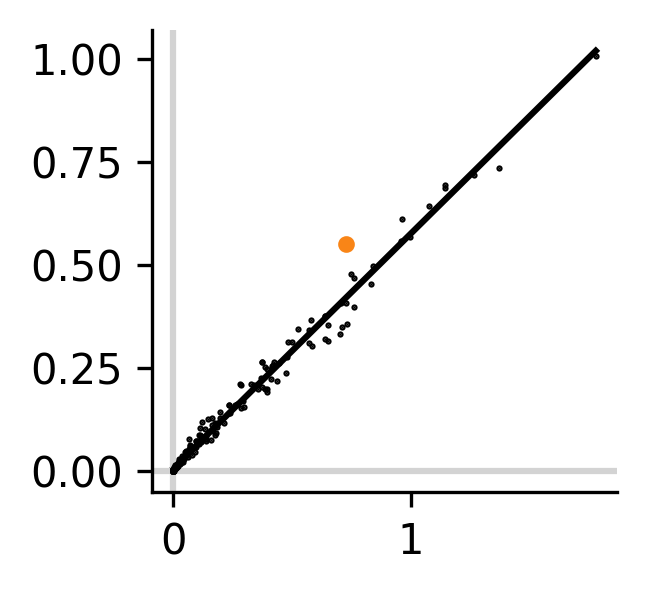

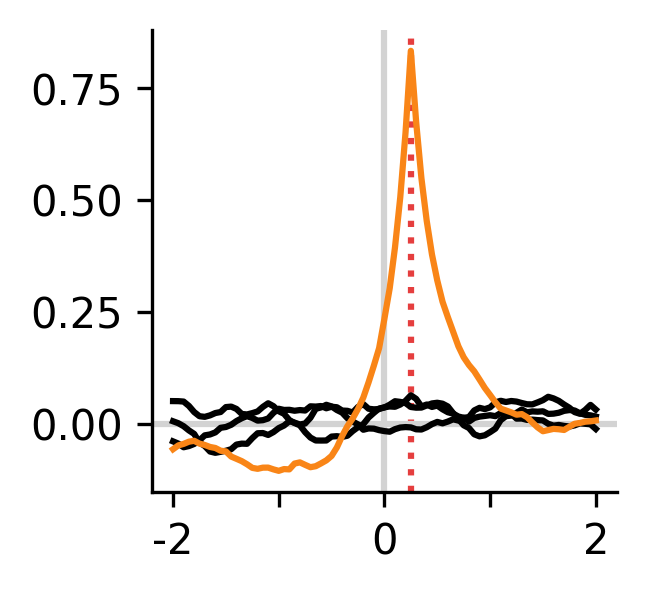

In [61]:
session_idx = 0

WEIGHT_SCALE = 1e3
RPE_DEV_SCALE = 1e2

train_outputs = train_outputs_all[session_idx]

reward = train_outputs['reward']
avg_reward = train_outputs['avg_reward']
reward_relevant_output = train_outputs['output']
avg_reward_relevant_output = train_outputs['avg_activity']

cn_idx = train_outputs['cn_idxs'][0]
n_neurons = net_params['n_neurons']

n_steps_stabilize = task_params['n_steps_stabilize']

if net_params['W_inp_adjust']:
    W_vals = train_outputs['W_inp_vals']
    if 'W_inp_elg_vals' in output_vars:
        W_elg = train_outputs['W_inp_elg_vals']
elif net_params['W_rec_adjust']:
    W_vals = train_outputs['W_rec_vals']
    if 'W_rec_elg_vals' in output_vars:
        W_elg = train_outputs['W_rec_elg_vals']

deviation_trunc = reward_relevant_output[n_steps_stabilize:] - avg_reward_relevant_output[n_steps_stabilize:]
# Note we account for the delay in the reward indexing here
rpe_trunc = reward[n_steps_stabilize:] - avg_reward[n_steps_stabilize:]
delta_W = W_vals[-1] - W_vals[0]

total_delta_W_in = np.mean(delta_W, axis=-1)
total_delta_W_in_no_cn = np.delete(total_delta_W_in, cn_idx)

rpe_dev_prod = np.matmul(rpe_trunc, deviation_trunc)

fig9, ax9 = plt.subplots(1, 1, figsize=(2, 0.75)) # Bin plot of total weight change sizes
fig1, ax1 = plt.subplots(1, 1, figsize=(2, 0.75)) # Bin plot of mean weight change sizes
fig2, ax2 = plt.subplots(1, 1, figsize=(2, 1)) # RPE-activity dev correlation vs change in weight
fig6, ax6 = plt.subplots(1, 1, figsize=(2, 2)) # Correlation with CN (before training) vs. change in weight
fig7, ax7 = plt.subplots(1, 1, figsize=(2, 2)) # Correlation with CN (before training) vs. change in activity
fig8, ax8 = plt.subplots(1, 1, figsize=(2, 2)) # Is the CN special, i.e. does it have a better fit slope for ax7 than all other neurons?
fig3, ax3 = plt.subplots(1, 1, figsize=(2, 2)) # Change in weight vs. presynaptic activity
fig5, ax5 = plt.subplots(1, 1, figsize=(2, 2)) # Cross correlation of deviations with RPE
fig4, ax4 = plt.subplots(1, 1, figsize=(2, 2)) # Cross correlation of deviations with RPE

tot_delta_W = WEIGHT_SCALE * np.sum(delta_W, axis=-1)

_, bins, _ = ax9.hist(tot_delta_W, bins=20, color='k')
ax9.hist(tot_delta_W[cn_idx], bins=bins, color=c_vals_p['cn'])
cn_bin_idx = np.digitize(tot_delta_W[cn_idx], bins) # Upper bound of bin
ax9.scatter(bins[cn_bin_idx-2] + 1/2 * (bins[1] - bins[0]), (20,), color=c_vals_p['cn'], marker='v')

delta_W_in_all = WEIGHT_SCALE * (np.mean(W_vals, axis=-1)[1:] - np.mean(W_vals, axis=-1)[:-1])

_, bins, _ = ax1.hist(np.mean(np.abs(delta_W_in_all), axis=0), bins=20, color='k')
ax1.hist(np.mean(np.abs(delta_W_in_all), axis=0)[cn_idx], bins=bins, color=c_vals_p['cn'])
cn_change = np.mean(np.abs(delta_W_in_all), axis=0)[cn_idx]
cn_bin_idx = np.digitize(cn_change, bins) # Upper bound of bin
ax1.scatter(1/2 * (bins[cn_bin_idx-1] + bins[cn_bin_idx]), (20,), color=c_vals_p['cn'], marker='v')
# ax1.scatter(np.mean(np.abs(delta_W_in_all), axis=0)[cn_idx], (20,), color=c_vals_p['cn'], marker='v')
# _ = ax1.hist(np.mean(np.abs(delta_W_in_all), axis=0)[cn_idx], bins=bins, color=c_vals_p['cn'])

ax2.scatter(RPE_DEV_SCALE * rpe_dev_prod, WEIGHT_SCALE * total_delta_W_in, marker='.', color='k', s=1.0)
ax2.scatter(RPE_DEV_SCALE * rpe_dev_prod[cn_idx], WEIGHT_SCALE * total_delta_W_in[cn_idx], marker='.', color=c_vals_p['cn'])
# Fit without CN
_ = add_regression_line(np.delete(RPE_DEV_SCALE * rpe_dev_prod, cn_idx), WEIGHT_SCALE * total_delta_W_in_no_cn, ax=ax2, color='k', zorder=-5)

# Note these are both measured prior to any training, unlike the deviations in the above plot
cn_dev_corrs = np.corrcoef((reward_relevant_output[:n_steps_stabilize] - avg_reward_relevant_output[:n_steps_stabilize]).T)[cn_idx]
cn_activity_corrs = np.corrcoef(reward_relevant_output[:n_steps_stabilize].T)[cn_idx]

ax6.scatter(cn_dev_corrs, WEIGHT_SCALE * total_delta_W_in, marker='.', color='k', s=1.0)
ax6.scatter(cn_dev_corrs[cn_idx], WEIGHT_SCALE * total_delta_W_in[cn_idx], marker='.', color=c_vals_p['cn'])
_ = add_regression_line(np.delete(cn_dev_corrs, cn_idx), WEIGHT_SCALE * total_delta_W_in_no_cn, ax=ax6, color='k', zorder=-5)
ax6.scatter(cn_activity_corrs, WEIGHT_SCALE * total_delta_W_in, marker='.', color='grey', s=1.0)
ax6.scatter(cn_activity_corrs[cn_idx], WEIGHT_SCALE * total_delta_W_in[cn_idx], marker='.', color=c_vals_p['cn'])
_ = add_regression_line(np.delete(cn_activity_corrs, cn_idx), WEIGHT_SCALE * total_delta_W_in_no_cn, ax=ax6, color='grey', zorder=-5)

output_train = reward_relevant_output[task_params['n_steps_stabilize']:task_params['n_steps']-task_params['n_steps_evaluate']]
neuron_changes = np.zeros((n_neurons,)) # Activity change per minute
train_steps = 1/60 * x_axis_step_scale * np.arange(output_train.shape[0]) # 1/60 for sec -> min
for neuron_idx in range(n_neurons):
    slope, _, _, _, _ = linregress(train_steps, output_train[:, neuron_idx])
    neuron_changes[neuron_idx] = slope

ax7.scatter(cn_dev_corrs, ACTIVITY_SCALE * neuron_changes, marker='.', color='k', s=1.0)
ax7.scatter(cn_dev_corrs[cn_idx], ACTIVITY_SCALE * neuron_changes[cn_idx], marker='.', color=c_vals_p['cn'])
_ = add_regression_line(np.delete(cn_dev_corrs, cn_idx), ACTIVITY_SCALE * np.delete(neuron_changes, cn_idx), ax=ax7, color='k', zorder=-5)
ax7.scatter(cn_activity_corrs, ACTIVITY_SCALE * neuron_changes, marker='.', color='grey', s=1.0)
ax7.scatter(cn_activity_corrs[cn_idx], ACTIVITY_SCALE * neuron_changes[cn_idx], marker='.', color=c_vals_p['cn'])
_ = add_regression_line(np.delete(cn_activity_corrs, cn_idx), ACTIVITY_SCALE * np.delete(neuron_changes, cn_idx), ax=ax7, color='grey', zorder=-5)

activity_corrs = np.corrcoef(reward_relevant_output[:n_steps_stabilize].T)
activity_corrs = np.where(np.isnan(activity_corrs), 0., activity_corrs)

correlation_activity_prediction = np.zeros((n_neurons,))
for neuron_idx in range(n_neurons):
    if np.std(activity_corrs[neuron_idx]) == 0.:
        correlation_activity_prediction[neuron_idx] = 0.
    else:
        slope, _, _, _, _ = linregress(np.delete(activity_corrs[neuron_idx], neuron_idx), ACTIVITY_SCALE * np.delete(neuron_changes, neuron_idx))
        # slope, _, _, _, _ = linregress(np.delete(activity_corrs[neuron_idx], neuron_idx), WEIGHT_SCALE * np.delete(total_delta_W_in, neuron_idx))
        correlation_activity_prediction[neuron_idx] = slope

_, bins, _ = ax8.hist(correlation_activity_prediction, bins=20, color='grey')
ax8.hist(correlation_activity_prediction[cn_idx], bins=bins, color=c_vals_p['cn'])

mean_activity = np.mean(ACTIVITY_SCALE * reward_relevant_output[:n_steps_stabilize, :], axis=0) # Stablilize
# mean_activity = np.mean(ACTIVITY_SCALE * reward_relevant_output[n_steps_stabilize:, :], axis=0) # Post stablilize
 
neuron_idx = cn_idx + 10
neuron_idx = np.argsort(total_delta_W_in)[10]

ax3.scatter(mean_activity, WEIGHT_SCALE * delta_W[cn_idx], marker='.', color=c_vals_p['cn'], s=1.0, zorder=5)
ax3.scatter(mean_activity, WEIGHT_SCALE * delta_W[neuron_idx], marker='.', color='k', s=1.0)
# ax3.set_xscale('log')

_ = add_regression_line(mean_activity, WEIGHT_SCALE * delta_W[cn_idx], ax=ax3, color=c_vals_p['cn'], zorder=-5)
_ = add_regression_line(mean_activity, WEIGHT_SCALE * delta_W[neuron_idx], ax=ax3, color='k', zorder=-5)

ax5.scatter(mean_activity, WEIGHT_SCALE * np.mean(np.abs(delta_W), axis=0), marker='.', color='k', s=1.0)
ax5.scatter(mean_activity[cn_idx], WEIGHT_SCALE * np.mean(np.abs(delta_W), axis=0)[cn_idx], marker='.', color=c_vals_p['cn'])
# ax5.set_xscale('log')

_ = add_regression_line(mean_activity, WEIGHT_SCALE * np.mean(np.abs(delta_W), axis=0), ax=ax5, color='k', zorder=-5)


n_offsets = 40 # On either side of zero
offsets = np.arange(-n_offsets, n_offsets+1)

n_os = offsets.shape[0]
cross_corrs = np.nan * np.ones((n_neurons, n_os))

for neuron_idx in range(n_neurons):
    for os_idx, offset in enumerate(offsets):
        if offset > 0:
            rpes = rpe_trunc[offset:]
            devs = deviation_trunc[:-offset, neuron_idx]
        elif offset < 0:
            rpes = rpe_trunc[:offset]
            devs = deviation_trunc[-offset:, neuron_idx]
        else:
            rpes = rpe_trunc[:]
            devs = deviation_trunc[:, neuron_idx]
        cross_corrs[neuron_idx, os_idx] = np.corrcoef(devs, rpes)[0, 1]

ax4.plot(offsets, cross_corrs[cn_idx], color=c_vals_p['cn'], zorder=5)
ax4.plot(offsets, cross_corrs[cn_idx+5], color='k')
ax4.plot(offsets, cross_corrs[cn_idx+6], color='k')
ax4.plot(offsets, cross_corrs[cn_idx+7], color='k')

ax4.axvline(task_params['n_reward_delay'], color=c_vals[0], zorder=-5, linestyle='dotted')

ax4.set_xticks((-40, -20, 0, 20, 40,))
ax4.set_xticklabels((-2, None, 0, None, 2))

# ax4.set_xlabel('Time offset (sec.)')
# ax4.set_ylabel('Correlation')

for ax in (ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9,):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
for ax in (ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9,):
    ax.axhline(0.0, color='lightgrey', zorder=-5)    
    ax.axvline(0.0, color='lightgrey', zorder=-5)    
    

This needs to be run after various scans

In [16]:
print(np.repeat(scan_vals_2[:, None], n_repeats, axis=-1).shape)
print(sol_steps[n_plots:].shape)

(7, 10)
(7, 10)


r^2: 0.32 slope 2.8e+02 (p: 3.6e-16)
r^2: 0.45 slope 7.3e+01 (p: 5.2e-24)


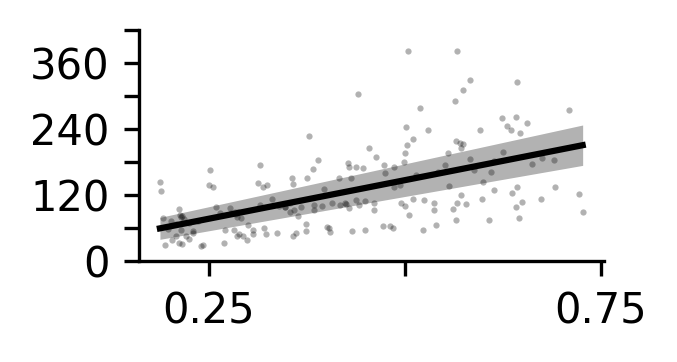

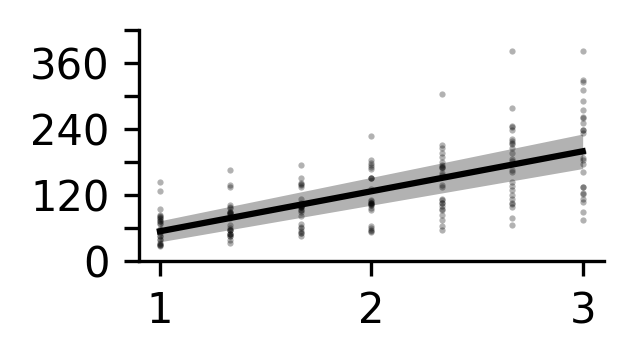

In [25]:
from matplotlib.colors import LinearSegmentedColormap

REWARD_SCALE = 1e3
ACTIVITY_SCALE = 1e1

if scan_type in ('toy_param_scan_lr',):
    fig1, ax1 = plt.subplots(1, 1, figsize=(2, 2))
    
    delta_total_rewards = total_rewards[1:] - total_rewards[0]
    delta_total_rewards = np.where(delta_total_rewards < 0, 0., delta_total_rewards)
    cmap = LinearSegmentedColormap.from_list("", [c_vals_p['post_start_nopre'], c_vals_p['pre_start']])
    
    scan_vals_plot = scan_vals[1:]
    
    # ax1.plot(np.log10(scan_vals_plot), np.mean(delta_total_rewards, axis=-1))
    
    rew_bp = ax1.boxplot(delta_total_rewards.T, patch_artist=True, notch=False, positions=np.log10(scan_vals_plot),
                         widths=0.25, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                         boxprops={'linewidth':0.})
    
    for idx, patch in enumerate(rew_bp['boxes']):
        patch.set_facecolor(cmap(idx / (n_plots-1)))
        patch.set_edgecolor(None)
        
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    
    ax1.set_xticks((0, 1, 2, 3))
    ax1.set_xticklabels(('$10^{0}$', None, None, '$10^{3}$',))
elif scan_type in ('toy_param_scan_n_neurons',): # Separate from above because this has additional delta W analysis
    n_plots = int(n_scan / 2)

    fig1, ax1 = plt.subplots(1, 1, figsize=(2, 2))
    fig2, ax2 = plt.subplots(1, 1, figsize=(2, 2))
    
    delta_reward_rate = REWARD_SCALE * (total_rewards[n_plots:] - total_rewards[:n_plots]) / (task_params['n_steps'] - task_params['n_steps_stabilize'])

    z_scored_cn = np.zeros((n_plots, n_repeats))

    for plot_idx in range(n_plots):
        scan_idx = plot_idx + n_plots # Only second half are relevant

        for repeat_idx in range(n_repeats):
            mean_delta_W = np.mean(total_delta_Ws[scan_idx][repeat_idx])
            std_delta_W = np.std(total_delta_Ws[scan_idx][repeat_idx])
            cn_idx = cn_idxs[scan_idx, repeat_idx, 0]

            z_scored_cn[plot_idx, repeat_idx] = (
                (total_delta_Ws[scan_idx][repeat_idx, cn_idx] - mean_delta_W) / std_delta_W
            )
    
    cmap = LinearSegmentedColormap.from_list("", [c_vals_p['post_start_nopre'], c_vals_p['pre_start']])
    rew_bp = ax1.boxplot(delta_reward_rate.T, patch_artist=True, notch=False, positions=np.arange(n_plots),
                         widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                         boxprops={'linewidth':0.})
    for idx, patch in enumerate(rew_bp['boxes']):
        patch.set_facecolor(cmap(idx / (n_plots-1)))
        patch.set_edgecolor(None)

    cmap = LinearSegmentedColormap.from_list("", [c_vals_pl['cn'], c_vals_pd['cn']])
    sparsity_bp = ax2.boxplot(z_scored_cn.T, patch_artist=True, notch=False, positions=np.arange(n_plots),
                              widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                              boxprops={'linewidth':0.})
    for idx, patch in enumerate(sparsity_bp['boxes']):
        patch.set_facecolor(cmap(idx / (n_plots-1)))
        patch.set_edgecolor(None)
    
    ax1.set_ylim((0, 4.0))
    ax1.axhline(0.0, color='grey', zorder=-5)
    ax2.axhline(0.0, color='grey', zorder=-5)

    # ax1.set_ylabel('Reward rate')
    # ax2.set_ylabel('CN activity change (z-score)')

    for ax in (ax1, ax2):
        ax.set_xticks(np.arange(n_plots))
        ax.set_xticklabels([10, None, None, None, None, None, 500,])
        # ax.set_xlabel('# hidden neurons')    
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

elif scan_type in ('compare_masks_cn_perc', 'compare_masks_pcs',):
    fig1, ax1 = plt.subplots(1, 1, figsize=(2, 2))
    fig3, ax3 = plt.subplots(1, 1, figsize=(2, 2))

    axs = (ax1, ax3)
    cmap = LinearSegmentedColormap.from_list("", [c_vals_p['post_start_nopre'], c_vals_p['pre_start']])

    if scan_type in ('compare_masks_cn_perc',):
        x_ticks = ('100', '80', '60', '40', '20',)
        x_ticks = ('100', None, None, None, '20',)
        # x_label = 'CN pre-training activity percentile'
    elif scan_type in ('compare_masks_pcs',):
        x_ticks = ('2', '3', '5', '10', '20', '50', '100')
        # x_label = 'BCI mask type'

    n_plots = int(n_scan/2)

    reward_rate_all = total_rewards / (
        task_params['n_steps'] - task_params['n_steps_stabilize']
    )

    reward_rate = reward_rate_all[::2]
    reward_baseline = reward_rate_all[1::2]

    delta_reward_rate = REWARD_SCALE * (reward_rate - reward_baseline)
    delta_reward_rate = np.where(delta_reward_rate < 0, np.nan, delta_reward_rate)

    # Handle nan filtering by converting to list
    delta_reward_rate = delta_reward_rate.T
    mask = ~np.isnan(delta_reward_rate)
    delta_reward_rate = [d[m] for d, m in zip(delta_reward_rate.T, mask.T)]

    rew_bp = ax1.boxplot(delta_reward_rate, patch_artist=True, notch=False, positions=np.arange(n_plots),
                         widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                         boxprops={'linewidth':0.})
    # rew_baseline_bp = ax1.boxplot(reward_baseline.T, patch_artist=True, notch=False,
    #                                positions=np.arange(n_plots)+0.125, widths=0.2)
    # ax1.plot(np.arange(n_plots), np.median(delta_reward_rate, axis=-1), color=c_vals[0], label='Training')
    # ax1.plot(np.arange(n_plots)+0.125, np.median(reward_baseline, axis=-1), color=c_vals[1], label='Pre-session')

    # fill boxplots with colors
    for idx, patch in enumerate(rew_bp['boxes']):
        patch.set_facecolor(cmap(idx / (n_plots-1)))
        patch.set_edgecolor(None)

    rewards_all_baselines = rewards_all[1::2, :, task_params['n_steps_stabilize']:]
    rewards_all_baselines_flat = REWARD_SCALE * rewards_all_baselines.reshape(n_plots, -1) # Flatten all rewards across all repeats

    scan_means = np.mean(rewards_all_baselines_flat, axis=-1)
    scan_stds = np.std(rewards_all_baselines_flat, axis=-1)

    rewards_all_baselines_flat = rewards_all_baselines_flat - np.median(rewards_all_baselines_flat, axis=-1, keepdims=True)

    reward_dist_bp = ax3.boxplot(rewards_all_baselines_flat.T, patch_artist=True, notch=False, positions=np.arange(n_plots), 
                                 widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                                 boxprops={'linewidth':0.})
    for idx, patch in enumerate(reward_dist_bp['boxes']):
        patch.set_facecolor(cmap(idx / (n_plots-1)))

    bci_mask_prs = np.zeros((n_scan, n_repeats,))

    for scan_idx in range(n_scan):
        for repeat_idx in range(n_repeats):
            bci_mask_prs[scan_idx, repeat_idx] = participation_ratio_vector(
                bci_masks_all[scan_idx, repeat_idx]
            )

    ax1.axhline(0.0, color='lightgrey', zorder=-5)  
    # ax1.set_yscale('log')      

    ax3.axhline(0.0, color='lightgrey', zorder=-5)  


    for ax in axs:
        ax.set_xticks(np.arange(n_plots))
        ax.set_xticklabels(x_ticks)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)    
elif scan_type in ('toy_param_scan_n_stds',):
    fig4, ax4 = plt.subplots(1, 1, figsize=(2, 1)) # x-axis is neural distance
    fig5, ax5 = plt.subplots(1, 1, figsize=(2, 1)) # x-axis is neural distance / std
    
    step_to_sec = task_params['t_step'] / 1000 # Convert from ms to s

    learning_dist = thresholds[n_plots:] - bci_means[n_plots:]

    non_nan = ~np.isnan(sol_steps[n_plots:].flatten())
    sol_steps_nonan = sol_steps[n_plots:].flatten()[non_nan]
    learning_dist_nonan = learning_dist.flatten()[non_nan]
    n_stds_nonan = np.repeat(scan_vals_2[:, None], n_repeats, axis=-1).flatten()[non_nan]
    
    for x_plot, ax in zip(
        (ACTIVITY_SCALE * learning_dist_nonan, n_stds_nonan), (ax4, ax5),
    ):
        ax.scatter(x_plot, step_to_sec * sol_steps_nonan, marker='.', color='k', alpha=0.3, s=1.0)
        # add_bin_plot(x_plot, step_to_sec * sol_steps_nonan, n_bins=5, ax=ax, color='k', zorder=5,
        #              error_draw_mode='fill_between')

        x = x_plot
        y = step_to_sec * sol_steps_nonan
        
        slope, intercept, rvalue, pvalue, _ = linregress(x, y) # Do this just for p-value
        print('r^2: {:.2f} slope {:.1e} (p: {:.1e})'.format(rvalue**2, slope, pvalue))
        p, V = np.polyfit(x, y, 1, cov=True)
        
        n_points = 100
        x_vals = np.linspace(np.min(x), np.max(x), n_points)
        y_vals = x_vals * p[0] + p[1]

        ax.plot(x_vals, y_vals, color='k')

        p_0_err = np.sqrt(V[0][0])
        p_1_err = np.sqrt(V[1][1])

        y_corners = np.zeros((4, n_points)) # 4 possible combinations of parameters +/- errors
        y_corners[0] = x_vals * (p[0] + p_0_err) + (p[1] + p_1_err)
        y_corners[1] = x_vals * (p[0] + p_0_err) + (p[1] - p_1_err)
        y_corners[2] = x_vals * (p[0] - p_0_err) + (p[1] + p_1_err)
        y_corners[3] = x_vals * (p[0] - p_0_err) + (p[1] - p_1_err)

        y_err = np.zeros((2, n_points))
        y_err[0] = np.max(y_corners, axis=0)
        y_err[1] = np.min(y_corners, axis=0)

        ax.fill_between(x_vals, y_err[1], y_err[0], color='k', alpha=0.3, zorder=-5, linewidth=0.)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        ax.set_yticks((0, 60, 120, 180, 240, 300, 360, 420))
        ax.set_yticklabels((0, None, 120, None, 240, None, 360, None))
    
    ax4.set_xticks((0.25, 0.5, 0.75))
    ax4.set_xticklabels((0.25, None, 0.75))
    
    
elif scan_type in ('compare_masks_cn_fixed_thresh',):
    def reject_outliers(data, m = 2.):
        d = np.abs(data - np.median(data))
        mdev = np.median(d)
        s = d/mdev if mdev else np.zeros(len(d))
        return data[s<m], s<m
    
    fig4, ax4 = plt.subplots(1, 1, figsize=(2, 1))

    tep_to_sec = task_params['t_step'] / 1000 # Convert from ms to s

    bci_std = np.sqrt(bci_presession_vars)

    non_nan = ~np.isnan(sol_steps.flatten())
    sol_steps_nonan = sol_steps.flatten()[non_nan]
    bci_std_nonan = bci_std.flatten()[non_nan]

    ax4.scatter(ACTIVITY_SCALE * bci_std_nonan, step_to_sec * sol_steps_nonan, marker='.', color='k', alpha=0.3, s=1.0)
    
    x = ACTIVITY_SCALE * bci_std_nonan
    y = step_to_sec * sol_steps_nonan
    
    # Outliers are making this fit look really bad, so need to eliminate them here.
    y, mask = reject_outliers(1 / y)
    x = x[mask]
    
    p, V = np.polyfit(x, y, 1, cov=True)
    
    n_points = 100
    x_vals = np.linspace(1.1 * np.min(x), np.max(x), n_points)
    y_vals = 1 / (x_vals * p[0] + p[1])
    
    ax4.plot(x_vals, y_vals, color='k')
    
    p_0_err = np.sqrt(V[0][0])
    p_1_err = np.sqrt(V[1][1])
    
    y_corners = np.zeros((4, n_points)) # 4 possible combinations of parameters +/- errors
    y_corners[0] = 1 / (x_vals * (p[0] + p_0_err) + (p[1] + p_1_err))
    y_corners[1] = 1 / (x_vals * (p[0] + p_0_err) + (p[1] - p_1_err))
    y_corners[2] = 1 / (x_vals * (p[0] - p_0_err) + (p[1] + p_1_err))
    y_corners[3] = 1 / (x_vals * (p[0] - p_0_err) + (p[1] - p_1_err))
    
    y_err = np.zeros((2, n_points))
    y_err[0] = np.max(y_corners, axis=0)
    y_err[1] = np.min(y_corners, axis=0)
    
    ax4.fill_between(x_vals, y_err[1], y_err[0], color='k', alpha=0.3, zorder=-5, linewidth=0.)
    
    
    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)
    
    ax4.set_yticks((0, 60, 120, 180, 240, 300, 360, 420))
    ax4.set_yticklabels((0, None, 120, None, 240, None, 360, None))

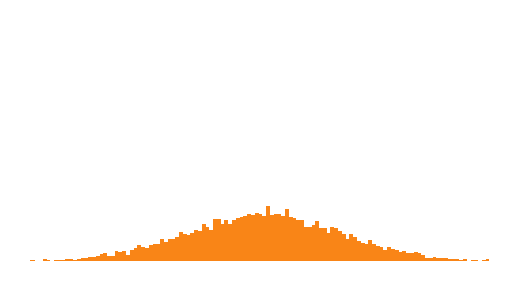

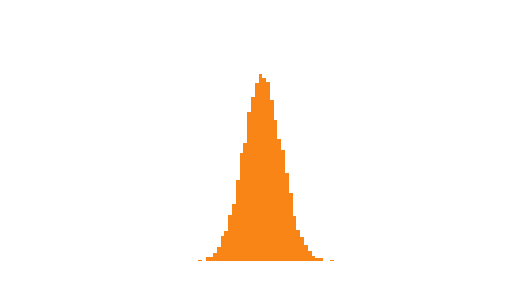

In [127]:
n_samples = 10000

fig1, ax1 = plt.subplots(1, 1, figsize=(2, 1))
fig2, ax2 = plt.subplots(1, 1, figsize=(2, 1))

vals = np.random.normal(size=(n_samples,))
_, bins, _ = ax1.hist(vals, bins=149, color=c_vals_p['cn'], density=True)

vals = np.random.normal(scale=0.25, size=(n_samples,))
ax2.hist(vals, bins=bins, color=c_vals_p['cn'], density=True)

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.set_xticks([])
    ax.set_xlim((-3, 3))
    ax.set_yticks([])
    ax.set_ylim((0., 2.0,))

#### Fig 3: Our BCI task

/tmp/ipykernel_421/701690700.py:212: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


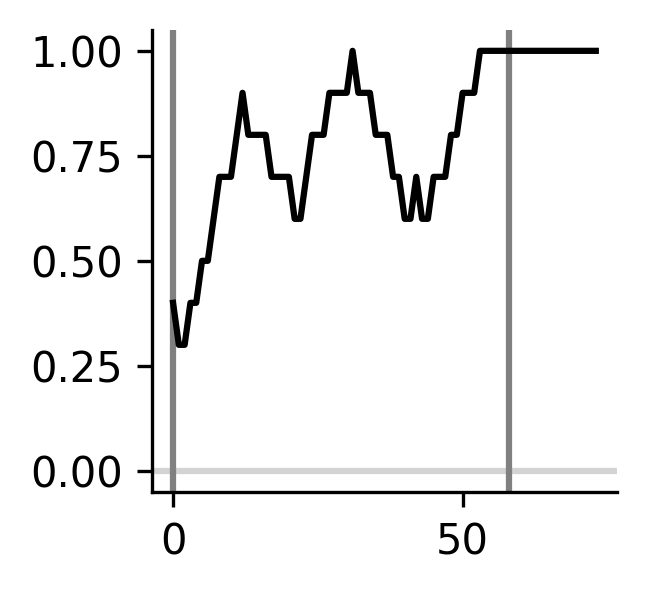

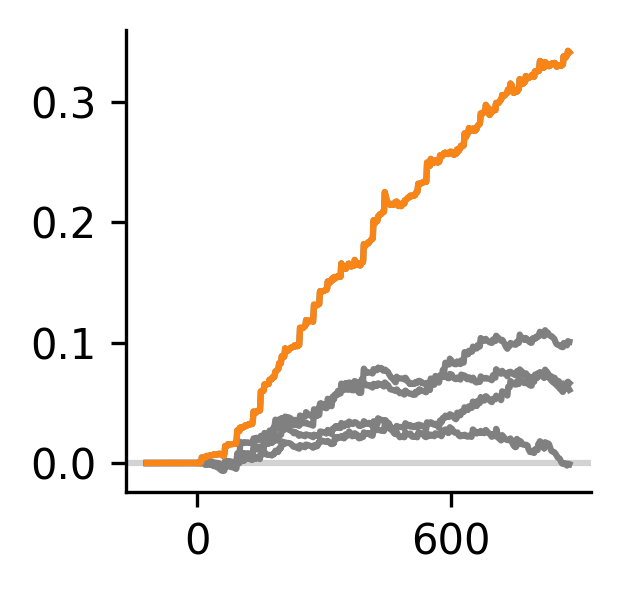

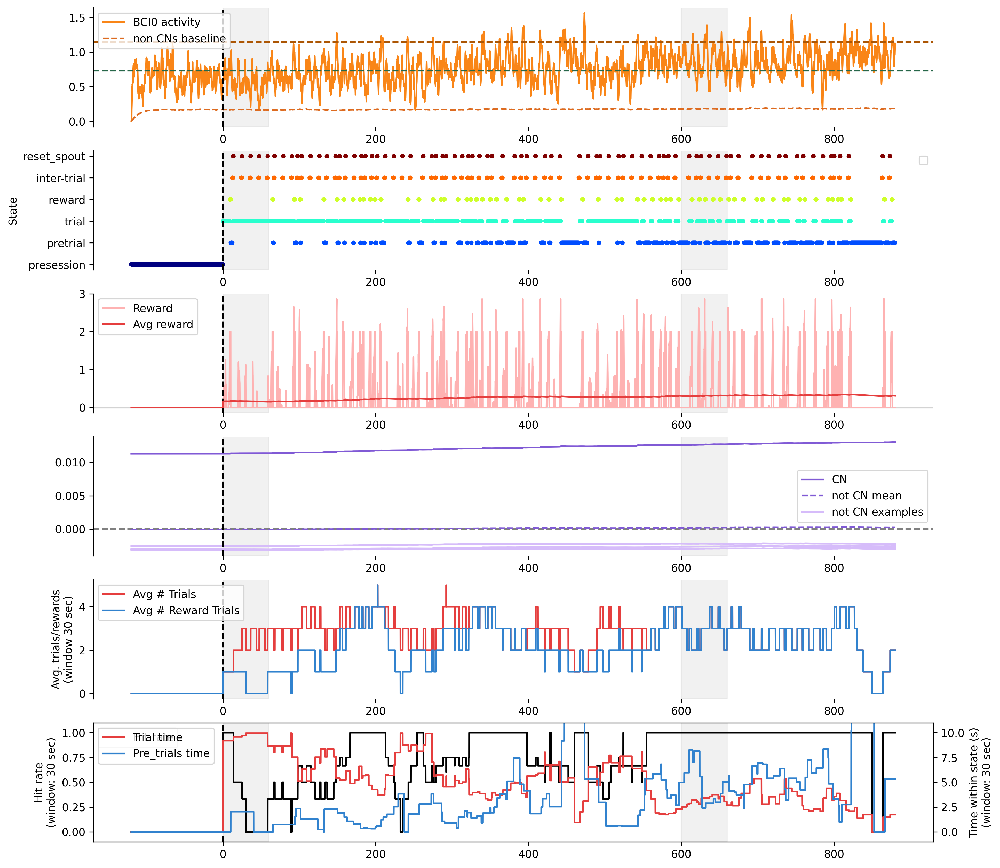

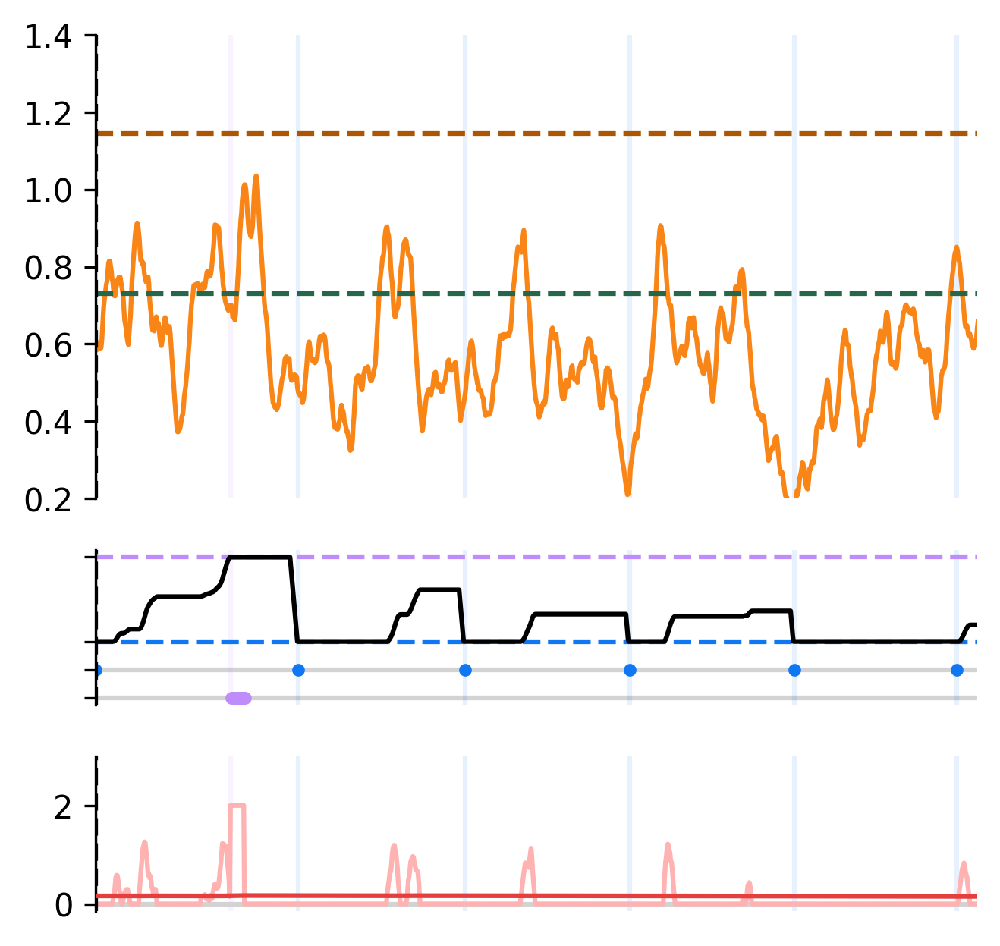

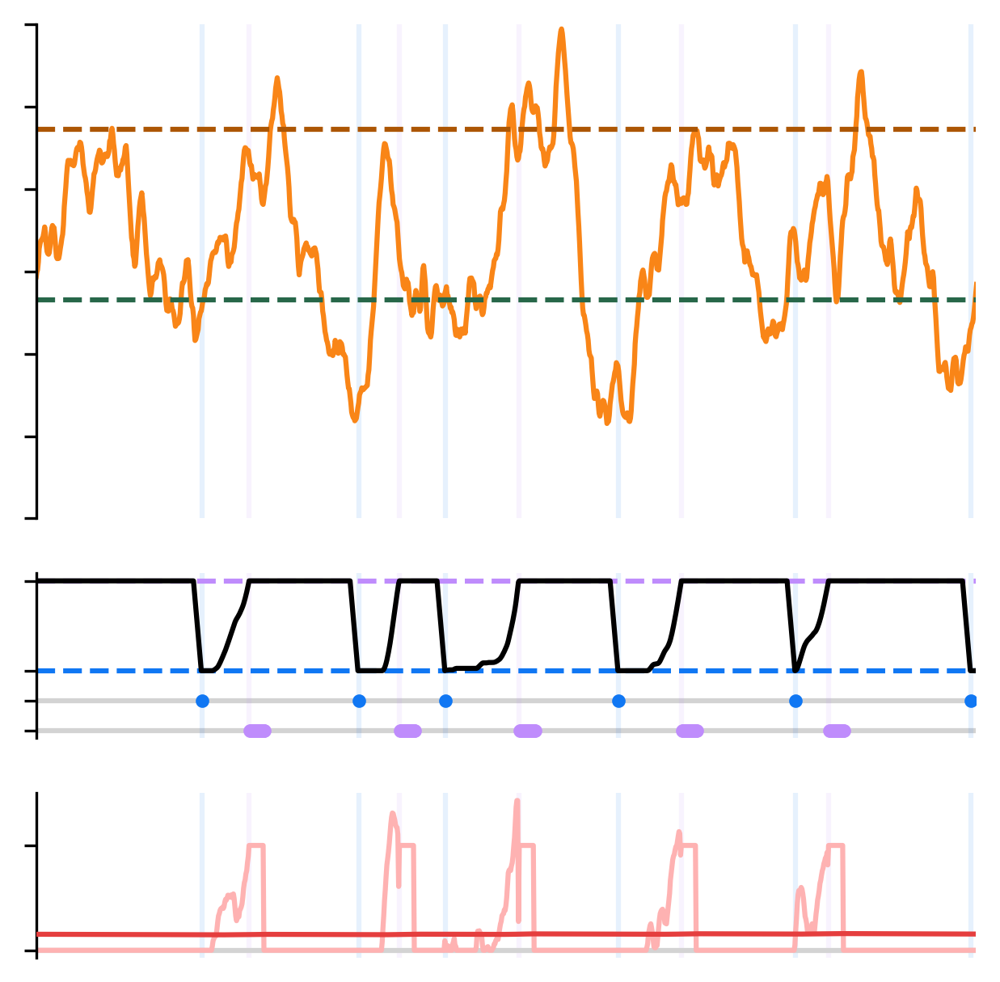

In [137]:
session_idx = 0

fig1, ax1 = plt.subplots(1, 1, figsize=(2, 2)) # Exemplar activitivies vs. time# fig2, ax4 = plt.subplots(1, 1, figsize=(16, 3))

time_ranges = {
    'early': (0, 60,),
    'late': (600, 660,),
}

task_params, train_params, net_params = params

n_neurons = task_params['n_neurons']

train_outputs = train_outputs_all[session_idx]

loss_steps = train_outputs['loss_steps']
steps = np.arange(task_params['n_steps']) - task_params['n_steps_stabilize']
raw_steps = np.arange(task_params['n_steps']) - task_params['n_steps_stabilize'] # Has delay incorporated

x_axis_step_scale = task_params['t_step'] / 1000 # Convert from ms to s
x_axis_label = 'Time (s)'
x_axis = x_axis_step_scale * steps
x_axis_raw = x_axis_step_scale * raw_steps
x_axis_loss = x_axis_step_scale * (np.array(loss_steps) - task_params['n_steps_stabilize'])
weight_change_x_axis = x_axis_loss

cn_idxs = train_outputs['cn_idxs']
bci_masks = train_outputs['bci_masks']
output = train_outputs['output']
reward = train_outputs['reward']
avg_activity = train_outputs['avg_activity']
avg_reward = train_outputs['avg_reward']

bci_activity = train_outputs['bci_activity'] # Not the same as matmul(output, bci_masks.T) when BCI masks change mid-session (perturbations)
avg_bci_activity = train_outputs['avg_bci_activity']

total_rpes = train_outputs['total_rpes']

sol_step = train_outputs['sol_step']

task_hist = task.hists[session_idx]

n_cells = 5
random_neuron_idxs = np.random.choice(task_params['n_neurons'], size=(n_cells,))

n_trial_avg_window = 10
trial_avg_window = 1 / n_trial_avg_window * np.ones((n_trial_avg_window,))
task_hist = task.hists[session_idx]

if len(task_hist['trial_outcomes']) < n_trial_avg_window:
    print('Not enough trials to plot.')
else:
    mean_hit_rates = fftconvolve(task_hist['trial_outcomes'], trial_avg_window, mode='valid')

ax1.plot(np.arange(mean_hit_rates.shape[0]), mean_hit_rates, color='k')
ax1.axhline(0.0, color='lightgrey', zorder=-5)
# ax1.set_ylabel('Hit rate'.format(n_trial_avg_window))

early_trial_starts = []
late_trial_starts = []
for trial_start_idx, trial_start in enumerate(task.hist['trial_starts']):
    trial_start_time = task.dt * (trial_start - task_params['n_steps_stabilize'])
    
    if trial_start_time >= time_ranges['early'][0] and trial_start_time < time_ranges['early'][1]:
        early_trial_starts.append(trial_start_idx)
    if trial_start_time >= time_ranges['late'][0] and trial_start_time < time_ranges['late'][1]:
        late_trial_starts.append(trial_start_idx)

avg_trial_window =  np.mean(np.arange(n_trial_avg_window))                               
if np.mean(early_trial_starts) < avg_trial_window:
    ax1.axvline(0., color='grey', zorder=-5)
else:
    ax1.axvline(np.mean(early_trial_starts) - avg_trial_window, color='grey', zorder=-5)

ax1.axvline(np.mean(late_trial_starts) - avg_trial_window, color='grey', zorder=-5)

fig2, ax2 = plt.subplots(1, 1, figsize=(2, 2))

if net_params['W_inp_adjust']:
    W_type = net_params['W_inp_type']
    W_vals = train_outputs['W_inp_vals']
elif net_params['W_rec_adjust']:
    W_type = net_params['W_rec_type']
    W_vals = train_outputs['W_rec_vals']

delta_W_full = W_vals - W_vals[0:1, :, :]
delta_W_in = np.sum(delta_W_full, axis=-1)
delta_W_in = delta_W_in - delta_W_in[0]

ax2.plot(weight_change_x_axis, delta_W_in[:, cn_idxs[0]], color=c_vals_p['cn'])
for neuron_idx in random_neuron_idxs:
    ax2.plot(weight_change_x_axis, delta_W_in[:, neuron_idx], color='grey', zorder=0)
# ax2.plot(weight_change_x_axis, np.mean(np.delete(delta_W_in, cn_idxs[0], axis=1), axis=-1), color='k')
ax2.axhline(0.0, color='lightgrey', linestyle='solid', zorder=-3)

ax2.set_xticks((0, 600))

for ax in (ax1, ax2,):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

#### Other plots ####

while any(rn_idx in cn_idxs for rn_idx in random_neuron_idxs) in random_neuron_idxs: # Ensures the random neuron idxs aren't the CNs
    random_neuron_idxs = np.random.choice(task_params['n_neurons'], size=(n_cells,))

for plot_idx, plot_type in enumerate(('all', 'early', 'late',)):
    
    if plot_type == 'all':
        fig, (ax1, ax0, ax2, ax3, ax4, ax5) = plt.subplots(6, 1, figsize=(14, 14))
        axs = (ax0, ax1, ax2, ax3, ax4, ax5)
    else:
        fig, (ax1, ax3, ax2,) = plt.subplots(3, 1, figsize=(5, 5), gridspec_kw={'height_ratios': (3, 1, 1)})
        axs = (ax1, ax3, ax2,)
    
    bci_mask_idx = 0
    ax1.plot(x_axis, ACTIVITY_SCALE * bci_activity[:, bci_mask_idx], color=c_vals_p['cn'],
             label='BCI{} activity'.format(bci_mask_idx))
    # ax1.plot(x_axis, avg_bci_activity[:, bci_mask_idx], color=c_vals[1 + bci_mask_idx],
    #          label='BCI{} baseline'.format(bci_mask_idx), zorder=3)
    
    # ax1.plot(x_axis, output[:, cn_idxs[0]], color='lightgrey', label='raw CN activity', zorder=-5) # No Fluorescence

    ax1.axhline(ACTIVITY_SCALE * train_outputs['threshold'], color=c_vals_d[2], linestyle='dashed')
    ax1.axhline(ACTIVITY_SCALE * (train_outputs['threshold'] + task_params['width']), color=c_vals_pd['cn'], linestyle='dashed')

    # for neuron_idx in random_neuron_idxs[:2]:
    #     ax1.plot(x_axis, ACTIVITY_SCALE * output[:, neuron_idx], color='grey', zorder=-5, alpha=0.3)

    ax2.plot(x_axis_raw, REWARD_SCALE * reward, color=c_vals_l[0], label='Reward')
    ax2.plot(x_axis, REWARD_SCALE * avg_reward, color=c_vals[0], label='Avg reward', zorder=6)
    # ax2.scatter(x_axis_loss, REWARD_SCALE * total_rpes, color=c_vals_d[0], marker='.', label='Total RPEs', zorder=5)
    ax2.axhline(0.0, color='lightgrey', linestyle='solid', zorder=-3)

    # ax2.set_ylabel('Reward')
    
    if plot_type == 'all':
        ax1.plot(x_axis, ACTIVITY_SCALE * np.mean(np.delete(avg_activity, cn_idxs, axis=-1), axis=-1), color=c_vals[4], label='non CNs baseline', linestyle='dashed')
        
        ax0.scatter(x_axis, task_hist['world_trajectory'][:-1], c=task_hist['world_trajectory'][:-1], cmap='jet', marker='.')
        ax0.set_ylabel('State')
        ax0.set_yticks((-1, 0, 1, 2, 3, 4))
        ax0.set_yticklabels(('presession', 'pretrial', 'trial', 'reward', 'inter-trial', 'reset_spout'))

        delta_W_full = W_vals[1:] - W_vals[:-1]
        delta_Ws = np.mean(delta_W_full, axis=(1, 2)) # Mean over inputs and outputs
        if cn_idxs is not None:
            delta_Ws_nocn = np.mean(np.delete(W_vals, cn_idxs, axis=1)[1:] - np.delete(W_vals, cn_idxs, axis=1)[:-1], axis=(1, 2))

        ax3.plot(weight_change_x_axis, np.mean(W_vals[:, cn_idxs[0], :], axis=-1), color=c_vals[3], label='CN')
        ax3.plot(weight_change_x_axis, np.mean(np.mean(np.delete(W_vals, cn_idxs, axis=1), axis=1), axis=-1), color=c_vals[3], linestyle='dashed', label='not CN mean')
        ax3.axhline(0.0, color='grey', linestyle='dashed', zorder=-3)
        # ax3.scatter(loss_x_axis[1:], delta_Ws, color=c_vals_d[3], label='delta W', marker='.')

        label = 'not CN examples'
        for neuron_idx in random_neuron_idxs:
            if net_params['W_inp_type'] in ('diagonal',):
                ax3.plot(weight_change_x_axis, W_vals[:, neuron_idx, neuron_idx], color=c_vals_l[3], zorder=-5, label=label)
            elif net_params['W_inp_type'] in ('gaussian', 'gaussian_sparse', 'gaussian_low', 'log_normal',):
                ax3.plot(weight_change_x_axis, np.mean(W_vals[:, neuron_idx, :], axis=-1), color=c_vals_l[3], zorder=-5, label=label)
            label = None
            
        plot_more_our_bci_task((ax4, ax5), x_axis, task_params, task, session_idx)
    else:
        ax3.plot(x_axis, -1 * np.array(task_hist['raw_states'])[1:-1, -1], color='k') # Spout position
        ax3.axhline(0.0, color=c_vals_p['post_reward'], linestyle='dashed', zorder=-3)
        ax3.axhline(-3.0, color=c_vals_p['post_start_nopre'], linestyle='dashed', zorder=-3)
        
        ax3.scatter(x_axis, np.where(1.==np.array(task_hist['raw_states'])[1:-1, 0], -4, np.nan), color=c_vals_p['post_start_nopre'], marker='.')
        ax3.scatter(x_axis, np.where(1.==np.array(task_hist['raw_states'])[1:-1, 1], -5, np.nan), color=c_vals_p['post_reward'], marker='.')
        
        ax3.axhline(-4, color='lightgrey', zorder=-5)
        ax3.axhline(-5, color='lightgrey', zorder=-5)
        
        ax3.set_yticks((-5, -4, -3, 0))
        ax3.set_yticklabels([])
        
    show_trial_starts = False
    
    MAX_CN_VAL = 1.4
    
    for ax_idx, ax in enumerate(axs):
        ax.axvline(0., color='k', linestyle='dashed')
        
        if plot_type in ('early', 'late',):
            for trial_idx, trial_start in enumerate(task.hist['trial_starts']):
                trial_start_time = task.dt * (trial_start - task_params['n_steps_stabilize'])
                trial_end_time = task.dt * (task.hist['trial_ends'][trial_idx] - task_params['n_steps_stabilize'])
                ax.axvline(trial_start_time, color=c_vals_p['post_start_nopre'], zorder=-5, alpha=0.1)
                
                # if ax_idx == 0: # Black bars showing trial extent
                #     ax.plot((trial_start_time, trial_end_time), (MAX_CN_VAL - 0.05, MAX_CN_VAL - 0.05), color='k')
                
            for rew_idx in task.hist['rewards']:
                ax.axvline(task.dt * (rew_idx - task_params['n_steps_stabilize']), 
                           color=c_vals_p['post_reward'], zorder=-5, alpha=0.1)
            
            ax.set_xlim(time_ranges[plot_type])
            
            x_ticks = np.arange(time_ranges[plot_type][0], time_ranges[plot_type][1]+1, 10)
            x_tick_labels = [x_val if x_val in time_ranges[plot_type] else None for x_val in x_ticks]
            
            # ax.set_xticks(x_ticks)
            ax.set_xticks([])
            ax.set_xticklabels([])
            
        else:
            
            ax.axvspan(*time_ranges['early'], color='lightgrey', alpha=0.3, zorder=-10)
            ax.axvspan(*time_ranges['late'], color='lightgrey', alpha=0.3, zorder=-10)
            
            ax.legend()
            
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
    
    if plot_type in ('early', 'late',):
        ax1.set_ylim((0.2, MAX_CN_VAL))
        
        if plot_type in ('late',):
            ax1.set_yticklabels([])
            ax2.set_yticklabels([])
        
        # axs[-1].set_xticklabels(x_tick_labels)     

# ax3.set_ylim((-0.0001, 0.0001))

Various additional analyses on an exemplar session, needs to be run after the above

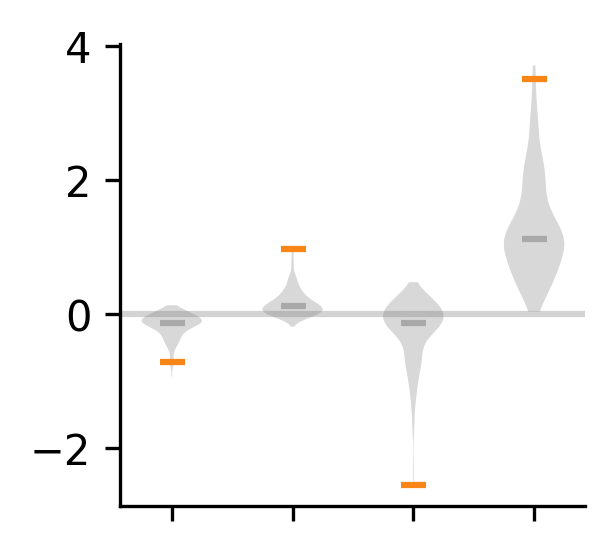

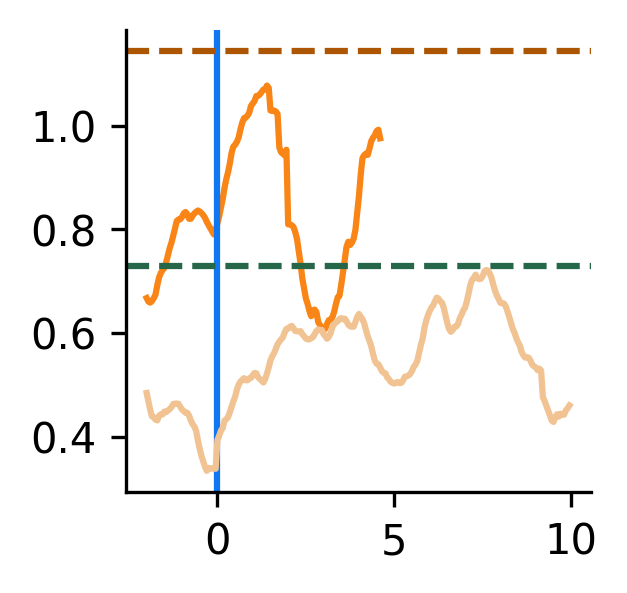

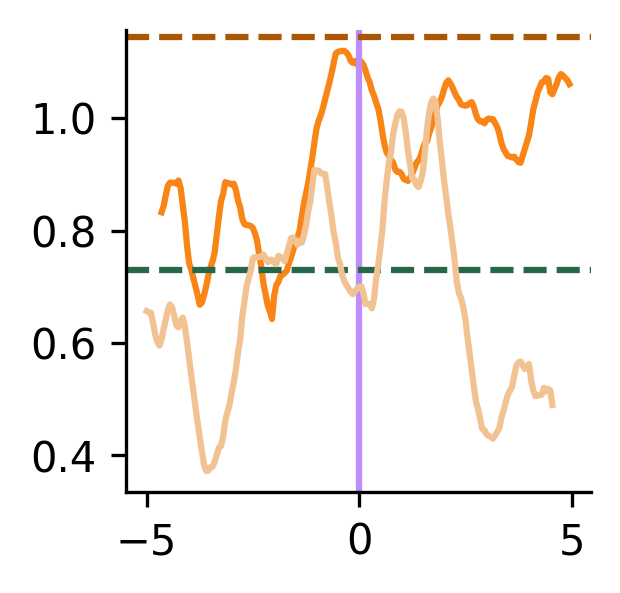

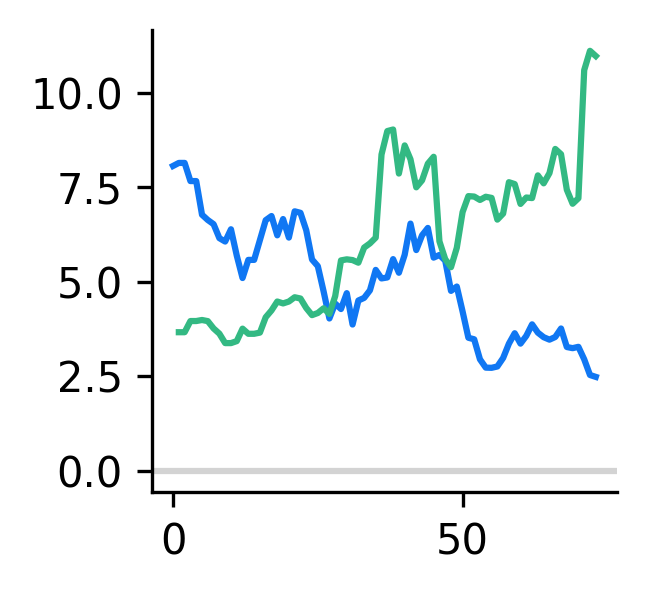

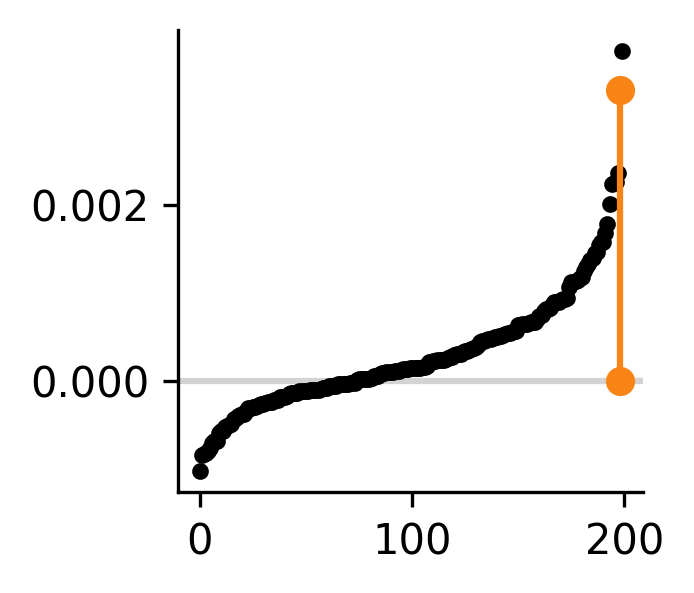

In [146]:
activity_type = 'raw_fl'
trial_bounds=(-2, 10) # in seconds
reward_bounds=(-5, 5) # in seconds   

delta_W = W_vals[-1] - W_vals[0]

n_input = net_params['n_inp']

cn_idx = cn_idxs[0]

fig1, ax1 = plt.subplots(1, 1, figsize=(2, 2)) # specific connectivity changes to stims
fig2, ax2 = plt.subplots(1, 1, figsize=(2, 2,)) # trial start aligned activity
fig3, ax3 = plt.subplots(1, 1, figsize=(2, 2,)) # reward aligned activity
fig4, ax4 = plt.subplots(1, 1, figsize=(2, 2,)) # trial and inter-trial durations
fig5, ax5 = plt.subplots(1, 1, figsize=(2, 2,)) # trial change sorted

### Change to specific stims ###

stim_names = ('uniform', 'tone', 'reward', 'port move')

possible_inputs = np.concatenate((np.ones((1, n_input)), task.stim_input), axis=0)
n_stims = possible_inputs.shape[0]
possible_inputs = possible_inputs / np.linalg.norm(possible_inputs, axis=-1, keepdims=True) # Unit norm

# Multiply through input layer to find effect on hidden
possible_inputs = np.matmul(net.W_inp, possible_inputs.T).T 

# Weight changes by how much input they get
delta_W_inputs = np.matmul(delta_W, possible_inputs.T) # (n_neurons, n_inputs)

ax1.axhline(0.0, color='lightgrey', zorder=-5)
parts = ax1.violinplot(WEIGHT_SCALE * delta_W_inputs, positions=np.arange(n_stims), showextrema=False)

for pc in parts['bodies']:
    pc.set_facecolor('grey')
    # pc.set_edgecolor('black')
    # pc.set_alpha(1)

ax1.scatter(np.arange(n_stims), WEIGHT_SCALE * np.median(delta_W_inputs, axis=0), marker='_', color='darkgrey', zorder=5)
ax1.scatter(np.arange(n_stims), WEIGHT_SCALE * delta_W_inputs[cn_idx], marker='_', color=c_vals_p['cn'], zorder=5)
# ax1.bar(np.arange(delta_W_inputs.shape[-1]), delta_W_inputs[cn_idx])

ax1.set_xticks(np.arange(n_stims))
# ax1.set_xticklabels(stim_names)
ax1.set_xticklabels([])

# ax1.set_ylabel('Total $\Delta$W incoming')

### Trial start and reward aligned ###

if activity_type in ('raw_activity',):
    activity_analyze = train_outputs_all[session_idx]['output']
elif activity_type in ('raw_fl',):
    activity_analyze = train_outputs_all[session_idx]['output_fl']
elif activity_type in ('dff',):
    activity_analyze, _ = bci_analysis.compute_dff(
        train_outputs_all[session_idx]['output_fl'], task_params, f0_CUTOFF = 0.1 * task_params['task_scale']
    )

trial_aligned, rew_aligned, trial_aligned_lens, rew_aligned_lens = bci_analysis.get_our_bci_aligned_activities(
    activity_analyze, task.hists[session_idx], task_params, trial_bounds=trial_bounds, reward_bounds=reward_bounds
)

trial_times = np.arange(trial_bounds[0], trial_bounds[1], task.dt)

# ax2.plot(trial_times, np.nanmean(trial_aligned, axis=0)[:, cn_idx], color='k')
with warnings.catch_warnings(): # Suppress mean of empty slice warnings, since they return nan as expected
    warnings.simplefilter("ignore", category=RuntimeWarning)
    ax2.plot(trial_times, ACTIVITY_SCALE * np.nanmean(trial_aligned[-5:], axis=0)[:, cn_idx], color=c_vals_p['cn'])
    ax2.plot(trial_times, ACTIVITY_SCALE * np.nanmean(trial_aligned[:5], axis=0)[:, cn_idx], color=c_vals_pl['cn'], zorder=5)
ax2.axvline(0., color=c_vals_p['post_start_nopre'])

rew_times = np.arange(reward_bounds[0], reward_bounds[1], task.dt)

# ax3.plot(rew_times, np.nanmean(rew_aligned, axis=0)[:, cn_idx], color='k')
with warnings.catch_warnings(): # Suppress mean of empty slice warnings, since they return nan as expected
    warnings.simplefilter("ignore", category=RuntimeWarning)
    ax3.plot(rew_times, ACTIVITY_SCALE * np.nanmean(rew_aligned[-5:], axis=0)[:, cn_idx], color=c_vals_p['cn'])
    ax3.plot(rew_times, ACTIVITY_SCALE * np.nanmean(rew_aligned[:5], axis=0)[:, cn_idx], color=c_vals_pl['cn'], zorder=5)
ax3.axvline(0., color=c_vals_p['post_reward'])

for ax in (ax2, ax3,):
    ax.axhline(ACTIVITY_SCALE * train_outputs['threshold'], color=c_vals_d[2], linestyle='dashed')
    ax.axhline(ACTIVITY_SCALE * (train_outputs['threshold'] + task_params['width']), color=c_vals_pd['cn'], linestyle='dashed')

### Trial and inter-trial lengths ###

start_idxs = task.hists[session_idx]['trial_starts']
rew_idxs = bci_analysis.pad_rew_idxs(task.hists[session_idx]) # Adds nan pads to rew_idxs, should be same length as trial start idxs now

trial_lens = np.array(rew_idxs) - np.array(start_idxs)
trial_lens = np.where(np.isnan(trial_lens), 200, trial_lens) * task.dt # nans become 10 seconds

pretrial_lens = (np.array(start_idxs[1:]) - np.array(rew_idxs[:-1])) * task.dt # nans are kept

trial_lens_avg = []
pretrial_lens_avg = [np.nan,] # start with nan to make this same length as trial_lens

for trial_idx in range(trial_lens.shape[0] - n_trial_avg_window + 1):
    trial_lens_avg.append(np.mean(trial_lens[trial_idx:trial_idx+n_trial_avg_window]))
    if trial_idx > 0:
        pretrial_lens_avg.append(np.nanmean(pretrial_lens[trial_idx:trial_idx+n_trial_avg_window]))

ax4.plot(trial_lens_avg, color=c_vals_p['post_start_nopre'])
ax4.plot(pretrial_lens_avg, color=c_vals_p['pre_start'])

ax4.axhline(0., color='lightgrey', zorder=-5)

ts_metric = 'post_start'

ts_metric_slopes = ACTIVITY_SCALE * train_outputs_all[session_idx]['session_summary']['ts_extras'][ts_metric]['slope']
ts_metric_slopes_sort_idxs = np.argsort(ts_metric_slopes)
cn_sort_idx = np.where(ts_metric_slopes_sort_idxs == cn_idx)[0][0]

ax5.scatter(np.arange(n_neurons), ts_metric_slopes[ts_metric_slopes_sort_idxs], marker='.', color='k')
ax5.scatter(np.arange(n_neurons)[cn_sort_idx], ts_metric_slopes[cn_idx], marker='.', color=c_vals_p['cn'])
ax5.plot((cn_sort_idx, cn_sort_idx), (0., ts_metric_slopes[cn_idx]), color=c_vals_p['cn'], marker='o')
ax5.axhline(0., color='lightgrey', zorder=-5)

for ax in (ax1, ax2, ax3, ax4, ax5,):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

These should be run after scans

Trial_starts len: 82, trial_outcomes len: 81, padding!
Trial_starts len: 88, trial_outcomes len: 87, padding!
Trial_starts len: 99, trial_outcomes len: 98, padding!
 Trial bootstrap...
 Trial bootstrap...


/tmp/ipykernel_204/115145398.py:59: RuntimeWarning: Mean of empty slice
  mean_hit_rate = np.nanmean(mean_hit_rates_all, axis=0)
/tmp/ipykernel_204/115145398.py:73: RuntimeWarning: Mean of empty slice
  mean_trial_lens = np.nanmean(trial_lens_all, axis=0)
/tmp/ipykernel_204/115145398.py:75: RuntimeWarning: Mean of empty slice
  mean_pretrial_lens = np.nanmean(pretrial_lens_all, axis=0)


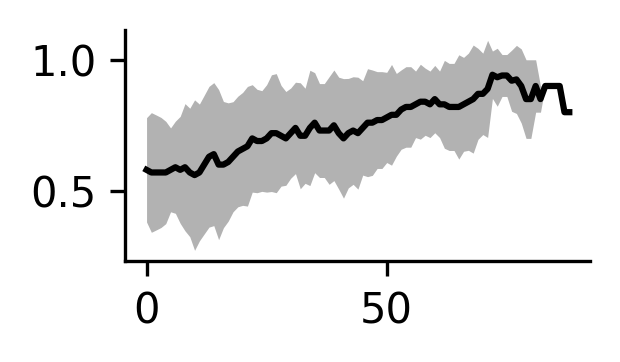

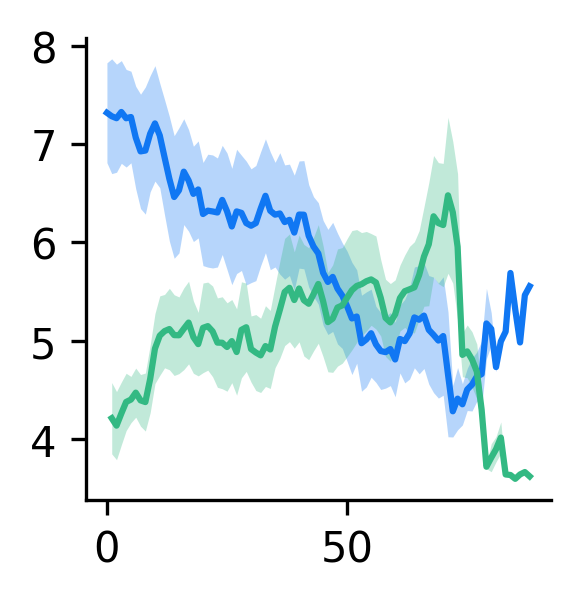

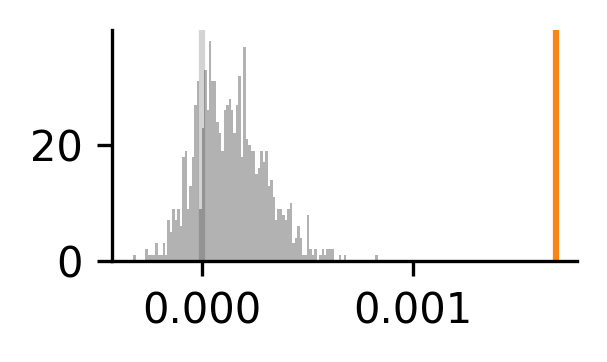

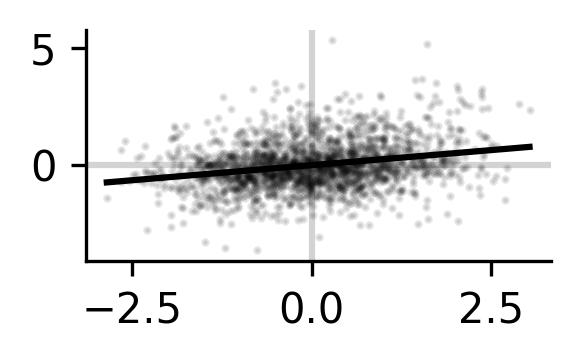

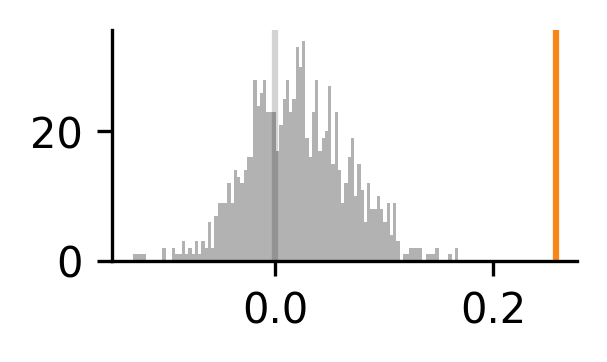

In [32]:
scan_idx = 0
n_trial_avg_window = 10

n_max_trials_plot = 100
trial_avg_window = 1 / n_trial_avg_window * np.ones((n_trial_avg_window,))

error_shading_mode = 'mse' # std, mse

n_bootstrap = 1000 # 1st bootstrap idx is always actual CNs

mean_hit_rates_all = np.nan * np.ones((n_repeats, n_max_trials_plot)) # Averaged over 10 trials
trial_lens_all = np.nan * np.ones((n_repeats, n_max_trials_plot)) # Averaged over 10 trials
pretrial_lens_all = np.nan * np.ones((n_repeats, n_max_trials_plot)) # Averaged over 10 trials

c_vals_p['post_start'] = 'k'

ts_metrics = ('pre_start', 'post_start_nopre', 'pre_reward', 'post_start', 'post_reward',)
ts_metric_names = ('Pre', 'Early', 'Late', 'Trial', 'Rew')

ts_metric = ts_metrics[3]
ts_metric_name = ts_metric_names[3]

for repeat_idx in range(n_repeats):

    task_hist = task_hists_all[repeat_idx]
    
    ### Mean hit rates ###
    if len(task_hist['trial_outcomes']) < n_trial_avg_window:
        print('Not enough trials to plot.')
    else:
        mean_hit_rates = fftconvolve(task_hist['trial_outcomes'], trial_avg_window, mode='valid')

    n_trials_plot = min(mean_hit_rates.shape[0], n_max_trials_plot)
    mean_hit_rates_all[repeat_idx, :n_trials_plot] = mean_hit_rates[:n_trials_plot]
    
    ### Trial and pretrial lens ###
    start_idxs = task_hist['trial_starts']
    rew_idxs = bci_analysis.pad_rew_idxs(task_hist) # Adds nan pads to rew_idxs, should be same length as trial start idxs now

    trial_lens = np.array(rew_idxs) - np.array(start_idxs)
    trial_lens = np.where(np.isnan(trial_lens), 200, trial_lens) * 1/20 # nans become 10 seconds

    pretrial_lens = (np.array(start_idxs[1:]) - np.array(rew_idxs[:-1])) * 1/20 # nans are kept

    trial_lens_avg = []
    pretrial_lens_avg = [np.nan,] # start with nan to make this same length as trial_lens

    for trial_idx in range(n_trials_plot): # Already takes into account mean window size from above
        trial_lens_avg.append(np.mean(trial_lens[trial_idx:trial_idx+n_trial_avg_window]))
        if trial_idx > 0:
            pretrial_lens_avg.append(np.nanmean(pretrial_lens[trial_idx:trial_idx+n_trial_avg_window]))

    trial_lens_all[repeat_idx, :n_trials_plot] = trial_lens_avg
    pretrial_lens_all[repeat_idx, :n_trials_plot] = pretrial_lens_avg

### Mean hit rate ###
fig1, ax1 = plt.subplots(1, 1, figsize=(2, 1))

mean_hit_rate = np.nanmean(mean_hit_rates_all, axis=0)
std_hit_rate = np.nanstd(mean_hit_rates_all, axis=0)

ax1.plot(np.arange(n_max_trials_plot), mean_hit_rate, color='k')
ax1.fill_between(np.arange(n_max_trials_plot), mean_hit_rate+std_hit_rate, mean_hit_rate-std_hit_rate, color='k',
                 alpha=0.3, zorder=-1, linewidth=0.)
# ax1.axhline(0.0, color='lightgrey', zorder=-5)

# ax1.set_xlabel('Trial #')
# ax1.set_ylabel('$\Delta$Hit rate')

### Mean trial/pretrial lengths plot ###
fig5, ax5 = plt.subplots(1, 1, figsize=(2, 2))

mean_trial_lens = np.nanmean(trial_lens_all, axis=0)
std_trial_lens = np.nanstd(trial_lens_all, axis=0)
mean_pretrial_lens = np.nanmean(pretrial_lens_all, axis=0)
std_pretrial_lens = np.nanstd(pretrial_lens_all, axis=0)

if error_shading_mode == 'mse':
    std_trial_lens /= np.sqrt(n_repeats)
    std_pretrial_lens /= np.sqrt(n_repeats)

ax5.plot(np.arange(n_max_trials_plot), mean_trial_lens, color=c_vals_p['post_start_nopre'])
ax5.fill_between(np.arange(n_max_trials_plot), mean_trial_lens+std_trial_lens, mean_trial_lens-std_trial_lens, color=c_vals_p['post_start_nopre'],
                 alpha=0.3, zorder=-1, linewidth=0.)
ax5.plot(np.arange(n_max_trials_plot), mean_pretrial_lens, color=c_vals_p['pre_start'])
ax5.fill_between(np.arange(n_max_trials_plot), mean_pretrial_lens+std_pretrial_lens, mean_pretrial_lens-std_pretrial_lens, color=c_vals_p['pre_start'],
                 alpha=0.3, zorder=-1, linewidth=0.)

# ax5.set_xlabel('Trial #')
# ax5.set_ylabel('Trial/Pre-trial length (s)')

fig2, ax2 = plt.subplots(1, 1, figsize=(2, 1))
    
ts_metric_slopes_bs = np.nan * np.ones((n_bootstrap, n_repeats))
print(' {} bootstrap...'.format(ts_metric_name))

for repeat_idx in range(n_repeats): # Slightly easier to run over repeats first, then normalization only happens once
    ts_metric_slopes = ACTIVITY_SCALE * session_summaries[scan_idx][repeat_idx]['ts_extras'][ts_metric]['slope']

    for bs_idx in range(n_bootstrap):

        if bs_idx == 0:
            neuron_idx = cn_idxs[scan_idx, repeat_idx, 0]
        else:
            neuron_idx = np.random.randint(ts_metric_slopes.shape[0])

        ts_metric_slopes_bs[bs_idx, repeat_idx] = ts_metric_slopes[neuron_idx]

ax2.hist(np.mean(ts_metric_slopes_bs[1:, :], axis=-1), bins=100, color=c_vals_p[ts_metric], alpha=0.3)
ax2.axvline(np.mean(ts_metric_slopes_bs[0, :]), color=c_vals_p['cn'])
ax2.axvline(0.0, color='lightgrey', zorder=-5)

# ax2.set_xlabel('Mean $\Delta${}'.format(ts_metric_name))
# ax2.set_ylabel('Count')

fig4, ax4 = plt.subplots(1, 1, figsize=(2, 1)) # CN fit
fig3, ax3 = plt.subplots(1, 1, figsize=(2, 1))
    
ts_metric_pred_slopes_bs = np.nan * np.ones((n_bootstrap,))

print(' {} bootstrap...'.format(ts_metric_name))

for bs_idx in range(n_bootstrap):

    aggregate_corrs = []
    aggregate_slopes = []

    for repeat_idx in range(n_repeats): # Slightly easier to run over repeats first, then normalization only happens once
        if bs_idx == 0:
            neuron_idx = cn_idxs[scan_idx, repeat_idx, 0]
        else:
            neuron_idx = np.random.randint(pairwise_corrs[scan_idx][repeat_idx].shape[0])

        neuron_corrs = pairwise_corrs[scan_idx][repeat_idx][neuron_idx, :]
        ts_metric_slopes = session_summaries[scan_idx][repeat_idx]['ts_extras'][ts_metric]['slope']

        neuron_corrs = np.delete(neuron_corrs, neuron_idx)
        ts_metric_slopes = np.delete(ts_metric_slopes, neuron_idx)

        neuron_corrs = (neuron_corrs - np.mean(neuron_corrs)) / np.std(neuron_corrs) # z-score
        ts_metric_slopes = (ts_metric_slopes - np.mean(ts_metric_slopes)) / np.std(ts_metric_slopes) 

        aggregate_corrs.append(neuron_corrs)
        aggregate_slopes.append(ts_metric_slopes)

    aggregate_corrs = np.concatenate(aggregate_corrs, axis=0)
    aggregate_slopes = np.concatenate(aggregate_slopes, axis=0)

    slope, intercept, rvalue, pvalue, _ = linregress(aggregate_corrs, aggregate_slopes)

    ts_metric_pred_slopes_bs[bs_idx] = slope
    
    if bs_idx == 0:
        ax4.scatter(aggregate_corrs, aggregate_slopes, color=c_vals_p[ts_metric], alpha=0.1, s=1.0)
        
        x_vals = np.linspace(np.min(aggregate_corrs), np.max(aggregate_corrs), 10)
        y_vals = intercept + x_vals * slope
        
        ax4.plot(x_vals, y_vals, color=c_vals_p[ts_metric], zorder=5)

ax4.axvline(0.0, color='lightgrey', zorder=-5)
ax4.axhline(0.0, color='lightgrey', zorder=-5)
    
ax3.hist(ts_metric_pred_slopes_bs[1:], bins=100, color=c_vals_p[ts_metric], alpha=0.3)
ax3.axvline(ts_metric_pred_slopes_bs[0], color=c_vals_p['cn'])
ax3.axvline(0.0, color='lightgrey', zorder=-5)

for ax in (ax1, ax2, ax3, ax4, ax5,):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# ax3.set_xlabel('Corr.-$\Delta${} slope'.format(ts_metric_name))
# ax3.set_ylabel('Count')

Supplement plots that show how performance scales over various scans

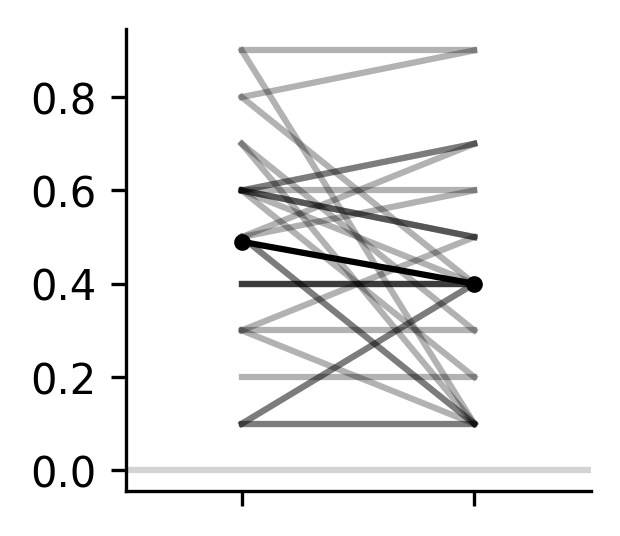

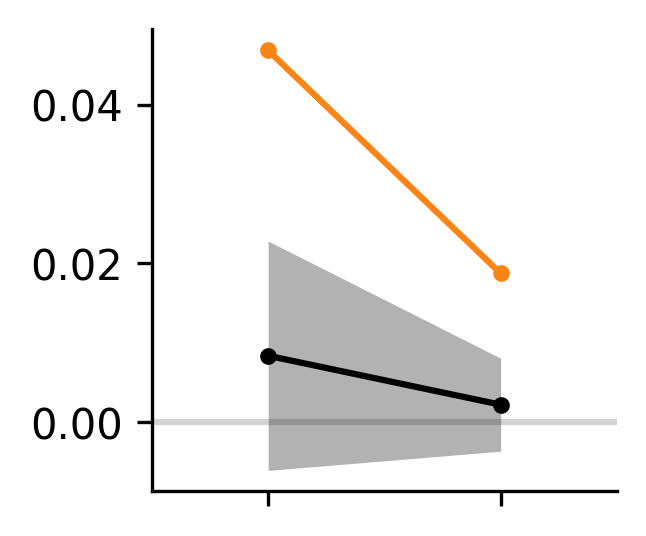

In [31]:
fig1, ax1 = plt.subplots(1, 1, figsize=(2, 2))
fig2, ax2 = plt.subplots(1, 1, figsize=(2, 2))

total_rewards = np.zeros((n_scan, n_repeats,))
est_total_rewards = np.zeros_like(total_rewards)
total_hit_rates = np.zeros_like(total_rewards)
delta_hit_rates = np.zeros_like(total_rewards)
delta_hit_rates_max = np.zeros_like(total_rewards)

ts_metric = 'post_start'
mean_delta_ts_metric = np.zeros_like(total_rewards)
std_delta_ts_metric = np.zeros_like(total_rewards)
cn_delta_ts_metric = np.zeros_like(total_rewards)
cn_zscore_delta_ts_metric = np.zeros_like(total_rewards)

assert n_sessions == 1
SESSION_START = 0
SESSION_END = n_sessions

N_TRIALS_CHANGE = 10 # Effectively just rescales the ts metric changes

for scan_idx in range(n_scan):
    for repeat_idx in range(n_repeats):
        total_rewards[scan_idx, repeat_idx] = session_summaries[scan_idx][repeat_idx]['total_reward']
        est_total_rewards[scan_idx, repeat_idx] = start_avg_rewards[scan_idx, repeat_idx] * (
            task_params['n_steps'] - task_params['n_steps_stabilize']
        )
        
        total_hit_rates[scan_idx, repeat_idx] = session_summaries[scan_idx][repeat_idx]['hit_rate']
        delta_hit_rates[scan_idx, repeat_idx] = (
            session_summaries[scan_idx][repeat_idx]['hit_rate_final'] - session_summaries[scan_idx][repeat_idx]['hit_rate_init']
        )
        delta_hit_rates_max[scan_idx, repeat_idx] = (
            session_summaries[scan_idx][repeat_idx]['hit_rate_max'] - session_summaries[scan_idx][repeat_idx]['hit_rate_init']
        )
        
        cn_idx = cn_idxs[scan_idx, repeat_idx, 0]
        
        ts_metric_slopes = session_summaries[scan_idx][repeat_idx]['ts_extras'][ts_metric]['slope']
        mean_delta_ts_metric[scan_idx, repeat_idx] = N_TRIALS_CHANGE * ACTIVITY_SCALE * np.mean(ts_metric_slopes)
        std_delta_ts_metric[scan_idx, repeat_idx] = N_TRIALS_CHANGE * ACTIVITY_SCALE * np.std(ts_metric_slopes)
        cn_delta_ts_metric[scan_idx, repeat_idx] = N_TRIALS_CHANGE * ACTIVITY_SCALE * ts_metric_slopes[cn_idx]
        cn_zscore_delta_ts_metric[scan_idx, repeat_idx] = (ts_metric_slopes[cn_idx] - np.mean(ts_metric_slopes)) / np.std(ts_metric_slopes)
        
rel_total_rewards = (total_rewards - est_total_rewards) / est_total_rewards

if scan_type in ('bci_lr_scan',):
    scan_vals_plot = np.copy(scan_vals)
elif scan_type in ('bci_n_window_reward_scan',):
    scan_vals_plot = scan_vals / (20 * 60) # Minutes
elif scan_type in ('bci_n_window_baseline_scan',):
    scan_vals_plot = scan_vals / 20 # Seconds
elif scan_type in ('bci_n_window_elig_scan',):
    scan_vals_plot = scan_vals / 20 # Seconds
elif scan_type in ('bci_spout_rew_scan',):
    scan_vals_plot = np.copy(scan_vals)
MARKER = '.'   

### Performance plot ###
plot_val = np.mean(delta_hit_rates_max, axis=-1)
error_val = np.std(delta_hit_rates_max, axis=-1) / np.sqrt(n_repeats)

# plot_val = np.mean(delta_hit_rates, axis=-1)
# error_val = np.std(delta_hit_rates, axis=-1) / np.sqrt(n_repeats)

ax1.plot(scan_vals_plot, plot_val, color='k', marker=MARKER, zorder=5)
if scan_type not in ('bci_spout_rew_scan',): # For some scans, comparing reward is not meaningful
    ax1.fill_between(scan_vals_plot, plot_val + error_val, plot_val - error_val, color='k', zorder=-1, alpha=0.3, linewidth=0.0)
    
    max_val = np.max(np.abs(np.concatenate((plot_val + error_val, plot_val - error_val))))
    ax1.set_ylim((-max_val, max_val)) # Ensures this has the same zero point as twin plot
    
    ax1p = ax1.twinx()

    plot_val = np.mean(total_rewards - est_total_rewards, axis=-1)
    error_val = np.std(total_rewards - est_total_rewards, axis=-1) / np.sqrt(n_repeats)

    ax1p.plot(scan_vals_plot, plot_val, color=c_vals[0], marker=MARKER, zorder=5)
    ax1p.fill_between(scan_vals_plot, plot_val + error_val, plot_val - error_val, color=c_vals[0], zorder=-1, alpha=0.3, linewidth=0.0)

    ax1p.spines['right'].set_edgecolor(c_vals[0])
    ax1p.tick_params(axis='y', colors=c_vals[0])

    max_val = np.max(np.abs(np.concatenate((plot_val + error_val, plot_val - error_val))))
    ax1p.set_ylim((-max_val, max_val)) # Ensures this has the same zero point as twin plot

    ax1p.spines['left'].set_visible(False)
    ax1p.spines['top'].set_visible(False)
else: # When reward is not meaninful, plot raw data
    for repeat_idx in range(n_repeats): 
        ax1.plot(scan_vals_plot, delta_hit_rates_max[:, repeat_idx], color='k', alpha=0.3, zorder=0)

### Change sparsity plot ###
plot_val = np.mean(mean_delta_ts_metric, axis=-1)
# error_val = np.std(mean_delta_ts_metric, axis=-1) / np.sqrt(n_repeats)
error_val = np.mean(std_delta_ts_metric, axis=-1)

ax2.plot(scan_vals_plot, plot_val, color='k', marker=MARKER, zorder=5)
ax2.fill_between(scan_vals_plot, plot_val + error_val, plot_val - error_val, color='k', zorder=-1, alpha=0.3, linewidth=0.0)

# MAX_VAL = 0.0002
# ax2.set_ylim((-MAX_VAL, MAX_VAL))

plot_val = np.mean(cn_delta_ts_metric, axis=-1)
error_val = np.std(cn_delta_ts_metric, axis=-1) / np.sqrt(n_repeats)

ax2.plot(scan_vals_plot, plot_val, color=c_vals_p['cn'], marker=MARKER, zorder=5)

# ax2p = ax2.twinx()

# plot_val = np.mean(cn_zscore_delta_ts_metric, axis=-1)
# error_val = np.std(cn_zscore_delta_ts_metric, axis=-1) / np.sqrt(n_repeats)

# ax2p.plot(scan_vals_plot, plot_val, color=c_vals_p['cn'], marker=MARKER, zorder=5)
# MAX_VAL = 2.5
# ax2p.set_ylim((-MAX_VAL, MAX_VAL))

for ax in (ax1, ax2,):    
    ax.axhline(0., color='lightgrey', zorder=-5)
    ax.set_xscale('log') # Default, 
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
    if scan_type in ('bci_lr_scan',):
        ax.axvline(1.0, color='grey', linestyle='dashed',zorder=-4)
    elif scan_type in ('bci_n_window_reward_scan',):
        ax.axvline(300. * 20 / (20 * 60), color='grey', linestyle='dashed',zorder=-4)
        
        ax.set_xticks((1e-2, 1e-1, 1e0, 1e1,))
    elif scan_type in ('bci_n_window_baseline_scan',):
        ax.axvline(10. * 20 / (20), color='grey', linestyle='dashed',zorder=-4)
    elif scan_type in ('bci_n_window_elig_scan',):
        ax.axvline(2. * 20 / (20), color='grey', linestyle='dashed',zorder=-4)
    elif scan_type in ('bci_spout_rew_scan',):
        ax.set_xscale('linear') # Default, 
        ax.set_xticks((0, 1,))
        ax.set_xticklabels([])
        ax.set_xlim((-0.5, 1.5))

Comparison of water and water+spout reward

Trial_starts len: 72, trial_outcomes len: 71, padding!
Trial_starts len: 80, trial_outcomes len: 79, padding!
Trial_starts len: 85, trial_outcomes len: 84, padding!
Trial_starts len: 88, trial_outcomes len: 87, padding!
Trial_starts len: 86, trial_outcomes len: 85, padding!
[14 12 10 10  8  7  7  5  5  3  3  3  3  2  2  1  1  1  1  1  1  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
Trial_starts len: 86, trial_outcomes len: 85, padding!
Trial_starts len: 87, trial_outcomes len: 86, padding!
Trial_starts len: 70, trial_outcomes len: 69, padding!
Trial_starts len: 83, trial_outcomes len: 82, padding!
Trial_starts len: 88, trial_outcomes len: 87, padding!
Trial_starts len: 81, trial_outcomes len: 80, padding!
Trial_starts len: 85, trial_o

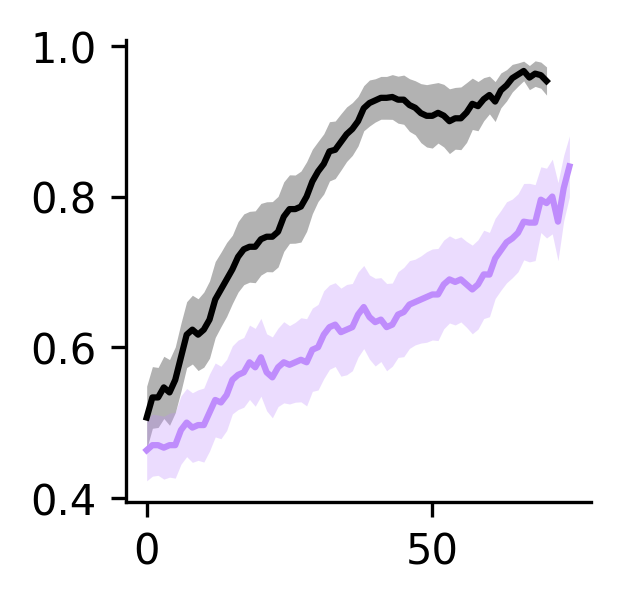

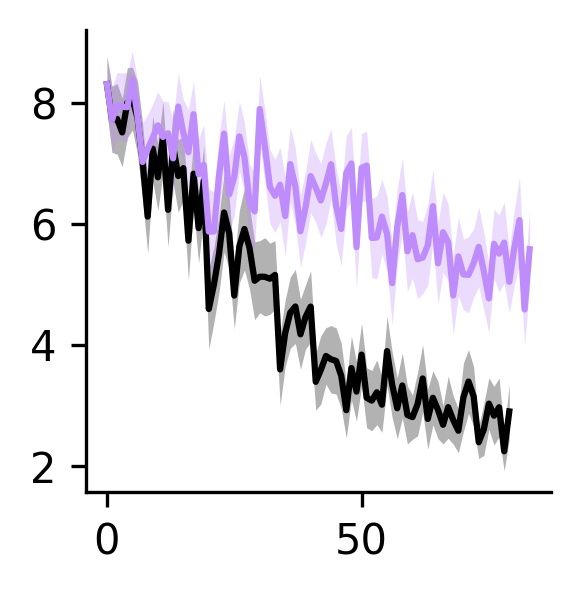

In [113]:
if scan_type in ('bci_spout_rew_scan',):

    n_trial_avg_window = 10 # trial average window

    MIN_REPEATS = 15
    
    n_max_trials_plot = 200
    trial_avg_window = 1 / n_trial_avg_window * np.ones((n_trial_avg_window,))

    # Just raw values versus trial time
    trial_outcomes_all = np.nan * np.ones((n_scan, n_repeats, n_max_trials_plot)) 
    mean_hit_rates_all = np.nan * np.ones((n_scan, n_repeats, n_max_trials_plot)) # Averaged over 10 trials
    trial_lens_all = np.nan * np.ones((n_scan, n_repeats, n_max_trials_plot)) 

    fig1, ax1 = plt.subplots(1, 1, figsize=(2, 2))
    fig2, ax2 = plt.subplots(1, 1, figsize=(2, 2))

    scan_colors = ('k', c_vals_p['post_reward'])
    
    for scan_idx, scan_val in enumerate(scan_vals):
        for repeat_idx in range(n_repeats):
            task_hist = task_hists_all[scan_idx][repeat_idx]

            trial_outcomes_all[scan_idx, repeat_idx, :len(task_hist['trial_outcomes'])] = task_hist['trial_outcomes']

            if len(task_hist['trial_outcomes']) < n_trial_avg_window:
                print('Not enough trials to plot.')
            else:
                mean_hit_rates = fftconvolve(task_hist['trial_outcomes'], trial_avg_window, mode='valid')

            n_trials_plot = min(mean_hit_rates.shape[0], n_max_trials_plot)
            mean_hit_rates_all[scan_idx, repeat_idx, :n_trials_plot] = mean_hit_rates[:n_trials_plot]

            ### Trial and pretrial lens ###
            start_idxs = task_hist['trial_starts']
            rew_idxs = bci_analysis.pad_rew_idxs(task_hist) # Adds nan pads to rew_idxs, should be same length as trial start idxs now

            trial_lens = np.array(rew_idxs) - np.array(start_idxs)
            trial_lens = np.where(np.isnan(trial_lens), 200, trial_lens) * 1/20 # nans become 10 seconds

            trial_lens_all[scan_idx, repeat_idx, :trial_lens.shape[0]] = trial_lens

        plot_limit = np.where(np.sum(~np.isnan(trial_outcomes_all[scan_idx]), axis=0) < MIN_REPEATS)[0][0] # Limit # of trials to minimum number of repeats
        
        print(np.sum(~np.isnan(trial_outcomes_all[scan_idx]), axis=0)[plot_limit:])
        
        plot_val = np.nanmean(mean_hit_rates_all[scan_idx, :, :plot_limit-n_trial_avg_window+1], axis=0)
        error_val = np.nanstd(mean_hit_rates_all[scan_idx, :, :plot_limit-n_trial_avg_window+1], axis=0) / np.sqrt(n_repeats)
        ax1.plot(np.arange(plot_limit-n_trial_avg_window+1), plot_val, color=scan_colors[scan_idx], label=scan_val_labels[scan_idx])    
        ax1.fill_between(np.arange(plot_limit-n_trial_avg_window+1), plot_val+error_val, plot_val-error_val, color=scan_colors[scan_idx], alpha=0.3, zorder=-5, linewidth=0.0)    

        plot_val = np.nanmean(trial_lens_all[scan_idx, :, :plot_limit], axis=0)
        error_val = np.nanstd(trial_lens_all[scan_idx, :, :plot_limit], axis=0) / np.sqrt(n_repeats)
        ax2.plot(np.arange(plot_limit), plot_val, color=scan_colors[scan_idx], label=scan_val_labels[scan_idx])    
        ax2.fill_between(np.arange(plot_limit), plot_val+error_val, plot_val-error_val, color=scan_colors[scan_idx], alpha=0.3, zorder=-5, linewidth=0.0)    

    for ax in (ax1, ax2,):
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)

#### Fig 4: Our BCI photostim

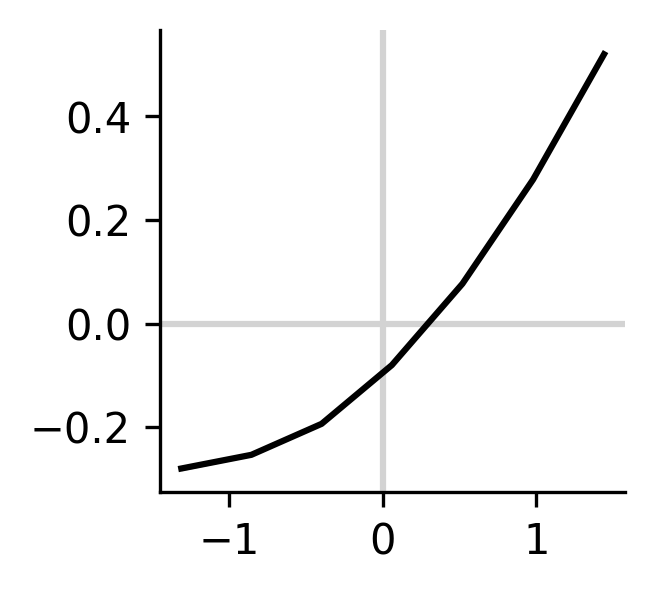

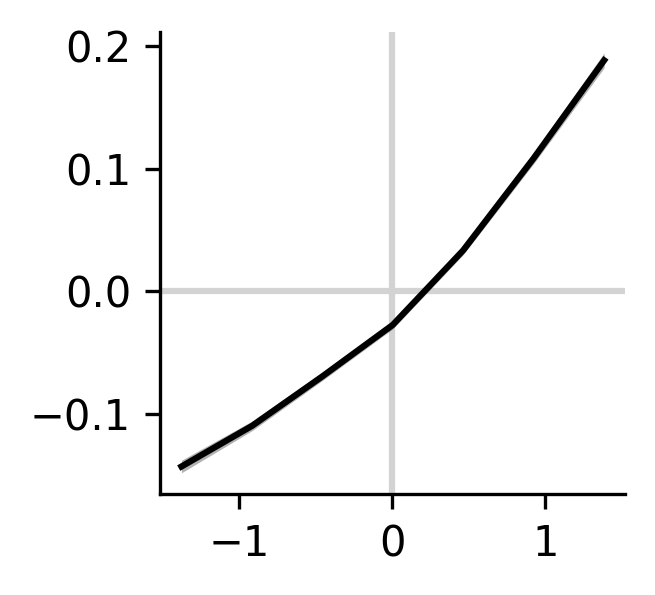

In [109]:
fig7, ax7 = plt.subplots(1, 1, figsize=(2, 2)) # Same day PS
fig8, ax8 = plt.subplots(1, 1, figsize=(2, 2)) # Delta PS

n_bins = 7
perc_range = (5, 95)

z_score = True

x = np.copy(corr_final_indirect_all)
y = np.copy(cc_final_indirect_all)

if z_score:
    x = (x - np.mean(x)) / np.std(x)
    y = (y - np.mean(y)) / np.std(y)
# ax7.scatter(x, y, marker='.', color=c_vals_l[1], alpha=0.1)

add_bin_plot(x, y, n_bins=n_bins, mode='equal_spaced', ax=ax7, perc_range=perc_range, yerr_mode='sem', color='k',
             error_draw_mode='fill_between', )

x = np.copy(delta_corr_indirect_all)
y = np.copy(delta_cc_indirect_all)

if z_score:
    x = (x - np.mean(x)) / np.std(x)
    y = (y - np.mean(y)) / np.std(y)

# ax8.scatter(x, y, marker='.', color=c_vals_l[1], alpha=0.1)

add_bin_plot(x, y, n_bins=n_bins, mode='equal_spaced', ax=ax8, perc_range=perc_range, yerr_mode='sem', color='k',
             error_draw_mode='fill_between', )

for ax in (ax7, ax8,):
    ax.axhline(0.0, color='lightgrey', zorder=-5)
    ax.axvline(0.0, color='lightgrey', zorder=-5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

#### Fig 6: Misc learning rule stuff

In [16]:
# This code has a slightly more complicated load strcuture so can just be run on its own
save_path = '/scratch/'

seed = 2012
n_repeats = 6

session_idx = 0

scan_vals_1 = ('backprop_sl', '3factor_sl', 'backprop', '3factor',)
n_scan_1 = len(scan_vals_1)

scan_vals_2_all = []

total_rewards = [[] for _ in range(len(scan_vals_1))]
rewards_all = [[] for _ in range(len(scan_vals_1))]
delta_W_recs = [[] for _ in range(len(scan_vals_1))]

bci_activity_all = [[] for _ in range(len(scan_vals_1))]
thresholds_all = [[] for _ in range(len(scan_vals_1))]
delta_W_in_all = [[] for _ in range(len(scan_vals_1))] 
mean_delta_W_in = [[] for _ in range(len(scan_vals_1))]
mean_delta_W_abs_in = [[] for _ in range(len(scan_vals_1))]
cn_delta_W_in = [[] for _ in range(len(scan_vals_1))]
cn_delta_W_in_z = [[] for _ in range(len(scan_vals_1))]

for scan_idx_1, scan_val_1 in enumerate(scan_vals_1):

    if scan_val_1 in ('backprop_sl', '3factor_sl',):
        scan_vals_2 = np.logspace(-2, 1, 10)
        # scan_vals_2 = np.logspace(-2, 1, 10)[:6] # Truncate this early for now since havent run backprop_sl high enough
        scan_type = 'learning_rule_comparison_rl_vs_sl'
    elif scan_val_1 in ('backprop', '3factor',):
        scan_vals_2 = np.logspace(-1, 1, 7)
        scan_type = 'learning_rule_comparison_deeper_credit'
    
    scan_vals_2_all.append(scan_vals_2)
    
    n_scan_2 = scan_vals_2.shape[0]
    total_rewards[scan_idx_1] = np.nan * np.ones((n_scan_2, n_repeats,))
    rewards_all[scan_idx_1] = np.nan * np.ones((n_scan_2, n_repeats, 6000,))
    delta_W_recs[scan_idx_1] = np.nan * np.ones((n_scan_2, n_repeats, task_params['n_neurons'], task_params['n_neurons']))
    
    bci_activity_all[scan_idx_1] = np.nan * np.ones((n_scan_2, n_repeats, 6000,))
    thresholds_all[scan_idx_1] = np.nan * np.ones((n_scan_2, n_repeats,))
    delta_W_in_all[scan_idx_1] = np.nan * np.ones((n_scan_2, n_repeats, task_params['n_neurons']))
    mean_delta_W_in[scan_idx_1] = np.nan * np.ones((n_scan_2, n_repeats,))
    mean_delta_W_abs_in[scan_idx_1] = np.nan * np.ones((n_scan_2, n_repeats,))
    cn_delta_W_in[scan_idx_1] = np.nan * np.ones((n_scan_2, n_repeats,))
    cn_delta_W_in_z[scan_idx_1] = np.nan * np.ones((n_scan_2, n_repeats,))
    
    for scan_idx_2, scan_val_2 in enumerate(scan_vals_2):
        for repeat_idx in range(n_repeats):

            repeat_seed = seed + repeat_idx

            task_params, train_params, net_params = default_toy_params(seed=repeat_seed)

            task_params['n_sessions'] = 1

            train_params['adjust_type'] = scan_val_1
            train_params['eta'] = scan_val_2
            
            local_path = save_path + '{}/'.format(scan_type) # save_path includes specifics about test
            local_path += build_scan_val_string((scan_val_1, scan_val_2))

            params = task_params, train_params, net_params

            params, train_outputs_all, net, task, task_ps = net_helpers.load_run(local_path, repeat_seed)
            
            total_rewards[scan_idx_1][scan_idx_2, repeat_idx] = np.nansum(train_outputs_all[session_idx]['reward'])
            rewards_all[scan_idx_1][scan_idx_2, repeat_idx] = train_outputs_all[session_idx]['reward']
            delta_W_recs[scan_idx_1][scan_idx_2, repeat_idx] = train_outputs_all[session_idx]['delta_W_rec']
            
            cn_idx = train_outputs_all[session_idx]['cn_idxs'][0]

            delta_W_in = np.sum(delta_W_recs[scan_idx_1][scan_idx_2, repeat_idx], axis=-1)

            bci_activity_all[scan_idx_1][scan_idx_2, repeat_idx] = train_outputs_all[session_idx]['bci_activity'][:, 0] # 0th bci mask
            thresholds_all[scan_idx_1][scan_idx_2, repeat_idx] = train_outputs_all[session_idx]['threshold']
            delta_W_in_all[scan_idx_1][scan_idx_2, repeat_idx] = delta_W_in
            mean_delta_W_in[scan_idx_1][scan_idx_2, repeat_idx] = np.mean(delta_W_in)
            mean_delta_W_abs_in[scan_idx_1][scan_idx_2, repeat_idx] = np.mean(np.sum(np.abs(delta_W_recs[scan_idx_1][scan_idx_2, repeat_idx]), axis=-1))
            cn_delta_W_in[scan_idx_1][scan_idx_2, repeat_idx] = delta_W_in[cn_idx]
            cn_delta_W_in_z[scan_idx_1][scan_idx_2, repeat_idx] = (delta_W_in[cn_idx] - np.mean(delta_W_in)) / np.std(delta_W_in)
                                  
print('Done!')

Done!


In [57]:
scan_idx_1 = 1
scan_idx_2 = 4
repeat_idx = 4
print(delta_W_in_all[scan_idx_1][scan_idx_2, repeat_idx])
print(cn_delta_W_in[scan_idx_1][scan_idx_2, repeat_idx])

[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         

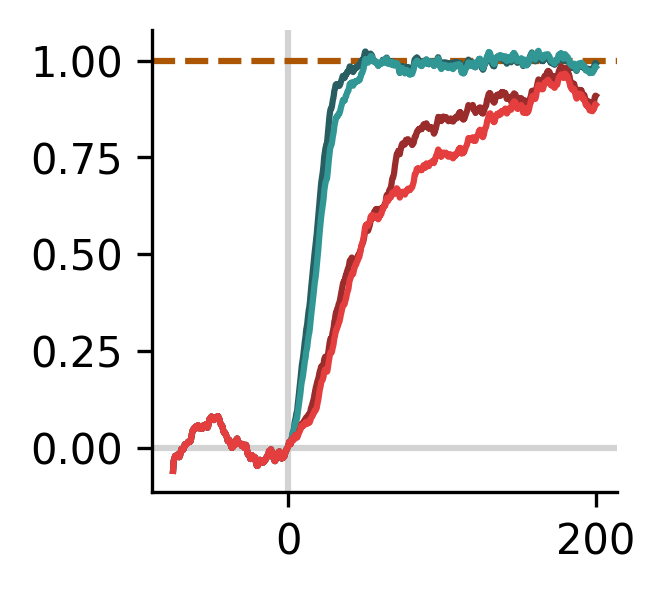

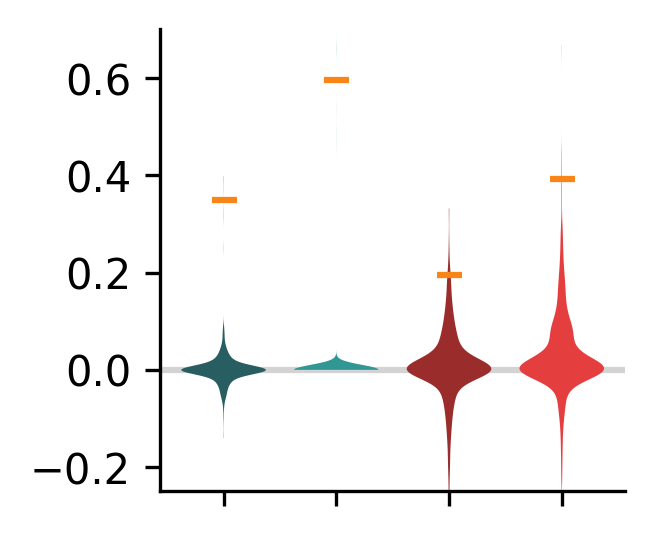

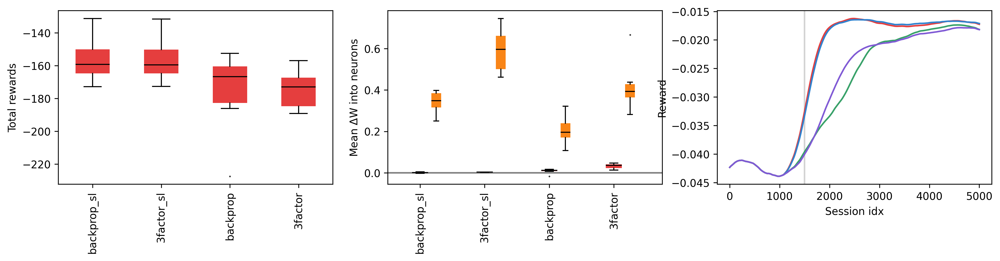

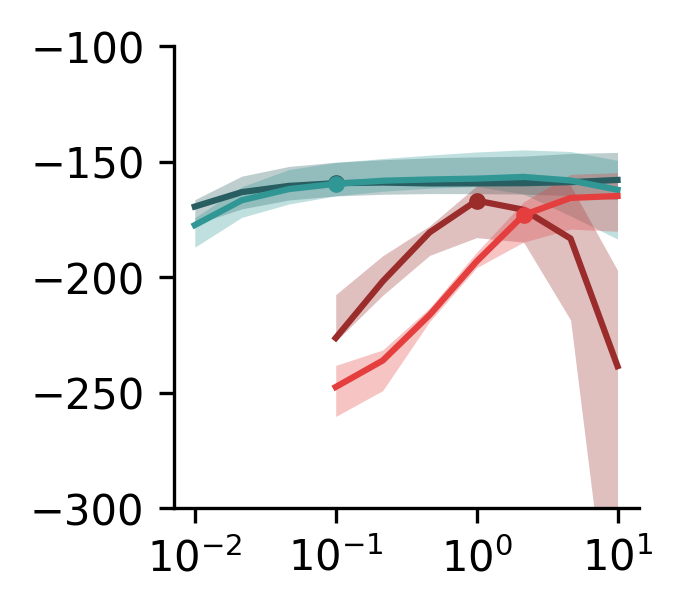

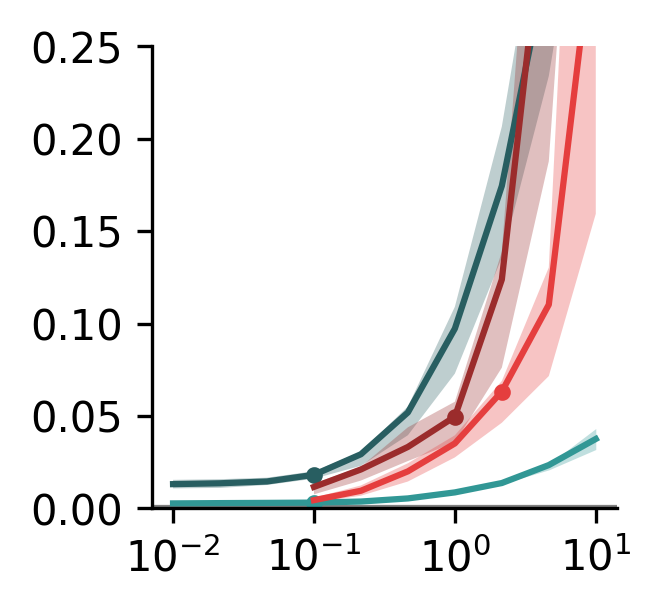

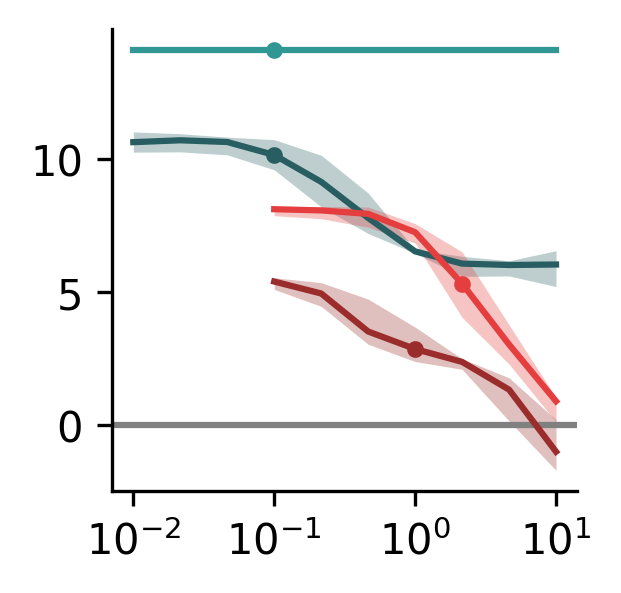

In [58]:
lr_scan_2_idxs = (3, 3, 3, 4,) # LR indexes that yield best performance

scan_2_idx = 0

fig7, ax7 = plt.subplots(1, 1, figsize=(2, 2))
fig8, ax8 = plt.subplots(1, 1, figsize=(2, 2))
fig, (ax1, ax2, ax6,) = plt.subplots(1, 3, figsize=(16, 3))

total_rewards_slice = np.zeros((n_scan_1, n_repeats,))
delta_W_in_slice = np.zeros((n_scan_1, n_repeats * task_params['n_neurons']))
mean_delta_W_in_slice = np.zeros((n_scan_1, n_repeats,))
cn_delta_W_in_sclie = np.zeros((n_scan_1, n_repeats,))

assert task_params['n_steps_stabilize'] == 2000

n_smooth = 500
smooth_fn = 1 / n_smooth * np.ones((n_smooth,))

plot_colors = (c_vals_d[5], c_vals[5], c_vals_d[0], c_vals[0])

for rule_idx in range(n_scan_1):
    scan_2_idx = lr_scan_2_idxs[rule_idx]

    total_rewards_slice[rule_idx] = total_rewards[rule_idx][scan_2_idx, :]
    delta_W_in_slice[rule_idx] = delta_W_in_all[rule_idx][scan_2_idx].flatten()
    mean_delta_W_in_slice[rule_idx] = mean_delta_W_in[rule_idx][scan_2_idx, :]
    cn_delta_W_in_sclie[rule_idx] = cn_delta_W_in[rule_idx][scan_2_idx, :]

    total_rewards_rule = rewards_all[rule_idx][scan_2_idx] # (n_lrs, n_repeats)
    total_rewards_rule_smooth =  np.apply_along_axis(lambda m: np.convolve(m, smooth_fn, mode='valid'), axis=-1, arr=total_rewards_rule)

    # total_rewards_rule_smooth = np.convolve(total_rewards_rule, smooth_fn, mode='valid')
    median_rewards_all = np.mean(total_rewards_rule_smooth, axis=0)
    median_rewards_smooth = np.convolve(median_rewards_all, smooth_fn, mode='valid')
    
    # ax6.plot(median_rewards_all, color=c_vals[rule_idx], label=scan_vals_1[rule_idx])
    ax6.plot(median_rewards_smooth, color=c_vals[rule_idx], label=scan_vals_1[rule_idx])
    
    # Rescales BCI activity to be normalized
    rescaled_bci_activity = bci_activity_all[rule_idx]
    stable_bci_activity = np.nanmean(rescaled_bci_activity[:, :, :task_params['n_steps_stabilize']], axis=-1, keepdims=True)
    rescaled_bci_activity = (rescaled_bci_activity - stable_bci_activity) / (thresholds_all[rule_idx][:, :, None] - stable_bci_activity)
    
    rescaled_bci_activity = rescaled_bci_activity[scan_2_idx, :]
    
    rescaled_bci_activity_smooth = np.convolve(np.mean(rescaled_bci_activity, axis=0), smooth_fn, mode='valid')
    
    x_vals = (np.arange(rescaled_bci_activity_smooth.shape[0]) - (task_params['n_steps_stabilize'] - n_smooth + 1)) * 1/20
    
    ax7.plot(x_vals, rescaled_bci_activity_smooth, color=plot_colors[rule_idx], label=scan_vals_1[rule_idx])

rew_bp = ax1.boxplot(total_rewards_slice.T, patch_artist=True, notch=False, positions=np.arange(n_scan_1),
                     widths=0.5, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                     boxprops={'linewidth':0.})

for patch in rew_bp['boxes']:
    patch.set_facecolor(c_vals[0])

delta_W_bp = ax2.boxplot(mean_delta_W_in_slice.T, patch_artist=True, notch=False, positions=np.arange(n_scan_1),
                         widths=0.25, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                         boxprops={'linewidth':0.})

delta_W_cn_bp = ax2.boxplot(cn_delta_W_in_sclie.T, patch_artist=True, notch=False, positions=np.arange(n_scan_1)+0.25,
                            widths=0.15, medianprops={'color':'k'}, flierprops={'marker':'.', 'markersize':1.0},
                            boxprops={'linewidth':0.})


delta_W_vp = ax8.violinplot(delta_W_in_slice.T, positions=np.arange(n_scan_1), showextrema=False, widths=0.75, points=1000)
# ax8.violinplot(cn_delta_W_in_sclie.T, positions=np.arange(n_scan_1)+0.25, showextrema=False, widths=0.15)

ax8.scatter(np.arange(n_scan_1), np.median(cn_delta_W_in_sclie, axis=-1), color=c_vals_p['cn'], marker='_')
# ax8.scatter(np.arange(n_scan_1), np.median(np.abs(delta_W_in_slice), axis=-1), color=plot_colors, marker='_')

for rule_idx, patch in enumerate(delta_W_bp['boxes']):
    patch.set_facecolor(plot_colors[rule_idx])
for rule_idx, patch in enumerate(delta_W_cn_bp['boxes']):
    patch.set_facecolor(c_vals_p['cn'])
for rule_idx, patch in enumerate(delta_W_vp['bodies']):
    patch.set_facecolor(plot_colors[rule_idx])   
    patch.set_alpha(1.0)
    
ax1.set_ylabel('Total rewards')

ax2.set_ylabel('Mean $\Delta$W into neurons')
ax2.axhline(0.0, color='grey', zorder=-5)

for ax in (ax1, ax2,):
    ax.set_xticks(np.arange(n_scan_1))
    ax.set_xticklabels(scan_vals_1, rotation=90)

ax6.set_xlabel('Session idx')
ax6.axvline(task_params['n_steps_stabilize'] - n_smooth + 1, color='lightgrey', zorder=-5)


ax7.axvline(0, color='lightgrey', zorder=-5)
ax7.axhline(0.0, color='lightgrey', zorder=-5)
ax7.axhline(1.0, color=c_vals_pd['cn'], linestyle='dashed', zorder=-5)
    
    
ax8.axhline(0.0, color='lightgrey', zorder=-5)
ax8.set_ylim((-0.25, 0.7))
ax8.set_xticks((0, 1, 2, 3,))
ax8.set_xticklabels(())
    
ax6.set_ylabel('Reward')

fig3, ax3 = plt.subplots(1, 1, figsize=(2, 2))
fig4, ax4 = plt.subplots(1, 1, figsize=(2, 2))
fig5, ax5 = plt.subplots(1, 1, figsize=(2, 2))

for rule_idx in range(n_scan_1):
    scan_vals_2 = scan_vals_2_all[rule_idx]
    scan_2_idx = lr_scan_2_idxs[rule_idx]
    total_rewards_rule = total_rewards[rule_idx] # (n_lrs, n_repeats)
    
    
    median_rewards = np.median(total_rewards_rule, axis=-1)
    err_rewards = (np.percentile(total_rewards_rule, 75, axis=-1), np.percentile(total_rewards_rule, 25, axis=-1))
    ax3.plot(scan_vals_2, median_rewards, color=plot_colors[rule_idx], label=scan_vals_1[rule_idx], marker=None)
    ax3.plot(scan_vals_2[scan_2_idx], median_rewards[scan_2_idx], color=plot_colors[rule_idx], marker='.')
    ax3.fill_between(scan_vals_2, err_rewards[0], err_rewards[1], 
                     color=plot_colors[rule_idx], alpha=0.3, zorder=-5, linewidth=0.0)

    mean_delta_W_in_rule = mean_delta_W_in[rule_idx] # (n_lrs, n_repeats)
    median_mean_delta_W_in = np.median(mean_delta_W_in_rule, axis=-1)
    mean_delta_W_in_rule = mean_delta_W_abs_in[rule_idx] # (n_lrs, n_repeats)
    median_mean_delta_W_in = np.median(mean_delta_W_in_rule, axis=-1)
    err_mean_delta_W_in = (np.percentile(mean_delta_W_in_rule, 75, axis=-1), np.percentile(mean_delta_W_in_rule, 25, axis=-1))
    ax4.plot(scan_vals_2, median_mean_delta_W_in, color=plot_colors[rule_idx], label=scan_vals_1[rule_idx], marker=None)
    ax4.plot(scan_vals_2[scan_2_idx], median_mean_delta_W_in[scan_2_idx], color=plot_colors[rule_idx], marker='.')
    ax4.fill_between(scan_vals_2, err_mean_delta_W_in[0], err_mean_delta_W_in[1], 
                     color=plot_colors[rule_idx], alpha=0.3, zorder=-5, linewidth=0.0)

    cn_delta_W_in_z_rule = cn_delta_W_in_z[rule_idx] # (n_lrs, n_repeats)
    median_cn_z_score_rule = np.median(cn_delta_W_in_z_rule, axis=-1)
    err_cn_z_score_rule = (np.percentile(cn_delta_W_in_z_rule, 75, axis=-1), np.percentile(cn_delta_W_in_z_rule, 25, axis=-1))
    ax5.plot(scan_vals_2, median_cn_z_score_rule, color=plot_colors[rule_idx], label=scan_vals_1[rule_idx], marker=None)
    ax5.plot(scan_vals_2[scan_2_idx], median_cn_z_score_rule[scan_2_idx], color=plot_colors[rule_idx], marker='.')
    ax5.fill_between(scan_vals_2, err_cn_z_score_rule[0], err_cn_z_score_rule[1], 
                     color=plot_colors[rule_idx], alpha=0.3, zorder=-5, linewidth=0.0)

# ax3.set_ylabel('Total rewards')

ax3.set_ylim((-300, -100))

# ax4.set_ylabel('Mean $\Delta$W into neurons')
ax4.axhline(0.0, color='grey', zorder=-5)
# ax4.set_ylim((-0.1, 0.1))
ax4.set_ylim((-0.0, 0.25))


# ax5.set_ylabel('CN $\Delta$W in z-score')
ax5.axhline(0.0, color='grey', zorder=-5)

for ax in (ax3, ax4, ax5,):
    # ax.set_xlabel('LR')
    ax.set_xscale('log')
    ax.set_xticks((1e-2, 1e-1, 1e0, 1e1,))
    # ax.legend()
    
for ax in (ax3, ax4, ax5, ax7, ax8,):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

('RPE-dev product', 'CN product', 'CN dev-dev product', 'W_rec input to CN', 'W_rec output from CN', 'W_inp sim rel. to CN')
RPE-dev product - slope 9.5e+00 p 0.0e+00 r^2 8.16e-01
W_rec input to CN - slope 1.2e-03 p 1.1e-20 r^2 2.16e-02
W_inp sim rel. to CN - slope 1.6e+00 p 1.3e-38 r^2 4.16e-02
$\Delta$W_in
  [1.38224922e-01 1.22304544e-03 0.00000000e+00 1.65332669e+00]
  [1.89160745e-54 2.90179567e-22            nan 3.39832537e-40]
$\Delta$W_out
  [0.14254785 0.00037241 0.         0.28762285]
  [1.27779683e-222 5.82765922e-010             nan 1.11504708e-006]


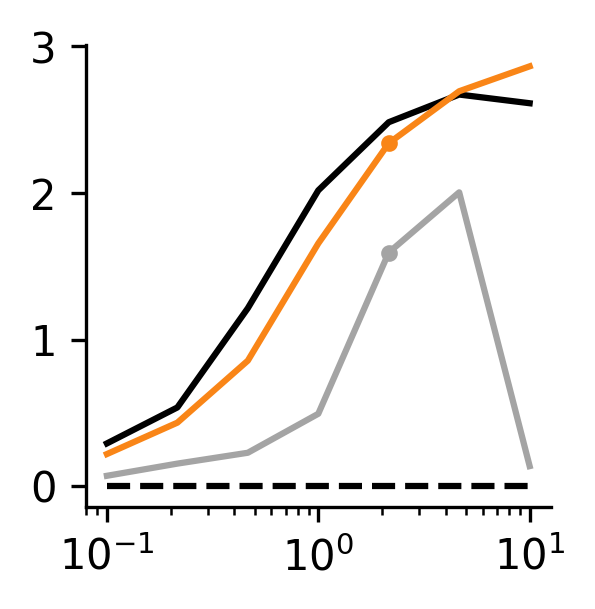

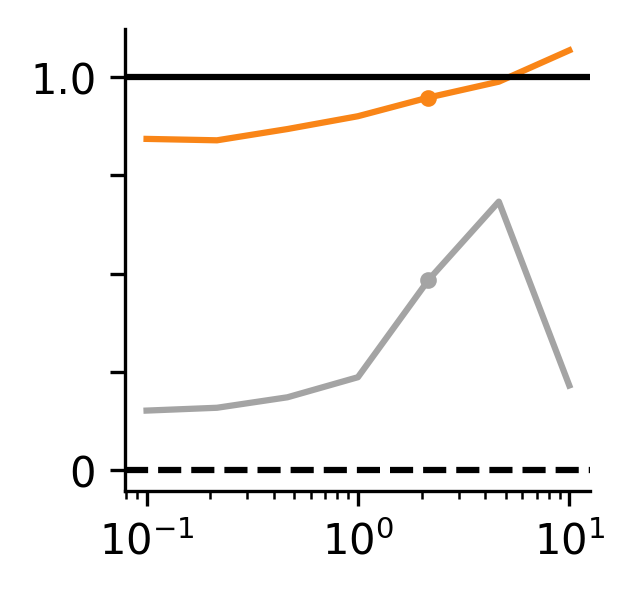

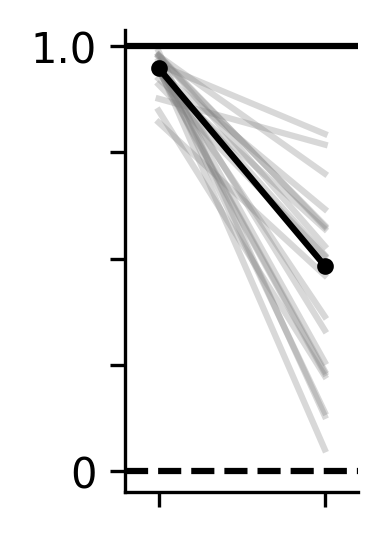

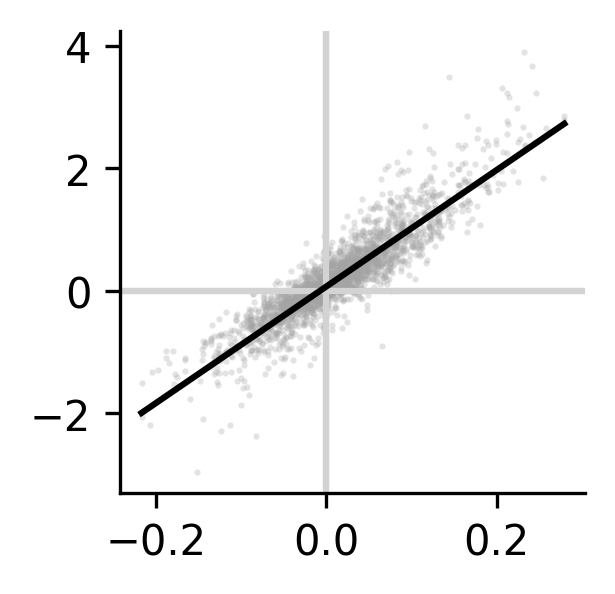

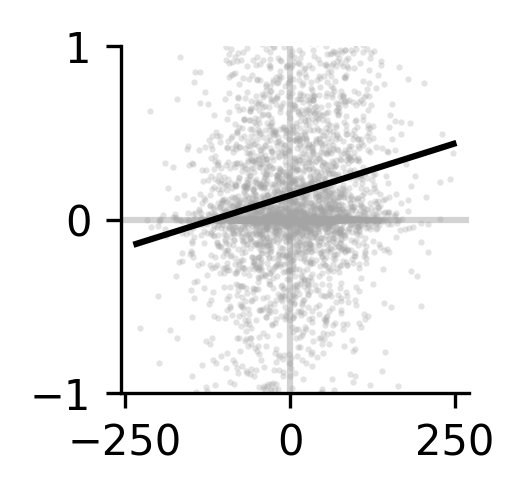

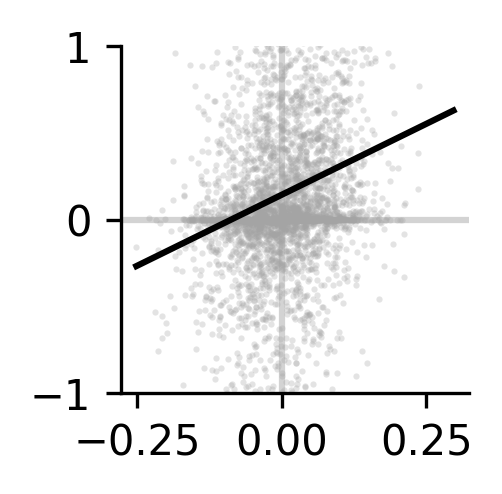

In [98]:
if scan_type not in ('train_cn_weights_vs_not',):
    raise ValueError('Improper scan type for this plotting code')

# How does freezing and not freezing the CN affect things
n_scan_1 = len(scan_vals_1)
n_scan_2 = len(scan_vals_2)

exemplar_scan_2_idx = 4

fig4, ax4 = plt.subplots(1, 1, figsize=(2, 2)) # Raw reward rates vs. learning rate
fig5, ax5 = plt.subplots(1, 1, figsize=(2, 2)) # Relative amount of learning vs. learning rate
fig1, ax1 = plt.subplots(1, 1, figsize=(1, 2)) # Exemplar change in performance
fig2, ax2 = plt.subplots(1, 1, figsize=(2, 2)) # Exemplar weight change explained from RPE corr

fig6, ax6 = plt.subplots(1, 1, figsize=(1.5, 1.5)) # Exemplar weight change explained from CN input
fig7, ax7 = plt.subplots(1, 1, figsize=(1.5, 1.5)) # Exemplar weight change explained from input similarity

# Convert total rewards into a reward rate
reward_rate = np.zeros_like(total_rewards)
for repeat_idx in range(n_repeats):
    reward_rate[:, repeat_idx] = np.nan # default
    if total_rewards[0, repeat_idx] < -400:
        print('Skipping idx {}, too low of reward even with no training'.format(repeat_idx))
    elif total_rewards[3, repeat_idx] < -400:
        print('Skipping idx {}, too low of reward for non-CN training'.format(repeat_idx))
    else:
        reward_rate[:, repeat_idx] = total_rewards[:, repeat_idx] / (task_params['n_steps'] - task_params['n_steps_stabilize'])

learning_amounts = np.zeros((n_scan_2, 2, n_repeats,))
reward_rate = REWARD_SCALE * reward_rate.reshape(n_scan_1, n_scan_2, n_repeats)
total_reward_rate_change = reward_rate[1, :, :] - reward_rate[0, :, :]

for scan_2_idx in range(n_scan_2):
    
    reward_rate_slice = reward_rate[:, scan_2_idx, :]

    # total_reward_rate_change = reward_rate_slice[1, :] - reward_rate_slice[0, :] # All versus none

    learning_amounts[scan_2_idx, 0, :] = (reward_rate_slice[2, :] - reward_rate_slice[0, :]) / total_reward_rate_change[scan_2_idx] # cn_only
    learning_amounts[scan_2_idx, 1, :] = (reward_rate_slice[3, :] - reward_rate_slice[0, :]) / total_reward_rate_change[scan_2_idx] # non-cn_only

    if scan_2_idx == exemplar_scan_2_idx:
        for repeat_idx in range(n_repeats):
            ax1.plot(np.arange(2), learning_amounts[scan_2_idx, :, repeat_idx], color='grey', zorder=-5, alpha=0.3)
        ax1.plot(np.arange(2), np.median(learning_amounts[scan_2_idx], axis=-1), marker='.', color='k')

bl_reward_rate = np.median(reward_rate[0], axis=-1)[0]
        
ax4.plot(scan_vals_2, np.median(reward_rate[0], axis=-1) - bl_reward_rate, color='k', linestyle='dashed', label='No train')
ax4.plot(scan_vals_2, np.median(reward_rate[1], axis=-1) - bl_reward_rate, color='k', label='All syn.')
ax4.plot(scan_vals_2, np.median(reward_rate[2], axis=-1) - bl_reward_rate, color=c_vals_p['cn'], label='CN only')
ax4.plot(scan_vals_2, np.median(reward_rate[3], axis=-1) - bl_reward_rate, color='#A4A4A4', label='Non-CN only')
ax4.scatter(scan_vals_2[exemplar_scan_2_idx], np.median(reward_rate[2], axis=-1)[exemplar_scan_2_idx]- bl_reward_rate, color=c_vals_p['cn'], marker='.')
ax4.scatter(scan_vals_2[exemplar_scan_2_idx], np.median(reward_rate[3], axis=-1)[exemplar_scan_2_idx]- bl_reward_rate, color='#A4A4A4', marker='.')

# ax4.set_ylabel('Reward rate')

ax5.plot(scan_vals_2, np.median(learning_amounts[:, 0, :], axis=-1), color=c_vals_p['cn'], label='CN only')
ax5.plot(scan_vals_2, np.median(learning_amounts[:, 1, :], axis=-1), color='#A4A4A4', label='Non-CN only')
ax5.scatter(scan_vals_2[exemplar_scan_2_idx], np.median(learning_amounts[:, 0, :], axis=-1)[exemplar_scan_2_idx], color=c_vals_p['cn'], marker='.')
ax5.scatter(scan_vals_2[exemplar_scan_2_idx], np.median(learning_amounts[:, 1, :], axis=-1)[exemplar_scan_2_idx], color='#A4A4A4', marker='.')

for ax in (ax4, ax5,):
    ax.set_xscale('log')
    # ax.set_xlabel('LR')
    # ax.legend()
        
scan_1_idx = 3 # Only CN training

predictors_fit_all = []
W_init_to_cn_all = []
delta_W_in_all = []
delta_W_out_all = []

for repeat_idx in range(n_repeats):
    scan_idx = exemplar_scan_2_idx + n_scan_2 * scan_1_idx
    cn_idx = cn_idxs.reshape(n_scan_1, n_scan_2, n_repeats, 1)[scan_1_idx, exemplar_scan_2_idx, repeat_idx, 0]

    # print(cn_idx)
    # print(cn_idxs[scan_idx, repeat_idx, 0])
    
    W_init =  W_rec_inits[scan_idx, repeat_idx]
    W_final = W_rec_finals[scan_idx, repeat_idx]
    delta_W = W_rec_finals[scan_idx, repeat_idx] - W_rec_inits[scan_idx, repeat_idx]
    delta_W_in = np.mean(delta_W, axis=-1)
    delta_W_out = np.mean(delta_W, axis=0)
    
    W_init_to_cn_all.append(np.delete(W_init[cn_idx, :], cn_idx))
    delta_W_in_all.append(np.delete(delta_W_in, cn_idx))
    delta_W_out_all.append(np.delete(delta_W_out, cn_idx))
    
    predictors_fit_all.append(
        np.delete(predictors_all[scan_idx, repeat_idx], cn_idx, axis=-1)
    )
    
    # ax2.scatter(W_init[cn_idx, :], delta_W_in, color='k', marker='.')
    # add_regression_line(W_init[cn_idx, :], delta_W_in, ax=ax2, color='k')
    # ax2.scatter(W_init[:, cn_idx], delta_W_in, color=c_vals[0], marker='.')
    # add_regression_line(W_init[:, cn_idx], delta_W_in, ax=ax2, color=c_vals[0])

predictors_fit_all = np.concatenate(predictors_fit_all, axis=-1)
W_init_to_cn_all = np.concatenate(W_init_to_cn_all)
delta_W_in_all = WEIGHT_SCALE * np.concatenate(delta_W_in_all)
delta_W_out_all = WEIGHT_SCALE * np.concatenate(delta_W_out_all)

print(predictor_names)

for ax, pred_idx in zip((ax2, ax6, ax7,), (0, 3, 5)):
    x = predictors_fit_all[pred_idx]
    y = delta_W_in_all
    
    if pred_idx in (3,):
        x *= WEIGHT_SCALE
    
    ax.scatter(x, y, color='#A4A4A4', marker='.', s=1.0, alpha=0.3, zorder=-5)
    # add_regression_line(predictors_fit_all[pred_idx], delta_W_in_all, ax=ax, color='k')
    
    slope, intercept, rvalue, pvalue, _ = linregress(predictors_fit_all[pred_idx], delta_W_in_all)
    
    x_plot = np.linspace(np.min(x), np.max(x), 10)
    y_plot = slope * x_plot + intercept
    label = 'p {:.2e}, $r^2$: {:.2e}'.format(pvalue, rvalue**2)
    
    ax.plot(x_plot, y_plot, color='k')
    
    print('{} - slope {:.1e} p {:.1e} r^2 {:.2e}'.format(
        predictor_names[pred_idx], slope, pvalue, rvalue**2
    ))
    
    # ax.set_xlabel(predictor_names[pred_idx])
    # ax.set_ylabel('$\Delta$W into neuron')
    
    ax.axhline(0.0, color='lightgrey', linestyle='solid', zorder=-10)
    ax.axvline(0.0, color='lightgrey', linestyle='solid', zorder=-10)

pred_keep_idxs = np.array((3, 4, 5))

X = predictors_fit_all[pred_keep_idxs].T
X = sm.add_constant(X)

fit_model = sm.OLS(delta_W_in_all[:, None], X, missing='none') # nans should be caught above
results = fit_model.fit()
print('$\Delta$W_in')
print(' ', results.params)
print(' ', results.pvalues)

fit_model = sm.OLS(delta_W_out_all[:, None], X, missing='none') # nans should be caught above
results = fit_model.fit()
print('$\Delta$W_out')
print(' ', results.params)
print(' ', results.pvalues)


# ax3.scatter(W_final[cn_idx, :], delta_W_in, color='k', marker='.')
# add_regression_line(W_final[cn_idx, :], delta_W_in, ax=ax3, color='k')

for ax in (ax1, ax5):
    ax.axhline(0.0, color='k', linestyle='dashed')
    ax.axhline(1.0, color='k', linestyle='solid')
    # ax.set_ylabel('Amount of learning\n(1.0 = all syn., 0.0 = no train)')
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels([0, None, None, None, 1.0])
    
ax1.set_xticks([0, 1])
ax1.set_xticklabels([])
# ax1.set_xticklabels(['CN only', 'Non-CN only'])
ax1.set_xlim((-0.2, 1.2))
# ax1.set_xlabel('Rec. training mode')

for ax in (ax6, ax7,):
    ax.set_ylim((-1, 1))
    ax.set_yticks((-1, 0, 1))

for ax in (ax2, ax3,):
    # ax.legend()
    ax.axhline(0.0, color='lightgrey', linestyle='solid', zorder=-5)
    ax.axvline(0.0, color='lightgrey', linestyle='solid', zorder=-5)
    
for ax in (ax1, ax2, ax4, ax5, ax6, ax7):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

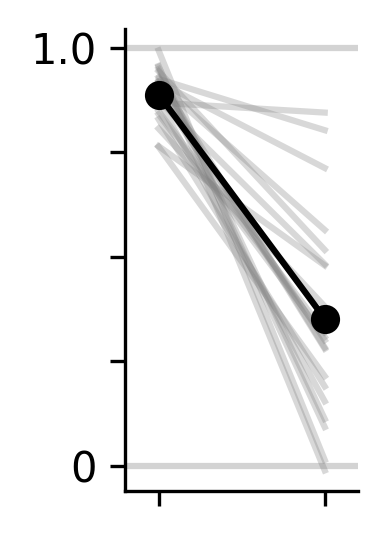

In [29]:
if scan_type in ('train_cn_weights_vs_not', 'train_cn_weights_vs_not_3factor_np',):
    
    if scan_type in ('train_cn_weights_vs_not',):
        iteration_vals = ((0, 0),) # offset_idx, color_idx
    elif scan_type in ('train_cn_weights_vs_not_3factor_np',):
        iteration_vals = ((0, 0,), (4, 1,),) # offset_idx, color_idx
    
    fig, ax1 = plt.subplots(1, 1, figsize=(1, 2))
    
    # Convert total rewards into a reward rate
    reward_rate = np.zeros_like(total_rewards)
    for repeat_idx in range(n_repeats):
        reward_rate[:, repeat_idx] = np.nan # default
        if total_rewards[0, repeat_idx] < -400:
            print('Skipping idx {}, too low of reward even with no training'.format(repeat_idx))
        elif total_rewards[3, repeat_idx] < -400:
            print('Skipping idx {}, too low of reward for non-CN training'.format(repeat_idx))
        else:
            reward_rate[:, repeat_idx] = total_rewards[:, repeat_idx] / (task_params['n_steps'] - task_params['n_steps_stabilize'])
    
    for offset_idx, color_idx in iteration_vals:
        
        total_reward_rate_change = reward_rate[offset_idx+1, :] - reward_rate[offset_idx+0, :] # All versus none
        
        learning_amounts = np.zeros((2, n_repeats,))
        learning_amounts[0, :] = (reward_rate[offset_idx+2, :] - reward_rate[offset_idx+0, :]) / total_reward_rate_change # cn_only
        learning_amounts[1, :] = (reward_rate[offset_idx+3, :] - reward_rate[offset_idx+0, :]) / total_reward_rate_change # non-cn_only

        for repeat_idx in range(n_repeats):
            ax1.plot(np.arange(2), learning_amounts[:, repeat_idx], marker=None, color='grey', alpha=0.3)
        ax1.plot(np.arange(2), np.mean(learning_amounts, axis=-1), marker='o', color='k')
        
    ax1.axhline(0.0, color='lightgrey', zorder=-5)
    ax1.axhline(1.0, color='lightgrey', zorder=-5)

    ax1.set_xticks([0, 1])
    ax1.set_xticklabels([])
    # ax1.set_xticklabels(['CN only', 'Non-CN only'])
    ax1.set_xlim((-0.2, 1.2))
    # ax1.set_xlabel('Rec. training mode')
    
    ax1.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax1.set_yticklabels([0, None, None, None, 1.0])
    
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    # ax1.set_ylabel('Amount of learning\n(1.0 = all weights, 0.0 = no weights)')

### Old Code

LinearRegression slope: 0.33626604 , int: -0.48185205
WLS slope: 0.33626595198120435 , int: -0.4818504277851817 , p: 9.871484386016922e-11
Inverse slope: 0.33626595581858176
linregress slope: 0.33626595198120435 , int: -0.4818504277851847 , p: 9.871484386016887e-11
LinearRegression  (scaled) slope: 0.33626604 , int: -0.48185205


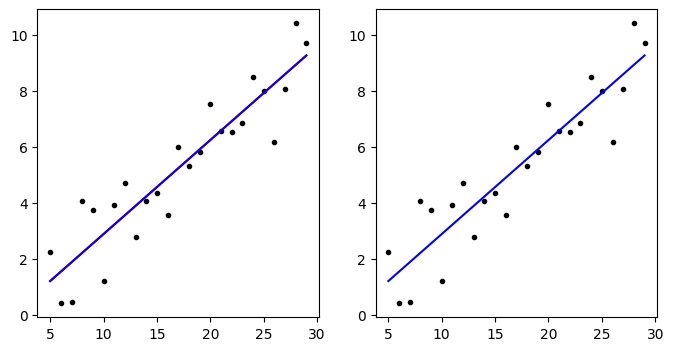

In [ ]:
from sklearn.linear_model import LinearRegression
from scipy.stats import linregress
import statsmodels.api as sm

np.random.seed(1112222)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

x = np.arange(5, 30, dtype=np.float32)
y = 0.3 * x + np.random.normal(size=x.shape) + 0.2

# weights = np.abs(np.random.normal(size=x.shape))
weights = 1.0 * np.ones_like(x)
# weights[-2:] = 2000000000000.0
# weights = None

weights = weights / np.max(weights)

X = x[:, np.newaxis]
Y = y[:, np.newaxis]

reg = LinearRegression()
reg.fit(X, Y, sample_weight=weights) # Red

print('LinearRegression slope:', reg.coef_[0, 0], ', int:', reg.intercept_[0])

X = sm.add_constant(X)
wls_model = sm.WLS(Y, X, weights=weights)
results = wls_model.fit()
results.rsquared
print('WLS slope:', results.params[1], ', int:', results.params[0], ', p:', results.pvalues[1])

ax1.plot(x, reg.coef_[0, 0] * x + reg.intercept_[0], color='r', label='LinearRegression')

if weights is not None:
    x_copy = np.sqrt(weights) * x
    y_copy = np.sqrt(weights) * y
    # x_copy = np.matmul(np.diag(np.sqrt(weights)), x)
    # y_copy = np.matmul(np.diag(np.sqrt(weights)), y)
else:
    x_copy = x.copy()
    y_copy = y.copy()

X = x_copy[:, np.newaxis] - np.mean(x_copy)
Y = y_copy[:, np.newaxis] - np.mean(y_copy)
print('Inverse slope:', (np.linalg.inv(X.T @ X) @ X.T @ Y)[0, 0])

slope, intercept, rvalue, pvalue, se = linregress(x_copy, y_copy) # Blue
print('linregress slope:', slope, ', int:', intercept, ', p:', pvalue)

ax1.plot(x, slope * x + intercept, color='b', label='linregress')

reg2 = LinearRegression()
reg2.fit(x_copy[:, np.newaxis], y_copy[:, np.newaxis], sample_weight=None)

print('LinearRegression  (scaled) slope:', reg2.coef_[0, 0], ', int:', reg2.intercept_[0])

ax1.scatter(x, y, color='k', marker='.')

ax2.scatter(x_copy, y_copy, color='k', marker='.')
ax2.plot(x_copy, slope * x_copy + intercept, color='b', label='linregress')

In [ ]:
import time

run = True
minimal = False

seed = 2010 # 2002

def default_toy_params(seed=0):

    task_params = {
        # noise, noise_silence, noise_constant_rpe, noise_stim,
        # noise_constant_rpe_two_stim, noise_multi_stim, trial_structure_task
        # our_bci
        'task_type': 'our_bci', #'simple_bci',

        'z_score_activities': False, # z-scores activities based on pre-session, does this before BCI map and for manifold calculation

        'n_bci_masks': 1,
        'bci_choice': 'activity_high', #'activity_high', # random, activity_percentile, activity_high, manifold, intuitive, intuitive_manifold

        'activity_percentile': 0.7, # For percentile and high_activity, determines tuning percentile.
        'n_cns': 1, # Used for settings where number of CNs is varaible (n_hot), automatically set for other settings
        'manifold_mode': None, # pc, fa; whether to use PCA or FA to determine the low-dimensional manifold
        'manifold_idx': None, # Used for manfiold settings, determines PC idx (lower = higher var exp)

        'dyn_threshold_type': 'percentile_bci_activity', # percentile_bci_activity (what to set the threshold based on)
        'dyn_threshold_perc': 0.9, #1.0, # Sets threshold to be at certain percentile of activity (only used for perc_ above)

        'n_neurons': 200,
        'n_steps': 6000, #4000, # 2500,
        'n_steps_stabilize': 2000, #1000, #500,
        'n_steps_evaluate': 0, # Stops training to observe solution

        'reward_structure': 'trapezoid', # trapezoid, quadratic
        'normalize_reward': True, # False, # Makes value of rewards depend on median and threshold during presession
        'n_reward_delay': 0, # Number of time steps to delay the current reward

        'task_scale': 0.1, # Determines the scale of the noise input and also the constant input when used
        'task_thresh_mult': 0.5, # Determines difficulty of task relative to task_scale, only used when threshold is set during presession

        'n_sessions': 1,
        'use_max_activity': False, # Clip activity at maximum, helps stabilize training with recurrent adjustment

        'seed': seed,

        # Solution criteria
        'solution_type': 'avg_activity', # None, avg_activity
        'sol_n_steps': 50,

        ### Parameters used only for special tests ###
        'constant_rpe_val': 0.025, # Only used if RPE is held constant

        # Used to introduce additional correlation into activity
        'correlation_type': None, # None, activity, weights
        'on_idx': 20,
        'on_weight': 1.0,

        # Used to test how non-BCI components affect training
        'non_bci_deviation_zero': False,

        ### Perturbations to training
        # Step_idx to apply perturbation, preturbation type, perturbation params
        # 'perturbations': ( # To test BCI mask perturbations
        #     (2000, 'bci_masks_new_pc', {'pc_idx': 80}), # 10, 80
        #     (3000, 'bci_masks_new_pc', {'pc_idx': 2}),
        # )
        # 'perturbations': ( # To test BCI mask perturbations
        #     (6000, 'center_out', {'perm_mode': 'om_top_stim_stds', # wm, wm_n_top, om_raw, om_top_stds, om_top_stim_stds
        #                           'n_perm_dims': 100,}),
        #     (26000, 'center_out', {'perm_mode': 'intuitive',
        #                           'n_perm_dims': 60,}),
        # )
    }

    # Some defaults, sets all to None
    default_fills = ['bci_masks', 'activity_subtract', 'activity_stds',
                     'threshold', 'width', 'perturbations', 'dyn_width_perc',]
    for default_fill in default_fills:
        if default_fill not in task_params: task_params[default_fill] = None

    assert task_params['n_reward_delay'] >= 0. # Negative values don't make sense here

    train_params = {
        'eta': 2e0, #5e0,
        'n_window_reward': 200, # Size of the average window for reward baseline
        'n_window_baseline': 20, # Size of the average window for activity
        'n_steps_per_loss': 5, # How often to total RPE and adjust weights
        'eligibility_acc_type': 'running_average', # acc_and_wipe, running_average
        'n_window_elig': 5, # Only used for 'running_average' option, how long to keep eligibility

        'adjust_type': '3factor',
        # backprop:
        # backprop_no_reset:
        # 3factor: our 3-factor, post dev * phi^prime * pre
        # 3factor_leak: our 3-factor, but correctly calculates leak term contribution
        # 3factor_nophiprime: our 3-factor without phi^prime term (EH learning with postactivation)
        # 3factor_nodev: our 3-factor without post dev, just post * phi^prime * pre
        # 3factor_vanilla_hebbian: 3-factor with just the usual Hebbian, essentially equivalent to having both no phi prime and no deviation
        # 3factor_eh: True EH learning, use preactivations for postsynaptic activity
        # 3factor_miconi: Same rule used in Miconi
        # 3factor_miconi_insp: Same rule used in Miconi, but actually uses postsynaptic deviations
        # 3factor_nope_pert: Node perturbation.
        # 3factor_predevs: Deviation only in presyn
        # 3factor_two_devs: Deviation in post and presyn deviations
        'rpe_clip': 0.05, # None, 0.1; maximum RPE (per step) magnitude, stabilizes training a bit

        'print_every': 100,
        'weight_reg': 'L2',
        'reg_lambda': 0., #1e-4,
    }

    net_params = {
        'W_inp_type': 'gaussian', # gaussian, diagonal, zeros, perm
        'W_rec_type': 'gaussian',
        'W_inp_adjust': False,
        'W_rec_adjust': True,

        'weight_mask_modes': None, # None, cn_freeze, large_cn_input_freeze
        'W_inp_adjust_mask': None,
        'W_rec_adjust_mask': None,

        'direct_input': False, # For more control over input into hidden activity

        'leak_term': 0.8, # alpha, 0.0 means no leak
        'leak_type': 'membrane', # activity, membrane
    }

    task_params['n_stim'] = None
    task_params['n_inp'] = task_params['n_neurons']
    task_params['net_leak_term'] = net_params['leak_term']
    task_params['direct_input'] = net_params['direct_input']

    if task_params['task_type'] in ('our_bci',):
        print('Overriding task_params with our BCI defaults.')
        task_params, train_params, net_params = set_to_our_bci_defaults(task_params, train_params, net_params)

    return (task_params, train_params, net_params)

def net_forward(W_inp, input, W_rec, prev_activity, prev_activity_pre_act, net_params):
    ### Network forward pass ###
    W_rec_h = np.matmul(W_rec, prev_activity)

    if net_params['direct_input']: # input already takes into account W_inp
        output_pre_act = np.copy(input + W_rec_h)
    else:
        W_inp_x = np.matmul(W_inp, input)
        output_pre_act = np.copy(W_inp_x + W_rec_h)

    if net_params['leak_type'] in ('activity',):
        leak_term = net_params['leak_term'] * prev_activity
        output = leak_term + (1. - net_params['leak_term']) * act_fn(output_pre_act)
    elif net_params['leak_type'] in ('membrane',):
        leak_term = net_params['leak_term'] * prev_activity_pre_act
        output_pre_act = leak_term + (1. - net_params['leak_term']) * output_pre_act
        output = act_fn(output_pre_act)

    return output, output_pre_act

def train_task(params, net=None, output_vars=[], verbose=True):

    task_params, train_params, net_params = params

    task_scale = task_params['task_scale'] # Determines the scale of the noise input and also the constant input when used

    # Set seed/state here, determines input noise (see below for additional seed sets)
    if net is not None:
        np.random.set_state(net['rng_state'])
    else:
        np.random.seed(task_params['seed'])

    train_outputs_all = []

    if task_params['add_fl']:
        raise NotImplementedError()
        task_params = fluorescence_init(task_params)

    # Repeats everything for each session, just doesn't reset network and carries over certain baselines
    for session_idx in range(task_params['n_sessions']):

        train_outputs = {} # This will be populated throughout session, then collected in a list for output

        # During stabilization, doesn't adjust network, used to estimate means and determine CN choice
        rewards_stabilize = np.zeros((task_params['n_steps_stabilize'],)) # No need to pad with reward delay, already incorporated to reward assignment
        activities_stabilize = np.zeros((task_params['n_steps_stabilize'], task_params['n_neurons'],))
        activities_pre_act_stabilize = np.zeros((task_params['n_steps_stabilize'], task_params['n_neurons'],))

        prev_activity = None # Overriden below if specifying the network's state (only do this if generating more activity)
        prev_activity_pre_act = None

        if net is not None:
            if verbose:
                print('--- Session idx {}: Using passed network ---'.format(session_idx))

            W_inp = net['W_inp']
            W_rec = net['W_rec']
            last_reward = net['last_reward']
            if 'prev_activity' in net and 'prev_activity_pre_act' in net: # Initialize these if we want to set the state too
                prev_activity = net['prev_activity']
                prev_activity_pre_act = net['prev_activity_pre_act']
            if net_params['weight_mask_modes'] is not None:
                raise NotImplementedError()
        elif session_idx == 0: # Things set only in first session, unless an existing network is passed
            if verbose:
                print('--- Session idx {}: Initializing network ---'.format(session_idx))
            if net_params['direct_input'] and net_params['W_inp_adjust']:
                raise NotImplementedError('Unclear how this would work if W_inp can be adjusted, assumes it is constant.')

            if net_params['W_inp_type'] in ('diagonal',):
                assert task_params['n_inp'] == task_params['n_neurons']
                W_inp = np.eye(task_params['n_neurons'])
            elif net_params['W_inp_type'] in ('gaussian',):
                W_inp = 1 / np.sqrt(task_params['n_inp']) * np.random.normal(size=(task_params['n_neurons'], task_params['n_inp']))
                if task_params['task_type'] in ('noise_multi_stim', 'noise_constant_rpe_two_stim',): # Makes W_inp block diagonal, so only subset of neurons excited
                    n_inp_over2 = int(np.round(task_params['n_inp'] / 2))
                    W_inp = 2 * W_inp # Renormalizes for halved input unumber
                    W_inp[:n_inp_over2, n_inp_over2:] = 0.0
                    W_inp[n_inp_over2:, :n_inp_over2] = 0.0

            elif net_params['W_inp_type'] in ('zeros',):
                W_inp = np.zeros((task_params['n_neurons'], task_params['n_inp'],))
            else:
                raise ValueError('W_inp_type {} not recognized.'.format(net_params['W_inp_type']))

            if net_params['W_rec_type'] in ('diagonal',):
                W_rec = np.eye(task_params['n_neurons'])
            elif net_params['W_rec_type'] in ('gaussian',):
                W_rec = 1 / np.sqrt(task_params['n_neurons']) * np.random.normal(size=(task_params['n_neurons'], task_params['n_neurons']))
            elif net_params['W_rec_type'] in ('perm',):
                W_rec = np.diag(np.ones((task_params['n_neurons'],)), k=1)[:-1, :-1]
                W_rec[-1, 0] = 1.
            elif net_params['W_rec_type'] in ('zeros',):
                W_rec = np.zeros((task_params['n_neurons'], task_params['n_neurons'],))
            else:
                raise ValueError('W_rec_type {} not recognized.'.format(net_params['W_rec_type']))
        else:
            if verbose:
                print('--- Session idx {}: Using previous network ---'.format(session_idx))

        # Cumulative quantities used in gradient adjustment
        total_W_inp_elg = np.zeros_like(W_inp)
        total_W_rec_elg = np.zeros_like(W_rec)
        total_rpe = np.nan # Overriden by first non-NaN RPE

        # Initializes some special eligibility parameters only needed for certain types of adjustment
        if train_params['adjust_type'] in ('backprop', 'backprop_no_reset',):
            dh_dW_inp = np.zeros((task_params['n_neurons'], *W_inp.shape))
            dh_dW_rec = np.zeros((task_params['n_neurons'], *W_rec.shape))
            delta_neurons = np.eye(task_params['n_neurons'])
            prev_W_inp_elg = np.zeros_like(W_inp)
            prev_W_rec_elg = np.zeros_like(W_rec)
        elif train_params['adjust_type'] in ('3factor_leak',):
            dh_dW_inp = None
            dh_dW_rec = None
            prev_W_inp_elg = np.zeros_like(W_inp)
            prev_W_rec_elg = np.zeros_like(W_rec)
        else:
            dh_dW_inp = None
            dh_dW_rec = None
            prev_W_inp_elg = None
            prev_W_rec_elg = None

        if task_params['bci_masks'] is None:
            task_params['bci_var_exp'] = None
            task_params['cn_idxs'] = None
            if task_params['bci_choice'] in ('random',):
                task_params['bci_masks'] = np.zeros((task_params['n_bci_masks'], task_params['n_neurons'],))
                task_params['cn_idxs'] = []
                for n_cn_idx in range(task_params['n_cns']):
                    task_params['bci_mask'], new_cn_idx, new_cn_idx_activity_percentile = find_another_cn(task_params, task_params['bci_mask'], verbose=verbose)
                    task_params['cn_idxs'].append(new_cn_idx)
            elif task_params['bci_choice'] not in ('activity_percentile', 'activity_high', 'manifold', 'intuitive', 'intuitive_manifold',):
                raise ValueError('CN choice {} not recoginized'.format(task_params['bci_choice']))

        task_params['W_inp'] = np.copy(W_inp) if net_params['direct_input'] else None  # task needs to know aobut W_inp in case it is being circumnavigated
        # Generate both the net input and the corresponding task instantiation
        net_input_temp, task = setup_task_and_input(task_params)

        print('task_type', task_params['task_type'])
        if task_params['task_type'] in ('our_bci',): # Only generated very first input (inputs are action dependent)
            net_input = np.zeros((task_params['n_steps'], task_params['n_neurons'],))
            net_input[0] = net_input_temp
            assert task_params['n_bci_masks'] == 1 # Assumes this below by setting bci_mask_idx = 0
        else: # All the input was generated at once
            assert len(net_input_temp.shape) == 2
            net_input = net_input_temp

        # Quantities to track throughout training
        output = np.zeros((task_params['n_steps'], task_params['n_neurons'],))
        output_pre_act = np.zeros((task_params['n_steps'], task_params['n_neurons'],))
        reward = np.zeros((task_params['n_steps'] + task_params['n_reward_delay'],)) # Pad with delay, so reward at start is just zeros
        avg_reward = np.zeros((task_params['n_steps'],))
        avg_activity = np.zeros((task_params['n_steps'], task_params['n_neurons'],))
        avg_activity_pre_act = np.zeros((task_params['n_steps'], task_params['n_neurons'],))
        mean_stabilize_actvities = None # Overriden below, init here just in case no training occurs

        bci_activity = np.zeros((task_params['n_steps'], task_params['n_bci_masks'],))
        avg_bci_activity = np.zeros((task_params['n_steps'], task_params['n_bci_masks'],))

        # Quantities to determine if solution has been found, if used
        sol_n_steps = 0
        sol_step = None # Step solution was achieved

        # These don't need to be updated every step, but every time there is a gradient update
        loss_steps = [0,] # 0 to keep in sync with initial values below
        total_rpes = [0.,]
        W_inp_vals = [W_inp,]
        W_rec_vals = [W_rec,]

        # Only track these if needed
        if 'W_inp_elg_vals' in output_vars:
            W_inp_elg_vals = [np.zeros_like(W_inp),] # init to keep in sync with initial values below
        if 'W_rec_elg_vals' in output_vars:
            W_rec_elg_vals = [np.zeros_like(W_rec),] # 0 to keep in sync with initial values below
        if 'act_fn_p_pre_act_vals' in output_vars: # For analyzing eligibility trace in more detail
            act_fn_p_pre_act_vals = np.zeros_like(output)

        for step_idx in range(task_params['n_steps']):

            if step_idx == 0: # Initialization values for each session (these are not carried between sessions)
                if prev_activity is None and prev_activity_pre_act is None:
                    prev_activity = np.zeros((task_params['n_neurons'],))
                    prev_activity_pre_act = np.zeros((task_params['n_neurons'],))
                prev_reward = 0.
                prev_avg_activity = np.zeros((task_params['n_neurons'],))
                prev_avg_activity_pre_act = np.zeros((task_params['n_neurons'],))
            else:
                prev_activity = output[step_idx-1]
                prev_activity_pre_act = output_pre_act[step_idx-1]
                prev_reward = avg_reward[step_idx-1] # Delay not needed here
                prev_avg_activity = avg_activity[step_idx-1]
                prev_avg_activity_pre_act = avg_activity_pre_act[step_idx-1]

            if task_params['perturbations'] is not None:
                task_params, terminate_training = apply_bci_mask_perturbations(step_idx, task_params, verbose=verbose)
                if terminate_training: # If a valid perturbation is not found, sometimes breaks from training
                    break

            # Network forward pass #
            current_input = net_input[step_idx]
            output[step_idx], output_pre_act[step_idx] = net_forward(
                W_inp, current_input, W_rec, prev_activity, prev_activity_pre_act, net_params
            )

            # Clip total activity for numerical stability
            if 'max_activity' in task_params:
                output[step_idx] = np.clip(output[step_idx], None, task_params['max_activity'])
                # if train_params['adjust_type'] in ('3factor_miconi',):
                #     print('Output activity being clipped, what about preact?')

            ### Reward computation based on stage of training ###
            if step_idx < task_params['n_steps_stabilize']:
                activities_stabilize[step_idx] = output[step_idx]
                activities_pre_act_stabilize[step_idx] = output_pre_act[step_idx]

                if not task_params['presession']: # Can only compute these if the threshold is already known
                    raise NotImplementedError('Make sure these work still, might be depricated.')
                    raise NotImplementedError('Make sure this works with reward delays too')
                    reward[step_idx] = get_reward(output[step_idx], task_params,
                                                  task=task, seq_idx=step_idx)
                    rewards_stabilize[step_idx] = reward[step_idx]

                if task_params['task_type'] in ('our_bci',): # Generate a new input at every time step
                    # Prior to stabilization, bci_activity is not well defined
                    temp_bci_activity = None
                    if step_idx < task_params['n_steps'] - 1: # Doesn't run on last step
                        net_input[step_idx+1], _, _, _, _ = task.step(temp_bci_activity) # currently, done and term not used, reward ignored too

            elif step_idx >= task_params['n_steps_stabilize']:

                # Stablilization over, sets threshold, determines bci_mask, retroactively computes reward, sets baseline reward.
                # This could have in theory been done at the end of the previous step, but clearner to do here.
                if step_idx == task_params['n_steps_stabilize']:
                    avg_activity[step_idx] = np.mean(activities_stabilize, axis=0) # Baseline activities equal to mean during stabilization
                    avg_activity_pre_act[step_idx] = np.mean(activities_pre_act_stabilize, axis=0)

                    if task_params['presession']:

                        ### Various ways of determining CN idx(s) or BCI mask
                        if task_params['bci_masks'] is None:
                            task_params, _ = determine_bci_mapping(
                                activities_stabilize, task_params, task=task, verbose=verbose
                            )
                        else:
                            if verbose: print('Using passed BCI masks.')

                        train_outputs['bci_mean_activity'] = np.mean(get_bci_activity(activities_stabilize, task_params), axis=0)

                        # Set the difficulty of the task based on stabilization activity
                        task_params, task = set_task_difficulty(activities_stabilize, task_params, task=task, verbose=verbose)

                        # # Note we stopped retrospectively clipping max activity, so that stabilization
                        # # activity is independent of additional steps
                        # if task_params['use_max_activity']: # Max activity set based on threshold
                        #     # Clip all activity so far, inclusive of current step
                        #     output[:step_idx+1] = np.clip(output[:step_idx+1], None, task_params['max_activity'])

                    # Retroactively calculate what BCI activity and (optionally) rewards would have been during stabilization period
                    for step_idx_retro in range(step_idx):
                        bci_activity[step_idx_retro] = get_bci_activity(output[step_idx_retro], task_params)
                        avg_bci_activity[step_idx_retro] = np.nan # Since avg activity isn't calculated during presession, no need
                        if task_params['task_type'] not in ('our_bci',): # Hard to do in these cases because in environment setup, so just skip
                            # Delay offsets index assignment
                            reward[step_idx_retro + task_params['n_reward_delay']] = get_reward(
                                output[step_idx_retro], task_params,
                                task=task, seq_idx=step_idx_retro
                            )
                            rewards_stabilize[step_idx_retro] = reward[step_idx_retro] # Delay already accounted for above

                    if net_params['weight_mask_modes'] is not None: # Optional freezing of certain weights
                        net, net_params = get_weight_adjust_mask(net, task_params, net_params, W_inp, W_rec)
                    if task_params['correlation_type'] is not None: # Optional additional correlation with CN
                        print('Correlating CN and ON idx {}, weight: {:.2f}'.format(task_params['on_idx'], task_params['on_weight']))
                        raise NotImplementedError('Need to update to more general BCI mask setup')
                        if task_params['correlation_type'] in ('weights',): # Correlate via weights
                            W_inp = correlate_weight(W_inp, cn_idx, task_params['on_idx'], task_params['on_weight'])
                            W_rec = correlate_weight(W_rec, cn_idx, task_params['on_idx'], task_params['on_weight'])
                            W_inp_vals[0] = W_inp # Reset these because they're been updated
                            W_rec_vals[0] = W_rec
                        elif task_params['correlation_type'] in ('activity',): # Correlate via direct activity change
                            # Override the mean activity of ON at this time step, and at each time step henceforth will override activity (mean activity will be update)
                            avg_activity[step_idx, task_params['on_idx']] = (
                                (1 - task_params['on_weight']) * avg_activity[step_idx, task_params['on_idx']] + task_params['on_weight'] * avg_activity[step_idx, cn_idx]
                            )
                            output[step_idx, task_params['on_idx']] = (
                                (1 - task_params['on_weight']) * output[step_idx, task_params['on_idx']] + task_params['on_weight'] * output[step_idx, cn_idx]
                            )

                    # For first session and no network passed, baseline reward is average over stabilization period,
                    # otherwise reward from end of last session or reward from passed network
                    if session_idx == 0 and net.last_reward is None:
                        # If rewards_stabilize was unfilled above, just sets to zero
                        avg_reward[step_idx] = np.nanmean(rewards_stabilize, axis=0)
                    else:
                        avg_reward[step_idx] = np.copy(last_reward)

                ### Things to do on every step after stabilization (including step_idx == n_steps_stabilize) ###
                if task_params['correlation_type'] in ('activity',): # Correlate via direct activity change
                    output[step_idx, task_params['on_idx']] = (
                        (1 - task_params['on_weight']) * output[step_idx, task_params['on_idx']] + task_params['on_weight'] * output[step_idx, cn_idx]
                    )
                avg_activity[step_idx] = accumulate_decay(prev_avg_activity, output[step_idx], n_window=train_params['n_window_baseline'])
                avg_activity_pre_act[step_idx] = accumulate_decay(prev_avg_activity_pre_act, output_pre_act[step_idx], n_window=train_params['n_window_baseline'])

                bci_activity[step_idx] = get_bci_activity(output[step_idx], task_params)
                avg_bci_activity[step_idx] = get_bci_activity(avg_activity[step_idx], task_params)

                # Rewards incorporates delay into index assignment
                if task_params['task_type'] in ('our_bci',): # Calculate reward and next input via environment
                    bci_mask_idx = 0
                    net_input_temp, reward[step_idx + task_params['n_reward_delay']], _, _, _ = (
                        task.step(bci_activity[step_idx][bci_mask_idx])
                    )
                    if step_idx < task_params['n_steps'] - 1: # No assignment on final step
                        net_input[step_idx+1] = np.copy(net_input_temp)
                else: # Reward calculation via get_reward function now that threshold and BCI masks are set
                    reward[step_idx + task_params['n_reward_delay']] = get_reward(
                        output[step_idx], task_params,
                        task=task, seq_idx=step_idx
                    ) # + 3.0 * np.random.normal(0., task_params['task_scale'])

                # Average reward is calculated without potential reward delay, assumed to based on current rewards
                avg_reward[step_idx] = accumulate_decay(prev_reward, reward[step_idx], n_window=train_params['n_window_reward']) # nans handled within

                # Some criteria to determine if solution has been found
                if task_params['solution_type'] is not None:
                    if task_params['solution_type'] in ('avg_activity',):
                        # Uses the reward criterion to see if avg activity is within threshold
                        avg_act_reward = get_reward(
                            avg_activity[step_idx], task_params,
                            task=task, seq_idx=step_idx
                        )
                        if ~np.isnan(avg_act_reward):
                            if avg_act_reward == 0.:
                                sol_n_steps += 1
                            else:
                                sol_n_steps = 0
                        # print('Sol at step idx {}, sol steps: {}'.format(step_idx, sol_n_steps))
                        if sol_n_steps == task_params['sol_n_steps'] and sol_step is None:
                            sol_step = np.copy(step_idx - task_params['n_steps_stabilize'])
                            if verbose: print('Solution criteria met at step: {}'.format(sol_step))

            if task_params['task_type'] in ('noise_constant_rpe', 'noise_constant_rpe_two_stim', 'noise_constant_rpe_two_stim_alt'): # Overrides actual rewards with custom signal
                reward[step_idx] = task_params['constant_rpe_val']
                avg_reward[step_idx] = task_params['constant_rpe_val']

            # Possible delay in reward already accounted for in offset of step_idx assignment above
            rpe = reward[step_idx] - avg_reward[step_idx] # scalar, can be nan
            output_deviation = output[step_idx] - avg_activity[step_idx] # n_neurons
            output_preact_deviation = output_pre_act[step_idx] - avg_activity_pre_act[step_idx]

            # Print out summary during training
            if step_idx > 0 and step_idx % train_params['print_every'] == 0:
                if verbose:
                    print('Step {} - Avg reward: {:.2f}'.format(step_idx, avg_reward[step_idx]))

            if step_idx < task_params['n_steps_stabilize']: # No adjustment during stabilization period
                continue

            if step_idx >= task_params['n_steps'] - task_params['n_steps_evaluate']: # No adjustment during evaluation period
                if step_idx == task_params['n_steps'] - task_params['n_steps_evaluate']:
                    if verbose: print('Evaluation period: pausing training')
                continue

            ### Eligibility calculation and accumulation, RPE accumulation ###

            # start = time.time()
            if net_params['W_inp_adjust'] or net_params['W_rec_adjust']: # Computations for any type of adjustment
                if ~np.isnan(rpe): # NaNs represent time steps where RPE should just be ignored
                    # Accumulation of RPE just represents rewards coming in more sparsely from recent time steps
                    if np.isnan(total_rpe): # Initialization condition, first non-NaN RPE
                        total_rpe = np.copy(rpe)
                    else:
                        total_rpe += rpe
                act_fn_p_pre_act = act_fn_p(output_pre_act[step_idx])

                if 'act_fn_p_pre_act_vals' in output_vars: # For analyzing eligibility trace in more detail
                    act_fn_p_pre_act_vals[step_idx] = np.copy(act_fn_p_pre_act)

            if task_params['non_bci_deviation_zero']: # Special test to see how non-BCI deviations influence training

                # Project deviations onto BCI mask manifold
                bci_masks = task_params['bci_masks'] # (n_bci_masks, n_neurons)

                # This only works for learnign rules that use deviations currently
                assert train_params['adjust_type'] in (
                    '3factor', '3factor_leak', '3factor_nophiprime', '3factor_eh',
                    '3factor_miconi', '3factor_miconi_insp', '3factor_two_devs',
                )

                bci_proj = np.matmul(np.matmul(bci_masks.T, np.linalg.inv(np.matmul(
                    bci_masks, bci_masks.T
                ))), bci_masks) # P_A = A (A.T A)^(-1) A.T (n_neurons, n_neurons)

                output_deviation = np.matmul(bci_proj, output_deviation)
                output_preact_deviation = np.matmul(bci_proj, output_preact_deviation)

            if net_params['W_inp_adjust']:
                # Positive RPE enforces deviation by increasing gain
                if net_params['W_inp_type'] in ('diagonal',): # Special diagonal case, only adjust diagonal elements
                    delta_W_inp = output_deviation * (
                        act_fn_p_pre_act * current_input
                    ) # n_neurons
                    delta_W_inp = np.diag(delta_W_inp)
                elif net_params['W_inp_type'] in ('gaussian', 'gaussian_sparse', 'gaussian_low', 'log_normal', 'zeros',):

                    W_inp_elg, dh_dW_inp, prev_W_inp_elg = compute_eligibility_trace(
                        train_params['adjust_type'], output_deviation, current_input, act_fn_p_pre_act,
                        W_rec=W_rec, prev_dh_dW=dh_dW_inp, output_activity=output[step_idx],
                        task_scale=task_scale, output_pre_act_deviation=output_preact_deviation,
                        prev_elig=prev_W_inp_elg
                    ) # Contribution to current time step eligibility from current activity

                # Add current eligibility to accumulation
                if train_params['eligibility_acc_type'] in ('acc_and_wipe',):
                    # Norm by number of steps taken (ensures different modes of accumulation are roughly equal mags)
                    total_W_inp_elg += W_inp_elg / train_params['n_steps_per_loss']
                elif train_params['eligibility_acc_type'] in ('running_average',):
                    total_W_inp_elg = accumulate_decay(total_W_inp_elg, W_inp_elg, n_window=train_params['n_window_elig'])

            if net_params['W_rec_adjust']:
                if net_params['W_rec_type'] in ('diagonal',): # Special diagonal case, only adjust diagonal elements
                    delta_W_rec = output_deviation * (
                        act_fn_p(pre_act) * prev_activity
                    ) # n_neurons
                    delta_W_rec = np.diag(delta_W_rec)
                elif net_params['W_rec_type'] in ('gaussian', 'gaussian_sparse', 'gaussian_low', 'log_normal', 'zeros', 'perm'):

                    input_deviation = prev_activity - prev_avg_activity

                    W_rec_elg, dh_dW_rec, prev_W_rec_elg = compute_eligibility_trace(
                        train_params['adjust_type'], output_deviation, prev_activity, act_fn_p_pre_act,
                        W_rec=W_rec, prev_dh_dW=dh_dW_rec, output_activity=output[step_idx],
                        task_scale=task_scale, output_pre_act_deviation=output_preact_deviation,
                        prev_elig=prev_W_rec_elg, input_deviation=input_deviation,
                    ) # Contribution to current time step eligibility from current activity

                # Add current eligibility to accumulation
                if train_params['eligibility_acc_type'] in ('acc_and_wipe',):
                    # Norm by number of steps taken (ensures different modes of accumulation are roughly equal mags)
                    total_W_rec_elg += W_rec_elg / train_params['n_steps_per_loss']
                elif train_params['eligibility_acc_type'] in ('running_average',):
                    total_W_rec_elg = accumulate_decay(total_W_rec_elg, W_rec_elg, n_window=train_params['n_window_elig'])

            ### Weight adjustment, only if criterion are met ###
            if (step_idx + 1) % train_params['n_steps_per_loss'] == 0: # +1 prevent adjustment on step_idx == 0

                # Normalize RPE by number of steps taken
                total_rpe = total_rpe / train_params['n_steps_per_loss']

                # RPE clip, stabilizes training a bit (don't do this if holding RPE constant)
                if train_params['rpe_clip'] is not None and  task_params['task_type'] not in ('noise_constant_rpe', 'noise_constant_rpe_two_stim', 'noise_constant_rpe_two_stim_alt', 'noise_multi_stim'):
                    total_rpe = np.clip(total_rpe, -1 * train_params['rpe_clip'], train_params['rpe_clip'])

                if net_params['W_inp_adjust'] :
                    if np.isnan(total_rpe): # No RPE-relevant weight updates
                        delta_W_inp = np.zeros_like(W_inp)
                    else:
                        delta_W_inp = train_params['eta'] * total_rpe * total_W_inp_elg

                    if train_params['weight_reg'] in ('L2',):
                        delta_W_inp += -1 * train_params['reg_lambda'] * W_inp

                    W_inp = W_inp + delta_W_inp
                    W_inp_vals.append(np.copy(W_inp))

                    if 'W_inp_elg_vals' in output_vars:
                        W_inp_elg_vals.append(np.copy(total_W_inp_elg))

                if net_params['W_rec_adjust']:
                    if np.isnan(total_rpe): # No RPE-relevant weight updates
                        delta_W_rec = np.zeros_like(W_rec)
                    else:
                        delta_W_rec = train_params['eta'] * total_rpe * total_W_rec_elg

                    if net_params['W_rec_adjust_mask'] is not None:
                        delta_W_rec = net_params['W_rec_adjust_mask'] * delta_W_rec

                    if train_params['weight_reg'] in ('L2',):
                        delta_W_rec += -1 * train_params['reg_lambda'] * W_rec

                    W_rec = W_rec + delta_W_rec
                    W_rec_vals.append(np.copy(W_rec))

                    if 'W_rec_elg_vals' in output_vars:
                        W_rec_elg_vals.append(np.copy(total_W_rec_elg))

                loss_steps.append(step_idx)
                total_rpes.append(total_rpe)

                # Reset some values now that credit assignment is finished
                total_rpe = np.nan
                if train_params['eligibility_acc_type'] in ('acc_and_wipe',):
                    total_W_inp_elg = np.zeros_like(W_inp)
                    total_W_rec_elg = np.zeros_like(W_rec)

                if train_params['adjust_type'] in ('backprop',): # Resets these so not calculating with respect to old weights
                    dh_dW_inp = np.zeros((task_params['n_neurons'], *W_inp.shape))
                    dh_dW_rec = np.zeros((task_params['n_neurons'], *W_rec.shape))
                elif train_params['adjust_type'] in ('backprop_no_reset',):
                    raise NotImplementedError('Do we need to avoid reset of elg traces too?')

        # At the end of the session:
        if verbose:
            print('Total reward: {:.2f}, total rpe: {:.2f} (std: {:.2f})'.format(np.nansum(reward), np.nansum(total_rpes), np.nanstd(total_rpes)))

        W_inp_vals = np.array(W_inp_vals)
        W_rec_vals = np.array(W_rec_vals)

        if 'W_inp_elg_vals' in output_vars: W_inp_elg_vals = np.array(W_inp_elg_vals)
        if 'W_rec_elg_vals' in output_vars: W_rec_elg_vals = np.array(W_rec_elg_vals)

        delta_W_inp = W_inp_vals[-1, :, :] - W_inp_vals[0, :, :]
        delta_W_rec = W_rec_vals[-1, :, :] - W_rec_vals[0, :, :]

        train_outputs['bci_masks'] = np.copy(task_params['bci_masks'])
        train_outputs['cn_idxs'] = task_params['cn_idxs']
        train_outputs['threshold'] = np.copy(task_params['threshold'])
        for output_var in output_vars:
            exec('train_outputs[\'{}\'] = {}'.format(output_var, output_var))

        train_outputs_all.append(train_outputs)

        if len(avg_reward) > 0:
            last_reward = np.copy(avg_reward[-1]) # Carries over average reward to next session
        else: # No training case
            last_reward = 0

    # Some params are updated here, so return them
    params = task_params, train_params, net_params

    # Packs up network paramters just in case we want to start a new session from existing network
    # Note that currently the only inter-session parameters are W_rec, W_inp, and last_reward
    # Things like the hidden activity, mean activity, etc. are reset at the start of each session
    new_net = {
        'W_inp': W_inp,
        'W_rec': W_rec,
        'last_reward': last_reward,
        'rng_state': np.random.get_state(), # Saves this to net, since this is the only case where we'd want to override seeds
    }

    return params, train_outputs_all, new_net

task_params, train_params, net_params = default_toy_params(seed=seed)

output_vars = ['output', 'reward', 'avg_reward', 'avg_activity', 'loss_steps',
               'W_inp_vals', 'W_rec_vals', 'bci_activity', 'avg_bci_activity',
               'total_rpes', 'mean_stabilize_actvities', 'sol_step',
               'delta_W_inp', 'delta_W_rec',]

if not minimal: # Additional outputs that can take up a fair amount of memory
    output_vars.extend(['net_input', 'output_pre_act', 'act_fn_p_pre_act_vals',])
    if net_params['W_inp_adjust']:
        output_vars.extend(['W_inp_elg_vals',])
    if net_params['W_rec_adjust']: # These can be very big
        output_vars.extend(['W_rec_elg_vals',])

if run:
    params, train_outputs_all, net = train_task((task_params, train_params, net_params), output_vars=output_vars)

In [ ]:
# Old way of computing rewards by hand by reconstructing from speeds and cosine angles,
# now just do it directly within the function

estimated_rewards = np.zeros((bci_masks_pert_pass.shape[0], task.n_stim))

reward_scale = task.reward_scale * np.ones((task_params['n_bci_masks'],))
task_scale = task_params['task_scale']
for bci_pert_idx in range(bci_masks_pert_pass.shape[0]):
    for stim_idx in range(task.n_stim):
        speed = extras['speeds'][np.where(pass_criterion == 0.)[0][bci_pert_idx], stim_idx]
        cosine_angle = extras['cosine_angles'][np.where(pass_criterion == 0.)[0][bci_pert_idx], stim_idx]

        activity = np.array((
            speed * np.cos(np.arccos(cosine_angle)),
            speed * np.sin(np.arccos(cosine_angle)),
        ))
        target = np.array((1, 0))

        if bci_pert_idx == 0 and stim_idx == 0:
            print('Reconstructed ativity:', activity)
            print('Target:', target)
            print('reward scale:', reward_scale)
            print('task_scale:', task_scale)

        estimated_rewards[bci_pert_idx, stim_idx] = center_out_reward(activity, target, reward_scale=reward_scale, task_scale=task_scale)

In [ ]:
# Old version of this function that just computes whether or not masks pass,
# doesn't compute how close masks are to passing like new function.

def get_perturbation_center_out(
        task_params, perm_mode, max_perts=2000000, n_perts_at_once=100000,
        pass_criterion={
                'max_angle': 50., # 44.4 # In degrees
                'min_angle': 12., # 19.7
                'max_speed': 3, # AU, target speeds have speed 1
                'min_speed': 0.3,
        },
        n_perm_dims=60, verbose=False
    ):
    """
    Retrieves a BCI masks perturbation that meets the required criterion.

    perm_mode:
    - wm: shuffles top PCs within manifold space (determined by PR)
    - wm_n_top: shuffles top PCs, determined by n_perm_dims
    - om_raw: shuffles neuron indices
    - om_top_stds: only shuffles neurons with top standard deviations during
      stabilization period
    - om_top_stim_stds: only shuffles neurons with top standard deviations
      across the various stimulus types
    max_perts: maximum number of perturbations to consider
    n_perts_at_once: how many perts to evaluate at once
    n_perm_dims: number of dimensions to permute, used for wm_n_top,
      om_top_stds, and om_top_stim_stds
    """

    def compute_bci_masks_diff_center_out(bci_masks_perm, task_params):
        """
        Evaluates stimulus velocity and relative angles of many permutation
        simultaneously.

        bci_masks_perm.shape = (n_perm, n_bci_masks, n_perm_space)
        """

        # if task_params['manifold_project'] is not None:
        #     raise NotImplementedError('Mean act stims are in manifold space.')

        # (n_perm, n_bci_masks, n_neurons) x (n_neurons, n_stims) =  (n_perm, n_bci_masks, n_stims)
        if task_params['bci_choice'] in ('intuitive_manifold',) and perm_mode in ('wm', 'wm_n_top',):
            # Well-defined manifold, mean_act_stims need to be projected to manifold space first
            mean_bci_act_stims = np.matmul(bci_masks_perm, np.matmul(
                task_params['manifold_project'], task_params['mean_act_stims'].T
            ))
        else:
            mean_bci_act_stims = np.matmul(bci_masks_perm, task_params['mean_act_stims'].T)

        # (n_perm, n_bci_masks, n_stims) -> (n_perm, n_stims)
        speeds = np.linalg.norm(mean_bci_act_stims, axis=1)

        # if task_params['bci_choice'] in ('intuitive_manifold',) and perm_mode in ('wm', 'wm_n_top',):
        #     # Well-defined manifold, mean_act_stims fit to manifold space not full space
        #     intuitive_velocities = np.matmul(task_params['bci_masks_manifold'], task_params['mean_act_stims'].T)
        # else:
        # (n_bci_masks, n_neurons) x (n_neurons, n_stims) =  (n_bci_masks, n_stims) -> (n_bci_masks, n_stims)
        intuitive_velocities = np.matmul(task_params['bci_masks'], task_params['mean_act_stims'].T)

        dots = np.einsum('piI, iI -> pI', mean_bci_act_stims, intuitive_velocities) # (n_perm, n_stims)
        cosine_angles = dots / (
            np.linalg.norm(intuitive_velocities, axis=0)[np.newaxis, :] * # (1, n_stims)
            np.linalg.norm(mean_bci_act_stims, axis=1) # (n_perm, n_stims)
        )

        return speeds, cosine_angles

    bci_masks = task_params['bci_masks']
    n_neurons = bci_masks.shape[-1]
    mean_act_stims = task_params['mean_act_stims']

    # Used for some types of perturbations to set size of perturbation space
    pr_val = participation_ratio_vector(task_params['manifold_axes_var_exps'])
    pr_val = int(np.ceil(pr_val))

    bci_masks_pert_return = None
    total_perts_eval = 0

    start_time = time.time()

    while total_perts_eval < max_perts: # Runs n_perts_at_once perturbation evals

        start_time_local = time.time()

        print_str = 'Perturbation type {} search'.format(perm_mode)

        ### Permute the (n_bci_masks, n_perm_space) elements, the same for each mask
        # n_perm_space is determined by the type of shuffle
        if perm_mode in ('om_raw',): # Shuffle over neuron indexes
            bci_masks_perm_space = bci_masks # Just the raw BCI masks (shuffle neurons)
        elif perm_mode in ('om_top_stds', 'om_top_stim_stds',): # Projects to subspace comtaining neurons with highest standard deviation
            if perm_mode in ('om_top_stds',):
                stds_stort = np.argsort(task_params['activity_stds'])[::-1] # Largest to smallest
            elif perm_mode in ('om_top_stim_stds',):
                stds_stort = np.argsort(np.std(task_params['mean_act_stims'], axis=0))[::-1] # Largest to smallest
            print_str += f' (n_permuted neurons: {n_perm_dims})'
            top_stds_proj = np.zeros((n_perm_dims, n_neurons,))
            for std_idx in range(n_perm_dims):
                top_stds_proj[std_idx, stds_stort[std_idx]] = 1.0
            top_stds_mask = np.sum(top_stds_proj, axis=0)
            bci_masks_perm_space = np.matmul(bci_masks, top_stds_proj.T)
        elif perm_mode in ('wm', 'wm_n_top',): # Project BCI masks to top few PC space
            if task_params['bci_choice'] in ('intuitive_manifold',): # Manifold projection well defined
                if perm_mode in ('wm_n_top',):
                    raise NotImplementedError('Manifold has been defined earlier, cant override.')
                print_str += ' (n_permuted set by manifold projection: {})'.format(task_params['manifold_project'].shape[0])
                bci_masks_perm_space = task_params['bci_masks_manifold']
            else: # No well-defined manifold
                if perm_mode in ('wm',):
                    n_pcs = pr_val
                elif perm_mode in ('wm_n_top',):
                    n_pcs = n_perm_dims
                print_str += f' (n_permuted pcs: {n_pcs})'
                bci_masks_perm_space = np.matmul(bci_masks, task_params['pcs'][:n_pcs].T)
        else:
            raise NotImplementedError('Perm mode {} not recognized.'.format(perm_mode))
        print(print_str)

        shuffle_idxs = np.arange(bci_masks_perm_space.shape[-1])

        bci_masks_perm = np.repeat(bci_masks_perm_space[np.newaxis, :, :], n_perts_at_once, axis=0)
        bci_masks_perm_idxs = np.repeat(shuffle_idxs[np.newaxis, :], n_perts_at_once, axis=0)

        rng = np.random.default_rng(seed = task_params['seed'] + total_perts_eval) # Change seed each runthrough
        bci_masks_perm_idxs = rng.permuted(bci_masks_perm_idxs, axis=-1)

        for bci_mask_idx in range(bci_masks.shape[0]):
            bci_masks_perm[:, bci_mask_idx, :] = np.take_along_axis(
                bci_masks_perm[:, bci_mask_idx, :], bci_masks_perm_idxs, axis=-1
            )

        if perm_mode in ('om_raw',): # No need to project back
            bci_masks_pert = bci_masks_perm
        elif perm_mode in ('om_top_stds', 'om_top_stim_stds',): # Projects out of subspace comtaining neurons with highest standard deviation, copies rest
            bci_masks_pert_top_stds = np.matmul(bci_masks_perm, top_stds_proj) # BCI from just the shuffled space
            bci_masks_repeat = np.repeat(bci_masks[np.newaxis, :, :], n_perts_at_once, axis=0) # All other BCI

            bci_masks_pert = bci_masks_pert_top_stds + (1 - top_stds_mask) * bci_masks_repeat
        elif perm_mode in ('wm', 'wm_n_top',):  # Project back into full space
            if task_params['bci_choice'] in ('intuitive_manifold',): # Well-defined manifold
                bci_masks_pert = bci_masks_perm # Stimulus fits done directly in the manifold space
            else: # No well-defined manifold
                bci_masks_pert = np.matmul(bci_masks_perm, task_params['pcs'][:n_pcs])

        speeds, cosine_angles = compute_bci_masks_diff_center_out(
            bci_masks_pert, task_params
        )

        # Now evaluate the four conditions across all the stimuli
        min_speed_pass = np.all(np.where(speeds > pass_criterion['min_speed'], True, False), axis=-1)
        max_speed_pass = np.all(np.where(speeds < pass_criterion['max_speed'], True, False), axis=-1)

        max_cosine_angle = np.cos(pass_criterion['min_angle'] * (np.pi / 180)) # Smaller angles -> larger cosine angles
        min_cosine_angle = np.cos(pass_criterion['max_angle'] * (np.pi / 180)) # Larger angles -> smaller cosine angles

        min_cosine_angle_pass = np.all(np.where(cosine_angles > min_cosine_angle, True, False), axis=-1)
        max_cosine_angle_pass = np.all(np.where(cosine_angles < max_cosine_angle, True, False), axis=-1)

        # Combine all conditions into one giant array
        full_pass = np.concatenate((
            min_speed_pass[np.newaxis, :],
            max_speed_pass[np.newaxis, :],
            min_cosine_angle_pass[np.newaxis, :],
            max_cosine_angle_pass[np.newaxis, :],
        ), axis=0)

        n_passes = np.sum(np.all(full_pass, axis=0))

        if n_passes > 0:
            if verbose:
                print(' {} valid perturbations found! (time {:.2f})'.format(
                    n_passes, time.time() - start_time_local
                ))
            pert_idx = np.where(np.all(full_pass, axis=0))[0][0] # Just get the first valid one, everything is random anyway
            print('Pert idx: {}'.format(pert_idx))
            print(' speeds:', ['{:.2f}'.format(speed) for speed in speeds[pert_idx]])
            print(' angles:', ['{:.1f}'.format(angle) for angle in 180 / np.pi * np.arccos(cosine_angles[pert_idx])])
            if task_params['bci_choice'] in ('intuitive_manifold',) and perm_mode in ('wm', 'wm_n_top',):
                # Project perturbed mask to full space
                bci_masks_pert_return = np.matmul(bci_masks_pert[pert_idx], task_params['manifold_project'])
            else:
                bci_masks_pert_return = bci_masks_pert[pert_idx]
            break
        else:
            total_perts_eval += n_perts_at_once
            if verbose:
                print(' No passes found, running again (time {:.2f}).'.format(
                    time.time() - start_time_local
                ))

    if bci_masks_pert_return is not None:
        if verbose:
            print('Valid perturbation found, total time: {:.2f} seconds.'.format(
                time.time() - start_time
            ))
    else:
        print('No perturbation found in maximum number of iterations!')

    extras = {}

    return bci_masks_pert_return, extras

In [ ]:
# Old slow way of computing whether or not perturbations pass via while loop

import time

def compute_bci_masks_diff_center_out(bci_masks, task, task_params, verbose=False):

    def get_angle(v1, v2):
        cosine_angle = np.dot(v1, v2) / (
            np.linalg.norm(v1) * np.linalg.norm(v2)
        )
        return 180 / np.pi * np.arccos(cosine_angle)

    mean_bci_act_stims = np.matmul(task_params['mean_act_stims'], bci_masks.T)

    speeds = np.linalg.norm(mean_bci_act_stims, axis=-1)

    intuitive_velocities = np.matmul(task_params['mean_act_stims'], task_params['bci_masks'].T)

    angles = np.zeros((task.n_stim,))
    for stim_idx in range(task.n_stim):
        angles[stim_idx] =  get_angle(
            mean_bci_act_stims[stim_idx, :],
            intuitive_velocities[stim_idx, :]
        )

    if verbose:
        print('Speeds:', speeds)
        print('Angles:', angles)

    return speeds, angles

bci_masks = task_params['bci_masks']
mean_act_stims = task_params['mean_act_stims']

perm_mode = 'om_raw' # wm, om_raw,

# print(np.matmul(mean_act_stims, bci_masks.T))

# compute_bci_masks_diff_center_out(bci_masks, task, task_params)

# Used for WM perturbations
pr_val = participation_ratio_vector(task_params['manifold_axes_var_exps'])
pr_val = int(np.ceil(pr_val))

n_neurons = bci_masks.shape[-1]

pert_found = False
count = 0
max_count = 10000

all_angles = []
all_speeds = []
max_angle = 50
min_angle = 12
max_speed = 3
min_speed = 0.3

# import more_itertools
# n_vals = 20
# perm = more_itertools.nth_permutation(np.arange(n_vals), None, 500000)

# np.eye(n_vals)[perm, :]

start_time = time.time()
while not pert_found:

    count += 1
    if perm_mode in ('wm'):
        # Project BCI masks top few PC space (determined by PR), shuffles
        # directions within this space, then project bcak into full space
        perm_matrix_wm = np.eye(pr_val)
        np.random.shuffle(perm_matrix_wm)

        perm_matrix = np.matmul(task_params['pcs'][:pr_val].T,
            np.matmul(perm_matrix_wm, task_params['pcs'][:pr_val])
        )
    elif perm_mode in ('om_raw',):
        perm_matrix = np.eye(n_neurons)
        np.random.shuffle(perm_matrix)


    speeds, angles = compute_bci_masks_diff_center_out(np.matmul(bci_masks, perm_matrix), task, task_params)

    all_speeds.extend(speeds)
    all_angles.extend(angles)

    if count >= max_count:
        break

    if max(angles) > max_angle:
        continue
    if min(angles) < min_angle:
        continue
    if max(speeds) > max_speed:
        continue
    if min(speeds) < min_speed:
        continue

    pert_found = True

print('Number of perts needed: {}, Time: {:.2f} seconds.'.format(
    count, time.time() - start_time
))